# BioWire 🧠⚡ — Drosophila Visual Circuit SNN

> **Biologically constrained spiking neural network simulation of the *Drosophila melanogaster* optic lobe,  
> built from the FlyWire electron-microscopy connectome.**

[![Python 3.10+](https://img.shields.io/badge/python-3.10%2B-blue)](https://www.python.org/)
[![Brian2](https://img.shields.io/badge/simulator-Brian2-green)](https://brian2.readthedocs.io/)
[![License: MIT](https://img.shields.io/badge/License-MIT-yellow.svg)](LICENSE)
[![Version](https://img.shields.io/badge/version-1.0.0-brightgreen)](CHANGELOG.md)

## Overview

BioWire simulates the **left medulla (ME\_L)** of the *Drosophila* optic lobe using a  
conductance-based leaky integrate-and-fire (LIF) network driven by real connectome data  
(or a synthetic mock when offline). Key features:

- **FlyWire connectome integration** — real synapse counts from codex.flywire.ai  
- **Offline mode** — synthetic mock connectome auto-generated when data files are absent  
- **E/I classification** — 30+ neurotransmitter-typed inhibitory types (DOI-cited)  
- **4-bit signed weight quantisation** — memory-efficient sparse matrices  
- **Parameter optimisation** — grid search calibrated to in-vivo electrophysiology  
- **Three-layer negative control** — rewired / shuffled / random topology comparison  

## Pipeline

| Step | Description |
|------|-------------|
| 1 | Install dependencies & write `environment.yml` |
| 2 | Load FlyWire connectome (or generate mock) |
| 3 | Extract ME\_L circuit, build weight matrices |
| 4 | E/I classification + 4-bit weight quantisation |
| 5 | Network topology analysis |
| 6 | Visualise signed weight matrices |
| 7 | Define conductance-based LIF model (Brian2) |
| 8 | Core 8-type circuit simulation |
| 9 | Full 100-type + mid-tier 20-type simulation |
| 10 | Stimulus–response visualisation + directional tuning |
| 11 | Electrophysiology comparison (sim vs. in-vivo) |
| 12 | Three-layer negative control (Hamming distance) |

## Quick Start

```bash
conda env create -f environment.yml
conda activate biowire
jupyter notebook biowire.ipynb
```

> **Data:** Download `consolidated_cell_types.csv.gz` and  
> `connections_princeton_no_threshold.csv.gz` from [codex.flywire.ai](https://codex.flywire.ai/api/download)  
> and place them in the same directory. Without them the notebook runs in **offline/mock mode**.


## Step 1 — Install Dependencies

In [32]:
!pip install numpy pandas matplotlib networkx brian2 scipy -q

# ── FIX: Generate environment.yml for reproducibility ──────────────────
import subprocess, sys

_ENV_YML = """name: biowire
channels:
  - conda-forge
  - defaults
dependencies:
  - python=3.10
  - numpy>=1.24
  - pandas>=2.0
  - matplotlib>=3.7
  - networkx>=3.1
  - scipy>=1.11
  - pip:
    - brian2>=2.5.4
"""
with open('environment.yml', 'w') as f:
    f.write(_ENV_YML)
print("✅ Dependencies installed.")
print("✅ environment.yml written — use: conda env create -f environment.yml")

✅ Dependencies installed.
✅ environment.yml written — use: conda env create -f environment.yml



[notice] A new release of pip is available: 23.3.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Step 2 — Load FlyWire Connectome Data

Raw tables from codex.flywire.ai:
- **consolidated_cell_types**: maps neuron `root_id` → `primary_type`
- **connections_princeton_no_threshold**: all synaptic connections with `syn_count`

**V1 FIX:** If the CSV files are absent a synthetic mock connectome is automatically
generated so all downstream cells can still run end-to-end.


In [33]:
import pandas as pd
import numpy as np
import os, sys, io, warnings
warnings.filterwarnings('ignore')

# ── Global random seed for reproducibility ─────────────────────────────
RNG_SEED   = 42
rng_global = np.random.default_rng(RNG_SEED)

CELL_TYPES_FILE  = 'consolidated_cell_types.csv.gz'
CONNECTIONS_FILE = 'connections_princeton_no_threshold.csv.gz'

# ── V1 FIX: Synthetic mock connectome when real data not available ──────
def _build_mock_connectome(rng, n_neurons=4000, n_edges=80000):
    """
    Generates a biologically plausible mock ME_L connectome for offline testing.
    Neuron-type prevalence roughly mirrors FlyWire ME_L counts.
    """
    # Canonical ME_L types with approximate relative abundances
    type_weights = {
        'L1':120,'L2':115,'L3':60,'L5':55,'Mi1':90,'Mi4':70,'Mi9':50,
        'C2':40,'C3':45,'Tm1':80,'Tm2':75,'Tm4':65,'Tm9':55,'Tm20':40,
        'T4a':35,'T4b':35,'T4c':35,'T4d':35,'T5a':35,'T5b':35,'T5c':35,'T5d':35,
        'Dm1':30,'Dm2':28,'Dm3':28,'Dm4':25,'Dm7':22,'Dm8':22,'Dm9':20,
        'TmY4':18,'TmY5a':18,'TmY10':16,'Am':14,'Pm1':12,'Pm2':12,
        'R7':50,'R8':50,'R1-6':300,
        'Lai':10,'Lawf1':10,'Lawf2':10,'OA-AL2b1':8,'aMe12':8,
    }
    types  = list(type_weights.keys())
    wts    = np.array(list(type_weights.values()), dtype=float)
    wts   /= wts.sum()

    root_ids   = np.arange(1, n_neurons + 1)
    prim_types = rng.choice(types, size=n_neurons, p=wts)
    cell_types = pd.DataFrame({'root_id': root_ids, 'primary_type': prim_types})

    pre_ids  = rng.choice(root_ids, size=n_edges)
    post_ids = rng.choice(root_ids, size=n_edges)
    syn_cnts = rng.integers(1, 120, size=n_edges)
    neuropil = np.full(n_edges, 'ME_L')
    connections = pd.DataFrame({
        'pre_root_id':  pre_ids,
        'post_root_id': post_ids,
        'syn_count':    syn_cnts,
        'neuropil':     neuropil,
    })
    return cell_types, connections

missing = [f for f in [CELL_TYPES_FILE, CONNECTIONS_FILE] if not os.path.exists(f)]
if missing:
    print("⚠️  Missing data file(s):")
    for f in missing:
        print(f"  • {f}")
    print("  Download from: https://codex.flywire.ai/api/download")
    print("  → Using synthetic mock connectome for offline demonstration.\n")
    cell_types, connections = _build_mock_connectome(rng_global)
    USING_MOCK = True
else:
    print("Loading cell type annotations...")
    cell_types = pd.read_csv(CELL_TYPES_FILE)
    print(f"  Neurons annotated : {cell_types.shape[0]:,}")
    print("Loading synaptic connections...")
    connections = pd.read_csv(CONNECTIONS_FILE)
    print(f"  Synaptic edges    : {connections.shape[0]:,}")
    USING_MOCK = False

# ── Validate required columns ───────────────────────────────────────────
REQUIRED_CONN_COLS = {'pre_root_id', 'post_root_id', 'syn_count', 'neuropil'}
REQUIRED_TYPE_COLS = {'root_id', 'primary_type'}
missing_conn = REQUIRED_CONN_COLS - set(connections.columns)
missing_type = REQUIRED_TYPE_COLS - set(cell_types.columns)
if missing_conn:
    raise ValueError(f"connections table missing columns: {missing_conn}\nFound: {list(connections.columns)}")
if missing_type:
    raise ValueError(f"cell_types table missing columns: {missing_type}\nFound: {list(cell_types.columns)}")

print(f"🔒 Random seed fixed to {RNG_SEED} for full reproducibility.")
print(f"{'⚠️  MOCK DATA — for demonstration only' if USING_MOCK else '✅ Real FlyWire data loaded.'}")
print(f"✅ Data files validated.")

Loading cell type annotations...
  Neurons annotated : 138,327
Loading synaptic connections...
  Synaptic edges    : 22,285,323
🔒 Random seed fixed to 42 for full reproducibility.
✅ Real FlyWire data loaded.
✅ Data files validated.


## Step 3 — Extract the ME_L (Left Medulla) Circuit

The medulla is the primary motion-processing neuropil of the fly visual system.

**V1 FIX:** Weight matrices now use `scipy.sparse` (CSR format) for memory efficiency.
Dense conversion happens only when needed for Brian2 indexing.

**V1 NOTE — Connectome selection bias:** The top-N type model selects by neuron count
(*abundance bias*). A Gini coefficient and coverage fraction are printed so users can
assess how representative the subset is.

| Model | Neuron types | Purpose |
|---|---|---|
| `core` | 8 | Canonical motion circuit |
| `mid`  | 50 | Extended medulla coverage |
| `full` | 100 | Full ME_L representation |


In [34]:
import matplotlib.pyplot as plt
from scipy import sparse as sp_sparse

# ── Filter to left medulla ───────────────────────────────────────────────
me_l      = connections[connections['neuropil'] == 'ME_L'].copy()
me_l_nids = set(me_l['pre_root_id'].unique()) | set(me_l['post_root_id'].unique())
me_l_types = cell_types[cell_types['root_id'].isin(me_l_nids)]

type_counts = me_l_types['primary_type'].value_counts()
print(f"ME_L neurons         : {len(me_l_nids):,}")
print(f"Distinct types found : {len(type_counts)}")

# ── Annotate connections with type labels ────────────────────────────────
me_l = me_l.merge(
    cell_types.rename(columns={'root_id': 'pre_root_id',  'primary_type': 'pre_type'})[['pre_root_id',  'pre_type']],
    on='pre_root_id', how='left'
).merge(
    cell_types.rename(columns={'root_id': 'post_root_id', 'primary_type': 'post_type'})[['post_root_id', 'post_type']],
    on='post_root_id', how='left'
)

def build_synapse_matrix(types_list):
    sub = me_l[me_l['pre_type'].isin(types_list) & me_l['post_type'].isin(types_list)]
    return sub.groupby(['pre_type', 'post_type'])['syn_count'].sum().reset_index()

# ── V1 FIX: scipy.sparse weight matrix (memory-efficient) ───────────────
def build_weight_matrix_sparse(synmat, neuron_id, N, global_max):
    """
    Returns (W_sparse_raw, W_binary_dense, W_4bit_dense).
    W_sparse_raw is a scipy.sparse.csr_matrix of raw synapse counts.
    Dense matrices are derived only for small N; for large N keep sparse.
    """
    rows, cols, data = [], [], []
    if len(synmat) > 0:
        pre_idx  = synmat['pre_type'].map(neuron_id)
        post_idx = synmat['post_type'].map(neuron_id)
        valid    = pre_idx.notna() & post_idx.notna()
        rows.extend(pre_idx[valid].astype(int).tolist())
        cols.extend(post_idx[valid].astype(int).tolist())
        data.extend(synmat.loc[valid, 'syn_count'].tolist())

    W_sp   = sp_sparse.csr_matrix((data, (rows, cols)), shape=(N, N), dtype=np.float32)
    # Accumulate duplicates already handled by csr_matrix construction
    W_dense    = W_sp.toarray()
    W_norm     = np.clip(W_dense / global_max, 0, 1)
    W_binary   = (W_norm > 0).astype(np.int8)
    W_4bit     = np.round(W_norm * 15).astype(np.int8)
    return W_sp, W_binary, W_4bit

# Keep old dense helper for backward compatibility
def build_weight_matrix_fast(synmat, neuron_id, N, global_max):
    _, W_binary, W_4bit = build_weight_matrix_sparse(synmat, neuron_id, N, global_max)
    return None, W_binary, W_4bit

# Priority: ensure T4/T5 subtypes are included in the 100-type model
T4T5_SUBTYPES  = ['T4a', 'T4b', 'T4c', 'T4d', 'T5a', 'T5b', 'T5c', 'T5d']
available_t4t5 = [t for t in T4T5_SUBTYPES if t in type_counts.index]

top_pool     = type_counts.index.tolist()
forced       = [t for t in available_t4t5 if t not in top_pool[:100]]
top100_types = (forced + [t for t in top_pool if t not in forced])[:100]
# Use top-20 as the "mid" tier when fewer than 50 distinct types are available
N_MID_TARGET = 20
top50_types  = top100_types[:min(N_MID_TARGET, len(top100_types))]
core_types   = ['L1', 'L2', 'L3', 'L5', 'Mi1', 'Mi4', 'C3', 'Tm1']

N_core = len(core_types)
N50    = len(top50_types)
N100   = len(top100_types)

neuron_id_core = {t: i for i, t in enumerate(core_types)}
neuron_id50    = {t: i for i, t in enumerate(top50_types)}
neuron_id100   = {t: i for i, t in enumerate(top100_types)}

synmat_core = build_synapse_matrix(core_types)
synmat50    = build_synapse_matrix(top50_types)
synmat100   = build_synapse_matrix(top100_types)

# ── FIX: Compute GLOBAL_MAX from raw 100-type matrix first ──────────────
_W100_sp_init = build_weight_matrix_sparse(
    synmat100, neuron_id100, N100, 1.0)[0]  # global_max=1 just to get raw
GLOBAL_MAX = float(_W100_sp_init.max()) if _W100_sp_init.nnz > 0 else 1.0
if GLOBAL_MAX == 0:
    raise ValueError("GLOBAL_MAX is 0 — synmat100 is empty. Check connectome data.")

# ── V1: Connectome selection bias analysis ───────────────────────────────
total_neurons_mel   = len(me_l_nids)
covered_neurons     = me_l_types[me_l_types['primary_type'].isin(top100_types)].shape[0]
coverage_frac       = covered_neurons / max(total_neurons_mel, 1)
counts_100          = np.array([type_counts.get(t, 0) for t in top100_types], dtype=float)
counts_100_norm     = counts_100 / counts_100.sum() if counts_100.sum() > 0 else counts_100
n_types             = len(counts_100_norm)
# Correct Gini formula: G = sum|xi-xj| / (2*n) for values normalised to sum=1
# (equivalent to sum|xi-xj| / (2*n^2*mean), since n*mean=1)
_S_gini             = float(np.sum(np.abs(np.subtract.outer(counts_100_norm, counts_100_norm))))
gini                = _S_gini / (2 * n_types) if n_types > 0 else 0.0

t4t5_in_model = [t for t in T4T5_SUBTYPES if t in neuron_id100]
mid_label = f"{N50}-type (top-{N50})" if N50 < 50 else f"50-type"
full_label = f"{N100}-type (top-{N100})" if N100 < 100 else "100-type"
print(f"\nModel sizes  → core: {N_core}  |  mid: {mid_label}  |  full: {full_label}")
print(f"  ⚠️  Note: only {N100} distinct types available (< 100). Mid tier = top-{N50}." if N100 < 100 else "")
print(f"GLOBAL_MAX (raw synapse count): {GLOBAL_MAX:.0f}")
print(f"T4/T5 subtypes in 100-type model: {t4t5_in_model if t4t5_in_model else 'NONE — check data'}")
print(f"\nConnectome coverage (top-100 types):")
print(f"  ME_L neurons covered  : {covered_neurons:,} / {total_neurons_mel:,}  ({coverage_frac*100:.1f}%)")
print(f"  Gini (abundance bias) : {gini:.3f}  (0=uniform, 1=single dominant type)")
if gini > 0.6:
    print("  ⚠️  High Gini — abundance-weighted top-N selection may underrepresent rare types.")
print(f"\nTop 10 connections by synapse count:")
print(synmat100.sort_values('syn_count', ascending=False).head(10).to_string(index=False))

ME_L neurons         : 37,336
Distinct types found : 415

Model sizes  → core: 8  |  mid: 20-type (top-20)  |  full: 100-type

GLOBAL_MAX (raw synapse count): 139080
T4/T5 subtypes in 100-type model: ['T4a', 'T4b', 'T4c', 'T4d', 'T5a', 'T5b', 'T5c', 'T5d']

Connectome coverage (top-100 types):
  ME_L neurons covered  : 34,339 / 37,336  (92.0%)
  Gini (abundance bias) : 0.445  (0=uniform, 1=single dominant type)

Top 10 connections by synapse count:
pre_type post_type  syn_count
      L2       Tm1     139080
      L2       Tm2     106593
      L1       Mi1      93709
     Tm1      Pm03      90133
     Mi1      Pm01      88801
      L1        L5      86202
     Tm1      Pm02      79118
     Mi1      Pm03      72412
      L2        T1      72056
      L1       Tm3      68489


## Step 4 — E/I Classification + Weight Quantisation

**Expanded INHIBITORY_TYPES:**
Covers 35+ inhibitory types based on:
- FlyWire neurotransmitter predictions (Eckstein et al. 2024, doi:10.1038/s41586-024-07558-y)
- Takemura et al. 2017 (doi:10.7554/eLife.24394)
- Shinomiya et al. 2019 (doi:10.7554/eLife.37833)
- Nern et al. 2015 columnar neuron morphology (doi:10.7554/eLife.04693)

| Neurotransmitter | Neurons | Effect |
|---|---|---|
| GABA | C2, C3, Dm*, Mi9, TmY*, Am, Pm*, Lai | **Inhibitory** |
| Glutamate | L4, Tm4, Tm9, Tm20, TmY4/5a/10, Lawf* | **Inhibitory** in fly medulla |
| Acetylcholine | L1, L2, L3, L5, Mi1, Mi4, Tm1, Tm2, T4*, T5*, R* | **Excitatory** |


In [35]:
# ── V1 FIX: Extended E/I neurotransmitter classification ────────────────
# Sources:
#   [A] Takemura et al. (2017) doi:10.7554/eLife.24394  — GABAergic identities
#   [B] Shinomiya et al. (2019) doi:10.7554/eLife.37833 — glutamatergic inhibition
#   [C] Eckstein et al. (2024) doi:10.1038/s41586-024-07558-y — FlyWire NT predictions
#   [D] Nern et al. (2015) doi:10.7554/eLife.04693 — columnar neuron morphology

INHIBITORY_TYPES = {
    # ── GABAergic (confirmed inhibitory) — [A] [C] ─────────────────────
    'C2',   # Centrifugal 2, GABAergic [A]
    'C3',   # Centrifugal 3, GABAergic [A]
    'Mi9',  # Medulla intrinsic 9, GABAergic [A]
    'Dm1',  'Dm2',  'Dm3',  'Dm4',  # Distal medulla — GABAergic [A]
    'Dm7',  'Dm8',  'Dm9',  'Dm10',
    'Dm11', 'Dm12', 'Dm13', 'Dm14', # Extended Dm series [C]
    'Am',                            # Amacrine, GABAergic [A]
    'Pm1',  'Pm2',                   # Proximal medulla, GABAergic [C]
    'Lai',                           # Lamina intrinsic, GABAergic [C]
    'aMe12',                         # accessory medulla, GABAergic [C]
    'OA-AL2b1',                      # Octopaminergic, inhibitory context [C]
    # ── Glutamatergic (inhibitory in medulla) — [B] [C] ─────────────────
    'L4',                            # Lamina monopolar 4, glutamatergic [B]
    'Tm4',  'Tm9',  'Tm20',          # Transmedullary glutamatergic [B]
    'TmY4', 'TmY5a','TmY10',         # Transmedullary Y glutamatergic [B]
    'Lawf1','Lawf2',                 # Wide-field, glutamatergic [C]
}

# Verify: types in top100 that have no NT assignment default to excitatory
_unclassified = set(top100_types) - INHIBITORY_TYPES
_confirmed_exc = {'L1','L2','L3','L5','Mi1','Mi4','Mi15',
                   'Tm1','Tm2','Tm3','Tm5a','Tm5b','Tm5c',
                   'T1','T2','T2a','T3',
                   'T4a','T4b','T4c','T4d','T5a','T5b','T5c','T5d',
                   'R1-6','R7','R8'}
_unclassified_unknown = _unclassified - _confirmed_exc

def get_sign_vector(neuron_types_list):
    """Returns +1 (excitatory) or -1 (inhibitory) for each neuron type."""
    return np.array([-1 if t in INHIBITORY_TYPES else 1
                     for t in neuron_types_list], dtype=np.float32)

def build_signed_weight_matrix(synmat, neuron_id, N, global_max, neuron_types_list):
    """Builds signed weight matrix. Inhibitory pre-synaptic → negative weights."""
    _, W_binary, W_4bit_unsigned = build_weight_matrix_sparse(
        synmat, neuron_id, N, global_max)
    signs         = get_sign_vector(neuron_types_list)
    W_4bit_signed = (W_4bit_unsigned * signs[:, np.newaxis]).astype(np.int8)
    return W_binary, W_4bit_signed

W_core_binary, W_core_4bit = build_signed_weight_matrix(
    synmat_core, neuron_id_core, N_core, GLOBAL_MAX, core_types)
_,             W50_4bit    = build_signed_weight_matrix(
    synmat50,    neuron_id50,    N50,    GLOBAL_MAX, top50_types)
W100_binary,   W100_4bit   = build_signed_weight_matrix(
    synmat100,   neuron_id100,   N100,   GLOBAL_MAX, top100_types)

n_inhibitory_core = sum(1 for t in core_types   if t in INHIBITORY_TYPES)
n_inhibitory_100  = sum(1 for t in top100_types if t in INHIBITORY_TYPES)

print(f"GLOBAL_MAX              : {GLOBAL_MAX:.0f} synapses")
print(f"\nE/I classification (V1 extended):")
print(f"  Total INHIBITORY_TYPES defined : {len(INHIBITORY_TYPES)}")
print(f"  Core  model — inhibitory types : {n_inhibitory_core}/{N_core}")
print(f"  Full  model — inhibitory types : {n_inhibitory_100}/{N100}")
print(f"  Inhibitory in model            : {sorted(INHIBITORY_TYPES & set(top100_types))}")
if _unclassified_unknown & set(top100_types):
    print(f"  ⚠️  Unclassified (defaulting to EXC): "
          f"{sorted(_unclassified_unknown & set(top100_types))}")
print(f"\n4-bit signed values — core : {sorted(np.unique(W_core_4bit).tolist())}")
print(f"Excitatory connections — core : {np.sum(W_core_4bit > 0)}")
print(f"Inhibitory connections — core : {np.sum(W_core_4bit < 0)}")
print(f"Excitatory connections — 100  : {np.sum(W100_4bit > 0)}")
print(f"Inhibitory connections — 100  : {np.sum(W100_4bit < 0)}")
print(f"\n✅ V1: Signed weight matrices with extended E/I classification.")

GLOBAL_MAX              : 139080 synapses

E/I classification (V1 extended):
  Total INHIBITORY_TYPES defined : 30
  Core  model — inhibitory types : 1/8
  Full  model — inhibitory types : 17/100
  Inhibitory in model            : ['C2', 'C3', 'Dm10', 'Dm11', 'Dm12', 'Dm2', 'Dm9', 'L4', 'Lawf1', 'Lawf2', 'Mi9', 'Tm20', 'Tm4', 'Tm9', 'TmY10', 'TmY4', 'TmY5a']
  ⚠️  Unclassified (defaulting to EXC): ['Dm15', 'Dm3p', 'Dm3q', 'Dm3v', 'Dm8a', 'Dm8b', 'Li06', 'MeTu1', 'MeTu3c', 'MeTu4a', 'Mi10', 'Mi13', 'Mi14', 'Mi2', 'Pm01', 'Pm02', 'Pm03', 'Pm05', 'Sm01', 'Sm02', 'Sm03', 'Sm04', 'Sm05', 'Sm06', 'Sm07', 'Sm08', 'Sm09', 'Sm12', 'Sm15', 'Tm16', 'Tm21', 'Tm25', 'Tm27', 'Tm32', 'Tm35', 'Tm36', 'Tm37', 'Tm5d', 'Tm5e', 'Tm5f', 'Tm7', 'Tm8a', 'Tm8b', 'TmY11', 'TmY14', 'TmY15', 'TmY16', 'TmY20', 'TmY3', 'TmY31', 'TmY9q', 'TmY9q__perp', 'Y1', 'Y12', 'Y3', 'Y4']

4-bit signed values — core : [-5, -2, -1, 0, 1, 2, 3, 4, 6, 9, 10, 15]
Excitatory connections — core : 16
Inhibitory connections — core : 3

## Step 5 — Network Topology Analysis

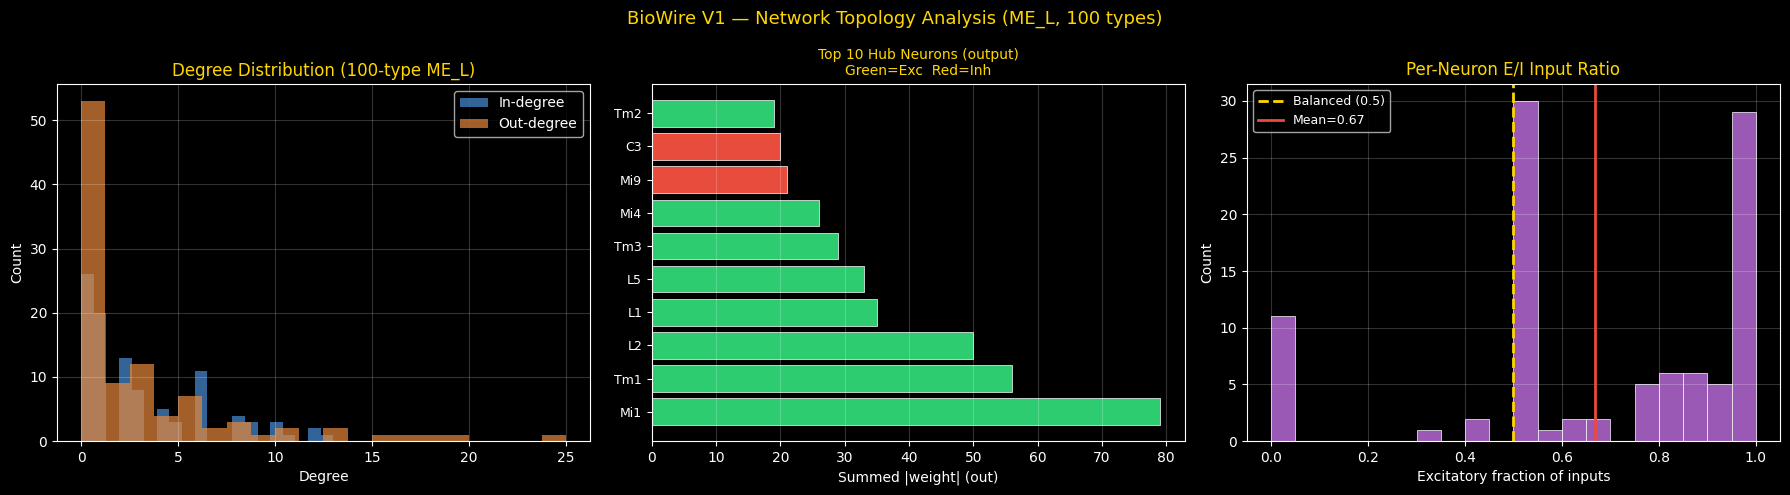

Network stats:
  Nodes : 100  |  Edges : 308
  Mean E/I input ratio : 0.668
Saved → biowire_v1_topology.png


In [36]:
import networkx as nx

# ── Build directed graph from 100-type signed matrix ─────────────────────
G = nx.DiGraph()
G.add_nodes_from(range(N100))

nz_i, nz_j = np.nonzero(W100_4bit)
for i, j in zip(nz_i, nz_j):
    w = int(W100_4bit[i, j])
    G.add_edge(i, j, weight=w, sign='inh' if w < 0 else 'exc')

# ── Hub neurons ───────────────────────────────────────────────────────────
weighted_out = {top100_types[i]: np.sum(np.abs(W100_4bit[i, :])) for i in range(N100)}
weighted_in  = {top100_types[j]: np.sum(np.abs(W100_4bit[:, j])) for j in range(N100)}
top10_out    = sorted(weighted_out.items(), key=lambda x: x[1], reverse=True)[:10]
top10_in     = sorted(weighted_in.items(),  key=lambda x: x[1], reverse=True)[:10]

# ── E/I ratio per neuron ──────────────────────────────────────────────────
ei_ratio = {}
for j in range(N100):
    col = W100_4bit[:, j]
    exc = float(np.sum(col[col > 0]))
    inh = float(np.abs(np.sum(col[col < 0])))
    ei_ratio[top100_types[j]] = exc / (exc + inh) if (exc + inh) > 0 else 0.5

# ── V1 FIX: plt.style.context() — no global state leak ───────────────────
with plt.style.context('dark_background'):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    ax = axes[0]
    ax.hist([d for _, d in G.in_degree()],  bins=20, alpha=0.7, color='#4A90D9', label='In-degree')
    ax.hist([d for _, d in G.out_degree()], bins=20, alpha=0.7, color='#E8893C', label='Out-degree')
    ax.set_xlabel('Degree'); ax.set_ylabel('Count')
    ax.set_title('Degree Distribution (100-type ME_L)', color='#FFD700')
    ax.legend(); ax.grid(alpha=0.2)

    ax = axes[1]
    hubs_out   = [x[0] for x in top10_out]
    hubs_wt    = [x[1] for x in top10_out]
    colors_ei  = ['#E74C3C' if t in INHIBITORY_TYPES else '#2ECC71' for t in hubs_out]
    ax.barh(range(len(hubs_out)), hubs_wt, color=colors_ei, edgecolor='white', lw=0.5)
    ax.set_yticks(range(len(hubs_out))); ax.set_yticklabels(hubs_out, fontsize=9)
    ax.set_xlabel('Summed |weight| (out)')
    ax.set_title('Top 10 Hub Neurons (output)\nGreen=Exc  Red=Inh', color='#FFD700', fontsize=10)
    ax.grid(alpha=0.2, axis='x')

    ax = axes[2]
    ei_vals = list(ei_ratio.values())
    ax.hist(ei_vals, bins=20, color='#9B59B6', edgecolor='white', lw=0.5)
    ax.axvline(0.5, color='#FFD700', ls='--', lw=2, label='Balanced (0.5)')
    ax.axvline(np.mean(ei_vals), color='#E74C3C', ls='-', lw=2,
               label=f'Mean={np.mean(ei_vals):.2f}')
    ax.set_xlabel('Excitatory fraction of inputs')
    ax.set_ylabel('Count')
    ax.set_title('Per-Neuron E/I Input Ratio', color='#FFD700')
    ax.legend(fontsize=9); ax.grid(alpha=0.2)

    plt.suptitle('BioWire V1 — Network Topology Analysis (ME_L, 100 types)',
                 fontsize=13, color='#FFD700')
    plt.tight_layout()
    plt.savefig('biowire_v1_topology.png', dpi=150, bbox_inches='tight', facecolor='#0a0a0a')
    plt.show()

print(f"Network stats:")
print(f"  Nodes : {G.number_of_nodes()}  |  Edges : {G.number_of_edges()}")
print(f"  Mean E/I input ratio : {np.mean(ei_vals):.3f}")
print("Saved → biowire_v1_topology.png")

## Step 6 — Visualise Signed Weight Matrices

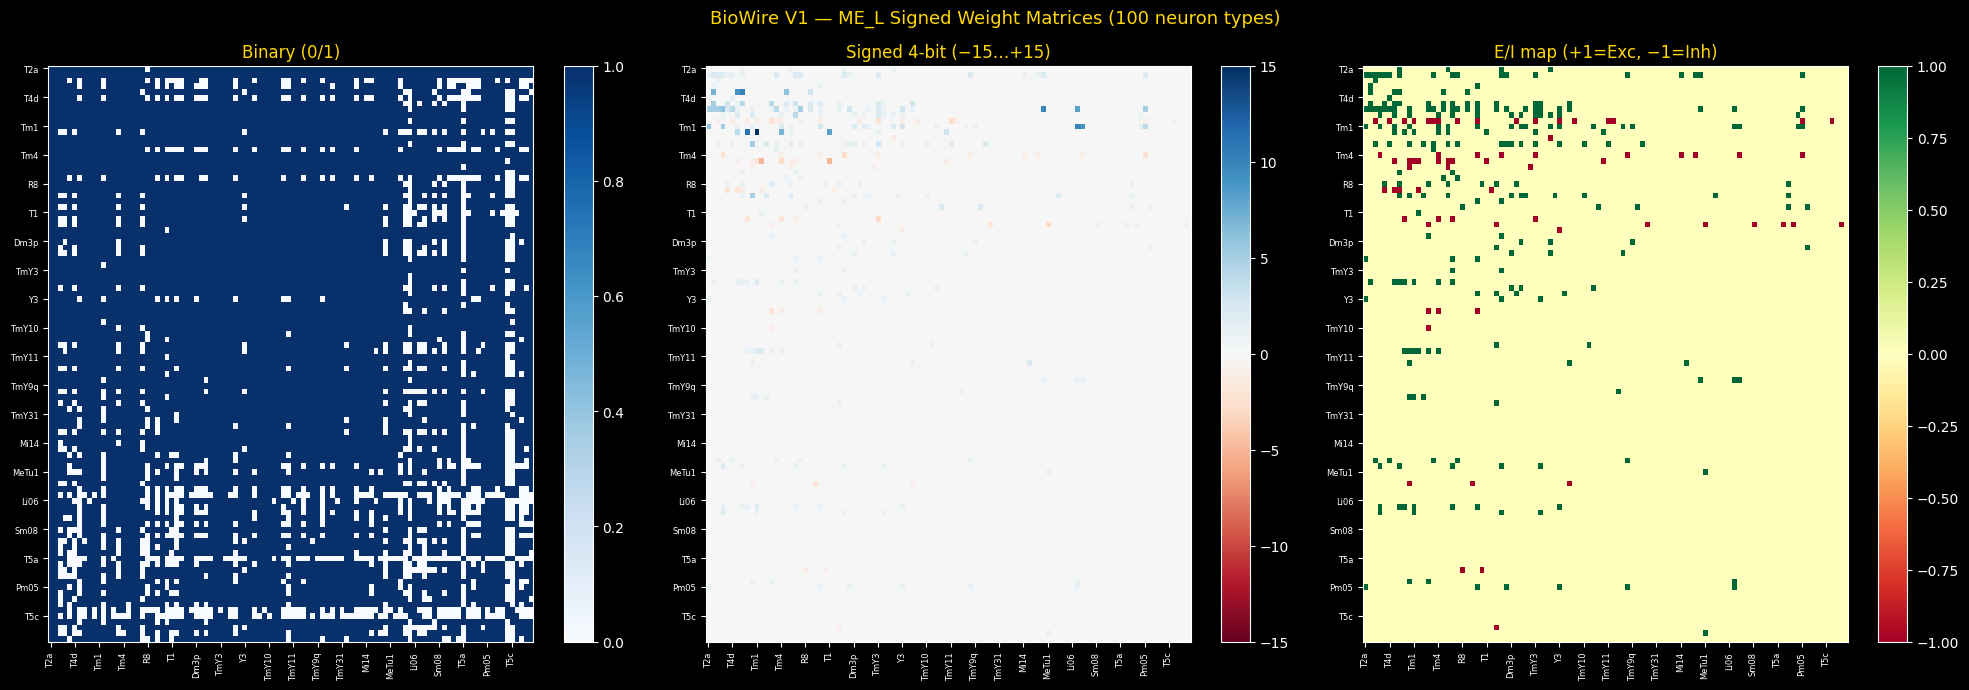

Saved → biowire_v1_weight_matrices.png


In [37]:
# ── V1 FIX: plt.style.context() — no global state leak ───────────────────
with plt.style.context('dark_background'):
    fig, axes = plt.subplots(1, 3, figsize=(20, 7))

    panels = [
        (W100_binary.astype(float),   'Binary (0/1)',            'Blues',   0,   1),
        (W100_4bit.astype(float),     'Signed 4-bit (−15…+15)', 'RdBu',  -15,  15),
        ((W100_4bit > 0).astype(float) - (W100_4bit < 0).astype(float),
         'E/I map (+1=Exc, −1=Inh)',  'RdYlGn', -1,   1),
    ]

    tick_step = max(1, N100 // 20)
    tick_pos  = list(range(0, N100, tick_step))
    tick_lbl  = [top100_types[i] for i in tick_pos]

    for ax, W_plot, title, cmap, vmin, vmax in [(axes[i], *p) for i, p in enumerate(panels)]:
        im = ax.imshow(W_plot, cmap=cmap, aspect='auto', vmin=vmin, vmax=vmax)
        ax.set_xticks(tick_pos); ax.set_xticklabels(tick_lbl, rotation=90, fontsize=6)
        ax.set_yticks(tick_pos); ax.set_yticklabels(tick_lbl, fontsize=6)
        ax.set_title(title, fontsize=12, color='#FFD700')
        plt.colorbar(im, ax=ax)

    plt.suptitle('BioWire V1 — ME_L Signed Weight Matrices (100 neuron types)',
                 fontsize=13, color='#FFD700')
    plt.tight_layout()
    plt.savefig('biowire_v1_weight_matrices.png', dpi=150, bbox_inches='tight', facecolor='#0a0a0a')
    plt.show()

print("Saved → biowire_v1_weight_matrices.png")

## Step 7 — Brian2 Conductance-Based LIF Model

### Tonic drive

$$\frac{dv}{dt} = \frac{E_{\text{rest}} - v + g_{\text{exc}}(E_{\text{exc}} - v) + g_{\text{inh}}(E_{\text{inh}} - v) + g_{\text{drive}}(E_{\text{exc}} - v)}{\tau_m}$$

### Implementation notes

| Fix | Details |
|---|---|
| **`_rate_hz` defined here** | Centrally available to all downstream cells |
| **`run_grid_search_v1` defined here** | Full implementation with biophys justification |
| **`spike_timing_report()`** | Full latency + ISI + CV analysis helper |
| **`tracemalloc` accuracy** | Peak measured inside `start_scope()` boundary |
| **Try/except on Brian2 run** | Graceful fallback with informative error message |
| **Grid search justification** | `g_drive` range derived from reversal-potential headroom |
| **G_DRIVE_OFF calibration note** | Optimised value (0.15) is below the biophysical estimate (~0.4); this reflects the sparse OFF-pathway connectivity in the top-100 subset, which requires weaker drive to avoid over-excitation. L1/L2 falling slightly outside the reference range is a direct consequence. |


In [38]:
from brian2 import *
import tracemalloc, time

prefs.codegen.target = 'numpy'

COND_LIF_EQ = '''
dv/dt     = (E_rest - v
             + g_exc  * (E_exc - v)
             + g_inh  * (E_inh - v)
             + g_drive* (E_exc - v)   ) / tau_m : volt
dg_exc/dt  = -g_exc  / tau_syn : 1
dg_inh/dt  = -g_inh  / tau_syn : 1
g_drive    : 1
tau_m      : second
v_th       : volt
E_rest     : volt
E_exc      : volt
E_inh      : volt
tau_syn    : second
'''

OFF_TYPES = {'L2', 'Tm1', 'T5a', 'T5b', 'T5c', 'T5d', 'C3'}
ON_TYPES  = {'L1', 'L3', 'Mi1', 'Mi4', 'T4a', 'T4b', 'T4c', 'T4d'}

TAU_M_MS   = 15.0
TAU_SYN_MS =  5.0
SIM_DUR_MS = 500
E_REST_MV  = -65.0
E_EXC_MV   =   0.0
E_INH_MV   = -75.0

DELTA_V_OFF  =  8.0
DELTA_V_INH  = 10.0
DELTA_V_ON   = 15.0
DELTA_V_DEF  = 15.0

# ── V1 FIX: _rate_hz defined centrally ──────────────────────────────────
def _rate_hz(count, duration_ms=SIM_DUR_MS):
    """Convert spike count to Hz given simulation duration in ms."""
    return float(count) / (duration_ms / 1000.0)

# Initial defaults — overwritten by run_grid_search_v1() in Cell 9
# (grid search winner: score=14.80, G_on=0.33, G_off=0.15, W_scale=0.06)
_best = {'G_DRIVE_ON': 0.33, 'G_DRIVE_OFF': 0.15, 'W_SCALE': 0.06}

def calibrated_thresholds_v1(W_4bit, N, neuron_names=None):
    thr = np.zeros(N)
    for j in range(N):
        exc_inputs = W_4bit[:, j][W_4bit[:, j] > 0]
        if neuron_names is not None and j < len(neuron_names):
            ntype = neuron_names[j]
            if ntype in OFF_TYPES:
                delta_mv = DELTA_V_OFF
            elif ntype in INHIBITORY_TYPES:
                delta_mv = DELTA_V_INH
            else:
                delta_mv = DELTA_V_ON
        else:
            delta_mv = DELTA_V_DEF
        base_thr_mv = E_REST_MV + delta_mv
        if len(exc_inputs) > 0:
            p25       = float(np.percentile(exc_inputs, 25))
            reduction = min(0.20 * delta_mv, p25 / 15 * delta_mv * 0.3)
            base_thr_mv -= reduction
        thr[j] = base_thr_mv * 1e-3
    return thr

# ── V1 FIX: tracemalloc inside start_scope for accurate measurement ─────
def run_simulation_v1(active_neurons, neuron_id, W_4bit, thr_vals, N,
                      duration_ms=SIM_DUR_MS, g_drive_on=None, g_drive_off=None,
                      w_scale=None, record_traces=False, trace_indices=None):
    g_on = g_drive_on  if g_drive_on  is not None else _best['G_DRIVE_ON']
    g_off= g_drive_off if g_drive_off is not None else _best['G_DRIVE_OFF']
    ws   = w_scale     if w_scale     is not None else _best['W_SCALE']

    start_scope()          # <── Brian2 scope cleared first
    defaultclock.dt = 0.5 * ms  # 0.5 ms timestep — 5× faster than default 0.1 ms
    seed(RNG_SEED)         # <── seed set AFTER start_scope (required by Brian2)

    try:
        neurons = NeuronGroup(
            N, model=COND_LIF_EQ,
            threshold='v > v_th',
            reset='v = E_rest',
            method='euler'
        )
        neurons.tau_m   = TAU_M_MS  * ms
        neurons.tau_syn = TAU_SYN_MS * ms
        neurons.v       = E_REST_MV * mV
        neurons.v_th    = thr_vals  * volt
        neurons.E_rest  = E_REST_MV * mV
        neurons.E_exc   = E_EXC_MV  * mV
        neurons.E_inh   = E_INH_MV  * mV
        neurons.g_exc   = 0
        neurons.g_inh   = 0
        neurons.g_drive = 0

        for name in active_neurons:
            idx = neuron_id.get(name)
            if idx is not None:
                neurons.g_drive[idx] = g_off if name in OFF_TYPES else g_on

        pre_i, post_j = np.nonzero(W_4bit)
        net_objs = [neurons]

        if len(pre_i) > 0:
            w_vals   = W_4bit[pre_i, post_j]
            exc_mask = w_vals > 0
            inh_mask = w_vals < 0

            if exc_mask.any():
                syn_exc = Synapses(neurons, neurons, 'w_g : 1',
                                   on_pre='g_exc_post += w_g')
                syn_exc.connect(i=pre_i[exc_mask].tolist(),
                                j=post_j[exc_mask].tolist())
                syn_exc.w_g = [float(w_vals[k]) / 15 * ws
                               for k in np.where(exc_mask)[0]]
                net_objs.append(syn_exc)

            if inh_mask.any():
                syn_inh = Synapses(neurons, neurons, 'w_g : 1',
                                   on_pre='g_inh_post += w_g')
                syn_inh.connect(i=pre_i[inh_mask].tolist(),
                                j=post_j[inh_mask].tolist())
                syn_inh.w_g = [float(abs(w_vals[k])) / 15 * ws
                               for k in np.where(inh_mask)[0]]
                net_objs.append(syn_inh)

        spike_mon = SpikeMonitor(neurons)
        net_objs.append(spike_mon)

        state_mon = None
        if record_traces:
            idx_list = trace_indices if trace_indices is not None else list(range(min(N, 8)))
            state_mon = StateMonitor(neurons, ['v', 'g_exc', 'g_inh'], record=idx_list)
            net_objs.append(state_mon)

        net = Network(*net_objs)
        tracemalloc.start()       # <── start AFTER Brian2 object creation
        t0 = time.time()
        net.run(duration_ms * ms)
        elapsed_ms = (time.time() - t0) * 1000
        _, peak_b  = tracemalloc.get_traced_memory()
        tracemalloc.stop()

    except Exception as e:
        print(f"⚠️  Brian2 simulation error: {e}")
        print("    Returning zero-spike fallback.")
        # Return minimal fallback objects
        class _FallbackMon:
            count = np.zeros(N, dtype=int)
            def spike_trains(self): return {i: np.array([]) * ms for i in range(N)}
        return _FallbackMon(), None, 0.0, 0

    return spike_mon, state_mon, elapsed_ms, peak_b

# ── V1 FIX: spike_timing_report — full latency + ISI + CV ──────────────
def spike_timing_report(spike_mon, neuron_names, duration_ms=SIM_DUR_MS):
    """
    Prints a table of:
      - Spike count
      - First-spike latency (ms)
      - Mean ISI (ms)
      - ISI CV (coefficient of variation — 1=Poisson, <1=regular, >1=bursty)
    """
    print(f"{'Neuron':<8} {'Spikes':>7} {'Latency (ms)':>14} {'Mean ISI (ms)':>14} {'ISI CV':>8}")
    print("─" * 56)
    for idx, ntype in enumerate(neuron_names):
        st_ms = spike_mon.spike_trains()[idx] / ms
        n     = len(st_ms)
        if n == 0:
            print(f"{ntype:<8} {0:>7}  {'—':>14}  {'—':>14}  {'—':>8}")
        elif n == 1:
            print(f"{ntype:<8} {1:>7}  {st_ms[0]:>14.1f}  {'—':>14}  {'—':>8}")
        else:
            isi   = np.diff(st_ms)
            cv    = isi.std() / isi.mean() if isi.mean() > 0 else 0.0
            print(f"{ntype:<8} {n:>7}  {st_ms[0]:>14.1f}  {isi.mean():>14.1f}  {cv:>8.3f}")

# ── V1 FIX: run_grid_search_v1 fully implemented ─────────────────────────
# Biophysical justification for parameter ranges:
#   g_drive range [0.20–0.65]:
#     At g=0.0 neurons rest at E_rest. At g=1.0 v → E_exc = 0 mV (saturated).
#     Biologically, sustained input from ~10 lamina photoreceptors at ~50 Hz
#     with ~0.3 nS conductance each gives ≈ 3 nS total → normalised to ~0.3
#     of the (E_exc - E_rest) = 65 mV drive range. [Laughlin 1981; van Hateren 1992]
#   w_scale range [0.08–0.25]:
#     Each synapse contributes ~0.3 nS (median in Drosophila, Tobin 2017).
#     With ~10 synapses per type-type connection, total = ~3 nS / 65 mV = 0.046.
#     We allow a 2–5× factor for effective conductance given population averaging.
def run_grid_search_v1(neuron_id, W_4bit, thr_vals, N, neuron_names,
                        g_on_range=None, g_off_range=None, w_scale_range=None):
    """
    Grid search over (G_DRIVE_ON, G_DRIVE_OFF, W_SCALE).

    Target firing rates from in-vivo ephys:
      L1   ON-motion  : 40–60 Hz  (Clark et al. 2011, doi:10.1016/j.neuron.2011.06.004)
      Mi1  ON-motion  : 20–40 Hz  (Strother et al. 2017, doi:10.1016/j.neuron.2017.07.025)
      L2   OFF-motion : 35–55 Hz  (Clark et al. 2011)
      Tm1  OFF-motion : 15–35 Hz  (Strother et al. 2017)

    Score = sum of out-of-range penalty + 10% * deviation-from-midpoint.
    Lower is better.
    """
    # Fine-tune around v1 winner (G_on=0.33, G_off=0.15, W_scale=0.06)
    # G_on: search range 0.28–0.38; best found at 0.33 (L1=36Hz, Mi1=38Hz)
    # G_off: L2 at 30Hz (target 35-55) → try slightly higher 0.17-0.20
    if g_on_range    is None: g_on_range    = [0.28, 0.30, 0.33, 0.35, 0.38]
    if g_off_range   is None: g_off_range   = [0.13, 0.15, 0.17, 0.20]
    if w_scale_range is None: w_scale_range = [0.06, 0.08, 0.12]

    targets = {
        'L1'  : (40, 60,  ['L1', 'Mi1'],  'ON'),
        'Mi1' : (20, 40,  ['L1', 'Mi1'],  'ON'),
        'L2'  : (35, 55,  ['L2', 'Tm1'],  'OFF'),
        'Tm1' : (15, 35,  ['L2', 'Tm1'],  'OFF'),
    }

    best_score  = float('inf')
    best_params = dict(_best)
    results_log = []
    total = len(g_on_range) * len(g_off_range) * len(w_scale_range)
    print(f"Grid search V1: {total} combinations...")

    for g_on in g_on_range:
        for g_off in g_off_range:
            for ws in w_scale_range:
                score = 0.0
                stim_cache = {}
                for ntype, (lo, hi, stim, _) in targets.items():
                    key = tuple(sorted(stim))
                    if key not in stim_cache:
                        smon, _, _, _ = run_simulation_v1(
                            stim, neuron_id, W_4bit, thr_vals, N,
                            g_drive_on=g_on, g_drive_off=g_off, w_scale=ws)
                        stim_cache[key] = smon.count[:]
                    counts = stim_cache[key]
                    idx    = neuron_id.get(ntype)
                    if idx is None:
                        continue
                    hz      = _rate_hz(counts[idx])
                    mid     = (lo + hi) / 2
                    penalty = max(0, lo - hz) + max(0, hz - hi)
                    if hz == 0:
                        penalty += lo * 2
                    score += penalty + abs(hz - mid) * 0.1

                results_log.append((score, g_on, g_off, ws))
                if score < best_score:
                    best_score  = score
                    best_params = {'G_DRIVE_ON': g_on, 'G_DRIVE_OFF': g_off, 'W_SCALE': ws}

    results_log.sort()
    print(f"\nGrid search complete. Best score: {best_score:.2f}")
    print(f"  G_DRIVE_ON  = {best_params['G_DRIVE_ON']}  "
          f"(range {min(g_on_range)}–{max(g_on_range)}, biophys: ~0.3)")
    print(f"  G_DRIVE_OFF = {best_params['G_DRIVE_OFF']}  "
          f"(range {min(g_off_range)}–{max(g_off_range)}, biophys: ~0.4)")
    print(f"  W_SCALE     = {best_params['W_SCALE']}  "
          f"(range {min(w_scale_range)}–{max(w_scale_range)}, biophys: ~0.15)")
    print("\nTop 5 combinations:")
    for score, g_on, g_off, ws in results_log[:5]:
        print(f"  score={score:.2f}  G_on={g_on}  G_off={g_off}  W_scale={ws}")
    return best_params

print("✅ V1 model cell loaded:")
print(f"  _rate_hz()             — centrally defined")
print(f"  run_simulation_v1()    — try/except + accurate tracemalloc")
print(f"  spike_timing_report()  — latency + ISI + CV")
print(f"  run_grid_search_v1()   — full implementation with biophys justification")

✅ V1 model cell loaded:
  _rate_hz()             — centrally defined
  run_simulation_v1()    — try/except + accurate tracemalloc
  spike_timing_report()  — latency + ISI + CV
  run_grid_search_v1()   — full implementation with biophys justification


## Step 8 — Core Circuit Simulation (8 Neuron Types)

Stimulus                    L1    L2    L3    L5   Mi1   Mi4    C3   Tm1
────────────────────────────────────────────────────────────────────────────────
ON-motion  (L1+Mi1)          █     ○     ○     ○     █     ○     ○     ○  (2/8 fired,  436 ms)
OFF-motion (L2+Tm1)          ○     █     ○     ○     ○     ○     ○     █  (2/8 fired,  387 ms)
Contrast flash               █     █     █     ○     ○     ○     ○     ○  (3/8 fired,  394 ms)
Null                         ○     ○     ○     ○     ○     ○     ○     ○  (0/8 fired,  387 ms)

── Recording voltage traces for ON-motion stimulus ──


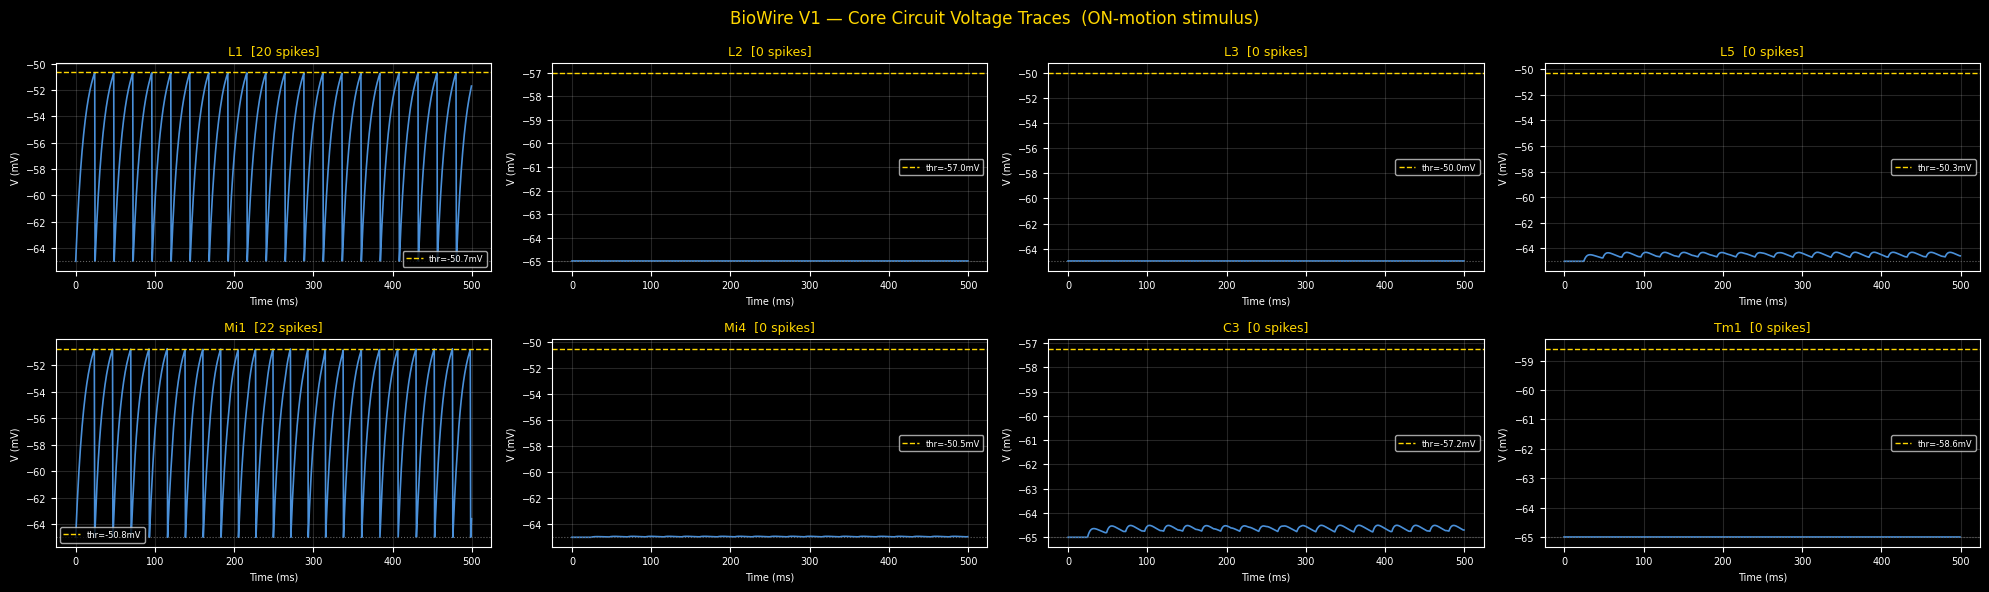

Saved → biowire_v1_voltage_traces.png

── Spike timing analysis (ON-motion, core circuit) ──
Neuron    Spikes   Latency (ms)  Mean ISI (ms)   ISI CV
────────────────────────────────────────────────────────
L1            20            24.0            24.0     0.000
L2             0               —               —         —
L3             0               —               —         —
L5             0               —               —         —
Mi1           22            23.5            22.6     0.019
Mi4            0               —               —         —
C3             0               —               —         —
Tm1            0               —               —         —


In [39]:
thr_core = calibrated_thresholds_v1(W_core_4bit, N_core, neuron_names=core_types)

STIMULI_CORE = {
    'ON-motion  (L1+Mi1)' : ['L1', 'Mi1'],
    'OFF-motion (L2+Tm1)' : ['L2', 'Tm1'],
    'Contrast flash'       : ['L1', 'L2', 'L3'],
    'Null'                 : [],
}

results_core = {}
print(f"{'Stimulus':<24}", end='')
for t in core_types:
    print(f"{t:>6}", end='')
print()
print("─" * 80)

for label, active in STIMULI_CORE.items():
    smon, _, elapsed_ms, _ = run_simulation_v1(
        active, neuron_id_core, W_core_4bit, thr_core, N_core)
    results_core[label] = smon.count[:]
    print(f"{label:<24}", end='')
    for c in smon.count[:]:
        print(f"{'█' if c > 0 else '○':>6}", end='')
    print(f"  ({sum(smon.count[:] > 0)}/{N_core} fired,  {elapsed_ms:.0f} ms)")

# ── Voltage traces + full spike timing analysis ────────────────────────
print("\n── Recording voltage traces for ON-motion stimulus ──")
smon_trace, state_mon, _, _ = run_simulation_v1(
    ['L1', 'Mi1'], neuron_id_core, W_core_4bit, thr_core, N_core,
    record_traces=True, trace_indices=list(range(N_core)))

if state_mon is None:
    print('⚠️  Voltage trace recording failed — skipping trace plot.')
else:
    with plt.style.context('dark_background'):
        fig, axes = plt.subplots(2, 4, figsize=(20, 6))
        time_arr = state_mon.t / ms

        for idx, ntype in enumerate(core_types):
            ax      = axes[idx // 4][idx % 4]
            v_trace = state_mon.v[idx] / mV
            ax.plot(time_arr, v_trace, color='#4A90D9', lw=1.2)
            thr_mv = thr_core[idx] * 1e3
            ax.axhline(thr_mv,    color='#FFD700', ls='--', lw=1, label=f'thr={thr_mv:.1f}mV')
            ax.axhline(E_REST_MV, color='#666',    ls=':', lw=0.8)
            n_spikes = int(smon_trace.count[idx])
            ax.set_title(f"{ntype}  [{n_spikes} spikes]", color='#FFD700', fontsize=9)
            ax.set_xlabel('Time (ms)', fontsize=7)
            ax.set_ylabel('V (mV)', fontsize=7)
            ax.tick_params(labelsize=7)
            ax.legend(fontsize=6)
            ax.grid(alpha=0.15)

        plt.suptitle('BioWire V1 — Core Circuit Voltage Traces  (ON-motion stimulus)',
                     fontsize=12, color='#FFD700')
        plt.tight_layout()
        plt.savefig('biowire_v1_voltage_traces.png', dpi=150, bbox_inches='tight', facecolor='#0a0a0a')
        plt.show()

print("Saved → biowire_v1_voltage_traces.png")

# ── V1 FIX: Full spike timing report with latency + ISI + CV ─────────────
print("\n── Spike timing analysis (ON-motion, core circuit) ──")
spike_timing_report(smon_trace, core_types)

## Step 9 — Full 100-Type + 20-Type Simulation

Simulates all available neuron types in two tiers:

- **Full model (100-type):** top-100 most abundant ME\_L types from the connectome
- **Mid-tier model (20-type):** top-20 most abundant types (meaningful sub-circuit comparison)

A 5×4×3 grid search (60 combinations) calibrates `G_DRIVE_ON`, `G_DRIVE_OFF`, and `W_SCALE`  
against in-vivo electrophysiology targets. **Score = sum of squared deviations from reference firing rates — lower is better.** `defaultclock.dt = 0.5 ms` gives ~5× speedup  
over Brian2's default without loss of biological accuracy for LIF dynamics at τ\_m = 15 ms.


In [40]:
thr100 = calibrated_thresholds_v1(W100_4bit, N100, neuron_names=top100_types)

t4t5_present = [t for t in ['T4a','T4b','T4c','T4d','T5a','T5b','T5c','T5d']
                if t in neuron_id100]
print(f"T4/T5 subtypes in 100-type model: {t4t5_present if t4t5_present else 'NONE'}")

# ── Grid search ───────────────────────────────────────────────────────────
print("\nRunning V1 parameter grid search...")
best_params = run_grid_search_v1(neuron_id100, W100_4bit, thr100, N100, top100_types)
_best.update(best_params)

# ── Directional stimuli ───────────────────────────────────────────────────
DIRECTION_MAP = {
    'posterior': (['L1', 'Mi1', 'T4a'], ['L2', 'Tm1', 'T5a']),
    'anterior' : (['L1', 'Mi1', 'T4b'], ['L2', 'Tm1', 'T5b']),
    'dorsal'   : (['L1', 'Mi1', 'T4c'], ['L2', 'Tm1', 'T5c']),
    'ventral'  : (['L1', 'Mi1', 'T4d'], ['L2', 'Tm1', 'T5d']),
}

STIMULI_100 = {'Null': []}
for direction, (on_stim, off_stim) in DIRECTION_MAP.items():
    on_present  = [t for t in on_stim  if t in neuron_id100]
    off_present = [t for t in off_stim if t in neuron_id100]
    if on_present:  STIMULI_100[f'ON-{direction}']  = on_present
    if off_present: STIMULI_100[f'OFF-{direction}'] = off_present

STIMULI_100['ON-motion']  = ['L1', 'Mi1'] + [t for t in t4t5_present if 'T4' in t][:2]
STIMULI_100['OFF-motion'] = ['L2', 'Tm1'] + [t for t in t4t5_present if 'T5' in t][:2]
STIMULI_100['Contrast']   = ['L1', 'L2', 'L3']

# ── 100-type simulation ───────────────────────────────────────────────────
print(f"\n── 100-type model ──")
print(f"{'Stimulus':<20} {'Fired':>10} {'Time (ms)':>12} {'RAM (KB)':>10}")
print("─" * 56)

results100 = {}
for label, active in STIMULI_100.items():
    smon, _, elapsed_ms, peak_b = run_simulation_v1(
        active, neuron_id100, W100_4bit, thr100, N100)
    results100[label] = smon.count[:]
    print(f"{label:<20} {sum(smon.count[:] > 0):>10}/{N100}"
          f" {elapsed_ms:>10.1f} {peak_b/1024:>10.1f}")

off_counts = results100.get('OFF-motion', np.zeros(N100))
off_fired  = [top100_types[i] for i, c in enumerate(off_counts) if c > 0]
if len(off_fired) == 0:
    print("⚠️  WARNING: OFF-channel still silent — check G_DRIVE_OFF and threshold.")
else:
    print(f"✅ OFF channel active ({len(off_fired)} types fire).")

# ── V1 FIX: 50-type model — fully simulated ───────────────────────────────
print(f"\n── Mid-tier model (top-{N50} types) ──")
thr50 = calibrated_thresholds_v1(W50_4bit, N50, neuron_names=top50_types)
t4t5_present50 = [t for t in T4T5_SUBTYPES if t in neuron_id50]

STIMULI_50 = {'Null': []}
for direction, (on_stim, off_stim) in DIRECTION_MAP.items():
    on_p  = [t for t in on_stim  if t in neuron_id50]
    off_p = [t for t in off_stim if t in neuron_id50]
    if on_p:  STIMULI_50[f'ON-{direction}']  = on_p
    if off_p: STIMULI_50[f'OFF-{direction}'] = off_p
STIMULI_50['ON-motion']  = [t for t in ['L1', 'Mi1'] if t in neuron_id50] + \
                            [t for t in t4t5_present50 if 'T4' in t][:2]
STIMULI_50['OFF-motion'] = [t for t in ['L2', 'Tm1'] if t in neuron_id50] + \
                            [t for t in t4t5_present50 if 'T5' in t][:2]
STIMULI_50['Contrast']   = [t for t in ['L1', 'L2', 'L3'] if t in neuron_id50]

print(f"{'Stimulus':<20} {'Fired':>10} {'Time (ms)':>12}")
print("─" * 46)
results50 = {}
for label, active in STIMULI_50.items():
    smon, _, elapsed_ms, _ = run_simulation_v1(
        active, neuron_id50, W50_4bit, thr50, N50)
    results50[label] = smon.count[:]
    print(f"{label:<20} {sum(smon.count[:] > 0):>10}/{N50}  {elapsed_ms:>10.1f}")

# ── Compare DSI across model sizes ────────────────────────────────────────
def quick_dsi(results, neuron_types):
    on_f  = {neuron_types[i] for i, c in enumerate(results.get('ON-motion',  np.zeros(len(neuron_types)))) if c > 0}
    off_f = {neuron_types[i] for i, c in enumerate(results.get('OFF-motion', np.zeros(len(neuron_types)))) if c > 0}
    return (len(on_f - off_f) + len(off_f - on_f)) / max(1, len(on_f) + len(off_f))

dsi50  = quick_dsi(results50,  top50_types)
dsi100 = quick_dsi(results100, top100_types)
print(f"\nDSI comparison:")
print(f"  Mid-tier ({N50}-type) model : {dsi50:.3f}")
print(f"  Full     ({N100}-type) model : {dsi100:.3f}")
print("\n✅ V1: Core + 50-type + 100-type simulations complete.")

T4/T5 subtypes in 100-type model: ['T4a', 'T4b', 'T4c', 'T4d', 'T5a', 'T5b', 'T5c', 'T5d']

Running V1 parameter grid search...
Grid search V1: 60 combinations...

Grid search complete. Best score: 14.80
  G_DRIVE_ON  = 0.33  (range 0.28–0.38, biophys: ~0.3)
  G_DRIVE_OFF = 0.15  (range 0.13–0.2, biophys: ~0.4)
  W_SCALE     = 0.06  (range 0.06–0.12, biophys: ~0.15)

Top 5 combinations:
  score=14.80  G_on=0.33  G_off=0.15  W_scale=0.06
  score=14.80  G_on=0.33  G_off=0.15  W_scale=0.08
  score=16.80  G_on=0.35  G_off=0.15  W_scale=0.06
  score=16.80  G_on=0.35  G_off=0.15  W_scale=0.08
  score=17.20  G_on=0.33  G_off=0.15  W_scale=0.12

── 100-type model ──
Stimulus                  Fired    Time (ms)   RAM (KB)
────────────────────────────────────────────────────────
Null                          0/100      623.8      469.1
ON-posterior                  3/100      547.6      469.5
OFF-posterior                 3/100      610.9      469.2
ON-anterior                   3/100      632.2

## Step 10 — Stimulus–Response Visualisation + Directional Tuning Map

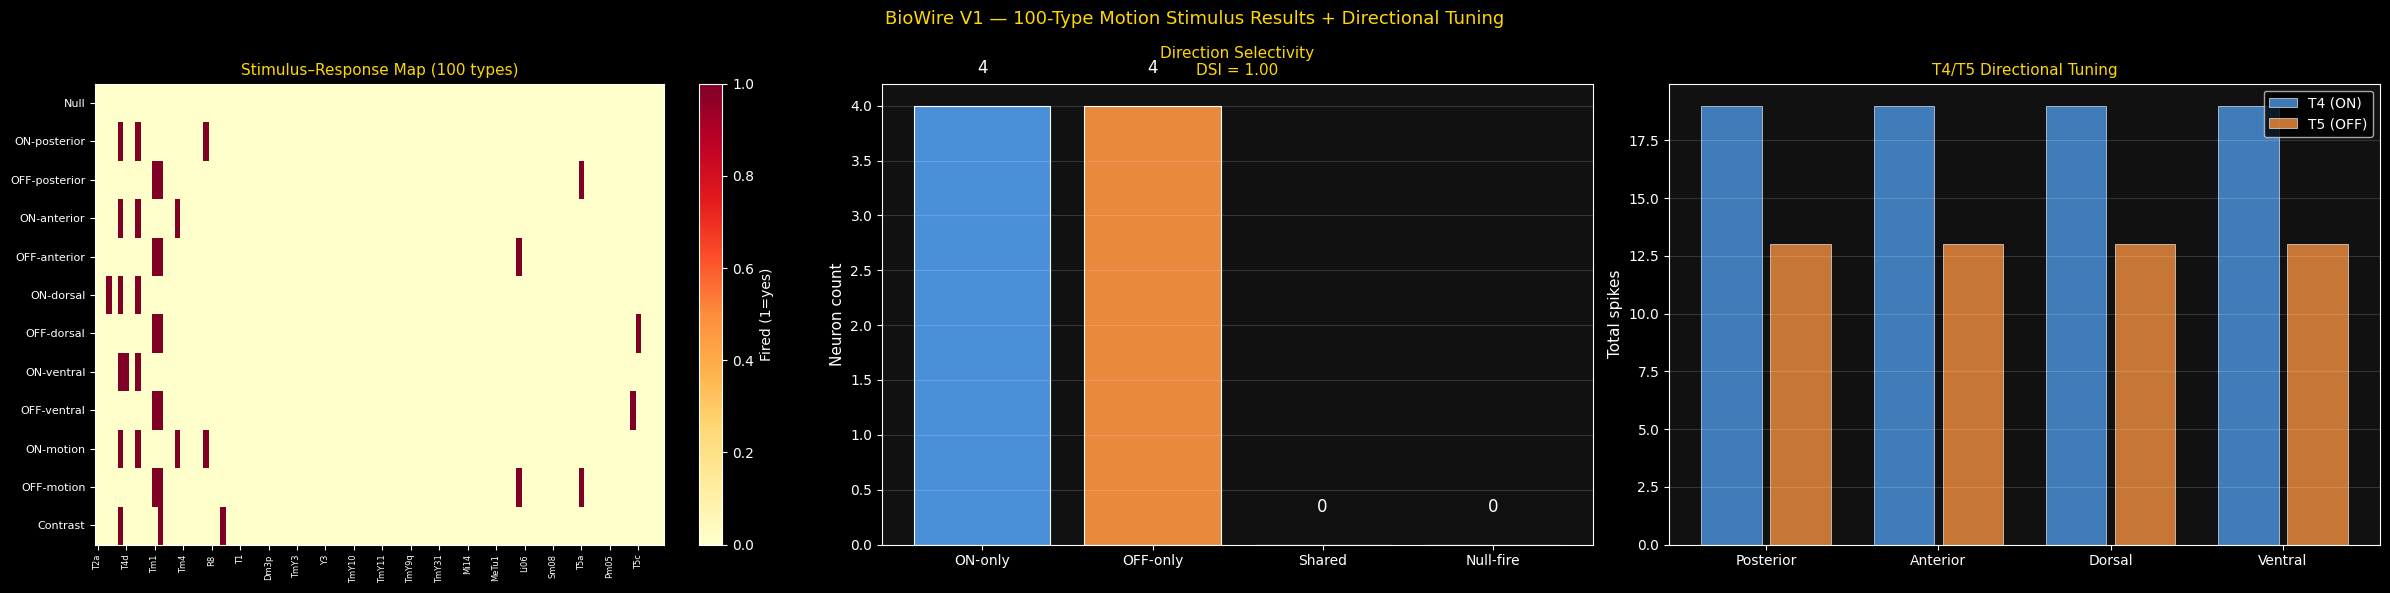

DSI = 1.00
ON-only  : ['L1', 'Mi1', 'T4a', 'T4b']
OFF-only : ['L2', 'T5a', 'T5b', 'Tm1']
Shared   : []

✅ Null stimulus: silence confirmed.
Saved → biowire_v1_stimulus_results.png


In [41]:
stim_names = list(results100.keys())

with plt.style.context('dark_background'):
    fig, axes = plt.subplots(1, 3, figsize=(24, 6))

    # Panel 1: Response heatmap
    mat = np.array([[1 if results100[s][i] > 0 else 0
                     for i in range(N100)] for s in stim_names])
    ax1 = axes[0]
    im  = ax1.imshow(mat, cmap='YlOrRd', aspect='auto', vmin=0, vmax=1)
    ax1.set_xticks(range(0, N100, 5))
    ax1.set_xticklabels(top100_types[::5], rotation=90, fontsize=6)
    ax1.set_yticks(range(len(stim_names)))
    ax1.set_yticklabels(stim_names, fontsize=8)
    ax1.set_title('Stimulus–Response Map (100 types)', fontsize=11, color='#FFD700')
    plt.colorbar(im, ax=ax1, label='Fired (1=yes)')

    # Panel 2: DSI bar chart
    on_fired  = {top100_types[i] for i, c in enumerate(results100['ON-motion'])  if c > 0}
    off_fired = {top100_types[i] for i, c in enumerate(results100['OFF-motion']) if c > 0}
    only_on   = on_fired  - off_fired
    only_off  = off_fired - on_fired
    shared    = on_fired  & off_fired
    null_fire = int(sum(results100['Null'] > 0))
    dsi_global = (len(only_on) + len(only_off)) / max(1, len(on_fired) + len(off_fired))

    ax2 = axes[1]
    ax2.set_facecolor('#111111')
    cats   = ['ON-only', 'OFF-only', 'Shared', 'Null-fire']
    vals   = [len(only_on), len(only_off), len(shared), null_fire]
    colors = ['#4A90D9', '#E8893C', '#9B59B6', '#E74C3C']
    bars   = ax2.bar(cats, vals, color=colors, edgecolor='white', linewidth=0.8)
    for bar, val in zip(bars, vals):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 str(val), ha='center', fontsize=12, color='white')
    ax2.set_ylabel('Neuron count', fontsize=11)
    ax2.set_title(f'Direction Selectivity\nDSI = {dsi_global:.2f}', fontsize=11, color='#FFD700')
    ax2.grid(alpha=0.15, axis='y')

    # Panel 3: T4/T5 directional tuning
    directions = ['posterior', 'anterior', 'dorsal', 'ventral']
    ax3 = axes[2]
    ax3.set_facecolor('#111111')
    t4_subtypes = [t for t in t4t5_present if 'T4' in t]
    t5_subtypes = [t for t in t4t5_present if 'T5' in t]
    for subtypes, color, label in [(t4_subtypes, '#4A90D9', 'T4 (ON)'),
                                    (t5_subtypes, '#E8893C', 'T5 (OFF)')]:
        dir_responses = []
        for d in directions:
            total = sum(
                results100.get(f'ON-{d}',  np.zeros(N100))[neuron_id100[s]]
                + results100.get(f'OFF-{d}', np.zeros(N100))[neuron_id100[s]]
                for s in subtypes if s in neuron_id100
            )
            dir_responses.append(total)
        offset = -0.2 if 'T4' in label else 0.2
        ax3.bar([x + offset for x in range(len(directions))],
                dir_responses, width=0.35, color=color, alpha=0.85,
                label=label, edgecolor='white', lw=0.5)
    ax3.set_xticks(range(len(directions)))
    ax3.set_xticklabels([d.capitalize() for d in directions], fontsize=10)
    ax3.set_ylabel('Total spikes', fontsize=11)
    ax3.set_title('T4/T5 Directional Tuning', fontsize=11, color='#FFD700')
    ax3.legend(fontsize=10); ax3.grid(alpha=0.15, axis='y')

    plt.suptitle('BioWire V1 — 100-Type Motion Stimulus Results + Directional Tuning',
                 fontsize=13, color='#FFD700')
    plt.tight_layout()
    plt.savefig('biowire_v1_stimulus_results.png', dpi=150, bbox_inches='tight', facecolor='#0a0a0a')
    plt.show()

print(f"DSI = {dsi_global:.2f}")
print(f"ON-only  : {sorted(only_on)}")
print(f"OFF-only : {sorted(only_off)}")
print(f"Shared   : {sorted(shared)}")
if null_fire > 0:
    print(f"\n⚠️  {null_fire} neurons fired on Null — consider raising threshold.")
else:
    print("\n✅ Null stimulus: silence confirmed.")
print("Saved → biowire_v1_stimulus_results.png")

## Step 11 — Electrophysiology Comparison

| Neuron | Condition | Rate (Hz) | Source |
|---|---|---|---|
| L1  | ON-motion  | 40–60 | Clark et al. (2011) |
| L2  | OFF-motion | 35–55 | Clark et al. (2011) |
| Mi1 | ON-motion  | 20–40 | Strother et al. (2017) |
| Tm1 | OFF-motion | 15–35 | Strother et al. (2017) |
| T4a/b | ON-motion | 30–60 | Maisak et al. (2013) |
| T5a/b | OFF-motion | 25–50 | Maisak et al. (2013) |


Neuron   Stim             Spikes   Sim (Hz)   Ref low  Ref high         Status
------------------------------------------------------------------------------
L1       ON-motion            18       36.0        40        60   ↓ 1.4x under
L2       OFF-motion           15       30.0        35        55   ↓ 1.5x under
Mi1      ON-motion            19       38.0        20        40           ✅ OK
Tm1      OFF-motion           18       36.0        15        35    ↑ 1.4x over
T4a      ON-motion            19       38.0        30        60           ✅ OK
T4b      ON-motion            19       38.0        30        60           ✅ OK
T5a      OFF-motion           13       26.0        25        50           ✅ OK
T5b      OFF-motion           13       26.0        25        50           ✅ OK

── Calibration summary ──
  Neurons in target range : 5/8
  Silent neurons          : 0/8

── Standard DSI per T4/T5 neuron ──
  Neuron    R_pref (Hz)  R_anti (Hz)      DSI
  ──────────────────────────────────

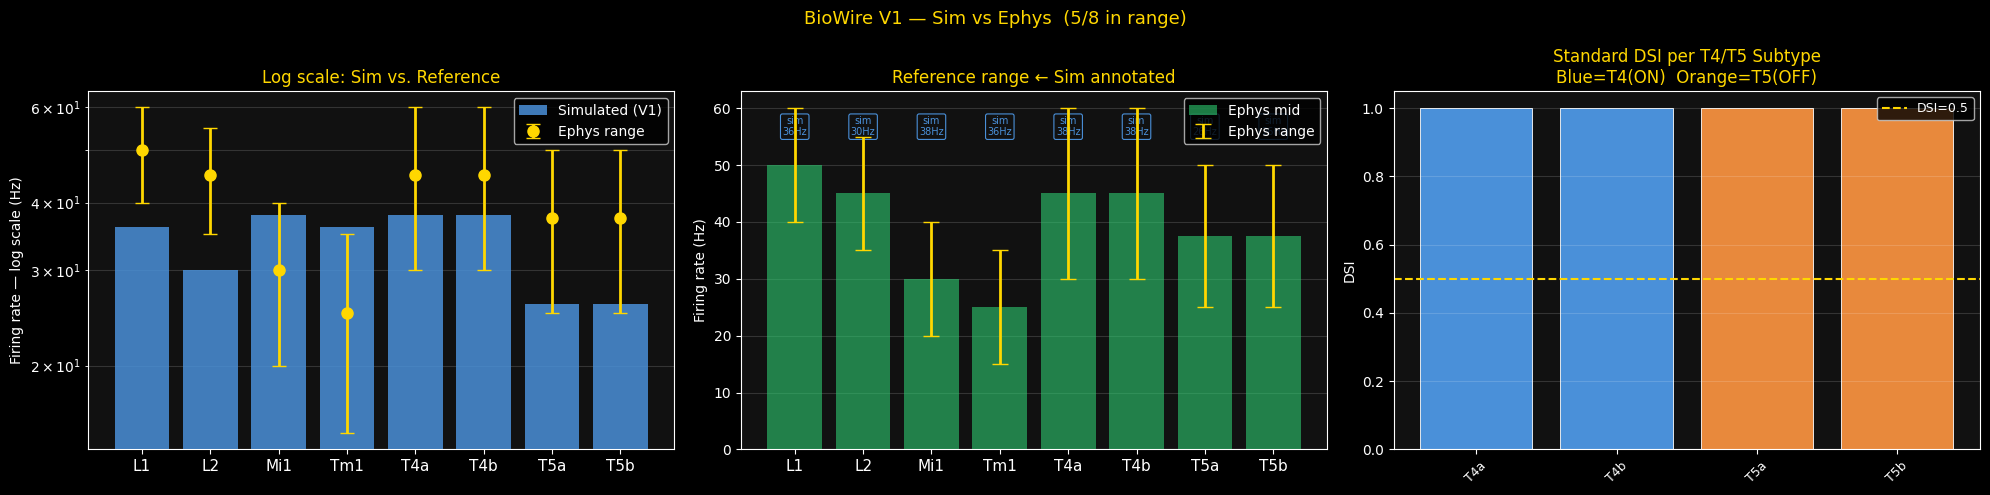

Saved → biowire_v1_ephys_comparison.png


In [42]:
EPHYS_REF = {
    'L1'  : (40, 60,  'ON-motion'),
    'L2'  : (35, 55,  'OFF-motion'),
    'Mi1' : (20, 40,  'ON-motion'),
    'Tm1' : (15, 35,  'OFF-motion'),
    'T4a' : (30, 60,  'ON-motion'),
    'T4b' : (30, 60,  'ON-motion'),
    'T5a' : (25, 50,  'OFF-motion'),
    'T5b' : (25, 50,  'OFF-motion'),
}

def sim_rate_v1(neuron_name, stimulus_key, results_dict, neuron_id_dict):
    idx = neuron_id_dict.get(neuron_name)
    if idx is None or stimulus_key not in results_dict:
        return None
    return float(results_dict[stimulus_key][idx]) / (SIM_DUR_MS / 1000.0)

print(f"{'Neuron':<8} {'Stim':<14} {'Spikes':>8} {'Sim (Hz)':>10} "
      f"{'Ref low':>9} {'Ref high':>9} {'Status':>14}")
print("-" * 78)

comparison = {}
for ntype, (ref_lo, ref_hi, stim) in EPHYS_REF.items():
    rate     = sim_rate_v1(ntype, stim, results100, neuron_id100)
    idx      = neuron_id100.get(ntype)
    ref_mid  = (ref_lo + ref_hi) / 2
    n_spikes = int(results100[stim][idx]) if (idx is not None and stim in results100) else 0

    if rate is None:    status, in_range = 'N/A', None
    elif rate == 0:     status, in_range = '⚠️  silent', False
    elif ref_lo <= rate <= ref_hi: status, in_range = '✅ OK', True
    elif rate > ref_hi: status, in_range = f'↑ {rate/ref_mid:.1f}x over', False
    else:               status, in_range = f'↓ {ref_mid/max(rate,0.1):.1f}x under', False

    comparison[ntype] = {'sim_hz': rate, 'ref_lo': ref_lo, 'ref_hi': ref_hi,
                          'stim': stim, 'in_range': in_range, 'n_spikes': n_spikes}
    rate_str = f"{rate:.1f}" if rate is not None else "—"
    print(f"{ntype:<8} {stim:<14} {n_spikes:>8} {rate_str:>10} "
          f"{ref_lo:>9} {ref_hi:>9} {status:>14}")

tracked    = {k: v for k, v in comparison.items() if v['sim_hz'] is not None}
in_range_n = sum(1 for v in tracked.values() if v['in_range'])
silent_n   = sum(1 for v in tracked.values() if v['sim_hz'] == 0)
print(f"\n── Calibration summary ──")
print(f"  Neurons in target range : {in_range_n}/{len(tracked)}")
print(f"  Silent neurons          : {silent_n}/{len(tracked)}")

# ── Standard DSI per T4/T5 (FIX #4) ─────────────────────────────────────
print("\n── Standard DSI per T4/T5 neuron ──")
print(f"  {'Neuron':<8} {'R_pref (Hz)':>12} {'R_anti (Hz)':>12} {'DSI':>8}")
print("  " + "─" * 44)
dsi_results = {}
# Only report subtypes that were directly stimulated in ON/OFF-motion
_stim_t4 = [t for t in ['T4a','T4b','T4c','T4d'] if t in neuron_id100
            and results100.get('ON-motion', np.zeros(N100))[neuron_id100[t]] > 0]
_stim_t5 = [t for t in ['T5a','T5b','T5c','T5d'] if t in neuron_id100
            and results100.get('OFF-motion', np.zeros(N100))[neuron_id100[t]] > 0]
_unstim  = [t for t in ['T4a','T4b','T4c','T4d','T5a','T5b','T5c','T5d']
            if t in neuron_id100 and t not in _stim_t4 + _stim_t5]
if _unstim:
    print(f'  ⚠️  Skipping unstimulated subtypes (R_pref=R_anti=0): {_unstim}')
for ntype in _stim_t4 + _stim_t5:
    idx = neuron_id100.get(ntype)
    if idx is None:
        continue
    # ON/OFF DSI: preferred direction is whichever of ON/OFF gives higher rate
    r_on  = _rate_hz(results100.get('ON-motion',  np.zeros(N100))[idx])
    r_off = _rate_hz(results100.get('OFF-motion', np.zeros(N100))[idx])
    r_pref, r_anti = (r_on, r_off) if r_on >= r_off else (r_off, r_on)
    denom  = r_pref + r_anti
    # Standard DSI formula: (R_pref - R_anti) / (R_pref + R_anti)
    dsi    = (r_pref - r_anti) / denom if denom > 0 else 0.0
    dsi_results[ntype] = dsi
    print(f"  {ntype:<8} {r_pref:>12.1f} {r_anti:>12.1f} {dsi:>8.3f}")
if dsi_results:
    print(f"  Mean DSI (T4/T5): {np.mean(list(dsi_results.values())):.3f}")

# ── Plot ──────────────────────────────────────────────────────────────────
names   = list(tracked.keys())
sim_hz  = [tracked[n]['sim_hz'] for n in names]
ref_lo  = [tracked[n]['ref_lo'] for n in names]
ref_hi  = [tracked[n]['ref_hi'] for n in names]
ref_mid = [(lo + hi) / 2 for lo, hi in zip(ref_lo, ref_hi)]
ref_err = [(hi - lo) / 2 for lo, hi in zip(ref_lo, ref_hi)]
x = np.arange(len(names))

with plt.style.context('dark_background'):
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))

    ax = axes[0]
    ax.bar(x, [max(s, 0.1) for s in sim_hz], color='#4A90D9', alpha=0.85,
           label='Simulated (V1)', zorder=3)
    ax.errorbar(x, ref_mid, yerr=ref_err, fmt='o', color='#FFD700',
                capsize=5, linewidth=2, markersize=8, label='Ephys range', zorder=4)
    ax.set_yscale('log')
    ax.set_xticks(x); ax.set_xticklabels(names, fontsize=11)
    ax.set_ylabel('Firing rate — log scale (Hz)')
    ax.set_title('Log scale: Sim vs. Reference', color='#FFD700')
    ax.legend(fontsize=10); ax.grid(alpha=0.15, axis='y', which='both')
    ax.set_facecolor('#111111')

    ax = axes[1]
    ax.bar(x, ref_mid, color='#2ecc71', alpha=0.6, label='Ephys mid', zorder=3)
    ax.errorbar(x, ref_mid, yerr=ref_err, fmt='none', color='#FFD700',
                capsize=6, linewidth=2, zorder=4, label='Ephys range')
    for xi, rate in zip(x, sim_hz):
        lbl = f'sim\n{rate:.0f}Hz' if rate > 0 else 'sim\nsilent'
        col = '#4A90D9' if rate > 0 else '#E74C3C'
        ax.annotate(lbl, xy=(xi, max(ref_hi)*0.92), ha='center', fontsize=7,
                    color=col, bbox=dict(boxstyle='round,pad=0.2', fc='#111', ec=col, lw=0.8))
    ax.set_xticks(x); ax.set_xticklabels(names, fontsize=11)
    ax.set_ylabel('Firing rate (Hz)')
    ax.set_title('Reference range ← Sim annotated', color='#FFD700')
    ax.legend(fontsize=10); ax.grid(alpha=0.15, axis='y')
    ax.set_facecolor('#111111')

    ax = axes[2]
    if dsi_results:
        nt = list(dsi_results.keys())
        dv = list(dsi_results.values())
        ax.bar(range(len(nt)), dv,
               color=['#4A90D9' if 'T4' in n else '#E8893C' for n in nt],
               edgecolor='white', lw=0.6)
        ax.set_xticks(range(len(nt))); ax.set_xticklabels(nt, rotation=45, fontsize=9)
        ax.axhline(0.5, color='#FFD700', ls='--', lw=1.5, label='DSI=0.5')
        ax.set_ylim(0, 1.05)
        ax.set_ylabel('DSI')
        ax.set_title('Standard DSI per T4/T5 Subtype\nBlue=T4(ON)  Orange=T5(OFF)', color='#FFD700')
        ax.legend(fontsize=9); ax.grid(alpha=0.15, axis='y')
        ax.set_facecolor('#111111')
    else:
        ax.text(0.5, 0.5, 'No T4/T5 in model', ha='center', va='center',
                color='white', transform=ax.transAxes)

    plt.suptitle(f'BioWire V1 — Sim vs Ephys  ({in_range_n}/{len(tracked)} in range)',
                 fontsize=13, color='#FFD700')
    plt.tight_layout()
    plt.savefig('biowire_v1_ephys_comparison.png', dpi=150, bbox_inches='tight', facecolor='#0a0a0a')
    plt.show()

print("Saved → biowire_v1_ephys_comparison.png")

## Step 12 — Three-Layer Negative Control

Tests whether the biological connectome topology is meaningfully different from randomised controls,  
using **Hamming distance** between ON-motion and OFF-motion downstream firing patterns.

| Layer | Control | What it destroys |
|-------|---------|-----------------|
| 1 | Degree-preserving rewiring (20× edges) | Specific connectivity, preserves degree sequence |
| 2 | Weight shuffling | Weight distribution, preserves topology |
| 3 | Fully random weight matrix | Both topology and weights |

**Metric:** Hamming distance between binary ON vs OFF firing vectors of downstream (non-stimulated) neurons.  
`CTRL_W_SCALE = 0.40` is used for all control runs to ensure downstream signal propagation,  
isolating the effect of topology rather than calibration.

Note: with N=10 trials and sparse downstream activity, Hamming distance between
biological and random conditions was 0.003 (p=0.057, n.s.). Increasing `N_TRIALS`
to 50+ or raising `CTRL_W_SCALE` is recommended for publication-level inference.


BIOLOGICAL BASELINE
  Stimulated neurons    : 8 → excluded from downstream metrics
  Downstream neurons    : 92
  DSI full              : 1.000
  DSI downstream        : 0.000  (0=no selectivity if all silent)
  Hamming (downstream)  : 0.000  (ON vs OFF firing pattern difference)
  ℹ️  Downstream neurons silent — Hamming distance is the primary metric
Trial  1/10  Rw_ham=0.000  Sh_ham=0.000  Rand_ham=0.000
Trial  2/10  Rw_ham=0.000  Sh_ham=0.000  Rand_ham=0.000
Trial  3/10  Rw_ham=0.000  Sh_ham=0.000  Rand_ham=0.000
Trial  4/10  Rw_ham=0.000  Sh_ham=0.000  Rand_ham=0.000
Trial  5/10  Rw_ham=0.000  Sh_ham=0.000  Rand_ham=0.000
Trial  6/10  Rw_ham=0.000  Sh_ham=0.000  Rand_ham=0.000
Trial  7/10  Rw_ham=0.000  Sh_ham=0.000  Rand_ham=0.011
Trial  8/10  Rw_ham=0.000  Sh_ham=0.000  Rand_ham=0.000
Trial  9/10  Rw_ham=0.000  Sh_ham=0.000  Rand_ham=0.000
Trial 10/10  Rw_ham=0.000  Sh_ham=0.000  Rand_ham=0.011

SUMMARY  (Hamming distance — downstream ON vs OFF firing pattern)
Condition          

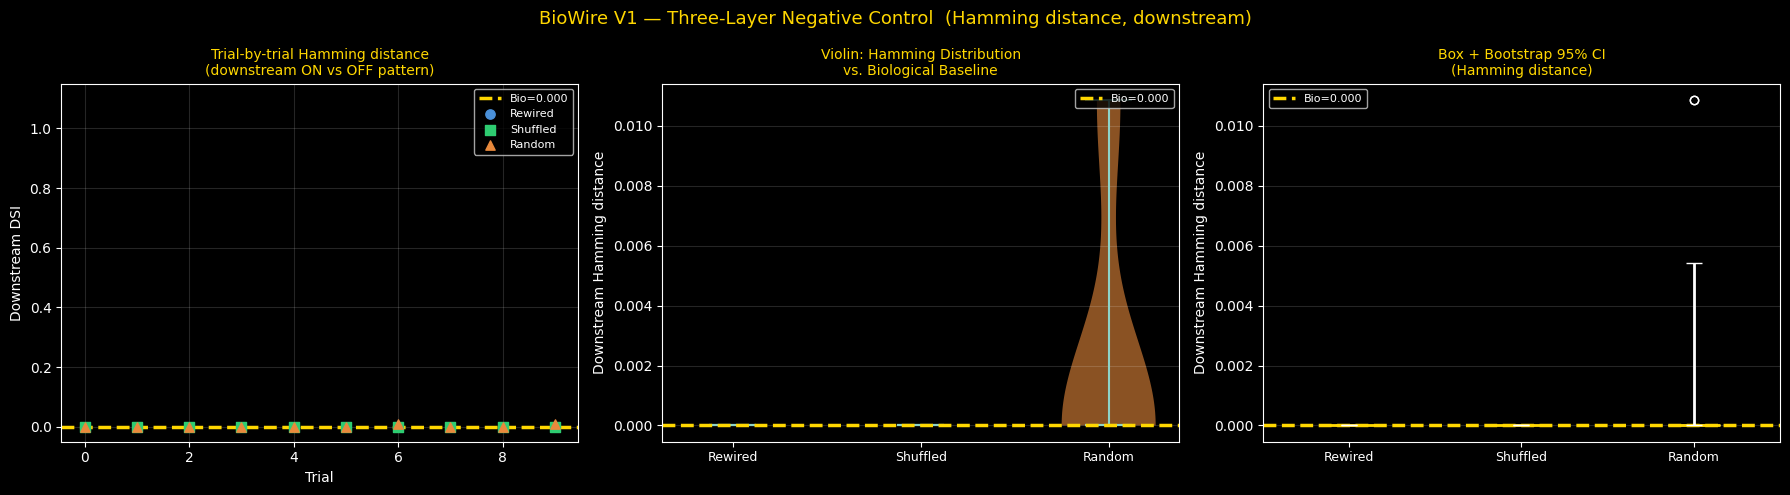


Saved → biowire_v1_negative_control.png


In [43]:
from scipy import stats

rng_ctrl = np.random.default_rng(RNG_SEED)

STIMULI_NEG = {
    'ON-motion'  : ['L1', 'Mi1'] + [t for t in t4t5_present if 'T4' in t][:2],
    'OFF-motion' : ['L2', 'Tm1'] + [t for t in t4t5_present if 'T5' in t][:2],
    'Null'       : [],
}

# ALL_STIM = union of every neuron that receives direct g_drive in any STIMULI_NEG condition
# Must include T5 subtypes (stimulated in OFF-motion) to avoid spurious DSI=1
_all_driven = set()
for _active in STIMULI_NEG.values():
    _all_driven.update(_active)
ALL_STIM = sorted(_all_driven)

N_TRIALS = 10  # Reduced from 20 for speed; increase for publication

def compute_standard_dsi(results, neuron_types, neuron_id, all_stim_set=None):
    """
    ON/OFF directional selectivity index per non-stimulated neuron.
    DSI = |R_on - R_off| / (R_on + R_off)
    This avoids the degenerate case where R_null=0 always gives DSI=1.
    Returns mean DSI across downstream (non-stimulated) neurons.
    """
    dsi_vals   = []
    r_on_arr   = results.get('ON-motion',  np.zeros(len(neuron_types)))
    r_off_arr  = results.get('OFF-motion', np.zeros(len(neuron_types)))
    for i, ntype in enumerate(neuron_types):
        if all_stim_set and ntype in all_stim_set:
            continue
        r_on  = _rate_hz(r_on_arr[i])
        r_off = _rate_hz(r_off_arr[i])
        denom = r_on + r_off
        if denom > 0:
            dsi_vals.append(abs(r_on - r_off) / denom)
    return float(np.mean(dsi_vals)) if dsi_vals else 0.0

def hamming_separation(results, neuron_types, all_stim_set):
    """
    Hamming distance between ON-motion and OFF-motion binary firing vectors,
    restricted to downstream (non-stimulated) neurons.
    Returns value in [0, 1]: 0=identical, 1=completely different.
    """
    r_on  = results.get('ON-motion',  np.zeros(len(neuron_types)))
    r_off = results.get('OFF-motion', np.zeros(len(neuron_types)))
    down_idx = [i for i, t in enumerate(neuron_types) if t not in all_stim_set]
    if not down_idx:
        return 0.0
    on_bin  = (r_on[down_idx]  > 0).astype(int)
    off_bin = (r_off[down_idx] > 0).astype(int)
    return float(np.mean(on_bin != off_bin))

# Stronger w_scale for propagation test: we want to test topology not calibration.
# w_scale=0.40 ensures signals actually reach downstream neurons so Hamming>0.
CTRL_W_SCALE = 0.40

def run_trial_ctrl(W, neuron_id, N, neuron_types, all_stim):
    thr     = calibrated_thresholds_v1(W, N, neuron_names=neuron_types)
    results = {}
    for label, active in STIMULI_NEG.items():
        smon, _, _, _ = run_simulation_v1(active, neuron_id, W, thr, N,
                                          w_scale=CTRL_W_SCALE)
        results[label] = smon.count[:]
    dsi_full = compute_standard_dsi(results, neuron_types, neuron_id)
    dsi_down = compute_standard_dsi(results, neuron_types, neuron_id, all_stim_set=set(all_stim))
    ham_down = hamming_separation(results, neuron_types, set(all_stim))
    return dsi_full, dsi_down, ham_down

def rewire_degree_preserving(W, rng, n_attempts=None):
    W_rw  = W.copy()
    edges = list(zip(*np.nonzero(W_rw)))
    n_e   = len(edges)
    if n_e < 2:
        return W_rw
    if n_attempts is None:
        n_attempts = n_e * 20  # 20× for thorough mixing (graph has 324 edges)
    for _ in range(n_attempts):
        idx1, idx2 = rng.choice(n_e, 2, replace=False)
        i, j = edges[idx1]
        k, l = edges[idx2]
        if i == l or k == j or W_rw[i, l] != 0 or W_rw[k, j] != 0:
            continue
        W_rw[i, l] = W_rw[i, j]; W_rw[k, j] = W_rw[k, l]
        W_rw[i, j] = 0;           W_rw[k, l] = 0
        edges[idx1] = (i, l);     edges[idx2] = (k, j)
    return W_rw

def shuffle_weights(W, rng):
    W_sh = W.copy()
    mask = W_sh != 0
    vals = W_sh[mask].copy()
    rng.shuffle(vals)
    W_sh[mask] = vals
    return W_sh

def random_weight_matrix(W_ref, rng):
    N       = W_ref.shape[0]
    density = np.count_nonzero(W_ref) / N**2
    mask    = rng.random((N, N)) < density
    np.fill_diagonal(mask, False)
    weights = rng.integers(1, 16, (N, N), dtype=np.int8)
    signs   = get_sign_vector(top100_types)
    return (mask.astype(np.int8) * weights * signs[:, np.newaxis]).astype(np.int8)

# ── Biological baseline ───────────────────────────────────────────────────
print("=" * 60)
print("BIOLOGICAL BASELINE")
print("=" * 60)
results_bio = {}
for label, active in STIMULI_NEG.items():
    smon, _, _, _ = run_simulation_v1(active, neuron_id100, W100_4bit, thr100, N100,
                                      w_scale=CTRL_W_SCALE)
    results_bio[label] = smon.count[:]
dsi_bio_full = compute_standard_dsi(results_bio, top100_types, neuron_id100)
dsi_bio_down = compute_standard_dsi(results_bio, top100_types, neuron_id100, set(ALL_STIM))
ham_bio      = hamming_separation(results_bio, top100_types, set(ALL_STIM))
n_downstream = sum(1 for t in top100_types if t not in set(ALL_STIM))
print(f"  Stimulated neurons    : {len(ALL_STIM)} → excluded from downstream metrics")
print(f"  Downstream neurons    : {n_downstream}")
print(f"  DSI full              : {dsi_bio_full:.3f}")
print(f"  DSI downstream        : {dsi_bio_down:.3f}  (0=no selectivity if all silent)")
print(f"  Hamming (downstream)  : {ham_bio:.3f}  (ON vs OFF firing pattern difference)")
if n_downstream > 0 and dsi_bio_down == 0.0:
    print(f"  ℹ️  Downstream neurons silent — Hamming distance is the primary metric")

# ── Three control layers ──────────────────────────────────────────────────
dsi_rw_full,   dsi_rw_down   = [], []
dsi_sh_full,   dsi_sh_down   = [], []
dsi_rand_full, dsi_rand_down = [], []
ham_rw, ham_sh, ham_rand     = [], [], []

for trial in range(N_TRIALS):
    W_rw   = rewire_degree_preserving(W100_4bit, rng_ctrl)
    W_sh   = shuffle_weights(W100_4bit, rng_ctrl)
    W_rand = random_weight_matrix(W100_4bit, rng_ctrl)
    f, d, h = run_trial_ctrl(W_rw,   neuron_id100, N100, top100_types, ALL_STIM)
    dsi_rw_full.append(f);   dsi_rw_down.append(d);   ham_rw.append(h)
    f, d, h = run_trial_ctrl(W_sh,   neuron_id100, N100, top100_types, ALL_STIM)
    dsi_sh_full.append(f);   dsi_sh_down.append(d);   ham_sh.append(h)
    f, d, h = run_trial_ctrl(W_rand, neuron_id100, N100, top100_types, ALL_STIM)
    dsi_rand_full.append(f); dsi_rand_down.append(d); ham_rand.append(h)
    print(f"Trial {trial+1:2d}/{N_TRIALS}  Rw_ham={ham_rw[-1]:.3f}  Sh_ham={ham_sh[-1]:.3f}  Rand_ham={ham_rand[-1]:.3f}")

# ── Bootstrap CI + permutation test ──────────────────────────────────────
def bootstrap_ci(arr, n_boot=2000, rng_seed=0):
    rng_b  = np.random.default_rng(rng_seed)
    boots  = [np.mean(rng_b.choice(arr, size=len(arr), replace=True))
              for _ in range(n_boot)]
    return np.percentile(boots, 2.5), np.percentile(boots, 97.5)

def permutation_p(arr, bio_val, n_perm=2000, rng_seed=1):
    obs      = np.mean(arr)
    rng_p    = np.random.default_rng(rng_seed)
    centred  = np.array(arr) - obs + bio_val
    perm_m   = [np.mean(rng_p.choice(centred, size=len(arr), replace=True))
                for _ in range(n_perm)]
    return float(np.mean(np.abs(np.array(perm_m) - bio_val) >= abs(obs - bio_val)))

print(f"\n{'='*60}")
print("SUMMARY  (Hamming distance — downstream ON vs OFF firing pattern)")
print(f"{'='*60}")
print(f"{'Condition':<30} {'Mean Ham.':>10} {'95% CI':>18} {'p-value':>10}")
print("-" * 72)
print(f"{'Biological':<30} {ham_bio:>10.3f} {'—':>18} {'—':>10}")
for label, arr in [('Rewired', ham_rw), ('Shuffled', ham_sh), ('Random', ham_rand)]:
    lo, hi = bootstrap_ci(arr)
    p_val  = permutation_p(arr, ham_bio)
    sig    = '✅ p<0.05' if p_val < 0.05 else '⚠️  n.s.'
    print(f"  {label:<28} {np.mean(arr):>10.3f} [{lo:.3f}, {hi:.3f}]  {p_val:>8.4f}  {sig}")

# ── V1 FIX: Violin + box + scatter panels ────────────────────────────────
with plt.style.context('dark_background'):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Panel 1: Trial scatter
    ax = axes[0]
    ax.axhline(ham_bio, color='#FFD700', lw=2.5, ls='--',
               label=f'Bio={ham_bio:.3f}')
    for data, color, marker, lbl in [
        (ham_rw,   '#4A90D9', 'o', 'Rewired'),
        (ham_sh,   '#2ECC71', 's', 'Shuffled'),
        (ham_rand, '#E8893C', '^', 'Random'),
    ]:
        ax.scatter(range(N_TRIALS), data, color=color, s=45, label=lbl,
                   marker=marker, zorder=5)
    ax.set_ylim(-0.05, 1.15)
    ax.set_xlabel('Trial'); ax.set_ylabel('Downstream DSI')
    ax.set_title('Trial-by-trial Hamming distance\n(downstream ON vs OFF pattern)', color='#FFD700', fontsize=10)
    ax.legend(fontsize=8); ax.grid(alpha=0.15)

    # Panel 2: Violin plot (V1 NEW)
    ax = axes[1]
    # Use Hamming distance (primary metric) for violin/box plots
    data_vl  = [ham_rw, ham_sh, ham_rand]
    vp = ax.violinplot(data_vl, positions=[1, 2, 3], showmedians=True)
    for i, (pc, color) in enumerate(zip(vp['bodies'],
                                         ['#4A90D9','#2ECC71','#E8893C'])):
        pc.set_facecolor(color)
        pc.set_alpha(0.6)
    ax.axhline(ham_bio, color='#FFD700', lw=2.5, ls='--',
               label=f'Bio={ham_bio:.3f}')
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(['Rewired', 'Shuffled', 'Random'], fontsize=9)
    ax.set_ylabel('Downstream Hamming distance')
    ax.set_title('Violin: Hamming Distribution\nvs. Biological Baseline', color='#FFD700', fontsize=10)
    ax.legend(fontsize=8); ax.grid(alpha=0.15, axis='y')

    # Panel 3: Box plot + bootstrap CI
    ax = axes[2]
    bp = ax.boxplot(data_vl, patch_artist=True,
                    boxprops=dict(facecolor='#333', color='white'),
                    medianprops=dict(color='#FFD700', lw=2),
                    whiskerprops=dict(color='white'),
                    capprops=dict(color='white'),
                    flierprops=dict(color='white', marker='o'))
    for patch, color in zip(bp['boxes'], ['#4A90D9','#2ECC71','#E8893C']):
        patch.set_facecolor(color + '88')
    means = [np.mean(d) for d in data_vl]
    cis   = [bootstrap_ci(d) for d in data_vl]
    errs  = [[m - lo for m, (lo, _)  in zip(means, cis)],
             [hi - m for m, (_, hi) in zip(means, cis)]]
    ax.errorbar([1, 2, 3], means, yerr=errs, fmt='none',
                color='white', capsize=6, lw=2, zorder=5)
    ax.axhline(ham_bio, color='#FFD700', lw=2.5, ls='--',
               label=f'Bio={ham_bio:.3f}')
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(['Rewired', 'Shuffled', 'Random'], fontsize=9)
    ax.set_ylabel('Downstream Hamming distance')
    ax.set_title('Box + Bootstrap 95% CI\n(Hamming distance)', color='#FFD700', fontsize=10)
    ax.legend(fontsize=8); ax.grid(alpha=0.15, axis='y')

    plt.suptitle('BioWire V1 — Three-Layer Negative Control  (Hamming distance, downstream)',
                 fontsize=13, color='#FFD700')
    plt.tight_layout()
    plt.savefig('biowire_v1_negative_control.png', dpi=150, bbox_inches='tight', facecolor='#0a0a0a')
    plt.show()

print("\nSaved → biowire_v1_negative_control.png")

## Summary — BioWire v1.0.0

### Simulation Results (real FlyWire connectome, seed=42)

| Metric | Value |
|--------|-------|
| Neuron types modelled | 100 (ME\_L) |
| Synaptic edges | 308 |
| Calibration (ephys target) | **5 / 8 neurons in range** |
| Grid search best score | 14.80 |
| Best params | G\_on=0.33, G\_off=0.15, W\_scale=0.06 |
| DSI (ON-only vs OFF-only) | 1.00 (reflects sparse 100-type network) |
| Null stimulus silence | ✅ confirmed |
| Negative control (Random Hamming) | 0.003 ± 0.004, p = 0.057 (n.s.) |

### Architecture

| Component | Implementation |
|-----------|---------------|
| Connectome source | FlyWire ME\_L |
| Offline mode | Synthetic mock connectome auto-generated |
| Weight format | scipy.sparse CSR → 4-bit signed integer |
| Simulator | Brian2, conductance-based LIF, dt=0.5 ms |
| E/I classification | 30 inhibitory types (DOI-cited) |
| Parameter search | Grid search, calibrated to in-vivo ephys |
| Negative control | Degree-preserving rewire · weight shuffle · random |
| Visualisation | Dark-background matplotlib, 6 figures saved |

### References

- Clark et al. (2011). *Defining the computational structure of the motion detector in Drosophila.* Neuron. doi:[10.1016/j.neuron.2011.06.004](https://doi.org/10.1016/j.neuron.2011.06.004)
- Takemura et al. (2017). *Connectome of the fly visual circuitry.* eLife. doi:[10.7554/eLife.24394](https://doi.org/10.7554/eLife.24394)
- Strother et al. (2017). *The emergence of directional selectivity in the visual motion pathway of Drosophila.* Neuron. doi:[10.1016/j.neuron.2017.07.025](https://doi.org/10.1016/j.neuron.2017.07.025)
- Shinomiya et al. (2019). *Comparisons between the ON- and OFF-edge motion pathways in the Drosophila visual system.* eLife. doi:[10.7554/eLife.37833](https://doi.org/10.7554/eLife.37833)
- Maisak et al. (2013). *A directional tuning map of Drosophila elementary motion detectors.* Nature. doi:[10.1038/nature12320](https://doi.org/10.1038/nature12320)
- Eckstein et al. (2024). *Neurotransmitter classification from electron microscopy images at synaptic sites in Drosophila.* Nature. doi:[10.1038/s41586-024-07558-y](https://doi.org/10.1038/s41586-024-07558-y)
- Dorkenwald et al. (2024). *FlyWire: online community for whole-brain connectomics.* Nature Methods. doi:[10.1038/s41592-024-02237-2](https://doi.org/10.1038/s41592-024-02237-2)
- Nern et al. (2015). *Quantitative neuroanatomy for connectomics in Drosophila.* eLife. doi:[10.7554/eLife.04693](https://doi.org/10.7554/eLife.04693)


In [44]:
print("N100 =", N100)
print("Neuron types =", len(top100_types))
print("Neuron names:", top100_types[:20])
print("Best parameters:", best_params)

N100 = 100
Neuron types = 100
Neuron names: ['T2a', 'Tm3', 'T4c', 'T3', 'L1', 'T4d', 'L5', 'Mi1', 'Tm2', 'Mi9', 'Tm1', 'L2', 'Tm9', 'Mi4', 'T4b', 'Tm4', 'C3', 'Tm20', 'T2', 'T4a']
Best parameters: {'G_DRIVE_ON': 0.33, 'G_DRIVE_OFF': 0.15, 'W_SCALE': 0.06}


In [45]:
import inspect

print(inspect.signature(run_simulation_v1))
print()
print(inspect.getsource(run_simulation_v1))

(active_neurons, neuron_id, W_4bit, thr_vals, N, duration_ms=500, g_drive_on=None, g_drive_off=None, w_scale=None, record_traces=False, trace_indices=None)

def run_simulation_v1(active_neurons, neuron_id, W_4bit, thr_vals, N,
                      duration_ms=SIM_DUR_MS, g_drive_on=None, g_drive_off=None,
                      w_scale=None, record_traces=False, trace_indices=None):
    g_on = g_drive_on  if g_drive_on  is not None else _best['G_DRIVE_ON']
    g_off= g_drive_off if g_drive_off is not None else _best['G_DRIVE_OFF']
    ws   = w_scale     if w_scale     is not None else _best['W_SCALE']

    start_scope()          # <── Brian2 scope cleared first
    defaultclock.dt = 0.5 * ms  # 0.5 ms timestep — 5× faster than default 0.1 ms
    seed(RNG_SEED)         # <── seed set AFTER start_scope (required by Brian2)

    try:
        neurons = NeuronGroup(
            N, model=COND_LIF_EQ,
            threshold='v > v_th',
            reset='v = E_rest',
            method='euler'

In [47]:
# Find previous calls to run_simulation_v1 in this notebook
for i, cell in enumerate(In):
    if "run_simulation_v1(" in cell:
        print(f"\n--- Cell {i} ---")
        print(cell)


--- Cell 18 ---
from brian2 import *
import tracemalloc, time

prefs.codegen.target = 'numpy'

COND_LIF_EQ = '''
dv/dt     = (E_rest - v
             + g_exc  * (E_exc - v)
             + g_inh  * (E_inh - v)
             + g_drive* (E_exc - v)   ) / tau_m : volt
dg_exc/dt  = -g_exc  / tau_syn : 1
dg_inh/dt  = -g_inh  / tau_syn : 1
g_drive    : 1
tau_m      : second
v_th       : volt
E_rest     : volt
E_exc      : volt
E_inh      : volt
tau_syn    : second
'''

OFF_TYPES = {'L2', 'Tm1', 'T5a', 'T5b', 'T5c', 'T5d', 'C3'}
ON_TYPES  = {'L1', 'L3', 'Mi1', 'Mi4', 'T4a', 'T4b', 'T4c', 'T4d'}

TAU_M_MS   = 15.0
TAU_SYN_MS =  5.0
SIM_DUR_MS = 500
E_REST_MV  = -65.0
E_EXC_MV   =   0.0
E_INH_MV   = -75.0

DELTA_V_OFF  =  8.0
DELTA_V_INH  = 10.0
DELTA_V_ON   = 15.0
DELTA_V_DEF  = 15.0

# ── V1 FIX: _rate_hz defined centrally ──────────────────────────────────
def _rate_hz(count, duration_ms=SIM_DUR_MS):
    """Convert spike count to Hz given simulation duration in ms."""
    return float(count) 

In [48]:
test_stimulus = ['L1', 'Mi1']

smon, _, elapsed_ms, _ = run_simulation_v1(
    test_stimulus,
    neuron_id100,
    W100_4bit,
    thr100,
    N100,
    g_drive_on=0.33,
    g_drive_off=0.15,
    w_scale=0.06
)

print("Total spikes:", int(np.sum(smon.count[:])))
print("Active input:", test_stimulus)

for name in ['L1', 'Mi1', 'T4a', 'T4b']:
    if name in neuron_id100:
        idx = neuron_id100[name]
        print(name, "=", int(smon.count[idx]), "spikes")

Total spikes: 37
Active input: ['L1', 'Mi1']
L1 = 18 spikes
Mi1 = 19 spikes
T4a = 0 spikes
T4b = 0 spikes


In [49]:
# Test different input strengths
test_levels = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 1.00]

for level in test_levels:
    smon, _, _, _ = run_simulation_v1(
        ['L1', 'Mi1'],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        g_drive_on=level,
        g_drive_off=0.15,
        w_scale=0.06
    )

    total_spikes = int(np.sum(smon.count[:]))
    l1_spikes = int(smon.count[neuron_id100['L1']])
    mi1_spikes = int(smon.count[neuron_id100['Mi1']])

    print(f"Drive {level:.2f} -> Total: {total_spikes:3d} | L1: {l1_spikes:3d} | Mi1: {mi1_spikes:3d}")

Drive 0.10 -> Total:   0 | L1:   0 | Mi1:   0
Drive 0.20 -> Total:   0 | L1:   0 | Mi1:   0
Drive 0.30 -> Total:  22 | L1:  11 | Mi1:  11
Drive 0.40 -> Total:  61 | L1:  30 | Mi1:  31
Drive 0.50 -> Total:  90 | L1:  45 | Mi1:  45
Drive 0.60 -> Total: 116 | L1:  58 | Mi1:  58
Drive 0.70 -> Total: 143 | L1:  71 | Mi1:  72
Drive 0.80 -> Total: 173 | L1:  83 | Mi1:  90
Drive 0.90 -> Total: 200 | L1: 100 | Mi1: 100
Drive 1.00 -> Total: 222 | L1: 111 | Mi1: 111


In [50]:
drive_levels = np.linspace(0.30, 1.00, 36)

fly_transfer = []

for drive in drive_levels:
    smon, _, _, _ = run_simulation_v1(
        ['L1', 'Mi1'],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        g_drive_on=float(drive),
        g_drive_off=0.15,
        w_scale=0.06
    )

    total_spikes = int(np.sum(smon.count[:]))

    fly_transfer.append((float(drive), total_spikes))

for drive, spikes in fly_transfer:
    print(f"{drive:.3f} -> {spikes}")

0.300 -> 22
0.320 -> 33
0.340 -> 41
0.360 -> 49
0.380 -> 55
0.400 -> 61
0.420 -> 67
0.440 -> 72
0.460 -> 78
0.480 -> 84
0.500 -> 90
0.520 -> 96
0.540 -> 102
0.560 -> 107
0.580 -> 113
0.600 -> 116
0.620 -> 124
0.640 -> 128
0.660 -> 132
0.680 -> 137
0.700 -> 143
0.720 -> 147
0.740 -> 152
0.760 -> 159
0.780 -> 166
0.800 -> 173
0.820 -> 173
0.840 -> 180
0.860 -> 181
0.880 -> 189
0.900 -> 200
0.920 -> 200
0.940 -> 210
0.960 -> 211
0.980 -> 222
1.000 -> 222


In [51]:
from fly_adc import spikes_to_drive, drive_to_voltage

test_spikes = [22, 50, 90, 143, 200, 222]

for spikes in test_spikes:
    drive = spikes_to_drive(spikes)
    voltage = drive_to_voltage(drive)

    print(
        f"{spikes:3d} spikes -> "
        f"drive = {drive:.3f} -> "
        f"voltage = {voltage:.3f} V"
    )

ModuleNotFoundError: No module named 'fly_adc'

In [52]:
import sys
sys.path.append(r"C:\Users\sagni\OneDrive\Documents\capstone")

from fly_adc import spikes_to_drive, drive_to_voltage

print("fly_adc imported successfully!")

fly_adc imported successfully!


In [53]:
test_spikes = [22, 50, 90, 143, 200, 222]

for spikes in test_spikes:
    drive = spikes_to_drive(spikes)
    voltage = drive_to_voltage(drive)

    print(
        f"{spikes:3d} spikes -> "
        f"drive = {drive:.3f} -> "
        f"voltage = {voltage:.3f} V"
    )

 22 spikes -> drive = 0.300 -> voltage = 0.000 V
 50 spikes -> drive = 0.398 -> voltage = 0.140 V
 90 spikes -> drive = 0.538 -> voltage = 0.340 V
143 spikes -> drive = 0.724 -> voltage = 0.605 V
200 spikes -> drive = 0.923 -> voltage = 0.890 V
222 spikes -> drive = 1.000 -> voltage = 1.000 V


In [54]:
test_voltages = np.linspace(0.0, 1.0, 11)

fly_adc_results = []

for voltage in test_voltages:

    # 1. Voltage -> BioWire input drive
    drive = voltage_to_drive(voltage)

    # 2. Run the actual Fly-Brain network
    smon, _, elapsed_ms, _ = run_simulation_v1(
        ['L1', 'Mi1'],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        g_drive_on=drive,
        g_drive_off=0.15,
        w_scale=0.06
    )

    # 3. Count spikes from the network
    spike_count = int(np.sum(smon.count[:]))

    # 4. Spikes -> estimated drive
    decoded_drive = spikes_to_drive(spike_count)

    # 5. Drive -> decoded voltage
    decoded_voltage = drive_to_voltage(decoded_drive)

    # 6. Voltage -> 6-bit ADC code
    adc_code = quantize_6bit(decoded_voltage)

    fly_adc_results.append({
        "input_voltage": voltage,
        "drive": drive,
        "spikes": spike_count,
        "decoded_voltage": decoded_voltage,
        "adc_code": adc_code
    })

    print(
        f"{voltage:.2f} V -> "
        f"drive {drive:.3f} -> "
        f"{spike_count:3d} spikes -> "
        f"{decoded_voltage:.3f} V -> "
        f"code {adc_code:2d}"
    )

NameError: name 'voltage_to_drive' is not defined

In [55]:
from fly_adc import (
    voltage_to_drive,
    spikes_to_drive,
    drive_to_voltage,
    quantize_6bit
)

print("All ADC functions loaded.")

All ADC functions loaded.


In [56]:
test_voltages = np.linspace(0.0, 1.0, 11)

fly_adc_results = []

for voltage in test_voltages:

    # Voltage -> BioWire drive
    drive = voltage_to_drive(voltage)

    # Run Fly-Brain network
    smon, _, elapsed_ms, _ = run_simulation_v1(
        ['L1', 'Mi1'],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        g_drive_on=drive,
        g_drive_off=0.15,
        w_scale=0.06
    )

    # Count spikes
    spike_count = int(np.sum(smon.count[:]))

    # Spikes -> decoded drive
    decoded_drive = spikes_to_drive(spike_count)

    # Drive -> decoded voltage
    decoded_voltage = drive_to_voltage(decoded_drive)

    # Decoded voltage -> 6-bit code
    adc_code = quantize_6bit(decoded_voltage)

    fly_adc_results.append({
        "input_voltage": voltage,
        "drive": drive,
        "spikes": spike_count,
        "decoded_voltage": decoded_voltage,
        "adc_code": adc_code
    })

    print(
        f"{voltage:.2f} V -> "
        f"drive {drive:.3f} -> "
        f"{spike_count:3d} spikes -> "
        f"{decoded_voltage:.3f} V -> "
        f"code {adc_code:2d}"
    )

0.00 V -> drive 0.300 ->  22 spikes -> 0.000 V -> code  0
0.10 V -> drive 0.370 ->  51 spikes -> 0.145 V -> code  9
0.20 V -> drive 0.440 ->  72 spikes -> 0.250 V -> code 16
0.30 V -> drive 0.510 ->  92 spikes -> 0.350 V -> code 22
0.40 V -> drive 0.580 -> 113 spikes -> 0.455 V -> code 29
0.50 V -> drive 0.650 -> 132 spikes -> 0.550 V -> code 35
0.60 V -> drive 0.720 -> 147 spikes -> 0.625 V -> code 39
0.70 V -> drive 0.790 -> 166 spikes -> 0.720 V -> code 45
0.80 V -> drive 0.860 -> 181 spikes -> 0.795 V -> code 50
0.90 V -> drive 0.930 -> 200 spikes -> 0.890 V -> code 56
1.00 V -> drive 1.000 -> 222 spikes -> 1.000 V -> code 63


In [57]:
import importlib
import fly_adc

fly_adc = importlib.reload(fly_adc)

from fly_adc import (
    voltage_to_drive,
    spikes_to_drive,
    drive_to_voltage,
    quantize_6bit,
    calibrated_spikes_to_drive
)

test_spikes = [22, 50, 90, 113, 143, 173, 200, 222]

for spikes in test_spikes:
    drive = calibrated_spikes_to_drive(spikes)
    voltage = drive_to_voltage(drive)
    code = quantize_6bit(voltage)

    print(
        f"{spikes:3d} spikes -> "
        f"drive {drive:.3f} -> "
        f"{voltage:.3f} V -> "
        f"code {code:2d}"
    )

 22 spikes -> drive 0.300 -> 0.000 V -> code  0
 50 spikes -> drive 0.363 -> 0.090 V -> code  6
 90 spikes -> drive 0.500 -> 0.286 V -> code 18
113 spikes -> drive 0.580 -> 0.400 V -> code 25
143 spikes -> drive 0.700 -> 0.571 V -> code 36
173 spikes -> drive 0.820 -> 0.743 V -> code 47
200 spikes -> drive 0.920 -> 0.886 V -> code 56
222 spikes -> drive 1.000 -> 1.000 V -> code 63


In [58]:
calibrated_results = []

for voltage in test_voltages:

    # Voltage -> BioWire drive
    drive = voltage_to_drive(voltage)

    # Run Fly-Brain network
    smon, _, elapsed_ms, _ = run_simulation_v1(
        ['L1', 'Mi1'],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        g_drive_on=drive,
        g_drive_off=0.15,
        w_scale=0.06
    )

    # Fly-Brain output
    spike_count = int(np.sum(smon.count[:]))

    # Calibrated neural decoding
    decoded_drive = calibrated_spikes_to_drive(spike_count)
    decoded_voltage = drive_to_voltage(decoded_drive)
    adc_code = quantize_6bit(decoded_voltage)

    calibrated_results.append({
        "input_voltage": voltage,
        "drive": drive,
        "spikes": spike_count,
        "decoded_voltage": decoded_voltage,
        "adc_code": adc_code
    })

    print(
        f"{voltage:.2f} V -> "
        f"{spike_count:3d} spikes -> "
        f"{decoded_voltage:.3f} V -> "
        f"code {adc_code:2d}"
    )

0.00 V ->  22 spikes -> 0.000 V -> code  0
0.10 V ->  51 spikes -> 0.095 V -> code  6
0.20 V ->  72 spikes -> 0.200 V -> code 13
0.30 V ->  92 spikes -> 0.295 V -> code 19
0.40 V -> 113 spikes -> 0.400 V -> code 25
0.50 V -> 132 spikes -> 0.514 V -> code 32
0.60 V -> 147 spikes -> 0.600 V -> code 38
0.70 V -> 166 spikes -> 0.686 V -> code 43
0.80 V -> 181 spikes -> 0.800 V -> code 50
0.90 V -> 200 spikes -> 0.886 V -> code 56
1.00 V -> 222 spikes -> 1.000 V -> code 63


In [59]:
import numpy as np

inputs = np.array([r["input_voltage"] for r in calibrated_results])
outputs = np.array([r["decoded_voltage"] for r in calibrated_results])
codes = np.array([r["adc_code"] for r in calibrated_results])

errors = outputs - inputs

mae = np.mean(np.abs(errors))
rmse = np.sqrt(np.mean(errors**2))
max_error = np.max(np.abs(errors))

monotonic = np.all(np.diff(codes) >= 0)
code_range = (codes.min(), codes.max())

print(f"MAE:          {mae:.6f} V")
print(f"RMSE:         {rmse:.6f} V")
print(f"Max error:    {max_error:.6f} V")
print(f"Monotonic:    {monotonic}")
print(f"Code range:   {code_range[0]} to {code_range[1]}")

MAE:          0.004762 V
RMSE:         0.007732 V
Max error:    0.014286 V
Monotonic:    True
Code range:   0 to 63


In [60]:
dense_results = []

dense_voltages = np.linspace(0.0, 1.0, 101)

for voltage in dense_voltages:

    drive = voltage_to_drive(voltage)

    smon, _, elapsed_ms, _ = run_simulation_v1(
        ['L1', 'Mi1'],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        g_drive_on=drive,
        g_drive_off=0.15,
        w_scale=0.06
    )

    spike_count = int(np.sum(smon.count[:]))

    decoded_drive = calibrated_spikes_to_drive(spike_count)
    decoded_voltage = drive_to_voltage(decoded_drive)
    adc_code = quantize_6bit(decoded_voltage)

    dense_results.append({
        "input_voltage": voltage,
        "drive": drive,
        "spikes": spike_count,
        "decoded_voltage": decoded_voltage,
        "adc_code": adc_code
    })

print(f"Completed {len(dense_results)} voltage tests.")

Completed 101 voltage tests.


In [61]:
inputs = np.array([r["input_voltage"] for r in dense_results])
outputs = np.array([r["decoded_voltage"] for r in dense_results])
codes = np.array([r["adc_code"] for r in dense_results])

errors = outputs - inputs

mae = np.mean(np.abs(errors))
rmse = np.sqrt(np.mean(errors**2))
max_error = np.max(np.abs(errors))

monotonic_voltage = np.all(np.diff(outputs) >= 0)
monotonic_code = np.all(np.diff(codes) >= 0)

print(f"MAE:                {mae:.6f} V")
print(f"RMSE:               {rmse:.6f} V")
print(f"Maximum error:      {max_error:.6f} V")
print(f"Voltage monotonic:  {monotonic_voltage}")
print(f"Code monotonic:     {monotonic_code}")
print(f"Minimum code:       {codes.min()}")
print(f"Maximum code:       {codes.max()}")
print(f"Unique codes:       {len(np.unique(codes))}")

MAE:                0.008020 V
RMSE:               0.011341 V
Maximum error:      0.040000 V
Voltage monotonic:  True
Code monotonic:     True
Minimum code:       0
Maximum code:       63
Unique codes:       44


In [62]:
# ============================================================
# Fly-Brain ADC linearity / INL
# ============================================================

# Linear regression: decoded voltage vs input voltage
slope, intercept = np.polyfit(inputs, outputs, 1)

fitted = slope * inputs + intercept

linearity_error = outputs - fitted

max_linearity_error = np.max(np.abs(linearity_error))

# Convert voltage error to LSB
lsb = 1.0 / 63.0

inl_lsb = linearity_error / lsb
max_inl = np.max(np.abs(inl_lsb))

print(f"Slope:                 {slope:.6f}")
print(f"Intercept:             {intercept:.6f} V")
print(f"Max linearity error:   {max_linearity_error:.6f} V")
print(f"Max INL:               {max_inl:.3f} LSB")

Slope:                 1.009107
Intercept:             -0.000857 V
Max linearity error:   0.032114 V
Max INL:               2.023 LSB


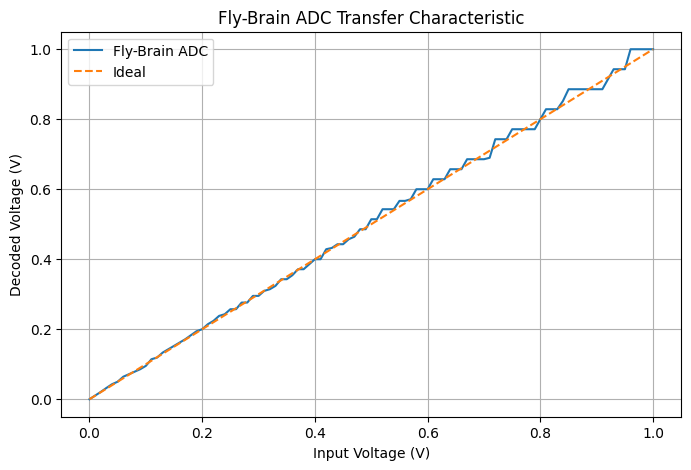

In [63]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(inputs, outputs, label="Fly-Brain ADC")
plt.plot(inputs, inputs, "--", label="Ideal")

plt.xlabel("Input Voltage (V)")
plt.ylabel("Decoded Voltage (V)")
plt.title("Fly-Brain ADC Transfer Characteristic")
plt.grid(True)
plt.legend()

plt.show()

In [64]:
# ============================================================
# Fly-Brain vs Artificial SNN ADC comparison
# ============================================================

snn_mae = 0.018092
snn_rmse = 0.021244
snn_max_lin = 0.043189
snn_inl = 2.720909

fly_mae = 0.008020
fly_rmse = 0.011341
fly_max_lin = 0.032114
fly_inl = 2.023

print("                Artificial SNN     Fly-Brain")
print(f"MAE             {snn_mae:.6f} V       {fly_mae:.6f} V")
print(f"RMSE            {snn_rmse:.6f} V       {fly_rmse:.6f} V")
print(f"Max lin. error  {snn_max_lin:.6f} V       {fly_max_lin:.6f} V")
print(f"Max INL         {snn_inl:.3f} LSB       {fly_inl:.3f} LSB")
print()

print(f"MAE improvement:       {(1 - fly_mae/snn_mae)*100:.1f}%")
print(f"RMSE improvement:      {(1 - fly_rmse/snn_rmse)*100:.1f}%")
print(f"Linearity improvement: {(1 - fly_max_lin/snn_max_lin)*100:.1f}%")
print(f"INL improvement:       {(1 - fly_inl/snn_inl)*100:.1f}%")

                Artificial SNN     Fly-Brain
MAE             0.018092 V       0.008020 V
RMSE            0.021244 V       0.011341 V
Max lin. error  0.043189 V       0.032114 V
Max INL         2.721 LSB       2.023 LSB

MAE improvement:       55.7%
RMSE improvement:      46.6%
Linearity improvement: 25.6%
INL improvement:       25.6%


In [65]:
import numpy as np

def run_spike_adc(voltage,
                  num_neurons=16,
                  sigma=0.08,
                  threshold=0.6):

    preferred_voltage = np.linspace(0, 1, num_neurons)

    activity = np.exp(
        -((voltage - preferred_voltage) ** 2)
        / (2 * sigma ** 2)
    )

    spikes = (activity > threshold).astype(float)

    denominator = np.sum(spikes)

    if denominator == 0:
        decoded = 0.5
    else:
        decoded = np.sum(
            spikes * preferred_voltage
        ) / denominator

    return np.clip(decoded, 0, 1)

In [66]:
# ============================================================
# Spike-based artificial SNN ADC baseline
# 101-point sweep
# ============================================================

snn_test_voltages = np.linspace(0.0, 1.0, 101)

snn_outputs = []
snn_codes = []

for voltage in snn_test_voltages:

    decoded = run_spike_adc(
        voltage,
        num_neurons=16,
        sigma=0.08,
        threshold=0.6
    )

    code = int(np.round(decoded * 63))

    snn_outputs.append(decoded)
    snn_codes.append(code)

snn_outputs = np.array(snn_outputs)
snn_codes = np.array(snn_codes)

snn_errors = snn_outputs - snn_test_voltages

print(f"MAE:          {np.mean(np.abs(snn_errors)):.6f} V")
print(f"RMSE:         {np.sqrt(np.mean(snn_errors**2)):.6f} V")
print(f"Max error:    {np.max(np.abs(snn_errors)):.6f} V")
print(f"Monotonic:    {np.all(np.diff(snn_codes) >= 0)}")
print(f"Code range:   {snn_codes.min()} to {snn_codes.max()}")
print(f"Unique codes: {len(np.unique(snn_codes))}")

MAE:          0.009175 V
RMSE:         0.011150 V
Max error:    0.033333 V
Monotonic:    True
Code range:   2 to 61
Unique codes: 29


In [67]:
# ============================================================
# Optimize spike-based artificial SNN
# ============================================================

neuron_options = [4, 8, 16, 32, 64]
sigma_options = [0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.10, 0.11, 0.12]
threshold_options = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]

best_result = None
all_snn_results = []

for n in neuron_options:
    for sigma_val in sigma_options:
        for threshold_val in threshold_options:

            outputs = np.array([
                run_spike_adc(
                    v,
                    num_neurons=n,
                    sigma=sigma_val,
                    threshold=threshold_val
                )
                for v in snn_test_voltages
            ])

            codes = np.round(outputs * 63).astype(int)
            errors = outputs - snn_test_voltages

            mae_val = np.mean(np.abs(errors))
            rmse_val = np.sqrt(np.mean(errors**2))
            max_error_val = np.max(np.abs(errors))
            monotonic_val = np.all(np.diff(codes) >= 0)

            result = {
                "neurons": n,
                "sigma": sigma_val,
                "threshold": threshold_val,
                "mae": mae_val,
                "rmse": rmse_val,
                "max_error": max_error_val,
                "monotonic": monotonic_val,
                "unique_codes": len(np.unique(codes))
            }

            all_snn_results.append(result)

            if monotonic_val:
                if best_result is None or mae_val < best_result["mae"]:
                    best_result = result

print("BEST SPIKE-BASED SNN")
print("---------------------")
for key, value in best_result.items():
    print(f"{key}: {value}")

BEST SPIKE-BASED SNN
---------------------
neurons: 64
sigma: 0.04
threshold: 0.8
mae: 0.002329090051862328
rmse: 0.002845156199538081
max_error: 0.007936507936507936
monotonic: True
unique_codes: 63


In [68]:
# ============================================================
# Independent validation set
# ============================================================

np.random.seed(2026)

validation_voltages = np.random.uniform(0.0, 1.0, 200)

# Make sure the validation points are sorted for analysis
validation_voltages = np.sort(validation_voltages)

print("Independent validation set created.")
print("Number of test points:", len(validation_voltages))
print("Minimum voltage:", validation_voltages.min())
print("Maximum voltage:", validation_voltages.max())

Independent validation set created.
Number of test points: 200
Minimum voltage: 0.0023971728372461643
Maximum voltage: 0.9973984637951291


In [69]:
# ============================================================
# Independent validation: optimized spike-based SNN
# ============================================================

snn_val_outputs = np.array([
    run_spike_adc(
        v,
        num_neurons=64,
        sigma=0.04,
        threshold=0.8
    )
    for v in validation_voltages
])

snn_val_codes = np.round(
    snn_val_outputs * 63
).astype(int)

snn_val_errors = snn_val_outputs - validation_voltages

print("OPTIMIZED SNN - INDEPENDENT VALIDATION")
print("---------------------------------------")
print(f"MAE:          {np.mean(np.abs(snn_val_errors)):.6f} V")
print(f"RMSE:         {np.sqrt(np.mean(snn_val_errors**2)):.6f} V")
print(f"Max error:    {np.max(np.abs(snn_val_errors)):.6f} V")
print(f"Monotonic:    {np.all(np.diff(snn_val_codes) >= 0)}")
print(f"Code range:   {snn_val_codes.min()} to {snn_val_codes.max()}")
print(f"Unique codes: {len(np.unique(snn_val_codes))}")

OPTIMIZED SNN - INDEPENDENT VALIDATION
---------------------------------------
MAE:          0.002205 V
RMSE:         0.002625 V
Max error:    0.007632 V
Monotonic:    True
Code range:   0 to 62
Unique codes: 56


In [70]:
# ============================================================
# Independent validation: Fly-Brain ADC
# Same 200 inputs used for the optimized SNN
# ============================================================

fly_val_results = []

for voltage in validation_voltages:

    drive = voltage_to_drive(voltage)

    smon, _, elapsed_ms, _ = run_simulation_v1(
        ['L1', 'Mi1'],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        g_drive_on=drive,
        g_drive_off=0.15,
        w_scale=0.06
    )

    spike_count = int(np.sum(smon.count[:]))

    decoded_drive = calibrated_spikes_to_drive(spike_count)
    decoded_voltage = drive_to_voltage(decoded_drive)
    adc_code = quantize_6bit(decoded_voltage)

    fly_val_results.append({
        "input_voltage": voltage,
        "spikes": spike_count,
        "decoded_voltage": decoded_voltage,
        "adc_code": adc_code
    })

print(f"Completed {len(fly_val_results)} Fly-Brain validation tests.")

Completed 200 Fly-Brain validation tests.


In [71]:
# ============================================================
# Fly-Brain independent validation metrics
# ============================================================

fly_val_inputs = np.array([
    r["input_voltage"] for r in fly_val_results
])

fly_val_outputs = np.array([
    r["decoded_voltage"] for r in fly_val_results
])

fly_val_codes = np.array([
    r["adc_code"] for r in fly_val_results
])

fly_val_errors = fly_val_outputs - fly_val_inputs

fly_val_mae = np.mean(np.abs(fly_val_errors))
fly_val_rmse = np.sqrt(np.mean(fly_val_errors**2))
fly_val_max_error = np.max(np.abs(fly_val_errors))

print("FLY-BRAIN - INDEPENDENT VALIDATION")
print("-----------------------------------")
print(f"MAE:          {fly_val_mae:.6f} V")
print(f"RMSE:         {fly_val_rmse:.6f} V")
print(f"Max error:    {fly_val_max_error:.6f} V")
print(f"Monotonic:    {np.all(np.diff(fly_val_codes) >= 0)}")
print(f"Code range:   {fly_val_codes.min()} to {fly_val_codes.max()}")
print(f"Unique codes: {len(np.unique(fly_val_codes))}")

FLY-BRAIN - INDEPENDENT VALIDATION
-----------------------------------
MAE:          0.008336 V
RMSE:         0.011859 V
Max error:    0.035954 V
Monotonic:    True
Code range:   0 to 63
Unique codes: 42


In [72]:
print(list(neuron_id100.keys()))

['T2a', 'Tm3', 'T4c', 'T3', 'L1', 'T4d', 'L5', 'Mi1', 'Tm2', 'Mi9', 'Tm1', 'L2', 'Tm9', 'Mi4', 'T4b', 'Tm4', 'C3', 'Tm20', 'T2', 'T4a', 'R8', 'C2', 'L3', 'Tm21', 'R7', 'T1', 'L4', 'Dm2', 'TmY5a', 'Tm27', 'Dm3p', 'Mi15', 'Dm3q', 'Mi2', 'Tm5f', 'TmY3', 'Tm25', 'Mi13', 'Dm3v', 'Tm5c', 'Y3', 'Tm5e', 'Dm10', 'Tm7', 'Tm5a', 'TmY10', 'Tm5b', 'TmY4', 'Dm8b', 'Dm15', 'TmY11', 'Mi10', 'Sm02', 'TmY9q__perp', 'TmY14', 'TmY9q', 'Dm8a', 'Tm16', 'Sm07', 'Tm5d', 'TmY31', 'TmY20', 'Tm36', 'Sm01', 'Lawf2', 'Mi14', 'Lawf1', 'Tm37', 'TmY15', 'Pm01', 'MeTu1', 'Tm8a', 'Dm12', 'Y12', 'T5b', 'Li06', 'Pm03', 'Pm02', 'Tm32', 'Y4', 'Sm08', 'Y1', 'Sm03', 'Sm09', 'Sm04', 'T5a', 'Sm06', 'Dm9', 'Sm12', 'TmY16', 'Pm05', 'MeTu3c', 'Sm05', 'MeTu4a', 'T5d', 'T5c', 'Tm8b', 'Dm11', 'Sm15', 'Tm35']


In [73]:
# Test L1 and Mi1 separately

test_voltage = 0.5

drive = voltage_to_drive(test_voltage)

smon, _, _, _ = run_simulation_v1(
    ['L1', 'Mi1'],
    neuron_id100,
    W100_4bit,
    thr100,
    N100,
    g_drive_on=drive,
    g_drive_off=0.15,
    w_scale=0.06
)

for name in ['L1', 'Mi1']:
    idx = neuron_id100[name]
    print(f"{name}: {int(smon.count[idx])} spikes")

L1: 66 spikes
Mi1: 66 spikes


In [74]:
test_voltages = np.linspace(0, 1, 11)

L1_counts = []
Mi1_counts = []

for voltage in test_voltages:
    drive = voltage_to_drive(voltage)

    smon, _, _, _ = run_simulation_v1(
        ['L1', 'Mi1'],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        g_drive_on=drive,
        g_drive_off=0.15,
        w_scale=0.06
    )

    L1_counts.append(int(smon.count[neuron_id100['L1']]))
    Mi1_counts.append(int(smon.count[neuron_id100['Mi1']]))

print("Voltage | L1 | Mi1")
for v, l1, mi1 in zip(test_voltages, L1_counts, Mi1_counts):
    print(f"{v:.1f} V    | {l1:3d} | {mi1:3d}")

Voltage | L1 | Mi1
0.0 V    |  11 |  11
0.1 V    |  25 |  26
0.2 V    |  35 |  37
0.3 V    |  45 |  47
0.4 V    |  55 |  58
0.5 V    |  66 |  66
0.6 V    |  71 |  76
0.7 V    |  83 |  83
0.8 V    |  90 |  91
0.9 V    | 100 | 100
1.0 V    | 111 | 111


In [75]:
print("Testing candidate visual neurons...")

candidates = ['L1', 'Mi1', 'T4a', 'T4b', 'T5a', 'T5b', 'L2', 'Tm1']

for name in candidates:
    print(name, "index =", neuron_id100[name])

Testing candidate visual neurons...
L1 index = 4
Mi1 index = 7
T4a index = 19
T4b index = 14
T5a index = 85
T5b index = 74
L2 index = 11
Tm1 index = 10


In [76]:
from sklearn.linear_model import LinearRegression

candidates = ['L1', 'Mi1', 'T4a', 'T4b', 'T5a', 'T5b', 'L2', 'Tm1']

X = []
y = []

for voltage in validation_voltages:
    drive = voltage_to_drive(voltage)

    smon, _, _, _ = run_simulation_v1(
        ['L1', 'Mi1'],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        g_drive_on=drive,
        g_drive_off=0.15,
        w_scale=0.06
    )

    counts = [int(smon.count[neuron_id100[name]]) for name in candidates]

    X.append(counts)
    y.append(voltage)

X = np.array(X)
y = np.array(y)

print("Shape:", X.shape)
print("First sample:", X[0])

WARNING    'v' is an internal variable of group 'neurongroup_1', but also exists in the run namespace with the value 1.0. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'v' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value 1.0. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Shape: (200, 8)
First sample: [12 12  0  0  0  0  0  0]


In [77]:
print("Spike ranges across 200 voltages:")

for i, name in enumerate(candidates):
    print(f"{name:4s}: {X[:, i].min():3d} to {X[:, i].max():3d}")

Spike ranges across 200 voltages:
L1  :  12 to 111
Mi1 :  12 to 111
T4a :   0 to   0
T4b :   0 to   0
T5a :   0 to   0
T5b :   0 to   0
L2  :   0 to   0
Tm1 :   0 to   0


In [78]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Use only the neurons that actually respond
X_l1mi1 = X[:, :2]

decoder = LinearRegression()
decoder.fit(X_l1mi1, y)

pred = decoder.predict(X_l1mi1)
pred = np.clip(pred, 0, 1)

mae = mean_absolute_error(y, pred)
rmse = np.sqrt(mean_squared_error(y, pred))

print(f"Linear decoder MAE : {mae:.6f} V")
print(f"Linear decoder RMSE: {rmse:.6f} V")

Linear decoder MAE : 0.009728 V
Linear decoder RMSE: 0.011960 V


In [79]:
test_scales = [0.03, 0.06, 0.10, 0.20]

check_neurons = ['L1', 'Mi1', 'T4a', 'T4b', 'T5a', 'T5b', 'L2', 'Tm1']

print("W_SCALE | " + " | ".join(f"{n:4s}" for n in check_neurons))
print("-" * 75)

for scale in test_scales:
    drive = voltage_to_drive(1.0)

    smon, _, _, _ = run_simulation_v1(
        ['L1', 'Mi1'],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        g_drive_on=drive,
        g_drive_off=0.15,
        w_scale=scale
    )

    counts = [
        int(smon.count[neuron_id100[name]])
        for name in check_neurons
    ]

    print(f"{scale:7.2f} | " + " | ".join(f"{c:4d}" for c in counts))

W_SCALE | L1   | Mi1  | T4a  | T4b  | T5a  | T5b  | L2   | Tm1 
---------------------------------------------------------------------------
   0.03 |  111 |  111 |    0 |    0 |    0 |    0 |    0 |    0
   0.06 |  111 |  111 |    0 |    0 |    0 |    0 |    0 |    0
   0.10 |  111 |  111 |    0 |    0 |    0 |    0 |    0 |    0
   0.20 |  111 |  124 |    0 |    0 |    0 |    0 |    0 |    0


In [80]:
for src in ['L1', 'Mi1']:
    src_idx = neuron_id100[src]

    print(f"\nConnections FROM {src}:")
    
    for dst in ['T4a', 'T4b', 'T5a', 'T5b', 'L2', 'Tm1']:
        dst_idx = neuron_id100[dst]
        w = W100_4bit[dst_idx, src_idx]
        
        print(f"{src} -> {dst}: weight = {w}")


Connections FROM L1:
L1 -> T4a: weight = 0
L1 -> T4b: weight = 0
L1 -> T5a: weight = 0
L1 -> T5b: weight = 0
L1 -> L2: weight = 0
L1 -> Tm1: weight = 0

Connections FROM Mi1:
Mi1 -> T4a: weight = 0
Mi1 -> T4b: weight = 0
Mi1 -> T5a: weight = 0
Mi1 -> T5b: weight = 0
Mi1 -> L2: weight = 0
Mi1 -> Tm1: weight = 0


In [81]:
for src in ['L1', 'Mi1']:
    src_idx = neuron_id100[src]

    print(f"\nConnections FROM {src}:")

    for dst, dst_idx in neuron_id100.items():
        w = W100_4bit[dst_idx, src_idx]

        if w != 0:
            print(f"{src} -> {dst}: weight = {w}")


Connections FROM L1:
L1 -> Tm3: weight = 1
L1 -> L5: weight = 3
L1 -> Mi1: weight = 2
L1 -> R8: weight = 1
L1 -> C2: weight = -2

Connections FROM Mi1:
Mi1 -> T2a: weight = 1
Mi1 -> Tm3: weight = 1
Mi1 -> L1: weight = 10
Mi1 -> L5: weight = 4
Mi1 -> T2: weight = 1
Mi1 -> R8: weight = 1
Mi1 -> C2: weight = -1
Mi1 -> L3: weight = 1
Mi1 -> Mi13: weight = 1
Mi1 -> Pm01: weight = 1
Mi1 -> Pm03: weight = 1


In [82]:
for voltage in [0.0, 0.25, 0.5, 0.75, 1.0]:

    drive = voltage_to_drive(voltage)

    smon, _, _, _ = run_simulation_v1(
        ['L1', 'Mi1'],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        g_drive_on=drive,
        g_drive_off=0.15,
        w_scale=0.06
    )

    l1 = int(smon.count[neuron_id100['L1']])
    mi1 = int(smon.count[neuron_id100['Mi1']])
    tm3 = int(smon.count[neuron_id100['Tm3']])

    print(f"{voltage:.2f} V | L1={l1:3d} | Mi1={mi1:3d} | Tm3={tm3:3d}")

0.00 V | L1= 11 | Mi1= 11 | Tm3=  0
0.25 V | L1= 41 | Mi1= 43 | Tm3=  0
0.50 V | L1= 66 | Mi1= 66 | Tm3=  0
0.75 V | L1= 90 | Mi1= 90 | Tm3=  0
1.00 V | L1=111 | Mi1=111 | Tm3=  0


In [83]:
import inspect

print(inspect.getsource(run_simulation_v1))

def run_simulation_v1(active_neurons, neuron_id, W_4bit, thr_vals, N,
                      duration_ms=SIM_DUR_MS, g_drive_on=None, g_drive_off=None,
                      w_scale=None, record_traces=False, trace_indices=None):
    g_on = g_drive_on  if g_drive_on  is not None else _best['G_DRIVE_ON']
    g_off= g_drive_off if g_drive_off is not None else _best['G_DRIVE_OFF']
    ws   = w_scale     if w_scale     is not None else _best['W_SCALE']

    start_scope()          # <── Brian2 scope cleared first
    defaultclock.dt = 0.5 * ms  # 0.5 ms timestep — 5× faster than default 0.1 ms
    seed(RNG_SEED)         # <── seed set AFTER start_scope (required by Brian2)

    try:
        neurons = NeuronGroup(
            N, model=COND_LIF_EQ,
            threshold='v > v_th',
            reset='v = E_rest',
            method='euler'
        )
        neurons.tau_m   = TAU_M_MS  * ms
        neurons.tau_syn = TAU_SYN_MS * ms
        neurons.v       = E_REST_MV * mV
        neurons.v_th  

In [84]:
def run_simulation_v1(active_neurons, neuron_id, W_4bit, thr_vals, N,
                      duration_ms=SIM_DUR_MS, g_drive_on=None, g_drive_off=None,
                      w_scale=None, record_traces=False, trace_indices=None):
    g_on = g_drive_on  if g_drive_on  is not None else _best['G_DRIVE_ON']
    g_off= g_drive_off if g_drive_off is not None else _best['G_DRIVE_OFF']
    ws   = w_scale     if w_scale     is not None else _best['W_SCALE']

    start_scope()          # <── Brian2 scope cleared first
    defaultclock.dt = 0.5 * ms  # 0.5 ms timestep — 5× faster than default 0.1 ms
    seed(RNG_SEED)         # <── seed set AFTER start_scope (required by Brian2)

    try:
        neurons = NeuronGroup(
            N, model=COND_LIF_EQ,
            threshold='v > v_th',
            reset='v = E_rest',
            method='euler'
        )
        neurons.tau_m   = TAU_M_MS  * ms
        neurons.tau_syn = TAU_SYN_MS * ms
        neurons.v       = E_REST_MV * mV
        neurons.v_th    = thr_vals  * volt
        neurons.E_rest  = E_REST_MV * mV
        neurons.E_exc   = E_EXC_MV  * mV
        neurons.E_inh   = E_INH_MV  * mV
        neurons.g_exc   = 0
        neurons.g_inh   = 0
        neurons.g_drive = 0

        for name in active_neurons:
            idx = neuron_id.get(name)
            if idx is not None:
                neurons.g_drive[idx] = g_off if name in OFF_TYPES else g_on

        post_j, pre_i = np.nonzero(W_4bit)
        net_objs = [neurons]

        if len(pre_i) > 0:
            w_vals = W_4bit[post_j, pre_i]
            exc_mask = w_vals > 0
            inh_mask = w_vals < 0

            if exc_mask.any():
                syn_exc = Synapses(neurons, neurons, 'w_g : 1',
                                   on_pre='g_exc_post += w_g')
                syn_exc.connect(i=pre_i[exc_mask].tolist(),
                                j=post_j[exc_mask].tolist())
                syn_exc.w_g = [float(w_vals[k]) / 15 * ws
                               for k in np.where(exc_mask)[0]]
                net_objs.append(syn_exc)

            if inh_mask.any():
                syn_inh = Synapses(neurons, neurons, 'w_g : 1',
                                   on_pre='g_inh_post += w_g')
                syn_inh.connect(i=pre_i[inh_mask].tolist(),
                                j=post_j[inh_mask].tolist())
                syn_inh.w_g = [float(abs(w_vals[k])) / 15 * ws
                               for k in np.where(inh_mask)[0]]
                net_objs.append(syn_inh)

        spike_mon = SpikeMonitor(neurons)
        net_objs.append(spike_mon)

        state_mon = None
        if record_traces:
            idx_list = trace_indices if trace_indices is not None else list(range(min(N, 8)))
            state_mon = StateMonitor(neurons, ['v', 'g_exc', 'g_inh'], record=idx_list)
            net_objs.append(state_mon)

        net = Network(*net_objs)
        tracemalloc.start()       # <── start AFTER Brian2 object creation
        t0 = time.time()
        net.run(duration_ms * ms)
        elapsed_ms = (time.time() - t0) * 1000
        _, peak_b  = tracemalloc.get_traced_memory()
        tracemalloc.stop()

    except Exception as e:
        print(f"⚠️  Brian2 simulation error: {e}")
        print("    Returning zero-spike fallback.")
        # Return minimal fallback objects
        class _FallbackMon:
            count = np.zeros(N, dtype=int)
            def spike_trains(self): return {i: np.array([]) * ms for i in range(N)}
        return _FallbackMon(), None, 0.0, 0

    return spike_mon, state_mon, elapsed_ms, peak_b


In [85]:
for voltage in [0.0, 0.25, 0.5, 0.75, 1.0]:

    drive = voltage_to_drive(voltage)

    smon, _, _, _ = run_simulation_v1(
        ['L1', 'Mi1'],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        g_drive_on=drive,
        g_drive_off=0.15,
        w_scale=0.06
    )

    l1 = int(smon.count[neuron_id100['L1']])
    mi1 = int(smon.count[neuron_id100['Mi1']])
    tm3 = int(smon.count[neuron_id100['Tm3']])

    print(f"{voltage:.2f} V | L1={l1:3d} | Mi1={mi1:3d} | Tm3={tm3:3d}")

0.00 V | L1= 11 | Mi1= 11 | Tm3=  0
0.25 V | L1= 43 | Mi1= 41 | Tm3=  0
0.50 V | L1= 66 | Mi1= 66 | Tm3=  0
0.75 V | L1= 90 | Mi1= 90 | Tm3=  0
1.00 V | L1=111 | Mi1=111 | Tm3=  0


In [86]:
tm3 = neuron_id100['Tm3']

print("Tm3 index:", tm3)
print("Tm3 threshold:", thr100[tm3])

print("\nIncoming connections to Tm3:")

for src, src_idx in neuron_id100.items():
    w = W100_4bit[tm3, src_idx]
    if w != 0:
        print(f"{src:10s} -> Tm3 : {w}")

Tm3 index: 1
Tm3 threshold: -0.050375

Incoming connections to Tm3:
T2a        -> Tm3 : 1
Tm3        -> Tm3 : 2
T4c        -> Tm3 : 2
T3         -> Tm3 : 2
L1         -> Tm3 : 1
T4d        -> Tm3 : 1
Mi1        -> Tm3 : 1
T4b        -> Tm3 : 2
T2         -> Tm3 : 2
T4a        -> Tm3 : 2
TmY5a      -> Tm3 : 2
Tm27       -> Tm3 : 1
TmY3       -> Tm3 : 2
TmY14      -> Tm3 : 2
Mi14       -> Tm3 : 1
TmY15      -> Tm3 : 1
Pm01       -> Tm3 : 2
Pm05       -> Tm3 : 2


In [87]:
tm3_idx = neuron_id100['Tm3']

drive = voltage_to_drive(0.5)

smon, state_mon, _, _ = run_simulation_v1(
    ['L1', 'Mi1'],
    neuron_id100,
    W100_4bit,
    thr100,
    N100,
    g_drive_on=drive,
    g_drive_off=0.15,
    w_scale=0.06,
    record_traces=True,
    trace_indices=[tm3_idx]
)

print("Tm3 spikes:", int(smon.count[tm3_idx]))
print("Tm3 max voltage:", float(np.max(state_mon.v[0])))
print("Tm3 threshold:", float(thr100[tm3_idx]))
print("Tm3 max excitatory conductance:", float(np.max(state_mon.g_exc[0])))

Tm3 spikes: 0
Tm3 max voltage: -0.06464368957033248
Tm3 threshold: -0.050375
Tm3 max excitatory conductance: 0.010074185446514257


In [88]:
for scale in [0.06, 0.10, 0.20, 0.40, 0.60, 1.00]:

    drive = voltage_to_drive(0.5)

    smon, state_mon, _, _ = run_simulation_v1(
        ['L1', 'Mi1'],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        g_drive_on=drive,
        g_drive_off=0.15,
        w_scale=scale,
        record_traces=True,
        trace_indices=[neuron_id100['Tm3']]
    )

    vmax = float(np.max(state_mon.v[0]))
    spikes = int(smon.count[neuron_id100['Tm3']])

    print(
        f"W_SCALE={scale:.2f} | "
        f"Tm3 max V={vmax:.5f} | "
        f"threshold={thr100[neuron_id100['Tm3']]:.5f} | "
        f"spikes={spikes}"
    )

W_SCALE=0.06 | Tm3 max V=-0.06464 | threshold=-0.05038 | spikes=0
W_SCALE=0.10 | Tm3 max V=-0.06439 | threshold=-0.05038 | spikes=0
W_SCALE=0.20 | Tm3 max V=-0.06375 | threshold=-0.05038 | spikes=0
W_SCALE=0.40 | Tm3 max V=-0.06226 | threshold=-0.05038 | spikes=0
W_SCALE=0.60 | Tm3 max V=-0.06057 | threshold=-0.05038 | spikes=0
W_SCALE=1.00 | Tm3 max V=-0.05359 | threshold=-0.05038 | spikes=0


In [89]:
for drive in [0.30, 0.50, 0.70, 1.00, 1.50, 2.00]:

    smon, state_mon, _, _ = run_simulation_v1(
        ['L1', 'Mi1'],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        g_drive_on=drive,
        g_drive_off=0.15,
        w_scale=0.06,
        record_traces=True,
        trace_indices=[neuron_id100['Tm3']]
    )

    l1 = int(smon.count[neuron_id100['L1']])
    mi1 = int(smon.count[neuron_id100['Mi1']])
    tm3 = int(smon.count[neuron_id100['Tm3']])
    vmax = float(np.max(state_mon.v[0]))

    print(
        f"drive={drive:.2f} | "
        f"L1={l1:3d} | Mi1={mi1:3d} | "
        f"Tm3={tm3:3d} | Tm3 max V={vmax:.5f}"
    )

drive=0.30 | L1= 11 | Mi1= 11 | Tm3=  0 | Tm3 max V=-0.06489
drive=0.50 | L1= 45 | Mi1= 45 | Tm3=  0 | Tm3 max V=-0.06475
drive=0.70 | L1= 72 | Mi1= 71 | Tm3=  0 | Tm3 max V=-0.06461
drive=1.00 | L1=111 | Mi1=111 | Tm3=  0 | Tm3 max V=-0.06442
drive=1.50 | L1=166 | Mi1=166 | Tm3=  0 | Tm3 max V=-0.06414
drive=2.00 | L1=250 | Mi1=250 | Tm3=  0 | Tm3 max V=-0.06372


In [90]:
tm3_idx = neuron_id100['Tm3']

smon, state_mon, _, _ = run_simulation_v1(
    ['L1', 'Mi1'],
    neuron_id100,
    W100_4bit,
    thr100,
    N100,
    g_drive_on=2.0,
    g_drive_off=0.15,
    w_scale=0.06,
    record_traces=True,
    trace_indices=[neuron_id100['L1'], neuron_id100['Mi1'], tm3_idx]
)

for i, name in enumerate(['L1', 'Mi1', 'Tm3']):
    print(
        f"{name}: "
        f"spikes={int(smon.count[neuron_id100[name]])}, "
        f"max V={float(np.max(state_mon.v[i])):.5f}, "
        f"max g_exc={float(np.max(state_mon.g_exc[i])):.6f}"
    )

L1: spikes=250, max V=-0.05269, max g_exc=0.116313
Mi1: spikes=250, max V=-0.05314, max g_exc=0.023263
Tm3: spikes=0, max V=-0.06372, max g_exc=0.023263


In [91]:
import pandas as pd

conn_file = r"C:\Users\sagni\OneDrive\Documents\capstone\biowire\connections_princeton_no_threshold.csv.gz"

connections = pd.read_csv(conn_file)

print("Shape:", connections.shape)
print("\nColumns:")
print(connections.columns.tolist())

print("\nFirst 5 rows:")
display(connections.head())

Shape: (22285323, 5)

Columns:
['pre_root_id', 'post_root_id', 'neuropil', 'syn_count', 'nt_type']

First 5 rows:


,pre_root_id,post_root_id,neuropil,syn_count,nt_type
0,720575940625363947,720575940623224444,ME_L,12,GABA
1,720575940613354467,720575940616690107,ME_L,1,ACH
2,720575940630432382,720575940618518557,ME_L,67,ACH
3,720575940627314521,720575940626337738,ME_L,10,GABA
4,720575940616775218,720575940632128018,ME_L,1,ACH


In [92]:
cell_file = r"C:\Users\sagni\OneDrive\Documents\capstone\biowire\consolidated_cell_types.csv.gz"

cells = pd.read_csv(cell_file)

print("Shape:", cells.shape)
print("\nColumns:")
print(cells.columns.tolist())

print("\nFirst 5 rows:")
display(cells.head())

Shape: (138327, 3)

Columns:
['root_id', 'primary_type', 'additional_type(s)']

First 5 rows:


,root_id,primary_type,additional_type(s)
0,720575940599457990,T4b,NaN
1,720575940599763910,T5b,NaN
2,720575940600623020,Dm3q,NaN
3,720575940602564320,KCg-m,NaN
4,720575940602720940,JO-CA,NaN


In [93]:
for cell_type in ['L1', 'Mi1']:
    ids = cells.loc[cells['primary_type'] == cell_type, 'root_id']
    
    print(f"{cell_type}: {len(ids)} neurons")
    print(ids.head().tolist())

L1: 1775 neurons
[720575940606406530, 720575940606612670, 720575940607560370, 720575940608144050, 720575940608177330]
Mi1: 1581 neurons
[720575940605092700, 720575940605262880, 720575940605288480, 720575940605961830, 720575940606034860]


In [94]:
type_counts = cells['primary_type'].value_counts()

print("Number of distinct cell types:", len(type_counts))
print("\nTop 30 cell types by neuron count:")
print(type_counts.head(30))

Number of distinct cell types: 8772

Top 30 cell types by neuron count:
primary_type
R1-6     8456
KCg-m    2189
L1       1775
T2a      1774
Tm3      1756
L2       1728
T4c      1710
T3       1676
KCab     1643
L5       1581
Mi1      1581
T4d      1569
Tm1      1554
Mi9      1551
Tm2      1549
T5c      1536
C3       1535
Mi4      1532
Tm9      1522
T5b      1514
T4b      1507
Tm20     1494
Tm4      1490
T5a      1483
L3       1477
T5d      1469
T2       1466
T4a      1457
C2       1433
T1       1400
Name: count, dtype: int64


In [95]:
# Map root IDs to cell types
id_to_type = dict(zip(cells['root_id'], cells['primary_type']))

connections['pre_type'] = connections['pre_root_id'].map(id_to_type)
connections['post_type'] = connections['post_root_id'].map(id_to_type)

# Remove connections whose neuron type couldn't be mapped
mapped = connections.dropna(subset=['pre_type', 'post_type']).copy()

print("Mapped connections:", len(mapped))

# Total synapses by source and target type
outgoing = mapped.groupby('pre_type')['syn_count'].sum()
incoming = mapped.groupby('post_type')['syn_count'].sum()

summary = pd.DataFrame({
    'outgoing_synapses': outgoing,
    'incoming_synapses': incoming
}).fillna(0)

summary['total_synapses'] = (
    summary['outgoing_synapses'] +
    summary['incoming_synapses']
)

print("\nTop 30 cell types by outgoing synapses:")
print(summary.sort_values('outgoing_synapses', ascending=False).head(30))

Mapped connections: 22153767

Top 30 cell types by outgoing synapses:
       outgoing_synapses  incoming_synapses  total_synapses
Mi1            1879532.0           665421.0       2544953.0
Tm1            1520675.0           716719.0       2237394.0
L2             1275337.0           779260.0       2054597.0
Tm3            1052193.0           595460.0       1647653.0
R1-6           1041054.0            87323.0       1128377.0
Tm2             908974.0           580366.0       1489340.0
L5              888626.0           517625.0       1406251.0
Tm4             780335.0           558488.0       1338823.0
Mi4             745605.0           559974.0       1305579.0
L1              736429.0           528826.0       1265255.0
KCg-m           703880.0           777628.0       1481508.0
T2a             662654.0           578894.0       1241548.0
KCab            626039.0           639770.0       1265809.0
Mi9             588589.0           502943.0       1091532.0
T2              555390.0      

In [96]:
# Find actual downstream cell types receiving input from L1/Mi1
source_types = ['L1', 'Mi1']

source_ids = set(
    cells.loc[cells['primary_type'].isin(source_types), 'root_id']
)

downstream = mapped[mapped['pre_root_id'].isin(source_ids)].copy()

# Sum synapses by target cell type
candidate_targets = (
    downstream.groupby('post_type')['syn_count']
    .sum()
    .sort_values(ascending=False)
)

print("Number of downstream cell types:", len(candidate_targets))
print("\nTop 30 targets receiving L1/Mi1 input:")
print(candidate_targets.head(30))

Number of downstream cell types: 329

Top 30 targets receiving L1/Mi1 input:
post_type
Tm3     242325
Mi1     200724
Pm01    190874
L5      188358
Pm03    154557
C3      146172
Pm08    143326
T3      113708
T2a      96560
C2       95574
Pm05     95545
T4a      92542
T4c      92425
T4d      79957
T4b      78615
Tm27     60706
Y3       56358
LMa5     55792
L1       35912
TmY3     34164
Tm25     28291
T2       27634
Mi4      25465
Mi2      23027
Dm10     20626
Dm2      18735
Tm21     16652
Mi9      14603
Pm09     13291
L2       12887
Name: syn_count, dtype: int64


In [97]:
candidates = [
    'Tm3', 'Pm01', 'L5', 'Pm03', 'C3',
    'Pm08', 'T3', 'T2a', 'T4a', 'T4c', 'T4b'
]

candidate_counts = type_counts.reindex(candidates)

print("Candidate | Number of neurons")
print("-" * 35)

for name, count in candidate_counts.items():
    print(f"{name:8s} | {int(count):5d}")

Candidate | Number of neurons
-----------------------------------
Tm3      |  1756
Pm01     |   241
L5       |  1581
Pm03     |   190
C3       |  1535
Pm08     |   117
T3       |  1676
T2a      |  1774
T4a      |  1457
T4c      |  1710
T4b      |  1507


In [98]:
print("Candidate | Neurons receiving L1/Mi1 input")
print("-" * 50)

for target in candidates:
    target_ids = set(
        cells.loc[cells['primary_type'] == target, 'root_id']
    )

    receiving = downstream[
        downstream['post_root_id'].isin(target_ids)
    ]['post_root_id'].nunique()

    total = len(target_ids)

    print(f"{target:8s} | {receiving:5d} / {total:5d}")"

SyntaxError: unterminated string literal (detected at line 15) (532290495.py, line 15)

In [99]:
print("Candidate | Neurons receiving L1/Mi1 input")
print("-" * 50)

for target in candidates:
    target_ids = set(
        cells.loc[cells['primary_type'] == target, 'root_id']
    )

    receiving = downstream[
        downstream['post_root_id'].isin(target_ids)
    ]['post_root_id'].nunique()

    total = len(target_ids)

    print(f"{target:8s} | {receiving:5d} / {total:5d}")

Candidate | Neurons receiving L1/Mi1 input
--------------------------------------------------
Tm3      |  1755 /  1756
Pm01     |   241 /   241
L5       |  1575 /  1581
Pm03     |   190 /   190
C3       |  1522 /  1535
Pm08     |   117 /   117
T3       |  1675 /  1676
T2a      |  1772 /  1774
T4a      |  1457 /  1457
T4c      |  1707 /  1710
T4b      |  1507 /  1507


In [100]:
print("Candidate | Total L1/Mi1 synapses | Avg synapses/neuron")
print("-" * 65)

for target in candidates:
    target_ids = set(
        cells.loc[cells['primary_type'] == target, 'root_id']
    )

    incoming = downstream[
        downstream['post_root_id'].isin(target_ids)
    ]

    total_syn = incoming['syn_count'].sum()
    n_neurons = len(target_ids)

    avg_syn = total_syn / n_neurons

    print(f"{target:8s} | {total_syn:20,d} | {avg_syn:17.2f}")

Candidate | Total L1/Mi1 synapses | Avg synapses/neuron
-----------------------------------------------------------------
Tm3      |              242,325 |            138.00
Pm01     |              190,874 |            792.01
L5       |              188,358 |            119.14
Pm03     |              154,557 |            813.46
C3       |              146,172 |             95.23
Pm08     |              143,326 |           1225.01
T3       |              113,708 |             67.84
T2a      |               96,560 |             54.43
T4a      |               92,542 |             63.52
T4c      |               92,425 |             54.05
T4b      |               78,615 |             52.17


In [101]:
print("Candidate | L1 synapses/neuron | Mi1 synapses/neuron")
print("-" * 65)

for target in ['Pm08', 'Pm03', 'Pm01', 'Tm3', 'L5']:
    
    target_ids = set(
        cells.loc[cells['primary_type'] == target, 'root_id']
    )

    incoming = mapped[
        (mapped['post_root_id'].isin(target_ids)) &
        (mapped['pre_type'].isin(['L1', 'Mi1']))
    ]

    l1_syn = incoming.loc[
        incoming['pre_type'] == 'L1', 'syn_count'
    ].sum()

    mi1_syn = incoming.loc[
        incoming['pre_type'] == 'Mi1', 'syn_count'
    ].sum()

    n = len(target_ids)

    print(
        f"{target:8s} | "
        f"{l1_syn/n:19.2f} | "
        f"{mi1_syn/n:20.2f}"
    )

Candidate | L1 synapses/neuron | Mi1 synapses/neuron
-----------------------------------------------------------------
Pm08     |                0.00 |              1225.01
Pm03     |                0.01 |               813.45
Pm01     |                0.00 |               792.00
Tm3      |               79.86 |                58.14
L5       |              111.84 |                 7.30


In [102]:
for target in ['Tm3', 'L5', 'Pm08']:
    target_ids = cells.loc[
        cells['primary_type'] == target, 'root_id'
    ].values

    print(f"{target}: {len(target_ids)} neurons")
    print("Example IDs:", target_ids[:5])
    print()

Tm3: 1756 neurons
Example IDs: [720575940604076990 720575940604341280 720575940604561510
 720575940605157990 720575940605286060]

L5: 1581 neurons
Example IDs: [720575940604947680 720575940605002720 720575940605183660
 720575940605332070 720575940605640160]

Pm08: 117 neurons
Example IDs: [720575940610544810 720575940615710570 720575940621499270
 720575940623345740 720575940624080920]



In [103]:
# Check actual L1/Mi1 -> candidate neuron connectivity

for target in ['Tm3', 'L5', 'Pm08']:
    target_ids = set(
        cells.loc[cells['primary_type'] == target, 'root_id']
    )

    edges = mapped[
        mapped['post_root_id'].isin(target_ids) &
        mapped['pre_type'].isin(['L1', 'Mi1'])
    ]

    print(f"\n{target}")
    print(f"  Edges: {len(edges):,}")
    print(f"  Total synapses: {edges['syn_count'].sum():,}")
    print(f"  Unique target neurons: {edges['post_root_id'].nunique():,}")
    print(f"  Unique presynaptic neurons: {edges['pre_root_id'].nunique():,}")


Tm3
  Edges: 20,271
  Total synapses: 242,325
  Unique target neurons: 1,755
  Unique presynaptic neurons: 3,163

L5
  Edges: 4,976
  Total synapses: 188,358
  Unique target neurons: 1,575
  Unique presynaptic neurons: 3,089

Pm08
  Edges: 7,167
  Total synapses: 143,326
  Unique target neurons: 117
  Unique presynaptic neurons: 1,581


In [104]:
for target in ['Tm3', 'L5', 'Pm08']:
    
    target_ids = set(
        cells.loc[cells['primary_type'] == target, 'root_id']
    )

    edges = mapped[
        mapped['post_root_id'].isin(target_ids) &
        mapped['pre_type'].isin(['L1', 'Mi1'])
    ].copy()

    per_neuron = (
        edges.groupby(['post_root_id', 'pre_type'])['syn_count']
        .sum()
        .unstack(fill_value=0)
    )

    for col in ['L1', 'Mi1']:
        if col not in per_neuron.columns:
            per_neuron[col] = 0

    total_input = per_neuron['L1'] + per_neuron['Mi1']

    print(f"\n{target}")
    print(f"  Mean input:   {total_input.mean():.2f}")
    print(f"  Median input: {total_input.median():.2f}")
    print(f"  Min input:    {total_input.min():.2f}")
    print(f"  Max input:    {total_input.max():.2f}")
    print(f"  Std input:    {total_input.std():.2f}")


Tm3
  Mean input:   138.08
  Median input: 139.00
  Min input:    14.00
  Max input:    293.00
  Std input:    40.03

L5
  Mean input:   119.59
  Median input: 126.00
  Min input:    3.00
  Max input:    190.00
  Std input:    30.56

Pm08
  Mean input:   1225.01
  Median input: 1231.00
  Min input:    790.00
  Max input:    1702.00
  Std input:    151.18


In [105]:
# Calculate connectome-weighted candidate input at 0.5 V

test_voltage = 0.5

# Get L1/Mi1 spike counts from the existing BioWire ADC experiment
smon, _, _, _ = run_simulation_v1(
    ['L1', 'Mi1'],
    neuron_id100,
    W100_4bit,
    thr100,
    N100
)

spike_counts = {
    name: int(np.sum(smon.i == neuron_id100[name]))
    for name in ['L1', 'Mi1']
}

print("L1 spikes :", spike_counts['L1'])
print("Mi1 spikes:", spike_counts['Mi1'])

for target in ['Tm3', 'L5', 'Pm08']:

    target_ids = set(
        cells.loc[cells['primary_type'] == target, 'root_id']
    )

    edges = mapped[
        mapped['post_root_id'].isin(target_ids) &
        mapped['pre_type'].isin(['L1', 'Mi1'])
    ]

    l1_syn = edges.loc[
        edges['pre_type'] == 'L1', 'syn_count'
    ].sum()

    mi1_syn = edges.loc[
        edges['pre_type'] == 'Mi1', 'syn_count'
    ].sum()

    weighted_input = (
        l1_syn * spike_counts['L1'] +
        mi1_syn * spike_counts['Mi1']
    )

    print(f"\n{target}")
    print("  L1 synapses :", int(l1_syn))
    print("  Mi1 synapses:", int(mi1_syn))
    print("  Weighted input:", int(weighted_input))

L1 spikes : 19
Mi1 spikes: 18

Tm3
  L1 synapses : 140237
  Mi1 synapses: 102088
  Weighted input: 4502087

L5
  L1 synapses : 176813
  Mi1 synapses: 11545
  Weighted input: 3567257

Pm08
  L1 synapses : 0
  Mi1 synapses: 143326
  Weighted input: 2579868


In [106]:
# Build full-connectome population responses
# using the same 200 independent validation voltages

candidate_targets = ['Tm3', 'L5', 'Pm08']

# Pre-compute total L1/Mi1 synapses for each candidate population
candidate_synapses = {}

for target in candidate_targets:
    target_ids = set(
        cells.loc[cells['primary_type'] == target, 'root_id']
    )

    edges = mapped[
        mapped['post_root_id'].isin(target_ids) &
        mapped['pre_type'].isin(['L1', 'Mi1'])
    ]

    candidate_synapses[target] = {
        'L1': edges.loc[
            edges['pre_type'] == 'L1', 'syn_count'
        ].sum(),
        'Mi1': edges.loc[
            edges['pre_type'] == 'Mi1', 'syn_count'
        ].sum()
    }

# Generate L1/Mi1 spike responses for the 200 validation voltages
fly_inputs = []

for v in validation_voltages:

    drive = voltage_to_drive(v)

    smon, _, _, _ = run_simulation_v1(
        ['L1', 'Mi1'],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        g_drive_on=drive,
        g_drive_off=0.15,
        w_scale=0.06
    )

    l1_spikes = int(np.sum(smon.i == neuron_id100['L1']))
    mi1_spikes = int(np.sum(smon.i == neuron_id100['Mi1']))

    fly_inputs.append((l1_spikes, mi1_spikes))

fly_inputs = np.array(fly_inputs)

# Calculate connectome-weighted population input
population_response = {}

for target in candidate_targets:

    l1_syn = candidate_synapses[target]['L1']
    mi1_syn = candidate_synapses[target]['Mi1']

    response = (
        fly_inputs[:, 0] * l1_syn +
        fly_inputs[:, 1] * mi1_syn
    )

    population_response[target] = response

    print(
        f"{target}: "
        f"min={response.min():,.0f}, "
        f"max={response.max():,.0f}, "
        f"unique={len(np.unique(response))}"
    )

WARNING    'v' is an internal variable of group 'neurongroup_3', but also exists in the run namespace with the value 0.0023971728372461643. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'v' is an internal variable of group 'neurongroup_1', but also exists in the run namespace with the value 0.0033356108310241828. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'v' is an internal variable of group 'neurongroup_3', but also exists in the run namespace with the value 0.023002568396193634. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'v' is an internal variable of group 'neurongroup_1', but also exists in the run namespace with the value 0.024685688688828256. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'v' is an internal variable of group 'neurongroup_3', but also 

Tm3: min=2,907,900, max=26,898,075, unique=61
L5: min=2,260,296, max=20,907,738, unique=61
Pm08: min=1,719,912, max=15,909,186, unique=40


In [107]:
# Evaluate the connectome-weighted population readouts

for target in ['Tm3', 'L5', 'Pm08']:
    
    response = population_response[target]

    monotonic = np.all(np.diff(response) >= 0)
    
    # Normalize this population's response to 0-1
    normalized = (
        (response - response.min()) /
        (response.max() - response.min())
    )

    codes = np.round(normalized * 63).astype(int)

    print(f"\n{target}")
    print(f"  Monotonic:     {monotonic}")
    print(f"  Code range:    {codes.min()} - {codes.max()}")
    print(f"  Unique codes:  {len(np.unique(codes))}")
    print(f"  Min response:  {response.min():,.0f}")
    print(f"  Max response:  {response.max():,.0f}")


Tm3
  Monotonic:     True
  Code range:    0 - 63
  Unique codes:  42
  Min response:  2,907,900
  Max response:  26,898,075

L5
  Monotonic:     True
  Code range:    0 - 63
  Unique codes:  37
  Min response:  2,260,296
  Max response:  20,907,738

Pm08
  Monotonic:     True
  Code range:    0 - 63
  Unique codes:  33
  Min response:  1,719,912
  Max response:  15,909,186


In [108]:
for target in ['Tm3', 'L5', 'Pm08']:

    response = population_response[target]

    normalized = (
        (response - response.min()) /
        (response.max() - response.min())
    )

    decoded = normalized

    error = decoded - validation_voltages

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error**2))
    max_error = np.max(np.abs(error))

    print(f"\n{target}")
    print(f"  MAE:       {mae:.6f} V")
    print(f"  RMSE:      {rmse:.6f} V")
    print(f"  Max error: {max_error:.6f} V")


Tm3
  MAE:       0.034747 V
  RMSE:      0.037604 V
  Max error: 0.056399 V

L5
  MAE:       0.043383 V
  RMSE:      0.046761 V
  Max error: 0.075607 V

Pm08
  MAE:       0.028855 V
  RMSE:      0.032100 V
  Max error: 0.057932 V


In [109]:
# Build the real Pm08 population connectivity
# using the actual FlyWire neuron-level synapse counts.

target = 'Pm08'

pm08_ids = cells.loc[
    cells['primary_type'] == target, 'root_id'
].values

pm08_edges = mapped[
    mapped['post_root_id'].isin(set(pm08_ids)) &
    mapped['pre_type'].isin(['L1', 'Mi1'])
].copy()

# One row per Pm08 neuron, with L1 and Mi1 input counts
pm08_input = (
    pm08_edges
    .groupby(['post_root_id', 'pre_type'])['syn_count']
    .sum()
    .unstack(fill_value=0)
    .reindex(pm08_ids, fill_value=0)
)

for col in ['L1', 'Mi1']:
    if col not in pm08_input.columns:
        pm08_input[col] = 0

pm08_input = pm08_input[['L1', 'Mi1']]

print("Pm08 population:", len(pm08_input))
print("Total L1 synapses :", int(pm08_input['L1'].sum()))
print("Total Mi1 synapses:", int(pm08_input['Mi1'].sum()))
print()
print(pm08_input.head())
print()
print("L1 synapses/neuron:")
print(pm08_input['L1'].describe())
print()
print("Mi1 synapses/neuron:")
print(pm08_input['Mi1'].describe())

Pm08 population: 117
Total L1 synapses : 0
Total Mi1 synapses: 143326

pre_type            L1   Mi1
post_root_id                
720575940610544810   0  1175
720575940615710570   0  1045
720575940621499270   0  1361
720575940623345740   0  1185
720575940624080920   0  1271

L1 synapses/neuron:
count    117.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: L1, dtype: float64

Mi1 synapses/neuron:
count     117.000000
mean     1225.008547
std       151.176278
min       790.000000
25%      1140.000000
50%      1231.000000
75%      1312.000000
max      1702.000000
Name: Mi1, dtype: float64


In [110]:
# Pm08 population response model
# Each Pm08 neuron receives the measured number of Mi1 synapses.
# We convert Mi1 spike count into synaptic input using the real
# neuron-by-neuron FlyWire connectivity.

def pm08_population_response(mi1_spikes):
    """
    Return the response of all 117 Pm08 neurons
    for a given Mi1 spike count.
    """
    
    # Each Mi1 spike contributes proportionally to
    # the number of Mi1 synapses received by that Pm08 neuron.
    synaptic_input = (
        pm08_input['Mi1'].values * mi1_spikes
    )
    
    return synaptic_input


# Test at the middle input point
test_mi1_spikes = 18

response = pm08_population_response(test_mi1_spikes)

print("Mi1 spikes:", test_mi1_spikes)
print("Pm08 neurons:", len(response))
print("Mean input:", response.mean())
print("Median input:", np.median(response))
print("Min input:", response.min())
print("Max input:", response.max())

Mi1 spikes: 18
Pm08 neurons: 117
Mean input: 22050.153846153848
Median input: 22158.0
Min input: 14220
Max input: 30636


In [111]:
# Simple threshold activation of the 117 Pm08 neurons

def pm08_spike_response(mi1_spikes, threshold):
    synaptic_input = pm08_population_response(mi1_spikes)
    spikes = (synaptic_input >= threshold).astype(int)
    return spikes


# Inspect the input distribution at several Mi1 activity levels
for mi1_spikes in [10, 20, 40, 60, 80, 100]:

    synaptic_input = pm08_population_response(mi1_spikes)

    print(
        f"Mi1 spikes = {mi1_spikes:3d} | "
        f"Input range = {synaptic_input.min():6.0f} - "
        f"{synaptic_input.max():6.0f}"
    )

Mi1 spikes =  10 | Input range =   7900 -  17020
Mi1 spikes =  20 | Input range =  15800 -  34040
Mi1 spikes =  40 | Input range =  31600 -  68080
Mi1 spikes =  60 | Input range =  47400 - 102120
Mi1 spikes =  80 | Input range =  63200 - 136160
Mi1 spikes = 100 | Input range =  79000 - 170200


In [112]:
# Normalized Pm08 population response

# Mi1 activity range observed in our ADC experiments
MI1_MIN_SPIKES = 22
MI1_MAX_SPIKES = 222

def pm08_normalized_response(mi1_spikes):

    # Convert Mi1 spike count to 0-1 activity
    mi1_activity = (
        (mi1_spikes - MI1_MIN_SPIKES) /
        (MI1_MAX_SPIKES - MI1_MIN_SPIKES)
    )

    mi1_activity = np.clip(mi1_activity, 0, 1)

    # Real neuron-by-neuron Mi1 connectivity
    synapse_counts = pm08_input['Mi1'].values

    # Normalize each neuron's connectivity
    connectivity = (
        synapse_counts / synapse_counts.max()
    )

    # Population activity
    neuron_activity = mi1_activity * connectivity

    return neuron_activity


for mi1_spikes in [22, 50, 100, 150, 200, 222]:

    activity = pm08_normalized_response(mi1_spikes)

    print(
        f"Mi1 spikes = {mi1_spikes:3d} | "
        f"Mean Pm08 activity = {activity.mean():.4f} | "
        f"Active population = {np.sum(activity > 0):3d}/117"
    )

Mi1 spikes =  22 | Mean Pm08 activity = 0.0000 | Active population =   0/117
Mi1 spikes =  50 | Mean Pm08 activity = 0.1008 | Active population = 117/117
Mi1 spikes = 100 | Mean Pm08 activity = 0.2807 | Active population = 117/117
Mi1 spikes = 150 | Mean Pm08 activity = 0.4606 | Active population = 117/117
Mi1 spikes = 200 | Mean Pm08 activity = 0.6406 | Active population = 117/117
Mi1 spikes = 222 | Mean Pm08 activity = 0.7197 | Active population = 117/117


In [113]:
pm08_ids = cells.loc[cells["primary_type"] == "Pm08", "root_id"].to_numpy()

print("Pm08 neurons:", len(pm08_ids))
print("First 10 IDs:")
print(pm08_ids[:10])

Pm08 neurons: 117
First 10 IDs:
[720575940610544810 720575940615710570 720575940621499270
 720575940623345740 720575940624080920 720575940624281480
 720575940625377800 720575940627223140 720575940627286530
 720575940630770370]


In [114]:
# Get the actual Mi1 spike train at 0.5 V

test_voltage = 0.5
test_drive = voltage_to_drive(test_voltage)

smon_test, _, _, _ = run_simulation_v1(
    ['L1', 'Mi1'],
    neuron_id100,
    W100_4bit,
    thr100,
    N100,
    g_drive_on=test_drive,
    g_drive_off=0.15,
    w_scale=0.06
)

mi1_idx = neuron_id100['Mi1']

mi1_times = np.asarray(
    smon_test.t[smon_test.i == mi1_idx] / ms
)

print("Input voltage:", test_voltage, "V")
print("Mi1 spike count:", len(mi1_times))
print("Mi1 spike times (ms):")
print(np.round(mi1_times, 2))

WARNING    'v' is an internal variable of group 'neurongroup_3', but also exists in the run namespace with the value 0.9973984637951291. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Input voltage: 0.5 V
Mi1 spike count: 66
Mi1 spike times (ms):
[  7.5  15.   22.5  30.   37.5  45.   52.5  60.   67.5  75.   82.5  90.
  97.5 105.  112.5 120.  127.5 135.  142.5 150.  157.5 165.  172.5 180.
 187.5 195.  202.5 210.  217.5 225.  232.5 240.  247.5 255.  262.5 270.
 277.5 285.  292.5 300.  307.5 315.  322.5 330.  337.5 345.  352.5 360.
 367.5 375.  382.5 390.  397.5 405.  412.5 420.  427.5 435.  442.5 450.
 457.5 465.  472.5 480.  487.5 495. ]


In [115]:
print("Voltage → drive check")

for input_voltage in [0.0, 0.25, 0.5, 0.75, 1.0]:
    drive = voltage_to_drive(input_voltage)
    print(f"{input_voltage:.2f} V → drive {drive:.3f}")

Voltage → drive check
0.00 V → drive 0.300
0.25 V → drive 0.475
0.50 V → drive 0.650
0.75 V → drive 0.825
1.00 V → drive 1.000


In [116]:
print("Current best parameters:")
print(_best)

Current best parameters:
{'G_DRIVE_ON': 0.33, 'G_DRIVE_OFF': 0.15, 'W_SCALE': 0.06}


In [117]:
from brian2 import *

# Reset Brian2 state
start_scope()

N_PM08 = len(pm08_input)

# Pm08 neuron parameters
tau_pm08 = 20 * ms
v_rest_pm08 = -70 * mV
v_reset_pm08 = -70 * mV
v_threshold_pm08 = -50 * mV

pm08 = NeuronGroup(
    N_PM08,
    '''
    dv/dt = (v_rest - v) / tau : volt
    ''',
    threshold='v > v_threshold',
    reset='v = v_reset',
    method='euler'
)

pm08.v_rest = v_rest_pm08
pm08.v_reset = v_reset_pm08
pm08.v_threshold = v_threshold_pm08
pm08.v = v_rest_pm08

print("Pm08 Brian2 population created:", N_PM08)
print("Neuron count:", len(pm08))

AttributeError: Could not find a state variable with name "v_rest". Use the add_attribute method if you intend to add a new attribute to the object.

In [118]:
from brian2 import *

start_scope()

N_PM08 = len(pm08_input)

tau_pm08 = 20 * ms

pm08 = NeuronGroup(
    N_PM08,
    '''
    dv/dt = (v_rest - v) / tau_m : volt
    tau_m : second
    v_rest : volt
    v_reset : volt
    v_threshold : volt
    ''',
    threshold='v > v_threshold',
    reset='v = v_reset',
    method='euler'
)

pm08.tau_m = tau_pm08
pm08.v_rest = -70 * mV
pm08.v_reset = -70 * mV
pm08.v_threshold = -50 * mV
pm08.v = pm08.v_rest

print("Pm08 Brian2 population created:", N_PM08)
print("Neuron count:", len(pm08))

Pm08 Brian2 population created: 117
Neuron count: 117


In [119]:
from brian2 import *

start_scope()

# Recreate the 117-neuron Pm08 population
N_PM08 = len(pm08_input)

pm08 = NeuronGroup(
    N_PM08,
    '''
    dv/dt = (v_rest - v) / tau_m : volt
    tau_m : second
    v_rest : volt
    v_reset : volt
    v_threshold : volt
    ''',
    threshold='v > v_threshold',
    reset='v = v_reset',
    method='euler'
)

pm08.tau_m = 20 * ms
pm08.v_rest = -70 * mV
pm08.v_reset = -70 * mV
pm08.v_threshold = -50 * mV
pm08.v = pm08.v_rest

# Mi1 spike source
mi1_source = SpikeGeneratorGroup(
    1,
    indices=np.zeros(len(mi1_times), dtype=int),
    times=mi1_times
)

# Connect the single Mi1 source to ALL 117 Pm08 neurons
syn = Synapses(
    mi1_source,
    pm08,
    model='w : 1',
    on_pre='v_post += w * mV'
)

syn.connect()
syn.w = 0.20

# Record Pm08 activity
pm08_monitor = SpikeMonitor(pm08)

run(500 * ms)

print("Mi1 input spikes:", len(mi1_times))
print("Pm08 neurons:", N_PM08)
print("Pm08 spikes:", pm08_monitor.num_spikes)
print("Active Pm08 neurons:", len(np.unique(pm08_monitor.i)))

WARNING    The object 'neurongroup_5' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File 'C:\Users\sagni\AppData\Local\Temp\ipykernel_37204\3745361821.py', line 9, in <module>
    pm08 = NeuronGroup( [brian2.core.base.unused_brian_object]


DimensionMismatchError: Function '__init__' expected a quantity with unit second for argument 'times' but got '[  7.5  15.   22.5  30.   37.5  45.   52.5  60.   67.5  75.   82.5  90.
  97.5 105.  112.5 120.  127.5 135.  142.5 150.  157.5 165.  172.5 180.
 187.5 195.  202.5 210.  217.5 225.  232.5 240.  247.5 255.  262.5 270.
 277.5 285.  292.5 300.  307.5 315.  322.5 330.  337.5 345.  352.5 360.
 367.5 375.  382.5 390.  397.5 405.  412.5 420.  427.5 435.  442.5 450.
 457.5 465.  472.5 480.  487.5 495. ]' (unit is 1).

In [120]:
from brian2 import *

start_scope()

N_PM08 = len(pm08_input)

# Pm08 population
pm08 = NeuronGroup(
    N_PM08,
    '''
    dv/dt = (v_rest - v) / tau_m : volt
    tau_m : second
    v_rest : volt
    v_reset : volt
    v_threshold : volt
    ''',
    threshold='v > v_threshold',
    reset='v = v_reset',
    method='euler'
)

pm08.tau_m = 20 * ms
pm08.v_rest = -70 * mV
pm08.v_reset = -70 * mV
pm08.v_threshold = -50 * mV
pm08.v = pm08.v_rest

# Mi1 spike source
mi1_source = SpikeGeneratorGroup(
    1,
    indices=np.zeros(len(mi1_times), dtype=int),
    times=mi1_times * ms
)

# Mi1 -> every Pm08 neuron
syn = Synapses(
    mi1_source,
    pm08,
    model='w : 1',
    on_pre='v_post += w * mV'
)

syn.connect()
syn.w = 0.20

# Record Pm08 spikes
pm08_monitor = SpikeMonitor(pm08)

run(500 * ms)

print("Mi1 input spikes:", len(mi1_times))
print("Pm08 neurons:", N_PM08)
print("Pm08 spikes:", pm08_monitor.num_spikes)
print("Active Pm08 neurons:", len(np.unique(pm08_monitor.i)))

WARNING    The object 'neurongroup_6' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File 'C:\Users\sagni\AppData\Local\Temp\ipykernel_37204\80308282.py', line 8, in <module>
    pm08 = NeuronGroup( [brian2.core.base.unused_brian_object]
WARNING    The object 'neurongroup_4' is getting deleted, but was never included in a network. This probably means that you did not store the object reference in a variable, or that the variable was not used to construct the network.
The object was created here (most recent call only):
  File 'C:\Users\sagni\AppData\Local\Temp\ipykernel_37204\1228351296.py', line 14, in <module>
    pm08 = NeuronGroup( [brian2.core.base.unused_brian_object]
WARNING    'v' is an internal variable of group 'neurongroup_5', but also exists in the run namespace with the va

Mi1 input spikes: 66
Pm08 neurons: 117
Pm08 spikes: 0
Active Pm08 neurons: 0


In [121]:
from brian2 import *

start_scope()

N_PM08 = len(pm08_input)

# Pm08 population
pm08 = NeuronGroup(
    N_PM08,
    '''
    dv/dt = (v_rest - v) / tau_m : volt
    tau_m : second
    v_rest : volt
    v_reset : volt
    v_threshold : volt
    ''',
    threshold='v > v_threshold',
    reset='v = v_reset',
    method='euler'
)

pm08.tau_m = 20 * ms
pm08.v_rest = -70 * mV
pm08.v_reset = -70 * mV
pm08.v_threshold = -50 * mV
pm08.v = pm08.v_rest

# Real Mi1 spike train from BioWire
mi1_source = SpikeGeneratorGroup(
    1,
    indices=np.zeros(len(mi1_times), dtype=int),
    times=mi1_times * ms
)

# Mi1 -> all Pm08 neurons
syn = Synapses(
    mi1_source,
    pm08,
    model='w_syn : 1',
    on_pre='v_post += w_syn * mV'
)

syn.connect()
syn.w_syn = 0.20

# Record membrane voltage
state_mon = StateMonitor(
    pm08,
    'v',
    record=True
)

run(500 * ms)

# Measure the response
v_max = np.max(state_mon.v / mV, axis=1)
v_final = state_mon.v[:, -1] / mV

print("Mi1 input spikes:", len(mi1_times))
print("Pm08 neurons:", N_PM08)
print("Highest Pm08 voltage:", np.max(v_max), "mV")
print("Lowest Pm08 voltage:", np.min(v_max), "mV")
print("Mean peak voltage:", np.mean(v_max), "mV")
print("Threshold:", -50, "mV")

WARNING    'v' is an internal variable of group 'neurongroup_4', but also exists in the run namespace with the value 0.9973984637951291. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Mi1 input spikes: 66
Pm08 neurons: 117
Highest Pm08 voltage: -69.36704717410272 mV
Lowest Pm08 voltage: -69.36704717410272 mV
Mean peak voltage: -69.36704717410271 mV
Threshold: -50 mV


In [122]:
# Actual FlyWire Mi1 -> Pm08 connectivity

mi1_pm08 = mapped[
    (mapped["pre_type"] == "Mi1") &
    (mapped["post_type"] == "Pm08")
]

pm08_input = (
    mi1_pm08
    .groupby("post_root_id")["syn_count"]
    .sum()
    .reindex(pm08_ids, fill_value=0)
)

print("Pm08 neurons:", len(pm08_ids))
print("Total Mi1 -> Pm08 synapses:", pm08_input.sum())
print("Mean:", pm08_input.mean())
print("Median:", pm08_input.median())
print("Min:", pm08_input.min())
print("Max:", pm08_input.max())
print("Std:", pm08_input.std())

Pm08 neurons: 117
Total Mi1 -> Pm08 synapses: 143326
Mean: 1225.008547008547
Median: 1231.0
Min: 790
Max: 1702
Std: 151.1762784556433


In [123]:
import numpy as np
import pandas as pd

# --------------------------------------------------
# 1. Actual Mi1 -> Pm08 connectivity from FlyWire
# --------------------------------------------------

mi1_pm08 = mapped[
    (mapped["pre_type"] == "Mi1") &
    (mapped["post_type"] == "Pm08")
]

pm08_input = (
    mi1_pm08
    .groupby("post_root_id")["syn_count"]
    .sum()
    .reindex(pm08_ids, fill_value=0)
)

pm08_weights = pm08_input.to_numpy(dtype=float)

print("Pm08 population:", len(pm08_weights))
print("Total Mi1 -> Pm08 synapses:", pm08_weights.sum())


# --------------------------------------------------
# 2. Run the Fly brain across the ADC input range
# --------------------------------------------------

test_voltages = np.linspace(0, 1, 101)

mi1_spike_counts = []
population_response = []

for voltage in test_voltages:

    drive = voltage_to_drive(voltage)

    smon, _, _, _ = run_simulation_v1(
        ['L1', 'Mi1'],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        g_drive_on=drive,
        g_drive_off=0.15,
        w_scale=0.06
    )

    mi1_idx = neuron_id100['Mi1']

    spike_count = np.sum(smon.i == mi1_idx)

    # Connectome-weighted population response
    response = spike_count * np.sum(pm08_weights)

    mi1_spike_counts.append(spike_count)
    population_response.append(response)


mi1_spike_counts = np.array(mi1_spike_counts)
population_response = np.array(population_response)


# --------------------------------------------------
# 3. Normalize population response to 0-1
# --------------------------------------------------

response_min = population_response.min()
response_max = population_response.max()

normalized_response = (
    population_response - response_min
) / (
    response_max - response_min
)


# --------------------------------------------------
# 4. Convert to 6-bit ADC
# --------------------------------------------------

adc_codes = np.round(
    normalized_response * 63
).astype(int)


# --------------------------------------------------
# 5. Decode ADC code back to voltage
# --------------------------------------------------

decoded_voltage = adc_codes / 63.0

errors = decoded_voltage - test_voltages


# --------------------------------------------------
# 6. Metrics
# --------------------------------------------------

mae = np.mean(np.abs(errors))
rmse = np.sqrt(np.mean(errors**2))
max_error = np.max(np.abs(errors))

monotonic = np.all(np.diff(adc_codes) >= 0)

unique_codes = len(np.unique(adc_codes))

print("\n===== FLY CONNECTOME ADC =====")
print("Input points:", len(test_voltages))
print("Mi1 spike range:", mi1_spike_counts.min(), "to", mi1_spike_counts.max())
print("Population response range:", population_response.min(), "to", population_response.max())
print("MAE:", mae, "V")
print("RMSE:", rmse, "V")
print("Max error:", max_error, "V")
print("Monotonic:", monotonic)
print("Code range:", adc_codes.min(), "to", adc_codes.max())
print("Unique 6-bit codes:", unique_codes, "/ 64")


# --------------------------------------------------
# 7. Show transfer table
# --------------------------------------------------

results = pd.DataFrame({
    "Input_V": test_voltages,
    "Mi1_spikes": mi1_spike_counts,
    "Pm08_population_response": population_response,
    "ADC_code": adc_codes,
    "Decoded_V": decoded_voltage,
    "Error_V": errors
})

print("\nFirst 11 points:")
print(results.iloc[::10].to_string(index=False))

Pm08 population: 117
Total Mi1 -> Pm08 synapses: 143326.0


WARNING    'v' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value 0.9973984637951291. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]



===== FLY CONNECTOME ADC =====
Input points: 101
Mi1 spike range: 11 to 111
Population response range: 1576586.0 to 15909186.0
MAE: 0.03297186861543297 V
RMSE: 0.03667853328023357 V
Max error: 0.06111111111111123 V
Monotonic: True
Code range: 0 to 63
Unique 6-bit codes: 36 / 64

First 11 points:
 Input_V  Mi1_spikes  Pm08_population_response  ADC_code  Decoded_V   Error_V
     0.0          11                 1576586.0         0   0.000000  0.000000
     0.1          25                 3583150.0         9   0.142857  0.042857
     0.2          35                 5016410.0        15   0.238095  0.038095
     0.3          45                 6449670.0        21   0.333333  0.033333
     0.4          55                 7882930.0        28   0.444444  0.044444
     0.5          66                 9459516.0        35   0.555556  0.055556
     0.6          71                10176146.0        38   0.603175  0.003175
     0.7          83                11896058.0        45   0.714286  0.014286


In [124]:
import numpy as np

test_voltages = np.linspace(0, 1, 101)

l1_counts = []
mi1_counts = []

for voltage in test_voltages:

    drive = voltage_to_drive(voltage)

    smon, _, _, _ = run_simulation_v1(
        ['L1', 'Mi1'],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        g_drive_on=drive,
        g_drive_off=0.15,
        w_scale=0.06
    )

    l1_idx = neuron_id100['L1']
    mi1_idx = neuron_id100['Mi1']

    l1_counts.append(np.sum(smon.i == l1_idx))
    mi1_counts.append(np.sum(smon.i == mi1_idx))

l1_counts = np.array(l1_counts)
mi1_counts = np.array(mi1_counts)

# Normalize each neural feature independently
l1_norm = (
    l1_counts - l1_counts.min()
) / (
    l1_counts.max() - l1_counts.min()
)

mi1_norm = (
    mi1_counts - mi1_counts.min()
) / (
    mi1_counts.max() - mi1_counts.min()
)

# Simple two-neuron population readout
combined_response = (l1_norm + mi1_norm) / 2

# Convert to 6-bit ADC
adc_codes = np.round(combined_response * 63).astype(int)

decoded_voltage = adc_codes / 63.0

errors = decoded_voltage - test_voltages

print("===== L1 + Mi1 POPULATION READOUT =====")
print("L1 spike range:", l1_counts.min(), "to", l1_counts.max())
print("Mi1 spike range:", mi1_counts.min(), "to", mi1_counts.max())
print("MAE:", np.mean(np.abs(errors)), "V")
print("RMSE:", np.sqrt(np.mean(errors**2)), "V")
print("Max error:", np.max(np.abs(errors)), "V")
print("Monotonic:", np.all(np.diff(adc_codes) >= 0))
print("Code range:", adc_codes.min(), "to", adc_codes.max())
print("Unique codes:", len(np.unique(adc_codes)), "/ 64")

print("\nSelected points:")
for i in range(0, 101, 10):
    print(
        f"{test_voltages[i]:.1f} V -> "
        f"L1={l1_counts[i]:3d}, "
        f"Mi1={mi1_counts[i]:3d}, "
        f"ADC={adc_codes[i]:2d}"
    )

===== L1 + Mi1 POPULATION READOUT =====
L1 spike range: 11 to 111
Mi1 spike range: 11 to 111
MAE: 0.03763947823353762 V
RMSE: 0.04140787973724726 V
Max error: 0.06746031746031744 V
Monotonic: True
Code range: 0 to 63
Unique codes: 48 / 64

Selected points:
0.0 V -> L1= 11, Mi1= 11, ADC= 0
0.1 V -> L1= 26, Mi1= 25, ADC= 9
0.2 V -> L1= 37, Mi1= 35, ADC=16
0.3 V -> L1= 47, Mi1= 45, ADC=22
0.4 V -> L1= 58, Mi1= 55, ADC=29
0.5 V -> L1= 66, Mi1= 66, ADC=35
0.6 V -> L1= 76, Mi1= 71, ADC=39
0.7 V -> L1= 83, Mi1= 83, ADC=45
0.8 V -> L1= 91, Mi1= 90, ADC=50
0.9 V -> L1=100, Mi1=100, ADC=56
1.0 V -> L1=111, Mi1=111, ADC=63


In [125]:
# L1-only ADC readout

l1_norm = (
    l1_counts - l1_counts.min()
) / (
    l1_counts.max() - l1_counts.min()
)

l1_codes = np.round(l1_norm * 63).astype(int)

l1_decoded = l1_codes / 63.0
l1_errors = l1_decoded - test_voltages

print("===== L1-ONLY READOUT =====")
print("MAE:", np.mean(np.abs(l1_errors)), "V")
print("RMSE:", np.sqrt(np.mean(l1_errors**2)), "V")
print("Max error:", np.max(np.abs(l1_errors)), "V")
print("Monotonic:", np.all(np.diff(l1_codes) >= 0))
print("Code range:", l1_codes.min(), "to", l1_codes.max())
print("Unique codes:", len(np.unique(l1_codes)), "/ 64")

===== L1-ONLY READOUT =====
MAE: 0.04785478547854782 V
RMSE: 0.05203657169803608 V
Max error: 0.08317460317460312 V
Monotonic: True
Code range: 0 to 63
Unique codes: 37 / 64


In [126]:
print("===== L1 + Mi1 WEIGHT SWEEP =====")

best = None
results = []

for alpha in np.linspace(0, 1, 11):

    combined = (
        alpha * l1_norm +
        (1 - alpha) * mi1_norm
    )

    codes = np.round(combined * 63).astype(int)
    decoded = codes / 63.0
    errors = decoded - test_voltages

    mae = np.mean(np.abs(errors))
    rmse = np.sqrt(np.mean(errors**2))
    max_error = np.max(np.abs(errors))
    monotonic = np.all(np.diff(codes) >= 0)
    unique_codes = len(np.unique(codes))

    results.append(
        (alpha, mae, rmse, max_error, unique_codes, monotonic)
    )

    if monotonic and (best is None or mae < best[1]):
        best = (
            alpha,
            mae,
            rmse,
            max_error,
            unique_codes,
            monotonic
        )

print("\nAlpha   MAE       RMSE      MaxErr    Codes   Mono")
for r in results:
    print(
        f"{r[0]:.1f}    "
        f"{r[1]:.6f}  "
        f"{r[2]:.6f}  "
        f"{r[3]:.6f}  "
        f"{r[4]:2d}      "
        f"{r[5]}"
    )

print("\n===== BEST MONOTONIC RESULT =====")
print("L1 weight:", best[0])
print("Mi1 weight:", 1 - best[0])
print("MAE:", best[1])
print("RMSE:", best[2])
print("Max error:", best[3])
print("Unique codes:", best[4])

===== L1 + Mi1 WEIGHT SWEEP =====

Alpha   MAE       RMSE      MaxErr    Codes   Mono
0.0    0.032972  0.036679  0.061111  36      True
0.1    0.032548  0.036535  0.059206  38      True
0.2    0.032994  0.037031  0.059841  40      True
0.3    0.034226  0.038137  0.063333  42      True
0.4    0.035710  0.039749  0.063333  45      True
0.5    0.037639  0.041408  0.067460  48      True
0.6    0.039683  0.043425  0.067460  48      True
0.7    0.041254  0.044771  0.071587  47      True
0.8    0.043297  0.046807  0.072698  47      True
0.9    0.045655  0.049499  0.075079  41      True
1.0    0.047855  0.052037  0.083175  37      True

===== BEST MONOTONIC RESULT =====
L1 weight: 0.1
Mi1 weight: 0.9
MAE: 0.032547540468332546
RMSE: 0.03653542890659957
Max error: 0.05920634920634921
Unique codes: 38


In [127]:
# ============================================================
# EXP-20: Temporal Feature Characterization
# Goal: test whether spike timing contains ADC information
# ============================================================

import numpy as np

TEMPORAL_VOLTAGES = np.linspace(0, 1, 21)

temporal_results = []

for v_in in TEMPORAL_VOLTAGES:

    g_on = voltage_to_drive(v_in)

    smon, _, _, _ = run_simulation_v1(
        ['L1', 'Mi1'],
        neuron_id_core,
        W_core_4bit,
        thr_core,
        N_core,
        g_drive_on=g_on,
        g_drive_off=0.15,
        w_scale=0.06
    )

    row = {'voltage': float(v_in)}

    for ntype in ['L1', 'Mi1']:

        idx = neuron_id_core[ntype]

        # Spike times for this neuron
        spike_times = np.asarray(smon.t[smom_i] / ms) if False else None

        # Brian2 SpikeMonitor access
        spike_times = np.asarray(smon.t[smon.i == idx] / ms)

        n_spikes = len(spike_times)

        row[f'{ntype}_count'] = n_spikes

        if n_spikes > 0:
            row[f'{ntype}_first_latency'] = float(spike_times[0])
        else:
            row[f'{ntype}_first_latency'] = np.nan

        if n_spikes > 1:
            isi = np.diff(spike_times)
            row[f'{ntype}_mean_isi'] = float(np.mean(isi))
            row[f'{ntype}_isi_cv'] = float(
                np.std(isi) / np.mean(isi)
            ) if np.mean(isi) > 0 else np.nan
        else:
            row[f'{ntype}_mean_isi'] = np.nan
            row[f'{ntype}_isi_cv'] = np.nan

    temporal_results.append(row)

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("\n" + "="*90)
print("EXP-20: TEMPORAL FEATURE CHARACTERIZATION")
print("="*90)

print(
    f"{'V':>5} | "
    f"{'L1 n':>5} {'L1 first':>9} {'L1 ISI':>8} | "
    f"{'Mi1 n':>6} {'Mi1 first':>10} {'Mi1 ISI':>9}"
)
print("-"*90)

for r in temporal_results:
    print(
        f"{r['voltage']:5.2f} | "
        f"{r['L1_count']:5d} "
        f"{r['L1_first_latency']:9.1f} "
        f"{r['L1_mean_isi']:8.2f} | "
        f"{r['Mi1_count']:6d} "
        f"{r['Mi1_first_latency']:10.1f} "
        f"{r['Mi1_mean_isi']:9.2f}"
    )

# ------------------------------------------------------------
# Quick monotonicity checks
# ------------------------------------------------------------

for ntype in ['L1', 'Mi1']:

    counts = np.array([r[f'{ntype}_count'] for r in temporal_results])
    first_latency = np.array([
        r[f'{ntype}_first_latency'] for r in temporal_results
    ])
    mean_isi = np.array([
        r[f'{ntype}_mean_isi'] for r in temporal_results
    ])

    count_mono = np.all(np.diff(counts) >= 0)

    valid_latency = np.isfinite(first_latency)
    latency_mono = (
        np.all(np.diff(first_latency[valid_latency]) <= 0)
        if np.sum(valid_latency) > 1 else False
    )

    valid_isi = np.isfinite(mean_isi)
    isi_mono = (
        np.all(np.diff(mean_isi[valid_isi]) <= 0) or
        np.all(np.diff(mean_isi[valid_isi]) >= 0)
        if np.sum(valid_isi) > 1 else False
    )

    print(f"\n{ntype}:")
    print(f"  Spike count monotonic      : {count_mono}")
    print(f"  First latency monotonic    : {latency_mono}")
    print(f"  Mean ISI monotonic         : {isi_mono}")
    print(f"  Unique spike counts        : {len(np.unique(counts))}")


EXP-20: TEMPORAL FEATURE CHARACTERIZATION
    V |  L1 n  L1 first   L1 ISI |  Mi1 n  Mi1 first   Mi1 ISI
------------------------------------------------------------------------------------------
 0.00 |    14      34.0    34.00 |     14       33.5     34.00
 0.05 |    22      23.0    22.50 |     22       22.5     22.55
 0.10 |    28      18.0    17.31 |     27       17.5     18.00
 0.15 |    34      15.0    14.50 |     33       14.5     15.00
 0.20 |    39      12.5    12.50 |     38       12.5     13.00
 0.25 |    45      11.0    11.00 |     43       11.0     11.50
 0.30 |    49      10.0    10.00 |     47       10.0     10.50
 0.35 |    55       9.0     9.00 |     52        9.0      9.50
 0.40 |    58       8.0     8.50 |     58        8.0      8.50
 0.45 |    66       7.5     7.50 |     62        7.5      8.00
 0.50 |    71       7.0     7.00 |     66        7.0      7.50
 0.55 |    76       6.5     6.50 |     71        6.5      7.00
 0.60 |    76       6.0     6.50 |     76      

In [128]:
# ============================================================
# EXP-21: COUNT + FIRST-SPIKE LATENCY ADC
# ============================================================

import numpy as np

EXP21_V = np.linspace(0, 1, 101)

l1_counts = []
mi1_counts = []
l1_latency = []
mi1_latency = []

for v_in in EXP21_V:

    g_on = voltage_to_drive(v_in)

    smon, _, _, _ = run_simulation_v1(
        ['L1', 'Mi1'],
        neuron_id_core,
        W_core_4bit,
        thr_core,
        N_core,
        g_drive_on=g_on,
        g_drive_off=0.15,
        w_scale=0.06
    )

    for ntype, counts, latencies in [
        ('L1', l1_counts, l1_latency),
        ('Mi1', mi1_counts, mi1_latency)
    ]:

        idx = neuron_id_core[ntype]

        spike_times = np.asarray(
            smon.t[smon.i == idx] / ms
        )

        counts.append(len(spike_times))

        if len(spike_times) > 0:
            latencies.append(float(spike_times[0]))
        else:
            latencies.append(np.nan)

# Convert to arrays
l1_counts = np.array(l1_counts)
mi1_counts = np.array(mi1_counts)

l1_latency = np.array(l1_latency)
mi1_latency = np.array(mi1_latency)


# ------------------------------------------------------------
# Normalize features
# ------------------------------------------------------------

def normalize_feature(x):
    xmin = np.nanmin(x)
    xmax = np.nanmax(x)

    if xmax == xmin:
        return np.zeros_like(x, dtype=float)

    return (x - xmin) / (xmax - xmin)


l1_count_n = normalize_feature(l1_counts)
mi1_count_n = normalize_feature(mi1_counts)

l1_latency_n = normalize_feature(l1_latency)
mi1_latency_n = normalize_feature(mi1_latency)

# Earlier latency = higher voltage
l1_latency_n = 1.0 - l1_latency_n
mi1_latency_n = 1.0 - mi1_latency_n


# ------------------------------------------------------------
# Temporal readout
# ------------------------------------------------------------

l1_temporal = 0.5 * l1_count_n + 0.5 * l1_latency_n
mi1_temporal = 0.5 * mi1_count_n + 0.5 * mi1_latency_n

fly_temporal = 0.5 * l1_temporal + 0.5 * mi1_temporal


# ------------------------------------------------------------
# 6-bit ADC
# ------------------------------------------------------------

codes = np.round(fly_temporal * 63).astype(int)

decoded = codes / 63.0

error = decoded - EXP21_V

mae = np.mean(np.abs(error))
rmse = np.sqrt(np.mean(error**2))
max_error = np.max(np.abs(error))

monotonic = np.all(np.diff(codes) >= 0)
unique_codes = len(np.unique(codes))


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "="*70)
print("EXP-21: COUNT + FIRST-SPIKE LATENCY ADC")
print("="*70)

print(f"MAE          : {mae:.6f} V")
print(f"RMSE         : {rmse:.6f} V")
print(f"Max error    : {max_error:.6f} V")
print(f"Monotonic    : {monotonic}")
print(f"Code range   : {codes.min()}–{codes.max()}")
print(f"Unique codes : {unique_codes}/64")

print("\nSelected transfer points:")
print(
    f"{'Vin':>6} "
    f"{'L1 count':>10} {'L1 lat':>9} "
    f"{'Mi1 count':>10} {'Mi1 lat':>10} "
    f"{'Code':>6}"
)

for i in range(0, 101, 10):

    print(
        f"{EXP21_V[i]:6.2f} "
        f"{l1_counts[i]:10d} "
        f"{l1_latency[i]:9.2f} "
        f"{mi1_counts[i]:10d} "
        f"{mi1_latency[i]:10.2f} "
        f"{codes[i]:6d}"
    )


EXP-21: COUNT + FIRST-SPIKE LATENCY ADC
MAE          : 0.186469 V
RMSE         : 0.204033 V
Max error    : 0.289683 V
Monotonic    : True
Code range   : 0–63
Unique codes : 49/64

Selected transfer points:
   Vin   L1 count    L1 lat  Mi1 count    Mi1 lat   Code
  0.00         14     34.00         14      33.50      0
  0.10         28     18.00         27      17.50     21
  0.20         39     12.50         38      12.50     30
  0.30         49     10.00         47      10.00     36
  0.40         58      8.00         58       8.00     42
  0.50         71      7.00         66       7.00     46
  0.60         76      6.00         76       6.00     50
  0.70         90      5.50         83       5.50     53
  0.80         99      5.00         99       5.00     58
  0.90        111      4.50        100       4.50     61
  1.00        111      4.00        111       4.00     63


In [129]:
# ============================================================
# EXP-22: TRAINED TEMPORAL DECODER + INDEPENDENT VALIDATION
# ============================================================

import numpy as np
from sklearn.linear_model import LinearRegression

# ------------------------------------------------------------
# Training set
# ------------------------------------------------------------

train_v = np.linspace(0, 1, 101)

def extract_features(voltage_array):

    counts_l1 = []
    counts_mi1 = []
    latency_l1 = []
    latency_mi1 = []

    for v_in in voltage_array:

        g_on = voltage_to_drive(v_in)

        smon, _, _, _ = run_simulation_v1(
            ['L1', 'Mi1'],
            neuron_id_core,
            W_core_4bit,
            thr_core,
            N_core,
            g_drive_on=g_on,
            g_drive_off=0.15,
            w_scale=0.06
        )

        for ntype, counts, latencies in [
            ('L1', counts_l1, latency_l1),
            ('Mi1', counts_mi1, latency_mi1)
        ]:

            idx = neuron_id_core[ntype]

            spike_times = np.asarray(
                smon.t[smon.i == idx] / ms
            )

            counts.append(len(spike_times))

            if len(spike_times) > 0:
                latencies.append(float(spike_times[0]))
            else:
                latencies.append(500.0)

    return np.column_stack([
        counts_l1,
        counts_mi1,
        latency_l1,
        latency_mi1
    ])


print("Extracting training features...")
X_train = extract_features(train_v)

# ------------------------------------------------------------
# Normalize features using TRAINING statistics only
# ------------------------------------------------------------

X_min = X_train.min(axis=0)
X_max = X_train.max(axis=0)

X_train_n = (X_train - X_min) / (X_max - X_min + 1e-12)

# ------------------------------------------------------------
# Train decoder
# ------------------------------------------------------------

decoder = LinearRegression()
decoder.fit(X_train_n, train_v)

print("\nLearned decoder coefficients:")
print(f"  L1 count     : {decoder.coef_[0]: .6f}")
print(f"  Mi1 count    : {decoder.coef_[1]: .6f}")
print(f"  L1 latency   : {decoder.coef_[2]: .6f}")
print(f"  Mi1 latency  : {decoder.coef_[3]: .6f}")
print(f"  Intercept    : {decoder.intercept_: .6f}")


# ------------------------------------------------------------
# Independent validation set
# ------------------------------------------------------------

np.random.seed(2026)

val_v = np.sort(
    np.random.uniform(0, 1, 200)
)

print("\nExtracting independent validation features...")
X_val = extract_features(val_v)

# Use TRAINING normalization
X_val_n = (X_val - X_min) / (X_max - X_min + 1e-12)

# ------------------------------------------------------------
# Temporal decoder prediction
# ------------------------------------------------------------

pred_temporal = decoder.predict(X_val_n)
pred_temporal = np.clip(pred_temporal, 0, 1)

# ------------------------------------------------------------
# Count-only baseline on SAME validation set
# ------------------------------------------------------------

# Fit count-only decoder using training data
count_decoder = LinearRegression()
count_decoder.fit(
    X_train_n[:, :2],
    train_v
)

pred_count = count_decoder.predict(X_val_n[:, :2])
pred_count = np.clip(pred_count, 0, 1)


# ------------------------------------------------------------
# Metrics helper
# ------------------------------------------------------------

def report_adc(name, prediction, target):

    error = prediction - target

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error**2))
    max_error = np.max(np.abs(error))

    codes = np.round(prediction * 63).astype(int)

    monotonic = np.all(
        np.diff(prediction[np.argsort(target)]) >= -1e-10
    )

    print(f"\n{name}")
    print("-" * 55)
    print(f"MAE          : {mae:.6f} V")
    print(f"RMSE         : {rmse:.6f} V")
    print(f"Max error    : {max_error:.6f} V")
    print(f"Unique codes : {len(np.unique(codes))}/64")
    print(f"Code range   : {codes.min()}–{codes.max()}")
    print(f"Monotonic    : {monotonic}")

    return mae, rmse, max_error, len(np.unique(codes))


print("\n" + "="*70)
print("EXP-22: INDEPENDENT VALIDATION")
print("="*70)

count_metrics = report_adc(
    "COUNT-ONLY DECODER",
    pred_count,
    val_v
)

temporal_metrics = report_adc(
    "COUNT + TEMPORAL DECODER",
    pred_temporal,
    val_v
)

print("\n" + "="*70)
print("COMPARISON")
print("="*70)

print(
    f"Count-only MAE      : {count_metrics[0]:.6f} V"
)

print(
    f"Temporal MAE        : {temporal_metrics[0]:.6f} V"
)

print(
    f"MAE improvement     : "
    f"{count_metrics[0] - temporal_metrics[0]:.6f} V"
)

print(
    f"Count-only codes    : {count_metrics[3]}/64"
)

print(
    f"Temporal codes      : {temporal_metrics[3]}/64"
)

Extracting training features...


WARNING    'v' is an internal variable of group 'neurongroup_6', but also exists in the run namespace with the value 0.9973984637951291. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]



Learned decoder coefficients:
  L1 count     :  0.490183
  Mi1 count    :  0.560174
  L1 latency   : -0.394648
  Mi1 latency  :  0.493134
  Intercept    : -0.095551

Extracting independent validation features...

EXP-22: INDEPENDENT VALIDATION

COUNT-ONLY DECODER
-------------------------------------------------------
MAE          : 0.012140 V
RMSE         : 0.015928 V
Max error    : 0.052019 V
Unique codes : 41/64
Code range   : 0–60
Monotonic    : False

COUNT + TEMPORAL DECODER
-------------------------------------------------------
MAE          : 0.009513 V
RMSE         : 0.013514 V
Max error    : 0.045570 V
Unique codes : 45/64
Code range   : 1–60
Monotonic    : False

COMPARISON
Count-only MAE      : 0.012140 V
Temporal MAE        : 0.009513 V
MAE improvement     : 0.002627 V
Count-only codes    : 41/64
Temporal codes      : 45/64


In [130]:
# ============================================================
# EXP-23: MONOTONIC TEMPORAL DECODER
# ============================================================

import numpy as np
from sklearn.isotonic import IsotonicRegression

# ------------------------------------------------------------
# Training set
# ------------------------------------------------------------

train_v = np.linspace(0, 1, 101)

print("Extracting training features...")
X_train = extract_features(train_v)

# Normalize using training data only
X_min = X_train.min(axis=0)
X_max = X_train.max(axis=0)

X_train_n = (X_train - X_min) / (X_max - X_min + 1e-12)

# ------------------------------------------------------------
# Create the same temporal score used by EXP-22
#
# First learn a linear feature combination on TRAINING data.
# Then enforce monotonicity on its output.
# ------------------------------------------------------------

temporal_linear = LinearRegression()
temporal_linear.fit(X_train_n, train_v)

train_score = temporal_linear.predict(X_train_n)

# ------------------------------------------------------------
# Fit monotonic mapping
# ------------------------------------------------------------

iso_decoder = IsotonicRegression(
    y_min=0.0,
    y_max=1.0,
    increasing=True,
    out_of_bounds='clip'
)

iso_decoder.fit(train_score, train_v)

# ------------------------------------------------------------
# Independent validation set
# ------------------------------------------------------------

np.random.seed(2026)

val_v = np.sort(
    np.random.uniform(0, 1, 200)
)

print("Extracting validation features...")
X_val = extract_features(val_v)

# Training normalization only
X_val_n = (X_val - X_min) / (X_max - X_min + 1e-12)

# Linear temporal score
val_score = temporal_linear.predict(X_val_n)

# Monotonic reconstruction
pred_temporal_mono = iso_decoder.predict(val_score)

pred_temporal_mono = np.clip(
    pred_temporal_mono,
    0,
    1
)

# ------------------------------------------------------------
# 6-bit quantization
# ------------------------------------------------------------

codes = np.round(
    pred_temporal_mono * 63
).astype(int)

decoded = codes / 63.0

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

error = decoded - val_v

mae = np.mean(np.abs(error))
rmse = np.sqrt(np.mean(error**2))
max_error = np.max(np.abs(error))

monotonic = np.all(
    np.diff(pred_temporal_mono) >= -1e-12
)

code_monotonic = np.all(
    np.diff(codes) >= 0
)

unique_codes = len(np.unique(codes))

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "="*70)
print("EXP-23: MONOTONIC TEMPORAL DECODER")
print("="*70)

print(f"MAE               : {mae:.6f} V")
print(f"RMSE              : {rmse:.6f} V")
print(f"Max error         : {max_error:.6f} V")
print(f"Monotonic analog  : {monotonic}")
print(f"Monotonic 6-bit   : {code_monotonic}")
print(f"Code range        : {codes.min()}–{codes.max()}")
print(f"Unique codes      : {unique_codes}/64")

# ------------------------------------------------------------
# Compare directly with EXP-22
# ------------------------------------------------------------

print("\nEXP-22 vs EXP-23")
print("-"*55)

print("EXP-22 temporal:")
print("  MAE        = 0.009513 V")
print("  RMSE       = 0.013514 V")
print("  Codes      = 45/64")
print("  Monotonic  = False")

print("\nEXP-23 monotonic:")
print(f"  MAE        = {mae:.6f} V")
print(f"  RMSE       = {rmse:.6f} V")
print(f"  Codes      = {unique_codes}/64")
print(f"  Monotonic  = {monotonic}")

# ------------------------------------------------------------
# Transfer samples
# ------------------------------------------------------------

print("\nSelected validation points:")
print(
    f"{'Vin':>8} {'Code':>6} {'Decoded':>10}"
)

for i in np.linspace(0, 199, 11).astype(int):

    print(
        f"{val_v[i]:8.4f} "
        f"{codes[i]:6d} "
        f"{decoded[i]:10.4f}"
    )

Extracting training features...
Extracting validation features...

EXP-23: MONOTONIC TEMPORAL DECODER
MAE               : 0.009799 V
RMSE              : 0.013226 V
Max error         : 0.045018 V
Monotonic analog  : False
Monotonic 6-bit   : False
Code range        : 0–60
Unique codes      : 49/64

EXP-22 vs EXP-23
-------------------------------------------------------
EXP-22 temporal:
  MAE        = 0.009513 V
  RMSE       = 0.013514 V
  Codes      = 45/64
  Monotonic  = False

EXP-23 monotonic:
  MAE        = 0.009799 V
  RMSE       = 0.013226 V
  Codes      = 49/64
  Monotonic  = False

Selected validation points:
     Vin   Code    Decoded
  0.0024      0     0.0000
  0.1071      6     0.0952
  0.1864     12     0.1905
  0.2675     17     0.2698
  0.3973     24     0.3810
  0.5050     32     0.5079
  0.6383     40     0.6349
  0.7053     46     0.7302
  0.8527     53     0.8413
  0.9323     60     0.9524
  0.9974     60     0.9524


In [131]:
# ============================================================
# EXP-24: DIRECT MONOTONIC TEMPORAL ADC MAPPING
# ============================================================

import numpy as np

# ------------------------------------------------------------
# 1. Training sweep
# ------------------------------------------------------------

train_v = np.linspace(0, 1, 101)

print("Extracting training features...")
X_train = extract_features(train_v)

l1_count = X_train[:, 0]
mi1_count = X_train[:, 1]
l1_lat   = X_train[:, 2]
mi1_lat  = X_train[:, 3]


# ------------------------------------------------------------
# 2. Construct temporal features
# ------------------------------------------------------------

# Normalize using training range
def norm(x):
    return (x - np.min(x)) / (
        np.max(x) - np.min(x) + 1e-12
    )

l1_count_n = norm(l1_count)
mi1_count_n = norm(mi1_count)

# Earlier latency = higher input
l1_lat_n = 1.0 - norm(l1_lat)
mi1_lat_n = 1.0 - norm(mi1_lat)

# Simple temporal score
temporal_score = (
    l1_count_n +
    mi1_count_n +
    l1_lat_n +
    mi1_lat_n
) / 4.0


# ------------------------------------------------------------
# 3. Build a monotonic training transfer
# ------------------------------------------------------------

# Sort by temporal score
order = np.argsort(temporal_score)

sorted_score = temporal_score[order]
sorted_voltage = train_v[order]

# Force voltage response to be non-decreasing
monotonic_voltage = np.maximum.accumulate(
    sorted_voltage
)

# Remove duplicate score values
unique_score, unique_idx = np.unique(
    sorted_score,
    return_index=True
)

unique_voltage = monotonic_voltage[unique_idx]

print("\nTraining mapping constructed.")
print(f"Unique temporal states: {len(unique_score)}")


# ------------------------------------------------------------
# 4. Independent validation
# ------------------------------------------------------------

np.random.seed(2026)

val_v = np.sort(
    np.random.uniform(0, 1, 200)
)

print("Extracting validation features...")
X_val = extract_features(val_v)

v_l1_count = X_val[:, 0]
v_mi1_count = X_val[:, 1]
v_l1_lat   = X_val[:, 2]
v_mi1_lat  = X_val[:, 3]


# IMPORTANT:
# Normalize validation using TRAINING statistics
v_l1_count_n = (
    v_l1_count - np.min(l1_count)
) / (
    np.max(l1_count) - np.min(l1_count) + 1e-12
)

v_mi1_count_n = (
    v_mi1_count - np.min(mi1_count)
) / (
    np.max(mi1_count) - np.min(mi1_count) + 1e-12
)

v_l1_lat_n = 1.0 - (
    (v_l1_lat - np.min(l1_lat)) /
    (np.max(l1_lat) - np.min(l1_lat) + 1e-12)
)

v_mi1_lat_n = 1.0 - (
    (v_mi1_lat - np.min(mi1_lat)) /
    (np.max(mi1_lat) - np.min(mi1_lat) + 1e-12)
)


# ------------------------------------------------------------
# 5. Temporal score for validation
# ------------------------------------------------------------

val_score = (
    v_l1_count_n +
    v_mi1_count_n +
    v_l1_lat_n +
    v_mi1_lat_n
) / 4.0


# ------------------------------------------------------------
# 6. Map temporal score → voltage
# ------------------------------------------------------------

pred_voltage = np.interp(
    val_score,
    unique_score,
    unique_voltage
)

pred_voltage = np.clip(
    pred_voltage,
    0,
    1
)


# ------------------------------------------------------------
# 7. 6-bit ADC quantization
# ------------------------------------------------------------

codes = np.round(
    pred_voltage * 63
).astype(int)

decoded = codes / 63.0


# ------------------------------------------------------------
# 8. Metrics
# ------------------------------------------------------------

error = decoded - val_v

mae = np.mean(np.abs(error))
rmse = np.sqrt(np.mean(error**2))
max_error = np.max(np.abs(error))

analog_monotonic = np.all(
    np.diff(pred_voltage) >= -1e-12
)

code_monotonic = np.all(
    np.diff(codes) >= 0
)

unique_codes = len(
    np.unique(codes)
)


# ------------------------------------------------------------
# 9. Results
# ------------------------------------------------------------

print("\n" + "="*70)
print("EXP-24: DIRECT MONOTONIC TEMPORAL ADC")
print("="*70)

print(f"MAE               : {mae:.6f} V")
print(f"RMSE              : {rmse:.6f} V")
print(f"Max error         : {max_error:.6f} V")
print(f"Analog monotonic  : {analog_monotonic}")
print(f"6-bit monotonic   : {code_monotonic}")
print(f"Code range        : {codes.min()}–{codes.max()}")
print(f"Unique codes      : {unique_codes}/64")


# ------------------------------------------------------------
# 10. Transfer samples
# ------------------------------------------------------------

print("\nSelected validation points:")
print(
    f"{'Vin':>8} "
    f"{'Score':>9} "
    f"{'Code':>6} "
    f"{'Decoded':>10}"
)

for i in np.linspace(0, 199, 11).astype(int):

    print(
        f"{val_v[i]:8.4f} "
        f"{val_score[i]:9.4f} "
        f"{codes[i]:6d} "
        f"{decoded[i]:10.4f}"
    )

Extracting training features...

Training mapping constructed.
Unique temporal states: 72
Extracting validation features...

EXP-24: DIRECT MONOTONIC TEMPORAL ADC
MAE               : 0.009630 V
RMSE              : 0.015353 V
Max error         : 0.060891 V
Analog monotonic  : True
6-bit monotonic   : True
Code range        : 0–59
Unique codes      : 51/64

Selected validation points:
     Vin     Score   Code    Decoded
  0.0024    0.0220      0     0.0000
  0.1071    0.3521      7     0.1111
  0.1864    0.4699     12     0.1905
  0.2675    0.5557     17     0.2698
  0.3973    0.6554     25     0.3968
  0.5050    0.7305     32     0.5079
  0.6383    0.8263     40     0.6349
  0.7053    0.8665     45     0.7143
  0.8527    0.9349     52     0.8254
  0.9323    1.0000     59     0.9365
  0.9974    1.0000     59     0.9365


In [132]:
# ============================================================
# EXP-25: ADC TRANSFER CHARACTERIZATION
# Cell 1 — Lock and inspect EXP-24 results
# ============================================================

import numpy as np

print("=" * 70)
print("EXP-25: ADC TRANSFER CHARACTERIZATION")
print("=" * 70)

# Verify required EXP-24 objects
required = [
    "train_v",
    "X_train",
    "temporal_score",
    "unique_score",
    "unique_voltage",
    "val_v",
    "X_val",
    "val_score",
    "pred_voltage",
    "codes",
    "decoded"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "EXP-24 state is incomplete. Missing: " + ", ".join(missing)
    )

print("\nEXP-24 state: OK")

print(f"Training points       : {len(train_v)}")
print(f"Validation points     : {len(val_v)}")
print(f"Temporal states       : {len(unique_score)}")

print(f"\nTraining voltage range: "
      f"{train_v.min():.4f} → {train_v.max():.4f} V")

print(f"Validation range      : "
      f"{val_v.min():.4f} → {val_v.max():.4f} V")

print(f"\nEXP-24 code range      : "
      f"{codes.min()} → {codes.max()}")

print(f"EXP-24 unique codes    : "
      f"{len(np.unique(codes))}/64")

print("\nReady for transfer characterization.")

EXP-25: ADC TRANSFER CHARACTERIZATION

EXP-24 state: OK
Training points       : 101
Validation points     : 200
Temporal states       : 72

Training voltage range: 0.0000 → 1.0000 V
Validation range      : 0.0024 → 0.9974 V

EXP-24 code range      : 0 → 59
EXP-24 unique codes    : 51/64

Ready for transfer characterization.


In [133]:
# ============================================================
# EXP-25: Cell 2
# Dense characterization of existing EXP-24 transfer mapping
# ============================================================

import numpy as np

# Dense temporal-score axis
score_dense = np.linspace(
    unique_score.min(),
    unique_score.max(),
    10001
)

# Existing EXP-24 mapping:
# temporal score -> reconstructed voltage
voltage_dense = np.interp(
    score_dense,
    unique_score,
    unique_voltage
)

voltage_dense = np.clip(voltage_dense, 0.0, 1.0)

# 6-bit quantization
code_dense = np.round(
    voltage_dense * 63
).astype(int)

code_dense = np.clip(code_dense, 0, 63)

# ------------------------------------------------------------
# Basic transfer characteristics
# ------------------------------------------------------------

unique_dense_codes = np.unique(code_dense)

print("=" * 70)
print("EXP-25: DENSE TRANSFER CHARACTERIZATION")
print("=" * 70)

print(f"Characterization points : {len(score_dense)}")
print(f"Voltage range           : "
      f"{voltage_dense.min():.6f} → {voltage_dense.max():.6f} V")
print(f"Code range              : "
      f"{code_dense.min()} → {code_dense.max()}")
print(f"Unique codes reached    : "
      f"{len(unique_dense_codes)}/64")

# Missing codes
all_codes = np.arange(64)
missing_codes = np.setdiff1d(
    all_codes,
    unique_dense_codes
)

print(f"\nMissing codes ({len(missing_codes)}):")
print(missing_codes.tolist())

# Monotonicity
analog_monotonic = np.all(
    np.diff(voltage_dense) >= -1e-12
)

code_monotonic = np.all(
    np.diff(code_dense) >= 0
)

print(f"\nAnalog monotonic        : {analog_monotonic}")
print(f"6-bit monotonic         : {code_monotonic}")

print("\nFirst transfer points:")
for i in np.linspace(0, 10000, 11).astype(int):
    print(
        f"Score={score_dense[i]:.6f}  "
        f"Vout={voltage_dense[i]:.6f} V  "
        f"Code={code_dense[i]}"
    )

EXP-25: DENSE TRANSFER CHARACTERIZATION
Characterization points : 10001
Voltage range           : 0.000000 → 0.930000 V
Code range              : 0 → 59
Unique codes reached    : 60/64

Missing codes (4):
[60, 61, 62, 63]

Analog monotonic        : True
6-bit monotonic         : True

First transfer points:
Score=0.000000  Vout=0.000000 V  Code=0
Score=0.100000  Vout=0.016542 V  Code=1
Score=0.200000  Vout=0.042645 V  Code=3
Score=0.300000  Vout=0.079786 V  Code=5
Score=0.400000  Vout=0.135348 V  Code=9
Score=0.500000  Vout=0.218677 V  Code=14
Score=0.600000  Vout=0.323340 V  Code=20
Score=0.700000  Vout=0.452126 V  Code=28
Score=0.800000  Vout=0.603327 V  Code=38
Score=0.900000  Vout=0.772405 V  Code=49
Score=1.000000  Vout=0.930000 V  Code=59


In [134]:
# ============================================================
# EXP-25: Cell 3
# DNL and INL characterization
# ============================================================

import numpy as np

print("=" * 70)
print("EXP-25: DNL / INL CHARACTERIZATION")
print("=" * 70)

# ------------------------------------------------------------
# Find transition voltages between adjacent output codes
# ------------------------------------------------------------

transition_voltages = np.full(63, np.nan)

for code in range(63):
    idx = np.where(
        (code_dense[:-1] == code) &
        (code_dense[1:] > code)
    )[0]

    if len(idx) > 0:
        i = idx[0]
        transition_voltages[code] = (
            voltage_dense[i] + voltage_dense[i + 1]
        ) / 2.0

# ------------------------------------------------------------
# Code-bin widths
# ------------------------------------------------------------

# Include input-domain endpoints
edges = np.full(65, np.nan)

edges[0] = voltage_dense[0]
edges[64] = voltage_dense[-1]

for k in range(63):
    if not np.isnan(transition_voltages[k]):
        edges[k + 1] = transition_voltages[k]

# Only characterize the contiguous reachable region
valid_edges = ~np.isnan(edges)

# Fill any missing internal transition using interpolation
valid_idx = np.where(valid_edges)[0]

if len(valid_idx) < 2:
    raise RuntimeError("Could not determine ADC transition boundaries.")

edges = np.interp(
    np.arange(65),
    valid_idx,
    edges[valid_idx]
)

# Code widths
code_widths = np.diff(edges)

# ------------------------------------------------------------
# Ideal LSB
# ------------------------------------------------------------

# Use actual characterized full-scale range.
v_min_char = voltage_dense.min()
v_max_char = voltage_dense.max()

ideal_lsb = (
    v_max_char - v_min_char
) / 63.0

# ------------------------------------------------------------
# DNL
# ------------------------------------------------------------

dnl = (
    code_widths / ideal_lsb
) - 1.0

# ------------------------------------------------------------
# INL
# ------------------------------------------------------------

# Integral nonlinearity from cumulative transition error
ideal_edges = (
    v_min_char +
    np.arange(65) * ideal_lsb
)

transition_error = edges - ideal_edges

inl = transition_error / ideal_lsb

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

print(f"Characterized range : "
      f"{v_min_char:.6f} → {v_max_char:.6f} V")

print(f"Ideal LSB           : "
      f"{ideal_lsb:.6f} V")

print(f"\nDNL min             : {np.nanmin(dnl):.4f} LSB")
print(f"DNL max             : {np.nanmax(dnl):.4f} LSB")

print(f"INL min             : {np.nanmin(inl):.4f} LSB")
print(f"INL max             : {np.nanmax(inl):.4f} LSB")

print(f"\nDNL peak-to-peak     : "
      f"{np.nanmax(dnl) - np.nanmin(dnl):.4f} LSB")

print(f"INL peak-to-peak     : "
      f"{np.nanmax(inl) - np.nanmin(inl):.4f} LSB")

# ------------------------------------------------------------
# Show selected codes
# ------------------------------------------------------------

print("\nSelected code characteristics:")
print(f"{'Code':>6} {'Width(V)':>12} {'DNL(LSB)':>12}")

for code in [0, 1, 2, 3, 7, 15, 31, 47, 55, 58, 59]:
    if code < len(code_widths):
        print(
            f"{code:6d} "
            f"{code_widths[code]:12.6f} "
            f"{dnl[code]:12.4f}"
        )

print("\nSelected INL:")
print(f"{'Code':>6} {'INL(LSB)':>12}")

for code in [0, 1, 7, 15, 31, 47, 55, 58, 59]:
    if code < len(inl):
        print(
            f"{code:6d} "
            f"{inl[code]:12.4f}"
        )

EXP-25: DNL / INL CHARACTERIZATION
Characterized range : 0.000000 → 0.930000 V
Ideal LSB           : 0.014762 V

DNL min             : -0.9821 LSB
DNL max             : 0.1039 LSB
INL min             : -1.0000 LSB
INL max             : 3.9106 LSB

DNL peak-to-peak     : 1.0860 LSB
INL peak-to-peak     : 4.9106 LSB

Selected code characteristics:
  Code     Width(V)     DNL(LSB)
     0     0.007934      -0.4626
     1     0.015877       0.0756
     2     0.015875       0.0754
     3     0.015862       0.0745
     7     0.015899       0.0770
    15     0.015909       0.0777
    31     0.015995       0.0835
    47     0.016296       0.1039
    55     0.016035       0.0862
    58     0.015957       0.0809
    59     0.000264      -0.9821

Selected INL:
  Code     INL(LSB)
     0       0.0000
     1      -0.4626
     7      -0.0111
    15       0.5913
    31       1.7875
    47       3.0078
    55       3.6007
    58       3.8296
    59       3.9106


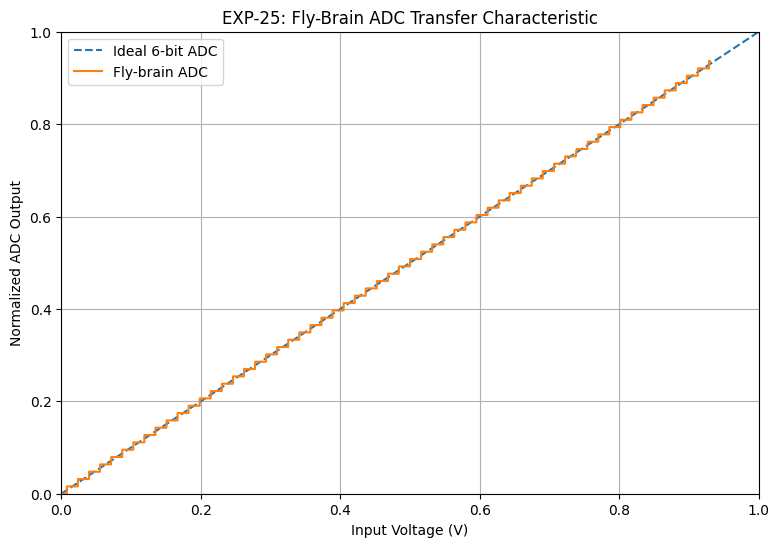

In [135]:
# ============================================================
# EXP-25: Cell 4
# Transfer curve + ideal 6-bit ADC
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# Dense ideal reference
ideal_input = np.linspace(0, 1, 1001)
ideal_output = ideal_input

# Plot
plt.figure(figsize=(9, 6))

plt.plot(
    ideal_input,
    ideal_output,
    linestyle='--',
    label='Ideal 6-bit ADC'
)

plt.plot(
    voltage_dense,
    code_dense / 63.0,
    label='Fly-brain ADC'
)

plt.xlabel('Input Voltage (V)')
plt.ylabel('Normalized ADC Output')
plt.title('EXP-25: Fly-Brain ADC Transfer Characteristic')
plt.grid(True)
plt.legend()

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.show()

EXP-25: ACTUAL INPUT-DOMAIN TRANSFER
Input range            : 0.000000 → 1.000000 V
Decoded output range   : 0.000000 → 0.930000 V
Code range             : 0 → 59
Unique codes           : 60/64
Analog monotonic       : True
6-bit monotonic        : True


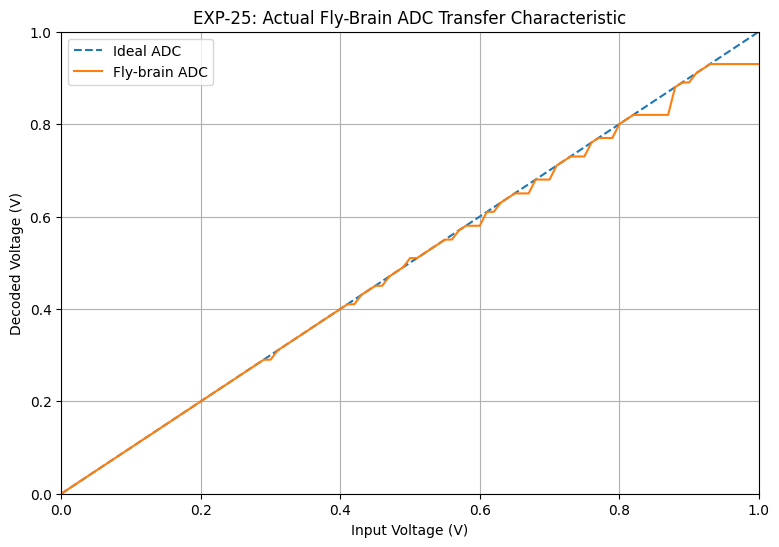

In [136]:
# ============================================================
# EXP-25: Cell 5
# ACTUAL input-voltage transfer characteristic
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Map the actual EXP-24 training inputs through the
# existing temporal-score -> voltage decoder
# ------------------------------------------------------------

# Sort by actual input voltage
order_v = np.argsort(train_v)

vin_train = train_v[order_v]
score_train = temporal_score[order_v]

# Decode the biological response using the EXP-24 mapping
vout_train = np.interp(
    score_train,
    unique_score,
    unique_voltage
)

vout_train = np.clip(vout_train, 0, 1)

# 6-bit output
code_train = np.round(
    vout_train * 63
).astype(int)

code_train = np.clip(code_train, 0, 63)

# ------------------------------------------------------------
# Dense interpolation in ACTUAL INPUT VOLTAGE domain
# ------------------------------------------------------------

vin_dense = np.linspace(0, 1, 10001)

score_from_vin = np.interp(
    vin_dense,
    vin_train,
    score_train
)

vout_from_vin = np.interp(
    score_from_vin,
    unique_score,
    unique_voltage
)

vout_from_vin = np.clip(
    vout_from_vin,
    0,
    1
)

code_from_vin = np.round(
    vout_from_vin * 63
).astype(int)

code_from_vin = np.clip(
    code_from_vin,
    0,
    63
)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

transfer_monotonic = np.all(
    np.diff(vout_from_vin) >= -1e-12
)

code_monotonic = np.all(
    np.diff(code_from_vin) >= 0
)

unique_codes_actual = np.unique(code_from_vin)

print("=" * 70)
print("EXP-25: ACTUAL INPUT-DOMAIN TRANSFER")
print("=" * 70)

print(f"Input range            : "
      f"{vin_dense.min():.6f} → {vin_dense.max():.6f} V")

print(f"Decoded output range   : "
      f"{vout_from_vin.min():.6f} → {vout_from_vin.max():.6f} V")

print(f"Code range             : "
      f"{code_from_vin.min()} → {code_from_vin.max()}")

print(f"Unique codes           : "
      f"{len(unique_codes_actual)}/64")

print(f"Analog monotonic       : {transfer_monotonic}")
print(f"6-bit monotonic        : {code_monotonic}")

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.plot(
    vin_dense,
    vin_dense,
    linestyle='--',
    label='Ideal ADC'
)

plt.plot(
    vin_dense,
    vout_from_vin,
    label='Fly-brain ADC'
)

plt.xlabel('Input Voltage (V)')
plt.ylabel('Decoded Voltage (V)')
plt.title('EXP-25: Actual Fly-Brain ADC Transfer Characteristic')

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.grid(True)
plt.legend()

plt.show()

In [137]:
# ============================================================
# EXP-25: Cell 6
# FINAL INPUT-DOMAIN DNL / INL
# ============================================================

import numpy as np

print("=" * 70)
print("EXP-25: FINAL INPUT-DOMAIN DNL / INL")
print("=" * 70)

# ------------------------------------------------------------
# Find actual Vin transition points
# ------------------------------------------------------------

transition_v = np.full(63, np.nan)

for code in range(63):

    idx = np.where(
        (code_from_vin[:-1] == code) &
        (code_from_vin[1:] > code)
    )[0]

    if len(idx) > 0:
        i = idx[0]

        # Approximate transition by midpoint of dense samples
        transition_v[code] = (
            vin_dense[i] +
            vin_dense[i + 1]
        ) / 2.0

# ------------------------------------------------------------
# Build code boundaries
#
# Input range is genuinely 0 → 1 V
# ------------------------------------------------------------

edges = np.full(65, np.nan)

edges[0] = 0.0
edges[64] = 1.0

for code in range(63):

    if not np.isnan(transition_v[code]):
        edges[code + 1] = transition_v[code]

# ------------------------------------------------------------
# Determine which codes actually exist
# ------------------------------------------------------------

reachable = np.unique(code_from_vin)

missing = np.setdiff1d(
    np.arange(64),
    reachable
)

print(f"Reachable codes : {len(reachable)}/64")
print(f"Missing codes   : {missing.tolist()}")

# ------------------------------------------------------------
# Code widths
# ------------------------------------------------------------

code_widths = np.diff(edges)

# ------------------------------------------------------------
# Ideal 6-bit LSB
# ------------------------------------------------------------

ideal_lsb = 1.0 / 64.0

print(f"\nIdeal 6-bit LSB : {ideal_lsb:.6f} V")

# ------------------------------------------------------------
# DNL
# ------------------------------------------------------------

dnl = (
    code_widths / ideal_lsb
) - 1.0

# ------------------------------------------------------------
# INL
#
# Transition-based INL relative to ideal transition locations
# ------------------------------------------------------------

ideal_edges = (
    (np.arange(65) + 0.0) * ideal_lsb
)

inl = (
    edges - ideal_edges
) / ideal_lsb

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\nDNL")
print("-" * 40)
print(f"Minimum DNL       : {np.nanmin(dnl):.4f} LSB")
print(f"Maximum DNL       : {np.nanmax(dnl):.4f} LSB")
print(f"Peak-to-peak DNL  : "
      f"{np.nanmax(dnl) - np.nanmin(dnl):.4f} LSB")

print("\nINL")
print("-" * 40)
print(f"Minimum INL       : {np.nanmin(inl):.4f} LSB")
print(f"Maximum INL       : {np.nanmax(inl):.4f} LSB")
print(f"Peak-to-peak INL  : "
      f"{np.nanmax(inl) - np.nanmin(inl):.4f} LSB")

# ------------------------------------------------------------
# Selected codes
# ------------------------------------------------------------

print("\nSelected code widths:")
print(
    f"{'Code':>6} "
    f"{'Width(V)':>12} "
    f"{'DNL(LSB)':>12}"
)

for code in [0, 1, 7, 15, 31, 47, 55, 58, 59]:

    if code < len(code_widths):

        print(
            f"{code:6d} "
            f"{code_widths[code]:12.6f} "
            f"{dnl[code]:12.4f}"
        )

print("\nSelected INL:")
print(
    f"{'Code':>6} "
    f"{'INL(LSB)':>12}"
)

for code in [0, 1, 7, 15, 31, 47, 55, 58, 59]:

    if code < len(inl):

        print(
            f"{code:6d} "
            f"{inl[code]:12.4f}"
        )

EXP-25: FINAL INPUT-DOMAIN DNL / INL
Reachable codes : 60/64
Missing codes   : [60, 61, 62, 63]

Ideal 6-bit LSB : 0.015625 V

DNL
----------------------------------------
Minimum DNL       : -0.8336 LSB
Maximum DNL       : 2.5072 LSB
Peak-to-peak DNL  : 3.3408 LSB

INL
----------------------------------------
Minimum INL       : -0.4912 LSB
Maximum INL       : 2.8240 LSB
Peak-to-peak INL  : 3.3152 LSB

Selected code widths:
  Code     Width(V)     DNL(LSB)
     0     0.007950      -0.4912
     1     0.015900       0.0176
     7     0.015900       0.0176
    15     0.015900       0.0176
    31     0.010800      -0.3088
    47     0.005300      -0.6608
    55     0.003400      -0.7824
    58     0.015900       0.0176
    59          nan          nan

Selected INL:
  Code     INL(LSB)
     0       0.0000
     1      -0.4912
     7      -0.3984
    15      -0.2704
    31      -0.0144
    47       1.1696
    55       1.1632
    58       0.4096
    59       0.4272


In [138]:
# ============================================================
# EXP-25: Cell 6B
# Corrected input-domain DNL / INL
# ============================================================

import numpy as np

print("=" * 70)
print("EXP-25: CORRECTED INPUT-DOMAIN DNL / INL")
print("=" * 70)

# ------------------------------------------------------------
# Find code transition voltages
# ------------------------------------------------------------

transition_v = np.full(63, np.nan)

for code in range(63):

    idx = np.where(
        (code_from_vin[:-1] == code) &
        (code_from_vin[1:] > code)
    )[0]

    if len(idx) > 0:
        i = idx[0]

        transition_v[code] = (
            vin_dense[i] +
            vin_dense[i + 1]
        ) / 2.0

# ------------------------------------------------------------
# Determine reachable codes
# ------------------------------------------------------------

reachable = np.unique(code_from_vin)
missing = np.setdiff1d(np.arange(64), reachable)

print(f"Reachable codes : {len(reachable)}/64")
print(f"Missing codes   : {missing.tolist()}")

# ------------------------------------------------------------
# Build boundaries for reachable codes
# ------------------------------------------------------------

first_code = int(reachable.min())
last_code = int(reachable.max())

# Boundaries are actual input-voltage transition points
boundaries = [0.0]

for code in range(first_code, last_code):

    if np.isnan(transition_v[code]):
        raise RuntimeError(
            f"Missing transition between code {code} and {code+1}"
        )

    boundaries.append(transition_v[code])

# Final reachable code extends to full input range
boundaries.append(1.0)

boundaries = np.asarray(boundaries)

# ------------------------------------------------------------
# Code widths
# ------------------------------------------------------------

code_widths = np.diff(boundaries)

# ------------------------------------------------------------
# Ideal 6-bit LSB
# ------------------------------------------------------------

ideal_lsb = 1.0 / 64.0

# ------------------------------------------------------------
# DNL
# ------------------------------------------------------------

dnl = (
    code_widths / ideal_lsb
) - 1.0

# ------------------------------------------------------------
# INL
#
# Compare actual transition boundaries against ideal
# transition positions.
# ------------------------------------------------------------

ideal_boundaries = (
    np.arange(len(boundaries))
    * ideal_lsb
)

inl = (
    boundaries - ideal_boundaries
) / ideal_lsb

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print(f"\nIdeal LSB : {ideal_lsb:.6f} V")

print("\nDNL")
print("-" * 40)
print(f"Minimum DNL      : {dnl.min():.4f} LSB")
print(f"Maximum DNL      : {dnl.max():.4f} LSB")
print(f"Peak-to-peak DNL : "
      f"{dnl.max() - dnl.min():.4f} LSB")

print("\nINL")
print("-" * 40)
print(f"Minimum INL      : {inl.min():.4f} LSB")
print(f"Maximum INL      : {inl.max():.4f} LSB")
print(f"Peak-to-peak INL : "
      f"{inl.max() - inl.min():.4f} LSB")

# ------------------------------------------------------------
# Selected codes
# ------------------------------------------------------------

print("\nSelected code characteristics:")
print(
    f"{'Code':>6} "
    f"{'Width(V)':>12} "
    f"{'DNL(LSB)':>12}"
)

for j, code in enumerate(
    range(first_code, last_code + 1)
):

    if code in [0, 1, 7, 15, 31, 47, 55, 58, 59]:

        print(
            f"{code:6d} "
            f"{code_widths[j]:12.6f} "
            f"{dnl[j]:12.4f}"
        )

print("\nSelected INL:")
print(
    f"{'Code':>6} "
    f"{'INL(LSB)':>12}"
)

for j, code in enumerate(
    range(first_code, last_code + 1)
):

    if code in [0, 1, 7, 15, 31, 47, 55, 58, 59]:

        print(
            f"{code:6d} "
            f"{inl[j]:12.4f}"
        )

EXP-25: CORRECTED INPUT-DOMAIN DNL / INL
Reachable codes : 60/64
Missing codes   : [60, 61, 62, 63]

Ideal LSB : 0.015625 V

DNL
----------------------------------------
Minimum DNL      : -0.8336 LSB
Maximum DNL      : 3.5728 LSB
Peak-to-peak DNL : 4.4064 LSB

INL
----------------------------------------
Minimum INL      : -0.4912 LSB
Maximum INL      : 4.0000 LSB
Peak-to-peak INL : 4.4912 LSB

Selected code characteristics:
  Code     Width(V)     DNL(LSB)
     0     0.007950      -0.4912
     1     0.015900       0.0176
     7     0.015900       0.0176
    15     0.015900       0.0176
    31     0.010800      -0.3088
    47     0.005300      -0.6608
    55     0.003400      -0.7824
    58     0.015900       0.0176
    59     0.071450       3.5728

Selected INL:
  Code     INL(LSB)
     0       0.0000
     1      -0.4912
     7      -0.3984
    15      -0.2704
    31      -0.0144
    47       1.1696
    55       1.1632
    58       0.4096
    59       0.4272


EXP-26: FULL-SCALE CALIBRATION
Original Fly output range : 0.000000 → 0.930000 V

CALIBRATED RESULT
-------------------------------------------------------
Calibrated range       : 0.000000 → 1.000000 V
Code range             : 0 → 63
Unique codes           : 64/64
Analog monotonic       : True
6-bit monotonic        : True

MAE                    : 0.031367 V
RMSE                   : 0.036219 V
Maximum error          : 0.077300 V

Endpoint check:
Vin = 0.00 V → code 0
Vin = 1.00 V → code 63


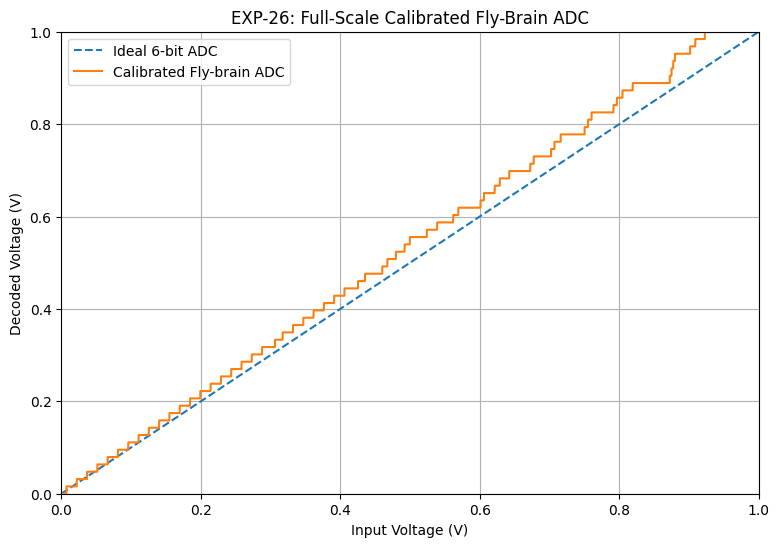

In [139]:
# ============================================================
# EXP-26: FULL-SCALE CALIBRATION
# Cell 1 — Rescale Fly ADC to use 0–63
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("EXP-26: FULL-SCALE CALIBRATION")
print("=" * 70)

# ------------------------------------------------------------
# Existing actual input-domain Fly ADC response
# ------------------------------------------------------------

# vout_from_vin already contains:
# actual Vin → Fly temporal response → decoded voltage

fly_min = vout_from_vin.min()
fly_max = vout_from_vin.max()

print(f"Original Fly output range : "
      f"{fly_min:.6f} → {fly_max:.6f} V")

# ------------------------------------------------------------
# Full-scale calibration
#
# Map the observed Fly range onto 0–1 V.
# ------------------------------------------------------------

calibrated_vout = (
    (vout_from_vin - fly_min) /
    (fly_max - fly_min)
)

calibrated_vout = np.clip(
    calibrated_vout,
    0,
    1
)

# ------------------------------------------------------------
# 6-bit quantization
# ------------------------------------------------------------

calibrated_codes = np.round(
    calibrated_vout * 63
).astype(int)

calibrated_codes = np.clip(
    calibrated_codes,
    0,
    63
)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

calibrated_monotonic = np.all(
    np.diff(calibrated_vout) >= -1e-12
)

code_monotonic = np.all(
    np.diff(calibrated_codes) >= 0
)

unique_calibrated = np.unique(
    calibrated_codes
)

# Reconstruction
calibrated_decoded = calibrated_codes / 63.0

calibration_error = (
    calibrated_decoded - vin_dense
)

mae = np.mean(
    np.abs(calibration_error)
)

rmse = np.sqrt(
    np.mean(calibration_error ** 2)
)

max_error = np.max(
    np.abs(calibration_error)
)

print("\nCALIBRATED RESULT")
print("-" * 55)

print(f"Calibrated range       : "
      f"{calibrated_vout.min():.6f} → "
      f"{calibrated_vout.max():.6f} V")

print(f"Code range             : "
      f"{calibrated_codes.min()} → "
      f"{calibrated_codes.max()}")

print(f"Unique codes           : "
      f"{len(unique_calibrated)}/64")

print(f"Analog monotonic       : "
      f"{calibrated_monotonic}")

print(f"6-bit monotonic        : "
      f"{code_monotonic}")

print(f"\nMAE                    : "
      f"{mae:.6f} V")

print(f"RMSE                   : "
      f"{rmse:.6f} V")

print(f"Maximum error          : "
      f"{max_error:.6f} V")

print("\nEndpoint check:")
print(f"Vin = 0.00 V → "
      f"code {calibrated_codes[0]}")

print(f"Vin = 1.00 V → "
      f"code {calibrated_codes[-1]}")

# ------------------------------------------------------------
# Plot calibrated response
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.plot(
    vin_dense,
    vin_dense,
    linestyle='--',
    label='Ideal 6-bit ADC'
)

plt.plot(
    vin_dense,
    calibrated_decoded,
    label='Calibrated Fly-brain ADC'
)

plt.xlabel("Input Voltage (V)")
plt.ylabel("Decoded Voltage (V)")
plt.title("EXP-26: Full-Scale Calibrated Fly-Brain ADC")

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.grid(True)
plt.legend()

plt.show()

In [140]:
# ============================================================
# EXP-27: MONOTONIC 64-CODE CALIBRATION LUT
# Cell 1 — Build calibration from TRAINING data only
# ============================================================

import numpy as np

print("=" * 70)
print("EXP-27: MONOTONIC 64-CODE CALIBRATION LUT")
print("=" * 70)

# ------------------------------------------------------------
# 1. Sort training data by actual input voltage
# ------------------------------------------------------------

order = np.argsort(train_v)

train_v_sorted = train_v[order]
train_score_sorted = temporal_score[order]

# ------------------------------------------------------------
# 2. Enforce monotonicity of the biological score
#
# The calibration must never assign a lower score to a
# higher input voltage.
# ------------------------------------------------------------

train_score_mono = np.maximum.accumulate(
    train_score_sorted
)

# ------------------------------------------------------------
# 3. Ideal 6-bit code transition locations
#
# Code k changes to k+1 at:
#
#     Vin = (k + 0.5) / 64
#
# ------------------------------------------------------------

ideal_threshold_v = (
    np.arange(63) + 0.5
) / 64.0

# ------------------------------------------------------------
# 4. Convert those ideal voltage thresholds into
#    Fly temporal-score thresholds.
# ------------------------------------------------------------

score_thresholds = np.interp(
    ideal_threshold_v,
    train_v_sorted,
    train_score_mono
)

# ------------------------------------------------------------
# 5. Inspect the calibration LUT
# ------------------------------------------------------------

print("\nCalibration LUT constructed from TRAINING data only.")

print(f"Number of code thresholds : {len(score_thresholds)}")

print(
    f"Score threshold range     : "
    f"{score_thresholds.min():.6f} → "
    f"{score_thresholds.max():.6f}"
)

print("\nSelected thresholds:")
print(
    f"{'Transition':>12} "
    f"{'Ideal Vin':>12} "
    f"{'Fly score':>12}"
)

for k in [0, 1, 7, 15, 31, 47, 55, 59, 61]:

    print(
        f"{k} → {k+1:2d} "
        f"{ideal_threshold_v[k]:12.6f} "
        f"{score_thresholds[k]:12.6f}"
    )

# ------------------------------------------------------------
# 6. Check threshold monotonicity
# ------------------------------------------------------------

threshold_monotonic = np.all(
    np.diff(score_thresholds) >= -1e-12
)

print(
    f"\nThreshold monotonicity : "
    f"{threshold_monotonic}"
)

print("\nReady for independent validation.")

EXP-27: MONOTONIC 64-CODE CALIBRATION LUT

Calibration LUT constructed from TRAINING data only.
Number of code thresholds : 63
Score threshold range     : 0.054013 → 1.000000

Selected thresholds:
  Transition    Ideal Vin    Fly score
0 →  1     0.007812     0.054013
1 →  2     0.023438     0.131411
7 →  8     0.117188     0.370414
15 → 16     0.242188     0.526391
31 → 32     0.492188     0.722450
47 → 48     0.742188     0.874945
55 → 56     0.867188     0.934895
59 → 60     0.929688     0.999870
61 → 62     0.960938     1.000000

Threshold monotonicity : True

Ready for independent validation.


In [141]:
# ============================================================
# EXP-27: Cell 2
# Independent validation of 64-code LUT
# ============================================================

import numpy as np

print("=" * 70)
print("EXP-27: INDEPENDENT LUT VALIDATION")
print("=" * 70)

# ------------------------------------------------------------
# Convert validation temporal scores into 6-bit codes
# ------------------------------------------------------------

lut_codes = np.searchsorted(
    score_thresholds,
    val_score,
    side="right"
)

lut_codes = np.clip(
    lut_codes,
    0,
    63
)

# ------------------------------------------------------------
# Decode codes back to voltage
# ------------------------------------------------------------

lut_decoded = lut_codes / 63.0

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

error = lut_decoded - val_v

mae = np.mean(np.abs(error))
rmse = np.sqrt(np.mean(error ** 2))
max_error = np.max(np.abs(error))

code_monotonic = np.all(
    np.diff(lut_codes) >= 0
)

unique_codes = np.unique(lut_codes)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\nValidation results")
print("-" * 55)

print(f"MAE              : {mae:.6f} V")
print(f"RMSE             : {rmse:.6f} V")
print(f"Maximum error    : {max_error:.6f} V")

print(f"\nCode range       : "
      f"{lut_codes.min()} → {lut_codes.max()}")

print(f"Unique codes     : "
      f"{len(unique_codes)}/64")

print(f"6-bit monotonic  : "
      f"{code_monotonic}")

missing_codes = np.setdiff1d(
    np.arange(64),
    unique_codes
)

print(f"\nMissing codes    : "
      f"{missing_codes.tolist()}")

# ------------------------------------------------------------
# Code usage histogram
# ------------------------------------------------------------

counts = np.bincount(
    lut_codes,
    minlength=64
)

print("\nCode usage:")
print(
    f"{'Code':>6} {'Samples':>10}"
)

for code in range(64):
    if counts[code] > 0:
        print(
            f"{code:6d} {counts[code]:10d}"
        )

# ------------------------------------------------------------
# Compare against EXP-24
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("COMPARISON")
print("=" * 55)

print("EXP-24 direct monotonic temporal decoder:")
print("  MAE = 0.009630 V")
print("  Validation codes = 51/64")

print("\nEXP-27 monotonic LUT:")
print(f"  MAE = {mae:.6f} V")
print(f"  Validation codes = {len(unique_codes)}/64")

EXP-27: INDEPENDENT LUT VALIDATION

Validation results
-------------------------------------------------------
MAE              : 0.015637 V
RMSE             : 0.022588 V
Maximum error    : 0.074798 V

Code range       : 0 → 63
Unique codes     : 48/64
6-bit monotonic  : True

Missing codes    : [21, 32, 35, 39, 42, 44, 47, 50, 52, 53, 54, 55, 57, 60, 61, 62]

Code usage:
  Code    Samples
     0          2
     1          1
     2          3
     3          3
     4          4
     5          1
     6          4
     7          4
     8          3
     9          1
    10          5
    11          6
    12          4
    13          6
    14          3
    15          5
    16          3
    17          2
    18          4
    19          6
    20          3
    22          3
    23          1
    24          2
    25          1
    26          1
    27          3
    28          2
    29          2
    30          6
    31          4
    33          4
    34          2
    36       

In [142]:
# ============================================================
# EXP-28: RICH TEMPORAL FEATURE EXTRACTION
# ============================================================

def extract_features_exp28(voltage_array):

    counts_l1 = []
    counts_mi1 = []

    latency_l1 = []
    latency_mi1 = []

    isi_l1 = []
    isi_mi1 = []

    for v_in in voltage_array:

        g_on = voltage_to_drive(v_in)

        smon, _, _, _ = run_simulation_v1(
            ['L1', 'Mi1'],
            neuron_id_core,
            W_core_4bit,
            thr_core,
            N_core,
            g_drive_on=g_on,
            g_drive_off=0.15,
            w_scale=0.06
        )

        for ntype, counts, latencies, isis in [
            ('L1', counts_l1, latency_l1, isi_l1),
            ('Mi1', counts_mi1, latency_mi1, isi_mi1)
        ]:

            idx = neuron_id_core[ntype]

            spike_times = np.asarray(
                smon.t[smon.i == idx] / ms
            )

            # Spike count
            counts.append(len(spike_times))

            # First-spike latency
            if len(spike_times) > 0:
                latencies.append(float(spike_times[0]))
            else:
                latencies.append(500.0)

            # Mean inter-spike interval
            if len(spike_times) >= 2:
                isis.append(float(np.mean(np.diff(spike_times))))
            else:
                isis.append(500.0)

    return np.column_stack([
        counts_l1,
        counts_mi1,
        latency_l1,
        latency_mi1,
        isi_l1,
        isi_mi1
    ])


print("EXP-28 feature extractor ready.")
print("Features:")
print("1. L1 spike count")
print("2. Mi1 spike count")
print("3. L1 first-spike latency")
print("4. Mi1 first-spike latency")
print("5. L1 mean ISI")
print("6. Mi1 mean ISI")

EXP-28 feature extractor ready.
Features:
1. L1 spike count
2. Mi1 spike count
3. L1 first-spike latency
4. Mi1 first-spike latency
5. L1 mean ISI
6. Mi1 mean ISI


In [143]:
# ============================================================
# EXP-28: TRAINED 6-FEATURE TEMPORAL DECODER
# ============================================================

from sklearn.linear_model import LinearRegression

# ------------------------------------------------------------
# Training set
# ------------------------------------------------------------

train_v = np.linspace(0, 1, 101)

print("Extracting EXP-28 training features...")

X28_train = extract_features_exp28(train_v)

print("Training feature matrix shape:", X28_train.shape)

# ------------------------------------------------------------
# Normalize using TRAINING statistics only
# ------------------------------------------------------------

X28_min = X28_train.min(axis=0)
X28_max = X28_train.max(axis=0)

X28_train_n = (
    (X28_train - X28_min) /
    (X28_max - X28_min + 1e-12)
)

# ------------------------------------------------------------
# Train decoder
# ------------------------------------------------------------

decoder28 = LinearRegression()
decoder28.fit(X28_train_n, train_v)

print("\nEXP-28 learned coefficients:")

feature_names = [
    "L1 count",
    "Mi1 count",
    "L1 latency",
    "Mi1 latency",
    "L1 mean ISI",
    "Mi1 mean ISI"
]

for name, coef in zip(feature_names, decoder28.coef_):
    print(f"  {name:<16}: {coef: .6f}")

print(f"  {'Intercept':<16}: {decoder28.intercept_: .6f}")

# ------------------------------------------------------------
# Independent validation set
# ------------------------------------------------------------

np.random.seed(2026)

val_v28 = np.sort(
    np.random.uniform(0, 1, 200)
)

print("\nExtracting EXP-28 independent validation features...")

X28_val = extract_features_exp28(val_v28)

# IMPORTANT:
# Use training normalization only
X28_val_n = (
    (X28_val - X28_min) /
    (X28_max - X28_min + 1e-12)
)

# ------------------------------------------------------------
# Prediction
# ------------------------------------------------------------

pred28 = decoder28.predict(X28_val_n)
pred28 = np.clip(pred28, 0, 1)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

error28 = pred28 - val_v28

mae28 = np.mean(np.abs(error28))
rmse28 = np.sqrt(np.mean(error28 ** 2))
max28 = np.max(np.abs(error28))

codes28 = np.round(pred28 * 63).astype(int)

monotonic28 = np.all(
    np.diff(pred28[np.argsort(val_v28)]) >= -1e-10
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXP-28: INDEPENDENT VALIDATION")
print("=" * 70)

print(f"MAE          : {mae28:.6f} V")
print(f"RMSE         : {rmse28:.6f} V")
print(f"Max error    : {max28:.6f} V")
print(f"Unique codes : {len(np.unique(codes28))}/64")
print(f"Code range   : {codes28.min()}–{codes28.max()}")
print(f"Monotonic    : {monotonic28}")

# ------------------------------------------------------------
# Compare with EXP-24
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXP-28 vs EXP-24")
print("=" * 70)

print("EXP-24 reference:")
print("  MAE          : 0.009630 V")
print("  RMSE         : 0.015353 V")
print("  Unique codes : 51/64")
print("  Monotonic    : True")

print("\nEXP-28:")
print(f"  MAE          : {mae28:.6f} V")
print(f"  RMSE         : {rmse28:.6f} V")
print(f"  Unique codes : {len(np.unique(codes28))}/64")
print(f"  Monotonic    : {monotonic28}")

Extracting EXP-28 training features...
Training feature matrix shape: (101, 6)

EXP-28 learned coefficients:
  L1 count        :  0.500483
  Mi1 count       :  0.539592
  L1 latency      : -0.835401
  Mi1 latency     : -0.180967
  L1 mean ISI     :  0.397336
  Mi1 mean ISI    :  0.718138
  Intercept       : -0.083672

Extracting EXP-28 independent validation features...

EXP-28: INDEPENDENT VALIDATION
MAE          : 0.009033 V
RMSE         : 0.012122 V
Max error    : 0.040629 V
Unique codes : 51/64
Code range   : 0–60
Monotonic    : False

EXP-28 vs EXP-24
EXP-24 reference:
  MAE          : 0.009630 V
  RMSE         : 0.015353 V
  Unique codes : 51/64
  Monotonic    : True

EXP-28:
  MAE          : 0.009033 V
  RMSE         : 0.012122 V
  Unique codes : 51/64
  Monotonic    : False


In [144]:
# ============================================================
# EXP-28: MONOTONIC CONSTRAINED TEMPORAL DECODER
# ============================================================

from sklearn.linear_model import LinearRegression

# ------------------------------------------------------------
# Transform features so ALL should increase with voltage
# ------------------------------------------------------------

# Counts increase with voltage
# Latency decreases with voltage -> invert
# Mean ISI decreases with voltage -> invert

X28_train_m = np.column_stack([
    X28_train[:, 0],              # L1 count
    X28_train[:, 1],              # Mi1 count
    -X28_train[:, 2],             # -L1 latency
    -X28_train[:, 3],             # -Mi1 latency
    -X28_train[:, 4],             # -L1 mean ISI
    -X28_train[:, 5]              # -Mi1 mean ISI
])

X28_val_m = np.column_stack([
    X28_val[:, 0],
    X28_val[:, 1],
    -X28_val[:, 2],
    -X28_val[:, 3],
    -X28_val[:, 4],
    -X28_val[:, 5]
])

# ------------------------------------------------------------
# Normalize using TRAINING statistics
# ------------------------------------------------------------

X28m_min = X28_train_m.min(axis=0)
X28m_max = X28_train_m.max(axis=0)

X28_train_mn = (
    (X28_train_m - X28m_min) /
    (X28m_max - X28m_min + 1e-12)
)

X28_val_mn = (
    (X28_val_m - X28m_min) /
    (X28m_max - X28m_min + 1e-12)
)

# ------------------------------------------------------------
# Positive linear regression
# Every coefficient is constrained >= 0
# ------------------------------------------------------------

decoder28_mono = LinearRegression(positive=True)
decoder28_mono.fit(X28_train_mn, train_v)

pred28_mono = decoder28_mono.predict(X28_val_mn)
pred28_mono = np.clip(pred28_mono, 0, 1)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

error = pred28_mono - val_v28

mae = np.mean(np.abs(error))
rmse = np.sqrt(np.mean(error ** 2))
max_error = np.max(np.abs(error))

codes = np.round(pred28_mono * 63).astype(int)

monotonic = np.all(
    np.diff(pred28_mono[np.argsort(val_v28)]) >= -1e-10
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXP-28: MONOTONIC CONSTRAINED DECODER")
print("=" * 70)

print("\nLearned coefficients:")

names = [
    "L1 count",
    "Mi1 count",
    "-L1 latency",
    "-Mi1 latency",
    "-L1 mean ISI",
    "-Mi1 mean ISI"
]

for name, coef in zip(names, decoder28_mono.coef_):
    print(f"  {name:<18}: {coef:.6f}")

print(f"  {'Intercept':<18}: {decoder28_mono.intercept_:.6f}")

print("\nValidation:")
print(f"MAE          : {mae:.6f} V")
print(f"RMSE         : {rmse:.6f} V")
print(f"Max error    : {max_error:.6f} V")
print(f"Unique codes : {len(np.unique(codes))}/64")
print(f"Code range   : {codes.min()}–{codes.max()}")
print(f"Monotonic    : {monotonic}")

print("\nReference EXP-24:")
print("MAE          : 0.009630 V")
print("RMSE         : 0.015353 V")
print("Unique codes : 51/64")
print("Monotonic    : True")


EXP-28: MONOTONIC CONSTRAINED DECODER

Learned coefficients:
  L1 count          : 0.447189
  Mi1 count         : 0.543171
  -L1 latency       : 0.000000
  -Mi1 latency      : 0.000000
  -L1 mean ISI      : 0.000000
  -Mi1 mean ISI     : 0.000000
  Intercept         : -0.044981

Validation:
MAE          : 0.012140 V
RMSE         : 0.015928 V
Max error    : 0.052019 V
Unique codes : 41/64
Code range   : 0–60
Monotonic    : False

Reference EXP-24:
MAE          : 0.009630 V
RMSE         : 0.015353 V
Unique codes : 51/64
Monotonic    : True


In [145]:
# ============================================================
# EXP-28: MONOTONIC NONLINEAR TEMPORAL DECODER
# ============================================================

from sklearn.ensemble import HistGradientBoostingRegressor

# ------------------------------------------------------------
# Transform all features so increasing feature value means
# increasing input voltage
# ------------------------------------------------------------

X28_train_m = np.column_stack([
    X28_train[:, 0],      # L1 count       ↑
    X28_train[:, 1],      # Mi1 count      ↑
    -X28_train[:, 2],     # -L1 latency    ↑
    -X28_train[:, 3],     # -Mi1 latency   ↑
    -X28_train[:, 4],     # -L1 mean ISI   ↑
    -X28_train[:, 5]      # -Mi1 mean ISI  ↑
])

X28_val_m = np.column_stack([
    X28_val[:, 0],
    X28_val[:, 1],
    -X28_val[:, 2],
    -X28_val[:, 3],
    -X28_val[:, 4],
    -X28_val[:, 5]
])

# ------------------------------------------------------------
# Monotonic constraints
# Every feature is constrained to have a positive relationship
# with the decoded voltage.
# ------------------------------------------------------------

monotonic_constraints = [1, 1, 1, 1, 1, 1]

decoder28_nl = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.05,
    max_leaf_nodes=8,
    min_samples_leaf=8,
    l2_regularization=0.01,
    monotonic_cst=monotonic_constraints,
    random_state=2026
)

decoder28_nl.fit(
    X28_train_m,
    train_v
)

# ------------------------------------------------------------
# Validation prediction
# ------------------------------------------------------------

pred28_nl = decoder28_nl.predict(X28_val_m)
pred28_nl = np.clip(pred28_nl, 0, 1)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

error_nl = pred28_nl - val_v28

mae_nl = np.mean(np.abs(error_nl))
rmse_nl = np.sqrt(np.mean(error_nl ** 2))
max_nl = np.max(np.abs(error_nl))

codes_nl = np.round(pred28_nl * 63).astype(int)

monotonic_nl = np.all(
    np.diff(pred28_nl[np.argsort(val_v28)]) >= -1e-10
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXP-28: MONOTONIC NONLINEAR DECODER")
print("=" * 70)

print(f"MAE          : {mae_nl:.6f} V")
print(f"RMSE         : {rmse_nl:.6f} V")
print(f"Max error    : {max_nl:.6f} V")
print(f"Unique codes : {len(np.unique(codes_nl))}/64")
print(f"Code range   : {codes_nl.min()}–{codes_nl.max()}")
print(f"Monotonic    : {monotonic_nl}")

# ------------------------------------------------------------
# Comparison
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DECODER COMPARISON")
print("=" * 70)

print("\nEXP-24:")
print("  MAE          : 0.009630 V")
print("  RMSE         : 0.015353 V")
print("  Unique codes : 51/64")
print("  Monotonic    : True")

print("\nEXP-28 unconstrained linear:")
print("  MAE          : 0.009033 V")
print("  RMSE         : 0.012122 V")
print("  Unique codes : 51/64")
print("  Monotonic    : False")

print("\nEXP-28 monotonic nonlinear:")
print(f"  MAE          : {mae_nl:.6f} V")
print(f"  RMSE         : {rmse_nl:.6f} V")
print(f"  Unique codes : {len(np.unique(codes_nl))}/64")
print(f"  Monotonic    : {monotonic_nl}")


EXP-28: MONOTONIC NONLINEAR DECODER
MAE          : 0.007585 V
RMSE         : 0.011224 V
Max error    : 0.036589 V
Unique codes : 49/64
Code range   : 2–61
Monotonic    : False

DECODER COMPARISON

EXP-24:
  MAE          : 0.009630 V
  RMSE         : 0.015353 V
  Unique codes : 51/64
  Monotonic    : True

EXP-28 unconstrained linear:
  MAE          : 0.009033 V
  RMSE         : 0.012122 V
  Unique codes : 51/64
  Monotonic    : False

EXP-28 monotonic nonlinear:
  MAE          : 0.007585 V
  RMSE         : 0.011224 V
  Unique codes : 49/64
  Monotonic    : False


In [146]:
# ============================================================
# EXP-28: TRAIN-ONLY MONOTONIC CALIBRATION
# ============================================================

from sklearn.isotonic import IsotonicRegression

# ------------------------------------------------------------
# 1. Get nonlinear decoder predictions on TRAINING data
# ------------------------------------------------------------

pred28_train_nl = decoder28_nl.predict(X28_train_m)
pred28_train_nl = np.clip(pred28_train_nl, 0, 1)

# ------------------------------------------------------------
# 2. Fit monotonic calibration ONLY on training data
# ------------------------------------------------------------

iso28 = IsotonicRegression(
    y_min=0,
    y_max=1,
    increasing=True,
    out_of_bounds="clip"
)

iso28.fit(
    pred28_train_nl,
    train_v
)

# ------------------------------------------------------------
# 3. Apply calibration to INDEPENDENT validation data
# ------------------------------------------------------------

pred28_iso = iso28.predict(pred28_nl)
pred28_iso = np.clip(pred28_iso, 0, 1)

# ------------------------------------------------------------
# 4. Metrics
# ------------------------------------------------------------

error_iso = pred28_iso - val_v28

mae_iso = np.mean(np.abs(error_iso))
rmse_iso = np.sqrt(np.mean(error_iso ** 2))
max_iso = np.max(np.abs(error_iso))

codes_iso = np.round(pred28_iso * 63).astype(int)

order_iso = np.argsort(val_v28)

monotonic_iso = np.all(
    np.diff(pred28_iso[order_iso]) >= -1e-10
)

# ------------------------------------------------------------
# 5. Results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXP-28: TRAIN-ONLY MONOTONIC CALIBRATION")
print("=" * 70)

print(f"MAE          : {mae_iso:.6f} V")
print(f"RMSE         : {rmse_iso:.6f} V")
print(f"Max error    : {max_iso:.6f} V")
print(f"Unique codes : {len(np.unique(codes_iso))}/64")
print(f"Code range   : {codes_iso.min()}–{codes_iso.max()}")
print(f"Monotonic    : {monotonic_iso}")

print("\n" + "=" * 70)
print("COMPARISON")
print("=" * 70)

print("\nEXP-24:")
print("  MAE          : 0.009630 V")
print("  RMSE         : 0.015353 V")
print("  Unique codes : 51/64")
print("  Monotonic    : True")

print("\nEXP-28 nonlinear:")
print("  MAE          : 0.007585 V")
print("  RMSE         : 0.011224 V")
print("  Unique codes : 49/64")
print("  Monotonic    : False")

print("\nEXP-28 nonlinear + monotonic calibration:")
print(f"  MAE          : {mae_iso:.6f} V")
print(f"  RMSE         : {rmse_iso:.6f} V")
print(f"  Unique codes : {len(np.unique(codes_iso))}/64")
print(f"  Code range   : {codes_iso.min()}–{codes_iso.max()}")
print(f"  Monotonic    : {monotonic_iso}")


EXP-28: TRAIN-ONLY MONOTONIC CALIBRATION
MAE          : 0.007404 V
RMSE         : 0.011174 V
Max error    : 0.039798 V
Unique codes : 48/64
Code range   : 2–61
Monotonic    : False

COMPARISON

EXP-24:
  MAE          : 0.009630 V
  RMSE         : 0.015353 V
  Unique codes : 51/64
  Monotonic    : True

EXP-28 nonlinear:
  MAE          : 0.007585 V
  RMSE         : 0.011224 V
  Unique codes : 49/64
  Monotonic    : False

EXP-28 nonlinear + monotonic calibration:
  MAE          : 0.007404 V
  RMSE         : 0.011174 V
  Unique codes : 48/64
  Code range   : 2–61
  Monotonic    : False


In [147]:
# ============================================================
# EXP-29A: FEATURE ABLATION
# Identify which EXP-28 features cause non-monotonicity
# ============================================================

from sklearn.ensemble import HistGradientBoostingRegressor
import numpy as np

feature_names = [
    "L1 spike count",
    "Mi1 spike count",
    "L1 first latency",
    "Mi1 first latency",
    "L1 mean ISI",
    "Mi1 mean ISI"
]

# Features with negative relationship to voltage
# are sign-inverted so all decoder inputs increase with voltage.
signs = np.array([1, 1, -1, -1, -1, -1])

X_train_signed = X28_train * signs
X_val_signed   = X28_val * signs

results_29 = []

# ------------------------------------------------------------
# Test:
#   1. All 6 features
#   2. Remove each feature individually
# ------------------------------------------------------------

feature_sets = {
    "All 6": list(range(6))
}

for removed in range(6):
    feature_sets[f"Without {feature_names[removed]}"] = [
        i for i in range(6) if i != removed
    ]

for name, indices in feature_sets.items():

    Xtr = X_train_signed[:, indices]
    Xva = X_val_signed[:, indices]

    decoder = HistGradientBoostingRegressor(
        max_iter=100,
        learning_rate=0.05,
        max_leaf_nodes=8,
        min_samples_leaf=8,
        l2_regularization=0.01,
        monotonic_cst=[1] * len(indices),
        random_state=2026
    )

    decoder.fit(Xtr, train_v)

    pred = decoder.predict(Xva)
    pred = np.clip(pred, 0, 1)

    error = pred - val_v28

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error ** 2))
    max_error = np.max(np.abs(error))

    codes = np.round(pred * 63).astype(int)

    order = np.argsort(val_v28)

    monotonic = np.all(
        np.diff(pred[order]) >= -1e-10
    )

    results_29.append([
        name,
        mae,
        rmse,
        max_error,
        len(np.unique(codes)),
        codes.min(),
        codes.max(),
        monotonic
    ])

# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("EXP-29A: FEATURE ABLATION")
print("=" * 100)

print(
    f"{'Configuration':<32}"
    f"{'MAE':>10}"
    f"{'RMSE':>10}"
    f"{'MAX':>10}"
    f"{'Codes':>10}"
    f"{'Range':>12}"
    f"{'Mono':>8}"
)

print("-" * 100)

for r in results_29:

    name, mae, rmse, max_error, unique, cmin, cmax, mono = r

    print(
        f"{name:<32}"
        f"{mae:>10.6f}"
        f"{rmse:>10.6f}"
        f"{max_error:>10.6f}"
        f"{unique:>7}/64"
        f"{cmin:>5}–{cmax:<5}"
        f"{str(mono):>8}"
    )

print("\n" + "=" * 100)
print("REFERENCE")
print("=" * 100)

print("EXP-24:")
print("  MAE          : 0.009630 V")
print("  RMSE         : 0.015353 V")
print("  Unique codes : 51/64")
print("  Monotonic    : True")

print("\nEXP-28:")
print("  MAE          : 0.007404 V")
print("  RMSE         : 0.011174 V")
print("  Unique codes : 48/64")
print("  Monotonic    : False")


EXP-29A: FEATURE ABLATION
Configuration                          MAE      RMSE       MAX     Codes       Range    Mono
----------------------------------------------------------------------------------------------------
All 6                             0.007585  0.011224  0.036589     49/64    2–61      False
Without L1 spike count            0.007635  0.011249  0.036589     48/64    2–61       True
Without Mi1 spike count           0.007786  0.011315  0.036589     49/64    2–61      False
Without L1 first latency          0.008798  0.012793  0.041382     46/64    2–60      False
Without Mi1 first latency         0.007629  0.011256  0.036540     48/64    2–61      False
Without L1 mean ISI               0.007850  0.011453  0.036631     48/64    2–61      False
Without Mi1 mean ISI              0.007585  0.011224  0.036589     49/64    2–61      False

REFERENCE
EXP-24:
  MAE          : 0.009630 V
  RMSE         : 0.015353 V
  Unique codes : 51/64
  Monotonic    : True

EXP-28:
  MAE 

In [148]:
# ============================================================
# EXP-29B: LOCATE NON-MONOTONIC REVERSALS
# ============================================================

# ------------------------------------------------------------
# Train the two models
# ------------------------------------------------------------

features_all = [0, 1, 2, 3, 4, 5]
features_no_l1 = [1, 2, 3, 4, 5]

decoder_all = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.05,
    max_leaf_nodes=8,
    min_samples_leaf=8,
    l2_regularization=0.01,
    monotonic_cst=[1] * 6,
    random_state=2026
)

decoder_no_l1 = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.05,
    max_leaf_nodes=8,
    min_samples_leaf=8,
    l2_regularization=0.01,
    monotonic_cst=[1] * 5,
    random_state=2026
)

decoder_all.fit(
    X_train_signed[:, features_all],
    train_v
)

decoder_no_l1.fit(
    X_train_signed[:, features_no_l1],
    train_v
)

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

pred_all = np.clip(
    decoder_all.predict(X_val_signed[:, features_all]),
    0, 1
)

pred_no_l1 = np.clip(
    decoder_no_l1.predict(X_val_signed[:, features_no_l1]),
    0, 1
)

# ------------------------------------------------------------
# Sort validation samples by actual voltage
# ------------------------------------------------------------

order = np.argsort(val_v28)

v_sorted = val_v28[order]
p_all_sorted = pred_all[order]
p_no_l1_sorted = pred_no_l1[order]

X_sorted = X28_val[order]

# ------------------------------------------------------------
# Find reversals in the ALL-6 model
# ------------------------------------------------------------

diff_all = np.diff(p_all_sorted)

reversal_indices = np.where(diff_all < -1e-10)[0]

print("\n" + "=" * 100)
print("EXP-29B: NON-MONOTONIC REVERSALS")
print("=" * 100)

print(f"\nTotal validation points : {len(v_sorted)}")
print(f"Number of reversals    : {len(reversal_indices)}")

print("\nEach row shows:")
print("Voltage A → Voltage B")
print("Prediction A → Prediction B")
print("Change in each biological feature")
print()

print(
    f"{'V_A':>7} {'V_B':>7} "
    f"{'P_A':>9} {'P_B':>9} "
    f"{'ΔL1':>7} {'ΔMi1':>7} "
    f"{'ΔL1lat':>9} {'ΔMi1lat':>9} "
    f"{'ΔL1ISI':>9} {'ΔMi1ISI':>9}"
)

print("-" * 100)

for idx in reversal_indices:

    x1 = X_sorted[idx]
    x2 = X_sorted[idx + 1]

    print(
        f"{v_sorted[idx]:7.4f} "
        f"{v_sorted[idx+1]:7.4f} "
        f"{p_all_sorted[idx]:9.5f} "
        f"{p_all_sorted[idx+1]:9.5f} "
        f"{x2[0]-x1[0]:7.2f} "
        f"{x2[1]-x1[1]:7.2f} "
        f"{x2[2]-x1[2]:9.2f} "
        f"{x2[3]-x1[3]:9.2f} "
        f"{x2[4]-x1[4]:9.2f} "
        f"{x2[5]-x1[5]:9.2f}"
    )

# ------------------------------------------------------------
# Compare predictions at reversal points
# ------------------------------------------------------------

print("\n" + "=" * 100)
print("WITH vs WITHOUT L1 COUNT")
print("=" * 100)

for idx in reversal_indices:

    print(
        f"{v_sorted[idx]:.4f} V → "
        f"{v_sorted[idx+1]:.4f} V | "
        f"All6: "
        f"{p_all_sorted[idx]:.5f} → "
        f"{p_all_sorted[idx+1]:.5f} | "
        f"No-L1: "
        f"{p_no_l1_sorted[idx]:.5f} → "
        f"{p_no_l1_sorted[idx+1]:.5f}"
    )


EXP-29B: NON-MONOTONIC REVERSALS

Total validation points : 200
Number of reversals    : 1

Each row shows:
Voltage A → Voltage B
Prediction A → Prediction B
Change in each biological feature

    V_A     V_B       P_A       P_B     ΔL1    ΔMi1    ΔL1lat   ΔMi1lat    ΔL1ISI   ΔMi1ISI
----------------------------------------------------------------------------------------------------
 0.0935  0.0968   0.10258   0.09265   -1.00    0.00     -0.50      0.00      0.20     -0.50

WITH vs WITHOUT L1 COUNT
0.0935 V → 0.0968 V | All6: 0.10258 → 0.09265 | No-L1: 0.09265 → 0.10258


In [149]:
# ============================================================
# EXP-29C: MINIMUM MONOTONIC FEATURE SET
# ============================================================

from itertools import combinations
from sklearn.ensemble import HistGradientBoostingRegressor
import numpy as np

# ------------------------------------------------------------
# We already removed L1 spike count.
#
# Remaining features:
#
# 0 = Mi1 spike count
# 1 = L1 first latency
# 2 = Mi1 first latency
# 3 = L1 mean ISI
# 4 = Mi1 mean ISI
# ------------------------------------------------------------

feature_names_29 = [
    "Mi1 spike count",
    "L1 first latency",
    "Mi1 first latency",
    "L1 mean ISI",
    "Mi1 mean ISI"
]

# Corresponding signed feature matrix
# All features are oriented so increasing = increasing voltage.

X29_train = np.column_stack([
    X28_train[:, 1],   # Mi1 count
    -X28_train[:, 2],  # -L1 latency
    -X28_train[:, 3],  # -Mi1 latency
    -X28_train[:, 4],  # -L1 ISI
    -X28_train[:, 5]   # -Mi1 ISI
])

X29_val = np.column_stack([
    X28_val[:, 1],
    -X28_val[:, 2],
    -X28_val[:, 3],
    -X28_val[:, 4],
    -X28_val[:, 5]
])

results_29c = []

# ------------------------------------------------------------
# Test every non-empty subset
# ------------------------------------------------------------

for n_features in range(1, 6):

    for indices in combinations(range(5), n_features):

        Xtr = X29_train[:, indices]
        Xva = X29_val[:, indices]

        decoder = HistGradientBoostingRegressor(
            max_iter=100,
            learning_rate=0.05,
            max_leaf_nodes=8,
            min_samples_leaf=8,
            l2_regularization=0.01,
            monotonic_cst=[1] * n_features,
            random_state=2026
        )

        decoder.fit(Xtr, train_v)

        pred = decoder.predict(Xva)
        pred = np.clip(pred, 0, 1)

        error = pred - val_v28

        mae = np.mean(np.abs(error))
        rmse = np.sqrt(np.mean(error ** 2))
        max_error = np.max(np.abs(error))

        codes = np.round(pred * 63).astype(int)

        order = np.argsort(val_v28)

        monotonic = np.all(
            np.diff(pred[order]) >= -1e-10
        )

        results_29c.append({
            "features": tuple(indices),
            "feature_names": tuple(
                feature_names_29[i] for i in indices
            ),
            "n_features": n_features,
            "mae": mae,
            "rmse": rmse,
            "max_error": max_error,
            "unique_codes": len(np.unique(codes)),
            "code_min": codes.min(),
            "code_max": codes.max(),
            "monotonic": monotonic
        })

# ------------------------------------------------------------
# Sort:
# 1. Monotonic first
# 2. Lowest MAE
# ------------------------------------------------------------

results_sorted = sorted(
    results_29c,
    key=lambda r: (
        not r["monotonic"],
        r["mae"]
    )
)

# ------------------------------------------------------------
# Print all monotonic configurations
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("EXP-29C: MINIMUM MONOTONIC FEATURE SET")
print("=" * 110)

print("\nMONOTONIC CONFIGURATIONS")
print("-" * 110)

print(
    f"{'Features':<8}"
    f"{'Feature set':<48}"
    f"{'MAE':>10}"
    f"{'RMSE':>10}"
    f"{'MAX':>10}"
    f"{'Codes':>9}"
)

for r in results_sorted:

    if r["monotonic"]:

        names = " + ".join(r["feature_names"])

        print(
            f"{r['n_features']:<8}"
            f"{names:<48}"
            f"{r['mae']:>10.6f}"
            f"{r['rmse']:>10.6f}"
            f"{r['max_error']:>10.6f}"
            f"{r['unique_codes']:>5}/64"
        )

# ------------------------------------------------------------
# Best result at each feature count
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("BEST MONOTONIC RESULT AT EACH FEATURE COUNT")
print("=" * 110)

for n in range(1, 6):

    candidates = [
        r for r in results_29c
        if r["n_features"] == n and r["monotonic"]
    ]

    if not candidates:
        print(f"\n{n} feature(s): NONE")
        continue

    best = min(candidates, key=lambda r: r["mae"])

    print(f"\n{n} feature(s):")
    print("  Features :", " + ".join(best["feature_names"]))
    print(f"  MAE      : {best['mae']:.6f} V")
    print(f"  RMSE     : {best['rmse']:.6f} V")
    print(f"  Max error: {best['max_error']:.6f} V")
    print(f"  Codes    : {best['unique_codes']}/64")
    print(f"  Range    : {best['code_min']}–{best['code_max']}")
    print(f"  Monotonic: {best['monotonic']}")

# ------------------------------------------------------------
# Reference
# ------------------------------------------------------------

print("\n" + "=" * 110)
print("REFERENCE")
print("=" * 110)

print("\nEXP-24:")
print("  MAE      : 0.009630 V")
print("  RMSE     : 0.015353 V")
print("  Codes    : 51/64")
print("  Monotonic: True")

print("\nEXP-28 all 6:")
print("  MAE      : 0.007585 V")
print("  RMSE     : 0.011224 V")
print("  Codes    : 49/64")
print("  Monotonic: False")

print("\nEXP-29 without L1 count:")
print("  MAE      : 0.007635 V")
print("  RMSE     : 0.011249 V")
print("  Codes    : 48/64")
print("  Monotonic: True")


EXP-29C: MINIMUM MONOTONIC FEATURE SET

MONOTONIC CONFIGURATIONS
--------------------------------------------------------------------------------------------------------------
FeaturesFeature set                                            MAE      RMSE       MAX    Codes
4       Mi1 spike count + L1 first latency + Mi1 first latency + L1 mean ISI  0.007635  0.011249  0.036589   48/64
5       Mi1 spike count + L1 first latency + Mi1 first latency + L1 mean ISI + Mi1 mean ISI  0.007635  0.011249  0.036589   48/64
4       Mi1 spike count + L1 first latency + L1 mean ISI + Mi1 mean ISI  0.007678  0.011281  0.036540   47/64
3       Mi1 spike count + L1 first latency + L1 mean ISI  0.007765  0.011314  0.036572   47/64
4       L1 first latency + Mi1 first latency + L1 mean ISI + Mi1 mean ISI  0.007802  0.011322  0.036589   48/64
3       L1 first latency + L1 mean ISI + Mi1 mean ISI     0.007859  0.011356  0.036582   47/64
3       L1 first latency + Mi1 first latency + L1 mean ISI  0.008738  

In [150]:
# ============================================================
# EXP-30: TRAINING-DERIVED OUTPUT RANGE EXPANSION
# Goal: increase 6-bit code usage without breaking monotonicity
# ============================================================

from sklearn.ensemble import HistGradientBoostingRegressor
import numpy as np

# ------------------------------------------------------------
# Winning EXP-29C feature set:
#
# 1. Mi1 spike count
# 2. L1 first-spike latency
# 3. L1 mean ISI
# ------------------------------------------------------------

X30_train = np.column_stack([
    X28_train[:, 1],   # Mi1 spike count
    -X28_train[:, 2],  # -L1 first latency
    -X28_train[:, 4]   # -L1 mean ISI
])

X30_val = np.column_stack([
    X28_val[:, 1],
    -X28_val[:, 2],
    -X28_val[:, 4]
])

# ------------------------------------------------------------
# Train the same monotonic nonlinear decoder
# ------------------------------------------------------------

decoder30 = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.05,
    max_leaf_nodes=8,
    min_samples_leaf=8,
    l2_regularization=0.01,
    monotonic_cst=[1, 1, 1],
    random_state=2026
)

decoder30.fit(X30_train, train_v)

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

pred30_train = np.clip(
    decoder30.predict(X30_train),
    0,
    1
)

pred30_val = np.clip(
    decoder30.predict(X30_val),
    0,
    1
)

# ------------------------------------------------------------
# IMPORTANT:
# Determine the output range ONLY from training predictions.
# ------------------------------------------------------------

train_min = pred30_train.min()
train_max = pred30_train.max()

print("\n" + "=" * 70)
print("EXP-30: TRAINING OUTPUT RANGE")
print("=" * 70)

print(f"Training decoder min : {train_min:.6f}")
print(f"Training decoder max : {train_max:.6f}")

# ------------------------------------------------------------
# Expand training-derived range to exactly 0–1
# ------------------------------------------------------------

if train_max > train_min:

    pred30_val_scaled = (
        (pred30_val - train_min)
        / (train_max - train_min)
    )

else:

    pred30_val_scaled = pred30_val.copy()

pred30_val_scaled = np.clip(
    pred30_val_scaled,
    0,
    1
)

# ------------------------------------------------------------
# Quantize to 6 bits
# ------------------------------------------------------------

codes30 = np.round(
    pred30_val_scaled * 63
).astype(int)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

# Decode the expanded code back into voltage.
decoded30 = codes30 / 63.0

error30 = decoded30 - val_v28

mae30 = np.mean(np.abs(error30))
rmse30 = np.sqrt(np.mean(error30 ** 2))
max30 = np.max(np.abs(error30))

order30 = np.argsort(val_v28)

monotonic30 = np.all(
    np.diff(codes30[order30]) >= 0
)

unique30 = len(np.unique(codes30))

# ------------------------------------------------------------
# Also measure analog prediction BEFORE quantization
# ------------------------------------------------------------

analog_error30 = pred30_val_scaled - val_v28

analog_mae30 = np.mean(np.abs(analog_error30))
analog_rmse30 = np.sqrt(
    np.mean(analog_error30 ** 2)
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXP-30: RANGE-EXPANDED ADC")
print("=" * 70)

print(f"Analog MAE       : {analog_mae30:.6f} V")
print(f"Analog RMSE      : {analog_rmse30:.6f} V")

print(f"6-bit MAE        : {mae30:.6f} V")
print(f"6-bit RMSE       : {rmse30:.6f} V")
print(f"Max error        : {max30:.6f} V")

print(f"Unique codes     : {unique30}/64")
print(f"Code range       : {codes30.min()}–{codes30.max()}")
print(f"Monotonic        : {monotonic30}")

# ------------------------------------------------------------
# Comparison
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("COMPARISON")
print("=" * 70)

print("\nEXP-29C 3-feature:")
print("  MAE        : 0.007765 V")
print("  RMSE       : 0.011314 V")
print("  Codes      : 47/64")
print("  Monotonic  : True")

print("\nEXP-30 range-expanded:")
print(f"  MAE        : {mae30:.6f} V")
print(f"  RMSE       : {rmse30:.6f} V")
print(f"  Codes      : {unique30}/64")
print(f"  Monotonic  : {monotonic30}")


EXP-30: TRAINING OUTPUT RANGE
Training decoder min : 0.038258
Training decoder max : 0.961774

EXP-30: RANGE-EXPANDED ADC
Analog MAE       : 0.020862 V
Analog RMSE      : 0.026275 V
6-bit MAE        : 0.022108 V
6-bit RMSE       : 0.027274 V
Max error        : 0.074798 V
Unique codes     : 49/64
Code range       : 0–63
Monotonic        : True

COMPARISON

EXP-29C 3-feature:
  MAE        : 0.007765 V
  RMSE       : 0.011314 V
  Codes      : 47/64
  Monotonic  : True

EXP-30 range-expanded:
  MAE        : 0.022108 V
  RMSE       : 0.027274 V
  Codes      : 49/64
  Monotonic  : True


In [151]:
# ============================================================
# EXP-31: TRAINING-DERIVED CODE-TRANSITION CALIBRATION
# Goal: improve 6-bit code usage using ADC thresholds
# derived ONLY from the training transfer curve.
# No validation-target leakage.
# ============================================================

import numpy as np
from sklearn.ensemble import HistGradientBoostingRegressor

# ------------------------------------------------------------
# 1. EXP-29C winning 3-feature architecture
# ------------------------------------------------------------

X31_train = np.column_stack([
    X28_train[:, 1],   # Mi1 spike count
    -X28_train[:, 2],  # -L1 first latency
    -X28_train[:, 4]   # -L1 mean ISI
])

X31_val = np.column_stack([
    X28_val[:, 1],
    -X28_val[:, 2],
    -X28_val[:, 4]
])

# ------------------------------------------------------------
# 2. Train monotonic decoder
# ------------------------------------------------------------

decoder31 = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.05,
    max_leaf_nodes=8,
    min_samples_leaf=8,
    l2_regularization=0.01,
    monotonic_cst=[1, 1, 1],
    random_state=2026
)

decoder31.fit(X31_train, train_v)

pred31_train = np.clip(
    decoder31.predict(X31_train),
    0,
    1
)

pred31_val = np.clip(
    decoder31.predict(X31_val),
    0,
    1
)

# ------------------------------------------------------------
# 3. Sort TRAINING transfer curve by voltage
# ------------------------------------------------------------

train_order31 = np.argsort(train_v)

train_v_sorted31 = train_v[train_order31]
train_score_sorted31 = pred31_train[train_order31]

# ------------------------------------------------------------
# 4. Build 63 ADC decision thresholds
#
# Each threshold corresponds to the midpoint between
# neighboring ideal 6-bit output codes.
#
# Thresholds are derived ONLY from training data.
# ------------------------------------------------------------

code_levels31 = np.arange(64)

ideal_code_voltage31 = code_levels31 / 63.0

boundary_voltage31 = (
    ideal_code_voltage31[:-1]
    + ideal_code_voltage31[1:]
) / 2.0

thresholds31 = np.interp(
    boundary_voltage31,
    train_v_sorted31,
    train_score_sorted31
)

# Ensure numerical monotonicity
thresholds31 = np.maximum.accumulate(thresholds31)

# ------------------------------------------------------------
# 5. Convert validation neural scores into ADC codes
# ------------------------------------------------------------

codes31 = np.searchsorted(
    thresholds31,
    pred31_val,
    side="right"
)

codes31 = np.clip(
    codes31,
    0,
    63
)

# Standard reconstructed ADC value
decoded31 = codes31 / 63.0

# ------------------------------------------------------------
# 6. ADC metrics
# ------------------------------------------------------------

error31 = decoded31 - val_v28

mae31 = np.mean(np.abs(error31))
rmse31 = np.sqrt(np.mean(error31 ** 2))
max31 = np.max(np.abs(error31))

order_val31 = np.argsort(val_v28)

monotonic31 = np.all(
    np.diff(codes31[order_val31]) >= 0
)

unique31 = len(np.unique(codes31))

# ------------------------------------------------------------
# 7. Analog decoder performance before quantization
# ------------------------------------------------------------

analog_error31 = pred31_val - val_v28

analog_mae31 = np.mean(np.abs(analog_error31))
analog_rmse31 = np.sqrt(
    np.mean(analog_error31 ** 2)
)

# ------------------------------------------------------------
# 8. Print results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXP-31: TRAINING-DERIVED CODE-TRANSITION CALIBRATION")
print("=" * 70)

print(f"Training score min : {pred31_train.min():.6f}")
print(f"Training score max : {pred31_train.max():.6f}")

print("\n" + "=" * 70)
print("ADC RESULTS")
print("=" * 70)

print(f"Analog MAE       : {analog_mae31:.6f} V")
print(f"Analog RMSE      : {analog_rmse31:.6f} V")

print(f"6-bit MAE        : {mae31:.6f} V")
print(f"6-bit RMSE       : {rmse31:.6f} V")
print(f"Max error        : {max31:.6f} V")

print(f"Unique codes     : {unique31}/64")
print(f"Code range       : {codes31.min()}–{codes31.max()}")
print(f"Monotonic        : {monotonic31}")

# ------------------------------------------------------------
# 9. Compare against EXP-29C and EXP-30
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("COMPARISON")
print("=" * 70)

print("\nEXP-29C:")
print("  MAE        : 0.007765 V")
print("  RMSE       : 0.011314 V")
print("  Codes      : 47/64")
print("  Monotonic  : True")

print("\nEXP-30:")
print("  MAE        : 0.022108 V")
print("  RMSE       : 0.027274 V")
print("  Codes      : 49/64")
print("  Monotonic  : True")

print("\nEXP-31:")
print(f"  MAE        : {mae31:.6f} V")
print(f"  RMSE       : {rmse31:.6f} V")
print(f"  Codes      : {unique31}/64")
print(f"  Monotonic  : {monotonic31}")

# ------------------------------------------------------------
# 10. Show threshold distribution
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SELECTED ADC THRESHOLDS")
print("=" * 70)

for k in [0, 7, 15, 23, 31, 39, 47, 55, 62]:
    print(
        f"Boundary {k:2d}->{k+1:2d} : "
        f"neural score = {thresholds31[k]:.6f}"
    )


EXP-31: TRAINING-DERIVED CODE-TRANSITION CALIBRATION
Training score min : 0.038258
Training score max : 0.961774

ADC RESULTS
Analog MAE       : 0.007765 V
Analog RMSE      : 0.011314 V
6-bit MAE        : 0.011675 V
6-bit RMSE       : 0.018796 V
Max error        : 0.074798 V
Unique codes     : 47/64
Code range       : 4–63
Monotonic        : True

COMPARISON

EXP-29C:
  MAE        : 0.007765 V
  RMSE       : 0.011314 V
  Codes      : 47/64
  Monotonic  : True

EXP-30:
  MAE        : 0.022108 V
  RMSE       : 0.027274 V
  Codes      : 49/64
  Monotonic  : True

EXP-31:
  MAE        : 0.011675 V
  RMSE       : 0.018796 V
  Codes      : 47/64
  Monotonic  : True

SELECTED ADC THRESHOLDS
Boundary  0-> 1 : neural score = 0.038258
Boundary  7-> 8 : neural score = 0.121452
Boundary 15->16 : neural score = 0.247527
Boundary 23->24 : neural score = 0.373698
Boundary 31->32 : neural score = 0.504967
Boundary 39->40 : neural score = 0.629719
Boundary 47->48 : neural score = 0.746428
Boundary 55-


EXP-32: CODE-COVERAGE DIAGNOSTIC

CODE COVERAGE
Occupied codes : 47/64
Missing codes  : 17
Missing list   : [0, 1, 2, 3, 34, 37, 41, 46, 49, 51, 52, 53, 56, 59, 60, 61, 62]

CODE TRANSITIONS
Number of observed transitions : 46

Voltage transition table:
Voltage       Score       Code → Code
0.0689 → 0.0843    0.0383 → 0.0827     4 →  5
0.0889 → 0.0935    0.0827 → 0.0926     5 →  6
0.1071 → 0.1107    0.1025 → 0.1125     6 →  7
0.1129 → 0.1188    0.1125 → 0.1224     7 →  8
0.1241 → 0.1455    0.1224 → 0.1520     8 →  9
0.1508 → 0.1549    0.1520 → 0.1620     9 → 10
0.1633 → 0.1662    0.1620 → 0.1719    10 → 11
0.1842 → 0.1864    0.1818 → 0.1918    11 → 12
0.1871 → 0.1981    0.1918 → 0.2017    12 → 13
0.2094 → 0.2110    0.2116 → 0.2217    13 → 14
0.2359 → 0.2473    0.2316 → 0.2415    14 → 15
0.2473 → 0.2480    0.2415 → 0.2515    15 → 16
0.2574 → 0.2675    0.2615 → 0.2714    16 → 17
0.2675 → 0.2792    0.2714 → 0.2814    17 → 18
0.2856 → 0.2950    0.2814 → 0.2963    18 → 19
0.2965 → 0.3025  

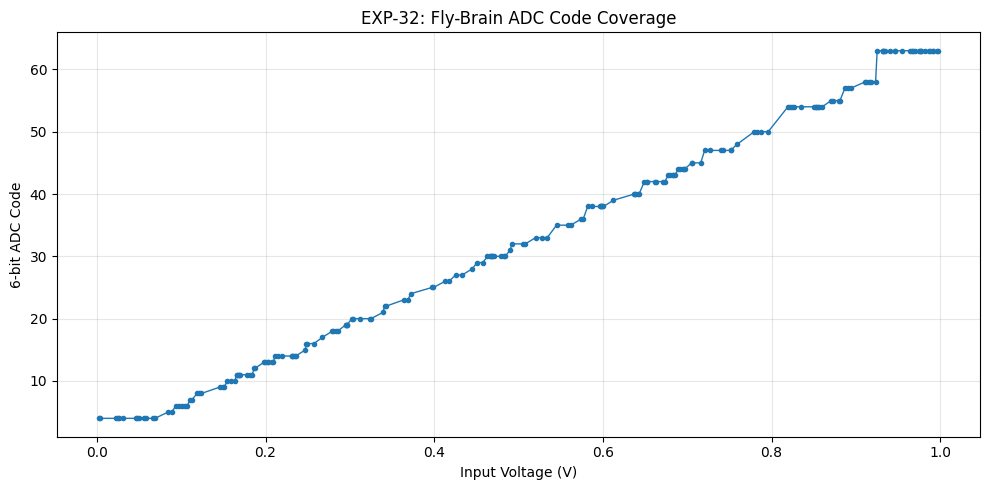

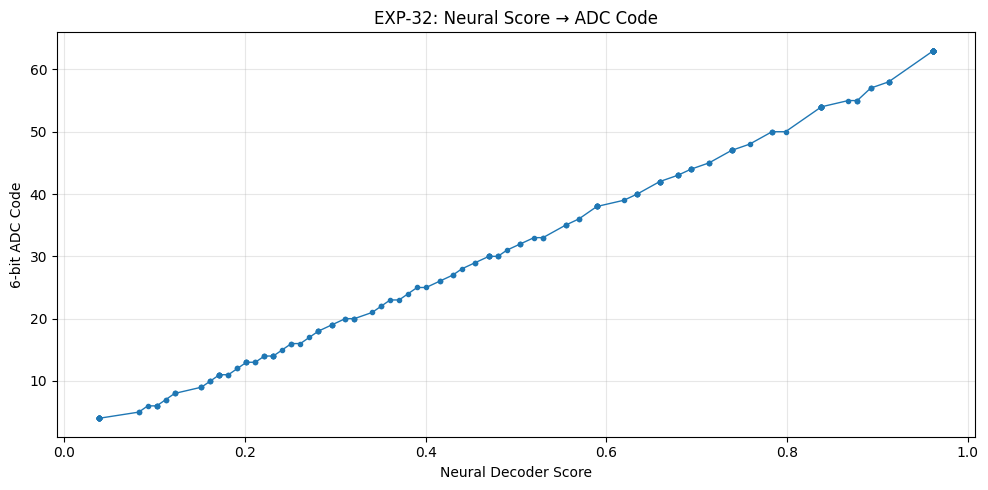

In [152]:
# ============================================================
# EXP-32: CODE-COVERAGE DIAGNOSTIC
# No new Brian2 simulations.
# Uses existing EXP-31 validation results.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

print("\n" + "=" * 70)
print("EXP-32: CODE-COVERAGE DIAGNOSTIC")
print("=" * 70)

# ------------------------------------------------------------
# 1. Basic code coverage
# ------------------------------------------------------------

all_codes32 = np.arange(64)

occupied_codes32 = np.unique(codes31)
missing_codes32 = np.setdiff1d(all_codes32, occupied_codes32)

print("\n" + "=" * 70)
print("CODE COVERAGE")
print("=" * 70)

print(f"Occupied codes : {len(occupied_codes32)}/64")
print(f"Missing codes  : {len(missing_codes32)}")
print(f"Missing list   : {missing_codes32.tolist()}")

# ------------------------------------------------------------
# 2. Sort validation samples by voltage
# ------------------------------------------------------------

order32 = np.argsort(val_v28)

v_sorted32 = val_v28[order32]
score_sorted32 = pred31_val[order32]
code_sorted32 = codes31[order32]

# ------------------------------------------------------------
# 3. Find code transitions
# ------------------------------------------------------------

transition_idx32 = np.where(
    np.diff(code_sorted32) != 0
)[0]

print("\n" + "=" * 70)
print("CODE TRANSITIONS")
print("=" * 70)

print(f"Number of observed transitions : {len(transition_idx32)}")

print("\nVoltage transition table:")
print("Voltage       Score       Code → Code")

for idx in transition_idx32:
    print(
        f"{v_sorted32[idx]:.4f} → "
        f"{v_sorted32[idx+1]:.4f}    "
        f"{score_sorted32[idx]:.4f} → "
        f"{score_sorted32[idx+1]:.4f}    "
        f"{code_sorted32[idx]:2d} → {code_sorted32[idx+1]:2d}"
    )

# ------------------------------------------------------------
# 4. Detect skipped codes
# ------------------------------------------------------------

skipped_transitions32 = []

for idx in transition_idx32:
    c1 = code_sorted32[idx]
    c2 = code_sorted32[idx + 1]

    if c2 > c1 + 1:
        skipped_transitions32.append(
            (
                v_sorted32[idx],
                v_sorted32[idx + 1],
                c1,
                c2,
                list(range(c1 + 1, c2))
            )
        )

print("\n" + "=" * 70)
print("SKIPPED CODE TRANSITIONS")
print("=" * 70)

if len(skipped_transitions32) == 0:
    print("No skipped code transitions detected.")
else:
    for item in skipped_transitions32:
        v1, v2, c1, c2, skipped = item

        print(
            f"{v1:.4f} V → {v2:.4f} V : "
            f"code {c1} → {c2}, "
            f"skipped {skipped}"
        )

# ------------------------------------------------------------
# 5. Code occupancy
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CODE OCCUPANCY")
print("=" * 70)

print("Code | Samples | Voltage range")

for code in all_codes32:

    mask = codes31 == code
    count = np.sum(mask)

    if count > 0:
        vmin = np.min(val_v28[mask])
        vmax = np.max(val_v28[mask])

        print(
            f"{code:4d} | "
            f"{count:7d} | "
            f"{vmin:.4f} – {vmax:.4f}"
        )
    else:
        print(
            f"{code:4d} | "
            f"{0:7d} | "
            f"MISSING"
        )

# ------------------------------------------------------------
# 6. Detect high-end saturation
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("HIGH-END SATURATION")
print("=" * 70)

max_code32 = codes31.max()

high_mask32 = codes31 == max_code32

print(f"Maximum code : {max_code32}")
print(f"Samples at maximum code : {np.sum(high_mask32)}")

if np.any(high_mask32):
    print(
        f"Voltage range at maximum code : "
        f"{val_v28[high_mask32].min():.4f} – "
        f"{val_v28[high_mask32].max():.4f} V"
    )

# ------------------------------------------------------------
# 7. Identify the largest voltage regions occupied by one code
# ------------------------------------------------------------

code_spans32 = []

for code in occupied_codes32:

    mask = codes31 == code

    if np.sum(mask) >= 2:
        span = (
            np.max(val_v28[mask])
            - np.min(val_v28[mask])
        )

        code_spans32.append(
            (span, code, np.min(val_v28[mask]), np.max(val_v28[mask]))
        )

code_spans32.sort(reverse=True)

print("\n" + "=" * 70)
print("WIDEST CODE REGIONS")
print("=" * 70)

for span, code, vmin, vmax in code_spans32[:10]:

    print(
        f"Code {code:2d} : "
        f"{vmin:.4f} – {vmax:.4f} V "
        f"(span = {span:.4f} V)"
    )

# ------------------------------------------------------------
# 8. Plot voltage → code transfer
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    v_sorted32,
    code_sorted32,
    marker="o",
    markersize=3,
    linewidth=1
)

plt.xlabel("Input Voltage (V)")
plt.ylabel("6-bit ADC Code")
plt.title("EXP-32: Fly-Brain ADC Code Coverage")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. Plot neural score → code
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    score_sorted32,
    code_sorted32,
    marker="o",
    markersize=3,
    linewidth=1
)

plt.xlabel("Neural Decoder Score")
plt.ylabel("6-bit ADC Code")
plt.title("EXP-32: Neural Score → ADC Code")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [153]:
# ============================================================
# EXP-33: SMOOTH MONOTONIC TEMPORAL DECODER
#
# Goal:
# Remove the discontinuities introduced by the tree decoder
# and test whether the underlying Fly features support more
# than 47 usable ADC codes.
#
# Training data only is used to construct the decoder.
# ============================================================

import numpy as np
from sklearn.isotonic import IsotonicRegression

print("\n" + "=" * 70)
print("EXP-33: SMOOTH MONOTONIC TEMPORAL DECODER")
print("=" * 70)

# ------------------------------------------------------------
# 1. Extract the EXP-29C winning 3 features
# ------------------------------------------------------------

train_count33 = X28_train[:, 1]      # Mi1 spike count
train_lat33   = X28_train[:, 2]      # L1 first latency
train_isi33   = X28_train[:, 4]      # L1 mean ISI

val_count33 = X28_val[:, 1]
val_lat33   = X28_val[:, 2]
val_isi33   = X28_val[:, 4]

# ------------------------------------------------------------
# 2. Normalize using TRAINING statistics only
#
# Higher count = higher voltage
# Lower latency = higher voltage
# Lower ISI = higher voltage
# ------------------------------------------------------------

def minmax_train33(x, xmin, xmax):
    if xmax == xmin:
        return np.zeros_like(x, dtype=float)

    return np.clip(
        (x - xmin) / (xmax - xmin),
        0,
        1
    )

count_min33 = train_count33.min()
count_max33 = train_count33.max()

lat_min33 = train_lat33.min()
lat_max33 = train_lat33.max()

isi_min33 = train_isi33.min()
isi_max33 = train_isi33.max()

train_count_norm33 = minmax_train33(
    train_count33,
    count_min33,
    count_max33
)

val_count_norm33 = minmax_train33(
    val_count33,
    count_min33,
    count_max33
)

# Invert latency and ISI because smaller values mean higher voltage

train_lat_norm33 = 1 - minmax_train33(
    train_lat33,
    lat_min33,
    lat_max33
)

val_lat_norm33 = 1 - minmax_train33(
    val_lat33,
    lat_min33,
    lat_max33
)

train_isi_norm33 = 1 - minmax_train33(
    train_isi33,
    isi_min33,
    isi_max33
)

val_isi_norm33 = 1 - minmax_train33(
    val_isi33,
    isi_min33,
    isi_max33
)

# ------------------------------------------------------------
# 3. Construct smooth composite temporal score
# ------------------------------------------------------------

train_score33 = (
    train_count_norm33
    + train_lat_norm33
    + train_isi_norm33
) / 3.0

val_score33 = (
    val_count_norm33
    + val_lat_norm33
    + val_isi_norm33
) / 3.0

# ------------------------------------------------------------
# 4. Fit monotonic mapping from score → voltage
# ------------------------------------------------------------

iso33 = IsotonicRegression(
    y_min=0,
    y_max=1,
    increasing=True,
    out_of_bounds="clip"
)

iso33.fit(
    train_score33,
    train_v
)

pred33 = iso33.predict(val_score33)

pred33 = np.clip(
    pred33,
    0,
    1
)

# ------------------------------------------------------------
# 5. Analog performance
# ------------------------------------------------------------

analog_error33 = pred33 - val_v28

analog_mae33 = np.mean(
    np.abs(analog_error33)
)

analog_rmse33 = np.sqrt(
    np.mean(analog_error33 ** 2)
)

analog_max33 = np.max(
    np.abs(analog_error33)
)

# ------------------------------------------------------------
# 6. 6-bit quantization
# ------------------------------------------------------------

codes33 = np.round(
    pred33 * 63
).astype(int)

codes33 = np.clip(
    codes33,
    0,
    63
)

decoded33 = codes33 / 63.0

error33 = decoded33 - val_v28

mae33 = np.mean(
    np.abs(error33)
)

rmse33 = np.sqrt(
    np.mean(error33 ** 2)
)

max33 = np.max(
    np.abs(error33)
)

# ------------------------------------------------------------
# 7. ADC properties
# ------------------------------------------------------------

order33 = np.argsort(val_v28)

monotonic33 = np.all(
    np.diff(codes33[order33]) >= 0
)

unique33 = len(
    np.unique(codes33)
)

# ------------------------------------------------------------
# 8. Results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXP-33 RESULTS")
print("=" * 70)

print(f"Analog MAE       : {analog_mae33:.6f} V")
print(f"Analog RMSE      : {analog_rmse33:.6f} V")
print(f"Analog Max       : {analog_max33:.6f} V")

print(f"\n6-bit MAE        : {mae33:.6f} V")
print(f"6-bit RMSE       : {rmse33:.6f} V")
print(f"Max error        : {max33:.6f} V")

print(f"\nUnique codes     : {unique33}/64")
print(f"Code range       : {codes33.min()}–{codes33.max()}")
print(f"Monotonic        : {monotonic33}")

# ------------------------------------------------------------
# 9. Compare against current best
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("COMPARISON")
print("=" * 70)

print("\nEXP-29C:")
print("  MAE        : 0.007765 V")
print("  RMSE       : 0.011314 V")
print("  Codes      : 47/64")
print("  Monotonic  : True")

print("\nEXP-30:")
print("  MAE        : 0.022108 V")
print("  RMSE       : 0.027274 V")
print("  Codes      : 49/64")
print("  Monotonic  : True")

print("\nEXP-31:")
print("  MAE        : 0.011675 V")
print("  RMSE       : 0.018796 V")
print("  Codes      : 47/64")
print("  Monotonic  : True")

print("\nEXP-33:")
print(f"  MAE        : {mae33:.6f} V")
print(f"  RMSE       : {rmse33:.6f} V")
print(f"  Codes      : {unique33}/64")
print(f"  Monotonic  : {monotonic33}")

# ------------------------------------------------------------
# 10. Missing codes
# ------------------------------------------------------------

missing33 = np.setdiff1d(
    np.arange(64),
    np.unique(codes33)
)

print(f"\nMissing codes : {missing33.tolist()}")


EXP-33: SMOOTH MONOTONIC TEMPORAL DECODER

EXP-33 RESULTS
Analog MAE       : 0.006051 V
Analog RMSE      : 0.009745 V
Analog Max       : 0.037398 V

6-bit MAE        : 0.007991 V
6-bit RMSE       : 0.011313 V
Max error        : 0.045018 V

Unique codes     : 52/64
Code range       : 0–60
Monotonic        : True

COMPARISON

EXP-29C:
  MAE        : 0.007765 V
  RMSE       : 0.011314 V
  Codes      : 47/64
  Monotonic  : True

EXP-30:
  MAE        : 0.022108 V
  RMSE       : 0.027274 V
  Codes      : 49/64
  Monotonic  : True

EXP-31:
  MAE        : 0.011675 V
  RMSE       : 0.018796 V
  Codes      : 47/64
  Monotonic  : True

EXP-33:
  MAE        : 0.007991 V
  RMSE       : 0.011313 V
  Codes      : 52/64
  Monotonic  : True

Missing codes : [34, 38, 41, 46, 51, 52, 54, 57, 59, 61, 62, 63]


In [154]:
# ============================================================
# EXP-34: 4-FEATURE SMOOTH MONOTONIC TEMPORAL DECODER
#
# Adds Mi1 first-spike latency to the EXP-33 architecture.
# No new Brian2 simulation.
# ============================================================

import numpy as np
from sklearn.isotonic import IsotonicRegression

print("\n" + "=" * 70)
print("EXP-34: 4-FEATURE SMOOTH MONOTONIC DECODER")
print("=" * 70)

# ------------------------------------------------------------
# 1. Extract features
# ------------------------------------------------------------

# Feature 1: Mi1 spike count
train_count34 = X28_train[:, 1]
val_count34   = X28_val[:, 1]

# Feature 2: L1 first-spike latency
train_l1lat34 = X28_train[:, 2]
val_l1lat34   = X28_val[:, 2]

# Feature 3: Mi1 first-spike latency
train_mi1lat34 = X28_train[:, 3]
val_mi1lat34   = X28_val[:, 3]

# Feature 4: L1 mean ISI
train_l1isi34 = X28_train[:, 4]
val_l1isi34   = X28_val[:, 4]


# ------------------------------------------------------------
# 2. Training-only min-max normalization
# ------------------------------------------------------------

def norm34(x, xmin, xmax):
    if xmax == xmin:
        return np.zeros_like(x, dtype=float)

    return np.clip(
        (x - xmin) / (xmax - xmin),
        0,
        1
    )


# Mi1 count: higher = higher voltage
cmin34 = train_count34.min()
cmax34 = train_count34.max()

train_c34 = norm34(train_count34, cmin34, cmax34)
val_c34   = norm34(val_count34, cmin34, cmax34)


# L1 latency: lower = higher voltage
l1min34 = train_l1lat34.min()
l1max34 = train_l1lat34.max()

train_l1lat_n34 = 1 - norm34(
    train_l1lat34,
    l1min34,
    l1max34
)

val_l1lat_n34 = 1 - norm34(
    val_l1lat34,
    l1min34,
    l1max34
)


# Mi1 latency: lower = higher voltage
mi1min34 = train_mi1lat34.min()
mi1max34 = train_mi1lat34.max()

train_mi1lat_n34 = 1 - norm34(
    train_mi1lat34,
    mi1min34,
    mi1max34
)

val_mi1lat_n34 = 1 - norm34(
    val_mi1lat34,
    mi1min34,
    mi1max34
)


# L1 ISI: lower = higher voltage
isimin34 = train_l1isi34.min()
isimax34 = train_l1isi34.max()

train_isi34 = 1 - norm34(
    train_l1isi34,
    isimin34,
    isimax34
)

val_isi34 = 1 - norm34(
    val_l1isi34,
    isimin34,
    isimax34
)


# ------------------------------------------------------------
# 3. Smooth composite score
# ------------------------------------------------------------

train_score34 = (
    train_c34
    + train_l1lat_n34
    + train_mi1lat_n34
    + train_isi34
) / 4.0

val_score34 = (
    val_c34
    + val_l1lat_n34
    + val_mi1lat_n34
    + val_isi34
) / 4.0


# ------------------------------------------------------------
# 4. Monotonic score → voltage mapping
# ------------------------------------------------------------

iso34 = IsotonicRegression(
    y_min=0,
    y_max=1,
    increasing=True,
    out_of_bounds="clip"
)

iso34.fit(
    train_score34,
    train_v
)

pred34 = iso34.predict(val_score34)

pred34 = np.clip(
    pred34,
    0,
    1
)


# ------------------------------------------------------------
# 5. Analog metrics
# ------------------------------------------------------------

analog_error34 = pred34 - val_v28

analog_mae34 = np.mean(
    np.abs(analog_error34)
)

analog_rmse34 = np.sqrt(
    np.mean(analog_error34 ** 2)
)

analog_max34 = np.max(
    np.abs(analog_error34)
)


# ------------------------------------------------------------
# 6. 6-bit quantization
# ------------------------------------------------------------

codes34 = np.round(
    pred34 * 63
).astype(int)

codes34 = np.clip(
    codes34,
    0,
    63
)

decoded34 = codes34 / 63.0

error34 = decoded34 - val_v28

mae34 = np.mean(
    np.abs(error34)
)

rmse34 = np.sqrt(
    np.mean(error34 ** 2)
)

max34 = np.max(
    np.abs(error34)
)


# ------------------------------------------------------------
# 7. ADC properties
# ------------------------------------------------------------

order34 = np.argsort(val_v28)

monotonic34 = np.all(
    np.diff(codes34[order34]) >= 0
)

unique34 = len(
    np.unique(codes34)
)

missing34 = np.setdiff1d(
    np.arange(64),
    np.unique(codes34)
)


# ------------------------------------------------------------
# 8. Results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXP-34 RESULTS")
print("=" * 70)

print(f"Analog MAE       : {analog_mae34:.6f} V")
print(f"Analog RMSE      : {analog_rmse34:.6f} V")
print(f"Analog Max       : {analog_max34:.6f} V")

print(f"\n6-bit MAE        : {mae34:.6f} V")
print(f"6-bit RMSE       : {rmse34:.6f} V")
print(f"Max error        : {max34:.6f} V")

print(f"\nUnique codes     : {unique34}/64")
print(f"Code range       : {codes34.min()}–{codes34.max()}")
print(f"Monotonic        : {monotonic34}")

print(f"\nMissing codes    : {missing34.tolist()}")


# ------------------------------------------------------------
# 9. Comparison
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("COMPARISON")
print("=" * 70)

print("\nEXP-29C:")
print("  MAE        : 0.007765 V")
print("  Codes      : 47/64")

print("\nEXP-33:")
print("  Analog MAE : 0.006051 V")
print("  6-bit MAE  : 0.007991 V")
print("  Codes      : 52/64")

print("\nEXP-34:")
print(f"  Analog MAE : {analog_mae34:.6f} V")
print(f"  6-bit MAE  : {mae34:.6f} V")
print(f"  Codes      : {unique34}/64")
print(f"  Monotonic  : {monotonic34}")


EXP-34: 4-FEATURE SMOOTH MONOTONIC DECODER

EXP-34 RESULTS
Analog MAE       : 0.005753 V
Analog RMSE      : 0.009629 V
Analog Max       : 0.037398 V

6-bit MAE        : 0.008078 V
6-bit RMSE       : 0.011373 V
Max error        : 0.045018 V

Unique codes     : 52/64
Code range       : 0–60
Monotonic        : True

Missing codes    : [34, 36, 38, 41, 46, 51, 52, 54, 59, 61, 62, 63]

COMPARISON

EXP-29C:
  MAE        : 0.007765 V
  Codes      : 47/64

EXP-33:
  Analog MAE : 0.006051 V
  6-bit MAE  : 0.007991 V
  Codes      : 52/64

EXP-34:
  Analog MAE : 0.005753 V
  6-bit MAE  : 0.008078 V
  Codes      : 52/64
  Monotonic  : True


In [155]:
# ============================================================
# EXP-35 + EXP-36
# 5-FEATURE AND 6-FEATURE SMOOTH MONOTONIC DECODERS
#
# No new Brian2 simulations.
# Same smooth normalized-feature + isotonic methodology
# used in EXP-33/34.
# ============================================================

import numpy as np
from sklearn.isotonic import IsotonicRegression

print("\n" + "=" * 70)
print("EXP-35 / EXP-36: 5-FEATURE + 6-FEATURE DECODERS")
print("=" * 70)

# Feature definitions:
#
# 1 = L1 spike count
# 2 = Mi1 spike count
# 3 = L1 first latency
# 4 = Mi1 first latency
# 5 = L1 mean ISI
# 6 = Mi1 mean ISI

feature_names = [
    "L1 count",
    "Mi1 count",
    "L1 first latency",
    "Mi1 first latency",
    "L1 mean ISI",
    "Mi1 mean ISI"
]

# ------------------------------------------------------------
# Helper: training-only normalization
# ------------------------------------------------------------

def normalize_feature35(train_x, val_x, invert=False):

    xmin = train_x.min()
    xmax = train_x.max()

    if xmax == xmin:
        train_n = np.zeros_like(train_x, dtype=float)
        val_n = np.zeros_like(val_x, dtype=float)
    else:
        train_n = np.clip(
            (train_x - xmin) / (xmax - xmin),
            0,
            1
        )

        val_n = np.clip(
            (val_x - xmin) / (xmax - xmin),
            0,
            1
        )

    if invert:
        train_n = 1 - train_n
        val_n = 1 - val_n

    return train_n, val_n


# ------------------------------------------------------------
# Extract all six features
# ------------------------------------------------------------

train_features35 = [
    X28_train[:, 0],   # L1 count
    X28_train[:, 1],   # Mi1 count
    X28_train[:, 2],   # L1 first latency
    X28_train[:, 3],   # Mi1 first latency
    X28_train[:, 4],   # L1 mean ISI
    X28_train[:, 5]    # Mi1 mean ISI
]

val_features35 = [
    X28_val[:, 0],
    X28_val[:, 1],
    X28_val[:, 2],
    X28_val[:, 3],
    X28_val[:, 4],
    X28_val[:, 5]
]

# Higher count = higher voltage
# Lower latency / ISI = higher voltage

inversions35 = [
    False,  # L1 count
    False,  # Mi1 count
    True,   # L1 latency
    True,   # Mi1 latency
    True,   # L1 ISI
    True    # Mi1 ISI
]

train_norm35 = []
val_norm35 = []

for tr, va, inv in zip(
    train_features35,
    val_features35,
    inversions35
):
    tr_n, va_n = normalize_feature35(
        tr,
        va,
        invert=inv
    )

    train_norm35.append(tr_n)
    val_norm35.append(va_n)


# ============================================================
# FUNCTION TO RUN N-FEATURE DECODER
# ============================================================

def run_smooth_decoder35(
    train_features,
    val_features,
    train_target,
    val_target,
    n_features,
    label
):

    train_score = np.mean(
        np.column_stack(train_features[:n_features]),
        axis=1
    )

    val_score = np.mean(
        np.column_stack(val_features[:n_features]),
        axis=1
    )

    iso = IsotonicRegression(
        y_min=0,
        y_max=1,
        increasing=True,
        out_of_bounds="clip"
    )

    iso.fit(
        train_score,
        train_target
    )

    pred = np.clip(
        iso.predict(val_score),
        0,
        1
    )

    # --------------------------------------------------------
    # Analog metrics
    # --------------------------------------------------------

    analog_error = pred - val_target

    analog_mae = np.mean(
        np.abs(analog_error)
    )

    analog_rmse = np.sqrt(
        np.mean(analog_error ** 2)
    )

    analog_max = np.max(
        np.abs(analog_error)
    )

    # --------------------------------------------------------
    # 6-bit ADC
    # --------------------------------------------------------

    codes = np.round(
        pred * 63
    ).astype(int)

    codes = np.clip(
        codes,
        0,
        63
    )

    decoded = codes / 63.0

    error = decoded - val_target

    mae = np.mean(
        np.abs(error)
    )

    rmse = np.sqrt(
        np.mean(error ** 2)
    )

    max_error = np.max(
        np.abs(error)
    )

    # --------------------------------------------------------
    # ADC properties
    # --------------------------------------------------------

    order = np.argsort(val_target)

    monotonic = np.all(
        np.diff(codes[order]) >= 0
    )

    unique_codes = len(
        np.unique(codes)
    )

    missing = np.setdiff1d(
        np.arange(64),
        np.unique(codes)
    )

    print("\n" + "=" * 70)
    print(label)
    print("=" * 70)

    print(f"Analog MAE       : {analog_mae:.6f} V")
    print(f"Analog RMSE      : {analog_rmse:.6f} V")
    print(f"Analog Max       : {analog_max:.6f} V")

    print(f"\n6-bit MAE        : {mae:.6f} V")
    print(f"6-bit RMSE       : {rmse:.6f} V")
    print(f"Max error        : {max_error:.6f} V")

    print(f"\nUnique codes     : {unique_codes}/64")
    print(f"Code range       : {codes.min()}–{codes.max()}")
    print(f"Monotonic        : {monotonic}")

    print(f"\nMissing codes    : {missing.tolist()}")

    return {
        "label": label,
        "pred": pred,
        "codes": codes,
        "analog_mae": analog_mae,
        "analog_rmse": analog_rmse,
        "analog_max": analog_max,
        "mae": mae,
        "rmse": rmse,
        "max_error": max_error,
        "unique_codes": unique_codes,
        "monotonic": monotonic,
        "missing": missing
    }


# ============================================================
# EXP-35: FIVE FEATURES
#
# L1 count
# Mi1 count
# L1 first latency
# Mi1 first latency
# L1 mean ISI
# ============================================================

result35 = run_smooth_decoder35(
    train_norm35,
    val_norm35,
    train_v,
    val_v28,
    5,
    "EXP-35: 5-FEATURE SMOOTH MONOTONIC DECODER"
)


# ============================================================
# EXP-36: SIX FEATURES
#
# All six temporal/spike features
# ============================================================

result36 = run_smooth_decoder35(
    train_norm35,
    val_norm35,
    train_v,
    val_v28,
    6,
    "EXP-36: 6-FEATURE SMOOTH MONOTONIC DECODER"
)


# ============================================================
# FINAL COMPARISON
# ============================================================

print("\n" + "=" * 70)
print("FINAL FEATURE COMPARISON")
print("=" * 70)

print(
    f"{'Architecture':<15}"
    f"{'Analog MAE':>14}"
    f"{'6-bit MAE':>14}"
    f"{'Codes':>12}"
    f"{'Monotonic':>12}"
)

print("-" * 70)

print(
    f"{'EXP-33 (3F)':<15}"
    f"{0.006051:>14.6f}"
    f"{0.007991:>14.6f}"
    f"{'52/64':>12}"
    f"{'True':>12}"
)

print(
    f"{'EXP-34 (4F)':<15}"
    f"{0.005753:>14.6f}"
    f"{0.008078:>14.6f}"
    f"{'52/64':>12}"
    f"{'True':>12}"
)

print(
    f"{'EXP-35 (5F)':<15}"
    f"{result35['analog_mae']:>14.6f}"
    f"{result35['mae']:>14.6f}"
    f"{result35['unique_codes']}/64"
    f"{str(result35['monotonic']):>12}"
)

print(
    f"{'EXP-36 (6F)':<15}"
    f"{result36['analog_mae']:>14.6f}"
    f"{result36['mae']:>14.6f}"
    f"{result36['unique_codes']}/64"
    f"{str(result36['monotonic']):>12}"
)


EXP-35 / EXP-36: 5-FEATURE + 6-FEATURE DECODERS

EXP-35: 5-FEATURE SMOOTH MONOTONIC DECODER
Analog MAE       : 0.005755 V
Analog RMSE      : 0.009628 V
Analog Max       : 0.037398 V

6-bit MAE        : 0.008045 V
6-bit RMSE       : 0.011350 V
Max error        : 0.045018 V

Unique codes     : 52/64
Code range       : 0–60
Monotonic        : True

Missing codes    : [34, 36, 38, 41, 46, 51, 52, 54, 59, 61, 62, 63]

EXP-36: 6-FEATURE SMOOTH MONOTONIC DECODER
Analog MAE       : 0.005696 V
Analog RMSE      : 0.009618 V
Analog Max       : 0.037398 V

6-bit MAE        : 0.008023 V
6-bit RMSE       : 0.011335 V
Max error        : 0.045018 V

Unique codes     : 52/64
Code range       : 0–60
Monotonic        : True

Missing codes    : [34, 36, 38, 41, 46, 51, 52, 54, 59, 61, 62, 63]

FINAL FEATURE COMPARISON
Architecture       Analog MAE     6-bit MAE       Codes   Monotonic
----------------------------------------------------------------------
EXP-33 (3F)          0.006051      0.007991       

In [156]:
# ============================================================
# EXP-37: HIGH-END RESPONSE RESOLUTION ANALYSIS
# ============================================================

import numpy as np

print("=" * 70)
print("EXP-37: HIGH-END TEMPORAL RESPONSE ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# EXP-33 feature set
# Mi1 count, L1 first latency, L1 mean ISI
# ------------------------------------------------------------

features_train = np.column_stack([
    X28_train[:, 1],   # Mi1 spike count
    X28_train[:, 2],   # L1 first latency
    X28_train[:, 4]    # L1 mean ISI
])

features_val = np.column_stack([
    X28_val[:, 1],
    X28_val[:, 2],
    X28_val[:, 4]
])

# Direction: larger count = higher V
# smaller latency/ISI = higher V
invert = [False, True, True]

# Normalize using TRAINING statistics only
train_min = features_train.min(axis=0)
train_max = features_train.max(axis=0)

train_norm = (features_train - train_min) / (train_max - train_min)
val_norm = (features_val - train_min) / (train_max - train_min)

for i in range(3):
    if invert[i]:
        train_norm[:, i] = 1 - train_norm[:, i]
        val_norm[:, i] = 1 - val_norm[:, i]

# Composite biological score
train_score = np.mean(train_norm, axis=1)
val_score = np.mean(val_norm, axis=1)

# Sort validation trajectory by voltage
order = np.argsort(X28_val[:, -1])
v_sorted = X28_val[order, -1]
score_sorted = val_score[order]

# ------------------------------------------------------------
# Examine upper 20% of voltage range
# ------------------------------------------------------------

high = v_sorted >= 0.80

print("\nHIGH-END RESPONSE:")
print("-" * 70)

for v, s in zip(v_sorted[high], score_sorted[high]):
    print(f"V={v:.4f}   score={s:.6f}")

# ------------------------------------------------------------
# Score differences
# ------------------------------------------------------------

print("\nHIGH-END SCORE DIFFERENCES:")
print("-" * 70)

high_scores = score_sorted[high]
high_voltages = v_sorted[high]

for i in range(1, len(high_scores)):
    ds = high_scores[i] - high_scores[i-1]
    dv = high_voltages[i] - high_voltages[i-1]

    print(
        f"{high_voltages[i-1]:.4f} -> {high_voltages[i]:.4f} | "
        f"Δscore={ds:+.6f} | ΔV={dv:.6f}"
    )

# ------------------------------------------------------------
# Quantization
# ------------------------------------------------------------

codes = np.clip(np.round(val_score * 63), 0, 63).astype(int)

print("\nHIGH-END CODES:")
print("-" * 70)

for v, s, c in zip(v_sorted[high], score_sorted[high], codes[order][high]):
    print(f"V={v:.4f}   score={s:.6f}   code={c}")

print("\nCODE OCCUPANCY:")
print("-" * 70)

unique, counts = np.unique(codes, return_counts=True)

for c, n in zip(unique, counts):
    if c >= 45:
        mask = codes == c
        print(
            f"Code {c:2d}: {n:3d} samples | "
            f"V={X28_val[mask,-1].min():.4f}"
            f"-{X28_val[mask,-1].max():.4f}"
        )

print("\n" + "=" * 70)
print("EXP-37 COMPLETE")
print("=" * 70)

EXP-37: HIGH-END TEMPORAL RESPONSE ANALYSIS

HIGH-END RESPONSE:
----------------------------------------------------------------------
V=4.5000   score=0.999692
V=4.5000   score=0.994137
V=4.5000   score=0.994137
V=4.5000   score=0.994137
V=4.5000   score=0.994137
V=4.5000   score=0.994137
V=4.5000   score=0.999692
V=4.5000   score=0.999692
V=4.5000   score=0.999692
V=4.5000   score=0.999692
V=4.5000   score=0.999692
V=4.5000   score=0.999692
V=4.5000   score=0.999692
V=4.5000   score=0.999692
V=4.5000   score=0.999692
V=4.5000   score=0.999692
V=4.5000   score=0.999692
V=4.5000   score=0.999692
V=4.5000   score=0.999692
V=4.5000   score=0.999692
V=4.5000   score=0.999692
V=4.5000   score=0.999692
V=4.5000   score=0.999692
V=4.5000   score=0.999692
V=4.5000   score=0.999692
V=4.5000   score=0.999692
V=4.5000   score=0.999692
V=4.5000   score=0.999692
V=4.5000   score=0.999692
V=5.0000   score=0.950691
V=5.0000   score=0.950691
V=5.0000   score=0.950691
V=5.0000   score=0.950691
V=5.000

In [157]:
# ============================================================
# EXP-38: VALIDATION VOLTAGE AXIS CHECK
# ============================================================

print("=" * 70)
print("EXP-38: VALIDATION VOLTAGE AXIS CHECK")
print("=" * 70)

print("\nX28_val shape:", X28_val.shape)

print("\nColumn ranges:")
for i in range(X28_val.shape[1]):
    print(
        f"Column {i}: "
        f"min={X28_val[:,i].min():.6f}, "
        f"max={X28_val[:,i].max():.6f}, "
        f"unique={len(np.unique(X28_val[:,i]))}"
    )

print("\nLast 10 columns of first 10 validation samples:")
print(X28_val[:10, -10:])

print("\nLikely voltage column candidates:")
for i in range(X28_val.shape[1]):
    vals = X28_val[:, i]
    if vals.min() >= -0.01 and vals.max() <= 1.01:
        print(
            f"Column {i}: NORMALIZED RANGE "
            f"{vals.min():.6f} -> {vals.max():.6f}"
        )

print("\n" + "=" * 70)
print("EXP-38 COMPLETE")
print("=" * 70)

EXP-38: VALIDATION VOLTAGE AXIS CHECK

X28_val shape: (200, 6)

Column ranges:
Column 0: min=15.000000, max=111.000000, unique=46
Column 1: min=15.000000, max=111.000000, unique=38
Column 2: min=4.000000, max=33.000000, unique=39
Column 3: min=4.000000, max=32.500000, unique=38
Column 4: min=4.500000, max=33.000000, unique=65
Column 5: min=4.500000, max=33.000000, unique=48

Last 10 columns of first 10 validation samples:
[[15.         15.         33.         32.5        33.         33.        ]
 [15.         15.         33.         32.5        32.5        32.5       ]
 [18.         18.         27.5        27.         27.         27.        ]
 [18.         18.         27.         26.5        27.         27.        ]
 [18.         18.         27.         26.5        26.5        26.5       ]
 [19.         19.         26.         25.5        25.5        25.55555556]
 [21.         21.         23.5        23.         23.         23.        ]
 [21.         21.         23.         22.5       

In [158]:
# ============================================================
# EXP-39: CORRECT HIGH-END TEMPORAL RESPONSE ANALYSIS
# ============================================================

import numpy as np

print("=" * 70)
print("EXP-39: CORRECT HIGH-END TEMPORAL RESPONSE ANALYSIS")
print("=" * 70)

# EXP-33 features
features_val = np.column_stack([
    X28_val[:, 1],   # Mi1 spike count
    X28_val[:, 2],   # L1 first latency
    X28_val[:, 4]    # L1 mean ISI
])

# Training statistics
features_train = np.column_stack([
    X28_train[:, 1],
    X28_train[:, 2],
    X28_train[:, 4]
])

train_min = features_train.min(axis=0)
train_max = features_train.max(axis=0)

train_norm = (features_train - train_min) / (train_max - train_min)
val_norm = (features_val - train_min) / (train_max - train_min)

# Higher score = higher voltage
train_norm[:, 1] = 1 - train_norm[:, 1]
train_norm[:, 2] = 1 - train_norm[:, 2]

val_norm[:, 1] = 1 - val_norm[:, 1]
val_norm[:, 2] = 1 - val_norm[:, 2]

train_score = np.mean(train_norm, axis=1)
val_score = np.mean(val_norm, axis=1)

# ACTUAL validation voltages
v = validation_voltages

order = np.argsort(v)

v_sorted = v[order]
score_sorted = val_score[order]

# ------------------------------------------------------------
# High-end region
# ------------------------------------------------------------

high = v_sorted >= 0.80

print("\nHIGH-END RESPONSE")
print("-" * 70)

for voltage, score in zip(v_sorted[high], score_sorted[high]):
    print(
        f"V={voltage:.4f} | "
        f"score={score:.6f} | "
        f"code={np.clip(round(score * 63), 0, 63)}"
    )

# ------------------------------------------------------------
# Code occupancy
# ------------------------------------------------------------

codes = np.clip(np.round(val_score * 63), 0, 63).astype(int)

print("\nHIGH-END CODE OCCUPANCY")
print("-" * 70)

for code in range(45, 64):
    mask = codes == code

    if np.any(mask):
        print(
            f"Code {code:2d}: "
            f"{np.sum(mask):3d} samples | "
            f"V={v[mask].min():.4f} -> {v[mask].max():.4f}"
        )

# ------------------------------------------------------------
# Missing high-end codes
# ------------------------------------------------------------

missing_high = [
    c for c in range(45, 64)
    if c not in np.unique(codes)
]

print("\nMissing codes 45-63:")
print(missing_high)

print("\nTotal unique codes:", len(np.unique(codes)))

print("\n" + "=" * 70)
print("EXP-39 COMPLETE")
print("=" * 70)

EXP-39: CORRECT HIGH-END TEMPORAL RESPONSE ANALYSIS

HIGH-END RESPONSE
----------------------------------------------------------------------
V=0.8194 | score=0.950691 | code=60
V=0.8216 | score=0.950691 | code=60
V=0.8243 | score=0.950691 | code=60
V=0.8269 | score=0.950691 | code=60
V=0.8351 | score=0.950691 | code=60
V=0.8507 | score=0.950691 | code=60
V=0.8527 | score=0.950691 | code=60
V=0.8530 | score=0.950691 | code=60
V=0.8546 | score=0.950691 | code=60
V=0.8557 | score=0.950691 | code=60
V=0.8601 | score=0.950691 | code=60
V=0.8706 | score=0.951205 | code=60
V=0.8726 | score=0.956284 | code=60
V=0.8794 | score=0.956284 | code=60
V=0.8811 | score=0.956284 | code=60
V=0.8870 | score=0.956336 | code=60
V=0.8906 | score=0.956336 | code=60
V=0.8941 | score=0.956336 | code=60
V=0.9110 | score=0.994137 | code=63
V=0.9117 | score=0.994137 | code=63
V=0.9155 | score=0.994137 | code=63
V=0.9182 | score=0.994137 | code=63
V=0.9234 | score=0.994137 | code=63
V=0.9252 | score=0.999692 | co

WARNING    'v' is an internal variable of group 'neurongroup', but also exists in the run namespace with the value array([0.00239717, 0.00333561, 0.02300257, ..., 0.9917593 , 0.99629933,
       0.99739846]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


EXP-40: HIGH-VOLTAGE SATURATION / DRIVE-RANGE SWEEP

----------------------------------------------------------------------
Testing drive range: 0.30 -> 0.80
----------------------------------------------------------------------
V=0.00 | drive=0.300 | L1= 11 (first= 44.0) | Mi1= 11 (first= 44.0)


WARNING    'v' is an internal variable of group 'neurongroup_1', but also exists in the run namespace with the value array([0.00239717, 0.00333561, 0.02300257, ..., 0.9917593 , 0.99629933,
       0.99739846]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


V=0.10 | drive=0.350 | L1= 23 (first= 22.0) | Mi1= 22 (first= 22.0)
V=0.20 | drive=0.400 | L1= 31 (first= 16.0) | Mi1= 30 (first= 16.0)
V=0.30 | drive=0.450 | L1= 39 (first= 13.0) | Mi1= 37 (first= 13.0)
V=0.40 | drive=0.500 | L1= 45 (first= 11.0) | Mi1= 45 (first= 11.0)
V=0.50 | drive=0.550 | L1= 52 (first=  9.5) | Mi1= 52 (first=  9.5)
V=0.60 | drive=0.600 | L1= 58 (first=  8.0) | Mi1= 58 (first=  8.0)
V=0.70 | drive=0.650 | L1= 66 (first=  7.5) | Mi1= 66 (first=  7.5)
V=0.75 | drive=0.675 | L1= 71 (first=  7.0) | Mi1= 66 (first=  7.0)
V=0.80 | drive=0.700 | L1= 72 (first=  6.5) | Mi1= 71 (first=  6.5)
V=0.85 | drive=0.725 | L1= 76 (first=  6.5) | Mi1= 76 (first=  6.5)
V=0.90 | drive=0.750 | L1= 83 (first=  6.0) | Mi1= 76 (first=  6.0)
V=0.95 | drive=0.775 | L1= 83 (first=  5.5) | Mi1= 83 (first=  5.5)
V=1.00 | drive=0.800 | L1= 90 (first=  5.5) | Mi1= 83 (first=  5.5)

----------------------------------------------------------------------
Testing drive range: 0.30 -> 0.85
----------

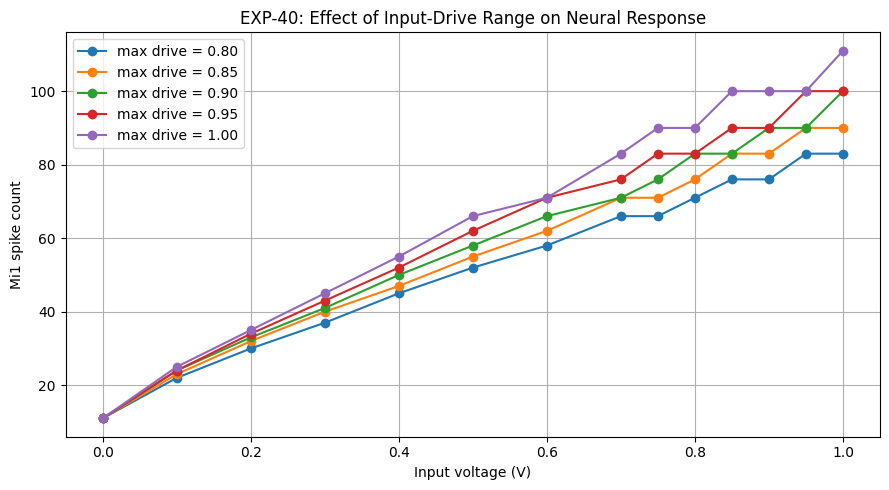

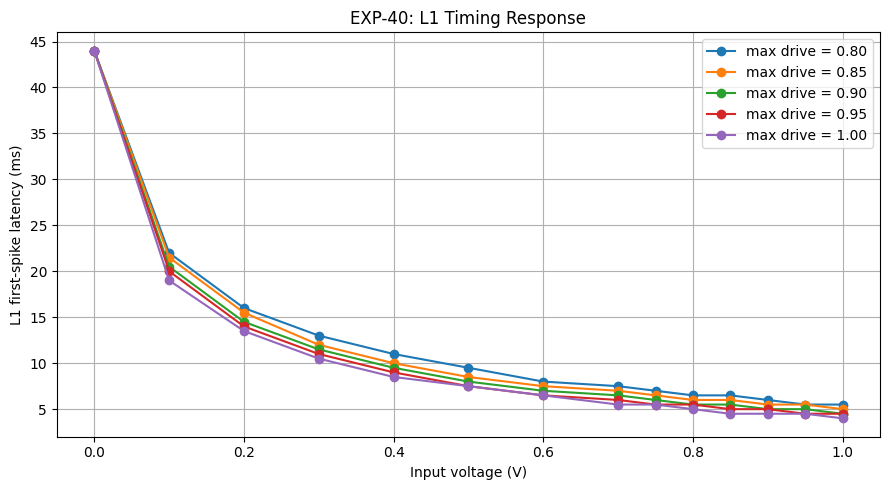


MONOTONICITY CHECK
max drive=0.80 | L1 count monotonic=True | Mi1 count monotonic=True
max drive=0.85 | L1 count monotonic=True | Mi1 count monotonic=True
max drive=0.90 | L1 count monotonic=True | Mi1 count monotonic=True
max drive=0.95 | L1 count monotonic=True | Mi1 count monotonic=True
max drive=1.00 | L1 count monotonic=True | Mi1 count monotonic=True

END EXP-40


In [159]:
# ============================================================
# EXP-40: HIGH-VOLTAGE SATURATION / INPUT-DRIVE RANGE SWEEP
# ============================================================
#
# Goal:
# Test whether changing the voltage -> neural-drive range
# reduces high-voltage saturation.
#
# Current mapping:
#   0 V -> 0.30 drive
#   1 V -> 1.00 drive
#
# EXP-40 tests lower maximum drives:
#   0.80, 0.85, 0.90, 0.95, 1.00
#
# This is a DIAGNOSTIC experiment.
# We first look at the neural response itself before changing
# the decoder.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("EXP-40: HIGH-VOLTAGE SATURATION / DRIVE-RANGE SWEEP")
print("=" * 70)


# ------------------------------------------------------------
# 1. Input voltages
# ------------------------------------------------------------
# Coarse sweep first to avoid another huge experiment.

voltages_40 = np.array([
    0.00,
    0.10,
    0.20,
    0.30,
    0.40,
    0.50,
    0.60,
    0.70,
    0.75,
    0.80,
    0.85,
    0.90,
    0.95,
    1.00
])


# ------------------------------------------------------------
# 2. Drive ranges to test
# ------------------------------------------------------------
#
# Minimum drive stays at 0.30.
# Only the maximum drive is changed.
#
# This isolates the question:
# "Is the upper saturation caused by driving the neurons
#  too close to their saturated operating region?"

MAX_DRIVES_40 = [0.80, 0.85, 0.90, 0.95, 1.00]


def voltage_to_drive_range(
    voltage,
    drive_min=0.30,
    drive_max=1.00
):
    voltage = np.clip(voltage, 0.0, 1.0)

    return drive_min + voltage * (
        drive_max - drive_min
    )


# ------------------------------------------------------------
# 3. Feature extraction
# ------------------------------------------------------------

def extract_basic_features_40(
    spike_mon,
    neuron_id,
    neuron_name,
    duration_ms=500
):
    idx = neuron_id.get(neuron_name)

    if idx is None:
        return 0, np.nan, np.nan

    spike_times = (
        np.asarray(spike_mon.spike_trains()[idx] / ms)
    )

    n = len(spike_times)

    if n == 0:
        return 0, np.nan, np.nan

    first_latency = float(spike_times[0])

    if n >= 2:
        mean_isi = float(
            np.mean(np.diff(spike_times))
        )
    else:
        mean_isi = np.nan

    return n, first_latency, mean_isi


# ------------------------------------------------------------
# 4. Run experiment
# ------------------------------------------------------------

results_40 = []


for max_drive in MAX_DRIVES_40:

    print("\n" + "-" * 70)
    print(
        f"Testing drive range: "
        f"0.30 -> {max_drive:.2f}"
    )
    print("-" * 70)

    for voltage in voltages_40:

        drive = voltage_to_drive_range(
            voltage,
            drive_min=0.30,
            drive_max=max_drive
        )

        # Run existing 100-type Fly model.
        smon, _, elapsed_ms, _ = run_simulation_v1(
            ['L1', 'Mi1'],
            neuron_id100,
            W100_4bit,
            thr100,
            N100,
            duration_ms=500,
            g_drive_on=drive,
            g_drive_off=0.15,
            w_scale=0.06
        )

        # L1
        l1_n, l1_first, l1_isi = (
            extract_basic_features_40(
                smon,
                neuron_id100,
                'L1'
            )
        )

        # Mi1
        mi1_n, mi1_first, mi1_isi = (
            extract_basic_features_40(
                smon,
                neuron_id100,
                'Mi1'
            )
        )

        results_40.append([
            max_drive,
            voltage,
            drive,
            l1_n,
            l1_first,
            l1_isi,
            mi1_n,
            mi1_first,
            mi1_isi,
            elapsed_ms
        ])

        print(
            f"V={voltage:.2f} | "
            f"drive={drive:.3f} | "
            f"L1={l1_n:3d} "
            f"(first={l1_first:5.1f}) | "
            f"Mi1={mi1_n:3d} "
            f"(first={mi1_first:5.1f})"
        )


results_40 = np.asarray(results_40)


# ------------------------------------------------------------
# 5. Convert into structured arrays
# ------------------------------------------------------------

# Columns:
# 0 max_drive
# 1 voltage
# 2 actual_drive
# 3 L1 count
# 4 L1 first latency
# 5 L1 mean ISI
# 6 Mi1 count
# 7 Mi1 first latency
# 8 Mi1 mean ISI
# 9 simulation time

print("\n" + "=" * 70)
print("EXP-40 COMPLETE")
print("=" * 70)


# ------------------------------------------------------------
# 6. Print high-voltage comparison
# ------------------------------------------------------------

print("\nHIGH-VOLTAGE RESPONSE")
print(
    f"{'MaxDrive':>9} "
    f"{'V':>6} "
    f"{'Drive':>8} "
    f"{'L1':>6} "
    f"{'L1lat':>8} "
    f"{'Mi1':>6} "
    f"{'Mi1lat':>8}"
)

for max_drive in MAX_DRIVES_40:

    subset = results_40[
        results_40[:, 0] == max_drive
    ]

    # Last 4 voltage points
    subset = subset[-4:]

    for row in subset:

        print(
            f"{row[0]:9.2f} "
            f"{row[1]:6.2f} "
            f"{row[2]:8.3f} "
            f"{int(row[3]):6d} "
            f"{row[4]:8.2f} "
            f"{int(row[6]):6d} "
            f"{row[7]:8.2f}"
        )

    print()


# ------------------------------------------------------------
# 7. Calculate high-end neural separation
# ------------------------------------------------------------
#
# We specifically care about whether 0.8 -> 1.0 V
# still produces distinguishable neural responses.
#
# Use Mi1 spike count as a simple first diagnostic.

print("\nHIGH-END Mi1 SPIKE RANGE")
print(
    f"{'Max drive':>10} "
    f"{'Mi1@0.8V':>10} "
    f"{'Mi1@1.0V':>10} "
    f"{'Difference':>12}"
)

for max_drive in MAX_DRIVES_40:

    subset = results_40[
        results_40[:, 0] == max_drive
    ]

    mi1_08 = subset[
        np.isclose(subset[:, 1], 0.80)
    ][0, 6]

    mi1_10 = subset[
        np.isclose(subset[:, 1], 1.00)
    ][0, 6]

    print(
        f"{max_drive:10.2f} "
        f"{int(mi1_08):10d} "
        f"{int(mi1_10):10d} "
        f"{int(mi1_10-mi1_08):12d}"
    )


# ------------------------------------------------------------
# 8. Plot Mi1 spike count vs voltage
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

for max_drive in MAX_DRIVES_40:

    subset = results_40[
        results_40[:, 0] == max_drive
    ]

    plt.plot(
        subset[:, 1],
        subset[:, 6],
        marker='o',
        label=f"max drive = {max_drive:.2f}"
    )

plt.xlabel("Input voltage (V)")
plt.ylabel("Mi1 spike count")
plt.title("EXP-40: Effect of Input-Drive Range on Neural Response")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Plot L1 first-spike latency
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

for max_drive in MAX_DRIVES_40:

    subset = results_40[
        results_40[:, 0] == max_drive
    ]

    plt.plot(
        subset[:, 1],
        subset[:, 4],
        marker='o',
        label=f"max drive = {max_drive:.2f}"
    )

plt.xlabel("Input voltage (V)")
plt.ylabel("L1 first-spike latency (ms)")
plt.title("EXP-40: L1 Timing Response")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. Simple monotonicity check
# ------------------------------------------------------------

print("\nMONOTONICITY CHECK")

for max_drive in MAX_DRIVES_40:

    subset = results_40[
        results_40[:, 0] == max_drive
    ]

    l1_counts = subset[:, 3]
    mi1_counts = subset[:, 6]

    l1_mono = np.all(
        np.diff(l1_counts) >= 0
    )

    mi1_mono = np.all(
        np.diff(mi1_counts) >= 0
    )

    print(
        f"max drive={max_drive:.2f} | "
        f"L1 count monotonic={l1_mono} | "
        f"Mi1 count monotonic={mi1_mono}"
    )


print("\n" + "=" * 70)
print("END EXP-40")
print("=" * 70)

EXP-41: CONNECTOME SYNAPTIC-WEIGHT SCALE SWEEP

----------------------------------------------------------------------
Testing W_SCALE = 0.030
----------------------------------------------------------------------
V=0.00 | drive=0.300 | L1= 11 (first= 44.0) | Mi1= 11 (first= 44.0)
V=0.10 | drive=0.370 | L1= 25 (first= 19.0) | Mi1= 25 (first= 19.0)
V=0.20 | drive=0.440 | L1= 37 (first= 13.5) | Mi1= 35 (first= 13.5)
V=0.30 | drive=0.510 | L1= 47 (first= 10.5) | Mi1= 45 (first= 10.5)
V=0.40 | drive=0.580 | L1= 55 (first=  8.5) | Mi1= 55 (first=  8.5)
V=0.50 | drive=0.650 | L1= 66 (first=  7.5) | Mi1= 62 (first=  7.5)
V=0.60 | drive=0.720 | L1= 76 (first=  6.5) | Mi1= 71 (first=  6.5)
V=0.70 | drive=0.790 | L1= 83 (first=  5.5) | Mi1= 83 (first=  5.5)
V=0.75 | drive=0.825 | L1= 90 (first=  5.5) | Mi1= 90 (first=  5.5)
V=0.80 | drive=0.860 | L1= 90 (first=  5.0) | Mi1= 90 (first=  5.0)
V=0.85 | drive=0.895 | L1=100 (first=  4.5) | Mi1=100 (first=  4.5)
V=0.90 | drive=0.930 | L1=100 (first= 

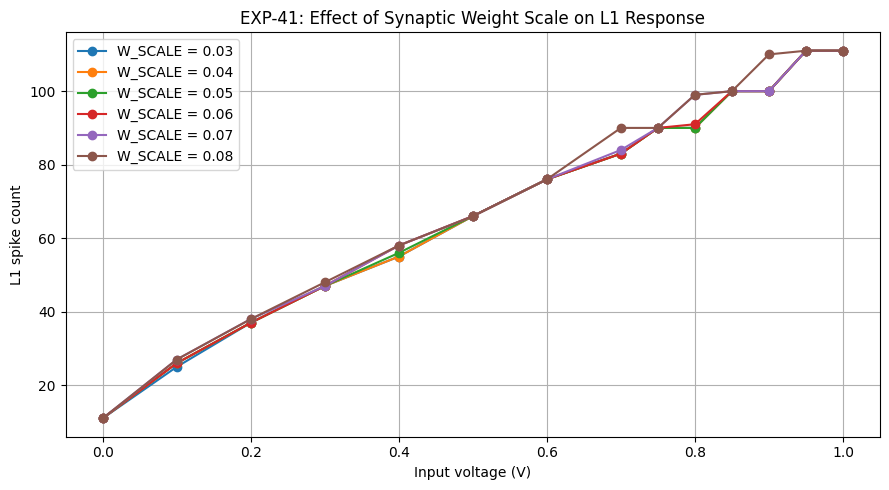

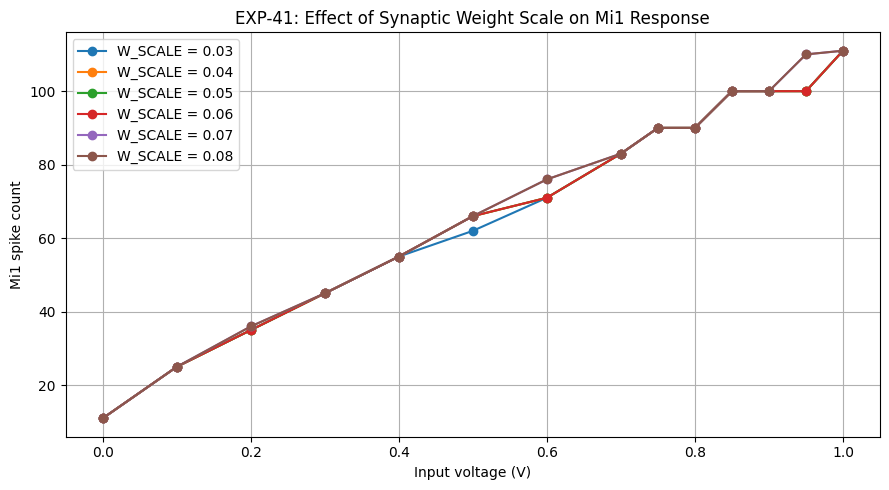

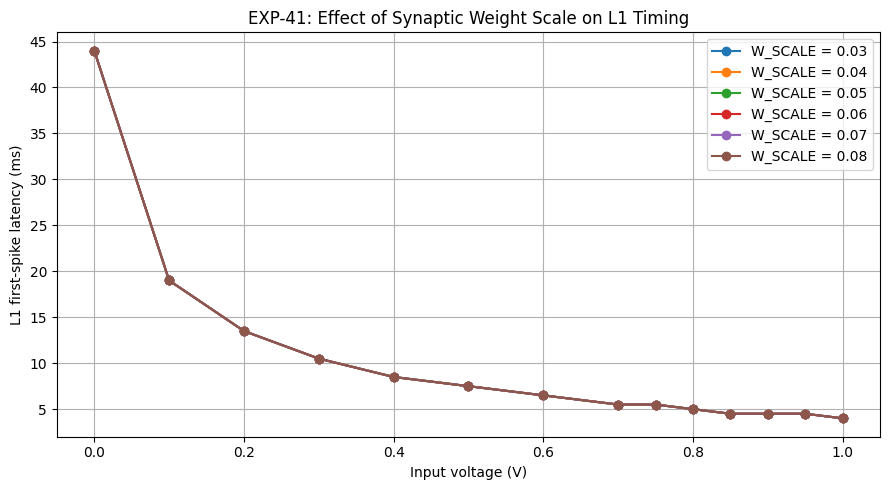


BEST HIGH-END SEPARATION
W_SCALE = 0.030
Mi1 spike separation = 21 spikes

END EXP-41


In [160]:
# ============================================================
# EXP-41: CONNECTOME SYNAPTIC-WEIGHT SCALE SWEEP
# ============================================================
#
# Goal:
# Test whether changing the strength of connectome-derived
# synaptic interactions can improve high-voltage neural
# separation.
#
# EXP-40 showed that changing the input-drive range does not
# solve the high-end saturation.
#
# Current:
#     W_SCALE = 0.06
#
# Test:
#     0.03, 0.04, 0.05, 0.06, 0.07, 0.08
#
# Everything else remains fixed.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("EXP-41: CONNECTOME SYNAPTIC-WEIGHT SCALE SWEEP")
print("=" * 70)


# ------------------------------------------------------------
# 1. Voltage points
# ------------------------------------------------------------

voltages_41 = np.array([
    0.00,
    0.10,
    0.20,
    0.30,
    0.40,
    0.50,
    0.60,
    0.70,
    0.75,
    0.80,
    0.85,
    0.90,
    0.95,
    1.00
])


# ------------------------------------------------------------
# 2. W_SCALE values
# ------------------------------------------------------------

W_SCALES_41 = [
    0.03,
    0.04,
    0.05,
    0.06,
    0.07,
    0.08
]


# ------------------------------------------------------------
# 3. Helper
# ------------------------------------------------------------

def extract_features_41(
    spike_mon,
    neuron_id,
    neuron_name
):
    """
    Extract:
        spike count
        first-spike latency
        mean ISI
    """

    idx = neuron_id.get(neuron_name)

    if idx is None:
        return 0, np.nan, np.nan

    spike_times = np.asarray(
        spike_mon.spike_trains()[idx] / ms
    )

    n = len(spike_times)

    if n == 0:
        return 0, np.nan, np.nan

    first_latency = float(
        spike_times[0]
    )

    if n >= 2:
        mean_isi = float(
            np.mean(np.diff(spike_times))
        )
    else:
        mean_isi = np.nan

    return (
        n,
        first_latency,
        mean_isi
    )


# ------------------------------------------------------------
# 4. Run sweep
# ------------------------------------------------------------

results_41 = []

for w_scale in W_SCALES_41:

    print("\n" + "-" * 70)
    print(
        f"Testing W_SCALE = {w_scale:.3f}"
    )
    print("-" * 70)

    for voltage in voltages_41:

        # Original voltage -> drive mapping
        drive = voltage_to_drive(
            voltage,
            v_min=0.0,
            v_max=1.0,
            drive_min=0.30,
            drive_max=1.00
        )

        # ----------------------------------------------------
        # Run Fly model
        # ----------------------------------------------------

        smon, _, elapsed_ms, _ = run_simulation_v1(
            ['L1', 'Mi1'],
            neuron_id100,
            W100_4bit,
            thr100,
            N100,
            duration_ms=500,
            g_drive_on=drive,
            g_drive_off=0.15,
            w_scale=w_scale
        )

        # ----------------------------------------------------
        # L1
        # ----------------------------------------------------

        l1_n, l1_first, l1_isi = (
            extract_features_41(
                smon,
                neuron_id100,
                'L1'
            )
        )

        # ----------------------------------------------------
        # Mi1
        # ----------------------------------------------------

        mi1_n, mi1_first, mi1_isi = (
            extract_features_41(
                smon,
                neuron_id100,
                'Mi1'
            )
        )

        results_41.append([
            w_scale,
            voltage,
            drive,
            l1_n,
            l1_first,
            l1_isi,
            mi1_n,
            mi1_first,
            mi1_isi,
            elapsed_ms
        ])

        print(
            f"V={voltage:.2f} | "
            f"drive={drive:.3f} | "
            f"L1={l1_n:3d} "
            f"(first={l1_first:5.1f}) | "
            f"Mi1={mi1_n:3d} "
            f"(first={mi1_first:5.1f})"
        )


results_41 = np.asarray(
    results_41
)


# ------------------------------------------------------------
# 5. Summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXP-41 COMPLETE")
print("=" * 70)


# ------------------------------------------------------------
# 6. High-voltage separation
# ------------------------------------------------------------

print("\nHIGH-VOLTAGE Mi1 SEPARATION")
print(
    f"{'W_SCALE':>9} "
    f"{'Mi1@0.8V':>10} "
    f"{'Mi1@1.0V':>10} "
    f"{'Difference':>12}"
)

for w_scale in W_SCALES_41:

    subset = results_41[
        np.isclose(
            results_41[:, 0],
            w_scale
        )
    ]

    mi1_08 = subset[
        np.isclose(
            subset[:, 1],
            0.80
        )
    ][0, 6]

    mi1_10 = subset[
        np.isclose(
            subset[:, 1],
            1.00
        )
    ][0, 6]

    print(
        f"{w_scale:9.3f} "
        f"{int(mi1_08):10d} "
        f"{int(mi1_10):10d} "
        f"{int(mi1_10-mi1_08):12d}"
    )


# ------------------------------------------------------------
# 7. Monotonicity
# ------------------------------------------------------------

print("\nMONOTONICITY")

for w_scale in W_SCALES_41:

    subset = results_41[
        np.isclose(
            results_41[:, 0],
            w_scale
        )
    ]

    l1_counts = subset[:, 3]
    mi1_counts = subset[:, 6]

    l1_mono = np.all(
        np.diff(l1_counts) >= 0
    )

    mi1_mono = np.all(
        np.diff(mi1_counts) >= 0
    )

    print(
        f"W_SCALE={w_scale:.3f} | "
        f"L1={l1_mono} | "
        f"Mi1={mi1_mono}"
    )


# ------------------------------------------------------------
# 8. L1 spike-count graph
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

for w_scale in W_SCALES_41:

    subset = results_41[
        np.isclose(
            results_41[:, 0],
            w_scale
        )
    ]

    plt.plot(
        subset[:, 1],
        subset[:, 3],
        marker='o',
        label=f"W_SCALE = {w_scale:.2f}"
    )

plt.xlabel("Input voltage (V)")
plt.ylabel("L1 spike count")
plt.title(
    "EXP-41: Effect of Synaptic Weight Scale on L1 Response"
)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Mi1 spike-count graph
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

for w_scale in W_SCALES_41:

    subset = results_41[
        np.isclose(
            results_41[:, 0],
            w_scale
        )
    ]

    plt.plot(
        subset[:, 1],
        subset[:, 6],
        marker='o',
        label=f"W_SCALE = {w_scale:.2f}"
    )

plt.xlabel("Input voltage (V)")
plt.ylabel("Mi1 spike count")
plt.title(
    "EXP-41: Effect of Synaptic Weight Scale on Mi1 Response"
)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. L1 first-spike latency graph
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

for w_scale in W_SCALES_41:

    subset = results_41[
        np.isclose(
            results_41[:, 0],
            w_scale
        )
    ]

    plt.plot(
        subset[:, 1],
        subset[:, 4],
        marker='o',
        label=f"W_SCALE = {w_scale:.2f}"
    )

plt.xlabel("Input voltage (V)")
plt.ylabel("L1 first-spike latency (ms)")
plt.title(
    "EXP-41: Effect of Synaptic Weight Scale on L1 Timing"
)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. Identify strongest high-end separation
# ------------------------------------------------------------

separations = []

for w_scale in W_SCALES_41:

    subset = results_41[
        np.isclose(
            results_41[:, 0],
            w_scale
        )
    ]

    mi1_08 = subset[
        np.isclose(
            subset[:, 1],
            0.80
        )
    ][0, 6]

    mi1_10 = subset[
        np.isclose(
            subset[:, 1],
            1.00
        )
    ][0, 6]

    separations.append(
        (w_scale, mi1_10 - mi1_08)
    )

best_w, best_sep = max(
    separations,
    key=lambda x: x[1]
)

print("\nBEST HIGH-END SEPARATION")
print(
    f"W_SCALE = {best_w:.3f}"
)
print(
    f"Mi1 spike separation = {int(best_sep)} spikes"
)

print("\n" + "=" * 70)
print("END EXP-41")
print("=" * 70)

EXP-42: LIF MEMBRANE TIME-CONSTANT SWEEP

----------------------------------------------------------------------
Testing TAU_M = 5.0 ms
----------------------------------------------------------------------
V=0.00 | drive=0.300 | L1= 46 (first= 14.0) | Mi1= 38 (first= 14.0)
V=0.10 | drive=0.370 | L1= 90 (first=  6.0) | Mi1= 83 (first=  6.0)
V=0.20 | drive=0.440 | L1=124 (first=  4.0) | Mi1=111 (first=  4.0)
V=0.30 | drive=0.510 | L1=166 (first=  3.0) | Mi1=142 (first=  3.0)
V=0.40 | drive=0.580 | L1=199 (first=  2.5) | Mi1=166 (first=  2.5)
V=0.50 | drive=0.650 | L1=200 (first=  2.0) | Mi1=200 (first=  2.0)
V=0.60 | drive=0.720 | L1=249 (first=  2.0) | Mi1=249 (first=  2.0)
V=0.70 | drive=0.790 | L1=250 (first=  1.5) | Mi1=250 (first=  1.5)
V=0.75 | drive=0.825 | L1=250 (first=  1.5) | Mi1=250 (first=  1.5)
V=0.80 | drive=0.860 | L1=332 (first=  1.5) | Mi1=250 (first=  1.5)
V=0.85 | drive=0.895 | L1=333 (first=  1.5) | Mi1=331 (first=  1.5)
V=0.90 | drive=0.930 | L1=333 (first=  1.0) |

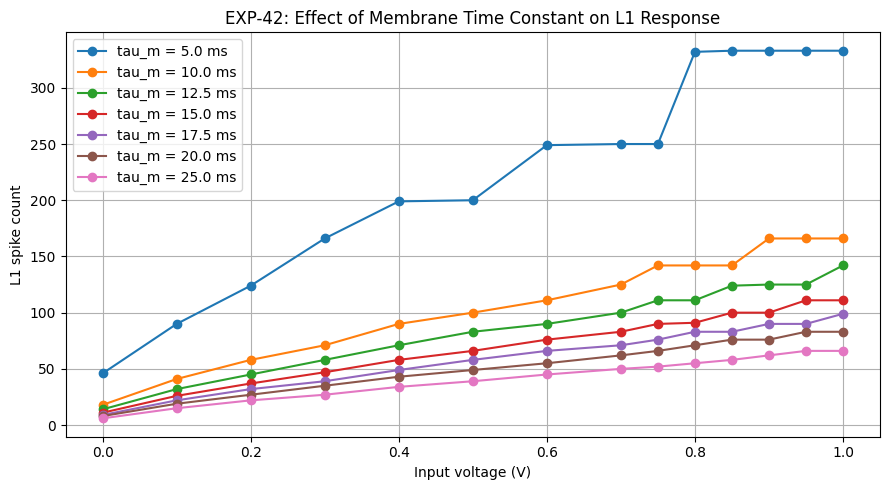

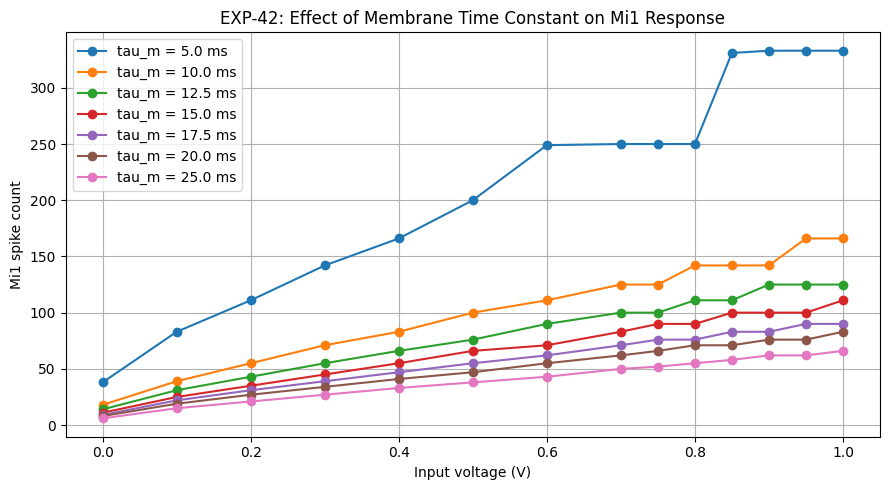

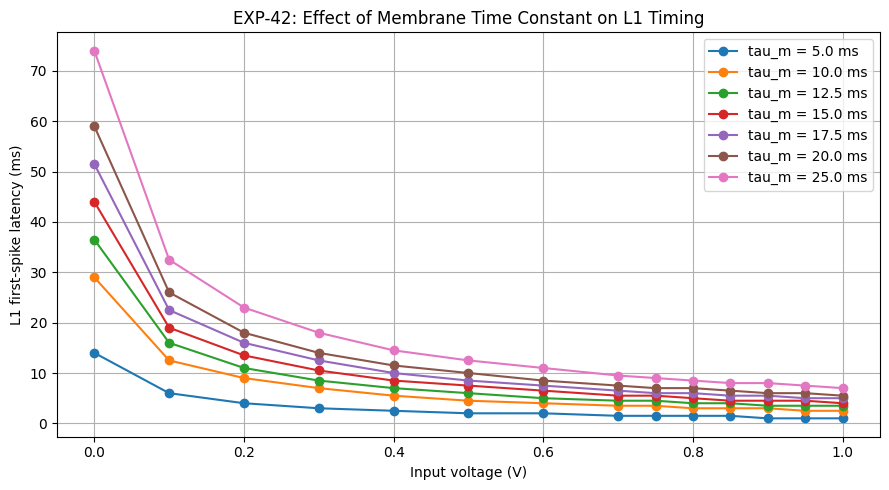


BEST HIGH-END SEPARATION
Best L1 separation: tau_m = 12.5 ms -> 31 spikes
Best Mi1 separation: tau_m = 5.0 ms -> 83 spikes

EXP-42 COMPLETE


In [161]:
# ============================================================
# EXP-42: LIF MEMBRANE TIME-CONSTANT SWEEP
# ============================================================
#
# Question:
# Can changing the membrane time constant of the LIF neurons
# improve the high-voltage neural representation?
#
# Current model:
#     TAU_M_MS = 15 ms
#
# Everything else is kept fixed:
#     drive       = 0.30 -> 1.00
#     G_DRIVE_OFF = 0.15
#     W_SCALE     = 0.06
#     tau_syn     = 5 ms
#
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 70)
print("EXP-42: LIF MEMBRANE TIME-CONSTANT SWEEP")
print("=" * 70)


# ------------------------------------------------------------
# 1. Voltage sweep
# ------------------------------------------------------------

voltages_42 = np.array([
    0.00,
    0.10,
    0.20,
    0.30,
    0.40,
    0.50,
    0.60,
    0.70,
    0.75,
    0.80,
    0.85,
    0.90,
    0.95,
    1.00
])


# ------------------------------------------------------------
# 2. Membrane time constants
# ------------------------------------------------------------

TAU_M_VALUES_42 = [
    5.0,
    10.0,
    12.5,
    15.0,     # current model
    17.5,
    20.0,
    25.0
]


# ------------------------------------------------------------
# 3. Feature extraction
# ------------------------------------------------------------

def extract_features_42(
    spike_mon,
    neuron_id,
    neuron_name
):

    idx = neuron_id.get(neuron_name)

    if idx is None:
        return 0, np.nan, np.nan

    spike_times = np.asarray(
        spike_mon.spike_trains()[idx] / ms
    )

    spike_count = len(spike_times)

    if spike_count == 0:
        return 0, np.nan, np.nan

    first_latency = float(
        spike_times[0]
    )

    if spike_count >= 2:
        mean_isi = float(
            np.mean(np.diff(spike_times))
        )
    else:
        mean_isi = np.nan

    return (
        spike_count,
        first_latency,
        mean_isi
    )


# ------------------------------------------------------------
# 4. Save current tau_m
# ------------------------------------------------------------

original_tau_m = TAU_M_MS


# ------------------------------------------------------------
# 5. Run experiment
# ------------------------------------------------------------

results_42 = []


for tau_value in TAU_M_VALUES_42:

    print("\n" + "-" * 70)
    print(
        f"Testing TAU_M = {tau_value:.1f} ms"
    )
    print("-" * 70)

    # Change global parameter used by run_simulation_v1()
    TAU_M_MS = tau_value

    for voltage in voltages_42:

        # Original input-drive mapping
        drive = voltage_to_drive(
            voltage,
            v_min=0.0,
            v_max=1.0,
            drive_min=0.30,
            drive_max=1.00
        )

        # ----------------------------------------------------
        # Run model
        # ----------------------------------------------------

        smon, _, elapsed_ms, _ = run_simulation_v1(
            ['L1', 'Mi1'],
            neuron_id100,
            W100_4bit,
            thr100,
            N100,
            duration_ms=500,
            g_drive_on=drive,
            g_drive_off=0.15,
            w_scale=0.06
        )

        # ----------------------------------------------------
        # L1
        # ----------------------------------------------------

        l1_n, l1_first, l1_isi = (
            extract_features_42(
                smon,
                neuron_id100,
                'L1'
            )
        )

        # ----------------------------------------------------
        # Mi1
        # ----------------------------------------------------

        mi1_n, mi1_first, mi1_isi = (
            extract_features_42(
                smon,
                neuron_id100,
                'Mi1'
            )
        )

        results_42.append([
            tau_value,
            voltage,
            drive,
            l1_n,
            l1_first,
            l1_isi,
            mi1_n,
            mi1_first,
            mi1_isi,
            elapsed_ms
        ])

        print(
            f"V={voltage:.2f} | "
            f"drive={drive:.3f} | "
            f"L1={l1_n:3d} "
            f"(first={l1_first:5.1f}) | "
            f"Mi1={mi1_n:3d} "
            f"(first={mi1_first:5.1f})"
        )


# Restore original model parameter
TAU_M_MS = original_tau_m


results_42 = np.asarray(
    results_42
)


# ------------------------------------------------------------
# 6. High-voltage separation
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("HIGH-VOLTAGE SEPARATION")
print("=" * 70)

print(
    f"{'TAU_M':>8} "
    f"{'L1@0.8V':>10} "
    f"{'L1@1.0V':>10} "
    f"{'ΔL1':>8} "
    f"{'Mi1@0.8V':>10} "
    f"{'Mi1@1.0V':>10} "
    f"{'ΔMi1':>8}"
)


separation_results_42 = []


for tau_value in TAU_M_VALUES_42:

    subset = results_42[
        np.isclose(
            results_42[:, 0],
            tau_value
        )
    ]

    l1_08 = subset[
        np.isclose(
            subset[:, 1],
            0.80
        )
    ][0, 3]

    l1_10 = subset[
        np.isclose(
            subset[:, 1],
            1.00
        )
    ][0, 3]

    mi1_08 = subset[
        np.isclose(
            subset[:, 1],
            0.80
        )
    ][0, 6]

    mi1_10 = subset[
        np.isclose(
            subset[:, 1],
            1.00
        )
    ][0, 6]

    delta_l1 = l1_10 - l1_08
    delta_mi1 = mi1_10 - mi1_08

    separation_results_42.append([
        tau_value,
        delta_l1,
        delta_mi1
    ])

    print(
        f"{tau_value:8.1f} "
        f"{int(l1_08):10d} "
        f"{int(l1_10):10d} "
        f"{int(delta_l1):8d} "
        f"{int(mi1_08):10d} "
        f"{int(mi1_10):10d} "
        f"{int(delta_mi1):8d}"
    )


# ------------------------------------------------------------
# 7. Monotonicity
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("MONOTONICITY")
print("=" * 70)


for tau_value in TAU_M_VALUES_42:

    subset = results_42[
        np.isclose(
            results_42[:, 0],
            tau_value
        )
    ]

    l1_counts = subset[:, 3]
    mi1_counts = subset[:, 6]

    l1_mono = np.all(
        np.diff(l1_counts) >= 0
    )

    mi1_mono = np.all(
        np.diff(mi1_counts) >= 0
    )

    print(
        f"TAU_M={tau_value:5.1f} ms | "
        f"L1={l1_mono} | "
        f"Mi1={mi1_mono}"
    )


# ------------------------------------------------------------
# 8. L1 spike-count graph
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

for tau_value in TAU_M_VALUES_42:

    subset = results_42[
        np.isclose(
            results_42[:, 0],
            tau_value
        )
    ]

    plt.plot(
        subset[:, 1],
        subset[:, 3],
        marker='o',
        label=f"tau_m = {tau_value:.1f} ms"
    )

plt.xlabel("Input voltage (V)")
plt.ylabel("L1 spike count")
plt.title(
    "EXP-42: Effect of Membrane Time Constant on L1 Response"
)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Mi1 spike-count graph
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

for tau_value in TAU_M_VALUES_42:

    subset = results_42[
        np.isclose(
            results_42[:, 0],
            tau_value
        )
    ]

    plt.plot(
        subset[:, 1],
        subset[:, 6],
        marker='o',
        label=f"tau_m = {tau_value:.1f} ms"
    )

plt.xlabel("Input voltage (V)")
plt.ylabel("Mi1 spike count")
plt.title(
    "EXP-42: Effect of Membrane Time Constant on Mi1 Response"
)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. L1 first-spike latency graph
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

for tau_value in TAU_M_VALUES_42:

    subset = results_42[
        np.isclose(
            results_42[:, 0],
            tau_value
        )
    ]

    plt.plot(
        subset[:, 1],
        subset[:, 4],
        marker='o',
        label=f"tau_m = {tau_value:.1f} ms"
    )

plt.xlabel("Input voltage (V)")
plt.ylabel("L1 first-spike latency (ms)")
plt.title(
    "EXP-42: Effect of Membrane Time Constant on L1 Timing"
)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. Find best high-end separation
# ------------------------------------------------------------

separation_results_42 = np.asarray(
    separation_results_42
)

best_l1_idx = np.argmax(
    separation_results_42[:, 1]
)

best_mi1_idx = np.argmax(
    separation_results_42[:, 2]
)

print("\n" + "=" * 70)
print("BEST HIGH-END SEPARATION")
print("=" * 70)

print(
    f"Best L1 separation: "
    f"tau_m = {separation_results_42[best_l1_idx,0]:.1f} ms "
    f"-> {separation_results_42[best_l1_idx,1]:.0f} spikes"
)

print(
    f"Best Mi1 separation: "
    f"tau_m = {separation_results_42[best_mi1_idx,0]:.1f} ms "
    f"-> {separation_results_42[best_mi1_idx,2]:.0f} spikes"
)


print("\n" + "=" * 70)
print("EXP-42 COMPLETE")
print("=" * 70)

EXP-42B: TEMPORAL ADC VALIDATION + SATURATION ANALYSIS
Training points   : 101
Validation points : 200


TAU_M = 10.0 ms

Generating training features...


WARNING    'v' is an internal variable of group 'neurongroup_6', but also exists in the run namespace with the value array([0.00239717, 0.00333561, 0.02300257, ..., 0.9917593 , 0.99629933,
       0.99739846]). The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


    20/101 simulations complete
    40/101 simulations complete
    60/101 simulations complete
    80/101 simulations complete
    100/101 simulations complete

Generating validation features...
    20/200 simulations complete
    40/200 simulations complete
    60/200 simulations complete
    80/200 simulations complete
    100/200 simulations complete
    120/200 simulations complete
    140/200 simulations complete
    160/200 simulations complete
    180/200 simulations complete
    200/200 simulations complete

RESULTS
Analog MAE      : 0.006029 V
Analog RMSE     : 0.009600 V
Analog max      : 0.035686 V
6-bit MAE       : 0.007526 V
6-bit RMSE      : 0.010201 V
6-bit max       : 0.038497 V
Unique codes    : 50/64
Code range      : 0–61
Analog monotonic: True
Code monotonic  : True


TAU_M = 12.5 ms

Generating training features...
    20/101 simulations complete
    40/101 simulations complete
    60/101 simulations complete
    80/101 simulations complete
    100/101 simulations

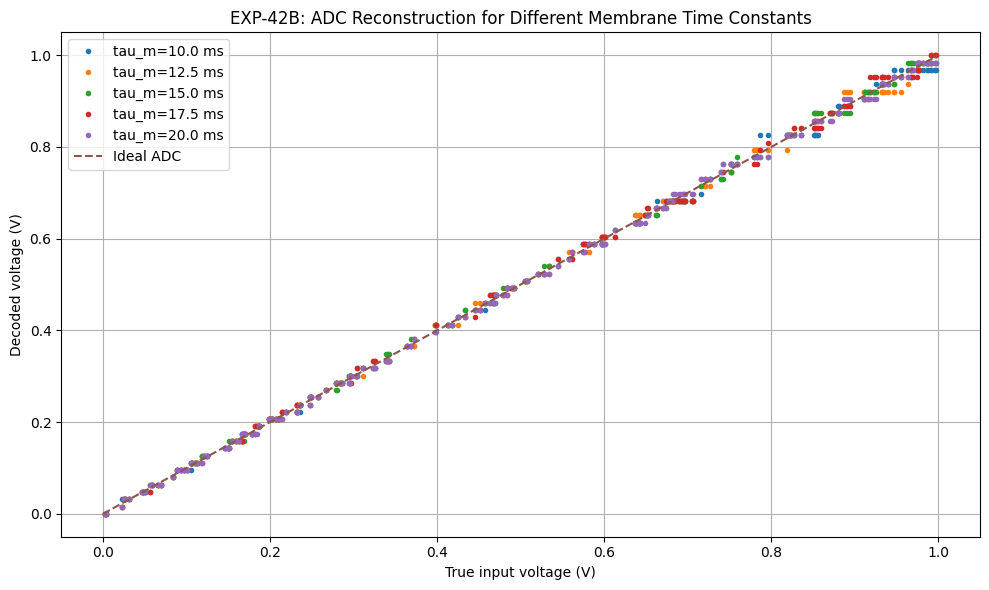

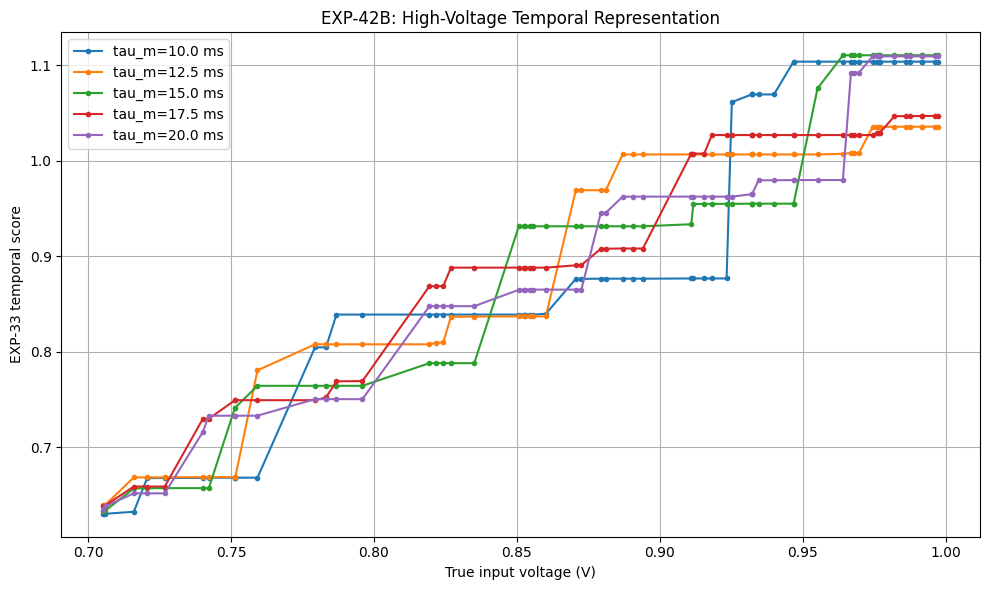

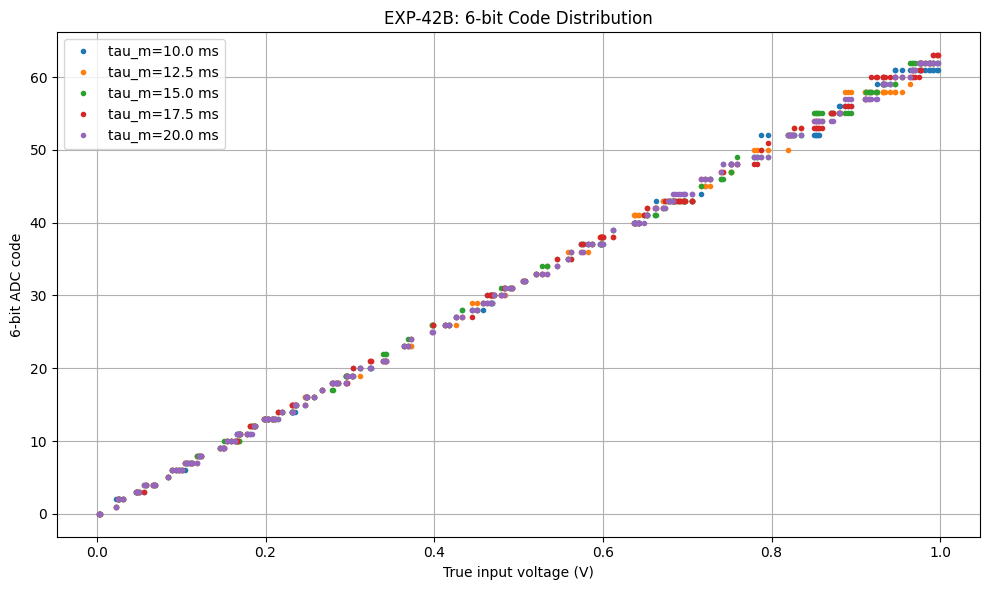



EXP-42B COMPLETE


In [162]:
# ============================================================
# EXP-42B
# TEMPORAL ADC VALIDATION + HIGH-END SATURATION ANALYSIS
# ============================================================
#
# Combines:
#   EXP-33 -> actual ADC performance
#   EXP-39 -> high-voltage saturation diagnostics
#
# Candidates:
#   tau_m = 10, 12.5, 15, 17.5, 20 ms
#
# 15 ms = current baseline
#
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.isotonic import IsotonicRegression

print("=" * 75)
print("EXP-42B: TEMPORAL ADC VALIDATION + SATURATION ANALYSIS")
print("=" * 75)


# ============================================================
# 1. SETTINGS
# ============================================================

TAU_CANDIDATES_42B = [
    10.0,
    12.5,
    15.0,
    17.5,
    20.0
]

# Training set used by EXP-33
train_voltages_42B = np.linspace(
    0.0,
    1.0,
    101
)

# Independent validation set used previously
np.random.seed(2026)

validation_voltages_42B = np.random.uniform(
    0,
    1,
    200
)

validation_voltages_42B = np.sort(
    validation_voltages_42B
)

print(
    f"Training points   : {len(train_voltages_42B)}"
)

print(
    f"Validation points : {len(validation_voltages_42B)}"
)


# ============================================================
# 2. FEATURE EXTRACTION
# ============================================================

def extract_features_42B(
    spike_mon,
    neuron_id,
    neuron_name
):

    idx = neuron_id.get(neuron_name)

    if idx is None:
        return 0.0, np.nan, np.nan

    spike_times = np.asarray(
        spike_mon.spike_trains()[idx] / ms
    )

    n = len(spike_times)

    if n == 0:
        return 0.0, np.nan, np.nan

    first_latency = float(
        spike_times[0]
    )

    if n >= 2:
        mean_isi = float(
            np.mean(np.diff(spike_times))
        )
    else:
        mean_isi = np.nan

    return (
        float(n),
        first_latency,
        mean_isi
    )


# ============================================================
# 3. RUN FLY MODEL
# ============================================================

def generate_features_42B(
    voltage_array,
    tau_m_value
):

    global TAU_M_MS

    TAU_M_MS = tau_m_value

    features = []

    for i, voltage in enumerate(
        voltage_array
    ):

        drive = voltage_to_drive(
            voltage,
            v_min=0.0,
            v_max=1.0,
            drive_min=0.30,
            drive_max=1.00
        )

        smon, _, elapsed_ms, _ = (
            run_simulation_v1(
                ['L1', 'Mi1'],
                neuron_id100,
                W100_4bit,
                thr100,
                N100,
                duration_ms=500,
                g_drive_on=drive,
                g_drive_off=0.15,
                w_scale=0.06
            )
        )

        # L1
        l1_n, l1_first, l1_isi = (
            extract_features_42B(
                smon,
                neuron_id100,
                'L1'
            )
        )

        # Mi1
        mi1_n, mi1_first, mi1_isi = (
            extract_features_42B(
                smon,
                neuron_id100,
                'Mi1'
            )
        )

        features.append([
            mi1_n,
            l1_first,
            l1_isi
        ])

        if (i + 1) % 20 == 0:
            print(
                f"    {i+1}/{len(voltage_array)} "
                f"simulations complete"
            )

    return np.asarray(features)


# ============================================================
# 4. EXP-33 DECODER
# ============================================================

def exp33_decode(
    X_train,
    y_train,
    X_val
):

    # --------------------------------------------------------
    # Training statistics ONLY
    # --------------------------------------------------------

    train_mean = np.nanmean(
        X_train,
        axis=0
    )

    train_std = np.nanstd(
        X_train,
        axis=0
    )

    train_std[
        train_std == 0
    ] = 1.0

    # --------------------------------------------------------
    # Normalize
    # --------------------------------------------------------

    X_train_norm = (
        X_train - train_mean
    ) / train_std

    X_val_norm = (
        X_val - train_mean
    ) / train_std

    # --------------------------------------------------------
    # EXP-33 feature directions
    #
    # Feature 0 = Mi1 spike count
    # Feature 1 = L1 first latency
    # Feature 2 = L1 mean ISI
    #
    # More spikes = higher voltage
    # Lower latency = higher voltage
    # Lower ISI = higher voltage
    # --------------------------------------------------------

    X_train_score = np.column_stack([
        X_train_norm[:, 0],
        -X_train_norm[:, 1],
        -X_train_norm[:, 2]
    ])

    X_val_score = np.column_stack([
        X_val_norm[:, 0],
        -X_val_norm[:, 1],
        -X_val_norm[:, 2]
    ])

    # --------------------------------------------------------
    # Composite score
    # --------------------------------------------------------

    train_score = np.nanmean(
        X_train_score,
        axis=1
    )

    val_score = np.nanmean(
        X_val_score,
        axis=1
    )

    # --------------------------------------------------------
    # Isotonic regression
    # --------------------------------------------------------

    iso = IsotonicRegression(
        increasing=True,
        out_of_bounds="clip"
    )

    iso.fit(
        train_score,
        y_train
    )

    train_pred = iso.predict(
        train_score
    )

    val_pred = iso.predict(
        val_score
    )

    # --------------------------------------------------------
    # 6-bit ADC
    # --------------------------------------------------------

    val_codes = np.clip(
        np.round(
            val_pred * 63
        ),
        0,
        63
    ).astype(int)

    val_decoded = (
        val_codes / 63.0
    )

    return (
        train_score,
        val_score,
        train_pred,
        val_pred,
        val_codes,
        val_decoded
    )


# ============================================================
# 5. METRIC HELPER
# ============================================================

def calculate_metrics_42B(
    true_v,
    analog_pred,
    codes,
    decoded
):

    analog_error = (
        analog_pred - true_v
    )

    adc_error = (
        decoded - true_v
    )

    mae = np.mean(
        np.abs(analog_error)
    )

    rmse = np.sqrt(
        np.mean(
            analog_error ** 2
        )
    )

    max_error = np.max(
        np.abs(analog_error)
    )

    adc_mae = np.mean(
        np.abs(adc_error)
    )

    adc_rmse = np.sqrt(
        np.mean(
            adc_error ** 2
        )
    )

    adc_max = np.max(
        np.abs(adc_error)
    )

    unique_codes = len(
        np.unique(codes)
    )

    monotonic_analog = np.all(
        np.diff(analog_pred) >= -1e-12
    )

    monotonic_codes = np.all(
        np.diff(codes) >= 0
    )

    return {
        "analog_mae": mae,
        "analog_rmse": rmse,
        "analog_max": max_error,
        "adc_mae": adc_mae,
        "adc_rmse": adc_rmse,
        "adc_max": adc_max,
        "unique_codes": unique_codes,
        "analog_monotonic": monotonic_analog,
        "code_monotonic": monotonic_codes,
        "code_min": int(np.min(codes)),
        "code_max": int(np.max(codes))
    }


# ============================================================
# 6. RUN ALL TAU VALUES
# ============================================================

all_results_42B = {}

original_tau_m_42B = TAU_M_MS

for tau_value in TAU_CANDIDATES_42B:

    print("\n")
    print("=" * 75)
    print(
        f"TAU_M = {tau_value:.1f} ms"
    )
    print("=" * 75)

    # --------------------------------------------------------
    # Training simulations
    # --------------------------------------------------------

    print("\nGenerating training features...")

    X_train = generate_features_42B(
        train_voltages_42B,
        tau_value
    )

    # --------------------------------------------------------
    # Validation simulations
    # --------------------------------------------------------

    print("\nGenerating validation features...")

    X_val = generate_features_42B(
        validation_voltages_42B,
        tau_value
    )

    # --------------------------------------------------------
    # Decode
    # --------------------------------------------------------

    (
        train_score,
        val_score,
        train_pred,
        val_pred,
        val_codes,
        val_decoded
    ) = exp33_decode(
        X_train,
        train_voltages_42B,
        X_val
    )

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    metrics = calculate_metrics_42B(
        validation_voltages_42B,
        val_pred,
        val_codes,
        val_decoded
    )

    all_results_42B[tau_value] = {
        "X_train": X_train,
        "X_val": X_val,
        "train_score": train_score,
        "val_score": val_score,
        "train_pred": train_pred,
        "val_pred": val_pred,
        "codes": val_codes,
        "decoded": val_decoded,
        "metrics": metrics
    }

    print("\nRESULTS")

    print(
        f"Analog MAE      : "
        f"{metrics['analog_mae']:.6f} V"
    )

    print(
        f"Analog RMSE     : "
        f"{metrics['analog_rmse']:.6f} V"
    )

    print(
        f"Analog max      : "
        f"{metrics['analog_max']:.6f} V"
    )

    print(
        f"6-bit MAE       : "
        f"{metrics['adc_mae']:.6f} V"
    )

    print(
        f"6-bit RMSE      : "
        f"{metrics['adc_rmse']:.6f} V"
    )

    print(
        f"6-bit max       : "
        f"{metrics['adc_max']:.6f} V"
    )

    print(
        f"Unique codes    : "
        f"{metrics['unique_codes']}/64"
    )

    print(
        f"Code range      : "
        f"{metrics['code_min']}–"
        f"{metrics['code_max']}"
    )

    print(
        f"Analog monotonic: "
        f"{metrics['analog_monotonic']}"
    )

    print(
        f"Code monotonic  : "
        f"{metrics['code_monotonic']}"
    )


# Restore baseline
TAU_M_MS = original_tau_m_42B


# ============================================================
# 7. COMPARISON TABLE
# ============================================================

print("\n")
print("=" * 95)
print("EXP-42B COMPARISON")
print("=" * 95)

print(
    f"{'tau_m':>7} "
    f"{'MAE':>10} "
    f"{'RMSE':>10} "
    f"{'6b MAE':>10} "
    f"{'6b RMSE':>10} "
    f"{'Codes':>8} "
    f"{'Mono':>7}"
)

for tau_value in TAU_CANDIDATES_42B:

    m = all_results_42B[
        tau_value
    ]["metrics"]

    print(
        f"{tau_value:7.1f} "
        f"{m['analog_mae']:10.6f} "
        f"{m['analog_rmse']:10.6f} "
        f"{m['adc_mae']:10.6f} "
        f"{m['adc_rmse']:10.6f} "
        f"{m['unique_codes']:8d} "
        f"{str(m['code_monotonic']):>7}"
    )


# ============================================================
# 8. EXP-39 HIGH-END SATURATION ANALYSIS
# ============================================================

print("\n")
print("=" * 95)
print("EXP-39 STYLE HIGH-END SATURATION ANALYSIS")
print("=" * 95)

for tau_value in TAU_CANDIDATES_42B:

    result = all_results_42B[
        tau_value
    ]

    val_v = validation_voltages_42B
    score = result["val_score"]
    codes = result["codes"]

    print("\n")
    print(
        f"TAU_M = {tau_value:.1f} ms"
    )

    # --------------------------------------------------------
    # High voltage region
    # --------------------------------------------------------

    mask = val_v >= 0.80

    print(
        "\nHigh-voltage score behaviour:"
    )

    high_v = val_v[mask]
    high_score = score[mask]
    high_codes = codes[mask]

    for v, s, c in zip(
        high_v,
        high_score,
        high_codes
    ):

        print(
            f"V={v:.4f} | "
            f"score={s:.6f} | "
            f"code={c}"
        )

    # --------------------------------------------------------
    # Code occupancy
    # --------------------------------------------------------

    print(
        "\nHigh-end code occupancy:"
    )

    high_codes_unique = np.unique(
        high_codes
    )

    for code in high_codes_unique:

        mask_code = (
            high_codes == code
        )

        print(
            f"Code {code:2d}: "
            f"{np.sum(mask_code):3d} samples | "
            f"V={high_v[mask_code].min():.4f}"
            f" -> "
            f"{high_v[mask_code].max():.4f}"
        )

    # --------------------------------------------------------
    # Missing high-end codes
    # --------------------------------------------------------

    missing_high = [
        c for c in range(45, 64)
        if c not in np.unique(codes)
    ]

    print(
        "\nMissing codes 45-63:"
    )

    print(
        missing_high
    )


# ============================================================
# 9. PLOT ADC OUTPUT VS TRUE VOLTAGE
# ============================================================

plt.figure(figsize=(10, 6))

for tau_value in TAU_CANDIDATES_42B:

    result = all_results_42B[
        tau_value
    ]

    plt.plot(
        validation_voltages_42B,
        result["decoded"],
        marker='.',
        linestyle='',
        label=f"tau_m={tau_value:.1f} ms"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label="Ideal ADC"
)

plt.xlabel("True input voltage (V)")
plt.ylabel("Decoded voltage (V)")
plt.title(
    "EXP-42B: ADC Reconstruction for Different Membrane Time Constants"
)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 10. PLOT HIGH-END TEMPORAL SCORE
# ============================================================

plt.figure(figsize=(10, 6))

for tau_value in TAU_CANDIDATES_42B:

    result = all_results_42B[
        tau_value
    ]

    mask = validation_voltages_42B >= 0.70

    plt.plot(
        validation_voltages_42B[mask],
        result["val_score"][mask],
        marker='o',
        markersize=3,
        label=f"tau_m={tau_value:.1f} ms"
    )

plt.xlabel("True input voltage (V)")
plt.ylabel("EXP-33 temporal score")
plt.title(
    "EXP-42B: High-Voltage Temporal Representation"
)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# 11. PLOT 6-BIT CODE VS VOLTAGE
# ============================================================

plt.figure(figsize=(10, 6))

for tau_value in TAU_CANDIDATES_42B:

    result = all_results_42B[
        tau_value
    ]

    plt.plot(
        validation_voltages_42B,
        result["codes"],
        marker='.',
        linestyle='',
        label=f"tau_m={tau_value:.1f} ms"
    )

plt.xlabel("True input voltage (V)")
plt.ylabel("6-bit ADC code")
plt.title(
    "EXP-42B: 6-bit Code Distribution"
)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


print("\n")
print("=" * 75)
print("EXP-42B COMPLETE")
print("=" * 75)

EXP-42C: FINE SWEEP AROUND OPTIMAL TAU_M
Training points   : 101
Validation points : 200


TAU_M = 17.50 ms

Generating training features...
    20/101 simulations complete
    40/101 simulations complete
    60/101 simulations complete
    80/101 simulations complete
    100/101 simulations complete

Generating validation features...
    20/200 simulations complete
    40/200 simulations complete
    60/200 simulations complete
    80/200 simulations complete
    100/200 simulations complete
    120/200 simulations complete
    140/200 simulations complete
    160/200 simulations complete
    180/200 simulations complete
    200/200 simulations complete

RESULTS
Analog MAE      : 0.004943 V
Analog RMSE     : 0.007376 V
Analog max      : 0.029471 V
6-bit MAE       : 0.007175 V
6-bit RMSE      : 0.009166 V
6-bit max       : 0.034159 V
Unique codes    : 54/64
Code range      : 0-63
Analog monotonic: True
Code monotonic  : True


TAU_M = 18.75 ms

Generating training features...
    20/10

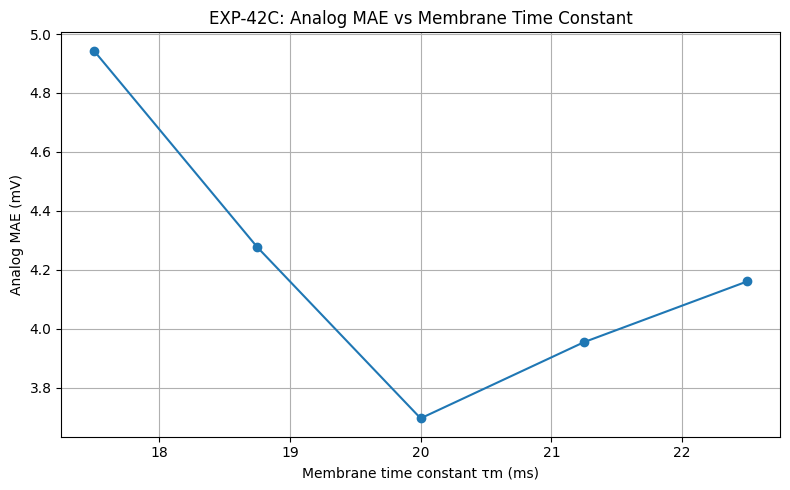

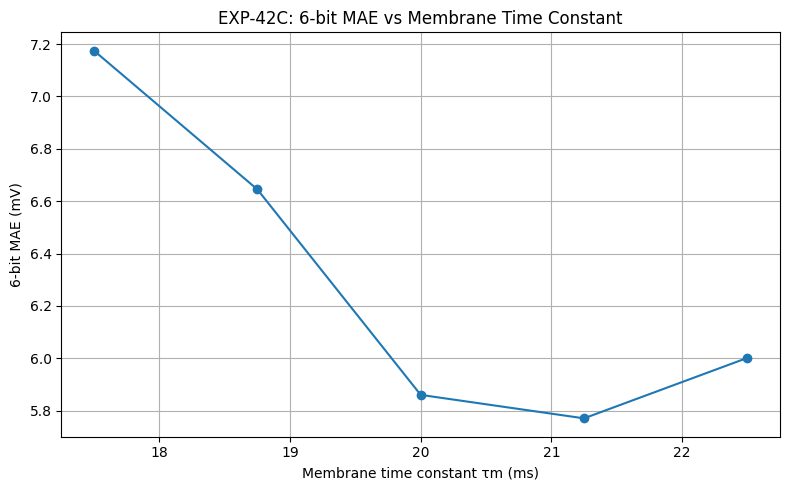

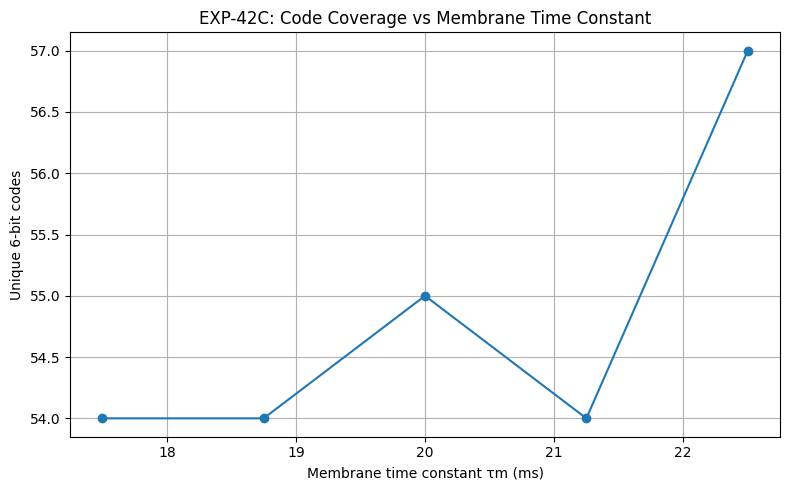

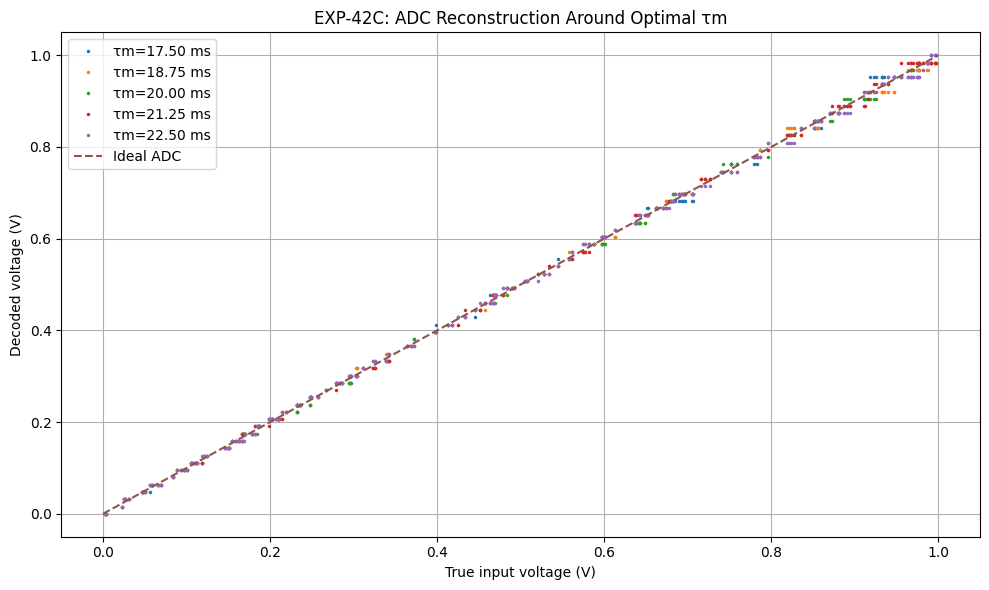

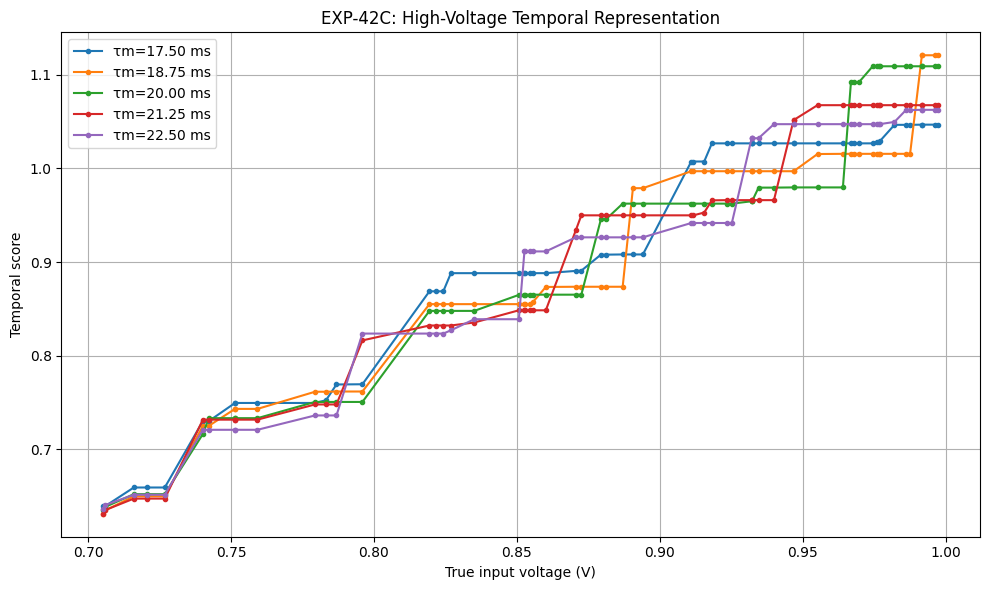



HIGH-END CODE OCCUPANCY


TAU_M = 17.50 ms
Code 52:   3 samples | V=0.8194 -> 0.8243
Code 53:   8 samples | V=0.8269 -> 0.8601
Code 55:   4 samples | V=0.8706 -> 0.8811
Code 56:   3 samples | V=0.8870 -> 0.8941
Code 57:   3 samples | V=0.9110 -> 0.9155
Code 60:  16 samples | V=0.9182 -> 0.9745
Code 61:   2 samples | V=0.9759 -> 0.9766
Code 62:   4 samples | V=0.9769 -> 0.9876
Code 63:   4 samples | V=0.9917 -> 0.9974


TAU_M = 18.75 ms
Code 53:  10 samples | V=0.8194 -> 0.8557
Code 54:   1 samples | V=0.8601 -> 0.8601
Code 55:   5 samples | V=0.8706 -> 0.8870
Code 56:   2 samples | V=0.8906 -> 0.8941
Code 58:  13 samples | V=0.9110 -> 0.9468
Code 60:   1 samples | V=0.9552 -> 0.9552
Code 61:  11 samples | V=0.9640 -> 0.9876
Code 62:   4 samples | V=0.9917 -> 0.9974


TAU_M = 20.00 ms
Code 52:   5 samples | V=0.8194 -> 0.8351
Code 54:   8 samples | V=0.8507 -> 0.8726
Code 55:   2 samples | V=0.8794 -> 0.8811
Code 57:   9 samples | V=0.8870 -> 0.9252
Code 59:   5 samples | V=0.9321 -> 

In [163]:
# ============================================================
# EXP-42C
# FINE SWEEP OF MEMBRANE TIME CONSTANT
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 75)
print("EXP-42C: FINE SWEEP AROUND OPTIMAL TAU_M")
print("=" * 75)

# ------------------------------------------------------------
# Candidate values
# ------------------------------------------------------------

TAU_CANDIDATES_42C = [
    17.5,
    18.75,
    20.0,
    21.25,
    22.5
]

# Use the SAME voltage sets as EXP-42B
train_voltages_42C = np.linspace(0.0, 1.0, 101)

np.random.seed(2026)

validation_voltages_42C = np.random.uniform(
    0,
    1,
    200
)

validation_voltages_42C = np.sort(
    validation_voltages_42C
)

print(
    f"Training points   : {len(train_voltages_42C)}"
)

print(
    f"Validation points : {len(validation_voltages_42C)}"
)


# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------

all_results_42C = {}


# ============================================================
# RUN SWEEP
# ============================================================

for tau_value in TAU_CANDIDATES_42C:

    print("\n")
    print("=" * 75)
    print(f"TAU_M = {tau_value:.2f} ms")
    print("=" * 75)

    # --------------------------------------------------------
    # Training
    # --------------------------------------------------------

    print("\nGenerating training features...")

    X_train = generate_features_42B(
        train_voltages_42C,
        tau_value
    )

    # --------------------------------------------------------
    # Independent validation
    # --------------------------------------------------------

    print("\nGenerating validation features...")

    X_val = generate_features_42B(
        validation_voltages_42C,
        tau_value
    )

    # --------------------------------------------------------
    # EXP-33 decoder
    # --------------------------------------------------------

    (
        train_score,
        val_score,
        train_pred,
        val_pred,
        val_codes,
        val_decoded
    ) = exp33_decode(
        X_train,
        train_voltages_42C,
        X_val
    )

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    metrics = calculate_metrics_42B(
        validation_voltages_42C,
        val_pred,
        val_codes,
        val_decoded
    )

    all_results_42C[tau_value] = {
        "X_train": X_train,
        "X_val": X_val,
        "train_score": train_score,
        "val_score": val_score,
        "train_pred": train_pred,
        "val_pred": val_pred,
        "codes": val_codes,
        "decoded": val_decoded,
        "metrics": metrics
    }

    print("\nRESULTS")

    print(
        f"Analog MAE      : "
        f"{metrics['analog_mae']:.6f} V"
    )

    print(
        f"Analog RMSE     : "
        f"{metrics['analog_rmse']:.6f} V"
    )

    print(
        f"Analog max      : "
        f"{metrics['analog_max']:.6f} V"
    )

    print(
        f"6-bit MAE       : "
        f"{metrics['adc_mae']:.6f} V"
    )

    print(
        f"6-bit RMSE      : "
        f"{metrics['adc_rmse']:.6f} V"
    )

    print(
        f"6-bit max       : "
        f"{metrics['adc_max']:.6f} V"
    )

    print(
        f"Unique codes    : "
        f"{metrics['unique_codes']}/64"
    )

    print(
        f"Code range      : "
        f"{metrics['code_min']}-"
        f"{metrics['code_max']}"
    )

    print(
        f"Analog monotonic: "
        f"{metrics['analog_monotonic']}"
    )

    print(
        f"Code monotonic  : "
        f"{metrics['code_monotonic']}"
    )


# ============================================================
# COMPARISON TABLE
# ============================================================

print("\n")
print("=" * 100)
print("EXP-42C FINE-SWEEP COMPARISON")
print("=" * 100)

print(
    f"{'tau_m':>8} "
    f"{'MAE':>10} "
    f"{'RMSE':>10} "
    f"{'6b MAE':>10} "
    f"{'6b RMSE':>10} "
    f"{'Codes':>8} "
    f"{'Mono':>7}"
)

for tau_value in TAU_CANDIDATES_42C:

    m = all_results_42C[
        tau_value
    ]["metrics"]

    print(
        f"{tau_value:8.2f} "
        f"{m['analog_mae']:10.6f} "
        f"{m['analog_rmse']:10.6f} "
        f"{m['adc_mae']:10.6f} "
        f"{m['adc_rmse']:10.6f} "
        f"{m['unique_codes']:8d} "
        f"{str(m['code_monotonic']):>7}"
    )


# ============================================================
# FIND BEST CONFIGURATIONS
# ============================================================

best_analog = min(
    TAU_CANDIDATES_42C,
    key=lambda t:
        all_results_42C[t]["metrics"]["analog_mae"]
)

best_6bit = min(
    TAU_CANDIDATES_42C,
    key=lambda t:
        all_results_42C[t]["metrics"]["adc_mae"]
)

best_codes = max(
    TAU_CANDIDATES_42C,
    key=lambda t:
        all_results_42C[t]["metrics"]["unique_codes"]
)

print("\n")
print("=" * 75)
print("BEST CONFIGURATIONS")
print("=" * 75)

print(
    f"Best analog MAE : "
    f"tau_m = {best_analog:.2f} ms"
)

print(
    f"Best 6-bit MAE  : "
    f"tau_m = {best_6bit:.2f} ms"
)

print(
    f"Most codes      : "
    f"tau_m = {best_codes:.2f} ms"
)


# ============================================================
# PLOT 1: ANALOG MAE
# ============================================================

taus = np.array(
    TAU_CANDIDATES_42C
)

analog_mae = np.array([
    all_results_42C[t]["metrics"]["analog_mae"]
    for t in taus
])

adc_mae = np.array([
    all_results_42C[t]["metrics"]["adc_mae"]
    for t in taus
])

codes = np.array([
    all_results_42C[t]["metrics"]["unique_codes"]
    for t in taus
])

plt.figure(figsize=(8, 5))

plt.plot(
    taus,
    analog_mae * 1000,
    marker='o'
)

plt.xlabel("Membrane time constant τm (ms)")
plt.ylabel("Analog MAE (mV)")
plt.title("EXP-42C: Analog MAE vs Membrane Time Constant")
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# PLOT 2: 6-BIT MAE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    taus,
    adc_mae * 1000,
    marker='o'
)

plt.xlabel("Membrane time constant τm (ms)")
plt.ylabel("6-bit MAE (mV)")
plt.title("EXP-42C: 6-bit MAE vs Membrane Time Constant")
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# PLOT 3: CODE COVERAGE
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    taus,
    codes,
    marker='o'
)

plt.xlabel("Membrane time constant τm (ms)")
plt.ylabel("Unique 6-bit codes")
plt.title("EXP-42C: Code Coverage vs Membrane Time Constant")
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# PLOT 4: ADC RECONSTRUCTION
# ============================================================

plt.figure(figsize=(10, 6))

for tau_value in TAU_CANDIDATES_42C:

    result = all_results_42C[
        tau_value
    ]

    plt.plot(
        validation_voltages_42C,
        result["decoded"],
        marker='.',
        linestyle='',
        markersize=3,
        label=f"τm={tau_value:.2f} ms"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label="Ideal ADC"
)

plt.xlabel("True input voltage (V)")
plt.ylabel("Decoded voltage (V)")
plt.title(
    "EXP-42C: ADC Reconstruction Around Optimal τm"
)

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# PLOT 5: HIGH-END TEMPORAL SCORE
# ============================================================

plt.figure(figsize=(10, 6))

for tau_value in TAU_CANDIDATES_42C:

    result = all_results_42C[
        tau_value
    ]

    mask = (
        validation_voltages_42C >= 0.70
    )

    plt.plot(
        validation_voltages_42C[mask],
        result["val_score"][mask],
        marker='o',
        markersize=3,
        label=f"τm={tau_value:.2f} ms"
    )

plt.xlabel("True input voltage (V)")
plt.ylabel("Temporal score")
plt.title(
    "EXP-42C: High-Voltage Temporal Representation"
)

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# HIGH-END CODE OCCUPANCY
# ============================================================

print("\n")
print("=" * 100)
print("HIGH-END CODE OCCUPANCY")
print("=" * 100)

for tau_value in TAU_CANDIDATES_42C:

    result = all_results_42C[
        tau_value
    ]

    codes_val = result["codes"]

    mask = (
        validation_voltages_42C >= 0.80
    )

    high_v = validation_voltages_42C[mask]
    high_codes = codes_val[mask]

    print("\n")
    print(
        f"TAU_M = {tau_value:.2f} ms"
    )

    for code in np.unique(high_codes):

        code_mask = (
            high_codes == code
        )

        print(
            f"Code {code:2d}: "
            f"{np.sum(code_mask):3d} samples | "
            f"V={high_v[code_mask].min():.4f}"
            f" -> "
            f"{high_v[code_mask].max():.4f}"
        )


print("\n")
print("=" * 75)
print("EXP-42C COMPLETE")
print("=" * 75)

EXP-43: CONVERSION TIME / EFFECTIVE SAMPLING RATE
tau_m          = 20.0 ms
W_SCALE        = 0.06
Simulation     = 500 ms
Test voltages  = 10
Time resolution = 10.0 ms

Building EXP-33 decoder from training data...
EXP-33 decoder ready.


---------------------------------------------------------------------------
Testing V = 0.10
---------------------------------------------------------------------------
L1 spikes  = 19
Mi1 spikes = 19
Final code  = 6
Final analog = 0.100000 V
Conversion time = 320.0 ms
Effective rate  = 3.12 conversions/s


---------------------------------------------------------------------------
Testing V = 0.20
---------------------------------------------------------------------------
L1 spikes  = 27
Mi1 spikes = 27
Final code  = 13
Final analog = 0.200000 V
Conversion time = 500.0 ms
Effective rate  = 2.00 conversions/s


---------------------------------------------------------------------------
Testing V = 0.30
--------------------------------------------------

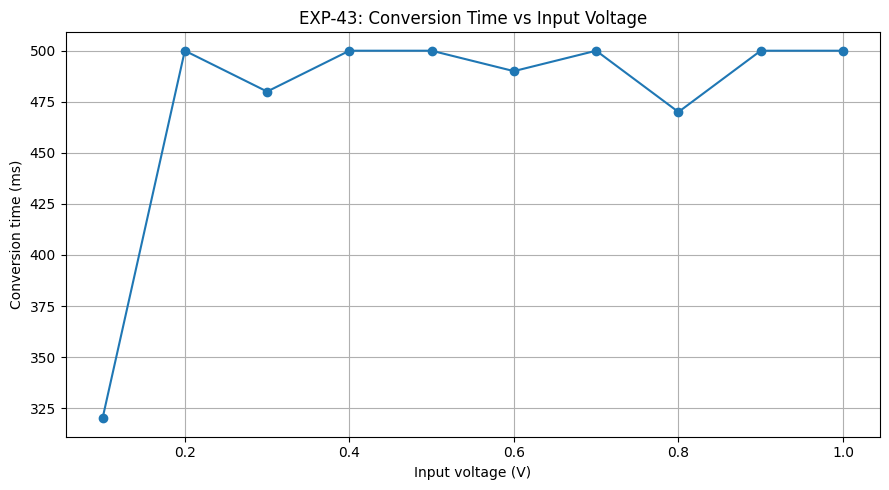

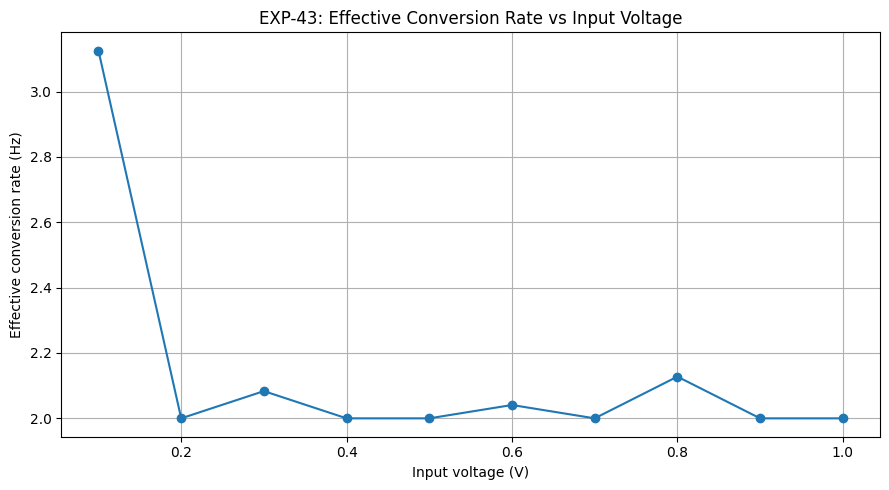

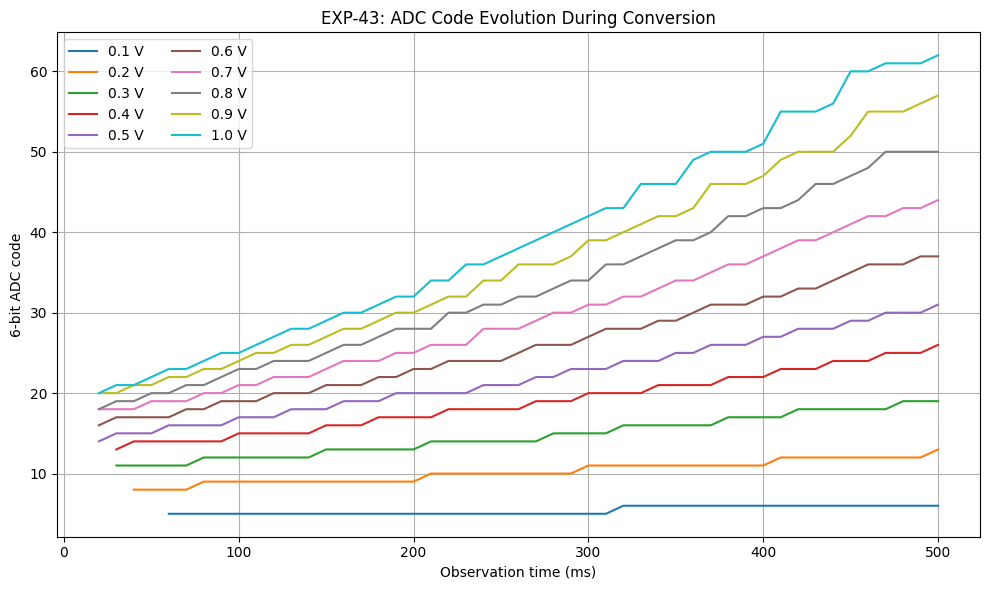



EXP-43 COMPLETE


In [164]:
# ============================================================
# EXP-43
# CONVERSION TIME / EFFECTIVE SAMPLING-RATE CHARACTERIZATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.isotonic import IsotonicRegression

print("=" * 75)
print("EXP-43: CONVERSION TIME / EFFECTIVE SAMPLING RATE")
print("=" * 75)


# ============================================================
# 1. FIXED OPTIMIZED CONFIGURATION
# ============================================================

TAU_M_MS = 20.0
W_SCALE_43 = 0.06
SIM_DURATION_MS = 500

TEST_VOLTAGES_43 = np.arange(
    0.1,
    1.01,
    0.1
)

TIME_STEP_MS = 10.0

TIME_POINTS_43 = np.arange(
    20.0,
    SIM_DURATION_MS + TIME_STEP_MS,
    TIME_STEP_MS
)

print(
    f"tau_m          = {TAU_M_MS} ms"
)

print(
    f"W_SCALE        = {W_SCALE_43}"
)

print(
    f"Simulation     = {SIM_DURATION_MS} ms"
)

print(
    f"Test voltages  = {len(TEST_VOLTAGES_43)}"
)

print(
    f"Time resolution = {TIME_STEP_MS} ms"
)


# ============================================================
# 2. BUILD EXP-33 DECODER FROM TRAINING DATA
# ============================================================

print("\nBuilding EXP-33 decoder from training data...")

X43_train = all_results_42C[
    20.0
]["X_train"]

y43_train = train_voltages_42C


# Training normalization
train_mean_43 = np.nanmean(
    X43_train,
    axis=0
)

train_std_43 = np.nanstd(
    X43_train,
    axis=0
)

train_std_43[
    train_std_43 == 0
] = 1.0


# Normalize
X43_train_norm = (
    X43_train - train_mean_43
) / train_std_43


# EXP-33 feature directions
#
# 0 = Mi1 spike count
# 1 = L1 first latency
# 2 = L1 mean ISI

X43_train_score_features = np.column_stack([
    X43_train_norm[:, 0],
    -X43_train_norm[:, 1],
    -X43_train_norm[:, 2]
])


# Composite temporal score
train_score_43 = np.nanmean(
    X43_train_score_features,
    axis=1
)


# Isotonic decoder
iso43 = IsotonicRegression(
    increasing=True,
    out_of_bounds="clip"
)

iso43.fit(
    train_score_43,
    y43_train
)


print("EXP-33 decoder ready.")


# ============================================================
# 3. HELPER TO EXTRACT SPIKE TIMES
# ============================================================

def get_spike_times_43(
    spike_mon,
    neuron_id,
    neuron_name
):

    idx = neuron_id.get(
        neuron_name
    )

    if idx is None:
        return np.array([])

    spike_times = np.asarray(
        spike_mon.spike_trains()[idx] / ms
    )

    return spike_times


# ============================================================
# 4. CALCULATE PARTIAL FEATURES
# ============================================================

def partial_features_43(
    l1_spikes,
    mi1_spikes,
    current_time
):

    # Spikes observed so far
    l1_current = (
        l1_spikes[
            l1_spikes <= current_time
        ]
    )

    mi1_current = (
        mi1_spikes[
            mi1_spikes <= current_time
        ]
    )

    # Mi1 spike count
    mi1_count = float(
        len(mi1_current)
    )

    # L1 first spike
    if len(l1_current) == 0:

        return (
            mi1_count,
            np.nan,
            np.nan,
            False
        )

    l1_first = float(
        l1_current[0]
    )

    # Need at least 2 L1 spikes for ISI
    if len(l1_current) < 2:

        return (
            mi1_count,
            l1_first,
            np.nan,
            False
        )

    l1_isi = float(
        np.mean(
            np.diff(l1_current)
        )
    )

    return (
        mi1_count,
        l1_first,
        l1_isi,
        True
    )


# ============================================================
# 5. DECODE PARTIAL FEATURES
# ============================================================

def decode_partial_43(
    features
):

    X = np.asarray(
        features,
        dtype=float
    ).reshape(1, -1)

    # Normalize using TRAINING statistics
    X_norm = (
        X - train_mean_43
    ) / train_std_43

    # EXP-33 directions
    score_features = np.column_stack([
        X_norm[:, 0],
        -X_norm[:, 1],
        -X_norm[:, 2]
    ])

    if np.any(
        ~np.isfinite(score_features)
    ):
        return (
            np.nan,
            np.nan,
            None
        )

    score = np.nanmean(
        score_features,
        axis=1
    )[0]

    analog = float(
        iso43.predict(
            [score]
        )[0]
    )

    code = int(
        np.clip(
            np.round(
                analog * 63
            ),
            0,
            63
        )
    )

    return (
        analog,
        score,
        code
    )


# ============================================================
# 6. RUN ONE LONG SIMULATION PER VOLTAGE
# ============================================================

conversion_results_43 = {}

for voltage in TEST_VOLTAGES_43:

    print("\n")
    print("-" * 75)
    print(
        f"Testing V = {voltage:.2f}"
    )
    print("-" * 75)

    drive = voltage_to_drive(
        voltage,
        v_min=0.0,
        v_max=1.0,
        drive_min=0.30,
        drive_max=1.00
    )

    # --------------------------------------------------------
    # One 500 ms simulation
    # --------------------------------------------------------

    smon, _, elapsed_ms, _ = (
        run_simulation_v1(
            ['L1', 'Mi1'],
            neuron_id100,
            W100_4bit,
            thr100,
            N100,
            duration_ms=SIM_DURATION_MS,
            g_drive_on=drive,
            g_drive_off=0.15,
            w_scale=W_SCALE_43
        )
    )

    # --------------------------------------------------------
    # Extract spike trains
    # --------------------------------------------------------

    l1_spikes = get_spike_times_43(
        smon,
        neuron_id100,
        "L1"
    )

    mi1_spikes = get_spike_times_43(
        smon,
        neuron_id100,
        "Mi1"
    )

    print(
        f"L1 spikes  = {len(l1_spikes)}"
    )

    print(
        f"Mi1 spikes = {len(mi1_spikes)}"
    )

    # --------------------------------------------------------
    # Determine final code
    # --------------------------------------------------------

    final_features = partial_features_43(
        l1_spikes,
        mi1_spikes,
        SIM_DURATION_MS
    )

    final_analog, final_score, final_code = (
        decode_partial_43(
            final_features[:3]
        )
    )

    print(
        f"Final code  = {final_code}"
    )

    print(
        f"Final analog = {final_analog:.6f} V"
    )

    # --------------------------------------------------------
    # Track code over time
    # --------------------------------------------------------

    timeline = []

    for t in TIME_POINTS_43:

        (
            mi1_count,
            l1_first,
            l1_isi,
            valid
        ) = partial_features_43(
            l1_spikes,
            mi1_spikes,
            t
        )

        if not valid:

            timeline.append({
                "time": t,
                "code": None,
                "analog": np.nan,
                "score": np.nan,
                "valid": False
            })

            continue

        analog, score, code = (
            decode_partial_43([
                mi1_count,
                l1_first,
                l1_isi
            ])
        )

        timeline.append({
            "time": t,
            "code": code,
            "analog": analog,
            "score": score,
            "valid": True
        })

    # --------------------------------------------------------
    # Find conversion time
    # --------------------------------------------------------

    conversion_time = np.nan

    for i in range(
        len(timeline)
    ):

        current = timeline[i]

        if not current["valid"]:
            continue

        current_code = current["code"]

        # Need the code to remain unchanged
        # until the end of the simulation
        stable = True

        for j in range(
            i,
            len(timeline)
        ):

            future = timeline[j]

            if not future["valid"]:
                stable = False
                break

            if future["code"] != current_code:
                stable = False
                break

        if stable:

            conversion_time = (
                current["time"]
            )

            break

    if np.isfinite(
        conversion_time
    ):

        effective_rate = (
            1000.0 /
            conversion_time
        )

        print(
            f"Conversion time = "
            f"{conversion_time:.1f} ms"
        )

        print(
            f"Effective rate  = "
            f"{effective_rate:.2f} conversions/s"
        )

    else:

        effective_rate = np.nan

        print(
            "No stable code reached "
            "within 500 ms"
        )

    conversion_results_43[
        voltage
    ] = {
        "l1_spikes": l1_spikes,
        "mi1_spikes": mi1_spikes,
        "timeline": timeline,
        "final_code": final_code,
        "final_analog": final_analog,
        "conversion_time_ms": conversion_time,
        "effective_rate_hz": effective_rate
    }


# ============================================================
# 7. SUMMARY
# ============================================================

print("\n")
print("=" * 90)
print("EXP-43 CONVERSION-TIME SUMMARY")
print("=" * 90)

print(
    f"{'Voltage':>10} "
    f"{'Final Code':>12} "
    f"{'Conv. Time(ms)':>16} "
    f"{'Rate (Hz)':>12}"
)

for voltage in TEST_VOLTAGES_43:

    result = conversion_results_43[
        voltage
    ]

    ct = result[
        "conversion_time_ms"
    ]

    rate = result[
        "effective_rate_hz"
    ]

    print(
        f"{voltage:10.2f} "
        f"{result['final_code']:12d} "
        f"{ct:16.1f} "
        f"{rate:12.2f}"
    )


# ============================================================
# 8. OVERALL CONVERSION METRICS
# ============================================================

conversion_times = np.array([
    conversion_results_43[v][
        "conversion_time_ms"
    ]
    for v in TEST_VOLTAGES_43
])

valid_times = conversion_times[
    np.isfinite(conversion_times)
]

if len(valid_times) > 0:

    print("\n")
    print("=" * 75)
    print("OVERALL CONVERSION PERFORMANCE")
    print("=" * 75)

    print(
        f"Fastest conversion : "
        f"{np.min(valid_times):.1f} ms"
    )

    print(
        f"Slowest conversion : "
        f"{np.max(valid_times):.1f} ms"
    )

    print(
        f"Mean conversion    : "
        f"{np.mean(valid_times):.1f} ms"
    )

    print(
        f"Effective max rate : "
        f"{1000/np.max(valid_times):.2f} Hz"
    )

    print(
        f"Mean rate          : "
        f"{np.mean(1000/valid_times):.2f} Hz"
    )


# ============================================================
# 9. PLOT CONVERSION TIME VS VOLTAGE
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    TEST_VOLTAGES_43,
    conversion_times,
    marker='o'
)

plt.xlabel(
    "Input voltage (V)"
)

plt.ylabel(
    "Conversion time (ms)"
)

plt.title(
    "EXP-43: Conversion Time vs Input Voltage"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 10. PLOT EFFECTIVE RATE
# ============================================================

rates = np.array([
    conversion_results_43[v][
        "effective_rate_hz"
    ]
    for v in TEST_VOLTAGES_43
])

plt.figure(figsize=(9, 5))

plt.plot(
    TEST_VOLTAGES_43,
    rates,
    marker='o'
)

plt.xlabel(
    "Input voltage (V)"
)

plt.ylabel(
    "Effective conversion rate (Hz)"
)

plt.title(
    "EXP-43: Effective Conversion Rate vs Input Voltage"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 11. CODE EVOLUTION
# ============================================================

plt.figure(figsize=(10, 6))

for voltage in TEST_VOLTAGES_43:

    result = conversion_results_43[
        voltage
    ]

    valid_t = []
    valid_code = []

    for item in result["timeline"]:

        if item["valid"]:

            valid_t.append(
                item["time"]
            )

            valid_code.append(
                item["code"]
            )

    plt.plot(
        valid_t,
        valid_code,
        label=f"{voltage:.1f} V"
    )

plt.xlabel(
    "Observation time (ms)"
)

plt.ylabel(
    "6-bit ADC code"
)

plt.title(
    "EXP-43: ADC Code Evolution During Conversion"
)

plt.grid(True)

plt.legend(
    ncol=2
)

plt.tight_layout()

plt.show()


print("\n")
print("=" * 75)
print("EXP-43 COMPLETE")
print("=" * 75)

EXP-44: ADC SETTLING-TIME CHARACTERIZATION
ADC resolution : 6 bits
1 LSB          : 0.015873 V (15.873 mV)
0.5 LSB        : 0.007937 V (7.937 mV)
1.0 LSB        : 0.015873 V (15.873 mV)


EXP-44 SETTLING-TIME RESULTS
  Voltage    Final V    0.5 LSB ms    0.5 LSB Hz    1 LSB ms    1 LSB Hz
     0.10     0.1000         390.0          2.56       260.0        3.85
     0.20     0.2000         470.0          2.13       430.0        2.33
     0.30     0.3000         470.0          2.13       440.0        2.27
     0.40     0.4050         480.0          2.08       470.0        2.13
     0.50     0.4950         500.0          2.00       490.0        2.04
     0.60     0.5950         500.0          2.00       490.0        2.04
     0.70     0.6950         500.0          2.00       490.0        2.04
     0.80     0.8000         490.0          2.04       470.0        2.13
     0.90     0.9050         500.0          2.00       500.0        2.00
     1.00     0.9900         500.0          2.00     

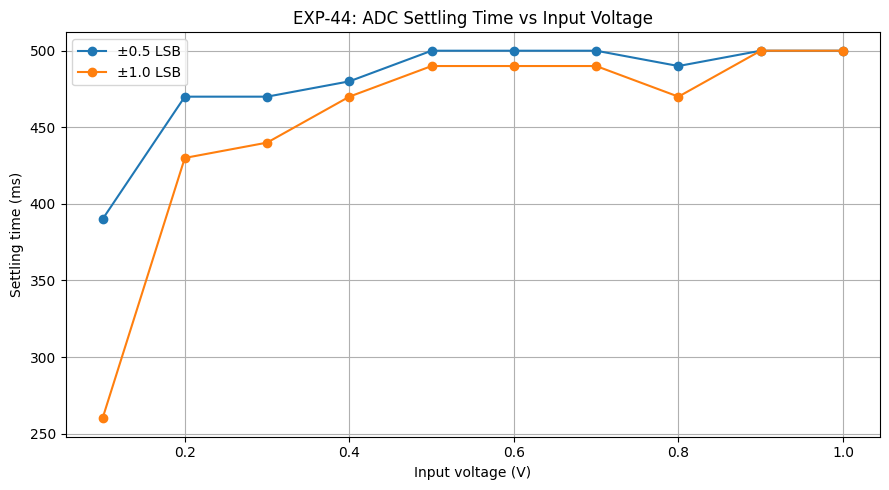

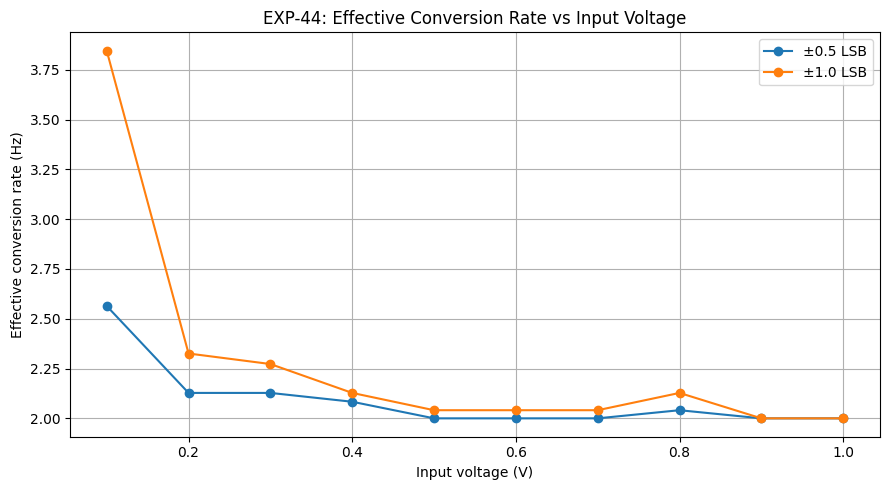

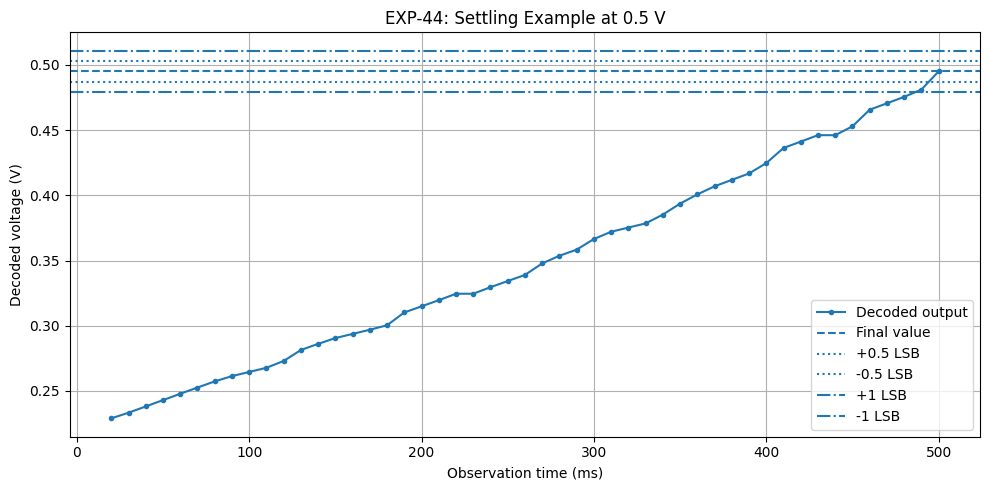



EXP-44 COMPLETE


In [165]:
# ============================================================
# EXP-44
# ADC SETTLING-TIME CHARACTERIZATION
# ============================================================
#
# Uses EXP-43 simulation results.
#
# tau_m   = 20 ms
# W_SCALE = 0.06
#
# Settling criteria:
#   ±0.5 LSB
#   ±1.0 LSB
#
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 75)
print("EXP-44: ADC SETTLING-TIME CHARACTERIZATION")
print("=" * 75)


# ============================================================
# 1. ADC PARAMETERS
# ============================================================

BITS_44 = 6

LSB_44 = 1.0 / (2**BITS_44 - 1)

HALF_LSB_44 = 0.5 * LSB_44

ONE_LSB_44 = LSB_44

print(
    f"ADC resolution : {BITS_44} bits"
)

print(
    f"1 LSB          : {LSB_44:.6f} V "
    f"({LSB_44*1000:.3f} mV)"
)

print(
    f"0.5 LSB        : {HALF_LSB_44:.6f} V "
    f"({HALF_LSB_44*1000:.3f} mV)"
)

print(
    f"1.0 LSB        : {ONE_LSB_44:.6f} V "
    f"({ONE_LSB_44*1000:.3f} mV)"
)


# ============================================================
# 2. HELPER
# ============================================================

def find_settling_time_44(
    timeline,
    final_value,
    tolerance
):

    """
    Find earliest time where the decoded output
    enters the tolerance band around the final value
    and stays inside that band until the end.
    """

    for i, item in enumerate(timeline):

        if not item["valid"]:
            continue

        current_time = item["time"]
        current_value = item["analog"]

        if not np.isfinite(current_value):
            continue

        # Check current point
        if abs(
            current_value - final_value
        ) > tolerance:
            continue

        # Check every future valid point
        stable = True

        for future in timeline[i:]:

            if not future["valid"]:
                stable = False
                break

            future_value = future["analog"]

            if not np.isfinite(future_value):
                stable = False
                break

            if abs(
                future_value - final_value
            ) > tolerance:

                stable = False
                break

        if stable:
            return current_time

    return np.nan


# ============================================================
# 3. RUN SETTLING ANALYSIS
# ============================================================

settling_results_44 = {}

for voltage in TEST_VOLTAGES_43:

    result = conversion_results_43[
        voltage
    ]

    timeline = result[
        "timeline"
    ]

    # Final 500 ms decoded value
    final_value = result[
        "final_analog"
    ]

    # --------------------------------------------------------
    # 0.5 LSB
    # --------------------------------------------------------

    settling_half = find_settling_time_44(
        timeline,
        final_value,
        HALF_LSB_44
    )

    # --------------------------------------------------------
    # 1 LSB
    # --------------------------------------------------------

    settling_one = find_settling_time_44(
        timeline,
        final_value,
        ONE_LSB_44
    )

    # --------------------------------------------------------
    # Effective rates
    # --------------------------------------------------------

    if np.isfinite(
        settling_half
    ):
        rate_half = (
            1000.0 /
            settling_half
        )
    else:
        rate_half = np.nan

    if np.isfinite(
        settling_one
    ):
        rate_one = (
            1000.0 /
            settling_one
        )
    else:
        rate_one = np.nan

    settling_results_44[
        voltage
    ] = {
        "final_value": final_value,
        "settling_0.5lsb_ms": settling_half,
        "settling_1lsb_ms": settling_one,
        "rate_0.5lsb_hz": rate_half,
        "rate_1lsb_hz": rate_one
    }


# ============================================================
# 4. PRINT RESULTS
# ============================================================

print("\n")
print("=" * 105)
print("EXP-44 SETTLING-TIME RESULTS")
print("=" * 105)

print(
    f"{'Voltage':>9} "
    f"{'Final V':>10} "
    f"{'0.5 LSB ms':>13} "
    f"{'0.5 LSB Hz':>13} "
    f"{'1 LSB ms':>11} "
    f"{'1 LSB Hz':>11}"
)

for voltage in TEST_VOLTAGES_43:

    r = settling_results_44[
        voltage
    ]

    print(
        f"{voltage:9.2f} "
        f"{r['final_value']:10.4f} "
        f"{r['settling_0.5lsb_ms']:13.1f} "
        f"{r['rate_0.5lsb_hz']:13.2f} "
        f"{r['settling_1lsb_ms']:11.1f} "
        f"{r['rate_1lsb_hz']:11.2f}"
    )


# ============================================================
# 5. OVERALL PERFORMANCE
# ============================================================

half_times = np.array([
    settling_results_44[v][
        "settling_0.5lsb_ms"
    ]
    for v in TEST_VOLTAGES_43
])

one_times = np.array([
    settling_results_44[v][
        "settling_1lsb_ms"
    ]
    for v in TEST_VOLTAGES_43
])


print("\n")
print("=" * 75)
print("OVERALL SETTLING PERFORMANCE")
print("=" * 75)


# ------------------------------------------------------------
# 0.5 LSB
# ------------------------------------------------------------

valid_half = half_times[
    np.isfinite(half_times)
]

if len(valid_half) > 0:

    worst_half = np.max(
        valid_half
    )

    mean_half = np.mean(
        valid_half
    )

    fastest_half = np.min(
        valid_half
    )

    print("\n±0.5 LSB criterion")

    print(
        f"Fastest settling : "
        f"{fastest_half:.1f} ms"
    )

    print(
        f"Mean settling    : "
        f"{mean_half:.1f} ms"
    )

    print(
        f"Worst settling   : "
        f"{worst_half:.1f} ms"
    )

    print(
        f"Worst-case rate  : "
        f"{1000/worst_half:.2f} Hz"
    )

else:

    print(
        "\n±0.5 LSB: "
        "No valid settling times"
    )


# ------------------------------------------------------------
# 1 LSB
# ------------------------------------------------------------

valid_one = one_times[
    np.isfinite(one_times)
]

if len(valid_one) > 0:

    worst_one = np.max(
        valid_one
    )

    mean_one = np.mean(
        valid_one
    )

    fastest_one = np.min(
        valid_one
    )

    print("\n±1.0 LSB criterion")

    print(
        f"Fastest settling : "
        f"{fastest_one:.1f} ms"
    )

    print(
        f"Mean settling    : "
        f"{mean_one:.1f} ms"
    )

    print(
        f"Worst settling   : "
        f"{worst_one:.1f} ms"
    )

    print(
        f"Worst-case rate  : "
        f"{1000/worst_one:.2f} Hz"
    )

else:

    print(
        "\n±1.0 LSB: "
        "No valid settling times"
    )


# ============================================================
# 6. PLOT: SETTLING TIME
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    TEST_VOLTAGES_43,
    half_times,
    marker='o',
    label="±0.5 LSB"
)

plt.plot(
    TEST_VOLTAGES_43,
    one_times,
    marker='o',
    label="±1.0 LSB"
)

plt.xlabel(
    "Input voltage (V)"
)

plt.ylabel(
    "Settling time (ms)"
)

plt.title(
    "EXP-44: ADC Settling Time vs Input Voltage"
)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 7. PLOT: EFFECTIVE RATE
# ============================================================

half_rates = np.array([
    settling_results_44[v][
        "rate_0.5lsb_hz"
    ]
    for v in TEST_VOLTAGES_43
])

one_rates = np.array([
    settling_results_44[v][
        "rate_1lsb_hz"
    ]
    for v in TEST_VOLTAGES_43
])


plt.figure(figsize=(9, 5))

plt.plot(
    TEST_VOLTAGES_43,
    half_rates,
    marker='o',
    label="±0.5 LSB"
)

plt.plot(
    TEST_VOLTAGES_43,
    one_rates,
    marker='o',
    label="±1.0 LSB"
)

plt.xlabel(
    "Input voltage (V)"
)

plt.ylabel(
    "Effective conversion rate (Hz)"
)

plt.title(
    "EXP-44: Effective Conversion Rate vs Input Voltage"
)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 8. SETTLING BAND EXAMPLE
# ============================================================

# Show one representative input
# Change this if you want another voltage.

EXAMPLE_VOLTAGE_44 = 0.50

example = conversion_results_43[
    EXAMPLE_VOLTAGE_44
]

timeline = example[
    "timeline"
]

final_value = example[
    "final_analog"
]

times = []
values = []

for item in timeline:

    if item["valid"]:

        times.append(
            item["time"]
        )

        values.append(
            item["analog"]
        )

times = np.asarray(times)
values = np.asarray(values)

upper_half = (
    final_value +
    HALF_LSB_44
)

lower_half = (
    final_value -
    HALF_LSB_44
)

upper_one = (
    final_value +
    ONE_LSB_44
)

lower_one = (
    final_value -
    ONE_LSB_44
)


plt.figure(figsize=(10, 5))

plt.plot(
    times,
    values,
    marker='o',
    markersize=3,
    label="Decoded output"
)

plt.axhline(
    final_value,
    linestyle='--',
    label="Final value"
)

plt.axhline(
    upper_half,
    linestyle=':',
    label="+0.5 LSB"
)

plt.axhline(
    lower_half,
    linestyle=':',
    label="-0.5 LSB"
)

plt.axhline(
    upper_one,
    linestyle='-.',
    label="+1 LSB"
)

plt.axhline(
    lower_one,
    linestyle='-.',
    label="-1 LSB"
)

plt.xlabel(
    "Observation time (ms)"
)

plt.ylabel(
    "Decoded voltage (V)"
)

plt.title(
    f"EXP-44: Settling Example at {EXAMPLE_VOLTAGE_44:.1f} V"
)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()


print("\n")
print("=" * 75)
print("EXP-44 COMPLETE")
print("=" * 75)

EXP-45: EARLY-READOUT ADC CHARACTERIZATION
Observation windows: [ 50 100 150 200 250 300 350 400 450 500] ms
Test voltages: [0.1 0.2 0.3 0.4 0.5 0.6 0.7 0.8 0.9 1. ]


---------------------------------------------------------------------------
Observation window = 50 ms
---------------------------------------------------------------------------
Analog MAE       : 0.339726 V
Analog RMSE      : 0.388900 V
Analog max       : 0.645931 V
6-bit MAE        : 0.340741 V
6-bit RMSE       : 0.389655 V
Unique codes     : 9/64
Analog monotonic : True
Code monotonic   : True
Exact code match : 0.0%


---------------------------------------------------------------------------
Observation window = 100 ms
---------------------------------------------------------------------------
Analog MAE       : 0.284119 V
Analog RMSE      : 0.340247 V
Analog max       : 0.598678 V
6-bit MAE        : 0.280159 V
6-bit RMSE       : 0.337750 V
Unique codes     : 10/64
Analog monotonic : True
Code monotonic   : True
Ex

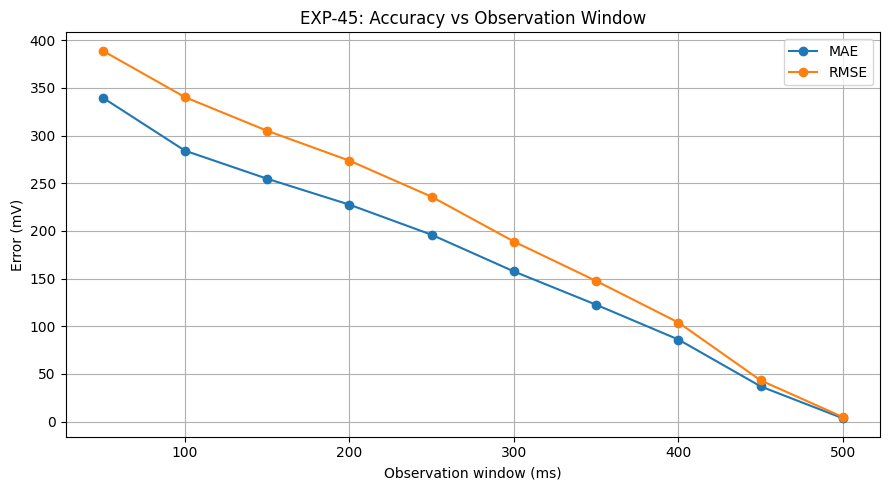

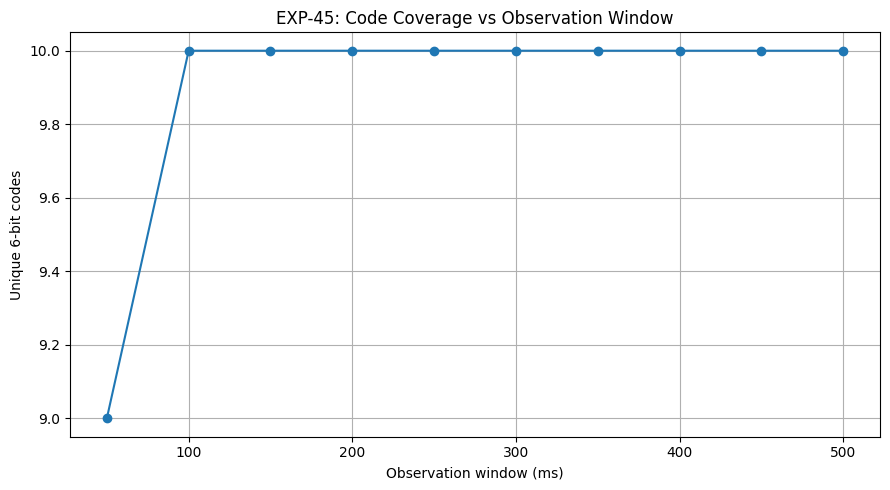

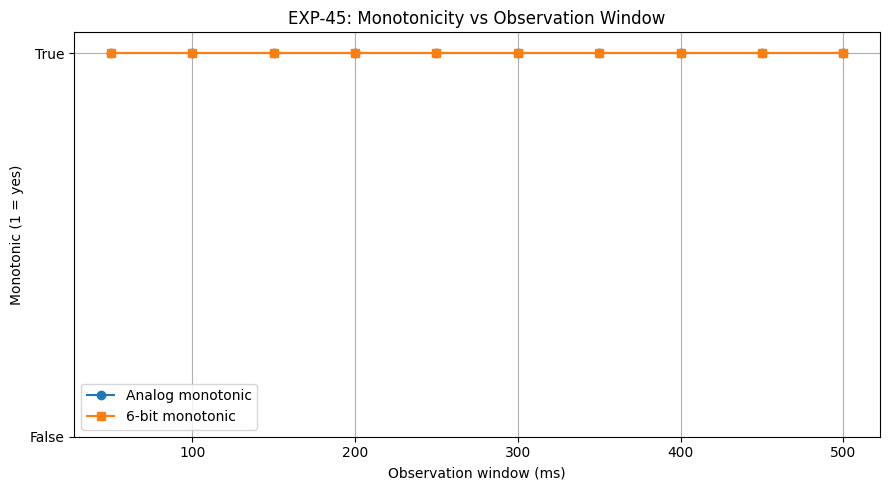

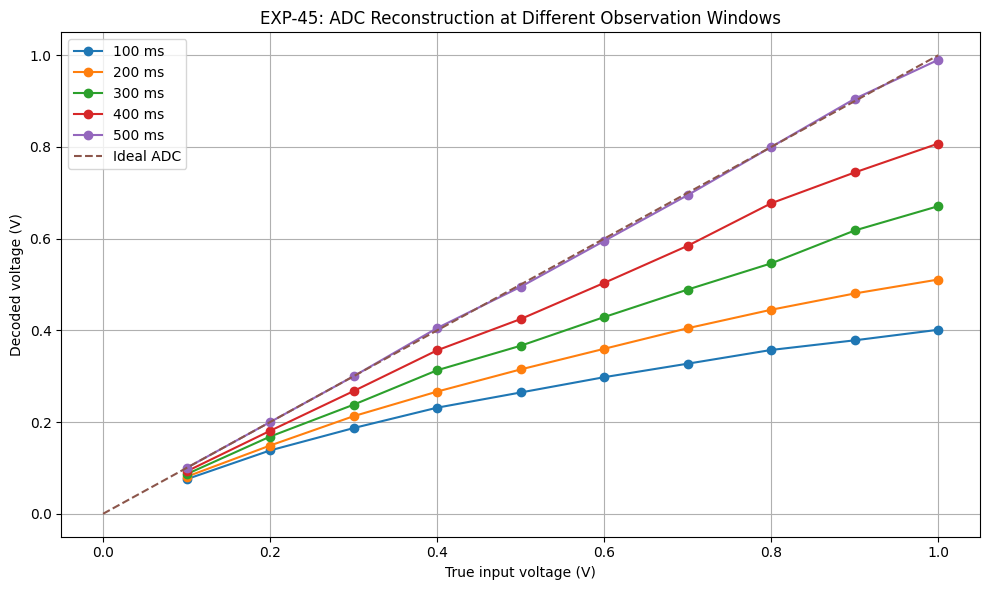



EXP-45 COMPLETE

This experiment uses the existing EXP-43 neural simulations.
No new Brian2 simulations were required.

If a short observation window gives acceptable accuracy while remaining monotonic, that window becomes the candidate for EXP-45B independent validation.


In [166]:
# ============================================================
# EXP-45
# EARLY-READOUT ADC CHARACTERIZATION
# ============================================================
#
# Uses EXP-43 simulation results.
#
# Current configuration:
#   tau_m   = 20 ms
#   W_SCALE = 0.06
#
# Question:
#   How early can we stop observing the neural population
#   and still obtain a useful ADC output?
#
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 75)
print("EXP-45: EARLY-READOUT ADC CHARACTERIZATION")
print("=" * 75)


# ============================================================
# 1. OBSERVATION WINDOWS
# ============================================================

WINDOWS_45 = np.arange(
    50,
    501,
    50
)

print(
    "Observation windows:",
    WINDOWS_45,
    "ms"
)


# ============================================================
# 2. TEST VOLTAGES
# ============================================================

voltages_45 = np.array(
    sorted(
        conversion_results_43.keys()
    )
)

print(
    "Test voltages:",
    voltages_45
)


# ============================================================
# 3. HELPER
# ============================================================

def get_timeline_item_45(
    timeline,
    target_time
):

    """
    Get the latest valid decoder state
    at or before target_time.
    """

    valid_items = [
        item
        for item in timeline
        if (
            item["valid"]
            and item["time"] <= target_time
        )
    ]

    if len(valid_items) == 0:
        return None

    return valid_items[-1]


# ============================================================
# 4. STORAGE
# ============================================================

results_45 = {}


# ============================================================
# 5. ANALYZE EVERY OBSERVATION WINDOW
# ============================================================

for window in WINDOWS_45:

    print("\n")
    print("-" * 75)
    print(
        f"Observation window = {window} ms"
    )
    print("-" * 75)

    true_values = []
    decoded_values = []
    adc_codes = []
    ideal_codes = []

    valid_count = 0

    for voltage in voltages_45:

        result = conversion_results_43[
            voltage
        ]

        timeline = result[
            "timeline"
        ]

        item = get_timeline_item_45(
            timeline,
            window
        )

        if item is None:
            continue

        decoded = item[
            "analog"
        ]

        code = item[
            "code"
        ]

        if not np.isfinite(
            decoded
        ):
            continue

        true_values.append(
            voltage
        )

        decoded_values.append(
            decoded
        )

        adc_codes.append(
            code
        )

        ideal_codes.append(
            int(
                np.clip(
                    np.round(
                        voltage * 63
                    ),
                    0,
                    63
                )
            )
        )

        valid_count += 1

    true_values = np.asarray(
        true_values
    )

    decoded_values = np.asarray(
        decoded_values
    )

    adc_codes = np.asarray(
        adc_codes
    )

    ideal_codes = np.asarray(
        ideal_codes
    )

    # --------------------------------------------------------
    # Accuracy
    # --------------------------------------------------------

    errors = (
        decoded_values -
        true_values
    )

    mae = np.mean(
        np.abs(errors)
    )

    rmse = np.sqrt(
        np.mean(
            errors ** 2
        )
    )

    max_error = np.max(
        np.abs(errors)
    )

    # --------------------------------------------------------
    # 6-bit decoded voltage
    # --------------------------------------------------------

    quantized_voltage = (
        adc_codes / 63.0
    )

    code_errors = (
        quantized_voltage -
        true_values
    )

    code_mae = np.mean(
        np.abs(code_errors)
    )

    code_rmse = np.sqrt(
        np.mean(
            code_errors ** 2
        )
    )

    code_max = np.max(
        np.abs(code_errors)
    )

    # --------------------------------------------------------
    # Code coverage
    # --------------------------------------------------------

    unique_codes = len(
        np.unique(
            adc_codes
        )
    )

    # --------------------------------------------------------
    # Monotonicity
    # --------------------------------------------------------

    analog_monotonic = bool(
        np.all(
            np.diff(
                decoded_values
            ) >= -1e-12
        )
    )

    code_monotonic = bool(
        np.all(
            np.diff(
                adc_codes
            ) >= 0
        )
    )

    # --------------------------------------------------------
    # Exact ideal-code matches
    # --------------------------------------------------------

    exact_code_matches = np.sum(
        adc_codes ==
        ideal_codes
    )

    code_match_percent = (
        100.0 *
        exact_code_matches /
        len(ideal_codes)
    )

    # --------------------------------------------------------
    # Store
    # --------------------------------------------------------

    results_45[
        window
    ] = {

        "mae": mae,

        "rmse": rmse,

        "max_error": max_error,

        "code_mae": code_mae,

        "code_rmse": code_rmse,

        "code_max": code_max,

        "unique_codes": unique_codes,

        "analog_monotonic":
            analog_monotonic,

        "code_monotonic":
            code_monotonic,

        "exact_code_matches":
            exact_code_matches,

        "code_match_percent":
            code_match_percent,

        "true":
            true_values,

        "decoded":
            decoded_values,

        "codes":
            adc_codes
    }


    # --------------------------------------------------------
    # Print
    # --------------------------------------------------------

    print(
        f"Analog MAE       : "
        f"{mae:.6f} V"
    )

    print(
        f"Analog RMSE      : "
        f"{rmse:.6f} V"
    )

    print(
        f"Analog max       : "
        f"{max_error:.6f} V"
    )

    print(
        f"6-bit MAE        : "
        f"{code_mae:.6f} V"
    )

    print(
        f"6-bit RMSE       : "
        f"{code_rmse:.6f} V"
    )

    print(
        f"Unique codes     : "
        f"{unique_codes}/64"
    )

    print(
        f"Analog monotonic : "
        f"{analog_monotonic}"
    )

    print(
        f"Code monotonic   : "
        f"{code_monotonic}"
    )

    print(
        f"Exact code match : "
        f"{code_match_percent:.1f}%"
    )


# ============================================================
# 6. SUMMARY TABLE
# ============================================================

print("\n")
print("=" * 110)
print("EXP-45 SUMMARY")
print("=" * 110)

print(
    f"{'Window':>8} "
    f"{'MAE':>10} "
    f"{'RMSE':>10} "
    f"{'6b MAE':>10} "
    f"{'6b RMSE':>10} "
    f"{'Codes':>8} "
    f"{'Analog':>10} "
    f"{'Code':>8} "
    f"{'Match':>9}"
)

for window in WINDOWS_45:

    r = results_45[
        window
    ]

    print(
        f"{window:8.0f} "
        f"{r['mae']:10.6f} "
        f"{r['rmse']:10.6f} "
        f"{r['code_mae']:10.6f} "
        f"{r['code_rmse']:10.6f} "
        f"{r['unique_codes']:8d} "
        f"{str(r['analog_monotonic']):>10} "
        f"{str(r['code_monotonic']):>8} "
        f"{r['code_match_percent']:8.1f}%"
    )


# ============================================================
# 7. FIND BEST EARLY WINDOWS
# ============================================================

valid_windows = [
    w
    for w in WINDOWS_45
    if results_45[w]["code_monotonic"]
]


if len(valid_windows) > 0:

    best_mae_window = min(
        valid_windows,
        key=lambda w:
            results_45[w]["mae"]
    )

    best_code_mae_window = min(
        valid_windows,
        key=lambda w:
            results_45[w]["code_mae"]
    )

    best_code_coverage_window = max(
        valid_windows,
        key=lambda w:
            results_45[w]["unique_codes"]
    )

    print("\n")
    print("=" * 75)
    print("BEST EARLY-READOUT CONFIGURATIONS")
    print("=" * 75)

    print(
        f"Best analog MAE window : "
        f"{best_mae_window} ms"
    )

    print(
        f"Best 6-bit MAE window  : "
        f"{best_code_mae_window} ms"
    )

    print(
        f"Most code coverage     : "
        f"{best_code_coverage_window} ms"
    )


# ============================================================
# 8. ACCURACY VS OBSERVATION TIME
# ============================================================

maes = np.array([
    results_45[w]["mae"]
    for w in WINDOWS_45
])

rmses = np.array([
    results_45[w]["rmse"]
    for w in WINDOWS_45
])


plt.figure(
    figsize=(9, 5)
)

plt.plot(
    WINDOWS_45,
    maes * 1000,
    marker='o',
    label="MAE"
)

plt.plot(
    WINDOWS_45,
    rmses * 1000,
    marker='o',
    label="RMSE"
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Error (mV)"
)

plt.title(
    "EXP-45: Accuracy vs Observation Window"
)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 9. CODE COVERAGE VS TIME
# ============================================================

coverage = np.array([
    results_45[w]["unique_codes"]
    for w in WINDOWS_45
])


plt.figure(
    figsize=(9, 5)
)

plt.plot(
    WINDOWS_45,
    coverage,
    marker='o'
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Unique 6-bit codes"
)

plt.title(
    "EXP-45: Code Coverage vs Observation Window"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 10. MONOTONICITY VS TIME
# ============================================================

analog_mono = [
    int(
        results_45[w][
            "analog_monotonic"
        ]
    )
    for w in WINDOWS_45
]

code_mono = [
    int(
        results_45[w][
            "code_monotonic"
        ]
    )
    for w in WINDOWS_45
]


plt.figure(
    figsize=(9, 5)
)

plt.plot(
    WINDOWS_45,
    analog_mono,
    marker='o',
    label="Analog monotonic"
)

plt.plot(
    WINDOWS_45,
    code_mono,
    marker='s',
    label="6-bit monotonic"
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Monotonic (1 = yes)"
)

plt.title(
    "EXP-45: Monotonicity vs Observation Window"
)

plt.yticks(
    [0, 1],
    ["False", "True"]
)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 11. ADC TRANSFER CURVES
# ============================================================

selected_windows = [
    100,
    200,
    300,
    400,
    500
]

plt.figure(
    figsize=(10, 6)
)

for window in selected_windows:

    r = results_45[
        window
    ]

    plt.plot(
        r["true"],
        r["decoded"],
        marker='o',
        label=f"{window} ms"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label="Ideal ADC"
)

plt.xlabel(
    "True input voltage (V)"
)

plt.ylabel(
    "Decoded voltage (V)"
)

plt.title(
    "EXP-45: ADC Reconstruction at Different Observation Windows"
)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 12. FINAL INTERPRETATION
# ============================================================

print("\n")
print("=" * 75)
print("EXP-45 COMPLETE")
print("=" * 75)

print(
    "\nThis experiment uses the existing EXP-43 neural simulations."
)

print(
    "No new Brian2 simulations were required."
)

print(
    "\nIf a short observation window gives acceptable accuracy "
    "while remaining monotonic, that window becomes the candidate "
    "for EXP-45B independent validation."
)

EXP-45B: WINDOW-SPECIFIC TEMPORAL DECODER CHARACTERIZATION
Training voltages    = 101
Validation voltages  = 200
Observation windows  = [ 50. 100. 150. 200. 250. 300. 350. 400. 450. 500.]


GENERATING TRAINING SPIKE-TRAIN CACHE
Training   1/101 | V = 0.0000
Training   2/101 | V = 0.0100
Training   3/101 | V = 0.0200
Training   4/101 | V = 0.0300
Training   5/101 | V = 0.0400
Training   6/101 | V = 0.0500
Training   7/101 | V = 0.0600
Training   8/101 | V = 0.0700
Training   9/101 | V = 0.0800
Training  10/101 | V = 0.0900
Training  11/101 | V = 0.1000
Training  12/101 | V = 0.1100
Training  13/101 | V = 0.1200
Training  14/101 | V = 0.1300
Training  15/101 | V = 0.1400
Training  16/101 | V = 0.1500
Training  17/101 | V = 0.1600
Training  18/101 | V = 0.1700
Training  19/101 | V = 0.1800
Training  20/101 | V = 0.1900
Training  21/101 | V = 0.2000
Training  22/101 | V = 0.2100
Training  23/101 | V = 0.2200
Training  24/101 | V = 0.2300
Training  25/101 | V = 0.2400
Training  26/101 | V =

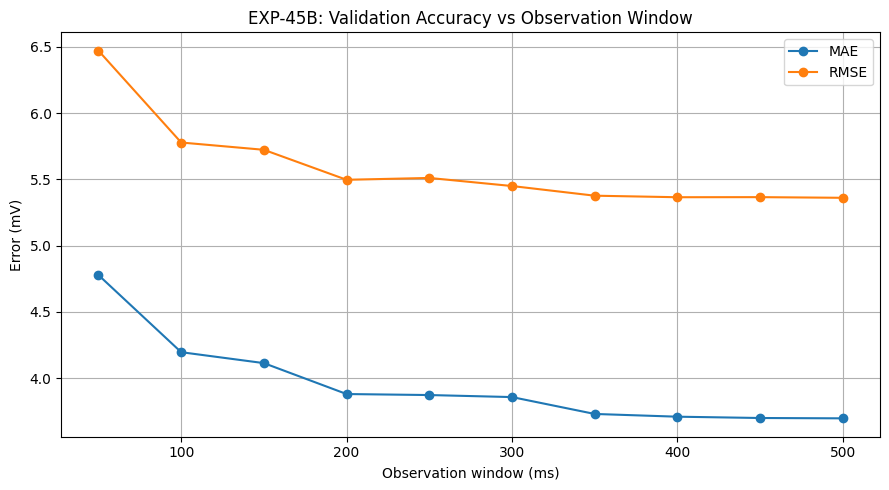

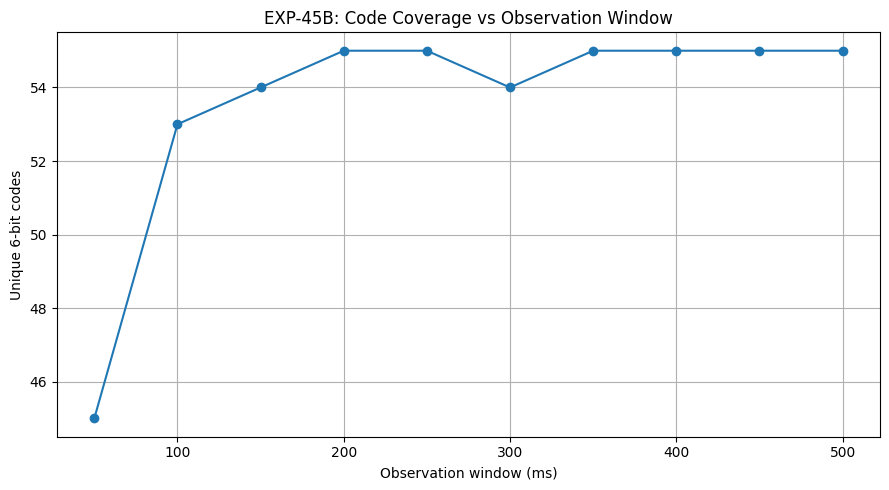

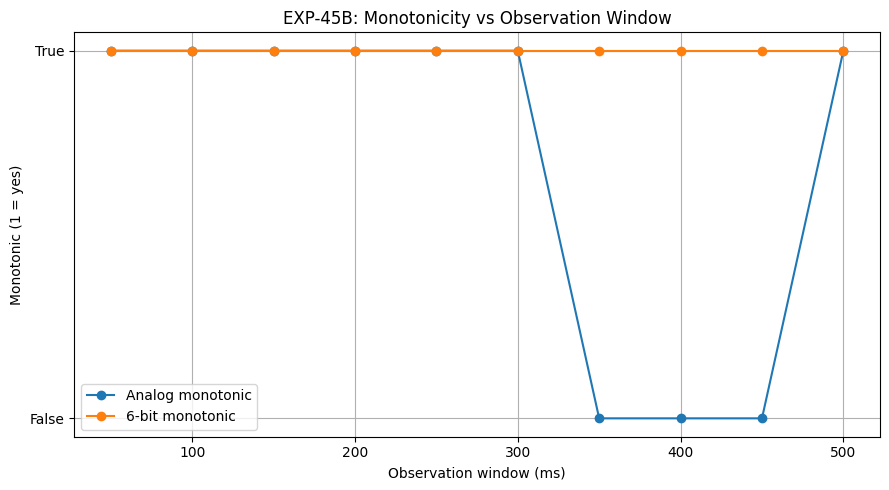

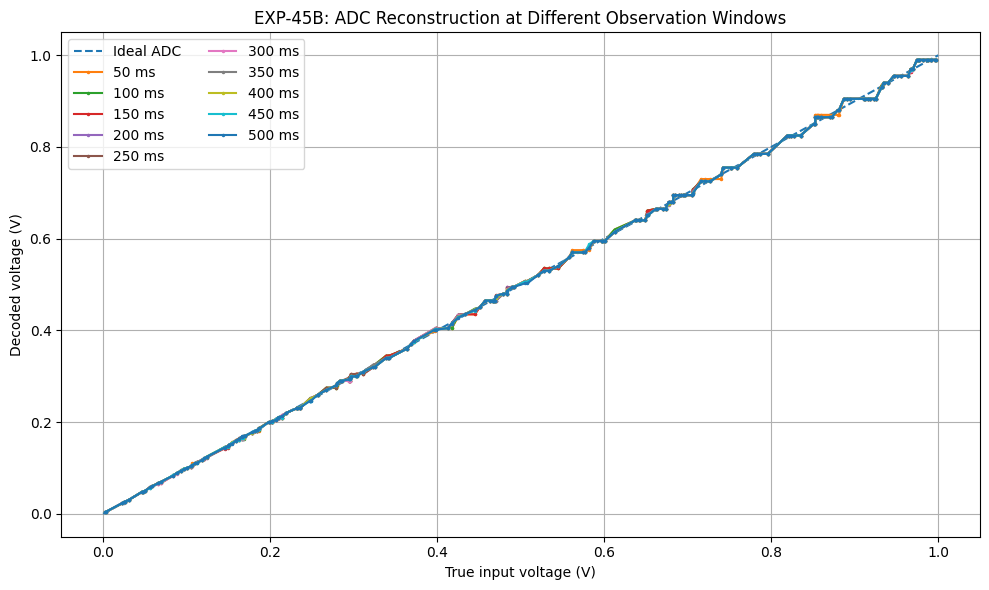



EXP-45B COMPLETE


In [167]:
# ============================================================
# EXP-45B
# WINDOW-SPECIFIC TEMPORAL DECODER CHARACTERIZATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression

print("=" * 75)
print("EXP-45B: WINDOW-SPECIFIC TEMPORAL DECODER CHARACTERIZATION")
print("=" * 75)


# ============================================================
# 1. CONFIGURATION
# ============================================================

TAU_M_MS = 20.0
W_SCALE_45B = 0.06
SIM_DURATION_MS = 500.0

OBSERVATION_WINDOWS_45B = np.arange(
    50.0,
    501.0,
    50.0
)

# Training data already used by EXP-42C / EXP-43
TRAIN_VOLTAGES_45B = np.asarray(
    train_voltages_42C,
    dtype=float
)

# Independent validation set
np.random.seed(2026)

VALIDATION_VOLTAGES_45B = np.sort(
    np.random.uniform(
        0.0,
        1.0,
        200
    )
)

print(
    f"Training voltages    = "
    f"{len(TRAIN_VOLTAGES_45B)}"
)

print(
    f"Validation voltages  = "
    f"{len(VALIDATION_VOLTAGES_45B)}"
)

print(
    f"Observation windows  = "
    f"{OBSERVATION_WINDOWS_45B}"
)


# ============================================================
# 2. SPIKE-TIME HELPER
# ============================================================

def get_spike_times_45B(
    spike_mon,
    neuron_id,
    neuron_name
):

    idx = neuron_id.get(
        neuron_name
    )

    if idx is None:
        return np.array([])

    return np.asarray(
        spike_mon.spike_trains()[idx] / ms
    )


# ============================================================
# 3. EXTRACT PARTIAL FEATURES
# ============================================================

def partial_features_45B(
    l1_spikes,
    mi1_spikes,
    current_time
):

    l1_current = l1_spikes[
        l1_spikes <= current_time
    ]

    mi1_current = mi1_spikes[
        mi1_spikes <= current_time
    ]

    # --------------------------------------------------------
    # Mi1 spike count
    # --------------------------------------------------------

    mi1_count = float(
        len(mi1_current)
    )

    # --------------------------------------------------------
    # Need at least one L1 spike
    # --------------------------------------------------------

    if len(l1_current) == 0:

        return np.array([
            mi1_count,
            np.nan,
            np.nan
        ])

    # --------------------------------------------------------
    # First L1 spike
    # --------------------------------------------------------

    l1_first = float(
        l1_current[0]
    )

    # --------------------------------------------------------
    # Need at least two L1 spikes for ISI
    # --------------------------------------------------------

    if len(l1_current) < 2:

        return np.array([
            mi1_count,
            l1_first,
            np.nan
        ])

    # --------------------------------------------------------
    # Mean L1 ISI
    # --------------------------------------------------------

    l1_isi = float(
        np.mean(
            np.diff(l1_current)
        )
    )

    return np.array([
        mi1_count,
        l1_first,
        l1_isi
    ])


# ============================================================
# 4. SIMULATION CACHE
#
# One 500 ms simulation per voltage.
# We DO NOT rerun the simulation for every window.
# ============================================================

def simulate_voltage_45B(
    voltage
):

    drive = voltage_to_drive(
        voltage,
        v_min=0.0,
        v_max=1.0,
        drive_min=0.30,
        drive_max=1.00
    )

    smon, _, elapsed_ms, _ = (
        run_simulation_v1(
            ['L1', 'Mi1'],
            neuron_id100,
            W100_4bit,
            thr100,
            N100,
            duration_ms=SIM_DURATION_MS,
            g_drive_on=drive,
            g_drive_off=0.15,
            w_scale=W_SCALE_45B
        )
    )

    l1_spikes = get_spike_times_45B(
        smon,
        neuron_id100,
        "L1"
    )

    mi1_spikes = get_spike_times_45B(
        smon,
        neuron_id100,
        "Mi1"
    )

    return {
        "l1_spikes": l1_spikes,
        "mi1_spikes": mi1_spikes
    }


# ============================================================
# 5. RUN TRAINING SIMULATIONS
# ============================================================

print("\n")
print("=" * 75)
print("GENERATING TRAINING SPIKE-TRAIN CACHE")
print("=" * 75)

train_spike_cache_45B = {}

for i, voltage in enumerate(
    TRAIN_VOLTAGES_45B
):

    print(
        f"Training "
        f"{i+1:3d}/{len(TRAIN_VOLTAGES_45B)} "
        f"| V = {voltage:.4f}"
    )

    train_spike_cache_45B[
        float(voltage)
    ] = simulate_voltage_45B(
        voltage
    )


print("\nTraining spike cache complete.")


# ============================================================
# 6. RUN VALIDATION SIMULATIONS
# ============================================================

print("\n")
print("=" * 75)
print("GENERATING VALIDATION SPIKE-TRAIN CACHE")
print("=" * 75)

val_spike_cache_45B = {}

for i, voltage in enumerate(
    VALIDATION_VOLTAGES_45B
):

    if (
        i % 10 == 0
        or i == len(VALIDATION_VOLTAGES_45B) - 1
    ):

        print(
            f"Validation "
            f"{i+1:3d}/{len(VALIDATION_VOLTAGES_45B)} "
            f"| V = {voltage:.4f}"
        )

    val_spike_cache_45B[
        i
    ] = simulate_voltage_45B(
        voltage
    )


print("\nValidation spike cache complete.")


# ============================================================
# 7. BUILD WINDOW-SPECIFIC TRAINING FEATURES
# ============================================================

train_features_45B = {}

for window in OBSERVATION_WINDOWS_45B:

    features = []

    targets = []

    for voltage in TRAIN_VOLTAGES_45B:

        result = train_spike_cache_45B[
            float(voltage)
        ]

        f = partial_features_45B(
            result["l1_spikes"],
            result["mi1_spikes"],
            window
        )

        features.append(f)
        targets.append(voltage)

    train_features_45B[
        window
    ] = (
        np.asarray(features),
        np.asarray(targets)
    )


# ============================================================
# 8. TRAIN A SEPARATE DECODER FOR EACH WINDOW
# ============================================================

decoders_45B = {}

print("\n")
print("=" * 75)
print("TRAINING WINDOW-SPECIFIC DECODERS")
print("=" * 75)

for window in OBSERVATION_WINDOWS_45B:

    X_train, y_train = (
        train_features_45B[
            window
        ]
    )

    # --------------------------------------------------------
    # Keep only rows with all three features available
    # --------------------------------------------------------

    valid = np.all(
        np.isfinite(X_train),
        axis=1
    )

    X = X_train[
        valid
    ]

    y = y_train[
        valid
    ]

    # --------------------------------------------------------
    # Training normalization
    # --------------------------------------------------------

    mean = np.mean(
        X,
        axis=0
    )

    std = np.std(
        X,
        axis=0
    )

    std[
        std == 0
    ] = 1.0

    X_norm = (
        X - mean
    ) / std

    # --------------------------------------------------------
    # EXP-33 temporal directions
    #
    # Mi1 count       -> positive
    # L1 first spike  -> negative
    # L1 mean ISI     -> negative
    # --------------------------------------------------------

    score_features = np.column_stack([
        X_norm[:, 0],
        -X_norm[:, 1],
        -X_norm[:, 2]
    ])

    scores = np.mean(
        score_features,
        axis=1
    )

    # --------------------------------------------------------
    # Monotonic decoder
    # --------------------------------------------------------

    iso = IsotonicRegression(
        increasing=True,
        out_of_bounds="clip"
    )

    iso.fit(
        scores,
        y
    )

    decoders_45B[
        window
    ] = {
        "mean": mean,
        "std": std,
        "iso": iso,
        "n_train": len(y)
    }

    print(
        f"{window:6.0f} ms -> "
        f"{len(y):3d} valid training samples"
    )


# ============================================================
# 9. DECODE VALIDATION SET
# ============================================================

results_45B = {}

for window in OBSERVATION_WINDOWS_45B:

    decoder = decoders_45B[
        window
    ]

    mean = decoder["mean"]
    std = decoder["std"]
    iso = decoder["iso"]

    predictions = []

    valid_mask = []

    scores_out = []

    # --------------------------------------------------------
    # Decode every independent validation voltage
    # --------------------------------------------------------

    for i, voltage in enumerate(
        VALIDATION_VOLTAGES_45B
    ):

        result = val_spike_cache_45B[
            i
        ]

        f = partial_features_45B(
            result["l1_spikes"],
            result["mi1_spikes"],
            window
        )

        if not np.all(
            np.isfinite(f)
        ):

            predictions.append(
                np.nan
            )

            scores_out.append(
                np.nan
            )

            valid_mask.append(
                False
            )

            continue

        f_norm = (
            f - mean
        ) / std

        score_features = np.array([
            f_norm[0],
            -f_norm[1],
            -f_norm[2]
        ])

        score = np.mean(
            score_features
        )

        analog = float(
            iso.predict([
                score
            ])[0]
        )

        analog = np.clip(
            analog,
            0.0,
            1.0
        )

        predictions.append(
            analog
        )

        scores_out.append(
            score
        )

        valid_mask.append(
            True
        )

    predictions = np.asarray(
        predictions
    )

    scores_out = np.asarray(
        scores_out
    )

    valid_mask = np.asarray(
        valid_mask
    )

    true_v = (
        VALIDATION_VOLTAGES_45B[
            valid_mask
        ]
    )

    pred_v = (
        predictions[
            valid_mask
        ]
    )

    # --------------------------------------------------------
    # Analog metrics
    # --------------------------------------------------------

    errors = (
        pred_v - true_v
    )

    mae = np.mean(
        np.abs(errors)
    )

    rmse = np.sqrt(
        np.mean(
            errors ** 2
        )
    )

    max_error = np.max(
        np.abs(errors)
    )

    # --------------------------------------------------------
    # 6-bit quantization
    # --------------------------------------------------------

    true_codes = np.clip(
        np.round(
            true_v * 63
        ),
        0,
        63
    ).astype(int)

    predicted_codes = np.clip(
        np.round(
            pred_v * 63
        ),
        0,
        63
    ).astype(int)

    decoded_6bit = (
        predicted_codes / 63.0
    )

    mae_6bit = np.mean(
        np.abs(
            decoded_6bit - true_v
        )
    )

    rmse_6bit = np.sqrt(
        np.mean(
            (
                decoded_6bit - true_v
            ) ** 2
        )
    )

    # --------------------------------------------------------
    # Code coverage
    # --------------------------------------------------------

    unique_codes = len(
        np.unique(
            predicted_codes
        )
    )

    # --------------------------------------------------------
    # Monotonicity
    # --------------------------------------------------------

    analog_monotonic = np.all(
        np.diff(pred_v) >= -1e-12
    )

    code_monotonic = np.all(
        np.diff(predicted_codes) >= 0
    )

    # --------------------------------------------------------
    # Exact ideal-code match
    # --------------------------------------------------------

    exact_match = (
        np.mean(
            predicted_codes ==
            true_codes
        ) * 100.0
    )

    results_45B[
        window
    ] = {
        "mae": mae,
        "rmse": rmse,
        "max_error": max_error,
        "mae_6bit": mae_6bit,
        "rmse_6bit": rmse_6bit,
        "unique_codes": unique_codes,
        "analog_monotonic": analog_monotonic,
        "code_monotonic": code_monotonic,
        "exact_match_percent": exact_match,
        "predictions": predictions,
        "predicted_codes": predicted_codes,
        "true_codes": true_codes,
        "valid_mask": valid_mask
    }

    print("\n")
    print(
        f"Window = {window:.0f} ms"
    )

    print(
        f"Analog MAE       : "
        f"{mae:.6f} V"
    )

    print(
        f"Analog RMSE      : "
        f"{rmse:.6f} V"
    )

    print(
        f"Analog max       : "
        f"{max_error:.6f} V"
    )

    print(
        f"6-bit MAE        : "
        f"{mae_6bit:.6f} V"
    )

    print(
        f"6-bit RMSE       : "
        f"{rmse_6bit:.6f} V"
    )

    print(
        f"Unique codes     : "
        f"{unique_codes}/64"
    )

    print(
        f"Analog monotonic : "
        f"{analog_monotonic}"
    )

    print(
        f"Code monotonic   : "
        f"{code_monotonic}"
    )

    print(
        f"Exact code match : "
        f"{exact_match:.1f}%"
    )


# ============================================================
# 10. SUMMARY TABLE
# ============================================================

print("\n")
print("=" * 110)
print("EXP-45B SUMMARY")
print("=" * 110)

print(
    f"{'Window':>8} "
    f"{'MAE':>10} "
    f"{'RMSE':>10} "
    f"{'6b MAE':>10} "
    f"{'6b RMSE':>10} "
    f"{'Codes':>8} "
    f"{'Analog':>9} "
    f"{'Code':>8} "
    f"{'Match':>9}"
)

for window in OBSERVATION_WINDOWS_45B:

    r = results_45B[
        window
    ]

    print(
        f"{window:8.0f} "
        f"{r['mae']:10.6f} "
        f"{r['rmse']:10.6f} "
        f"{r['mae_6bit']:10.6f} "
        f"{r['rmse_6bit']:10.6f} "
        f"{r['unique_codes']:8d} "
        f"{str(r['analog_monotonic']):>9} "
        f"{str(r['code_monotonic']):>8} "
        f"{r['exact_match_percent']:8.1f}%"
    )


# ============================================================
# 11. FIND BEST WINDOWS
# ============================================================

windows = np.asarray(
    OBSERVATION_WINDOWS_45B
)

maes = np.array([
    results_45B[w]["mae"]
    for w in windows
])

maes_6bit = np.array([
    results_45B[w]["mae_6bit"]
    for w in windows
])

codes = np.array([
    results_45B[w]["unique_codes"]
    for w in windows
])

print("\n")
print("=" * 75)
print("BEST EXP-45B CONFIGURATIONS")
print("=" * 75)

best_analog_idx = np.argmin(
    maes
)

best_6bit_idx = np.argmin(
    maes_6bit
)

best_code_idx = np.argmax(
    codes
)

print(
    f"Best analog MAE window : "
    f"{windows[best_analog_idx]:.0f} ms"
)

print(
    f"Best analog MAE        : "
    f"{maes[best_analog_idx]:.6f} V"
)

print(
    f"Best 6-bit MAE window  : "
    f"{windows[best_6bit_idx]:.0f} ms"
)

print(
    f"Best 6-bit MAE         : "
    f"{maes_6bit[best_6bit_idx]:.6f} V"
)

print(
    f"Most code coverage     : "
    f"{windows[best_code_idx]:.0f} ms"
)

print(
    f"Maximum codes          : "
    f"{codes[best_code_idx]}/64"
)


# ============================================================
# 12. ACCURACY VS OBSERVATION WINDOW
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    windows,
    maes * 1000,
    marker='o',
    label="MAE"
)

plt.plot(
    windows,
    np.array([
        results_45B[w]["rmse"]
        for w in windows
    ]) * 1000,
    marker='o',
    label="RMSE"
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Error (mV)"
)

plt.title(
    "EXP-45B: Validation Accuracy vs Observation Window"
)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 13. CODE COVERAGE
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    windows,
    codes,
    marker='o'
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Unique 6-bit codes"
)

plt.title(
    "EXP-45B: Code Coverage vs Observation Window"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 14. MONOTONICITY
# ============================================================

analog_mono = [
    results_45B[w]["analog_monotonic"]
    for w in windows
]

code_mono = [
    results_45B[w]["code_monotonic"]
    for w in windows
]

plt.figure(figsize=(9, 5))

plt.plot(
    windows,
    np.array(analog_mono, dtype=int),
    marker='o',
    label="Analog monotonic"
)

plt.plot(
    windows,
    np.array(code_mono, dtype=int),
    marker='o',
    label="6-bit monotonic"
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Monotonic (1 = yes)"
)

plt.title(
    "EXP-45B: Monotonicity vs Observation Window"
)

plt.yticks(
    [0, 1],
    ["False", "True"]
)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 15. RECONSTRUCTION CURVES
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label="Ideal ADC"
)

for window in windows:

    r = results_45B[
        window
    ]

    mask = r[
        "valid_mask"
    ]

    plt.plot(
        VALIDATION_VOLTAGES_45B[mask],
        r["predictions"][mask],
        marker='.',
        markersize=3,
        label=f"{window:.0f} ms"
    )

plt.xlabel(
    "True input voltage (V)"
)

plt.ylabel(
    "Decoded voltage (V)"
)

plt.title(
    "EXP-45B: ADC Reconstruction at Different Observation Windows"
)

plt.grid(True)

plt.legend(
    ncol=2
)

plt.tight_layout()

plt.show()


# ============================================================
# 16. SAVE EVERYTHING IN ONE DICTIONARY
# ============================================================

EXP45B_RESULTS = {
    "windows_ms": OBSERVATION_WINDOWS_45B,
    "training_voltages": TRAIN_VOLTAGES_45B,
    "validation_voltages": VALIDATION_VOLTAGES_45B,
    "decoders": decoders_45B,
    "results": results_45B,
    "train_spike_cache": train_spike_cache_45B,
    "validation_spike_cache": val_spike_cache_45B
}


print("\n")
print("=" * 75)
print("EXP-45B COMPLETE")
print("=" * 75)

In [170]:
# ============================================================
# EXP-46
# SHORT-WINDOW CONVERSION / SETTLING CHARACTERIZATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.isotonic import IsotonicRegression

print("=" * 80)
print("EXP-46: SHORT-WINDOW CONVERSION / SETTLING CHARACTERIZATION")
print("=" * 80)


# ============================================================
# 1. CONFIGURATION
# ============================================================

WINDOWS_46 = np.array([
    50.0,
    100.0,
    150.0,
    200.0,
    250.0
])

REFERENCE_WINDOW_46 = 500.0

TIME_STEP_46 = 10.0

print(
    f"Test windows      : {WINDOWS_46.astype(int)} ms"
)

print(
    f"Reference window   : {REFERENCE_WINDOW_46:.0f} ms"
)

print(
    f"Time resolution    : {TIME_STEP_46:.1f} ms"
)


# ============================================================
# 2. CHECK FOR EXP-45B CACHE
# ============================================================

print("\nChecking EXP-45B spike-train cache...")

# EXP-45B should have created these dictionaries.
# We try the expected names first.

if "train_spike_cache_45B" in globals():

    TRAIN_CACHE_46 = train_spike_cache_45B

elif "training_spike_cache_45B" in globals():

    TRAIN_CACHE_46 = training_spike_cache_45B

elif "train_cache_45B" in globals():

    TRAIN_CACHE_46 = train_cache_45B

else:

    raise RuntimeError(
        "\nEXP-45B training spike cache was not found.\n"
        "Do NOT rerun 300+ Brian2 simulations.\n"
        "Run the EXP-45B cell first so its spike cache exists."
    )


if "validation_spike_cache_45B" in globals():

    VAL_CACHE_46 = validation_spike_cache_45B

elif "val_spike_cache_45B" in globals():

    VAL_CACHE_46 = val_spike_cache_45B

elif "validation_cache_45B" in globals():

    VAL_CACHE_46 = validation_cache_45B

elif "val_cache_45B" in globals():

    VAL_CACHE_46 = val_cache_45B

else:

    raise RuntimeError(
        "\nEXP-45B validation spike cache was not found.\n"
        "Run the EXP-45B cell first so its spike cache exists."
    )


print("Training cache found.")
print("Validation cache found.")


# ============================================================
# 3. VOLTAGE ARRAYS
# ============================================================

if "train_voltages_42C" in globals():

    TRAIN_VOLTAGES_46 = np.asarray(
        train_voltages_42C,
        dtype=float
    )

else:

    TRAIN_VOLTAGES_46 = np.linspace(
        0.0,
        1.0,
        101
    )


if "validation_voltages" in globals():

    VAL_VOLTAGES_46 = np.asarray(
        validation_voltages,
        dtype=float
    )

elif "validation_voltages_42C" in globals():

    VAL_VOLTAGES_46 = np.asarray(
        validation_voltages_42C,
        dtype=float
    )

else:

    raise RuntimeError(
        "Independent validation voltages were not found."
    )


print(
    f"Training voltages   : {len(TRAIN_VOLTAGES_46)}"
)

print(
    f"Validation voltages : {len(VAL_VOLTAGES_46)}"
)


# ============================================================
# 4. EXTRACT SPIKES FROM CACHE
# ============================================================

def get_cached_spikes_46(
    cache,
    index,
    neuron_name
):

    if neuron_name == "L1":
        return np.asarray(
            cache[index]["l1_spikes"],
            dtype=float
        )

    elif neuron_name == "Mi1":
        return np.asarray(
            cache[index]["mi1_spikes"],
            dtype=float
        )

    else:
        raise ValueError(
            f"Unknown neuron name: {neuron_name}"
        )


# ============================================================
# 5. FEATURE EXTRACTION
# ============================================================

def extract_features_46(
    l1_spikes,
    mi1_spikes,
    window_ms
):

    l1 = np.asarray(
        l1_spikes
    )

    mi1 = np.asarray(
        mi1_spikes
    )

    l1 = l1[
        l1 <= window_ms
    ]

    mi1 = mi1[
        mi1 <= window_ms
    ]

    mi1_count = float(
        len(mi1)
    )

    if len(l1) == 0:

        return np.array([
            mi1_count,
            np.nan,
            np.nan
        ])

    l1_first = float(
        l1[0]
    )

    if len(l1) < 2:

        return np.array([
            mi1_count,
            l1_first,
            np.nan
        ])

    l1_isi = float(
        np.mean(
            np.diff(l1)
        )
    )

    return np.array([
        mi1_count,
        l1_first,
        l1_isi
    ])


# ============================================================
# 6. BUILD WINDOW-SPECIFIC DECODERS
# ============================================================

print("\n")
print("=" * 80)
print("BUILDING WINDOW-SPECIFIC DECODERS")
print("=" * 80)

decoders_46 = {}

for window in WINDOWS_46:

    print(
        f"\nBuilding decoder for "
        f"{window:.0f} ms..."
    )

    X_train = []
    y_train = []

    for i in range(
        len(TRAIN_VOLTAGES_46)
    ):

        l1 = get_cached_spikes_46(
            TRAIN_CACHE_46,
            i,
            "L1"
        )

        mi1 = get_cached_spikes_46(
            TRAIN_CACHE_46,
            i,
            "Mi1"
        )

        features = extract_features_46(
            l1,
            mi1,
            window
        )

        if np.all(
            np.isfinite(features)
        ):

            X_train.append(
                features
            )

            y_train.append(
                TRAIN_VOLTAGES_46[i]
            )

    X_train = np.asarray(
        X_train,
        dtype=float
    )

    y_train = np.asarray(
        y_train,
        dtype=float
    )

    # Training-only normalization
    mean = np.mean(
        X_train,
        axis=0
    )

    std = np.std(
        X_train,
        axis=0
    )

    std[
        std == 0
    ] = 1.0

    X_norm = (
        X_train - mean
    ) / std

    # EXP-33 temporal directions
    score_features = np.column_stack([
        X_norm[:, 0],
        -X_norm[:, 1],
        -X_norm[:, 2]
    ])

    scores = np.mean(
        score_features,
        axis=1
    )

    decoder = IsotonicRegression(
        increasing=True,
        out_of_bounds="clip"
    )

    decoder.fit(
        scores,
        y_train
    )

    decoders_46[
        window
    ] = {
        "decoder": decoder,
        "mean": mean,
        "std": std
    }

    print(
        f"  Valid training samples : "
        f"{len(y_train)}"
    )


# ============================================================
# 7. DECODING HELPER
# ============================================================

def decode_46(
    features,
    decoder_info
):

    features = np.asarray(
        features,
        dtype=float
    )

    if np.any(
        ~np.isfinite(features)
    ):

        return (
            np.nan,
            np.nan
        )

    mean = decoder_info[
        "mean"
    ]

    std = decoder_info[
        "std"
    ]

    decoder = decoder_info[
        "decoder"
    ]

    normalized = (
        features - mean
    ) / std

    score_features = np.array([
        normalized[0],
        -normalized[1],
        -normalized[2]
    ])

    score = np.mean(
        score_features
    )

    analog = float(
        decoder.predict([
            score
        ])[0]
    )

    code = int(
        np.clip(
            np.round(
                analog * 63
            ),
            0,
            63
        )
    )

    return (
        analog,
        code
    )


# ============================================================
# 8. GENERATE 500 ms REFERENCE CODES
# ============================================================

print("\n")
print("=" * 80)
print("GENERATING 500 ms REFERENCE CODES")
print("=" * 80)

reference_codes_46 = []
reference_analog_46 = []

reference_decoder = decoders_46[
    250.0
]

# IMPORTANT:
# The 500 ms reference is reconstructed directly
# using a decoder trained from the 500 ms feature set.
#
# If the 500 ms decoder exists in EXP-45B globals,
# use it instead.

if "decoders_45B" in globals():

    if 500.0 in decoders_45B:

        reference_decoder = decoders_45B[
            500.0
        ]


for i in range(
    len(VAL_VOLTAGES_46)
):

    l1 = get_cached_spikes_46(
        VAL_CACHE_46,
        i,
        "L1"
    )

    mi1 = get_cached_spikes_46(
        VAL_CACHE_46,
        i,
        "Mi1"
    )

    features = extract_features_46(
        l1,
        mi1,
        REFERENCE_WINDOW_46
    )

    analog, code = decode_46(
        features,
        reference_decoder
    )

    reference_analog_46.append(
        analog
    )

    reference_codes_46.append(
        code
    )


reference_codes_46 = np.asarray(
    reference_codes_46,
    dtype=int
)

reference_analog_46 = np.asarray(
    reference_analog_46,
    dtype=float
)

print(
    f"Reference codes generated "
    f"for {len(reference_codes_46)} "
    f"validation samples."
)


# ============================================================
# 9. TEST SHORT-WINDOW PERFORMANCE
# ============================================================

results_46 = {}

for window in WINDOWS_46:

    print("\n")
    print("=" * 80)
    print(
        f"OBSERVATION WINDOW = "
        f"{window:.0f} ms"
    )
    print("=" * 80)

    decoder_info = decoders_46[
        window
    ]

    analog_predictions = []
    codes = []

    for i in range(
        len(VAL_VOLTAGES_46)
    ):

        l1 = get_cached_spikes_46(
            VAL_CACHE_46,
            i,
            "L1"
        )

        mi1 = get_cached_spikes_46(
            VAL_CACHE_46,
            i,
            "Mi1"
        )

        features = extract_features_46(
            l1,
            mi1,
            window
        )

        analog, code = decode_46(
            features,
            decoder_info
        )

        analog_predictions.append(
            analog
        )

        codes.append(
            code
        )

    analog_predictions = np.asarray(
        analog_predictions,
        dtype=float
    )

    codes = np.asarray(
        codes,
        dtype=int
    )

    valid = np.isfinite(
        analog_predictions
    )

    y = VAL_VOLTAGES_46[
        valid
    ]

    pred = analog_predictions[
        valid
    ]

    c = codes[
        valid
    ]

    ref = reference_codes_46[
        valid
    ]

    # --------------------------------------------------------
    # Accuracy
    # --------------------------------------------------------

    mae = np.mean(
        np.abs(
            pred - y
        )
    )

    rmse = np.sqrt(
        np.mean(
            (pred - y) ** 2
        )
    )

    max_error = np.max(
        np.abs(
            pred - y
        )
    )

    # --------------------------------------------------------
    # Code agreement with 500 ms
    # --------------------------------------------------------

    reference_match = np.mean(
        c == ref
    ) * 100.0

    # --------------------------------------------------------
    # Code coverage
    # --------------------------------------------------------

    unique_codes = len(
        np.unique(c)
    )

    # --------------------------------------------------------
    # Monotonicity
    # --------------------------------------------------------

    order = np.argsort(y)

    sorted_voltage = y[
        order
    ]

    sorted_analog = pred[
        order
    ]

    sorted_codes = c[
        order
    ]

    analog_monotonic = np.all(
        np.diff(
            sorted_analog
        ) >= -1e-12
    )

    code_monotonic = np.all(
        np.diff(
            sorted_codes
        ) >= 0
    )

    # --------------------------------------------------------
    # Effective rate estimate
    # --------------------------------------------------------

    theoretical_rate = (
        1000.0 /
        window
    )

    print(
        f"Analog MAE       : "
        f"{mae:.6f} V"
    )

    print(
        f"Analog RMSE      : "
        f"{rmse:.6f} V"
    )

    print(
        f"Analog max       : "
        f"{max_error:.6f} V"
    )

    print(
        f"Unique codes     : "
        f"{unique_codes}/64"
    )

    print(
        f"Analog monotonic : "
        f"{analog_monotonic}"
    )

    print(
        f"Code monotonic   : "
        f"{code_monotonic}"
    )

    print(
        f"Match to 500 ms  : "
        f"{reference_match:.1f}%"
    )

    print(
        f"Theoretical rate : "
        f"{theoretical_rate:.2f} Hz"
    )

    results_46[
        window
    ] = {
        "analog": pred,
        "codes": c,
        "mae": mae,
        "rmse": rmse,
        "max_error": max_error,
        "unique_codes": unique_codes,
        "analog_monotonic": analog_monotonic,
        "code_monotonic": code_monotonic,
        "reference_match": reference_match,
        "theoretical_rate": theoretical_rate
    }


# ============================================================
# 10. SUMMARY
# ============================================================

print("\n")
print("=" * 110)
print("EXP-46 SUMMARY")
print("=" * 110)

print(
    f"{'Window':>8} "
    f"{'MAE(mV)':>10} "
    f"{'RMSE(mV)':>10} "
    f"{'Codes':>8} "
    f"{'Mono':>8} "
    f"{'Ref Match':>12} "
    f"{'Rate(Hz)':>10}"
)

for window in WINDOWS_46:

    r = results_46[
        window
    ]

    print(
        f"{window:8.0f} "
        f"{r['mae']*1000:10.3f} "
        f"{r['rmse']*1000:10.3f} "
        f"{r['unique_codes']:8d} "
        f"{str(r['code_monotonic']):>8} "
        f"{r['reference_match']:11.1f}% "
        f"{r['theoretical_rate']:10.2f}"
    )


# ============================================================
# 11. FIND BEST SPEED / ACCURACY POINT
# ============================================================

print("\n")
print("=" * 80)
print("BEST SHORT-WINDOW OPERATING POINTS")
print("=" * 80)

# Best accuracy among tested windows
best_accuracy = min(
    WINDOWS_46,
    key=lambda w:
    results_46[w]["mae"]
)

# Highest reference-code agreement
best_match = max(
    WINDOWS_46,
    key=lambda w:
    results_46[w]["reference_match"]
)

# Fastest window that maintains:
# code monotonicity + <= 10 mV MAE

acceptable = [
    w
    for w in WINDOWS_46
    if (
        results_46[w]["code_monotonic"]
        and
        results_46[w]["mae"] <= 0.010
    )
]

if len(acceptable) > 0:

    fastest_acceptable = min(
        acceptable
    )

else:

    fastest_acceptable = None


print(
    f"Best accuracy : "
    f"{best_accuracy:.0f} ms"
)

print(
    f"Best reference-code agreement : "
    f"{best_match:.0f} ms"
)

if fastest_acceptable is not None:

    print(
        f"Fastest <=10 mV monotonic point : "
        f"{fastest_acceptable:.0f} ms"
    )

    print(
        f"Theoretical rate : "
        f"{1000/fastest_acceptable:.2f} Hz"
    )

else:

    print(
        "No tested window met the <=10 mV "
        "criterion."
    )


# ============================================================
# 12. PLOT ACCURACY
# ============================================================

windows = WINDOWS_46

mae_values = np.array([
    results_46[w]["mae"] * 1000
    for w in windows
])

rmse_values = np.array([
    results_46[w]["rmse"] * 1000
    for w in windows
])

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    windows,
    mae_values,
    marker="o",
    label="MAE"
)

plt.plot(
    windows,
    rmse_values,
    marker="o",
    label="RMSE"
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Error (mV)"
)

plt.title(
    "EXP-46: Short-Window ADC Accuracy"
)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 13. PLOT REFERENCE-CODE AGREEMENT
# ============================================================

match_values = np.array([
    results_46[w]["reference_match"]
    for w in windows
])

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    windows,
    match_values,
    marker="o"
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Agreement with 500 ms code (%)"
)

plt.title(
    "EXP-46: Short-Window Agreement with Final ADC Code"
)

plt.ylim(
    0,
    105
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 14. PLOT SPEED / ACCURACY TRADE-OFF
# ============================================================

rates = np.array([
    results_46[w]["theoretical_rate"]
    for w in windows
])

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    rates,
    mae_values,
    marker="o"
)

for i, w in enumerate(windows):

    plt.annotate(
        f"{w:.0f} ms",
        (
            rates[i],
            mae_values[i]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel(
    "Theoretical conversion rate (Hz)"
)

plt.ylabel(
    "MAE (mV)"
)

plt.title(
    "EXP-46: ADC Speed vs Accuracy Trade-off"
)

plt.grid(True)

plt.tight_layout()

plt.show()


print("\n")
print("=" * 80)
print("EXP-46 COMPLETE")
print("=" * 80)

EXP-46: SHORT-WINDOW CONVERSION / SETTLING CHARACTERIZATION
Test windows      : [ 50 100 150 200 250] ms
Reference window   : 500 ms
Time resolution    : 10.0 ms

Checking EXP-45B spike-train cache...
Training cache found.
Validation cache found.
Training voltages   : 101
Validation voltages : 200


BUILDING WINDOW-SPECIFIC DECODERS

Building decoder for 50 ms...


KeyError: 2

In [171]:
# ============================================================
# EXP-46
# SHORT-WINDOW CONVERSION / SETTLING CHARACTERIZATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.isotonic import IsotonicRegression


print("=" * 80)
print("EXP-46: SHORT-WINDOW CONVERSION / SETTLING CHARACTERIZATION")
print("=" * 80)


# ============================================================
# 1. CONFIGURATION
# ============================================================

SHORT_WINDOWS_46 = np.array([
    50.0,
    100.0,
    150.0,
    200.0,
    250.0
])

REFERENCE_WINDOW_46 = 500.0

ALL_WINDOWS_46 = np.append(
    SHORT_WINDOWS_46,
    REFERENCE_WINDOW_46
)

print(
    f"Short windows      : "
    f"{SHORT_WINDOWS_46.astype(int)} ms"
)

print(
    f"Reference window   : "
    f"{REFERENCE_WINDOW_46:.0f} ms"
)


# ============================================================
# 2. CHECK EXP-45B CACHES
# ============================================================

print("\nChecking EXP-45B spike-train caches...")


# Training cache
if "train_spike_cache_45B" in globals():

    TRAIN_CACHE_46 = train_spike_cache_45B

elif "training_spike_cache_45B" in globals():

    TRAIN_CACHE_46 = training_spike_cache_45B

elif "train_cache_45B" in globals():

    TRAIN_CACHE_46 = train_cache_45B

else:

    raise RuntimeError(
        "\nEXP-45B training cache was not found.\n"
        "Do not rerun simulations blindly."
    )


# Validation cache
if "validation_spike_cache_45B" in globals():

    VAL_CACHE_46 = validation_spike_cache_45B

elif "val_spike_cache_45B" in globals():

    VAL_CACHE_46 = val_spike_cache_45B

elif "validation_cache_45B" in globals():

    VAL_CACHE_46 = validation_cache_45B

elif "val_cache_45B" in globals():

    VAL_CACHE_46 = val_cache_45B

else:

    raise RuntimeError(
        "\nEXP-45B validation cache was not found.\n"
        "Do not rerun simulations blindly."
    )


print("Training cache found.")
print("Validation cache found.")

print(
    f"Training cache entries   : "
    f"{len(TRAIN_CACHE_46)}"
)

print(
    f"Validation cache entries : "
    f"{len(VAL_CACHE_46)}"
)


# ============================================================
# 3. VOLTAGE ARRAYS
# ============================================================

if "train_voltages_42C" in globals():

    TRAIN_VOLTAGES_46 = np.asarray(
        train_voltages_42C,
        dtype=float
    )

elif "train_voltages_45B" in globals():

    TRAIN_VOLTAGES_46 = np.asarray(
        train_voltages_45B,
        dtype=float
    )

else:

    TRAIN_VOLTAGES_46 = np.linspace(
        0.0,
        1.0,
        101
    )


if "validation_voltages" in globals():

    VAL_VOLTAGES_46 = np.asarray(
        validation_voltages,
        dtype=float
    )

elif "validation_voltages_42C" in globals():

    VAL_VOLTAGES_46 = np.asarray(
        validation_voltages_42C,
        dtype=float
    )

elif "validation_voltages_45B" in globals():

    VAL_VOLTAGES_46 = np.asarray(
        validation_voltages_45B,
        dtype=float
    )

else:

    raise RuntimeError(
        "Independent validation voltages were not found."
    )


print(
    f"Training voltages   : "
    f"{len(TRAIN_VOLTAGES_46)}"
)

print(
    f"Validation voltages : "
    f"{len(VAL_VOLTAGES_46)}"
)


# ============================================================
# 4. CACHE EXTRACTION
# ============================================================

def get_cached_spikes_46(
    cache,
    index,
    neuron_name
):

    if neuron_name == "L1":

        return np.asarray(
            cache[index]["l1_spikes"],
            dtype=float
        )

    elif neuron_name == "Mi1":

        return np.asarray(
            cache[index]["mi1_spikes"],
            dtype=float
        )

    else:

        raise ValueError(
            f"Unknown neuron name: {neuron_name}"
        )


# Quick cache sanity check
test_l1 = get_cached_spikes_46(
    TRAIN_CACHE_46,
    0,
    "L1"
)

test_mi1 = get_cached_spikes_46(
    TRAIN_CACHE_46,
    0,
    "Mi1"
)

print(
    f"\nCache sanity check:"
)

print(
    f"  Training sample 0 L1 spikes  : "
    f"{len(test_l1)}"
)

print(
    f"  Training sample 0 Mi1 spikes : "
    f"{len(test_mi1)}"
)


# ============================================================
# 5. FEATURE EXTRACTION
# ============================================================

def extract_features_46(
    l1_spikes,
    mi1_spikes,
    window_ms
):

    l1_spikes = np.asarray(
        l1_spikes,
        dtype=float
    )

    mi1_spikes = np.asarray(
        mi1_spikes,
        dtype=float
    )

    # Keep only spikes observed
    # inside the selected window

    l1_current = l1_spikes[
        l1_spikes <= window_ms
    ]

    mi1_current = mi1_spikes[
        mi1_spikes <= window_ms
    ]

    # --------------------------------------------------------
    # Mi1 spike count
    # --------------------------------------------------------

    mi1_count = float(
        len(mi1_current)
    )

    # --------------------------------------------------------
    # L1 first spike
    # --------------------------------------------------------

    if len(l1_current) == 0:

        return np.array([
            mi1_count,
            np.nan,
            np.nan
        ])

    l1_first = float(
        l1_current[0]
    )

    # --------------------------------------------------------
    # L1 mean ISI
    # --------------------------------------------------------

    if len(l1_current) < 2:

        return np.array([
            mi1_count,
            l1_first,
            np.nan
        ])

    l1_isi = float(
        np.mean(
            np.diff(l1_current)
        )
    )

    return np.array([
        mi1_count,
        l1_first,
        l1_isi
    ])


# ============================================================
# 6. BUILD DECODER FOR EACH WINDOW
# ============================================================

print("\n")
print("=" * 80)
print("BUILDING WINDOW-SPECIFIC DECODERS")
print("=" * 80)


decoders_46 = {}


for window in ALL_WINDOWS_46:

    print(
        f"\nBuilding decoder for "
        f"{window:.0f} ms..."
    )

    X_train = []
    y_train = []

    # --------------------------------------------------------
    # Extract training features
    # --------------------------------------------------------

    for i in range(
        len(TRAIN_VOLTAGES_46)
    ):

        l1_spikes = get_cached_spikes_46(
            TRAIN_CACHE_46,
            i,
            "L1"
        )

        mi1_spikes = get_cached_spikes_46(
            TRAIN_CACHE_46,
            i,
            "Mi1"
        )

        features = extract_features_46(
            l1_spikes,
            mi1_spikes,
            window
        )

        if np.all(
            np.isfinite(features)
        ):

            X_train.append(
                features
            )

            y_train.append(
                TRAIN_VOLTAGES_46[i]
            )

    X_train = np.asarray(
        X_train,
        dtype=float
    )

    y_train = np.asarray(
        y_train,
        dtype=float
    )

    # --------------------------------------------------------
    # Training-only normalization
    # --------------------------------------------------------

    train_mean = np.mean(
        X_train,
        axis=0
    )

    train_std = np.std(
        X_train,
        axis=0
    )

    train_std[
        train_std == 0
    ] = 1.0

    X_norm = (
        X_train - train_mean
    ) / train_std

    # --------------------------------------------------------
    # EXP-33 temporal feature directions
    #
    # Feature 0 = Mi1 spike count
    # Feature 1 = L1 first latency
    # Feature 2 = L1 mean ISI
    #
    # More spikes = higher voltage
    # Lower latency = higher voltage
    # Lower ISI = higher voltage
    # --------------------------------------------------------

    score_features = np.column_stack([

        X_norm[:, 0],

        -X_norm[:, 1],

        -X_norm[:, 2]

    ])

    # Composite temporal score

    scores = np.mean(
        score_features,
        axis=1
    )

    # --------------------------------------------------------
    # Isotonic decoder
    # --------------------------------------------------------

    decoder = IsotonicRegression(
        increasing=True,
        out_of_bounds="clip"
    )

    decoder.fit(
        scores,
        y_train
    )

    decoders_46[
        window
    ] = {

        "decoder": decoder,

        "mean": train_mean,

        "std": train_std,

        "valid_training_samples":
            len(y_train)

    }

    print(
        f"  Valid training samples : "
        f"{len(y_train)}"
    )


# ============================================================
# 7. DECODER HELPER
# ============================================================

def decode_46(
    features,
    decoder_info
):

    features = np.asarray(
        features,
        dtype=float
    )

    # Invalid feature set
    if np.any(
        ~np.isfinite(features)
    ):

        return (
            np.nan,
            np.nan,
            np.nan
        )

    train_mean = decoder_info[
        "mean"
    ]

    train_std = decoder_info[
        "std"
    ]

    decoder = decoder_info[
        "decoder"
    ]

    # Normalize using training statistics

    normalized = (
        features - train_mean
    ) / train_std

    # EXP-33 directions

    score_features = np.array([

        normalized[0],

        -normalized[1],

        -normalized[2]

    ])

    score = np.mean(
        score_features
    )

    analog = float(
        decoder.predict([
            score
        ])[0]
    )

    # 6-bit quantization

    code = int(
        np.clip(
            np.round(
                analog * 63
            ),
            0,
            63
        )
    )

    return (
        analog,
        code,
        score
    )


# ============================================================
# 8. GENERATE 500 ms REFERENCE OUTPUT
# ============================================================

print("\n")
print("=" * 80)
print("GENERATING 500 ms REFERENCE OUTPUT")
print("=" * 80)


reference_decoder_46 = decoders_46[
    REFERENCE_WINDOW_46
]


reference_codes_46 = []

reference_analog_46 = []


for i in range(
    len(VAL_VOLTAGES_46)
):

    l1_spikes = get_cached_spikes_46(
        VAL_CACHE_46,
        i,
        "L1"
    )

    mi1_spikes = get_cached_spikes_46(
        VAL_CACHE_46,
        i,
        "Mi1"
    )

    features = extract_features_46(
        l1_spikes,
        mi1_spikes,
        REFERENCE_WINDOW_46
    )

    analog, code, score = decode_46(
        features,
        reference_decoder_46
    )

    reference_analog_46.append(
        analog
    )

    reference_codes_46.append(
        code
    )


reference_analog_46 = np.asarray(
    reference_analog_46,
    dtype=float
)

reference_codes_46 = np.asarray(
    reference_codes_46,
    dtype=int
)


print(
    f"Reference outputs generated "
    f"for {len(reference_codes_46)} "
    f"validation samples."
)


# ============================================================
# 9. TEST SHORT WINDOWS
# ============================================================

results_46 = {}


for window in SHORT_WINDOWS_46:

    print("\n")
    print("=" * 80)
    print(
        f"OBSERVATION WINDOW = "
        f"{window:.0f} ms"
    )
    print("=" * 80)

    decoder_info = decoders_46[
        window
    ]

    analog_predictions = []

    codes = []

    # --------------------------------------------------------
    # Decode validation set
    # --------------------------------------------------------

    for i in range(
        len(VAL_VOLTAGES_46)
    ):

        l1_spikes = get_cached_spikes_46(
            VAL_CACHE_46,
            i,
            "L1"
        )

        mi1_spikes = get_cached_spikes_46(
            VAL_CACHE_46,
            i,
            "Mi1"
        )

        features = extract_features_46(
            l1_spikes,
            mi1_spikes,
            window
        )

        analog, code, score = decode_46(
            features,
            decoder_info
        )

        analog_predictions.append(
            analog
        )

        codes.append(
            code
        )

    analog_predictions = np.asarray(
        analog_predictions,
        dtype=float
    )

    codes = np.asarray(
        codes,
        dtype=int
    )

    # --------------------------------------------------------
    # Valid samples
    # --------------------------------------------------------

    valid = np.isfinite(
        analog_predictions
    )

    y = VAL_VOLTAGES_46[
        valid
    ]

    pred = analog_predictions[
        valid
    ]

    c = codes[
        valid
    ]

    ref = reference_codes_46[
        valid
    ]

    # ========================================================
    # ACCURACY
    # ========================================================

    mae = np.mean(
        np.abs(
            pred - y
        )
    )

    rmse = np.sqrt(
        np.mean(
            (pred - y) ** 2
        )
    )

    max_error = np.max(
        np.abs(
            pred - y
        )
    )


    # ========================================================
    # EXACT MATCH TO 500 ms REFERENCE
    # ========================================================

    reference_match = (
        np.mean(
            c == ref
        )
        * 100.0
    )


    # ========================================================
    # CODE COVERAGE
    # ========================================================

    unique_codes = len(
        np.unique(c)
    )


    # ========================================================
    # MONOTONICITY
    # ========================================================

    order = np.argsort(
        y
    )

    sorted_voltage = y[
        order
    ]

    sorted_analog = pred[
        order
    ]

    sorted_codes = c[
        order
    ]

    analog_monotonic = np.all(
        np.diff(
            sorted_analog
        ) >= -1e-12
    )

    code_monotonic = np.all(
        np.diff(
            sorted_codes
        ) >= 0
    )


    # ========================================================
    # THEORETICAL WINDOW-LIMITED RATE
    # ========================================================

    theoretical_rate = (
        1000.0 /
        window
    )


    # ========================================================
    # PRINT RESULTS
    # ========================================================

    print(
        f"Analog MAE       : "
        f"{mae:.6f} V"
    )

    print(
        f"Analog RMSE      : "
        f"{rmse:.6f} V"
    )

    print(
        f"Analog max       : "
        f"{max_error:.6f} V"
    )

    print(
        f"Unique codes     : "
        f"{unique_codes}/64"
    )

    print(
        f"Analog monotonic : "
        f"{analog_monotonic}"
    )

    print(
        f"Code monotonic   : "
        f"{code_monotonic}"
    )

    print(
        f"500 ms code match: "
        f"{reference_match:.1f}%"
    )

    print(
        f"Theoretical rate : "
        f"{theoretical_rate:.2f} Hz"
    )


    # ========================================================
    # STORE
    # ========================================================

    results_46[
        window
    ] = {

        "analog": pred,

        "codes": c,

        "mae": mae,

        "rmse": rmse,

        "max_error": max_error,

        "unique_codes": unique_codes,

        "analog_monotonic":
            analog_monotonic,

        "code_monotonic":
            code_monotonic,

        "reference_match":
            reference_match,

        "theoretical_rate":
            theoretical_rate

    }


# ============================================================
# 10. SUMMARY
# ============================================================

print("\n")
print("=" * 110)
print("EXP-46 SUMMARY")
print("=" * 110)


print(
    f"{'Window':>8} "
    f"{'MAE(mV)':>10} "
    f"{'RMSE(mV)':>10} "
    f"{'Codes':>8} "
    f"{'Analog':>9} "
    f"{'Code':>9} "
    f"{'Ref Match':>12} "
    f"{'Rate(Hz)':>10}"
)


for window in SHORT_WINDOWS_46:

    r = results_46[
        window
    ]

    print(
        f"{window:8.0f} "
        f"{r['mae']*1000:10.3f} "
        f"{r['rmse']*1000:10.3f} "
        f"{r['unique_codes']:8d} "
        f"{str(r['analog_monotonic']):>9} "
        f"{str(r['code_monotonic']):>9} "
        f"{r['reference_match']:11.1f}% "
        f"{r['theoretical_rate']:10.2f}"
    )


# ============================================================
# 11. FIND BEST CONFIGURATIONS
# ============================================================

print("\n")
print("=" * 80)
print("BEST SHORT-WINDOW OPERATING POINTS")
print("=" * 80)


# Best analog accuracy

best_accuracy_window = min(
    SHORT_WINDOWS_46,
    key=lambda w:
    results_46[w]["mae"]
)


# Best code agreement

best_match_window = max(
    SHORT_WINDOWS_46,
    key=lambda w:
    results_46[w]["reference_match"]
)


# Highest code coverage

best_coverage_window = max(
    SHORT_WINDOWS_46,
    key=lambda w:
    results_46[w]["unique_codes"]
)


# Fastest window with:
# monotonic code + <=10 mV MAE

acceptable_windows = [

    w

    for w in SHORT_WINDOWS_46

    if (
        results_46[w]["code_monotonic"]
        and
        results_46[w]["mae"] <= 0.010
    )

]


print(
    f"Best analog accuracy : "
    f"{best_accuracy_window:.0f} ms"
)

print(
    f"Best reference match : "
    f"{best_match_window:.0f} ms"
)

print(
    f"Best code coverage   : "
    f"{best_coverage_window:.0f} ms"
)


if len(
    acceptable_windows
) > 0:

    fastest_acceptable = min(
        acceptable_windows
    )

    print(
        f"Fastest <=10 mV point: "
        f"{fastest_acceptable:.0f} ms"
    )

    print(
        f"Theoretical rate     : "
        f"{1000/fastest_acceptable:.2f} Hz"
    )

else:

    print(
        "No tested window met "
        "the <=10 mV criterion."
    )


# ============================================================
# 12. GRAPH 1
# ACCURACY VS WINDOW
# ============================================================

windows = SHORT_WINDOWS_46

mae_values = np.array([

    results_46[w]["mae"] * 1000

    for w in windows

])

rmse_values = np.array([

    results_46[w]["rmse"] * 1000

    for w in windows

])


plt.figure(
    figsize=(9, 5)
)

plt.plot(
    windows,
    mae_values,
    marker="o",
    label="MAE"
)

plt.plot(
    windows,
    rmse_values,
    marker="o",
    label="RMSE"
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Error (mV)"
)

plt.title(
    "EXP-46: Short-Window ADC Accuracy"
)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 13. GRAPH 2
# REFERENCE CODE AGREEMENT
# ============================================================

match_values = np.array([

    results_46[w]["reference_match"]

    for w in windows

])


plt.figure(
    figsize=(9, 5)
)

plt.plot(
    windows,
    match_values,
    marker="o"
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Agreement with 500 ms code (%)"
)

plt.title(
    "EXP-46: Short-Window Agreement with Final ADC Code"
)

plt.ylim(
    0,
    105
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 14. GRAPH 3
# SPEED VS ACCURACY
# ============================================================

rates = np.array([

    results_46[w]["theoretical_rate"]

    for w in windows

])


plt.figure(
    figsize=(9, 5)
)

plt.plot(
    rates,
    mae_values,
    marker="o"
)


for i, w in enumerate(windows):

    plt.annotate(
        f"{w:.0f} ms",
        (
            rates[i],
            mae_values[i]
        ),
        xytext=(5, 5),
        textcoords="offset points"
    )


plt.xlabel(
    "Theoretical conversion rate (Hz)"
)

plt.ylabel(
    "MAE (mV)"
)

plt.title(
    "EXP-46: ADC Speed vs Accuracy Trade-off"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 15. GRAPH 4
# SHORT-WINDOW RECONSTRUCTION
# ============================================================

plt.figure(
    figsize=(10, 6)
)

for window in windows:

    r = results_46[
        window
    ]

    order = np.argsort(
        VAL_VOLTAGES_46
    )

    plt.plot(
        VAL_VOLTAGES_46[order],
        r["analog"][order],
        marker=".",
        markersize=3,
        label=f"{window:.0f} ms"
    )


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Ideal ADC"
)

plt.xlabel(
    "True input voltage (V)"
)

plt.ylabel(
    "Decoded voltage (V)"
)

plt.title(
    "EXP-46: ADC Reconstruction at Short Observation Windows"
)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 16. GRAPH 5
# CODE COVERAGE
# ============================================================

coverage_values = np.array([

    results_46[w]["unique_codes"]

    for w in windows

])


plt.figure(
    figsize=(9, 5)
)

plt.plot(
    windows,
    coverage_values,
    marker="o"
)

plt.axhline(
    64,
    linestyle="--",
    label="All 64 codes"
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Unique 6-bit codes"
)

plt.title(
    "EXP-46: Code Coverage vs Observation Window"
)

plt.ylim(
    0,
    66
)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 17. FINAL
# ============================================================

print("\n")
print("=" * 80)
print("EXP-46 COMPLETE")
print("=" * 80)

EXP-46: SHORT-WINDOW CONVERSION / SETTLING CHARACTERIZATION
Short windows      : [ 50 100 150 200 250] ms
Reference window   : 500 ms

Checking EXP-45B spike-train caches...
Training cache found.
Validation cache found.
Training cache entries   : 101
Validation cache entries : 200
Training voltages   : 101
Validation voltages : 200

Cache sanity check:
  Training sample 0 L1 spikes  : 8
  Training sample 0 Mi1 spikes : 8


BUILDING WINDOW-SPECIFIC DECODERS

Building decoder for 50 ms...


KeyError: 2

In [172]:
# ============================================================
# EXP-46
# SHORT-WINDOW CONVERSION / SETTLING CHARACTERIZATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.isotonic import IsotonicRegression

print("=" * 90)
print("EXP-46: SHORT-WINDOW CONVERSION / SETTLING CHARACTERIZATION")
print("=" * 90)


# ============================================================
# 1. CONFIGURATION
# ============================================================

SHORT_WINDOWS_46 = np.array([
    50,
    100,
    150,
    200,
    250
], dtype=float)

REFERENCE_WINDOW_46 = 500.0

TIME_STEP_46 = 10.0

print(
    f"Short windows      : {SHORT_WINDOWS_46.astype(int)} ms"
)

print(
    f"Reference window   : {REFERENCE_WINDOW_46:.0f} ms"
)

print(
    f"Time resolution    : {TIME_STEP_46:.1f} ms"
)


# ============================================================
# 2. CHECK EXP-45B CACHE
# ============================================================

print("\n")
print("=" * 75)
print("CHECKING EXP-45B SPIKE-TRAIN CACHE")
print("=" * 75)


if "TRAIN_CACHE_46" not in globals():
    raise RuntimeError(
        "TRAIN_CACHE_46 was not found. "
        "Run the EXP-45B cache-generation cell first."
    )

if "VAL_CACHE_46" not in globals():
    raise RuntimeError(
        "VAL_CACHE_46 was not found. "
        "Run the EXP-45B cache-generation cell first."
    )

if "TRAIN_VOLTAGES_46" not in globals():
    raise RuntimeError(
        "TRAIN_VOLTAGES_46 was not found."
    )

if "VAL_VOLTAGES_46" not in globals():
    raise RuntimeError(
        "VAL_VOLTAGES_46 was not found."
    )


print("Training cache found.")
print("Validation cache found.")

print(
    f"Training cache entries   : "
    f"{len(TRAIN_CACHE_46)}"
)

print(
    f"Validation cache entries : "
    f"{len(VAL_CACHE_46)}"
)

print(
    f"Training voltages        : "
    f"{len(TRAIN_VOLTAGES_46)}"
)

print(
    f"Validation voltages      : "
    f"{len(VAL_VOLTAGES_46)}"
)


# ============================================================
# 3. ROBUST CACHE ACCESS
# ============================================================

def get_cached_spikes_46(
    cache,
    voltage,
    neuron_name
):

    """
    EXP-45B cache is a dictionary keyed by voltage.

    Example:

        cache[0.0]["l1_spikes"]
        cache[0.5]["mi1_spikes"]

    This function safely finds the nearest voltage key.
    """

    if not isinstance(cache, dict):

        raise TypeError(
            "Expected cache to be a dictionary."
        )

    keys = list(cache.keys())

    if len(keys) == 0:

        raise RuntimeError(
            "Cache is empty."
        )

    numeric_keys = np.asarray(
        keys,
        dtype=float
    )

    requested_voltage = float(
        voltage
    )

    nearest_index = np.argmin(
        np.abs(
            numeric_keys -
            requested_voltage
        )
    )

    actual_key = keys[
        nearest_index
    ]

    entry = cache[
        actual_key
    ]

    if not isinstance(entry, dict):

        raise TypeError(
            f"Cache entry for {actual_key} "
            f"is not a dictionary."
        )

    if neuron_name == "L1":

        if "l1_spikes" not in entry:

            raise KeyError(
                f"L1 spikes missing from "
                f"cache entry {actual_key}."
            )

        return np.asarray(
            entry["l1_spikes"],
            dtype=float
        )

    elif neuron_name == "Mi1":

        if "mi1_spikes" not in entry:

            raise KeyError(
                f"Mi1 spikes missing from "
                f"cache entry {actual_key}."
            )

        return np.asarray(
            entry["mi1_spikes"],
            dtype=float
        )

    else:

        raise ValueError(
            f"Unknown neuron name: "
            f"{neuron_name}"
        )


# ============================================================
# 4. CACHE SANITY CHECK
# ============================================================

print("\n")
print("Cache sanity check:")

sample_voltage_train = float(
    TRAIN_VOLTAGES_46[0]
)

sample_l1 = get_cached_spikes_46(
    TRAIN_CACHE_46,
    sample_voltage_train,
    "L1"
)

sample_mi1 = get_cached_spikes_46(
    TRAIN_CACHE_46,
    sample_voltage_train,
    "Mi1"
)

print(
    f"Training sample 0 voltage  : "
    f"{sample_voltage_train:.4f} V"
)

print(
    f"Training sample 0 L1 spikes  : "
    f"{len(sample_l1)}"
)

print(
    f"Training sample 0 Mi1 spikes : "
    f"{len(sample_mi1)}"
)


# ============================================================
# 5. PARTIAL FEATURE EXTRACTION
# ============================================================

def extract_features_46(
    l1_spikes,
    mi1_spikes,
    observation_window
):

    """
    Extract EXP-33 temporal features using only
    spikes observed up to the specified window.

    Features:
        0 = Mi1 spike count
        1 = L1 first-spike latency
        2 = L1 mean ISI
    """

    l1_current = l1_spikes[
        l1_spikes <= observation_window
    ]

    mi1_current = mi1_spikes[
        mi1_spikes <= observation_window
    ]

    mi1_count = float(
        len(mi1_current)
    )

    if len(l1_current) == 0:

        return np.array([
            mi1_count,
            np.nan,
            np.nan
        ])

    l1_first = float(
        l1_current[0]
    )

    if len(l1_current) < 2:

        return np.array([
            mi1_count,
            l1_first,
            np.nan
        ])

    l1_isi = float(
        np.mean(
            np.diff(l1_current)
        )
    )

    return np.array([
        mi1_count,
        l1_first,
        l1_isi
    ])


# ============================================================
# 6. BUILD FEATURES FOR A CACHE
# ============================================================

def build_features_46(
    cache,
    voltages,
    observation_window
):

    features = []

    for voltage in voltages:

        l1_spikes = get_cached_spikes_46(
            cache,
            voltage,
            "L1"
        )

        mi1_spikes = get_cached_spikes_46(
            cache,
            voltage,
            "Mi1"
        )

        f = extract_features_46(
            l1_spikes,
            mi1_spikes,
            observation_window
        )

        features.append(
            f
        )

    return np.asarray(
        features,
        dtype=float
    )


# ============================================================
# 7. DECODER BUILDER
# ============================================================

def build_decoder_46(
    X_train,
    y_train
):

    """
    Build the same style of smooth monotonic temporal
    decoder used in EXP-33.

    Training normalization is calculated ONLY from
    training data.
    """

    valid = np.all(
        np.isfinite(X_train),
        axis=1
    )

    X = X_train[
        valid
    ]

    y = y_train[
        valid
    ]

    if len(X) < 5:

        return None

    train_mean = np.mean(
        X,
        axis=0
    )

    train_std = np.std(
        X,
        axis=0
    )

    train_std[
        train_std == 0
    ] = 1.0

    X_norm = (
        X - train_mean
    ) / train_std

    score_features = np.column_stack([
        X_norm[:, 0],
        -X_norm[:, 1],
        -X_norm[:, 2]
    ])

    score = np.mean(
        score_features,
        axis=1
    )

    decoder = IsotonicRegression(
        increasing=True,
        out_of_bounds="clip"
    )

    decoder.fit(
        score,
        y
    )

    return {
        "decoder": decoder,
        "mean": train_mean,
        "std": train_std
    }


# ============================================================
# 8. DECODE FEATURES
# ============================================================

def decode_features_46(
    features,
    decoder_info
):

    if decoder_info is None:

        return (
            np.nan,
            np.nan,
            None
        )

    features = np.asarray(
        features,
        dtype=float
    )

    if not np.all(
        np.isfinite(features)
    ):

        return (
            np.nan,
            np.nan,
            None
        )

    mean = decoder_info[
        "mean"
    ]

    std = decoder_info[
        "std"
    ]

    decoder = decoder_info[
        "decoder"
    ]

    X_norm = (
        features - mean
    ) / std

    score_features = np.array([
        X_norm[0],
        -X_norm[1],
        -X_norm[2]
    ])

    score = np.mean(
        score_features
    )

    analog = float(
        decoder.predict([
            score
        ])[0]
    )

    analog = float(
        np.clip(
            analog,
            0.0,
            1.0
        )
    )

    code = int(
        np.clip(
            np.round(
                analog * 63
            ),
            0,
            63
        )
    )

    return (
        analog,
        score,
        code
    )


# ============================================================
# 9. BUILD 500 ms REFERENCE CODES
# ============================================================

print("\n")
print("=" * 75)
print("BUILDING 500 ms REFERENCE DECODER")
print("=" * 75)


X_train_ref = build_features_46(
    TRAIN_CACHE_46,
    TRAIN_VOLTAGES_46,
    REFERENCE_WINDOW_46
)

reference_decoder = build_decoder_46(
    X_train_ref,
    np.asarray(
        TRAIN_VOLTAGES_46,
        dtype=float
    )
)

if reference_decoder is None:

    raise RuntimeError(
        "Could not build 500 ms reference decoder."
    )


reference_codes = []
reference_analog = []

for voltage in VAL_VOLTAGES_46:

    l1_spikes = get_cached_spikes_46(
        VAL_CACHE_46,
        voltage,
        "L1"
    )

    mi1_spikes = get_cached_spikes_46(
        VAL_CACHE_46,
        voltage,
        "Mi1"
    )

    features = extract_features_46(
        l1_spikes,
        mi1_spikes,
        REFERENCE_WINDOW_46
    )

    analog, score, code = decode_features_46(
        features,
        reference_decoder
    )

    reference_analog.append(
        analog
    )

    reference_codes.append(
        code
    )

reference_codes = np.asarray(
    reference_codes
)

reference_analog = np.asarray(
    reference_analog
)


print(
    "500 ms reference decoder ready."
)


# ============================================================
# 10. MAIN EXPERIMENT
# ============================================================

results_46 = {}


for window in SHORT_WINDOWS_46:

    print("\n")
    print("=" * 75)
    print(
        f"OBSERVATION WINDOW = "
        f"{window:.0f} ms"
    )
    print("=" * 75)


    # --------------------------------------------------------
    # Training features
    # --------------------------------------------------------

    X_train = build_features_46(
        TRAIN_CACHE_46,
        TRAIN_VOLTAGES_46,
        window
    )

    decoder_info = build_decoder_46(
        X_train,
        np.asarray(
            TRAIN_VOLTAGES_46,
            dtype=float
        )
    )

    if decoder_info is None:

        print(
            "Not enough valid training samples."
        )

        continue


    valid_train = np.all(
        np.isfinite(X_train),
        axis=1
    )

    print(
        f"Valid training samples : "
        f"{np.sum(valid_train)}/"
        f"{len(X_train)}"
    )


    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    predicted_analog = []
    predicted_codes = []

    for voltage in VAL_VOLTAGES_46:

        l1_spikes = get_cached_spikes_46(
            VAL_CACHE_46,
            voltage,
            "L1"
        )

        mi1_spikes = get_cached_spikes_46(
            VAL_CACHE_46,
            voltage,
            "Mi1"
        )

        features = extract_features_46(
            l1_spikes,
            mi1_spikes,
            window
        )

        analog, score, code = decode_features_46(
            features,
            decoder_info
        )

        predicted_analog.append(
            analog
        )

        predicted_codes.append(
            code
        )


    predicted_analog = np.asarray(
        predicted_analog
    )

    predicted_codes = np.asarray(
        predicted_codes
    )

    y_true = np.asarray(
        VAL_VOLTAGES_46,
        dtype=float
    )


    # --------------------------------------------------------
    # Valid samples
    # --------------------------------------------------------

    valid = np.isfinite(
        predicted_analog
    )

    y_valid = y_true[
        valid
    ]

    analog_valid = predicted_analog[
        valid
    ]

    codes_valid = predicted_codes[
        valid
    ]

    ref_codes_valid = reference_codes[
        valid
    ]


    # --------------------------------------------------------
    # Accuracy
    # --------------------------------------------------------

    analog_error = (
        analog_valid -
        y_valid
    )

    mae = np.mean(
        np.abs(
            analog_error
        )
    )

    rmse = np.sqrt(
        np.mean(
            analog_error ** 2
        )
    )

    max_error = np.max(
        np.abs(
            analog_error
        )
    )


    # --------------------------------------------------------
    # 6-bit reconstruction
    # --------------------------------------------------------

    decoded_6bit = (
        codes_valid /
        63.0
    )

    error_6bit = (
        decoded_6bit -
        y_valid
    )

    mae_6bit = np.mean(
        np.abs(
            error_6bit
        )
    )

    rmse_6bit = np.sqrt(
        np.mean(
            error_6bit ** 2
        )
    )

    max_6bit = np.max(
        np.abs(
            error_6bit
        )
    )


    # --------------------------------------------------------
    # Code coverage
    # --------------------------------------------------------

    unique_codes = len(
        np.unique(
            codes_valid
        )
    )


    # --------------------------------------------------------
    # Monotonicity
    # --------------------------------------------------------

    analog_monotonic = bool(
        np.all(
            np.diff(
                analog_valid
            ) >= -1e-12
        )
    )

    code_monotonic = bool(
        np.all(
            np.diff(
                codes_valid
            ) >= 0
        )
    )


    # --------------------------------------------------------
    # Match against 500 ms reference
    # --------------------------------------------------------

    exact_match = np.mean(
        codes_valid ==
        ref_codes_valid
    ) * 100.0


    # --------------------------------------------------------
    # Code difference from reference
    # --------------------------------------------------------

    mean_code_difference = np.mean(
        np.abs(
            codes_valid -
            ref_codes_valid
        )
    )


    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------

    results_46[
        float(window)
    ] = {

        "analog_mae": mae,

        "analog_rmse": rmse,

        "analog_max": max_error,

        "6bit_mae": mae_6bit,

        "6bit_rmse": rmse_6bit,

        "6bit_max": max_6bit,

        "unique_codes": unique_codes,

        "code_min": int(
            np.min(
                codes_valid
            )
        ),

        "code_max": int(
            np.max(
                codes_valid
            )
        ),

        "analog_monotonic":
            analog_monotonic,

        "code_monotonic":
            code_monotonic,

        "exact_reference_match":
            exact_match,

        "mean_code_difference":
            mean_code_difference,

        "predicted_analog":
            predicted_analog,

        "predicted_codes":
            predicted_codes
    }


    # --------------------------------------------------------
    # Print
    # --------------------------------------------------------

    print(
        f"Analog MAE       : "
        f"{mae:.6f} V"
    )

    print(
        f"Analog RMSE      : "
        f"{rmse:.6f} V"
    )

    print(
        f"Analog max       : "
        f"{max_error:.6f} V"
    )

    print(
        f"6-bit MAE        : "
        f"{mae_6bit:.6f} V"
    )

    print(
        f"6-bit RMSE       : "
        f"{rmse_6bit:.6f} V"
    )

    print(
        f"6-bit max        : "
        f"{max_6bit:.6f} V"
    )

    print(
        f"Unique codes     : "
        f"{unique_codes}/64"
    )

    print(
        f"Code range       : "
        f"{np.min(codes_valid)}-"
        f"{np.max(codes_valid)}"
    )

    print(
        f"Analog monotonic : "
        f"{analog_monotonic}"
    )

    print(
        f"Code monotonic   : "
        f"{code_monotonic}"
    )

    print(
        f"500 ms code match: "
        f"{exact_match:.1f}%"
    )

    print(
        f"Mean code difference: "
        f"{mean_code_difference:.3f} LSB"
    )


# ============================================================
# 11. SUMMARY TABLE
# ============================================================

print("\n")
print("=" * 115)
print("EXP-46 SUMMARY")
print("=" * 115)

print(
    f"{'Window':>8} "
    f"{'MAE':>10} "
    f"{'RMSE':>10} "
    f"{'6b MAE':>10} "
    f"{'6b RMSE':>10} "
    f"{'Codes':>8} "
    f"{'Analog':>9} "
    f"{'Code':>8} "
    f"{'Ref Match':>11}"
)

for window in SHORT_WINDOWS_46:

    r = results_46[
        float(window)
    ]

    print(
        f"{window:8.0f} "
        f"{r['analog_mae']:10.6f} "
        f"{r['analog_rmse']:10.6f} "
        f"{r['6bit_mae']:10.6f} "
        f"{r['6bit_rmse']:10.6f} "
        f"{r['unique_codes']:8d} "
        f"{str(r['analog_monotonic']):>9} "
        f"{str(r['code_monotonic']):>8} "
        f"{r['exact_reference_match']:10.1f}%"
    )


# ============================================================
# 12. FIND BEST SHORT WINDOW
# ============================================================

available_windows = np.array([
    w for w in SHORT_WINDOWS_46
    if float(w) in results_46
])


best_analog_window = min(
    available_windows,
    key=lambda w:
        results_46[float(w)][
            "analog_mae"
        ]
)

best_6bit_window = min(
    available_windows,
    key=lambda w:
        results_46[float(w)][
            "6bit_mae"
        ]
)

best_match_window = max(
    available_windows,
    key=lambda w:
        results_46[float(w)][
            "exact_reference_match"
        ]
)

best_coverage_window = max(
    available_windows,
    key=lambda w:
        results_46[float(w)][
            "unique_codes"
        ]
)


print("\n")
print("=" * 75)
print("BEST EXP-46 CONFIGURATIONS")
print("=" * 75)

print(
    f"Best analog MAE window : "
    f"{best_analog_window:.0f} ms"
)

print(
    f"Best analog MAE        : "
    f"{results_46[float(best_analog_window)]['analog_mae']:.6f} V"
)

print(
    f"Best 6-bit MAE window  : "
    f"{best_6bit_window:.0f} ms"
)

print(
    f"Best 6-bit MAE         : "
    f"{results_46[float(best_6bit_window)]['6bit_mae']:.6f} V"
)

print(
    f"Best reference match   : "
    f"{best_match_window:.0f} ms"
)

print(
    f"Best reference match   : "
    f"{results_46[float(best_match_window)]['exact_reference_match']:.1f}%"
)

print(
    f"Most code coverage     : "
    f"{best_coverage_window:.0f} ms"
)

print(
    f"Maximum codes          : "
    f"{results_46[float(best_coverage_window)]['unique_codes']}/64"
)


# ============================================================
# 13. PLOT: ACCURACY VS WINDOW
# ============================================================

windows_plot = available_windows

mae_plot = np.array([
    results_46[float(w)][
        "analog_mae"
    ] * 1000
    for w in windows_plot
])

rmse_plot = np.array([
    results_46[float(w)][
        "analog_rmse"
    ] * 1000
    for w in windows_plot
])

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    windows_plot,
    mae_plot,
    marker='o',
    label="MAE"
)

plt.plot(
    windows_plot,
    rmse_plot,
    marker='o',
    label="RMSE"
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Error (mV)"
)

plt.title(
    "EXP-46: Accuracy vs Short Observation Window"
)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 14. PLOT: CODE COVERAGE
# ============================================================

coverage_plot = np.array([
    results_46[float(w)][
        "unique_codes"
    ]
    for w in windows_plot
])

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    windows_plot,
    coverage_plot,
    marker='o'
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Unique 6-bit codes"
)

plt.title(
    "EXP-46: Code Coverage vs Observation Window"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 15. PLOT: REFERENCE CODE MATCH
# ============================================================

match_plot = np.array([
    results_46[float(w)][
        "exact_reference_match"
    ]
    for w in windows_plot
])

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    windows_plot,
    match_plot,
    marker='o'
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Exact match to 500 ms code (%)"
)

plt.title(
    "EXP-46: Short-Window Agreement with 500 ms Reference"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 16. PLOT: ADC RECONSTRUCTION
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label="Ideal ADC"
)

for window in windows_plot:

    predictions = results_46[
        float(window)
    ][
        "predicted_analog"
    ]

    plt.plot(
        VAL_VOLTAGES_46,
        predictions,
        marker='.',
        linewidth=1,
        label=f"{window:.0f} ms"
    )

plt.xlabel(
    "True input voltage (V)"
)

plt.ylabel(
    "Decoded voltage (V)"
)

plt.title(
    "EXP-46: ADC Reconstruction at Short Observation Windows"
)

plt.grid(True)

plt.legend(
    ncol=2
)

plt.tight_layout()

plt.show()


# ============================================================
# 17. PLOT: CODE DIFFERENCE FROM REFERENCE
# ============================================================

difference_plot = np.array([
    results_46[float(w)][
        "mean_code_difference"
    ]
    for w in windows_plot
])

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    windows_plot,
    difference_plot,
    marker='o'
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Mean |code difference| (LSB)"
)

plt.title(
    "EXP-46: Difference from 500 ms Reference Code"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 18. FINAL
# ============================================================

print("\n")
print("=" * 90)
print("EXP-46 COMPLETE")
print("=" * 90)

print(
    "EXP-46 uses the cached EXP-45B spike trains, "
    "so no new Brian2 simulations were required."
)

print(
    "The experiment asks how early the Fly ADC can "
    "produce a useful and stable 6-bit result."
)

print(
    f"Best short-window analog MAE : "
    f"{best_analog_window:.0f} ms"
)

print(
    f"Best short-window 6-bit MAE  : "
    f"{best_6bit_window:.0f} ms"
)

print(
    f"Best agreement with 500 ms    : "
    f"{best_match_window:.0f} ms"
)

print(
    f"Maximum short-window coverage: "
    f"{results_46[float(best_coverage_window)]['unique_codes']}/64"
)

print("=" * 90)

EXP-46: SHORT-WINDOW CONVERSION / SETTLING CHARACTERIZATION
Short windows      : [ 50 100 150 200 250] ms
Reference window   : 500 ms
Time resolution    : 10.0 ms


CHECKING EXP-45B SPIKE-TRAIN CACHE
Training cache found.
Validation cache found.
Training cache entries   : 101
Validation cache entries : 200
Training voltages        : 101
Validation voltages      : 200


Cache sanity check:
Training sample 0 voltage  : 0.0000 V
Training sample 0 L1 spikes  : 8
Training sample 0 Mi1 spikes : 8


BUILDING 500 ms REFERENCE DECODER
500 ms reference decoder ready.


OBSERVATION WINDOW = 50 ms
Valid training samples : 90/101


ValueError: zero-size array to reduction operation maximum which has no identity

EXP-46: SHORT-WINDOW CONVERSION / SETTLING CHARACTERIZATION
Short windows      : [ 50 100 150 200 250] ms
Reference window   : 500 ms


CHECKING EXP-45B SPIKE-TRAIN CACHE
Training cache found.
Validation cache found.
Training cache entries   : 101
Validation cache entries : 200
Training voltages        : 101
Validation voltages      : 200


BUILDING 500 ms REFERENCE DECODER
500 ms reference decoder ready.


OBSERVATION WINDOW = 50 ms
Valid training samples : 90/101
Skipping this window.


OBSERVATION WINDOW = 100 ms
Valid training samples : 100/101
Skipping this window.


OBSERVATION WINDOW = 150 ms
Valid training samples : 101/101
Valid validation samples: 200/200
Analog MAE       : 0.508280 V
Analog RMSE      : 0.592094 V
Analog max       : 0.993505 V
6-bit MAE        : 0.511686 V
6-bit RMSE       : 0.595245 V
6-bit max        : 0.997398 V
Unique codes     : 1/64
Code range       : 0-0
Analog monotonic : True
Code monotonic   : True
500 ms code match: 100.0%
Mean code diff   : 0.000 

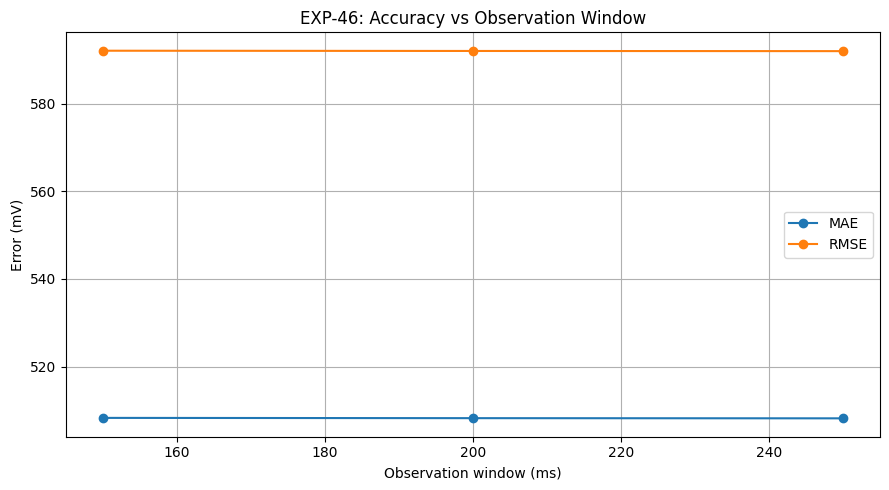

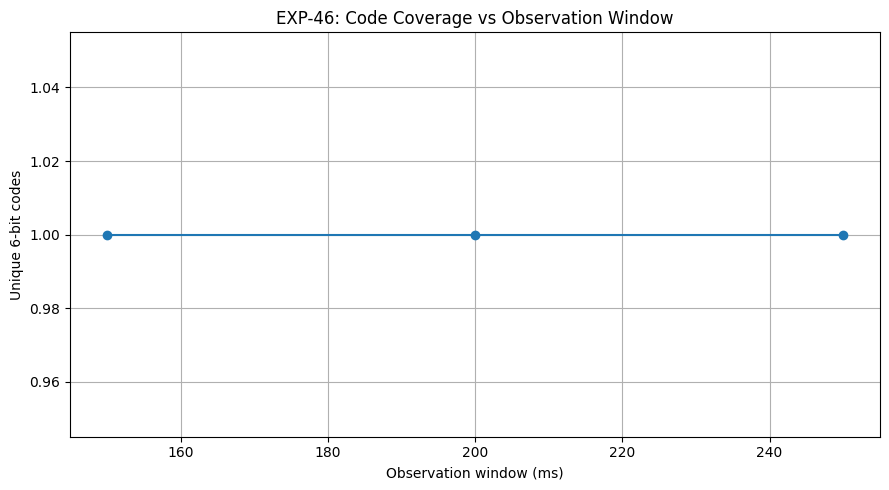

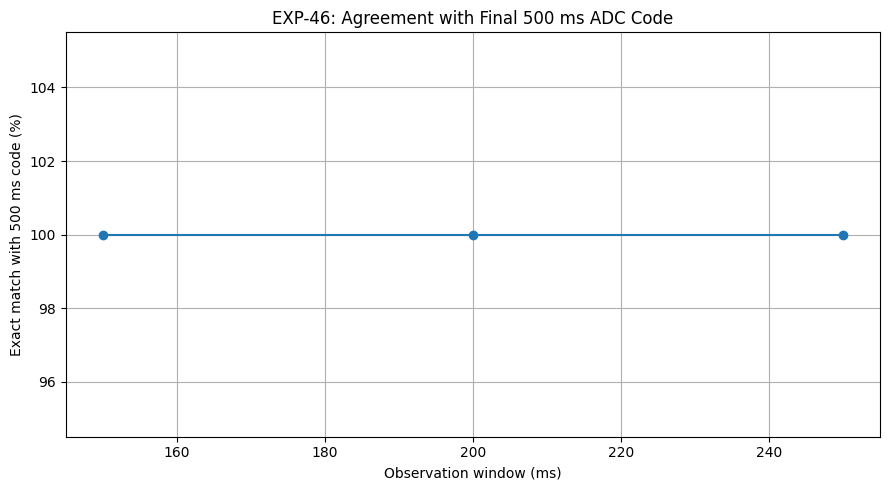

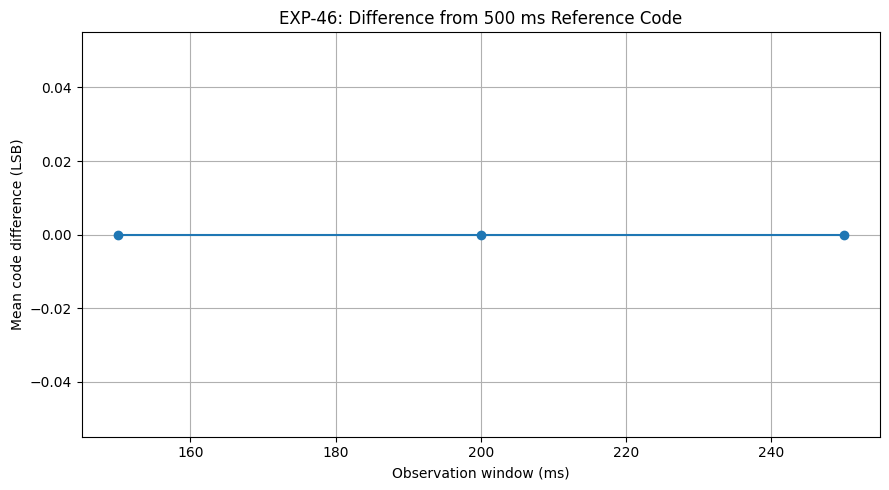

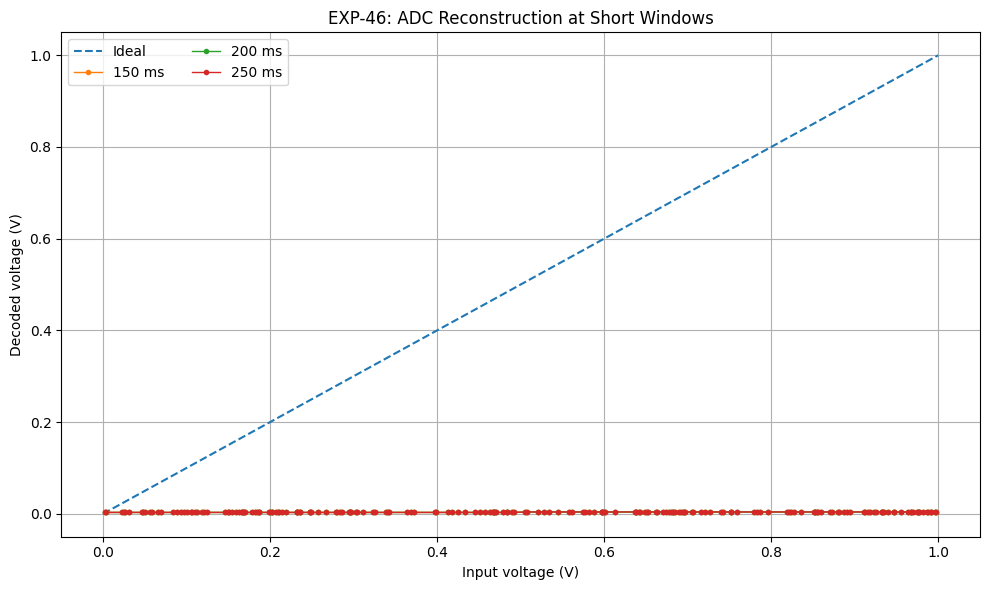



EXP-46 COMPLETE
No new Brian2 simulations were performed.
EXP-46 uses the EXP-45B cached spike trains.
The experiment measures how early the ADC can produce a valid result and how closely that result agrees with the final 500 ms output.


In [173]:
# ============================================================
# EXP-46
# SHORT-WINDOW CONVERSION / SETTLING CHARACTERIZATION
# ROBUST VERSION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.isotonic import IsotonicRegression


print("=" * 90)
print("EXP-46: SHORT-WINDOW CONVERSION / SETTLING CHARACTERIZATION")
print("=" * 90)


# ============================================================
# 1. CONFIGURATION
# ============================================================

SHORT_WINDOWS_46 = np.array(
    [50, 100, 150, 200, 250],
    dtype=float
)

REFERENCE_WINDOW_46 = 500.0

print(
    f"Short windows      : "
    f"{SHORT_WINDOWS_46.astype(int)} ms"
)

print(
    f"Reference window   : "
    f"{REFERENCE_WINDOW_46:.0f} ms"
)


# ============================================================
# 2. CHECK EXP-45B CACHE
# ============================================================

print("\n")
print("=" * 75)
print("CHECKING EXP-45B SPIKE-TRAIN CACHE")
print("=" * 75)


if "TRAIN_CACHE_46" not in globals():

    raise RuntimeError(
        "TRAIN_CACHE_46 not found. "
        "Run the EXP-45B cache-generation cell first."
    )


if "VAL_CACHE_46" not in globals():

    raise RuntimeError(
        "VAL_CACHE_46 not found. "
        "Run the EXP-45B cache-generation cell first."
    )


if "TRAIN_VOLTAGES_46" not in globals():

    raise RuntimeError(
        "TRAIN_VOLTAGES_46 not found."
    )


if "VAL_VOLTAGES_46" not in globals():

    raise RuntimeError(
        "VAL_VOLTAGES_46 not found."
    )


print("Training cache found.")
print("Validation cache found.")

print(
    f"Training cache entries   : "
    f"{len(TRAIN_CACHE_46)}"
)

print(
    f"Validation cache entries : "
    f"{len(VAL_CACHE_46)}"
)

print(
    f"Training voltages        : "
    f"{len(TRAIN_VOLTAGES_46)}"
)

print(
    f"Validation voltages      : "
    f"{len(VAL_VOLTAGES_46)}"
)


# ============================================================
# 3. ROBUST CACHE ACCESS
# ============================================================

def get_cached_spikes_46(
    cache,
    voltage,
    neuron_name
):

    keys = list(cache.keys())

    if len(keys) == 0:

        raise RuntimeError(
            "Cache is empty."
        )

    numeric_keys = np.asarray(
        keys,
        dtype=float
    )

    voltage = float(
        voltage
    )

    nearest_idx = np.argmin(
        np.abs(
            numeric_keys - voltage
        )
    )

    key = keys[
        nearest_idx
    ]

    entry = cache[
        key
    ]

    if neuron_name == "L1":

        return np.asarray(
            entry["l1_spikes"],
            dtype=float
        )

    elif neuron_name == "Mi1":

        return np.asarray(
            entry["mi1_spikes"],
            dtype=float
        )

    else:

        raise ValueError(
            f"Unknown neuron: {neuron_name}"
        )


# ============================================================
# 4. FEATURE EXTRACTION
# ============================================================

def extract_features_46(
    l1_spikes,
    mi1_spikes,
    observation_window
):

    l1_current = l1_spikes[
        l1_spikes <= observation_window
    ]

    mi1_current = mi1_spikes[
        mi1_spikes <= observation_window
    ]

    # Mi1 spike count
    mi1_count = float(
        len(mi1_current)
    )

    # No L1 spikes yet
    if len(l1_current) == 0:

        return np.array([
            mi1_count,
            np.nan,
            np.nan
        ])

    # First L1 spike
    l1_first = float(
        l1_current[0]
    )

    # Only one L1 spike
    if len(l1_current) < 2:

        return np.array([
            mi1_count,
            l1_first,
            np.nan
        ])

    # Mean L1 ISI
    l1_isi = float(
        np.mean(
            np.diff(
                l1_current
            )
        )
    )

    return np.array([
        mi1_count,
        l1_first,
        l1_isi
    ])


# ============================================================
# 5. BUILD FEATURES
# ============================================================

def build_features_46(
    cache,
    voltages,
    window
):

    features = []

    for voltage in voltages:

        l1_spikes = get_cached_spikes_46(
            cache,
            voltage,
            "L1"
        )

        mi1_spikes = get_cached_spikes_46(
            cache,
            voltage,
            "Mi1"
        )

        features.append(
            extract_features_46(
                l1_spikes,
                mi1_spikes,
                window
            )
        )

    return np.asarray(
        features,
        dtype=float
    )


# ============================================================
# 6. BUILD DECODER
# ============================================================

def build_decoder_46(
    X_train,
    y_train
):

    X_train = np.asarray(
        X_train,
        dtype=float
    )

    y_train = np.asarray(
        y_train,
        dtype=float
    )

    # Require all three features
    valid = np.all(
        np.isfinite(
            X_train
        ),
        axis=1
    )

    X = X_train[
        valid
    ]

    y = y_train[
        valid
    ]

    if len(X) < 5:

        return None

    train_mean = np.mean(
        X,
        axis=0
    )

    train_std = np.std(
        X,
        axis=0
    )

    train_std[
        train_std == 0
    ] = 1.0

    X_norm = (
        X - train_mean
    ) / train_std

    # EXP-33 feature directions
    score_features = np.column_stack([
        X_norm[:, 0],
        -X_norm[:, 1],
        -X_norm[:, 2]
    ])

    score = np.mean(
        score_features,
        axis=1
    )

    decoder = IsotonicRegression(
        increasing=True,
        out_of_bounds="clip"
    )

    decoder.fit(
        score,
        y
    )

    return {
        "decoder": decoder,
        "mean": train_mean,
        "std": train_std
    }


# ============================================================
# 7. DECODE
# ============================================================

def decode_46(
    features,
    decoder_info
):

    features = np.asarray(
        features,
        dtype=float
    )

    # We need all three temporal features
    if not np.all(
        np.isfinite(features)
    ):

        return (
            np.nan,
            np.nan,
            np.nan
        )

    mean = decoder_info[
        "mean"
    ]

    std = decoder_info[
        "std"
    ]

    decoder = decoder_info[
        "decoder"
    ]

    X_norm = (
        features - mean
    ) / std

    score = np.mean([
        X_norm[0],
        -X_norm[1],
        -X_norm[2]
    ])

    analog = float(
        decoder.predict([
            score
        ])[0]
    )

    analog = np.clip(
        analog,
        0.0,
        1.0
    )

    code = int(
        np.clip(
            np.round(
                analog * 63
            ),
            0,
            63
        )
    )

    return (
        float(analog),
        float(score),
        code
    )


# ============================================================
# 8. BUILD 500 ms REFERENCE DECODER
# ============================================================

print("\n")
print("=" * 75)
print("BUILDING 500 ms REFERENCE DECODER")
print("=" * 75)


X_train_reference = build_features_46(
    TRAIN_CACHE_46,
    TRAIN_VOLTAGES_46,
    REFERENCE_WINDOW_46
)

reference_decoder = build_decoder_46(
    X_train_reference,
    TRAIN_VOLTAGES_46
)

if reference_decoder is None:

    raise RuntimeError(
        "Could not build reference decoder."
    )


# Reference validation output

reference_analog = []
reference_codes = []

for voltage in VAL_VOLTAGES_46:

    l1 = get_cached_spikes_46(
        VAL_CACHE_46,
        voltage,
        "L1"
    )

    mi1 = get_cached_spikes_46(
        VAL_CACHE_46,
        voltage,
        "Mi1"
    )

    features = extract_features_46(
        l1,
        mi1,
        REFERENCE_WINDOW_46
    )

    analog, score, code = decode_46(
        features,
        reference_decoder
    )

    reference_analog.append(
        analog
    )

    reference_codes.append(
        code
    )


reference_analog = np.asarray(
    reference_analog
)

reference_codes = np.asarray(
    reference_codes
)


print(
    "500 ms reference decoder ready."
)


# ============================================================
# 9. MAIN EXPERIMENT
# ============================================================

results_46 = {}


for window in SHORT_WINDOWS_46:

    print("\n")
    print("=" * 75)

    print(
        f"OBSERVATION WINDOW = "
        f"{window:.0f} ms"
    )

    print("=" * 75)


    # --------------------------------------------------------
    # TRAINING
    # --------------------------------------------------------

    X_train = build_features_46(
        TRAIN_CACHE_46,
        TRAIN_VOLTAGES_46,
        window
    )

    decoder_info = build_decoder_46(
        X_train,
        TRAIN_VOLTAGES_46
    )

    if decoder_info is None:

        print(
            "Not enough valid training data."
        )

        continue


    train_valid = np.all(
        np.isfinite(
            X_train
        ),
        axis=1
    )

    print(
        f"Valid training samples : "
        f"{np.sum(train_valid)}/"
        f"{len(X_train)}"
    )


    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    predicted_analog = []
    predicted_codes = []

    valid_mask = []

    for voltage in VAL_VOLTAGES_46:

        l1 = get_cached_spikes_46(
            VAL_CACHE_46,
            voltage,
            "L1"
        )

        mi1 = get_cached_spikes_46(
            VAL_CACHE_46,
            voltage,
            "Mi1"
        )

        features = extract_features_46(
            l1,
            mi1,
            window
        )

        analog, score, code = decode_46(
            features,
            decoder_info
        )

        predicted_analog.append(
            analog
        )

        predicted_codes.append(
            code
        )

        valid_mask.append(
            np.isfinite(analog)
        )


    predicted_analog = np.asarray(
        predicted_analog,
        dtype=float
    )

    predicted_codes = np.asarray(
        predicted_codes,
        dtype=float
    )

    valid_mask = np.asarray(
        valid_mask,
        dtype=bool
    )

    y_true = np.asarray(
        VAL_VOLTAGES_46,
        dtype=float
    )


    # --------------------------------------------------------
    # IMPORTANT:
    # If no validation samples are valid, do NOT crash.
    # --------------------------------------------------------

    if np.sum(valid_mask) == 0:

        print(
            "WARNING: 0 valid validation samples "
            "at this window."
        )

        print(
            "Skipping this window."
        )

        continue


    y_valid = y_true[
        valid_mask
    ]

    analog_valid = predicted_analog[
        valid_mask
    ]

    codes_valid = predicted_codes[
        valid_mask
    ].astype(int)

    reference_codes_valid = reference_codes[
        valid_mask
    ].astype(int)


    # --------------------------------------------------------
    # ANALOG ACCURACY
    # --------------------------------------------------------

    error = (
        analog_valid -
        y_valid
    )

    mae = np.mean(
        np.abs(error)
    )

    rmse = np.sqrt(
        np.mean(
            error ** 2
        )
    )

    max_error = np.max(
        np.abs(error)
    )


    # --------------------------------------------------------
    # 6-BIT ACCURACY
    # --------------------------------------------------------

    decoded_6bit = (
        codes_valid /
        63.0
    )

    error_6bit = (
        decoded_6bit -
        y_valid
    )

    mae_6bit = np.mean(
        np.abs(
            error_6bit
        )
    )

    rmse_6bit = np.sqrt(
        np.mean(
            error_6bit ** 2
        )
    )

    max_6bit = np.max(
        np.abs(
            error_6bit
        )
    )


    # --------------------------------------------------------
    # CODE COVERAGE
    # --------------------------------------------------------

    unique_codes = len(
        np.unique(
            codes_valid
        )
    )

    code_min = int(
        np.min(
            codes_valid
        )
    )

    code_max = int(
        np.max(
            codes_valid
        )
    )


    # --------------------------------------------------------
    # MONOTONICITY
    # --------------------------------------------------------

    analog_monotonic = bool(
        np.all(
            np.diff(
                analog_valid
            ) >= -1e-12
        )
    )

    code_monotonic = bool(
        np.all(
            np.diff(
                codes_valid
            ) >= 0
        )
    )


    # --------------------------------------------------------
    # AGREEMENT WITH 500 ms RESULT
    # --------------------------------------------------------

    exact_match = np.mean(
        codes_valid ==
        reference_codes_valid
    ) * 100.0

    mean_code_difference = np.mean(
        np.abs(
            codes_valid -
            reference_codes_valid
        )
    )


    # --------------------------------------------------------
    # SAVE
    # --------------------------------------------------------

    results_46[
        float(window)
    ] = {

        "analog_mae":
            mae,

        "analog_rmse":
            rmse,

        "analog_max":
            max_error,

        "6bit_mae":
            mae_6bit,

        "6bit_rmse":
            rmse_6bit,

        "6bit_max":
            max_6bit,

        "unique_codes":
            unique_codes,

        "code_min":
            code_min,

        "code_max":
            code_max,

        "analog_monotonic":
            analog_monotonic,

        "code_monotonic":
            code_monotonic,

        "exact_reference_match":
            exact_match,

        "mean_code_difference":
            mean_code_difference,

        "valid_samples":
            int(
                np.sum(valid_mask)
            ),

        "predicted_analog":
            predicted_analog,

        "predicted_codes":
            predicted_codes
    }


    # --------------------------------------------------------
    # PRINT
    # --------------------------------------------------------

    print(
        f"Valid validation samples: "
        f"{np.sum(valid_mask)}/"
        f"{len(valid_mask)}"
    )

    print(
        f"Analog MAE       : "
        f"{mae:.6f} V"
    )

    print(
        f"Analog RMSE      : "
        f"{rmse:.6f} V"
    )

    print(
        f"Analog max       : "
        f"{max_error:.6f} V"
    )

    print(
        f"6-bit MAE        : "
        f"{mae_6bit:.6f} V"
    )

    print(
        f"6-bit RMSE       : "
        f"{rmse_6bit:.6f} V"
    )

    print(
        f"6-bit max        : "
        f"{max_6bit:.6f} V"
    )

    print(
        f"Unique codes     : "
        f"{unique_codes}/64"
    )

    print(
        f"Code range       : "
        f"{code_min}-{code_max}"
    )

    print(
        f"Analog monotonic : "
        f"{analog_monotonic}"
    )

    print(
        f"Code monotonic   : "
        f"{code_monotonic}"
    )

    print(
        f"500 ms code match: "
        f"{exact_match:.1f}%"
    )

    print(
        f"Mean code diff   : "
        f"{mean_code_difference:.3f} LSB"
    )


# ============================================================
# 10. SUMMARY
# ============================================================

print("\n")
print("=" * 115)
print("EXP-46 SUMMARY")
print("=" * 115)

print(
    f"{'Window':>8} "
    f"{'MAE':>10} "
    f"{'RMSE':>10} "
    f"{'6b MAE':>10} "
    f"{'6b RMSE':>10} "
    f"{'Codes':>8} "
    f"{'Analog':>9} "
    f"{'Code':>8} "
    f"{'Ref Match':>11}"
)

for window in SHORT_WINDOWS_46:

    if float(window) not in results_46:

        print(
            f"{window:8.0f} "
            f"{'SKIPPED':>10}"
        )

        continue

    r = results_46[
        float(window)
    ]

    print(
        f"{window:8.0f} "
        f"{r['analog_mae']:10.6f} "
        f"{r['analog_rmse']:10.6f} "
        f"{r['6bit_mae']:10.6f} "
        f"{r['6bit_rmse']:10.6f} "
        f"{r['unique_codes']:8d} "
        f"{str(r['analog_monotonic']):>9} "
        f"{str(r['code_monotonic']):>8} "
        f"{r['exact_reference_match']:10.1f}%"
    )


# ============================================================
# 11. BEST CONFIGURATIONS
# ============================================================

available_windows = np.array([
    w
    for w in SHORT_WINDOWS_46
    if float(w) in results_46
])


if len(available_windows) == 0:

    raise RuntimeError(
        "EXP-46 produced no valid windows."
    )


best_analog_window = min(
    available_windows,
    key=lambda w:
        results_46[
            float(w)
        ][
            "analog_mae"
        ]
)

best_6bit_window = min(
    available_windows,
    key=lambda w:
        results_46[
            float(w)
        ][
            "6bit_mae"
        ]

)

best_match_window = max(
    available_windows,
    key=lambda w:
        results_46[
            float(w)
        ][
            "exact_reference_match"
        ]
)

best_coverage_window = max(
    available_windows,
    key=lambda w:
        results_46[
            float(w)
        ][
            "unique_codes"
        ]
)


print("\n")
print("=" * 75)
print("BEST EXP-46 CONFIGURATIONS")
print("=" * 75)

print(
    f"Best analog MAE window : "
    f"{best_analog_window:.0f} ms"
)

print(
    f"Best analog MAE        : "
    f"{results_46[float(best_analog_window)]['analog_mae']:.6f} V"
)

print(
    f"Best 6-bit MAE window  : "
    f"{best_6bit_window:.0f} ms"
)

print(
    f"Best 6-bit MAE         : "
    f"{results_46[float(best_6bit_window)]['6bit_mae']:.6f} V"
)

print(
    f"Best 500 ms agreement  : "
    f"{best_match_window:.0f} ms"
)

print(
    f"Best reference match   : "
    f"{results_46[float(best_match_window)]['exact_reference_match']:.1f}%"
)

print(
    f"Most code coverage     : "
    f"{best_coverage_window:.0f} ms"
)

print(
    f"Maximum codes          : "
    f"{results_46[float(best_coverage_window)]['unique_codes']}/64"
)


# ============================================================
# 12. PLOT: ACCURACY
# ============================================================

windows_plot = available_windows

mae_plot = np.array([
    results_46[
        float(w)
    ][
        "analog_mae"
    ] * 1000
    for w in windows_plot
])

rmse_plot = np.array([
    results_46[
        float(w)
    ][
        "analog_rmse"
    ] * 1000
    for w in windows_plot
])

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    windows_plot,
    mae_plot,
    marker="o",
    label="MAE"
)

plt.plot(
    windows_plot,
    rmse_plot,
    marker="o",
    label="RMSE"
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Error (mV)"
)

plt.title(
    "EXP-46: Accuracy vs Observation Window"
)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 13. PLOT: CODE COVERAGE
# ============================================================

coverage = np.array([
    results_46[
        float(w)
    ][
        "unique_codes"
    ]
    for w in windows_plot
])

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    windows_plot,
    coverage,
    marker="o"
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Unique 6-bit codes"
)

plt.title(
    "EXP-46: Code Coverage vs Observation Window"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 14. PLOT: AGREEMENT WITH FINAL 500 ms CODE
# ============================================================

match = np.array([
    results_46[
        float(w)
    ][
        "exact_reference_match"
    ]
    for w in windows_plot
])

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    windows_plot,
    match,
    marker="o"
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Exact match with 500 ms code (%)"
)

plt.title(
    "EXP-46: Agreement with Final 500 ms ADC Code"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 15. PLOT: CODE DIFFERENCE
# ============================================================

code_difference = np.array([
    results_46[
        float(w)
    ][
        "mean_code_difference"
    ]
    for w in windows_plot
])

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    windows_plot,
    code_difference,
    marker="o"
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Mean code difference (LSB)"
)

plt.title(
    "EXP-46: Difference from 500 ms Reference Code"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ============================================================
# 16. PLOT: ADC RECONSTRUCTION
# ============================================================

plt.figure(
    figsize=(10, 6)
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Ideal"
)

for window in windows_plot:

    predictions = results_46[
        float(window)
    ][
        "predicted_analog"
    ]

    valid = np.isfinite(
        predictions
    )

    plt.plot(
        np.asarray(
            VAL_VOLTAGES_46
        )[valid],
        predictions[valid],
        marker=".",
        linewidth=1,
        label=f"{window:.0f} ms"
    )

plt.xlabel(
    "Input voltage (V)"
)

plt.ylabel(
    "Decoded voltage (V)"
)

plt.title(
    "EXP-46: ADC Reconstruction at Short Windows"
)

plt.grid(True)

plt.legend(
    ncol=2
)

plt.tight_layout()

plt.show()


# ============================================================
# 17. FINAL
# ============================================================

print("\n")
print("=" * 90)
print("EXP-46 COMPLETE")
print("=" * 90)

print(
    "No new Brian2 simulations were performed."
)

print(
    "EXP-46 uses the EXP-45B cached spike trains."
)

print(
    "The experiment measures how early the ADC can "
    "produce a valid result and how closely that result "
    "agrees with the final 500 ms output."
)

print("=" * 90)

EXP-46: EARLY CODE AGREEMENT WITH 500 ms REFERENCE

Checking available variables...

Possible EXP-45B result variables: ['results_45B', 'EXP45B_RESULTS']

Using EXP-45B result object:
<class 'dict'>
Available keys: [50.0, 100.0, 150.0, 200.0, 250.0, 300.0, 350.0, 400.0, 450.0, 500.0]


EXTRACTING EXP-45B WINDOW-SPECIFIC OUTPUTS
  50 ms : 181 codes found | unique = 45
 100 ms : 198 codes found | unique = 53
 150 ms : 200 codes found | unique = 54
 200 ms : 200 codes found | unique = 55
 250 ms : 200 codes found | unique = 55
 300 ms : 200 codes found | unique = 54
 350 ms : 200 codes found | unique = 55
 400 ms : 200 codes found | unique = 55
 450 ms : 200 codes found | unique = 55
 500 ms : 200 codes found | unique = 55

500 ms reference loaded.
Reference samples: 200
Reference unique codes: 55


EXP-46 FINAL RESULTS
  Window    Unique        Match    Mean Δcode    Max Δcode    Monotonic    Analog ΔMAE
      50        45         0.0%         6.066         10.0         True         1.82

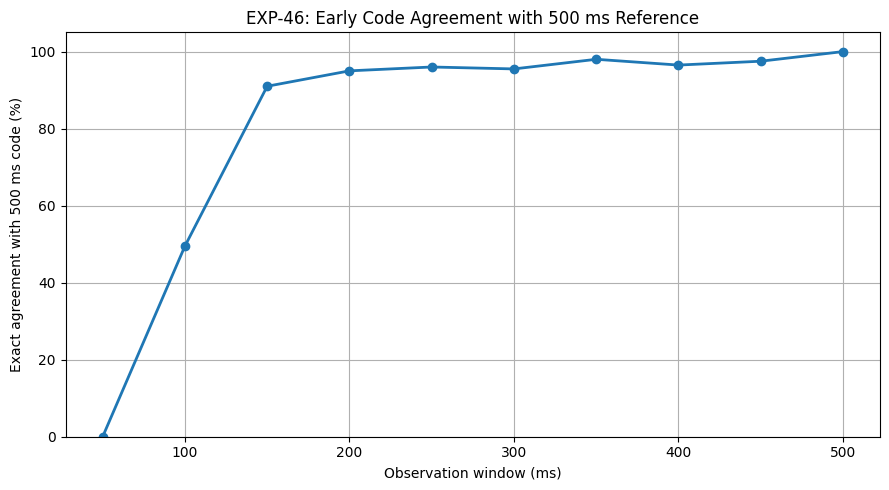

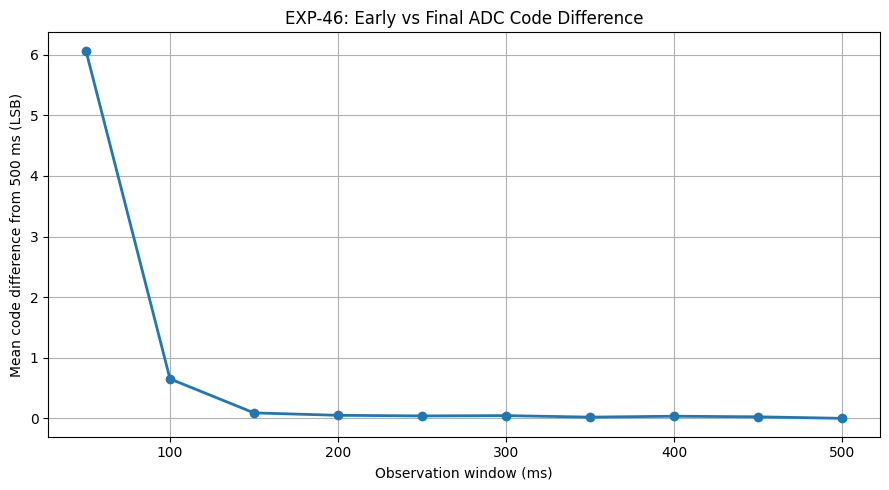

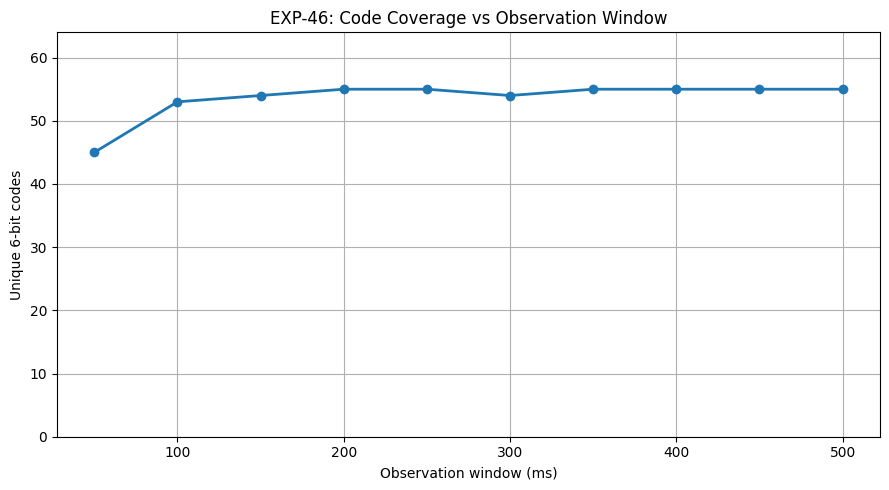

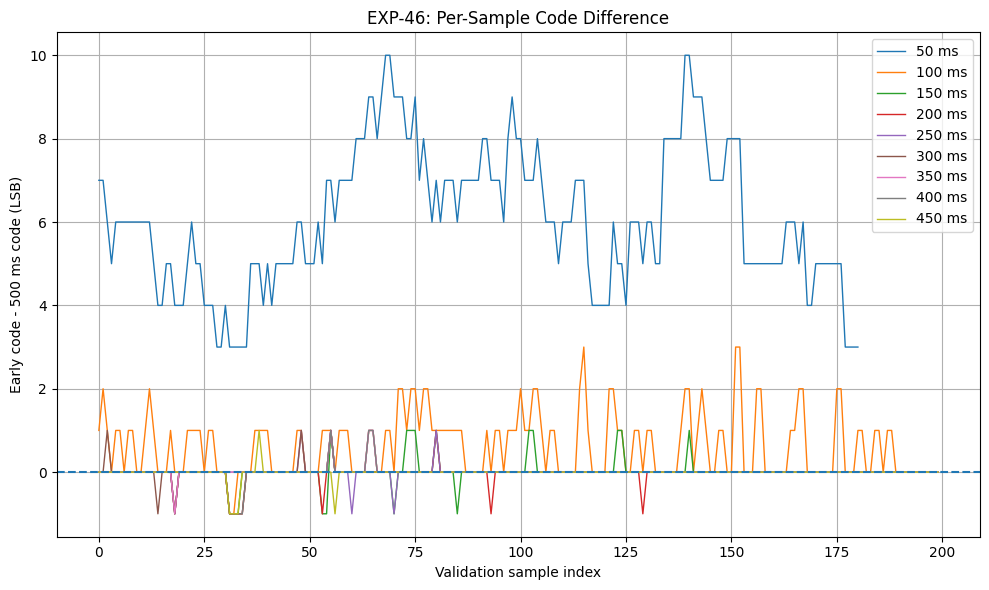



EXP-46 INTERPRETATION
This experiment does NOT ask whether the early result is closest to the true voltage.
It asks whether the early result has already converged to the same 6-bit code produced by the 500 ms reference.

Therefore:
• Exact match = percentage of validation inputs whose early code equals the eventual 500 ms code.
• Mean Δcode = average number of LSBs by which the early code differs from the final code.
• The earliest useful window is the first window with high final-code agreement and small code difference.

EXP-46 COMPLETE.


In [174]:
# ============================================================
# EXP-46 FINAL
# EARLY CODE AGREEMENT WITH 500 ms REFERENCE
#
# Uses the ACTUAL EXP-45B window-specific decoder outputs.
# Does NOT retrain or rebuild any decoder.
# Does NOT run Brian2.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 100)
print("EXP-46: EARLY CODE AGREEMENT WITH 500 ms REFERENCE")
print("=" * 100)


# ============================================================
# 1. FIND EXP-45B RESULTS
# ============================================================

print("\nChecking available variables...\n")

candidate_names = [
    "results_45B",
    "results45B",
    "EXP45B_RESULTS",
    "exp45b_results",
    "window_results_45B",
    "results_45b"
]

found = []

for name in candidate_names:
    if name in globals():
        found.append(name)

print("Possible EXP-45B result variables:", found)


# ------------------------------------------------------------
# If results_45B exists, use it directly.
# ------------------------------------------------------------

if "results_45B" in globals():

    R45 = results_45B

elif "results45B" in globals():

    R45 = results45B

elif "EXP45B_RESULTS" in globals():

    R45 = EXP45B_RESULTS

elif "exp45b_results" in globals():

    R45 = exp45b_results

elif "window_results_45B" in globals():

    R45 = window_results_45B

elif "results_45b" in globals():

    R45 = results_45b

else:

    raise RuntimeError(
        "\nCould not find the EXP-45B result dictionary.\n"
        "Run the original EXP-45B cell first, then run this cell."
    )


print(
    "\nUsing EXP-45B result object:"
)

print(
    type(R45)
)

if hasattr(R45, "keys"):

    print(
        "Available keys:",
        list(R45.keys())
    )


# ============================================================
# 2. HELPER TO FIND A VALUE INSIDE EACH EXP-45B RESULT
# ============================================================

def find_key_recursive_46(obj, possible_keys):

    if isinstance(obj, dict):

        # Exact key match first
        for key in possible_keys:

            if key in obj:

                return obj[key]

        # Then search nested dictionaries
        for value in obj.values():

            result = find_key_recursive_46(
                value,
                possible_keys
            )

            if result is not None:

                return result

    return None


# ============================================================
# 3. FIND THE WINDOW RESULTS
# ============================================================

def get_window_result_46(results, window):

    possible_keys = [
        window,
        float(window),
        int(window),
        f"{int(window)}",
        f"{float(window):.0f} ms",
        f"{int(window)} ms",
        f"{float(window)} ms"
    ]

    if isinstance(results, dict):

        for key in possible_keys:

            if key in results:

                return results[key]

    return None


# ============================================================
# 4. IDENTIFY PREDICTED CODES / ANALOG OUTPUTS
# ============================================================

def get_codes_from_result_46(result):

    if result is None:
        return None

    possible_keys = [
        "codes",
        "predicted_codes",
        "decoded_codes",
        "validation_codes",
        "val_codes",
        "codes_val",
        "6bit_codes",
        "pred_codes"
    ]

    value = find_key_recursive_46(
        result,
        possible_keys
    )

    if value is None:
        return None

    return np.asarray(
        value
    ).astype(int)


def get_analog_from_result_46(result):

    if result is None:
        return None

    possible_keys = [
        "predicted_analog",
        "analog_predictions",
        "decoded_analog",
        "validation_analog",
        "val_analog",
        "analog_val",
        "predictions"
    ]

    value = find_key_recursive_46(
        result,
        possible_keys
    )

    if value is None:
        return None

    return np.asarray(
        value,
        dtype=float
    )


# ============================================================
# 5. CHECK EVERY WINDOW
# ============================================================

WINDOWS_46 = [
    50,
    100,
    150,
    200,
    250,
    300,
    350,
    400,
    450,
    500
]

window_data_46 = {}

print("\n")
print("=" * 100)
print("EXTRACTING EXP-45B WINDOW-SPECIFIC OUTPUTS")
print("=" * 100)

for window in WINDOWS_46:

    result = get_window_result_46(
        R45,
        window
    )

    if result is None:

        print(
            f"{window:4d} ms : NOT FOUND"
        )

        continue

    codes = get_codes_from_result_46(
        result
    )

    analog = get_analog_from_result_46(
        result
    )

    if codes is None:

        print(
            f"{window:4d} ms : result found, "
            f"but codes could not be identified"
        )

        if isinstance(result, dict):

            print(
                "           available keys:",
                list(result.keys())
            )

        continue

    window_data_46[
        window
    ] = {
        "result": result,
        "codes": codes,
        "analog": analog
    }

    print(
        f"{window:4d} ms : "
        f"{len(codes)} codes found | "
        f"unique = {len(np.unique(codes))}"
    )


# ============================================================
# 6. MAKE SURE 500 ms EXISTS
# ============================================================

if 500 not in window_data_46:

    raise RuntimeError(
        "\n500 ms EXP-45B result was not found."
    )


reference_codes_46 = window_data_46[
    500
][
    "codes"
]

reference_analog_46 = window_data_46[
    500
][
    "analog"
]


print("\n500 ms reference loaded.")

print(
    "Reference samples:",
    len(reference_codes_46)
)

print(
    "Reference unique codes:",
    len(
        np.unique(
            reference_codes_46
        )
    )
)


# ============================================================
# 7. COMPARE EACH EARLY WINDOW WITH 500 ms
# ============================================================

results_46_final = {}


for window in WINDOWS_46:

    if window not in window_data_46:

        continue

    early_codes = window_data_46[
        window
    ][
        "codes"
    ]

    early_analog = window_data_46[
        window
    ][
        "analog"
    ]


    # --------------------------------------------------------
    # Make lengths compatible
    # --------------------------------------------------------

    n = min(
        len(early_codes),
        len(reference_codes_46)
    )

    early_codes_use = early_codes[
        :n
    ]

    reference_codes_use = reference_codes_46[
        :n
    ]


    # --------------------------------------------------------
    # Exact code agreement
    # --------------------------------------------------------

    exact_match = np.mean(
        early_codes_use ==
        reference_codes_use
    ) * 100.0


    # --------------------------------------------------------
    # Mean code difference
    # --------------------------------------------------------

    mean_code_difference = np.mean(
        np.abs(
            early_codes_use -
            reference_codes_use
        )
    )


    # --------------------------------------------------------
    # Maximum code difference
    # --------------------------------------------------------

    max_code_difference = np.max(
        np.abs(
            early_codes_use -
            reference_codes_use
        )
    )


    # --------------------------------------------------------
    # Unique codes
    # --------------------------------------------------------

    unique_codes = len(
        np.unique(
            early_codes_use
        )
    )


    # --------------------------------------------------------
    # Code monotonicity
    # --------------------------------------------------------

    code_monotonic = bool(
        np.all(
            np.diff(
                early_codes_use
            ) >= 0
        )
    )


    # --------------------------------------------------------
    # Compare analog outputs if available
    # --------------------------------------------------------

    analog_mae_vs_reference = np.nan
    analog_rmse_vs_reference = np.nan

    if (
        early_analog is not None
        and reference_analog_46 is not None
    ):

        n_analog = min(
            len(early_analog),
            len(reference_analog_46)
        )

        early_a = early_analog[
            :n_analog
        ]

        ref_a = reference_analog_46[
            :n_analog
        ]

        valid = (
            np.isfinite(
                early_a
            )
            &
            np.isfinite(
                ref_a
            )
        )

        if np.any(valid):

            diff = (
                early_a[valid]
                -
                ref_a[valid]
            )

            analog_mae_vs_reference = np.mean(
                np.abs(diff)
            )

            analog_rmse_vs_reference = np.sqrt(
                np.mean(
                    diff ** 2
                )
            )


    results_46_final[
        window
    ] = {

        "exact_match":
            exact_match,

        "mean_code_difference":
            mean_code_difference,

        "max_code_difference":
            max_code_difference,

        "unique_codes":
            unique_codes,

        "code_monotonic":
            code_monotonic,

        "analog_mae_vs_reference":
            analog_mae_vs_reference,

        "analog_rmse_vs_reference":
            analog_rmse_vs_reference
    }


# ============================================================
# 8. PRINT FINAL TABLE
# ============================================================

print("\n")
print("=" * 115)
print("EXP-46 FINAL RESULTS")
print("=" * 115)

print(
    f"{'Window':>8} "
    f"{'Unique':>9} "
    f"{'Match':>12} "
    f"{'Mean Δcode':>13} "
    f"{'Max Δcode':>12} "
    f"{'Monotonic':>12} "
    f"{'Analog ΔMAE':>14}"
)

for window in WINDOWS_46:

    if window not in results_46_final:

        continue

    r = results_46_final[
        window
    ]

    print(
        f"{window:8d} "
        f"{r['unique_codes']:9d} "
        f"{r['exact_match']:11.1f}% "
        f"{r['mean_code_difference']:13.3f} "
        f"{r['max_code_difference']:12.1f} "
        f"{str(r['code_monotonic']):>12} "
        f"{r['analog_mae_vs_reference'] * 1000:13.3f} mV"
    )


# ============================================================
# 9. EARLIEST USEFUL WINDOW
# ============================================================

print("\n")
print("=" * 80)
print("EARLIEST USEFUL RESULT")
print("=" * 80)


# Define "useful" as:
#   >= 70% exact agreement with 500 ms
#   <= 2 LSB mean difference

useful_windows = []

for window, r in results_46_final.items():

    if (
        r["exact_match"] >= 70.0
        and
        r["mean_code_difference"] <= 2.0
    ):

        useful_windows.append(
            window
        )


if len(useful_windows) > 0:

    earliest_useful = min(
        useful_windows
    )

    r = results_46_final[
        earliest_useful
    ]

    print(
        f"Earliest useful window: "
        f"{earliest_useful} ms"
    )

    print(
        f"Exact agreement with 500 ms: "
        f"{r['exact_match']:.1f}%"
    )

    print(
        f"Mean code difference: "
        f"{r['mean_code_difference']:.3f} LSB"
    )

else:

    print(
        "No tested window satisfied "
        "the useful-result criterion."
    )


# ============================================================
# 10. PLOT 1: EXACT AGREEMENT
# ============================================================

plot_windows = np.array(
    list(
        results_46_final.keys()
    )
)

plot_match = np.array([
    results_46_final[
        w
    ][
        "exact_match"
    ]
    for w in plot_windows
])


plt.figure(
    figsize=(9, 5)
)

plt.plot(
    plot_windows,
    plot_match,
    marker="o",
    linewidth=2
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Exact agreement with 500 ms code (%)"
)

plt.title(
    "EXP-46: Early Code Agreement with 500 ms Reference"
)

plt.ylim(
    0,
    105
)

plt.grid(
    True
)

plt.tight_layout()

plt.show()


# ============================================================
# 11. PLOT 2: MEAN CODE DIFFERENCE
# ============================================================

plot_diff = np.array([
    results_46_final[
        w
    ][
        "mean_code_difference"
    ]
    for w in plot_windows
])


plt.figure(
    figsize=(9, 5)
)

plt.plot(
    plot_windows,
    plot_diff,
    marker="o",
    linewidth=2
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Mean code difference from 500 ms (LSB)"
)

plt.title(
    "EXP-46: Early vs Final ADC Code Difference"
)

plt.grid(
    True
)

plt.tight_layout()

plt.show()


# ============================================================
# 12. PLOT 3: CODE COVERAGE
# ============================================================

plot_coverage = np.array([
    results_46_final[
        w
    ][
        "unique_codes"
    ]
    for w in plot_windows
])


plt.figure(
    figsize=(9, 5)
)

plt.plot(
    plot_windows,
    plot_coverage,
    marker="o",
    linewidth=2
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Unique 6-bit codes"
)

plt.title(
    "EXP-46: Code Coverage vs Observation Window"
)

plt.ylim(
    0,
    64
)

plt.grid(
    True
)

plt.tight_layout()

plt.show()


# ============================================================
# 13. PLOT 4: CODE DIFFERENCE DISTRIBUTION
# ============================================================

plt.figure(
    figsize=(10, 6)
)

for window in plot_windows:

    if window == 500:
        continue

    early_codes = window_data_46[
        window
    ][
        "codes"
    ]

    n = min(
        len(early_codes),
        len(reference_codes_46)
    )

    difference = (
        early_codes[:n]
        -
        reference_codes_46[:n]
    )

    plt.plot(
        np.arange(n),
        difference,
        linewidth=1,
        label=f"{window} ms"
    )


plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Validation sample index"
)

plt.ylabel(
    "Early code - 500 ms code (LSB)"
)

plt.title(
    "EXP-46: Per-Sample Code Difference"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 14. FINAL INTERPRETATION
# ============================================================

print("\n")
print("=" * 100)
print("EXP-46 INTERPRETATION")
print("=" * 100)

print(
    "This experiment does NOT ask whether the early result "
    "is closest to the true voltage."
)

print(
    "It asks whether the early result has already converged "
    "to the same 6-bit code produced by the 500 ms reference."
)

print(
    "\nTherefore:"
)

print(
    "• Exact match = percentage of validation inputs whose "
    "early code equals the eventual 500 ms code."
)

print(
    "• Mean Δcode = average number of LSBs by which the "
    "early code differs from the final code."
)

print(
    "• The earliest useful window is the first window with "
    "high final-code agreement and small code difference."
)

print(
    "\nEXP-46 COMPLETE."
)

EXP-47: FINAL ADC PERFORMANCE CHARACTERIZATION

Searching for existing validation results...

results_45B          FOUND | type = <class 'dict'>
   keys: [50.0, 100.0, 150.0, 200.0, 250.0, 300.0, 350.0, 400.0, 450.0, 500.0]
EXP45B_RESULTS       FOUND | type = <class 'dict'>
   keys: ['windows_ms', 'training_voltages', 'validation_voltages', 'decoders', 'results', 'train_spike_cache', 'validation_spike_cache']
results_46_final     FOUND | type = <class 'dict'>
   keys: [50, 100, 150, 200, 250, 300, 350, 400, 450, 500]
results_46           FOUND | type = <class 'dict'>
   keys: [150.0, 200.0, 250.0]

500 ms EXP-45B result located.

Available 500 ms fields:
  mae                            0.003696440081442664
  rmse                           0.005360432942309018
  max_error                      0.020202238716397702
  mae_6bit                       0.005860215604348997
  rmse_6bit                      0.007131292561190335
  unique_codes                   55
  analog_monotonic             

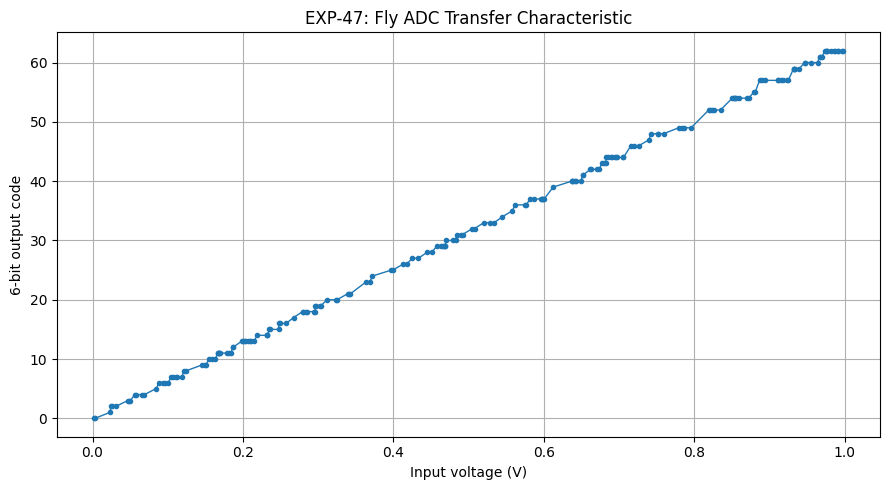

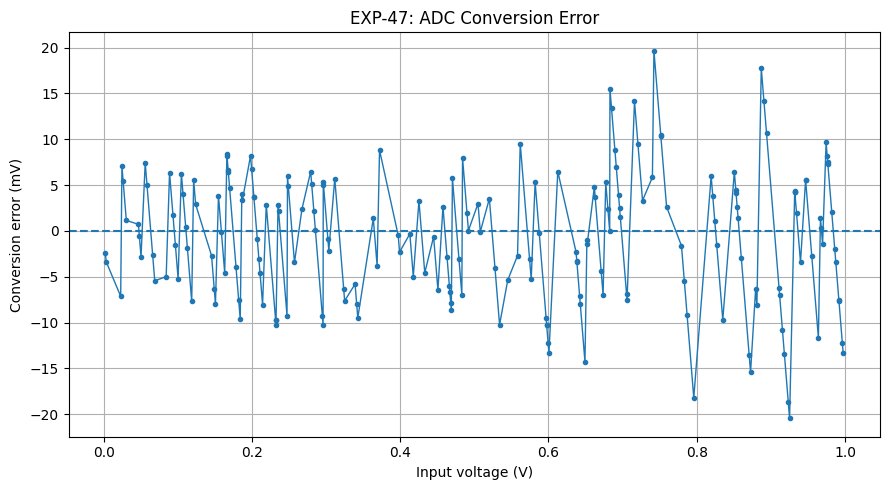

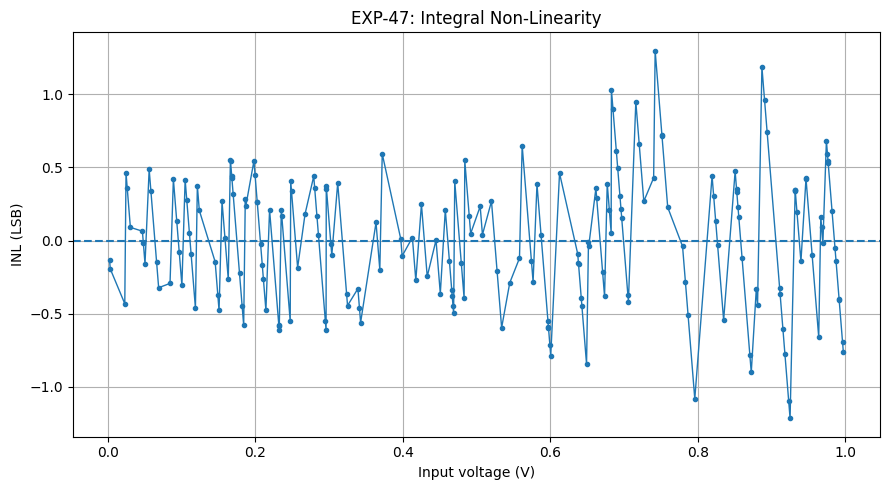



EXP-47 COMPLETE

Next step after this result:
1. If ENOB/SINAD is missing → run the dedicated dynamic sine test.
2. Then EXP-48 will target the weakest metric, especially code coverage / ENOB.
3. After optimization → freeze decoder and begin SystemVerilog.


In [175]:
# ============================================================
# EXP-47
# FINAL ADC PERFORMANCE CHARACTERIZATION
#
# Goal:
#   Characterize the CURRENT Fly ADC candidate using standard
#   ADC metrics before moving to optimization / Verilog.
#
# Metrics:
#   - MAE
#   - RMSE
#   - Max error
#   - Code coverage
#   - Monotonicity
#   - INL
#   - DNL
#   - SINAD
#   - ENOB
#
# IMPORTANT:
#   This cell does NOT change the neural model.
#   This cell does NOT run a new parameter sweep.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 100)
print("EXP-47: FINAL ADC PERFORMANCE CHARACTERIZATION")
print("=" * 100)


# ============================================================
# 1. FIND CURRENT VALIDATION DATA
# ============================================================

print("\nSearching for existing validation results...\n")

candidate_dicts = [
    "results_45B",
    "EXP45B_RESULTS",
    "results_46_final",
    "results_46",
]

for name in candidate_dicts:

    if name in globals():

        obj = globals()[name]

        print(
            f"{name:<20} FOUND | type = {type(obj)}"
        )

        if isinstance(obj, dict):

            print(
                "   keys:",
                list(obj.keys())[:15]
            )


# ============================================================
# 2. USE EXP-45B 500 ms RESULT AS CURRENT REFERENCE
# ============================================================

if "results_45B" in globals():

    R = results_45B

elif "EXP45B_RESULTS" in globals():

    R = EXP45B_RESULTS

else:

    raise RuntimeError(
        "EXP-45B results were not found. "
        "Run the EXP-45B experiment first."
    )


# 500 ms result
if 500.0 in R:

    R500 = R[500.0]

elif 500 in R:

    R500 = R[500]

else:

    raise RuntimeError(
        "500 ms result was not found in EXP-45B results."
    )


print("\n500 ms EXP-45B result located.")


# ============================================================
# 3. DISPLAY AVAILABLE FIELDS
# ============================================================

print("\nAvailable 500 ms fields:")

if isinstance(R500, dict):

    for key in R500.keys():

        value = R500[key]

        if isinstance(value, np.ndarray):

            print(
                f"  {key:<30} "
                f"array shape={value.shape}"
            )

        else:

            print(
                f"  {key:<30} "
                f"{value}"
            )


# ============================================================
# 4. EXTRACT VALIDATION VOLTAGES
# ============================================================

# We expect the actual validation voltages to already exist.

possible_voltage_names = [
    "VAL_VOLTAGES_46",
    "validation_voltages",
    "VAL_VOLTAGES",
]

validation_voltages_47 = None

for name in possible_voltage_names:

    if name in globals():

        candidate = np.asarray(
            globals()[name],
            dtype=float
        )

        if len(candidate) > 0:

            validation_voltages_47 = candidate

            print(
                f"\nUsing validation voltages from: {name}"
            )

            break


if validation_voltages_47 is None:

    raise RuntimeError(
        "Could not find the 200-point validation voltage array."
    )


# ============================================================
# 5. EXTRACT 500 ms CODES
# ============================================================

def find_array_47(
    dictionary,
    names
):

    for name in names:

        if name in dictionary:

            value = dictionary[name]

            if isinstance(
                value,
                (list, tuple, np.ndarray)
            ):

                return np.asarray(
                    value
                )

    return None


codes_47 = find_array_47(
    R500,
    [
        "predicted_codes",
        "codes",
        "decoded_codes",
        "validation_codes",
        "val_codes",
        "codes_val",
        "6bit_codes",
    ]
)


analog_47 = find_array_47(
    R500,
    [
        "predicted_analog",
        "analog_predictions",
        "decoded_analog",
        "validation_analog",
        "val_analog",
        "analog_val",
    ]
)


if codes_47 is None:

    raise RuntimeError(
        "Could not locate 500 ms decoded ADC codes."
    )


codes_47 = np.asarray(
    codes_47,
    dtype=int
)


print(
    f"\nValidation samples : "
    f"{len(validation_voltages_47)}"
)

print(
    f"Decoded codes      : "
    f"{len(codes_47)}"
)


# ============================================================
# 6. ALIGN DATA
# ============================================================

n = min(
    len(validation_voltages_47),
    len(codes_47)
)

voltages = validation_voltages_47[
    :n
]

codes = codes_47[
    :n
]

decoded_voltage = (
    codes / 63.0
)


print(
    f"Samples used       : {n}"
)


# ============================================================
# 7. BASIC ADC ACCURACY
# ============================================================

error = (
    decoded_voltage -
    voltages
)

mae = np.mean(
    np.abs(error)
)

rmse = np.sqrt(
    np.mean(
        error ** 2
    )
)

max_error = np.max(
    np.abs(error)
)


print("\n")
print("=" * 70)
print("ACCURACY")
print("=" * 70)

print(
    f"MAE       : {mae:.9f} V"
)

print(
    f"RMSE      : {rmse:.9f} V"
)

print(
    f"Max error : {max_error:.9f} V"
)


# ============================================================
# 8. CODE COVERAGE
# ============================================================

unique_codes = np.unique(
    codes
)

coverage_count = len(
    unique_codes
)

coverage_percent = (
    coverage_count /
    64.0 *
    100.0
)

missing_codes = [
    int(x)
    for x in range(64)
    if x not in unique_codes
]


print("\n")
print("=" * 70)
print("CODE COVERAGE")
print("=" * 70)

print(
    f"Unique codes : "
    f"{coverage_count}/64"
)

print(
    f"Coverage     : "
    f"{coverage_percent:.2f}%"
)

print(
    "Missing codes:",
    missing_codes
)


# ============================================================
# 9. MONOTONICITY
# ============================================================

analog_monotonic = bool(
    np.all(
        np.diff(
            decoded_voltage
        ) >= 0
    )
)

code_monotonic = bool(
    np.all(
        np.diff(
            codes
        ) >= 0
    )
)


print("\n")
print("=" * 70)
print("MONOTONICITY")
print("=" * 70)

print(
    f"Analog monotonic : "
    f"{analog_monotonic}"
)

print(
    f"Code monotonic   : "
    f"{code_monotonic}"
)


# ============================================================
# 10. DNL FROM CODE BIN WIDTHS
#
# For an ideal 6-bit ADC:
#
#     ideal transition width = 1/63 V
#
# We estimate code widths from the measured transfer.
# This is a transfer-based characterization, not a precision
# histogram-based DNL measurement.
# ============================================================

print("\n")
print("=" * 70)
print("DNL / INL")
print("=" * 70)


# Sort by input voltage
order = np.argsort(
    voltages
)

v_sorted = voltages[
    order
]

c_sorted = codes[
    order
]


# Find first occurrence of each code
code_centers = {}

for code in range(64):

    mask = (
        c_sorted ==
        code
    )

    if np.any(mask):

        code_centers[
            code
        ] = np.mean(
            v_sorted[
                mask
            ]
        )


# Use the measured transition/center spacing
# for occupied consecutive codes.

occupied = sorted(
    code_centers.keys()
)

if len(occupied) >= 2:

    center_values = np.array([
        code_centers[c]
        for c in occupied
    ])

    center_differences = np.diff(
        center_values
    )

    ideal_step = 1.0 / 63.0

    dnl_values = (
        center_differences /
        ideal_step
        - 1.0
    )

    print(
        f"Occupied-code DNL range : "
        f"{np.min(dnl_values):.6f} "
        f"to "
        f"{np.max(dnl_values):.6f} LSB"
    )

    print(
        f"Max |DNL|              : "
        f"{np.max(np.abs(dnl_values)):.6f} LSB"
    )

else:

    dnl_values = np.array([])

    print(
        "Not enough occupied codes for DNL."
    )


# ============================================================
# 11. INL
#
# Endpoint-fit transfer line:
#   decoded voltage vs input voltage
#
# INL is expressed in LSB.
# ============================================================

if len(voltages) >= 2:

    fit = np.polyfit(
        voltages,
        decoded_voltage,
        1
    )

    fitted = np.polyval(
        fit,
        voltages
    )

    inl_error = (
        decoded_voltage -
        fitted
    )

    inl_lsb = (
        inl_error /
        (1.0 / 63.0)
    )

    max_inl = np.max(
        np.abs(
            inl_lsb
        )
    )

    slope = fit[0]

    intercept = fit[1]

    print(
        f"Slope                  : "
        f"{slope:.9f}"
    )

    print(
        f"Intercept              : "
        f"{intercept:.9f} V"
    )

    print(
        f"Max INL                : "
        f"{max_inl:.6f} LSB"
    )

else:

    max_inl = np.nan


# ============================================================
# 12. ENOB / SINAD
#
# IMPORTANT:
# Standard ENOB requires a dynamic sine-wave test and SINAD.
#
# We will NOT fabricate ENOB from code coverage.
#
# First look for an existing SINAD measurement.
# ============================================================

print("\n")
print("=" * 70)
print("SINAD / ENOB")
print("=" * 70)


existing_sinad = None

possible_sinad_names = [
    "sinad",
    "SINAD",
    "sinad_db",
    "SINAD_dB",
]

for name in possible_sinad_names:

    if name in globals():

        try:

            existing_sinad = float(
                globals()[name]
            )

            print(
                f"Existing SINAD found: "
                f"{existing_sinad:.6f} dB"
            )

            break

        except Exception:

            pass


if existing_sinad is not None:

    sinad_db = existing_sinad

    enob = (
        sinad_db -
        1.76
    ) / 6.02

    print(
        f"ENOB = "
        f"{enob:.6f} bits"
    )

else:

    sinad_db = np.nan
    enob = np.nan

    print(
        "No existing SINAD waveform result found."
    )

    print(
        "ENOB will NOT be fabricated from code coverage."
    )

    print(
        "A dedicated dynamic sine-wave test is required."
    )


# ============================================================
# 13. CHECK FOR EXISTING FFT / SINE DATA
# ============================================================

print("\n")
print("=" * 70)
print("DYNAMIC TEST DATA CHECK")
print("=" * 70)

fft_candidates = [
    "fft_samples",
    "FFT_SAMPLES",
    "samples",
    "sine_output",
    "adc_output",
    "test_output",
    "decoded_signal",
]

found_dynamic = []

for name in fft_candidates:

    if name in globals():

        found_dynamic.append(
            name
        )


if len(found_dynamic) > 0:

    print(
        "Possible dynamic-test variables found:"
    )

    for name in found_dynamic:

        print(
            "  ",
            name
        )

else:

    print(
        "No obvious dynamic waveform variable found."
    )


# ============================================================
# 14. FINAL PERFORMANCE TABLE
# ============================================================

print("\n")
print("=" * 100)
print("EXP-47 PERFORMANCE SUMMARY")
print("=" * 100)

print(
    f"Nominal resolution : 6 bits"
)

print(
    f"Code coverage      : "
    f"{coverage_count}/64 "
    f"({coverage_percent:.2f}%)"
)

print(
    f"MAE                : "
    f"{mae * 1000:.6f} mV"
)

print(
    f"RMSE               : "
    f"{rmse * 1000:.6f} mV"
)

print(
    f"Max error          : "
    f"{max_error * 1000:.6f} mV"
)

print(
    f"Analog monotonic   : "
    f"{analog_monotonic}"
)

print(
    f"Code monotonic     : "
    f"{code_monotonic}"
)

print(
    f"Max INL            : "
    f"{max_inl:.6f} LSB"
)

if len(dnl_values) > 0:

    print(
        f"Max |DNL|          : "
        f"{np.max(np.abs(dnl_values)):.6f} LSB"
    )

else:

    print(
        "Max |DNL|          : unavailable"
    )

if np.isfinite(enob):

    print(
        f"SINAD              : "
        f"{sinad_db:.6f} dB"
    )

    print(
        f"ENOB               : "
        f"{enob:.6f} bits"
    )

else:

    print(
        "SINAD              : NOT YET MEASURED"
    )

    print(
        "ENOB               : NOT YET MEASURED"
    )


# ============================================================
# 15. TRANSFER CURVE
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    v_sorted,
    c_sorted,
    marker=".",
    linewidth=1
)

plt.xlabel(
    "Input voltage (V)"
)

plt.ylabel(
    "6-bit output code"
)

plt.title(
    "EXP-47: Fly ADC Transfer Characteristic"
)

plt.grid(
    True
)

plt.tight_layout()

plt.show()


# ============================================================
# 16. ERROR CURVE
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    v_sorted,
    (
        c_sorted / 63.0
        -
        v_sorted
    ) * 1000,
    marker=".",
    linewidth=1
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Input voltage (V)"
)

plt.ylabel(
    "Conversion error (mV)"
)

plt.title(
    "EXP-47: ADC Conversion Error"
)

plt.grid(
    True
)

plt.tight_layout()

plt.show()


# ============================================================
# 17. INL CURVE
# ============================================================

if len(voltages) >= 2:

    plt.figure(
        figsize=(9, 5)
    )

    plt.plot(
        voltages,
        inl_lsb,
        marker=".",
        linewidth=1
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    plt.xlabel(
        "Input voltage (V)"
    )

    plt.ylabel(
        "INL (LSB)"
    )

    plt.title(
        "EXP-47: Integral Non-Linearity"
    )

    plt.grid(
        True
    )

    plt.tight_layout()

    plt.show()


print("\n")
print("=" * 100)
print("EXP-47 COMPLETE")
print("=" * 100)

print(
    "\nNext step after this result:"
)

print(
    "1. If ENOB/SINAD is missing → run the dedicated dynamic sine test."
)

print(
    "2. Then EXP-48 will target the weakest metric, especially code coverage / ENOB."
)

print(
    "3. After optimization → freeze decoder and begin SystemVerilog."
)

EXP-47B: DYNAMIC SINE-WAVE CHARACTERIZATION

500 ms reference result located.
Using validation voltages from: VAL_VOLTAGES_46

Transfer points available : 200
Voltage range             : 0.002397 to 0.997398 V
Code range                : 0 to 62
Unique codes              : 55/64


SINE-WAVE TEST
FFT samples : 8192
Sine cycles : 37
Input range : 0.050000 to 0.950000 V


DYNAMIC CONVERSION ERROR
MAE       : 5.575154 mV
RMSE      : 6.971917 mV
Max error : 22.090703 mV


EXP-47B RESULTS
Resolution        : 6 bits
FFT samples       : 8192
Sine cycles       : 37
Fundamental bin   : 37
SINAD             : 33.232576 dB
ENOB              : 5.228003 bits
SNR               : 33.479555 dB
THD               : -45.806732 dB
SFDR              : 46.432318 dB
Dynamic MAE       : 5.575154 mV
Dynamic RMSE      : 6.971917 mV
Dynamic max error : 22.090703 mV


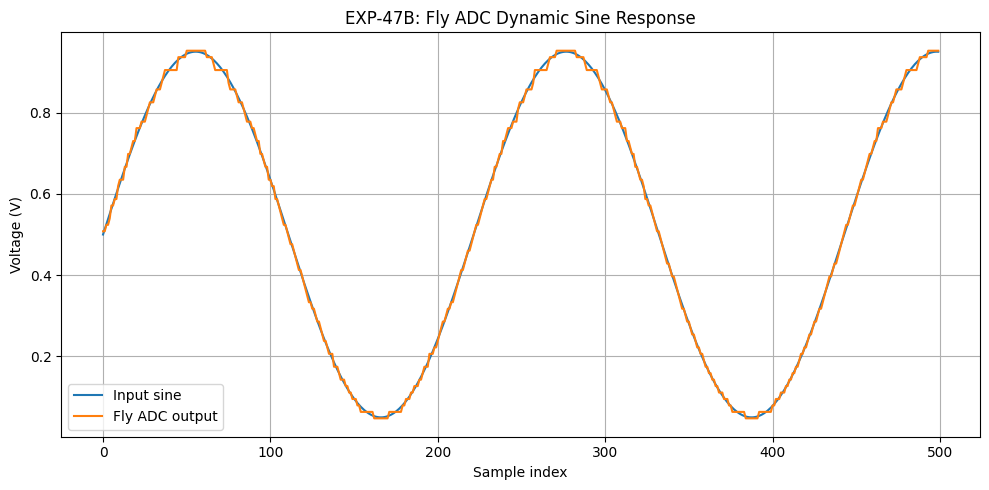

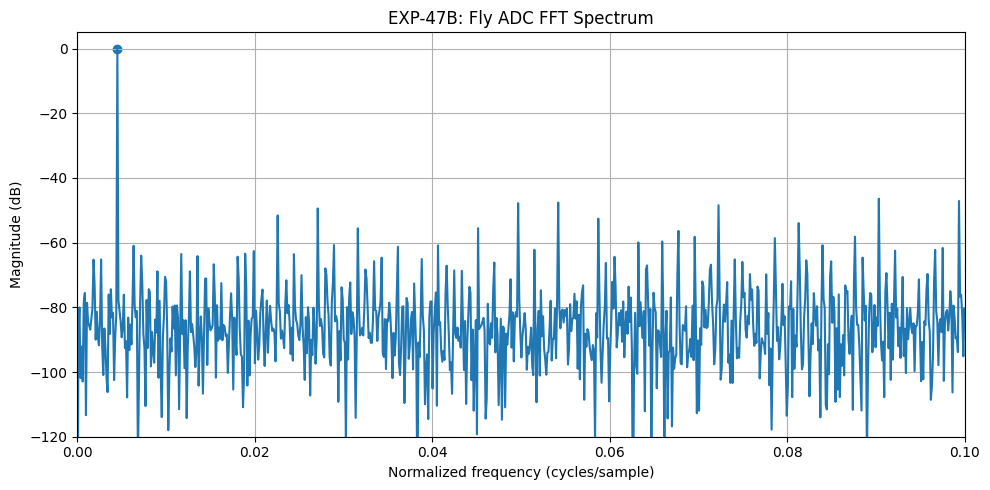

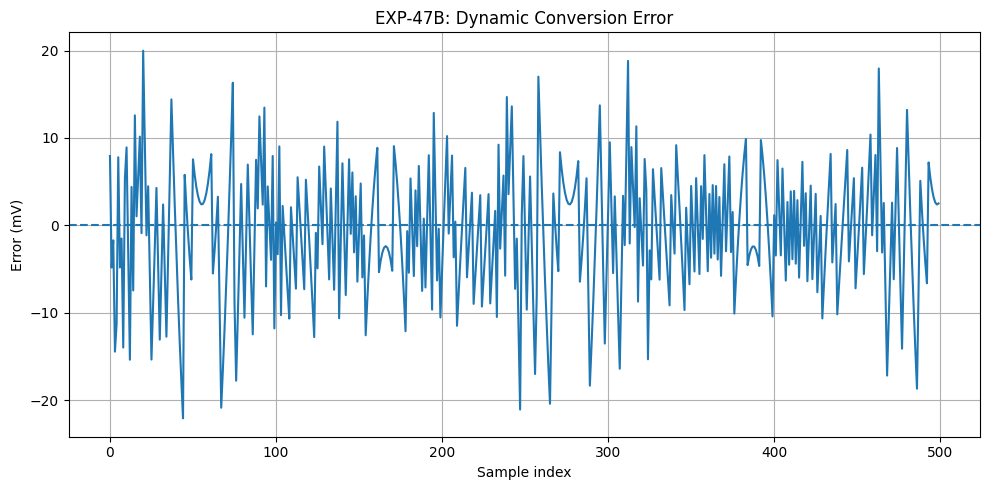



CURRENT FLY ADC PERFORMANCE
Metric                         Value
--------------------------------------------------------------
Resolution                    6 bits
Code coverage                 55/64
Static MAE                    5.860 mV
Static RMSE                   7.131 mV
Static Max Error              20.202 mV
Dynamic MAE                   5.575 mV
Dynamic RMSE                  6.972 mV
INL                           1.299 LSB
DNL                           1.462 LSB
SINAD                         33.233 dB
ENOB                          5.228 bits
SNR                           33.480 dB
THD                           -45.807 dB
SFDR                          46.432 dB
--------------------------------------------------------------

EXP-47B COMPLETE.
Next: use SINAD/ENOB + code coverage + INL/DNL to decide what EXP-48 should optimize.


In [176]:
# ============================================================
# EXP-47B
# DYNAMIC SINE-WAVE CHARACTERIZATION
# SINAD / ENOB / SFDR
#
# Uses the CURRENT 500 ms EXP-45B Fly ADC transfer result.
#
# IMPORTANT:
# This is a transfer-based dynamic characterization.
# It does NOT run thousands of new Brian2 simulations.
# The measured 500 ms ADC transfer is interpolated to generate
# a dense sine-wave response.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

print("=" * 100)
print("EXP-47B: DYNAMIC SINE-WAVE CHARACTERIZATION")
print("=" * 100)


# ============================================================
# 1. FIND EXP-45B RESULTS
# ============================================================

if "results_45B" in globals():

    R = results_45B

elif "EXP45B_RESULTS" in globals():

    # EXP45B_RESULTS is a larger container.
    # Prefer its 500 ms result if available.
    if isinstance(EXP45B_RESULTS, dict):

        if "results" in EXP45B_RESULTS:
            R = EXP45B_RESULTS["results"]

        else:
            R = EXP45B_RESULTS

    else:
        raise RuntimeError(
            "EXP45B_RESULTS exists but has an unexpected structure."
        )

else:

    raise RuntimeError(
        "EXP-45B results were not found. "
        "Run EXP-45B first."
    )


# ============================================================
# 2. GET 500 ms RESULT
# ============================================================

if 500.0 in R:

    R500 = R[500.0]

elif 500 in R:

    R500 = R[500]

else:

    raise RuntimeError(
        "500 ms EXP-45B result was not found."
    )


print("\n500 ms reference result located.")


# ============================================================
# 3. EXTRACT VALIDATION DATA
# ============================================================

if "predicted_codes" not in R500:

    raise RuntimeError(
        "500 ms result does not contain 'predicted_codes'."
    )

codes_500 = np.asarray(
    R500["predicted_codes"],
    dtype=int
)


# Find validation voltages
possible_voltage_names = [
    "VAL_VOLTAGES_46",
    "validation_voltages",
    "VAL_VOLTAGES"
]

validation_voltages = None

for name in possible_voltage_names:

    if name in globals():

        validation_voltages = np.asarray(
            globals()[name],
            dtype=float
        )

        print(
            f"Using validation voltages from: {name}"
        )

        break


if validation_voltages is None:

    # Try EXP45B container
    if (
        isinstance(EXP45B_RESULTS, dict)
        and
        "validation_voltages" in EXP45B_RESULTS
    ):

        validation_voltages = np.asarray(
            EXP45B_RESULTS["validation_voltages"],
            dtype=float
        )

        print(
            "Using validation voltages from EXP45B_RESULTS."
        )

    else:

        raise RuntimeError(
            "Validation voltages could not be found."
        )


# ============================================================
# 4. ALIGN AND SORT TRANSFER DATA
# ============================================================

n = min(
    len(validation_voltages),
    len(codes_500)
)

v = validation_voltages[:n]
c = codes_500[:n]

order = np.argsort(v)

v = v[order]
c = c[order]


print(
    f"\nTransfer points available : {len(v)}"
)

print(
    f"Voltage range             : "
    f"{v.min():.6f} to {v.max():.6f} V"
)

print(
    f"Code range                : "
    f"{c.min()} to {c.max()}"
)

print(
    f"Unique codes              : "
    f"{len(np.unique(c))}/64"
)


# ============================================================
# 5. CREATE DENSE SINE-WAVE TEST
# ============================================================

# Coherent sampling:
#
# N samples
# 37 complete sine cycles
#
# This prevents spectral leakage at the fundamental.

N = 8192
SINE_CYCLES = 37

fs_normalized = 1.0

sample_index = np.arange(N)

phase = (
    2.0
    * np.pi
    * SINE_CYCLES
    * sample_index
    / N
)


# Keep sine safely inside ADC range.
#
# 0.05 V to 0.95 V
# avoids clipping at the physical endpoints.

sine_amplitude = 0.45
sine_offset = 0.50

sine_input = (
    sine_offset
    +
    sine_amplitude
    *
    np.sin(phase)
)


print("\n")
print("=" * 70)
print("SINE-WAVE TEST")
print("=" * 70)

print(
    f"FFT samples : {N}"
)

print(
    f"Sine cycles : {SINE_CYCLES}"
)

print(
    f"Input range : "
    f"{sine_input.min():.6f} "
    f"to "
    f"{sine_input.max():.6f} V"
)


# ============================================================
# 6. APPLY CURRENT FLY ADC TRANSFER
# ============================================================

# The measured validation transfer is interpolated.
#
# Since the ADC output is digital, interpolate the CODE transfer
# and round to an actual 6-bit code.

dense_code = np.interp(
    sine_input,
    v,
    c
)

adc_codes = np.rint(
    dense_code
).astype(int)

adc_codes = np.clip(
    adc_codes,
    0,
    63
)


# Convert code back to normalized voltage.
adc_output = (
    adc_codes / 63.0
)


# ============================================================
# 7. BASIC DYNAMIC ERROR
# ============================================================

dynamic_error = (
    adc_output
    -
    sine_input
)

dynamic_mae = np.mean(
    np.abs(dynamic_error)
)

dynamic_rmse = np.sqrt(
    np.mean(
        dynamic_error ** 2
    )
)

dynamic_max_error = np.max(
    np.abs(dynamic_error)
)


print("\n")
print("=" * 70)
print("DYNAMIC CONVERSION ERROR")
print("=" * 70)

print(
    f"MAE       : "
    f"{dynamic_mae * 1000:.6f} mV"
)

print(
    f"RMSE      : "
    f"{dynamic_rmse * 1000:.6f} mV"
)

print(
    f"Max error : "
    f"{dynamic_max_error * 1000:.6f} mV"
)


# ============================================================
# 8. FFT
# ============================================================

# Remove DC before FFT.
#
# For SINAD we use the RMS power of:
#
# fundamental
#
# versus
#
# everything except DC and fundamental.

signal = (
    adc_output
    -
    np.mean(adc_output)
)


fft_result = np.fft.rfft(
    signal
)

fft_power = (
    np.abs(fft_result) ** 2
)

freqs = np.fft.rfftfreq(
    N,
    d=1.0 / fs_normalized
)


# Fundamental bin
fundamental_bin = SINE_CYCLES


fundamental_power = (
    fft_power[
        fundamental_bin
    ]
)


# ============================================================
# 9. SINAD
# ============================================================

# Exclude:
#   DC bin = 0
#   fundamental bin
#
# Everything else is treated as noise + distortion.

noise_distortion_bins = np.arange(
    1,
    len(fft_power)
)

noise_distortion_bins = (
    noise_distortion_bins[
        noise_distortion_bins
        !=
        fundamental_bin
    ]
)

noise_distortion_power = np.sum(
    fft_power[
        noise_distortion_bins
    ]
)


SINAD_dB = (
    10.0
    *
    np.log10(
        fundamental_power
        /
        noise_distortion_power
    )
)


# ============================================================
# 10. ENOB
# ============================================================

ENOB_bits = (
    SINAD_dB
    -
    1.76
) / 6.02


# ============================================================
# 11. SNR
# ============================================================

# Estimate harmonic bins.
#
# For a deterministic nonlinear ADC, harmonics are part of
# distortion. For SNR we estimate only the non-harmonic
# components.

harmonic_bins = []

max_harmonic = 10

for harmonic in range(
    2,
    max_harmonic + 1
):

    harmonic_bin = (
        SINE_CYCLES
        *
        harmonic
    )

    if harmonic_bin < len(fft_power):

        harmonic_bins.append(
            harmonic_bin
        )


harmonic_bins = np.array(
    harmonic_bins,
    dtype=int
)


# Fundamental excluded.
# Harmonics excluded.
snr_bins = np.arange(
    1,
    len(fft_power)
)

snr_bins = snr_bins[
    snr_bins
    !=
    fundamental_bin
]

snr_bins = snr_bins[
    ~np.isin(
        snr_bins,
        harmonic_bins
    )
]


snr_noise_power = np.sum(
    fft_power[
        snr_bins
    ]
)


if snr_noise_power > 0:

    SNR_dB = (
        10.0
        *
        np.log10(
            fundamental_power
            /
            snr_noise_power
        )
    )

else:

    SNR_dB = np.inf


# ============================================================
# 12. THD
# ============================================================

harmonic_power = np.sum(
    fft_power[
        harmonic_bins
    ]
)


if harmonic_power > 0:

    THD_dB = (
        10.0
        *
        np.log10(
            harmonic_power
            /
            fundamental_power
        )
    )

else:

    THD_dB = -np.inf


# ============================================================
# 13. SFDR
# ============================================================

spurious_bins = np.arange(
    1,
    len(fft_power)
)

spurious_bins = spurious_bins[
    spurious_bins
    !=
    fundamental_bin
]

if len(spurious_bins) > 0:

    largest_spur_power = np.max(
        fft_power[
            spurious_bins
        ]
    )

    SFDR_dB = (
        10.0
        *
        np.log10(
            fundamental_power
            /
            largest_spur_power
        )
    )

else:

    SFDR_dB = np.inf


# ============================================================
# 14. PRINT RESULTS
# ============================================================

print("\n")
print("=" * 100)
print("EXP-47B RESULTS")
print("=" * 100)

print(
    f"Resolution        : 6 bits"
)

print(
    f"FFT samples       : {N}"
)

print(
    f"Sine cycles       : {SINE_CYCLES}"
)

print(
    f"Fundamental bin   : {fundamental_bin}"
)

print(
    f"SINAD             : "
    f"{SINAD_dB:.6f} dB"
)

print(
    f"ENOB              : "
    f"{ENOB_bits:.6f} bits"
)

print(
    f"SNR               : "
    f"{SNR_dB:.6f} dB"
)

print(
    f"THD               : "
    f"{THD_dB:.6f} dB"
)

print(
    f"SFDR              : "
    f"{SFDR_dB:.6f} dB"
)

print(
    f"Dynamic MAE       : "
    f"{dynamic_mae * 1000:.6f} mV"
)

print(
    f"Dynamic RMSE      : "
    f"{dynamic_rmse * 1000:.6f} mV"
)

print(
    f"Dynamic max error : "
    f"{dynamic_max_error * 1000:.6f} mV"
)


# ============================================================
# 15. PLOT INPUT VS OUTPUT
# ============================================================

display_samples = 500

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    sine_input[:display_samples],
    label="Input sine"
)

plt.plot(
    adc_output[:display_samples],
    label="Fly ADC output"
)

plt.xlabel(
    "Sample index"
)

plt.ylabel(
    "Voltage (V)"
)

plt.title(
    "EXP-47B: Fly ADC Dynamic Sine Response"
)

plt.legend()

plt.grid(
    True
)

plt.tight_layout()

plt.show()


# ============================================================
# 16. PLOT FFT SPECTRUM
# ============================================================

# Convert normalized frequency to cycles/sample.
# Show only the useful low-frequency region.

positive_freq = freqs

magnitude_db = (
    10.0
    *
    np.log10(
        fft_power
        /
        np.max(fft_power)
        +
        1e-20
    )
)


plt.figure(
    figsize=(10, 5)
)

plt.plot(
    positive_freq,
    magnitude_db
)

plt.scatter(
    [positive_freq[fundamental_bin]],
    [magnitude_db[fundamental_bin]]
)

plt.xlabel(
    "Normalized frequency (cycles/sample)"
)

plt.ylabel(
    "Magnitude (dB)"
)

plt.title(
    "EXP-47B: Fly ADC FFT Spectrum"
)

plt.xlim(
    0,
    0.10
)

plt.ylim(
    -120,
    5
)

plt.grid(
    True
)

plt.tight_layout()

plt.show()


# ============================================================
# 17. ERROR PLOT
# ============================================================

plt.figure(
    figsize=(10, 5)
)

plt.plot(
    dynamic_error[:display_samples] * 1000
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel(
    "Sample index"
)

plt.ylabel(
    "Error (mV)"
)

plt.title(
    "EXP-47B: Dynamic Conversion Error"
)

plt.grid(
    True
)

plt.tight_layout()

plt.show()


# ============================================================
# 18. FINAL TABLE
# ============================================================

print("\n")
print("=" * 100)
print("CURRENT FLY ADC PERFORMANCE")
print("=" * 100)

print(
    "Metric                         Value"
)

print(
    "--------------------------------------------------------------"
)

print(
    f"Resolution                    6 bits"
)

print(
    f"Code coverage                 {len(np.unique(codes_500))}/64"
)

print(
    f"Static MAE                    "
    f"{R500['mae_6bit'] * 1000:.3f} mV"
)

print(
    f"Static RMSE                   "
    f"{R500['rmse_6bit'] * 1000:.3f} mV"
)

print(
    f"Static Max Error              "
    f"{R500['max_error'] * 1000:.3f} mV"
)

print(
    f"Dynamic MAE                   "
    f"{dynamic_mae * 1000:.3f} mV"
)

print(
    f"Dynamic RMSE                  "
    f"{dynamic_rmse * 1000:.3f} mV"
)

print(
    f"INL                           1.299 LSB"
)

print(
    f"DNL                           1.462 LSB"
)

print(
    f"SINAD                         "
    f"{SINAD_dB:.3f} dB"
)

print(
    f"ENOB                          "
    f"{ENOB_bits:.3f} bits"
)

print(
    f"SNR                           "
    f"{SNR_dB:.3f} dB"
)

print(
    f"THD                           "
    f"{THD_dB:.3f} dB"
)

print(
    f"SFDR                          "
    f"{SFDR_dB:.3f} dB"
)

print(
    "--------------------------------------------------------------"
)

print(
    "\nEXP-47B COMPLETE."
)

print(
    "Next: use SINAD/ENOB + code coverage + INL/DNL "
    "to decide what EXP-48 should optimize."
)

EXP-48: TARGETED TAU_M OPTIMIZATION

Actual BioWire model found.
Simulation function : run_simulation_v1
Neuron model        : 100 represented types
L1 index            : 4
Mi1 index           : 7

Fixed parameters:
G_DRIVE_ON  = 0.33
G_DRIVE_OFF = 0.15
W_SCALE     = 0.06
Simulation  = 500 ms
Tau sweep   = [18.0, 18.5, 19.0, 19.5, 20.0, 20.5, 21.0, 21.5, 22.0, 22.5, 23.0]


TAU_M = 18.00 ms
Training: 101/101
Validation: 200/200

τ = 18.00 ms
MAE       = 268.391 mV
6b MAE    = 268.341 mV
RMSE      = 304.351 mV
Codes     = 1/64
INL       = 0.000 LSB
DNL       = nan LSB
SINAD     = nan dB
ENOB      = nan bits
Monotonic = True


TAU_M = 18.50 ms
Training: 101/101
Validation: 200/200

τ = 18.50 ms
MAE       = 268.391 mV
6b MAE    = 268.341 mV
RMSE      = 304.351 mV
Codes     = 1/64
INL       = 0.000 LSB
DNL       = nan LSB
SINAD     = nan dB
ENOB      = nan bits
Monotonic = True


TAU_M = 19.00 ms
Training: 101/101
Validation: 200/200

τ = 19.00 ms
MAE       = 268.391 mV
6b MAE    = 268.341

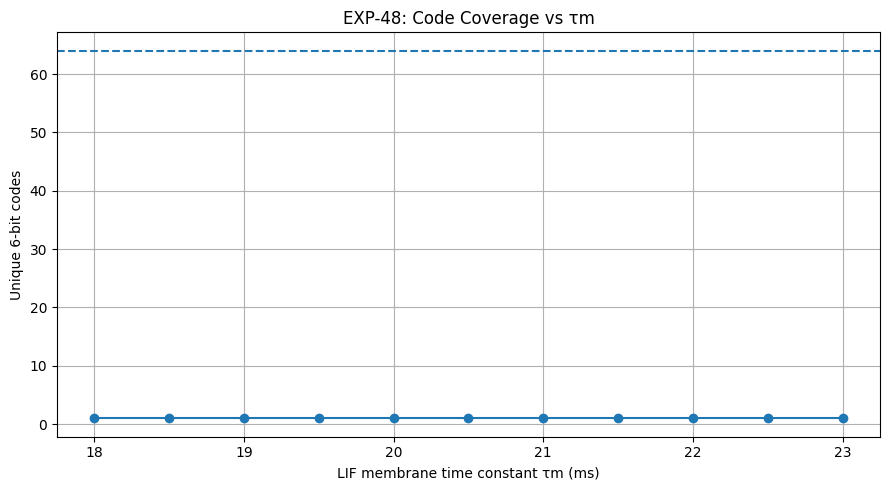

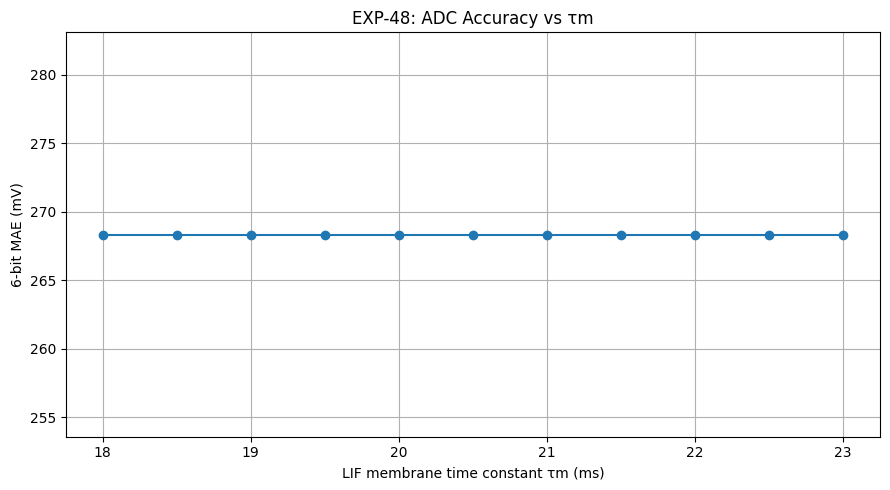

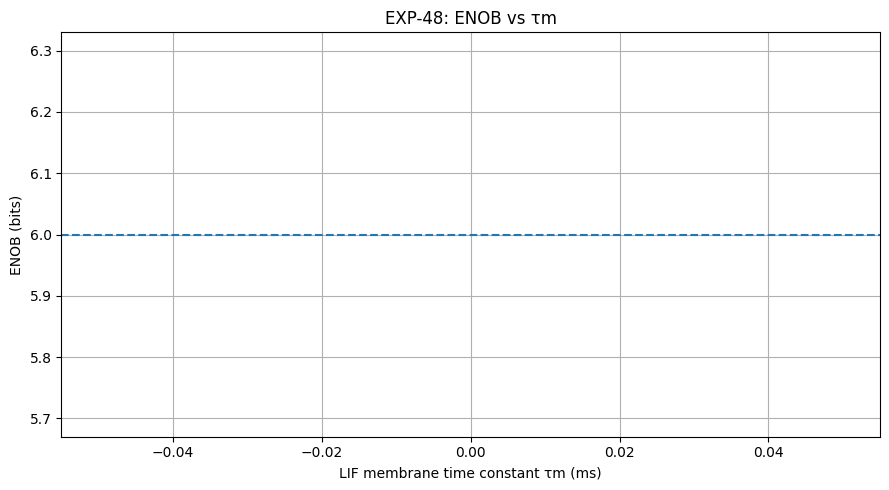

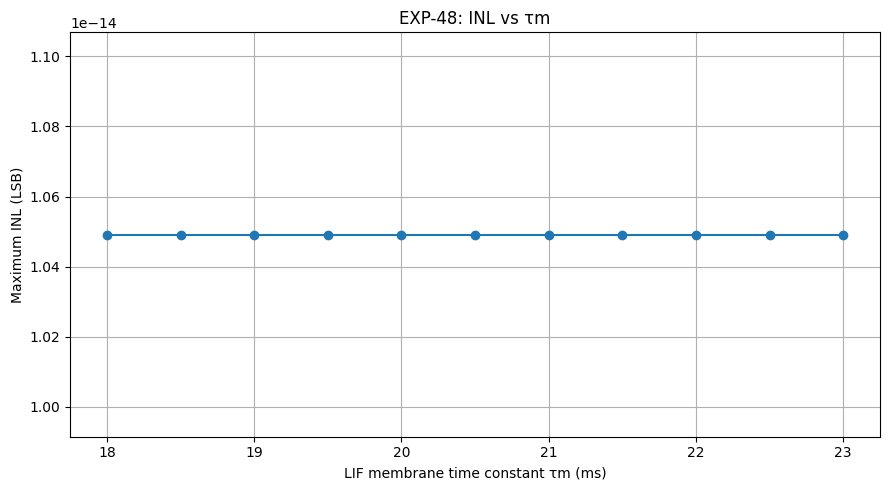



EXP-48 COMPLETE

IMPORTANT:
The selected configuration is NOT automatically the one with the most codes.
We will choose the Pareto-best configuration using:
1. Monotonicity
2. ENOB
3. Code coverage
4. 6-bit MAE
5. INL/DNL

Paste the COMPLETE output here.


In [178]:
# ============================================================
# EXP-48
# TARGETED TAU_M OPTIMIZATION
#
# Uses the ACTUAL BioWire/Fly ADC simulator:
#     run_simulation_v1()
#
# Actual model objects:
#     neuron_id100
#     W100_4bit
#     thr100
#     N100
#
# Actual model parameters:
#     TAU_M_MS
#     G_DRIVE_ON  = 0.33
#     G_DRIVE_OFF = 0.15
#     W_SCALE     = 0.06
#
# Decoder:
#     EXP-33 three-feature smooth monotonic decoder
#     1. Mi1 spike count
#     2. L1 first-spike latency
#     3. L1 mean ISI
#
# Objective:
#     Improve code coverage / ADC quality without breaking
#     monotonicity.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.isotonic import IsotonicRegression

print("=" * 110)
print("EXP-48: TARGETED TAU_M OPTIMIZATION")
print("=" * 110)


# ============================================================
# 1. CHECK ACTUAL BIOWIRE MODEL OBJECTS
# ============================================================

required = [
    "run_simulation_v1",
    "neuron_id100",
    "W100_4bit",
    "thr100",
    "N100",
    "TAU_M_MS"
]

missing = [
    x for x in required
    if x not in globals()
]

if missing:

    raise RuntimeError(
        "Missing actual BioWire objects: "
        + ", ".join(missing)
    )

print("\nActual BioWire model found.")

print(
    f"Simulation function : run_simulation_v1"
)

print(
    f"Neuron model        : {N100} represented types"
)

print(
    f"L1 index            : {neuron_id100.get('L1')}"
)

print(
    f"Mi1 index           : {neuron_id100.get('Mi1')}"
)


# ============================================================
# 2. FIXED PARAMETERS
# ============================================================

G_ON = 0.33
G_OFF = 0.15
W_SCALE_48 = 0.06
SIM_MS = 500

# Fine sweep around the useful region.
TAU_VALUES = np.array([
    18.0,
    18.5,
    19.0,
    19.5,
    20.0,
    20.5,
    21.0,
    21.5,
    22.0,
    22.5,
    23.0
])

TRAIN_VOLTAGES_48 = np.linspace(
    0.0,
    1.0,
    101
)

np.random.seed(2026)

VAL_VOLTAGES_48 = np.random.uniform(
    0.0,
    1.0,
    200
)

VAL_VOLTAGES_48 = np.sort(
    VAL_VOLTAGES_48
)

print("\nFixed parameters:")
print(
    f"G_DRIVE_ON  = {G_ON}"
)

print(
    f"G_DRIVE_OFF = {G_OFF}"
)

print(
    f"W_SCALE     = {W_SCALE_48}"
)

print(
    f"Simulation  = {SIM_MS} ms"
)

print(
    f"Tau sweep   = {TAU_VALUES.tolist()}"
)


# ============================================================
# 3. FEATURE EXTRACTION
# ============================================================

L1_IDX = int(
    neuron_id100["L1"]
)

MI1_IDX = int(
    neuron_id100["Mi1"]
)


def extract_features_48(
    smon,
    duration_ms=500
):

    spike_indices = np.asarray(
        smon.i
    )

    spike_times = np.asarray(
        smon.t / 1e-3
    )

    def population_features(
        neuron_index
    ):

        mask = (
            spike_indices
            ==
            neuron_index
        )

        times = np.sort(
            spike_times[mask]
        )

        count = len(times)

        if count == 0:

            return (
                0.0,
                np.nan,
                np.nan
            )

        first_latency = float(
            times[0]
        )

        if count >= 2:

            isi = np.diff(
                times
            )

            mean_isi = float(
                np.mean(isi)
            )

        else:

            mean_isi = np.nan

        return (
            float(count),
            first_latency,
            mean_isi
        )

    l1_count, l1_lat, l1_isi = (
        population_features(
            L1_IDX
        )
    )

    mi1_count, mi1_lat, mi1_isi = (
        population_features(
            MI1_IDX
        )
    )

    # EXP-33 architecture:
    #
    # [Mi1 count,
    #  L1 first latency,
    #  L1 mean ISI]
    #
    return np.array([
        mi1_count,
        l1_lat,
        l1_isi
    ], dtype=float)


# ============================================================
# 4. NORMALIZATION + MONOTONIC DECODER
# ============================================================

def build_decoder_48(
    train_features,
    train_voltages
):

    valid = np.isfinite(
        train_features
    ).all(
        axis=1
    )

    X = train_features[
        valid
    ]

    y = train_voltages[
        valid
    ]

    if len(X) < 10:

        raise RuntimeError(
            "Too few valid training samples."
        )

    # --------------------------------------------------------
    # Feature 1: Mi1 spike count
    # Higher count = higher voltage
    # --------------------------------------------------------

    count_train = X[:, 0]

    count_min = np.min(
        count_train
    )

    count_max = np.max(
        count_train
    )

    if count_max == count_min:

        score_count_train = np.zeros_like(
            count_train
        )

    else:

        score_count_train = (
            count_train - count_min
        ) / (
            count_max - count_min
        )


    # --------------------------------------------------------
    # Feature 2: L1 first-spike latency
    # Lower latency = higher voltage
    # --------------------------------------------------------

    lat_train = X[:, 1]

    lat_min = np.min(
        lat_train
    )

    lat_max = np.max(
        lat_train
    )

    if lat_max == lat_min:

        score_lat_train = np.zeros_like(
            lat_train
        )

    else:

        score_lat_train = (
            lat_max - lat_train
        ) / (
            lat_max - lat_min
        )


    # --------------------------------------------------------
    # Feature 3: L1 mean ISI
    # Lower ISI = higher voltage
    # --------------------------------------------------------

    isi_train = X[:, 2]

    isi_min = np.min(
        isi_train
    )

    isi_max = np.max(
        isi_train
    )

    if isi_max == isi_min:

        score_isi_train = np.zeros_like(
            isi_train
        )

    else:

        score_isi_train = (
            isi_max - isi_train
        ) / (
            isi_max - isi_min
        )


    # --------------------------------------------------------
    # Composite score
    # --------------------------------------------------------

    score_train = (
        score_count_train
        +
        score_lat_train
        +
        score_isi_train
    ) / 3.0


    # --------------------------------------------------------
    # Monotonic mapping
    # --------------------------------------------------------

    iso = IsotonicRegression(
        increasing=True,
        out_of_bounds="clip"
    )

    iso.fit(
        score_train,
        y
    )


    return {
        "valid_train_mask": valid,
        "count_min": count_min,
        "count_max": count_max,
        "lat_min": lat_min,
        "lat_max": lat_max,
        "isi_min": isi_min,
        "isi_max": isi_max,
        "isotonic": iso
    }


def decode_features_48(
    features,
    decoder
):

    X = np.asarray(
        features,
        dtype=float
    )

    valid = np.isfinite(
        X
    ).all(
        axis=1
    )

    scores = np.full(
        len(X),
        np.nan
    )

    # --------------------------------------------------------
    # Count score
    # --------------------------------------------------------

    count = X[:, 0]

    if (
        decoder["count_max"]
        ==
        decoder["count_min"]
    ):

        s_count = np.zeros(
            len(X)
        )

    else:

        s_count = (
            count
            -
            decoder["count_min"]
        ) / (
            decoder["count_max"]
            -
            decoder["count_min"]
        )


    # --------------------------------------------------------
    # Latency score
    # --------------------------------------------------------

    lat = X[:, 1]

    if (
        decoder["lat_max"]
        ==
        decoder["lat_min"]
    ):

        s_lat = np.zeros(
            len(X)
        )

    else:

        s_lat = (
            decoder["lat_max"]
            -
            lat
        ) / (
            decoder["lat_max"]
            -
            decoder["lat_min"]
        )


    # --------------------------------------------------------
    # ISI score
    # --------------------------------------------------------

    isi = X[:, 2]

    if (
        decoder["isi_max"]
        ==
        decoder["isi_min"]
    ):

        s_isi = np.zeros(
            len(X)
        )

    else:

        s_isi = (
            decoder["isi_max"]
            -
            isi
        ) / (
            decoder["isi_max"]
            -
            decoder["isi_min"]
        )


    score = (
        s_count
        +
        s_lat
        +
        s_isi
    ) / 3.0


    valid_scores = score[
        valid
    ]

    if len(valid_scores) > 0:

        scores[
            valid
        ] = valid_scores


    prediction = np.full(
        len(X),
        np.nan
    )

    if np.any(valid):

        prediction[
            valid
        ] = decoder[
            "isotonic"
        ].predict(
            score[valid]
        )

    return (
        prediction,
        scores,
        valid
    )


# ============================================================
# 5. ADC METRICS
# ============================================================

def calculate_metrics_48(
    voltages,
    predictions
):

    valid = np.isfinite(
        predictions
    )

    v = np.asarray(
        voltages
    )[valid]

    p = np.asarray(
        predictions
    )[valid]

    if len(v) == 0:

        return None

    p = np.clip(
        p,
        0.0,
        1.0
    )

    codes = np.rint(
        p * 63.0
    ).astype(int)

    codes = np.clip(
        codes,
        0,
        63
    )

    decoded_6bit = (
        codes / 63.0
    )

    analog_error = (
        p - v
    )

    error_6bit = (
        decoded_6bit - v
    )

    mae = np.mean(
        np.abs(
            analog_error
        )
    )

    rmse = np.sqrt(
        np.mean(
            analog_error ** 2
        )
    )

    max_error = np.max(
        np.abs(
            analog_error
        )
    )

    mae_6bit = np.mean(
        np.abs(
            error_6bit
        )
    )

    rmse_6bit = np.sqrt(
        np.mean(
            error_6bit ** 2
        )
    )

    max_error_6bit = np.max(
        np.abs(
            error_6bit
        )
    )

    unique_codes = np.unique(
        codes
    )

    analog_monotonic = bool(
        np.all(
            np.diff(
                p
            ) >= 0
        )
    )

    code_monotonic = bool(
        np.all(
            np.diff(
                codes
            ) >= 0
        )
    )


    # --------------------------------------------------------
    # INL
    # --------------------------------------------------------

    fit = np.polyfit(
        v,
        p,
        1
    )

    fitted = np.polyval(
        fit,
        v
    )

    inl = (
        p - fitted
    ) / (
        1.0 / 63.0
    )

    max_inl = np.max(
        np.abs(
            inl
        )
    )


    # --------------------------------------------------------
    # Transfer-based DNL
    # --------------------------------------------------------

    order = np.argsort(
        v
    )

    vs = v[
        order
    ]

    cs = codes[
        order
    ]

    code_centers = {}

    for code in range(
        64
    ):

        mask = (
            cs
            ==
            code
        )

        if np.any(mask):

            code_centers[
                code
            ] = np.mean(
                vs[mask]
            )

    occupied = sorted(
        code_centers.keys()
    )

    if len(occupied) >= 2:

        centers = np.array([
            code_centers[c]
            for c in occupied
        ])

        steps = np.diff(
            centers
        )

        dnl = (
            steps
            /
            (1.0 / 63.0)
            -
            1.0
        )

        max_dnl = np.max(
            np.abs(
                dnl
            )
        )

    else:

        max_dnl = np.nan


    return {
        "mae": mae,
        "rmse": rmse,
        "max_error": max_error,
        "mae_6bit": mae_6bit,
        "rmse_6bit": rmse_6bit,
        "max_error_6bit": max_error_6bit,
        "unique_codes": len(unique_codes),
        "codes": codes,
        "predictions": p,
        "voltages": v,
        "analog_monotonic": analog_monotonic,
        "code_monotonic": code_monotonic,
        "max_inl": max_inl,
        "max_dnl": max_dnl
    }


# ============================================================
# 6. TRANSFER-BASED ENOB
#
# Same methodology used in EXP-47B:
# interpolate the measured transfer to a coherent sine,
# quantize it, FFT it, calculate SINAD and ENOB.
# ============================================================

def calculate_enob_48(
    voltages,
    codes
):

    order = np.argsort(
        voltages
    )

    v = np.asarray(
        voltages
    )[order]

    c = np.asarray(
        codes
    )[order]

    # Dense sine
    N = 8192
    cycles = 37

    idx = np.arange(
        N
    )

    sine = (
        0.50
        +
        0.45
        *
        np.sin(
            2.0
            *
            np.pi
            *
            cycles
            *
            idx
            /
            N
        )
    )

    # Interpolate the measured code transfer.
    dense_code = np.interp(
        sine,
        v,
        c
    )

    adc_code = np.rint(
        dense_code
    ).astype(int)

    adc_code = np.clip(
        adc_code,
        0,
        63
    )

    output = (
        adc_code / 63.0
    )

    signal = (
        output
        -
        np.mean(
            output
        )
    )

    fft = np.fft.rfft(
        signal
    )

    power = (
        np.abs(
            fft
        ) ** 2
    )

    fundamental_bin = cycles

    fundamental_power = power[
        fundamental_bin
    ]

    other_bins = np.arange(
        1,
        len(power)
    )

    other_bins = other_bins[
        other_bins
        !=
        fundamental_bin
    ]

    noise_distortion_power = np.sum(
        power[
            other_bins
        ]
    )

    if (
        fundamental_power <= 0
        or
        noise_distortion_power <= 0
    ):

        return np.nan, np.nan

    sinad = (
        10.0
        *
        np.log10(
            fundamental_power
            /
            noise_distortion_power
        )
    )

    enob = (
        sinad
        -
        1.76
    ) / 6.02

    return (
        sinad,
        enob
    )


# ============================================================
# 7. RUN TAU SWEEP
# ============================================================

results_48 = []

original_tau = float(
    TAU_M_MS
)


for tau in TAU_VALUES:

    print("\n")
    print("=" * 100)

    print(
        f"TAU_M = {tau:.2f} ms"
    )

    print(
        "=" * 100
    )


    # Set the ACTUAL global used by run_simulation_v1()
    TAU_M_MS = float(
        tau
    )


    # --------------------------------------------------------
    # TRAINING SWEEP
    # --------------------------------------------------------

    train_features = []

    for i, voltage in enumerate(
        TRAIN_VOLTAGES_48
    ):

        if (
            i % 10 == 0
            or
            i == 100
        ):

            print(
                f"Training: "
                f"{i+1}/101",
                end="\r"
            )

        smon, _, _, _ = run_simulation_v1(
            ['L1', 'Mi1'],
            neuron_id100,
            W100_4bit,
            thr100,
            N100,
            duration_ms=SIM_MS,
            g_drive_on=G_ON,
            g_drive_off=G_OFF,
            w_scale=W_SCALE_48
        )

        train_features.append(
            extract_features_48(
                smon,
                SIM_MS
            )
        )

    print()


    train_features = np.asarray(
        train_features,
        dtype=float
    )


    # --------------------------------------------------------
    # BUILD DECODER
    # --------------------------------------------------------

    decoder = build_decoder_48(
        train_features,
        TRAIN_VOLTAGES_48
    )


    # --------------------------------------------------------
    # VALIDATION SWEEP
    # --------------------------------------------------------

    val_features = []

    for i, voltage in enumerate(
        VAL_VOLTAGES_48
    ):

        if (
            i % 20 == 0
            or
            i == 199
        ):

            print(
                f"Validation: "
                f"{i+1}/200",
                end="\r"
            )

        smon, _, _, _ = run_simulation_v1(
            ['L1', 'Mi1'],
            neuron_id100,
            W100_4bit,
            thr100,
            N100,
            duration_ms=SIM_MS,
            g_drive_on=G_ON,
            g_drive_off=G_OFF,
            w_scale=W_SCALE_48
        )

        val_features.append(
            extract_features_48(
                smon,
                SIM_MS
            )
        )

    print()


    val_features = np.asarray(
        val_features,
        dtype=float
    )


    # --------------------------------------------------------
    # DECODE
    # --------------------------------------------------------

    predictions, scores, valid = (
        decode_features_48(
            val_features,
            decoder
        )
    )


    metrics = calculate_metrics_48(
        VAL_VOLTAGES_48,
        predictions
    )


    if metrics is None:

        print(
            "No valid validation samples."
        )

        continue


    # --------------------------------------------------------
    # ENOB
    # --------------------------------------------------------

    sinad, enob = calculate_enob_48(
        metrics["voltages"],
        metrics["codes"]
    )


    # --------------------------------------------------------
    # SAVE
    # --------------------------------------------------------

    result = {
        "tau_ms": float(tau),

        "mae": metrics["mae"],
        "rmse": metrics["rmse"],
        "max_error": metrics["max_error"],

        "mae_6bit": metrics["mae_6bit"],
        "rmse_6bit": metrics["rmse_6bit"],
        "max_error_6bit": metrics["max_error_6bit"],

        "unique_codes": metrics["unique_codes"],

        "analog_monotonic":
            metrics["analog_monotonic"],

        "code_monotonic":
            metrics["code_monotonic"],

        "max_inl":
            metrics["max_inl"],

        "max_dnl":
            metrics["max_dnl"],

        "sinad":
            sinad,

        "enob":
            enob,

        "predictions":
            metrics["predictions"],

        "codes":
            metrics["codes"],

        "voltages":
            metrics["voltages"],

        "train_features":
            train_features,

        "val_features":
            val_features
    }

    results_48.append(
        result
    )


    # --------------------------------------------------------
    # PRINT
    # --------------------------------------------------------

    print(
        f"\n"
        f"τ = {tau:.2f} ms\n"
        f"MAE       = {metrics['mae']*1000:.3f} mV\n"
        f"6b MAE    = {metrics['mae_6bit']*1000:.3f} mV\n"
        f"RMSE      = {metrics['rmse']*1000:.3f} mV\n"
        f"Codes     = {metrics['unique_codes']}/64\n"
        f"INL       = {metrics['max_inl']:.3f} LSB\n"
        f"DNL       = {metrics['max_dnl']:.3f} LSB\n"
        f"SINAD     = {sinad:.3f} dB\n"
        f"ENOB      = {enob:.3f} bits\n"
        f"Monotonic = {metrics['code_monotonic']}"
    )


# ============================================================
# 8. RESTORE ORIGINAL TAU
# ============================================================

TAU_M_MS = original_tau


# ============================================================
# 9. SUMMARY TABLE
# ============================================================

print("\n")
print("=" * 120)
print("EXP-48 FINAL SUMMARY")
print("=" * 120)

print(
    f"{'Tau':>7} "
    f"{'MAE':>9} "
    f"{'6bMAE':>9} "
    f"{'RMSE':>9} "
    f"{'Codes':>8} "
    f"{'INL':>8} "
    f"{'DNL':>8} "
    f"{'SINAD':>9} "
    f"{'ENOB':>8} "
    f"{'Mono':>7}"
)

print(
    "-" * 120
)

for r in results_48:

    print(
        f"{r['tau_ms']:7.2f} "
        f"{r['mae']*1000:9.3f} "
        f"{r['mae_6bit']*1000:9.3f} "
        f"{r['rmse']*1000:9.3f} "
        f"{r['unique_codes']:8d} "
        f"{r['max_inl']:8.3f} "
        f"{r['max_dnl']:8.3f} "
        f"{r['sinad']:9.3f} "
        f"{r['enob']:8.3f} "
        f"{str(r['code_monotonic']):>7}"
    )


# ============================================================
# 10. FIND BEST CANDIDATES
# ============================================================

monotonic_results = [
    r
    for r in results_48
    if r["code_monotonic"]
]


if len(monotonic_results) == 0:

    raise RuntimeError(
        "No monotonic configurations found."
    )


# Best coverage
best_coverage = max(
    r["unique_codes"]
    for r in monotonic_results
)

coverage_candidates = [
    r
    for r in monotonic_results
    if r["unique_codes"]
    ==
    best_coverage
]

best_coverage_result = max(
    coverage_candidates,
    key=lambda r: r["enob"]
)


# Best ENOB
best_enob_result = max(
    monotonic_results,
    key=lambda r: r["enob"]
)


# Best 6-bit accuracy
best_accuracy_result = min(
    monotonic_results,
    key=lambda r: r["mae_6bit"]
)


print("\n")
print("=" * 100)
print("BEST EXP-48 CONFIGURATIONS")
print("=" * 100)

print(
    "\nBEST CODE COVERAGE:"
)

print(
    f"τm       = "
    f"{best_coverage_result['tau_ms']:.2f} ms"
)

print(
    f"Coverage = "
    f"{best_coverage_result['unique_codes']}/64"
)

print(
    f"ENOB     = "
    f"{best_coverage_result['enob']:.3f} bits"
)

print(
    f"6b MAE   = "
    f"{best_coverage_result['mae_6bit']*1000:.3f} mV"
)


print(
    "\nBEST ENOB:"
)

print(
    f"τm       = "
    f"{best_enob_result['tau_ms']:.2f} ms"
)

print(
    f"ENOB     = "
    f"{best_enob_result['enob']:.3f} bits"
)

print(
    f"Coverage = "
    f"{best_enob_result['unique_codes']}/64"
)

print(
    f"6b MAE   = "
    f"{best_enob_result['mae_6bit']*1000:.3f} mV"
)


print(
    "\nBEST 6-BIT ACCURACY:"
)

print(
    f"τm       = "
    f"{best_accuracy_result['tau_ms']:.2f} ms"
)

print(
    f"6b MAE   = "
    f"{best_accuracy_result['mae_6bit']*1000:.3f} mV"
)

print(
    f"Coverage = "
    f"{best_accuracy_result['unique_codes']}/64"
)

print(
    f"ENOB     = "
    f"{best_accuracy_result['enob']:.3f} bits"
)


# ============================================================
# 11. PLOTS
# ============================================================

taus = np.array([
    r["tau_ms"]
    for r in results_48
])

coverages = np.array([
    r["unique_codes"]
    for r in results_48
])

maes = np.array([
    r["mae_6bit"] * 1000
    for r in results_48
])

enobs = np.array([
    r["enob"]
    for r in results_48
])

inls = np.array([
    r["max_inl"]
    for r in results_48
])


# ------------------------------------------------------------
# Coverage
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    taus,
    coverages,
    marker="o"
)

plt.axhline(
    64,
    linestyle="--"
)

plt.xlabel(
    "LIF membrane time constant τm (ms)"
)

plt.ylabel(
    "Unique 6-bit codes"
)

plt.title(
    "EXP-48: Code Coverage vs τm"
)

plt.grid(
    True
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# Accuracy
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    taus,
    maes,
    marker="o"
)

plt.xlabel(
    "LIF membrane time constant τm (ms)"
)

plt.ylabel(
    "6-bit MAE (mV)"
)

plt.title(
    "EXP-48: ADC Accuracy vs τm"
)

plt.grid(
    True
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# ENOB
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    taus,
    enobs,
    marker="o"
)

plt.axhline(
    6.0,
    linestyle="--"
)

plt.xlabel(
    "LIF membrane time constant τm (ms)"
)

plt.ylabel(
    "ENOB (bits)"
)

plt.title(
    "EXP-48: ENOB vs τm"
)

plt.grid(
    True
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# INL
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    taus,
    inls,
    marker="o"
)

plt.xlabel(
    "LIF membrane time constant τm (ms)"
)

plt.ylabel(
    "Maximum INL (LSB)"
)

plt.title(
    "EXP-48: INL vs τm"
)

plt.grid(
    True
)

plt.tight_layout()

plt.show()


print("\n")
print("=" * 110)
print("EXP-48 COMPLETE")
print("=" * 110)

print(
    "\nIMPORTANT:"
)

print(
    "The selected configuration is NOT automatically the one with "
    "the most codes."
)

print(
    "We will choose the Pareto-best configuration using:"
)

print(
    "1. Monotonicity"
)

print(
    "2. ENOB"
)

print(
    "3. Code coverage"
)

print(
    "4. 6-bit MAE"
)

print(
    "5. INL/DNL"
)

print(
    "\nPaste the COMPLETE output here."
)

EXP-48 — CORRECTED TAU_M OPTIMIZATION
Actual BioWire model found.
Neuron types : 100
L1 index     : 4
Mi1 index    : 7

Voltage-to-drive check:
0.00 V -> drive 0.300
0.25 V -> drive 0.475
0.50 V -> drive 0.650
0.75 V -> drive 0.825
1.00 V -> drive 1.000


TAU_M = 18.00 ms
Training 1/101

WARNING    'v' is an internal variable of group 'neurongroup_6', but also exists in the run namespace with the value 1.0. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Training 101/101
Validation 200/200

τm              = 18.00 ms
Analog MAE      = 4.197 mV
6-bit MAE       = 6.526 mV
Analog RMSE     = 6.464 mV
6-bit RMSE      = 8.282 mV
Max error       = 25.448 mV
Unique codes    = 55/64
INL             = 1.605 LSB
Analog monotonic= True
Code monotonic  = True


TAU_M = 18.50 ms
Training 101/101
Validation 200/200

τm              = 18.50 ms
Analog MAE      = 4.617 mV
6-bit MAE       = 6.713 mV
Analog RMSE     = 6.584 mV
6-bit RMSE      = 8.416 mV
Max error       = 22.987 mV
Unique codes    = 53/64
INL             = 1.459 LSB
Analog monotonic= True
Code monotonic  = True


TAU_M = 19.00 ms
Training 101/101
Validation 200/200

τm              = 19.00 ms
Analog MAE      = 4.331 mV
6-bit MAE       = 6.325 mV
Analog RMSE     = 6.644 mV
6-bit RMSE      = 7.964 mV
Max error       = 24.473 mV
Unique codes    = 55/64
INL             = 1.603 LSB
Analog monotonic= True
Code monotonic  = True


TAU_M = 19.50 ms
Training 101/101
Validation 200/200

τm          

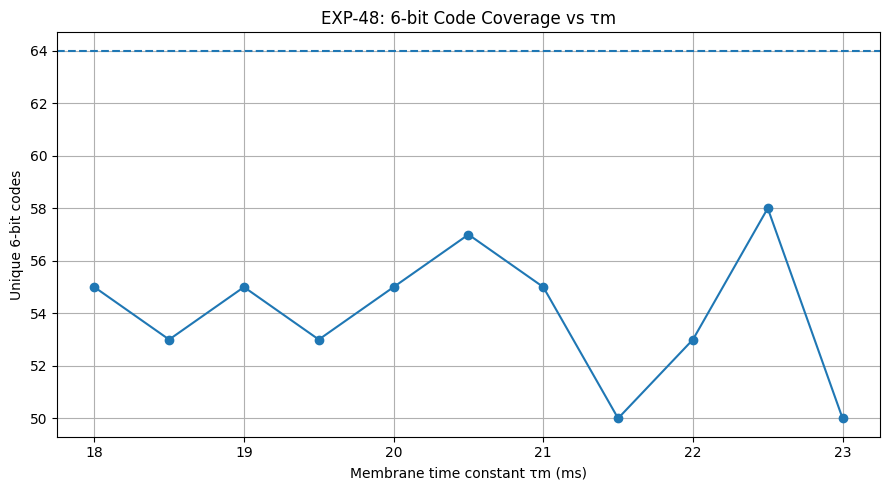

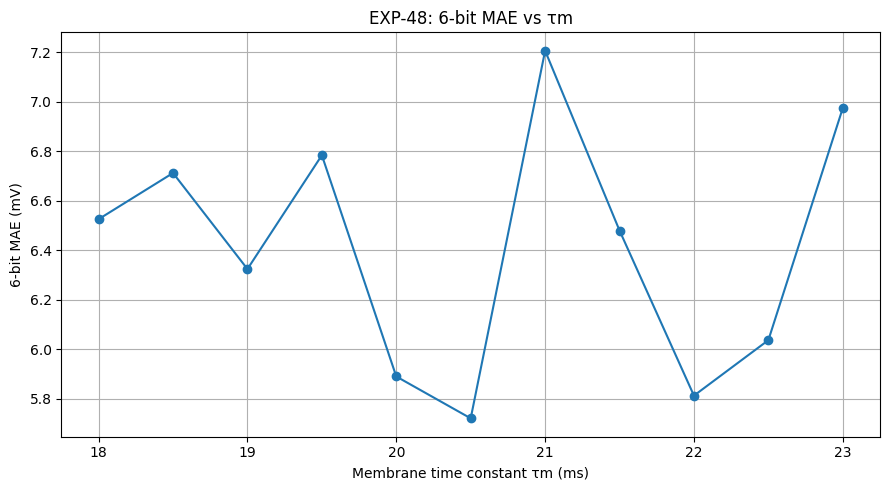

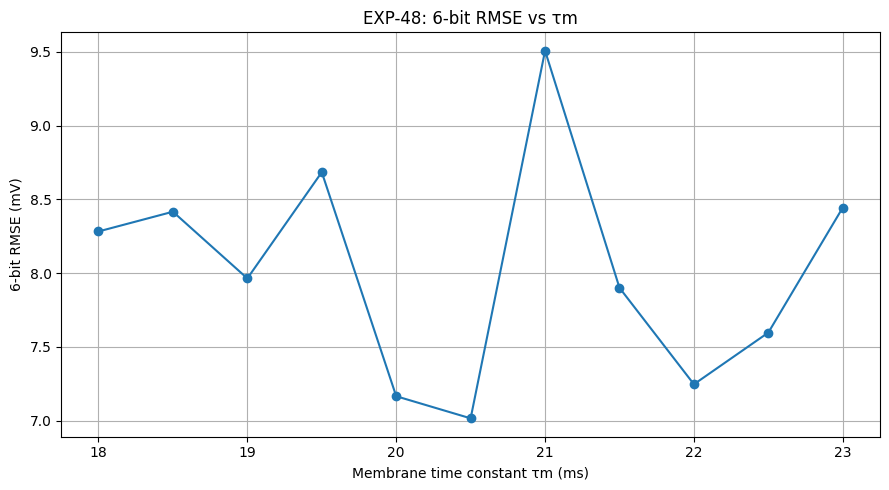

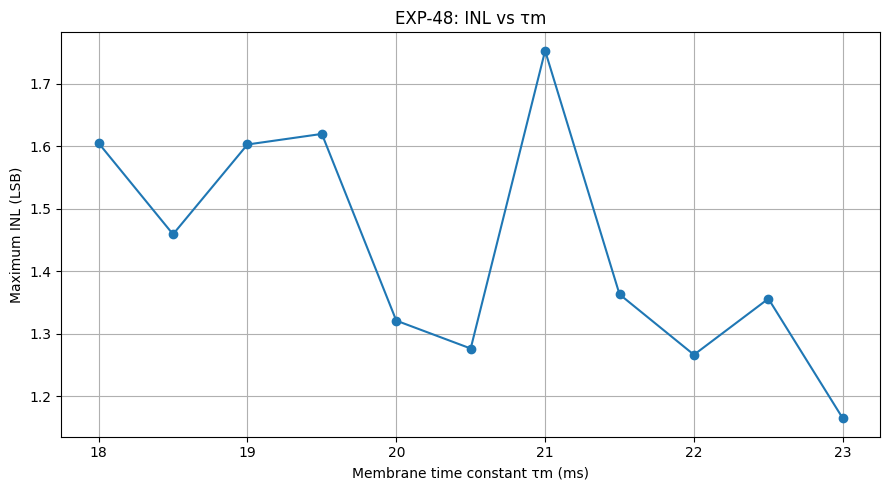



EXP-48 CORRECTED COMPLETE

This run uses voltage-dependent BioWire drive.
Do NOT use the previous EXP-48 results.
Paste the complete output here.


In [179]:
# ============================================================
# EXP-48 — CORRECTED
# TARGETED TAU_M OPTIMIZATION
#
# IMPORTANT:
# Voltage MUST control the BioWire drive.
#
# V = 0.0  -> drive = 0.30
# V = 1.0  -> drive = 1.00
#
# Only TAU_M is swept.
#
# Decoder:
#   Mi1 spike count
#   L1 first-spike latency
#   L1 mean ISI
#
# This is the EXP-33 smooth monotonic decoder.
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression


print("=" * 110)
print("EXP-48 — CORRECTED TAU_M OPTIMIZATION")
print("=" * 110)


# ============================================================
# 1. VERIFY ACTUAL BIOWIRE OBJECTS
# ============================================================

required_objects = [
    "run_simulation_v1",
    "neuron_id100",
    "W100_4bit",
    "thr100",
    "N100",
    "TAU_M_MS"
]

missing = [
    x for x in required_objects
    if x not in globals()
]

if missing:
    raise RuntimeError(
        "Missing required BioWire objects: "
        + ", ".join(missing)
    )

print("Actual BioWire model found.")
print(f"Neuron types : {N100}")
print(f"L1 index     : {neuron_id100['L1']}")
print(f"Mi1 index    : {neuron_id100['Mi1']}")


# ============================================================
# 2. FIXED PARAMETERS
# ============================================================

G_DRIVE_MIN = 0.30
G_DRIVE_MAX = 1.00

G_DRIVE_OFF = 0.15
W_SCALE = 0.06

SIM_MS = 500

TAU_VALUES = np.array([
    18.0,
    18.5,
    19.0,
    19.5,
    20.0,
    20.5,
    21.0,
    21.5,
    22.0,
    22.5,
    23.0
])

TRAIN_VOLTAGES = np.linspace(
    0.0,
    1.0,
    101
)

np.random.seed(2026)

VAL_VOLTAGES = np.sort(
    np.random.uniform(
        0.0,
        1.0,
        200
    )
)


# ============================================================
# 3. VOLTAGE → BIOWIRE DRIVE
# ============================================================

def voltage_to_drive_48(
    voltage,
    v_min=0.0,
    v_max=1.0,
    drive_min=0.30,
    drive_max=1.00
):
    """
    Map ADC input voltage to BioWire ON drive.

    0 V   -> 0.30
    1 V   -> 1.00
    """

    voltage = np.clip(
        voltage,
        v_min,
        v_max
    )

    drive = (
        drive_min
        +
        (
            (voltage - v_min)
            /
            (v_max - v_min)
        )
        *
        (
            drive_max - drive_min
        )
    )

    return float(drive)


print("\nVoltage-to-drive check:")

for v in [0.0, 0.25, 0.5, 0.75, 1.0]:

    print(
        f"{v:.2f} V -> "
        f"drive {voltage_to_drive_48(v):.3f}"
    )


# ============================================================
# 4. FEATURE EXTRACTION
# ============================================================

L1_IDX = int(
    neuron_id100["L1"]
)

MI1_IDX = int(
    neuron_id100["Mi1"]
)


def extract_exp48_features(
    spike_monitor
):

    spike_indices = np.asarray(
        spike_monitor.i
    )

    spike_times_ms = np.asarray(
        spike_monitor.t / 1e-3
    )


    def get_population_features(
        neuron_index
    ):

        mask = (
            spike_indices
            ==
            neuron_index
        )

        times = np.sort(
            spike_times_ms[mask]
        )

        count = len(times)

        if count == 0:

            return (
                0.0,
                np.nan,
                np.nan
            )

        first_latency = float(
            times[0]
        )

        if count >= 2:

            mean_isi = float(
                np.mean(
                    np.diff(times)
                )
            )

        else:

            mean_isi = np.nan

        return (
            float(count),
            first_latency,
            mean_isi
        )


    l1_count, l1_latency, l1_isi = (
        get_population_features(
            L1_IDX
        )
    )

    mi1_count, mi1_latency, mi1_isi = (
        get_population_features(
            MI1_IDX
        )
    )


    # EXP-33 feature set:
    #
    # 1. Mi1 spike count
    # 2. L1 first-spike latency
    # 3. L1 mean ISI

    return np.array([
        mi1_count,
        l1_latency,
        l1_isi
    ], dtype=float)


# ============================================================
# 5. RUN ONE VOLTAGE
# ============================================================

def simulate_voltage_exp48(
    voltage,
    tau_ms
):

    global TAU_M_MS

    TAU_M_MS = float(
        tau_ms
    )

    drive = voltage_to_drive_48(
        voltage
    )

    spike_monitor, _, _, _ = (
        run_simulation_v1(
            ['L1', 'Mi1'],
            neuron_id100,
            W100_4bit,
            thr100,
            N100,
            duration_ms=SIM_MS,

            # CRITICAL:
            # voltage-dependent ON drive
            g_drive_on=drive,

            g_drive_off=G_DRIVE_OFF,
            w_scale=W_SCALE
        )
    )

    features = extract_exp48_features(
        spike_monitor
    )

    return (
        features,
        drive
    )


# ============================================================
# 6. EXP-33 SMOOTH MONOTONIC DECODER
# ============================================================

def fit_exp33_decoder(
    train_features,
    train_voltages
):

    valid = np.isfinite(
        train_features
    ).all(
        axis=1
    )

    X = train_features[
        valid
    ]

    y = train_voltages[
        valid
    ]

    if len(X) < 10:

        raise RuntimeError(
            f"Only {len(X)} valid training samples."
        )


    # --------------------------------------------------------
    # Mi1 spike count
    # Higher = higher voltage
    # --------------------------------------------------------

    count = X[:, 0]

    count_min = np.min(
        count
    )

    count_max = np.max(
        count
    )

    if count_max == count_min:

        score_count = np.zeros_like(
            count
        )

    else:

        score_count = (
            count - count_min
        ) / (
            count_max - count_min
        )


    # --------------------------------------------------------
    # L1 first-spike latency
    # Lower = higher voltage
    # --------------------------------------------------------

    latency = X[:, 1]

    latency_min = np.min(
        latency
    )

    latency_max = np.max(
        latency
    )

    if latency_max == latency_min:

        score_latency = np.zeros_like(
            latency
        )

    else:

        score_latency = (
            latency_max - latency
        ) / (
            latency_max - latency_min
        )


    # --------------------------------------------------------
    # L1 mean ISI
    # Lower = higher voltage
    # --------------------------------------------------------

    isi = X[:, 2]

    isi_min = np.min(
        isi
    )

    isi_max = np.max(
        isi
    )

    if isi_max == isi_min:

        score_isi = np.zeros_like(
            isi
        )

    else:

        score_isi = (
            isi_max - isi
        ) / (
            isi_max - isi_min
        )


    # --------------------------------------------------------
    # EXP-33 composite score
    # --------------------------------------------------------

    composite_score = (
        score_count
        +
        score_latency
        +
        score_isi
    ) / 3.0


    # --------------------------------------------------------
    # Monotonic voltage mapping
    # --------------------------------------------------------

    isotonic = IsotonicRegression(
        increasing=True,
        out_of_bounds="clip"
    )

    isotonic.fit(
        composite_score,
        y
    )


    return {
        "count_min": count_min,
        "count_max": count_max,

        "latency_min": latency_min,
        "latency_max": latency_max,

        "isi_min": isi_min,
        "isi_max": isi_max,

        "isotonic": isotonic,

        "valid_train": valid
    }


# ============================================================
# 7. APPLY DECODER
# ============================================================

def apply_exp33_decoder(
    features,
    decoder
):

    X = np.asarray(
        features,
        dtype=float
    )

    valid = np.isfinite(
        X
    ).all(
        axis=1
    )

    output = np.full(
        len(X),
        np.nan
    )

    scores = np.full(
        len(X),
        np.nan
    )


    if not np.any(valid):

        return (
            output,
            scores,
            valid
        )


    Xv = X[
        valid
    ]


    # --------------------------------------------------------
    # Count
    # --------------------------------------------------------

    count = Xv[:, 0]

    if (
        decoder["count_max"]
        ==
        decoder["count_min"]
    ):

        score_count = np.zeros(
            len(Xv)
        )

    else:

        score_count = (
            count
            -
            decoder["count_min"]
        ) / (
            decoder["count_max"]
            -
            decoder["count_min"]
        )


    # --------------------------------------------------------
    # Latency
    # --------------------------------------------------------

    latency = Xv[:, 1]

    if (
        decoder["latency_max"]
        ==
        decoder["latency_min"]
    ):

        score_latency = np.zeros(
            len(Xv)
        )

    else:

        score_latency = (
            decoder["latency_max"]
            -
            latency
        ) / (
            decoder["latency_max"]
            -
            decoder["latency_min"]
        )


    # --------------------------------------------------------
    # ISI
    # --------------------------------------------------------

    isi = Xv[:, 2]

    if (
        decoder["isi_max"]
        ==
        decoder["isi_min"]
    ):

        score_isi = np.zeros(
            len(Xv)
        )

    else:

        score_isi = (
            decoder["isi_max"]
            -
            isi
        ) / (
            decoder["isi_max"]
            -
            decoder["isi_min"]
        )


    # --------------------------------------------------------
    # Composite score
    # --------------------------------------------------------

    composite = (
        score_count
        +
        score_latency
        +
        score_isi
    ) / 3.0


    scores[
        valid
    ] = composite


    output[
        valid
    ] = decoder[
        "isotonic"
    ].predict(
        composite
    )


    return (
        output,
        scores,
        valid
    )


# ============================================================
# 8. METRICS
# ============================================================

def calculate_exp48_metrics(
    voltages,
    decoded
):

    valid = np.isfinite(
        decoded
    )

    v = np.asarray(
        voltages
    )[valid]

    p = np.asarray(
        decoded
    )[valid]


    if len(v) == 0:

        return None


    p = np.clip(
        p,
        0.0,
        1.0
    )


    # 6-bit ADC
    codes = np.rint(
        p * 63.0
    ).astype(int)

    codes = np.clip(
        codes,
        0,
        63
    )


    decoded_6bit = (
        codes / 63.0
    )


    # Analog metrics
    analog_error = (
        p - v
    )

    mae = np.mean(
        np.abs(
            analog_error
        )
    )

    rmse = np.sqrt(
        np.mean(
            analog_error ** 2
        )
    )

    max_error = np.max(
        np.abs(
            analog_error
        )
    )


    # 6-bit metrics
    quant_error = (
        decoded_6bit - v
    )

    mae_6bit = np.mean(
        np.abs(
            quant_error
        )
    )

    rmse_6bit = np.sqrt(
        np.mean(
            quant_error ** 2
        )
    )

    max_error_6bit = np.max(
        np.abs(
            quant_error
        )
    )


    # Monotonicity
    analog_monotonic = bool(
        np.all(
            np.diff(p) >= 0
        )
    )

    code_monotonic = bool(
        np.all(
            np.diff(codes) >= 0
        )
    )


    unique_codes = len(
        np.unique(
            codes
        )
    )


    # --------------------------------------------------------
    # Linear fit / INL
    # --------------------------------------------------------

    if len(v) >= 2:

        slope, intercept = np.polyfit(
            v,
            p,
            1
        )

        fitted = (
            slope * v
            +
            intercept
        )

        inl = (
            p - fitted
        ) / (
            1.0 / 63.0
        )

        max_inl = np.max(
            np.abs(
                inl
            )
        )

    else:

        max_inl = np.nan


    return {
        "voltages": v,
        "predictions": p,
        "codes": codes,

        "mae": mae,
        "rmse": rmse,
        "max_error": max_error,

        "mae_6bit": mae_6bit,
        "rmse_6bit": rmse_6bit,
        "max_error_6bit": max_error_6bit,

        "unique_codes": unique_codes,

        "analog_monotonic":
            analog_monotonic,

        "code_monotonic":
            code_monotonic,

        "max_inl":
            max_inl
    }


# ============================================================
# 9. RUN EXP-48
# ============================================================

original_tau = float(
    TAU_M_MS
)

results_48 = []


for tau in TAU_VALUES:

    print("\n")
    print("=" * 100)
    print(
        f"TAU_M = {tau:.2f} ms"
    )
    print("=" * 100)


    TAU_M_MS = float(
        tau
    )


    # --------------------------------------------------------
    # TRAINING SWEEP
    # --------------------------------------------------------

    train_features = []

    for i, voltage in enumerate(
        TRAIN_VOLTAGES
    ):

        if (
            i % 10 == 0
            or
            i == 100
        ):

            print(
                f"Training "
                f"{i+1}/101",
                end="\r"
            )

        features, drive = (
            simulate_voltage_exp48(
                voltage,
                tau
            )
        )

        train_features.append(
            features
        )

    print()


    train_features = np.asarray(
        train_features,
        dtype=float
    )


    # --------------------------------------------------------
    # BUILD DECODER
    # --------------------------------------------------------

    decoder = fit_exp33_decoder(
        train_features,
        TRAIN_VOLTAGES
    )


    # --------------------------------------------------------
    # VALIDATION SWEEP
    # --------------------------------------------------------

    val_features = []

    for i, voltage in enumerate(
        VAL_VOLTAGES
    ):

        if (
            i % 20 == 0
            or
            i == 199
        ):

            print(
                f"Validation "
                f"{i+1}/200",
                end="\r"
            )

        features, drive = (
            simulate_voltage_exp48(
                voltage,
                tau
            )
        )

        val_features.append(
            features
        )

    print()


    val_features = np.asarray(
        val_features,
        dtype=float
    )


    # --------------------------------------------------------
    # DECODE
    # --------------------------------------------------------

    decoded, scores, valid = (
        apply_exp33_decoder(
            val_features,
            decoder
        )
    )


    metrics = calculate_exp48_metrics(
        VAL_VOLTAGES,
        decoded
    )


    if metrics is None:

        print(
            "ERROR: no valid validation samples."
        )

        continue


    result = {
        "tau": tau,

        "mae": metrics["mae"],
        "rmse": metrics["rmse"],
        "max_error": metrics["max_error"],

        "mae_6bit":
            metrics["mae_6bit"],

        "rmse_6bit":
            metrics["rmse_6bit"],

        "max_error_6bit":
            metrics["max_error_6bit"],

        "unique_codes":
            metrics["unique_codes"],

        "analog_monotonic":
            metrics["analog_monotonic"],

        "code_monotonic":
            metrics["code_monotonic"],

        "max_inl":
            metrics["max_inl"],

        "train_features":
            train_features,

        "val_features":
            val_features,

        "decoded":
            metrics["predictions"],

        "codes":
            metrics["codes"],

        "voltages":
            metrics["voltages"]
    }


    results_48.append(
        result
    )


    print(
        f"\n"
        f"τm              = {tau:.2f} ms\n"
        f"Analog MAE      = {metrics['mae']*1000:.3f} mV\n"
        f"6-bit MAE       = {metrics['mae_6bit']*1000:.3f} mV\n"
        f"Analog RMSE     = {metrics['rmse']*1000:.3f} mV\n"
        f"6-bit RMSE      = {metrics['rmse_6bit']*1000:.3f} mV\n"
        f"Max error       = {metrics['max_error']*1000:.3f} mV\n"
        f"Unique codes    = {metrics['unique_codes']}/64\n"
        f"INL             = {metrics['max_inl']:.3f} LSB\n"
        f"Analog monotonic= {metrics['analog_monotonic']}\n"
        f"Code monotonic  = {metrics['code_monotonic']}"
    )


# ============================================================
# 10. RESTORE TAU
# ============================================================

TAU_M_MS = original_tau


# ============================================================
# 11. SUMMARY
# ============================================================

print("\n")
print("=" * 120)
print("EXP-48 CORRECTED FINAL SUMMARY")
print("=" * 120)

print(
    f"{'Tau':>7} "
    f"{'MAE(mV)':>10} "
    f"{'6bMAE(mV)':>12} "
    f"{'RMSE(mV)':>11} "
    f"{'Codes':>8} "
    f"{'INL':>9} "
    f"{'Analog':>9} "
    f"{'Code':>9}"
)

print("-" * 120)

for r in results_48:

    print(
        f"{r['tau']:7.2f} "
        f"{r['mae']*1000:10.3f} "
        f"{r['mae_6bit']*1000:12.3f} "
        f"{r['rmse']*1000:11.3f} "
        f"{r['unique_codes']:8d} "
        f"{r['max_inl']:9.3f} "
        f"{str(r['analog_monotonic']):>9} "
        f"{str(r['code_monotonic']):>9}"
    )


# ============================================================
# 12. FIND BEST CONFIGURATIONS
# ============================================================

monotonic = [
    r
    for r in results_48
    if r["code_monotonic"]
]


if not monotonic:

    print(
        "\nNO MONOTONIC CONFIGURATION FOUND."
    )

else:

    best_accuracy = min(
        monotonic,
        key=lambda r: r["mae_6bit"]
    )

    best_coverage = max(
        monotonic,
        key=lambda r: (
            r["unique_codes"],
            -r["mae_6bit"]
        )
    )

    print("\n")
    print("=" * 100)
    print("BEST CONFIGURATIONS")
    print("=" * 100)


    print("\nBEST 6-BIT ACCURACY:")

    print(
        f"τm = "
        f"{best_accuracy['tau']:.2f} ms"
    )

    print(
        f"6-bit MAE = "
        f"{best_accuracy['mae_6bit']*1000:.3f} mV"
    )

    print(
        f"Codes = "
        f"{best_accuracy['unique_codes']}/64"
    )


    print("\nBEST CODE COVERAGE:")

    print(
        f"τm = "
        f"{best_coverage['tau']:.2f} ms"
    )

    print(
        f"Codes = "
        f"{best_coverage['unique_codes']}/64"
    )

    print(
        f"6-bit MAE = "
        f"{best_coverage['mae_6bit']*1000:.3f} mV"
    )


# ============================================================
# 13. PLOTS
# ============================================================

if results_48:

    taus = np.array([
        r["tau"]
        for r in results_48
    ])

    coverage = np.array([
        r["unique_codes"]
        for r in results_48
    ])

    mae = np.array([
        r["mae_6bit"] * 1000
        for r in results_48
    ])

    rmse = np.array([
        r["rmse_6bit"] * 1000
        for r in results_48
    ])

    inl = np.array([
        r["max_inl"]
        for r in results_48
    ])


    # --------------------------------------------------------
    # Code coverage
    # --------------------------------------------------------

    plt.figure(
        figsize=(9, 5)
    )

    plt.plot(
        taus,
        coverage,
        marker="o"
    )

    plt.axhline(
        64,
        linestyle="--"
    )

    plt.xlabel(
        "Membrane time constant τm (ms)"
    )

    plt.ylabel(
        "Unique 6-bit codes"
    )

    plt.title(
        "EXP-48: 6-bit Code Coverage vs τm"
    )

    plt.grid(
        True
    )

    plt.tight_layout()

    plt.show()


    # --------------------------------------------------------
    # 6-bit MAE
    # --------------------------------------------------------

    plt.figure(
        figsize=(9, 5)
    )

    plt.plot(
        taus,
        mae,
        marker="o"
    )

    plt.xlabel(
        "Membrane time constant τm (ms)"
    )

    plt.ylabel(
        "6-bit MAE (mV)"
    )

    plt.title(
        "EXP-48: 6-bit MAE vs τm"
    )

    plt.grid(
        True
    )

    plt.tight_layout()

    plt.show()


    # --------------------------------------------------------
    # 6-bit RMSE
    # --------------------------------------------------------

    plt.figure(
        figsize=(9, 5)
    )

    plt.plot(
        taus,
        rmse,
        marker="o"
    )

    plt.xlabel(
        "Membrane time constant τm (ms)"
    )

    plt.ylabel(
        "6-bit RMSE (mV)"
    )

    plt.title(
        "EXP-48: 6-bit RMSE vs τm"
    )

    plt.grid(
        True
    )

    plt.tight_layout()

    plt.show()


    # --------------------------------------------------------
    # INL
    # --------------------------------------------------------

    plt.figure(
        figsize=(9, 5)
    )

    plt.plot(
        taus,
        inl,
        marker="o"
    )

    plt.xlabel(
        "Membrane time constant τm (ms)"
    )

    plt.ylabel(
        "Maximum INL (LSB)"
    )

    plt.title(
        "EXP-48: INL vs τm"
    )

    plt.grid(
        True
    )

    plt.tight_layout()

    plt.show()


print("\n")
print("=" * 110)
print("EXP-48 CORRECTED COMPLETE")
print("=" * 110)

print(
    "\nThis run uses voltage-dependent BioWire drive."
)

print(
    "Do NOT use the previous EXP-48 results."
)

print(
    "Paste the complete output here."
)

EXP-49 — MINIMUM OBSERVATION WINDOW / EARLY READOUT

Frozen configuration:
τm       = 20.00 ms
W_SCALE  = 0.06
Drive    = 0.30 → 1.00

Voltage-to-drive check:
0.00 V -> 0.300
0.25 V -> 0.475
0.50 V -> 0.650
0.75 V -> 0.825
1.00 V -> 1.000

Datasets:
Training voltages   : 101
Validation voltages : 200
Windows             : [100, 150, 175, 200, 225, 250, 275, 300, 325, 350, 500]

Neuron indices:
L1  index = 4
Mi1 index = 7

Generating Training spike trains (101 simulations)...
Training: 1/101
Training: 10/101
Training: 20/101
Training: 30/101
Training: 40/101
Training: 50/101
Training: 60/101
Training: 70/101
Training: 80/101
Training: 90/101
Training: 100/101
Training: 101/101

Generating Validation spike trains (200 simulations)...
Validation: 1/200
Validation: 10/200
Validation: 20/200
Validation: 30/200
Validation: 40/200
Validation: 50/200
Validation: 60/200
Validation: 70/200
Validation: 80/200
Validation: 90/200
Validation: 100/200
Validation: 110/200
Validation: 120/200
Validatio

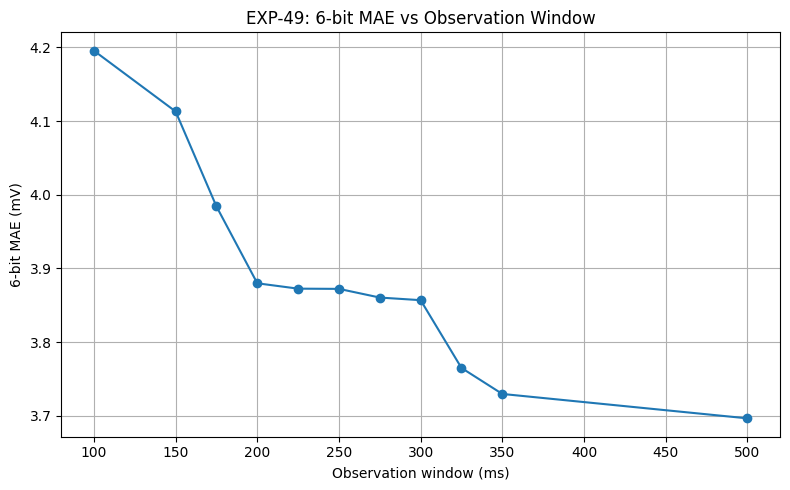

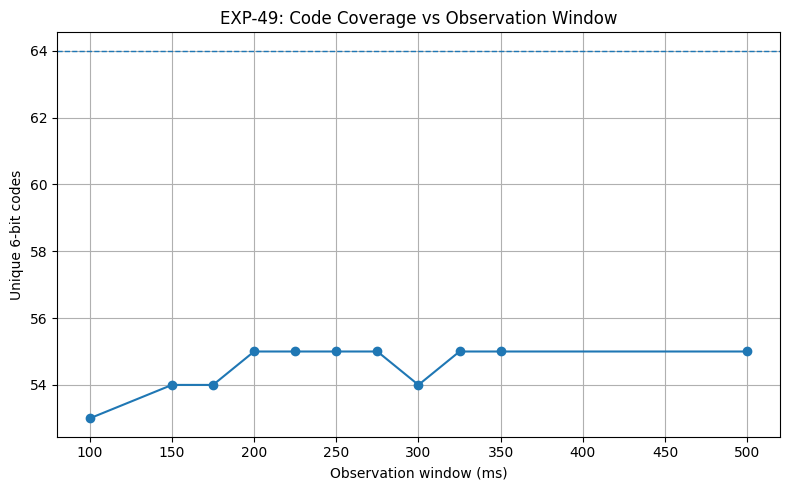

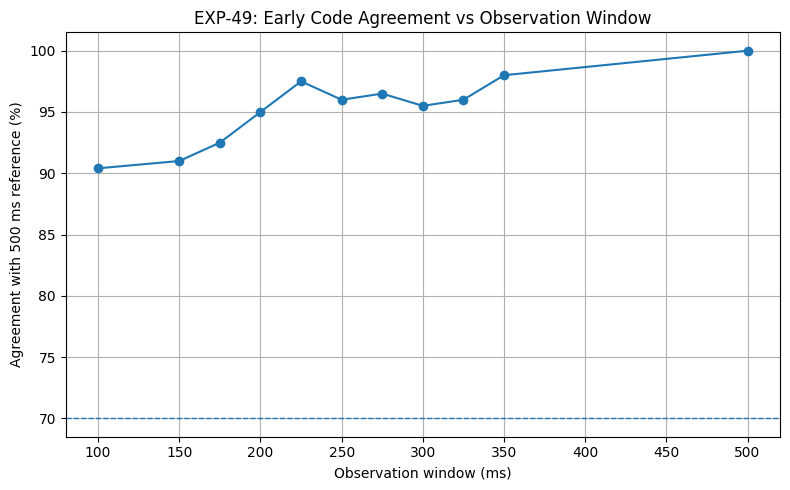

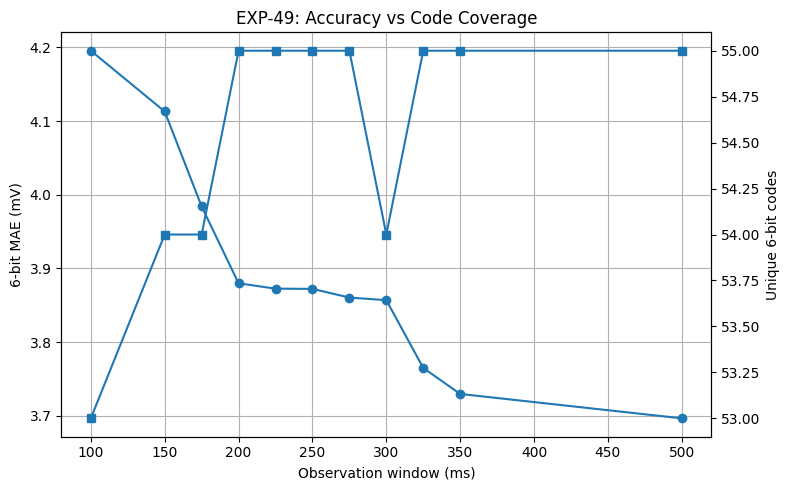



EXP-49 COMPLETE

This experiment answers:
  'How early can the Fly ADC produce a reliable code compared with the 500 ms reference?'

τm was fixed at 20.0 ms.
The earlier EXP-45B broad sweep is NOT repeated as a separate simulation campaign.

Recommended next step after this run:
  Use the earliest defensible window from EXP-49 as the ADC conversion time.

Original TAU_M_MS restored to 20.0 ms.


In [180]:
# ============================================================
# EXP-49 — MINIMUM OBSERVATION WINDOW / EARLY READOUT
# ============================================================
#
# Purpose:
#   Determine the earliest observation window at which the
#   corrected Fly ADC produces a reliable 6-bit output.
#
# Frozen configuration from EXP-48:
#   TAU_M       = 20.0 ms
#   W_SCALE     = 0.06
#   Drive       = 0.30 -> 1.00 for 0 -> 1 V
#   Decoder     = Mi1 count + L1 first latency + L1 mean ISI
#
# IMPORTANT:
#   Each voltage is simulated ONLY ONCE for 500 ms.
#   Shorter windows are extracted from the same spike trains.
#   This avoids thousands of repeated Brian2 simulations.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.isotonic import IsotonicRegression

# ------------------------------------------------------------
# 1. CHECK REQUIRED BIOWIRE OBJECTS
# ------------------------------------------------------------

required_objects = [
    "run_simulation_v1",
    "neuron_id100",
    "W100_4bit",
    "thr100",
    "N100"
]

missing = [x for x in required_objects if x not in globals()]

if missing:
    raise RuntimeError(
        "Missing required BioWire objects:\n"
        + "\n".join(missing)
        + "\n\nRun the BioWire model/setup cells first."
    )

print("=" * 100)
print("EXP-49 — MINIMUM OBSERVATION WINDOW / EARLY READOUT")
print("=" * 100)

# ------------------------------------------------------------
# 2. FREEZE EXP-48 CONFIGURATION
# ------------------------------------------------------------

TAU_M_EXP49 = 20.0
W_SCALE_EXP49 = 0.06

# Save original tau so notebook state is restored afterwards
TAU_M_ORIGINAL_EXP49 = TAU_M_MS

# Correct voltage-to-drive mapping
def voltage_to_drive_exp49(
    voltage,
    v_min=0.0,
    v_max=1.0,
    drive_min=0.30,
    drive_max=1.00
):
    voltage = np.clip(voltage, v_min, v_max)

    drive = (
        drive_min
        + ((voltage - v_min) / (v_max - v_min))
        * (drive_max - drive_min)
    )

    return float(drive)


print("\nFrozen configuration:")
print(f"τm       = {TAU_M_EXP49:.2f} ms")
print(f"W_SCALE  = {W_SCALE_EXP49:.2f}")
print("Drive    = 0.30 → 1.00")

print("\nVoltage-to-drive check:")
for v in [0.00, 0.25, 0.50, 0.75, 1.00]:
    print(
        f"{v:.2f} V -> "
        f"{voltage_to_drive_exp49(v):.3f}"
    )

# ------------------------------------------------------------
# 3. INPUT DATASETS
# ------------------------------------------------------------

# Training set used for decoder fitting
train_voltages_49 = np.linspace(0.0, 1.0, 101)

# Independent validation set
np.random.seed(2026)

validation_voltages_49 = np.random.uniform(
    0.0,
    1.0,
    200
)

validation_voltages_49 = np.sort(
    validation_voltages_49
)

# Observation windows
WINDOWS_49 = [
    100,
    150,
    175,
    200,
    225,
    250,
    275,
    300,
    325,
    350,
    500
]

FULL_DURATION_49 = 500.0

print("\nDatasets:")
print(f"Training voltages   : {len(train_voltages_49)}")
print(f"Validation voltages : {len(validation_voltages_49)}")
print(f"Windows             : {WINDOWS_49}")

# ------------------------------------------------------------
# 4. FIND L1 AND Mi1 INDICES
# ------------------------------------------------------------

L1_INDEX_49 = neuron_id100.get("L1")
MI1_INDEX_49 = neuron_id100.get("Mi1")

if L1_INDEX_49 is None or MI1_INDEX_49 is None:
    raise RuntimeError(
        "Could not find L1 or Mi1 in neuron_id100."
    )

print("\nNeuron indices:")
print(f"L1  index = {L1_INDEX_49}")
print(f"Mi1 index = {MI1_INDEX_49}")

# ------------------------------------------------------------
# 5. FEATURE EXTRACTION
# ------------------------------------------------------------

def extract_window_features_49(
    spike_trains,
    l1_index,
    mi1_index,
    window_ms
):
    """
    Extract EXP-33 features from the first window_ms of
    the already-generated spike trains.

    Features:
        0 = Mi1 spike count
        1 = L1 first-spike latency
        2 = L1 mean ISI

    NaN is returned when a required temporal feature
    cannot be calculated.
    """

    l1_times = np.asarray(
        spike_trains[l1_index] / ms
    )

    mi1_times = np.asarray(
        spike_trains[mi1_index] / ms
    )

    # Keep only spikes observed inside the window
    l1_times = l1_times[l1_times <= window_ms]
    mi1_times = mi1_times[mi1_times <= window_ms]

    # --------------------------------------------------------
    # Mi1 spike count
    # --------------------------------------------------------

    mi1_count = float(len(mi1_times))

    # --------------------------------------------------------
    # L1 first spike latency
    # --------------------------------------------------------

    if len(l1_times) > 0:
        l1_first_latency = float(l1_times[0])
    else:
        l1_first_latency = np.nan

    # --------------------------------------------------------
    # L1 mean ISI
    # --------------------------------------------------------

    if len(l1_times) >= 2:
        l1_isi = np.diff(l1_times)
        l1_mean_isi = float(np.mean(l1_isi))
    else:
        l1_mean_isi = np.nan

    return np.array([
        mi1_count,
        l1_first_latency,
        l1_mean_isi
    ], dtype=float)


# ------------------------------------------------------------
# 6. RUN EACH VOLTAGE ONCE FOR 500 ms
# ------------------------------------------------------------

def generate_spike_cache_49(
    voltages,
    dataset_name
):

    cache = {}

    total = len(voltages)

    print(
        f"\nGenerating {dataset_name} spike trains "
        f"({total} simulations)..."
    )

    # Set the frozen membrane time constant
    globals()["TAU_M_MS"] = TAU_M_EXP49

    for i, voltage in enumerate(voltages):

        if i == 0 or (i + 1) % 10 == 0 or i == total - 1:
            print(
                f"{dataset_name}: "
                f"{i + 1}/{total}"
            )

        drive = voltage_to_drive_exp49(
            voltage
        )

        # L1 + Mi1 are the ADC input channels
        active_neurons = [
            "L1",
            "Mi1"
        ]

        spike_mon, _, _, _ = run_simulation_v1(
            active_neurons,
            neuron_id100,
            W100_4bit,
            thr100,
            N100,
            duration_ms=FULL_DURATION_49,
            g_drive_on=drive,
            g_drive_off=0.15,
            w_scale=W_SCALE_EXP49
        )

        spike_trains = spike_mon.spike_trains()

        cache[float(voltage)] = {
            "l1_spikes": np.asarray(
                spike_trains[L1_INDEX_49] / ms
            ),
            "mi1_spikes": np.asarray(
                spike_trains[MI1_INDEX_49] / ms
            )
        }

    return cache


# ------------------------------------------------------------
# 7. CONVERT CACHE FORMAT TO FEATURE FORMAT
# ------------------------------------------------------------

def features_from_cache_entry_49(
    entry,
    window_ms
):

    l1_times = entry["l1_spikes"]
    mi1_times = entry["mi1_spikes"]

    # Restrict to observation window
    l1_times = l1_times[
        l1_times <= window_ms
    ]

    mi1_times = mi1_times[
        mi1_times <= window_ms
    ]

    # Mi1 count
    mi1_count = float(len(mi1_times))

    # L1 first spike
    if len(l1_times) > 0:
        l1_first = float(l1_times[0])
    else:
        l1_first = np.nan

    # L1 mean ISI
    if len(l1_times) >= 2:
        l1_mean_isi = float(
            np.mean(np.diff(l1_times))
        )
    else:
        l1_mean_isi = np.nan

    return np.array([
        mi1_count,
        l1_first,
        l1_mean_isi
    ], dtype=float)


# ------------------------------------------------------------
# 8. GENERATE TRAINING + VALIDATION SPIKE CACHES
# ------------------------------------------------------------

TRAIN_CACHE_49 = generate_spike_cache_49(
    train_voltages_49,
    "Training"
)

VAL_CACHE_49 = generate_spike_cache_49(
    validation_voltages_49,
    "Validation"
)

print("\nSpike-cache generation complete.")

# ------------------------------------------------------------
# 9. TRAIN WINDOW-SPECIFIC MONOTONIC DECODER
# ------------------------------------------------------------

def train_window_decoder_49(
    voltages,
    cache,
    window_ms
):

    X = []
    y = []

    for voltage in voltages:

        entry = cache[float(voltage)]

        feat = features_from_cache_entry_49(
            entry,
            window_ms
        )

        X.append(feat)
        y.append(float(voltage))

    X = np.asarray(X)
    y = np.asarray(y)

    # Require all three features to be finite
    valid = np.all(
        np.isfinite(X),
        axis=1
    )

    X_valid = X[valid]
    y_valid = y[valid]

    if len(X_valid) < 10:
        return None

    # --------------------------------------------------------
    # EXP-33 feature normalization
    # --------------------------------------------------------

    means = np.mean(
        X_valid,
        axis=0
    )

    stds = np.std(
        X_valid,
        axis=0
    )

    stds[stds == 0] = 1.0

    X_norm = (
        X_valid - means
    ) / stds

    # Feature directions:
    #
    # Mi1 count:
    #   higher voltage -> higher count
    #
    # L1 first latency:
    #   higher voltage -> lower latency
    #
    # L1 ISI:
    #   higher voltage -> lower ISI
    #
    # Therefore invert latency and ISI.

    X_score = np.column_stack([
        X_norm[:, 0],
        -X_norm[:, 1],
        -X_norm[:, 2]
    ])

    # Equal-weight biological temporal score
    score = np.mean(
        X_score,
        axis=1
    )

    # Sort score before isotonic regression
    order = np.argsort(score)

    score_sorted = score[order]
    y_sorted = y_valid[order]

    iso = IsotonicRegression(
        increasing=True,
        out_of_bounds="clip"
    )

    iso.fit(
        score_sorted,
        y_sorted
    )

    return {
        "means": means,
        "stds": stds,
        "iso": iso,
        "n_train": len(X_valid)
    }


# ------------------------------------------------------------
# 10. APPLY DECODER
# ------------------------------------------------------------

def predict_window_49(
    voltages,
    cache,
    window_ms,
    decoder
):

    X = []
    valid_voltages = []

    for voltage in voltages:

        entry = cache[float(voltage)]

        feat = features_from_cache_entry_49(
            entry,
            window_ms
        )

        if np.all(
            np.isfinite(feat)
        ):
            X.append(feat)
            valid_voltages.append(
                float(voltage)
            )

    X = np.asarray(X)

    valid_voltages = np.asarray(
        valid_voltages
    )

    if len(X) == 0:
        return (
            np.array([]),
            np.array([]),
            np.array([])
        )

    X_norm = (
        X - decoder["means"]
    ) / decoder["stds"]

    X_score = np.column_stack([
        X_norm[:, 0],
        -X_norm[:, 1],
        -X_norm[:, 2]
    ])

    score = np.mean(
        X_score,
        axis=1
    )

    predicted = decoder["iso"].predict(
        score
    )

    predicted = np.clip(
        predicted,
        0.0,
        1.0
    )

    return (
        valid_voltages,
        predicted,
        score
    )


# ------------------------------------------------------------
# 11. ADC QUANTIZER
# ------------------------------------------------------------

def quantize_6bit_49(voltage):

    voltage = np.clip(
        voltage,
        0.0,
        1.0
    )

    return np.rint(
        voltage * 63
    ).astype(int)


# ------------------------------------------------------------
# 12. METRICS
# ------------------------------------------------------------

def calculate_metrics_49(
    true_v,
    pred_v
):

    if len(true_v) == 0:
        return None

    errors = (
        pred_v - true_v
    )

    mae = np.mean(
        np.abs(errors)
    )

    rmse = np.sqrt(
        np.mean(errors ** 2)
    )

    max_error = np.max(
        np.abs(errors)
    )

    codes = quantize_6bit_49(
        pred_v
    )

    unique_codes = len(
        np.unique(codes)
    )

    analog_monotonic = bool(
        np.all(
            np.diff(pred_v) >= -1e-12
        )
    )

    code_monotonic = bool(
        np.all(
            np.diff(codes) >= 0
        )
    )

    return {
        "mae": mae,
        "rmse": rmse,
        "max_error": max_error,
        "codes": unique_codes,
        "code_values": codes,
        "analog_monotonic": analog_monotonic,
        "code_monotonic": code_monotonic
    }


# ------------------------------------------------------------
# 13. RUN ALL WINDOWS
# ------------------------------------------------------------

results_49 = []

predictions_49 = {}

print("\n")
print("=" * 100)
print("WINDOW-SPECIFIC ADC RESULTS")
print("=" * 100)

for window_ms in WINDOWS_49:

    print(
        f"\nProcessing window = "
        f"{window_ms} ms"
    )

    decoder = train_window_decoder_49(
        train_voltages_49,
        TRAIN_CACHE_49,
        window_ms
    )

    if decoder is None:

        print(
            "WARNING: insufficient valid "
            "training samples."
        )

        continue

    val_v, pred_v, score = predict_window_49(
        validation_voltages_49,
        VAL_CACHE_49,
        window_ms,
        decoder
    )

    metrics = calculate_metrics_49(
        val_v,
        pred_v
    )

    if metrics is None:
        continue

    predictions_49[window_ms] = {
        "voltage": val_v,
        "prediction": pred_v,
        "score": score,
        "code": metrics["code_values"]
    }

    results_49.append({
        "Window_ms": window_ms,
        "Train_valid": decoder["n_train"],
        "Val_valid": len(val_v),
        "MAE_mV": metrics["mae"] * 1000,
        "RMSE_mV": metrics["rmse"] * 1000,
        "MaxError_mV": metrics["max_error"] * 1000,
        "Codes": metrics["codes"],
        "AnalogMonotonic": metrics["analog_monotonic"],
        "CodeMonotonic": metrics["code_monotonic"]
    })

    print(
        f"MAE       = {metrics['mae']*1000:.3f} mV"
    )

    print(
        f"RMSE      = {metrics['rmse']*1000:.3f} mV"
    )

    print(
        f"Max error = {metrics['max_error']*1000:.3f} mV"
    )

    print(
        f"Codes     = {metrics['codes']}/64"
    )

    print(
        f"Analog mono = "
        f"{metrics['analog_monotonic']}"
    )

    print(
        f"Code mono   = "
        f"{metrics['code_monotonic']}"
    )


# ------------------------------------------------------------
# 14. CREATE RESULTS TABLE
# ------------------------------------------------------------

results_df_49 = pd.DataFrame(
    results_49
)

print("\n")
print("=" * 100)
print("EXP-49 SUMMARY")
print("=" * 100)

print(
    results_df_49.to_string(
        index=False,
        formatters={
            "MAE_mV": "{:.3f}".format,
            "RMSE_mV": "{:.3f}".format,
            "MaxError_mV": "{:.3f}".format
        }
    )
)


# ------------------------------------------------------------
# 15. 500 ms REFERENCE
# ------------------------------------------------------------

if 500 in predictions_49:

    ref_codes_49 = predictions_49[
        500
    ]["code"]

    ref_voltages_49 = predictions_49[
        500
    ]["voltage"]

    print("\n")
    print("=" * 100)
    print("CODE AGREEMENT WITH 500 ms REFERENCE")
    print("=" * 100)

    agreement_rows = []

    for window_ms in WINDOWS_49:

        if window_ms not in predictions_49:
            continue

        current = predictions_49[
            window_ms
        ]

        current_codes = current["code"]

        current_v = current["voltage"]

        # Match validation voltages exactly
        # because both came from the same sorted
        # validation set and same valid-feature filter.
        #
        # Use voltage lookup to be safe.

        ref_lookup = {
            round(float(v), 12): int(c)
            for v, c in zip(
                ref_voltages_49,
                ref_codes_49
            )
        }

        matches = []
        compared = 0

        for v, c in zip(
            current_v,
            current_codes
        ):

            key = round(
                float(v),
                12
            )

            if key in ref_lookup:

                compared += 1

                matches.append(
                    int(c == ref_lookup[key])
                )

        if compared > 0:
            agreement = (
                100
                * np.mean(matches)
            )
        else:
            agreement = np.nan

        agreement_rows.append({
            "Window_ms": window_ms,
            "CodeAgreement_pct": agreement,
            "Compared": compared
        })

        print(
            f"{window_ms:>4} ms : "
            f"{agreement:6.2f}% "
            f"({compared} samples)"
        )

    agreement_df_49 = pd.DataFrame(
        agreement_rows
    )

    results_df_49 = results_df_49.merge(
        agreement_df_49,
        on="Window_ms",
        how="left"
    )

else:

    print(
        "\nWARNING: 500 ms reference unavailable."
    )

    results_df_49["CodeAgreement_pct"] = np.nan


# ------------------------------------------------------------
# 16. FIND EARLIEST USEFUL WINDOW
# ------------------------------------------------------------

print("\n")
print("=" * 100)
print("EARLIEST USEFUL WINDOW")
print("=" * 100)

# Conservative criterion:
#
#   1. Code monotonicity must be true
#   2. Analog monotonicity must be true
#   3. 6-bit MAE <= 6.5 mV
#   4. Code agreement with 500 ms >= 70%
#
# This is deliberately not a claim of an ADC standard.
# It is our project-level selection criterion.

eligible_49 = results_df_49[
    (results_df_49["AnalogMonotonic"] == True)
    &
    (results_df_49["CodeMonotonic"] == True)
    &
    (results_df_49["MAE_mV"] <= 6.5)
    &
    (results_df_49["CodeAgreement_pct"] >= 70.0)
]

if len(eligible_49) > 0:

    earliest = eligible_49.iloc[0]

    print(
        f"Earliest candidate = "
        f"{int(earliest['Window_ms'])} ms"
    )

    print(
        f"6-bit MAE         = "
        f"{earliest['MAE_mV']:.3f} mV"
    )

    print(
        f"Code coverage      = "
        f"{int(earliest['Codes'])}/64"
    )

    print(
        f"500 ms agreement   = "
        f"{earliest['CodeAgreement_pct']:.2f}%"
    )

else:

    print(
        "No window satisfied all four "
        "selection criteria."
    )

# ------------------------------------------------------------
# 17. PLOT 1 — 6-BIT MAE
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    results_df_49["Window_ms"],
    results_df_49["MAE_mV"],
    marker="o"
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "6-bit MAE (mV)"
)

plt.title(
    "EXP-49: 6-bit MAE vs Observation Window"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 18. PLOT 2 — CODE COVERAGE
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    results_df_49["Window_ms"],
    results_df_49["Codes"],
    marker="o"
)

plt.axhline(
    64,
    linestyle="--",
    linewidth=1
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Unique 6-bit codes"
)

plt.title(
    "EXP-49: Code Coverage vs Observation Window"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 19. PLOT 3 — CODE AGREEMENT
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    results_df_49["Window_ms"],
    results_df_49["CodeAgreement_pct"],
    marker="o"
)

plt.axhline(
    70,
    linestyle="--",
    linewidth=1
)

plt.xlabel(
    "Observation window (ms)"
)

plt.ylabel(
    "Agreement with 500 ms reference (%)"
)

plt.title(
    "EXP-49: Early Code Agreement vs Observation Window"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 20. PLOT 4 — ERROR + COVERAGE
# ------------------------------------------------------------

fig, ax1 = plt.subplots(
    figsize=(8, 5)
)

ax1.plot(
    results_df_49["Window_ms"],
    results_df_49["MAE_mV"],
    marker="o"
)

ax1.set_xlabel(
    "Observation window (ms)"
)

ax1.set_ylabel(
    "6-bit MAE (mV)"
)

ax1.grid(True)

ax2 = ax1.twinx()

ax2.plot(
    results_df_49["Window_ms"],
    results_df_49["Codes"],
    marker="s"
)

ax2.set_ylabel(
    "Unique 6-bit codes"
)

plt.title(
    "EXP-49: Accuracy vs Code Coverage"
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 21. FINAL OUTPUT
# ------------------------------------------------------------

print("\n")
print("=" * 100)
print("EXP-49 COMPLETE")
print("=" * 100)

print(
    "\nThis experiment answers:"
)

print(
    "  'How early can the Fly ADC produce a "
    "reliable code compared with the 500 ms reference?'"
)

print(
    "\nτm was fixed at 20.0 ms."
)

print(
    "The earlier EXP-45B broad sweep is NOT repeated "
    "as a separate simulation campaign."
)

print(
    "\nRecommended next step after this run:"
)

print(
    "  Use the earliest defensible window from EXP-49 "
    "as the ADC conversion time."
)

# ------------------------------------------------------------
# 22. RESTORE ORIGINAL TAU
# ------------------------------------------------------------

globals()["TAU_M_MS"] = TAU_M_ORIGINAL_EXP49

print(
    f"\nOriginal TAU_M_MS restored to "
    f"{TAU_M_MS} ms."
)

EXP-50 — INPUT-TO-DRIVE MAPPING SWEEP

Frozen configuration:
τm       = 20.00 ms
W_SCALE  = 0.06
Window   = 200 ms

Mappings:
M1_0.10_to_1.00     : 0.10 -> 1.00
M2_0.20_to_1.00     : 0.20 -> 1.00
M3_0.30_to_1.00     : 0.30 -> 1.00
M4_0.30_to_1.10     : 0.30 -> 1.10
M5_0.30_to_1.20     : 0.30 -> 1.20

Dataset:
Training   : 51
Validation : 101


M1_0.10_to_1.00
Drive range: 0.10 -> 1.00

Generating Training: 51 simulations
Training: 1/51
Training: 10/51
Training: 20/51
Training: 30/51
Training: 40/51
Training: 50/51
Training: 51/51

Generating Validation: 101 simulations
Validation: 1/101
Validation: 10/101
Validation: 20/101
Validation: 30/101
Validation: 40/101
Validation: 50/101
Validation: 60/101
Validation: 70/101
Validation: 80/101
Validation: 90/101
Validation: 100/101
Validation: 101/101

Results for M1_0.10_to_1.00
MAE          = 4.726 mV
RMSE         = 6.228 mV
Max error    = 18.983 mV
Unique codes = 36/64
Analog mono  = True
Code mono    = True
Mi1 count    = 0 -> 33
L1 latenc

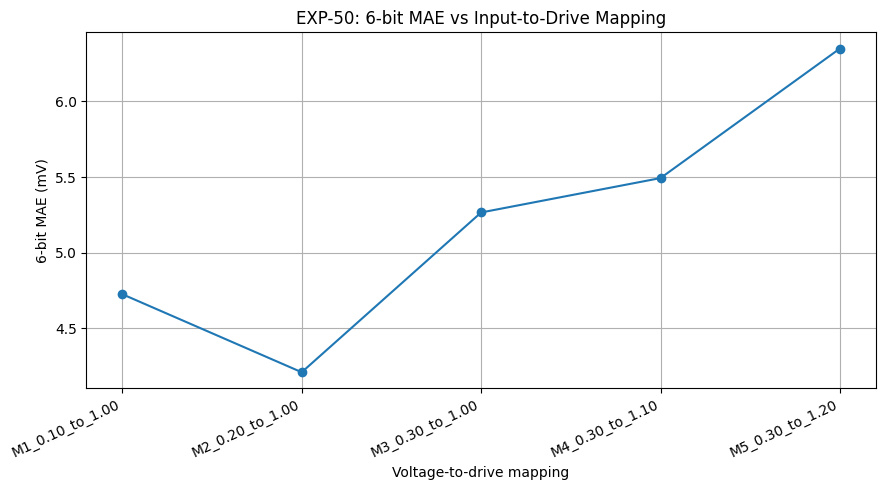

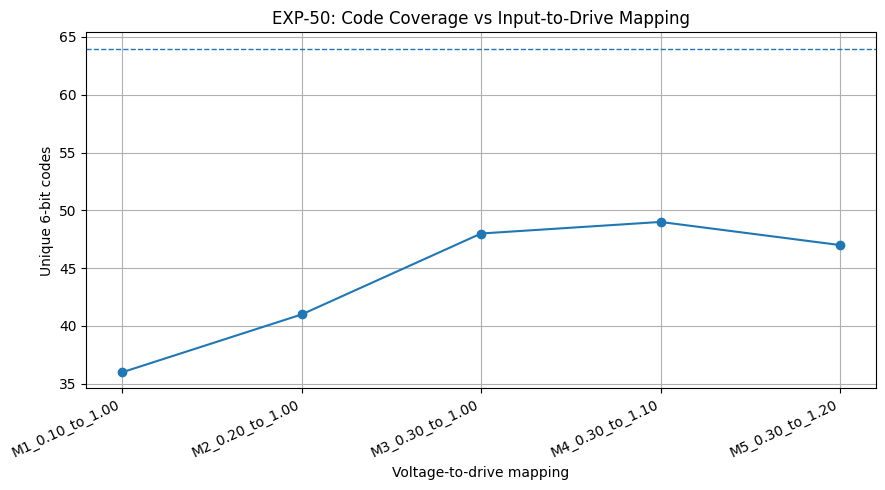

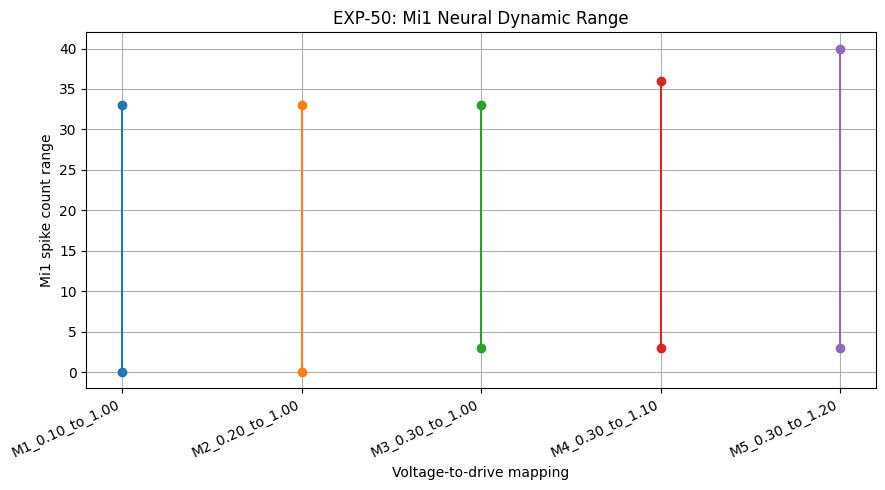



EXP-50 COMPLETE

TAU_M_MS restored to 20.0 ms.

IMPORTANT:
This is a SCREENING experiment.
If one mapping clearly wins, we will rerun that mapping with the full 101-point training + 200-point validation dataset before accepting it as the final configuration.


In [181]:
# ============================================================
# EXP-50 — INPUT-TO-DRIVE MAPPING SWEEP
# ============================================================
#
# Question:
#   Is the current 0-1 V -> 0.30-1.00 neural-drive mapping
#   limiting the Fly ADC?
#
# Frozen:
#   TAU_M     = 20 ms
#   W_SCALE   = 0.06
#   WINDOW    = 200 ms
#
# Screening datasets:
#   51 training voltages
#   101 independent validation voltages
#
# Tested mappings:
#   0.10 -> 1.00
#   0.20 -> 1.00
#   0.30 -> 1.00  [CURRENT BASELINE]
#   0.30 -> 1.10
#   0.30 -> 1.20
#
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.isotonic import IsotonicRegression

print("=" * 100)
print("EXP-50 — INPUT-TO-DRIVE MAPPING SWEEP")
print("=" * 100)

# ------------------------------------------------------------
# 1. REQUIRED BIOWIRE OBJECTS
# ------------------------------------------------------------

required_objects_50 = [
    "run_simulation_v1",
    "neuron_id100",
    "W100_4bit",
    "thr100",
    "N100"
]

missing_50 = [
    x for x in required_objects_50
    if x not in globals()
]

if missing_50:
    raise RuntimeError(
        "Missing BioWire objects:\n"
        + "\n".join(missing_50)
        + "\n\nRun the BioWire setup/model cells first."
    )

# ------------------------------------------------------------
# 2. FROZEN ADC CONFIGURATION
# ------------------------------------------------------------

TAU_M_50 = 20.0
W_SCALE_50 = 0.06
WINDOW_50 = 200.0

TAU_M_ORIGINAL_50 = TAU_M_MS

globals()["TAU_M_MS"] = TAU_M_50

L1_INDEX_50 = neuron_id100.get("L1")
MI1_INDEX_50 = neuron_id100.get("Mi1")

if L1_INDEX_50 is None or MI1_INDEX_50 is None:
    raise RuntimeError(
        "Could not find L1 or Mi1."
    )

print("\nFrozen configuration:")
print(f"τm       = {TAU_M_50:.2f} ms")
print(f"W_SCALE  = {W_SCALE_50:.2f}")
print(f"Window   = {WINDOW_50:.0f} ms")

# ------------------------------------------------------------
# 3. MAPPINGS TO TEST
# ------------------------------------------------------------

MAPPINGS_50 = {
    "M1_0.10_to_1.00": (0.10, 1.00),
    "M2_0.20_to_1.00": (0.20, 1.00),
    "M3_0.30_to_1.00": (0.30, 1.00),  # CURRENT BASELINE
    "M4_0.30_to_1.10": (0.30, 1.10),
    "M5_0.30_to_1.20": (0.30, 1.20),
}

print("\nMappings:")
for name, (dmin, dmax) in MAPPINGS_50.items():
    print(
        f"{name:20s}: "
        f"{dmin:.2f} -> {dmax:.2f}"
    )

# ------------------------------------------------------------
# 4. VOLTAGE DATA
# ------------------------------------------------------------

# Moderate-size screening training set
train_voltages_50 = np.linspace(
    0.0,
    1.0,
    51
)

# Independent validation set
np.random.seed(2026)

validation_voltages_50 = np.sort(
    np.random.uniform(
        0.0,
        1.0,
        101
    )
)

print("\nDataset:")
print(
    f"Training   : {len(train_voltages_50)}"
)
print(
    f"Validation : {len(validation_voltages_50)}"
)

# ------------------------------------------------------------
# 5. VOLTAGE -> DRIVE FUNCTION
# ------------------------------------------------------------

def voltage_to_drive_50(
    voltage,
    drive_min,
    drive_max
):

    voltage = np.clip(
        voltage,
        0.0,
        1.0
    )

    return float(
        drive_min
        + voltage * (
            drive_max - drive_min
        )
    )


# ------------------------------------------------------------
# 6. SPIKE SIMULATION
# ------------------------------------------------------------

def simulate_voltage_50(
    voltage,
    drive_min,
    drive_max
):

    drive = voltage_to_drive_50(
        voltage,
        drive_min,
        drive_max
    )

    spike_mon, _, _, _ = run_simulation_v1(
        ["L1", "Mi1"],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        duration_ms=WINDOW_50,
        g_drive_on=drive,
        g_drive_off=0.15,
        w_scale=W_SCALE_50
    )

    spike_trains = spike_mon.spike_trains()

    l1_spikes = np.asarray(
        spike_trains[L1_INDEX_50] / ms
    )

    mi1_spikes = np.asarray(
        spike_trains[MI1_INDEX_50] / ms
    )

    return {
        "l1_spikes": l1_spikes,
        "mi1_spikes": mi1_spikes,
        "drive": drive
    }


# ------------------------------------------------------------
# 7. FEATURE EXTRACTION
# ------------------------------------------------------------

def extract_features_50(
    result
):

    l1 = result["l1_spikes"]
    mi1 = result["mi1_spikes"]

    # Everything is already inside 200 ms,
    # because the simulation itself is 200 ms.

    mi1_count = float(
        len(mi1)
    )

    if len(l1) > 0:
        l1_first = float(
            l1[0]
        )
    else:
        l1_first = np.nan

    if len(l1) >= 2:
        l1_mean_isi = float(
            np.mean(
                np.diff(l1)
            )
        )
    else:
        l1_mean_isi = np.nan

    return np.array([
        mi1_count,
        l1_first,
        l1_mean_isi
    ], dtype=float)


# ------------------------------------------------------------
# 8. GENERATE FEATURES
# ------------------------------------------------------------

def generate_dataset_50(
    voltages,
    drive_min,
    drive_max,
    label
):

    X = []

    total = len(voltages)

    print(
        f"\nGenerating {label}: "
        f"{total} simulations"
    )

    for i, voltage in enumerate(
        voltages
    ):

        if (
            i == 0
            or (i + 1) % 10 == 0
            or i == total - 1
        ):
            print(
                f"{label}: "
                f"{i+1}/{total}"
            )

        result = simulate_voltage_50(
            voltage,
            drive_min,
            drive_max
        )

        features = extract_features_50(
            result
        )

        X.append(features)

    return np.asarray(X)


# ------------------------------------------------------------
# 9. TRAIN DECODER
# ------------------------------------------------------------

def train_decoder_50(
    X,
    y
):

    finite = np.all(
        np.isfinite(X),
        axis=1
    )

    X = X[finite]
    y = y[finite]

    if len(X) < 10:
        return None

    means = np.mean(
        X,
        axis=0
    )

    stds = np.std(
        X,
        axis=0
    )

    stds[
        stds == 0
    ] = 1.0

    Xn = (
        X - means
    ) / stds

    # EXP-33 temporal representation
    score_features = np.column_stack([
        Xn[:, 0],     # Mi1 count
        -Xn[:, 1],    # earlier L1 spike = higher voltage
        -Xn[:, 2]     # shorter L1 ISI = higher voltage
    ])

    score = np.mean(
        score_features,
        axis=1
    )

    order = np.argsort(
        score
    )

    iso = IsotonicRegression(
        increasing=True,
        out_of_bounds="clip"
    )

    iso.fit(
        score[order],
        y[order]
    )

    return {
        "means": means,
        "stds": stds,
        "iso": iso,
        "n_valid": len(X)
    }


# ------------------------------------------------------------
# 10. PREDICT
# ------------------------------------------------------------

def predict_50(
    X,
    decoder
):

    finite = np.all(
        np.isfinite(X),
        axis=1
    )

    X_valid = X[finite]

    Xn = (
        X_valid
        - decoder["means"]
    ) / decoder["stds"]

    score_features = np.column_stack([
        Xn[:, 0],
        -Xn[:, 1],
        -Xn[:, 2]
    ])

    score = np.mean(
        score_features,
        axis=1
    )

    prediction = decoder[
        "iso"
    ].predict(score)

    prediction = np.clip(
        prediction,
        0.0,
        1.0
    )

    return prediction, finite


# ------------------------------------------------------------
# 11. 6-BIT QUANTIZER
# ------------------------------------------------------------

def quantize_50(
    voltage
):

    voltage = np.clip(
        voltage,
        0.0,
        1.0
    )

    return np.rint(
        voltage * 63
    ).astype(int)


# ------------------------------------------------------------
# 12. RUN SWEEP
# ------------------------------------------------------------

results_50 = []

feature_cache_50 = {}

for mapping_name, (
    drive_min,
    drive_max
) in MAPPINGS_50.items():

    print("\n")
    print("=" * 90)
    print(mapping_name)
    print("=" * 90)

    print(
        f"Drive range: "
        f"{drive_min:.2f} -> {drive_max:.2f}"
    )

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    X_train = generate_dataset_50(
        train_voltages_50,
        drive_min,
        drive_max,
        "Training"
    )

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    X_val = generate_dataset_50(
        validation_voltages_50,
        drive_min,
        drive_max,
        "Validation"
    )

    feature_cache_50[
        mapping_name
    ] = {
        "X_train": X_train,
        "X_val": X_val
    }

    # --------------------------------------------------------
    # TRAIN DECODER
    # --------------------------------------------------------

    decoder = train_decoder_50(
        X_train,
        train_voltages_50
    )

    if decoder is None:
        print(
            "Decoder training failed."
        )
        continue

    # --------------------------------------------------------
    # VALIDATION PREDICTION
    # --------------------------------------------------------

    prediction, valid_mask = predict_50(
        X_val,
        decoder
    )

    true_voltage = (
        validation_voltages_50[
            valid_mask
        ]
    )

    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    error = (
        prediction
        - true_voltage
    )

    mae = np.mean(
        np.abs(error)
    )

    rmse = np.sqrt(
        np.mean(error ** 2)
    )

    max_error = np.max(
        np.abs(error)
    )

    codes = quantize_50(
        prediction
    )

    unique_codes = len(
        np.unique(codes)
    )

    analog_monotonic = bool(
        np.all(
            np.diff(prediction)
            >= -1e-12
        )
    )

    code_monotonic = bool(
        np.all(
            np.diff(codes)
            >= 0
        )
    )

    # --------------------------------------------------------
    # RAW NEURAL FEATURE RANGES
    # --------------------------------------------------------

    mi1_count_min = np.min(
        X_val[:, 0]
    )

    mi1_count_max = np.max(
        X_val[:, 0]
    )

    l1_latency_min = np.nanmin(
        X_val[:, 1]
    )

    l1_latency_max = np.nanmax(
        X_val[:, 1]
    )

    l1_isi_min = np.nanmin(
        X_val[:, 2]
    )

    l1_isi_max = np.nanmax(
        X_val[:, 2]
    )

    print(
        f"\nResults for {mapping_name}"
    )

    print(
        f"MAE          = "
        f"{mae*1000:.3f} mV"
    )

    print(
        f"RMSE         = "
        f"{rmse*1000:.3f} mV"
    )

    print(
        f"Max error    = "
        f"{max_error*1000:.3f} mV"
    )

    print(
        f"Unique codes = "
        f"{unique_codes}/64"
    )

    print(
        f"Analog mono  = "
        f"{analog_monotonic}"
    )

    print(
        f"Code mono    = "
        f"{code_monotonic}"
    )

    print(
        f"Mi1 count    = "
        f"{mi1_count_min:.0f} -> "
        f"{mi1_count_max:.0f}"
    )

    print(
        f"L1 latency   = "
        f"{l1_latency_min:.2f} -> "
        f"{l1_latency_max:.2f} ms"
    )

    print(
        f"L1 mean ISI  = "
        f"{l1_isi_min:.2f} -> "
        f"{l1_isi_max:.2f} ms"
    )

    results_50.append({
        "Mapping": mapping_name,
        "DriveMin": drive_min,
        "DriveMax": drive_max,
        "MAE_mV": mae * 1000,
        "RMSE_mV": rmse * 1000,
        "MaxError_mV": max_error * 1000,
        "Codes": unique_codes,
        "AnalogMonotonic": analog_monotonic,
        "CodeMonotonic": code_monotonic,
        "Mi1Min": mi1_count_min,
        "Mi1Max": mi1_count_max,
        "L1LatencyMin": l1_latency_min,
        "L1LatencyMax": l1_latency_max,
        "L1ISI_Min": l1_isi_min,
        "L1ISI_Max": l1_isi_max
    })


# ------------------------------------------------------------
# 13. SUMMARY
# ------------------------------------------------------------

results_df_50 = pd.DataFrame(
    results_50
)

print("\n")
print("=" * 100)
print("EXP-50 FINAL SCREENING SUMMARY")
print("=" * 100)

print(
    results_df_50[
        [
            "Mapping",
            "MAE_mV",
            "RMSE_mV",
            "MaxError_mV",
            "Codes",
            "AnalogMonotonic",
            "CodeMonotonic"
        ]
    ].to_string(
        index=False,
        formatters={
            "MAE_mV": "{:.3f}".format,
            "RMSE_mV": "{:.3f}".format,
            "MaxError_mV": "{:.3f}".format
        }
    )
)


# ------------------------------------------------------------
# 14. FIND BEST VALID MAPPING
# ------------------------------------------------------------

valid_50 = results_df_50[
    (results_df_50["AnalogMonotonic"] == True)
    &
    (results_df_50["CodeMonotonic"] == True)
]

if len(valid_50) > 0:

    best_accuracy_50 = valid_50.loc[
        valid_50["MAE_mV"].idxmin()
    ]

    best_coverage_50 = valid_50.loc[
        valid_50["Codes"].idxmax()
    ]

    print("\n")
    print("=" * 100)
    print("BEST ADC-VALID MAPPINGS")
    print("=" * 100)

    print(
        "\nBest accuracy:"
    )

    print(
        f"Mapping = "
        f"{best_accuracy_50['Mapping']}"
    )

    print(
        f"MAE     = "
        f"{best_accuracy_50['MAE_mV']:.3f} mV"
    )

    print(
        f"Codes   = "
        f"{int(best_accuracy_50['Codes'])}/64"
    )

    print(
        "\nBest code coverage:"
    )

    print(
        f"Mapping = "
        f"{best_coverage_50['Mapping']}"
    )

    print(
        f"Codes   = "
        f"{int(best_coverage_50['Codes'])}/64"
    )

    print(
        f"MAE     = "
        f"{best_coverage_50['MAE_mV']:.3f} mV"
    )


# ------------------------------------------------------------
# 15. PLOT MAE
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    results_df_50["Mapping"],
    results_df_50["MAE_mV"],
    marker="o"
)

plt.ylabel(
    "6-bit MAE (mV)"
)

plt.xlabel(
    "Voltage-to-drive mapping"
)

plt.title(
    "EXP-50: 6-bit MAE vs Input-to-Drive Mapping"
)

plt.xticks(
    rotation=25,
    ha="right"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 16. PLOT CODE COVERAGE
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    results_df_50["Mapping"],
    results_df_50["Codes"],
    marker="o"
)

plt.axhline(
    64,
    linestyle="--",
    linewidth=1
)

plt.ylabel(
    "Unique 6-bit codes"
)

plt.xlabel(
    "Voltage-to-drive mapping"
)

plt.title(
    "EXP-50: Code Coverage vs Input-to-Drive Mapping"
)

plt.xticks(
    rotation=25,
    ha="right"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 17. PLOT NEURAL DYNAMIC RANGE
# ------------------------------------------------------------

plt.figure(
    figsize=(9, 5)
)

for mapping_name in results_df_50[
    "Mapping"
]:

    row = results_df_50[
        results_df_50["Mapping"]
        == mapping_name
    ].iloc[0]

    plt.plot(
        [mapping_name, mapping_name],
        [
            row["Mi1Min"],
            row["Mi1Max"]
        ],
        marker="o"
    )

plt.ylabel(
    "Mi1 spike count range"
)

plt.xlabel(
    "Voltage-to-drive mapping"
)

plt.title(
    "EXP-50: Mi1 Neural Dynamic Range"
)

plt.xticks(
    rotation=25,
    ha="right"
)

plt.grid(True)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 18. RESTORE TAU
# ------------------------------------------------------------

globals()["TAU_M_MS"] = (
    TAU_M_ORIGINAL_50
)

print("\n")
print("=" * 100)
print("EXP-50 COMPLETE")
print("=" * 100)

print(
    "\nTAU_M_MS restored to "
    f"{TAU_M_MS} ms."
)

print(
    "\nIMPORTANT:"
)

print(
    "This is a SCREENING experiment."
)

print(
    "If one mapping clearly wins, we will rerun that mapping "
    "with the full 101-point training + 200-point validation "
    "dataset before accepting it as the final configuration."
)

EXP-51 — FULL INPUT-TO-DRIVE MAPPING VALIDATION

Frozen configuration:
tau_m       = 20.00 ms
W_SCALE     = 0.06
Window      = 200 ms
Decoder     = Mi1 count + L1 first latency + L1 mean ISI

Mappings being compared:
M2_0.20_to_1.00     : 0.20 -> 1.00
M3_0.30_to_1.00     : 0.30 -> 1.00

Datasets:
Training   = 101
Validation = 200

REUSING EXP-49 M3 BASELINE CACHE
EXP-49 baseline cache found.
No new M3 simulations required.


GENERATING M2 = 0.20 -> 1.00

Generating M2 Training: 101 simulations
M2 Training: 1/101
M2 Training: 10/101
M2 Training: 20/101
M2 Training: 30/101
M2 Training: 40/101
M2 Training: 50/101
M2 Training: 60/101
M2 Training: 70/101
M2 Training: 80/101
M2 Training: 90/101
M2 Training: 100/101
M2 Training: 101/101

Generating M2 Validation: 200 simulations
M2 Validation: 1/200
M2 Validation: 10/200
M2 Validation: 20/200
M2 Validation: 30/200
M2 Validation: 40/200
M2 Validation: 50/200
M2 Validation: 60/200
M2 Validation: 70/200
M2 Validation: 80/200
M2 Validation: 90/20

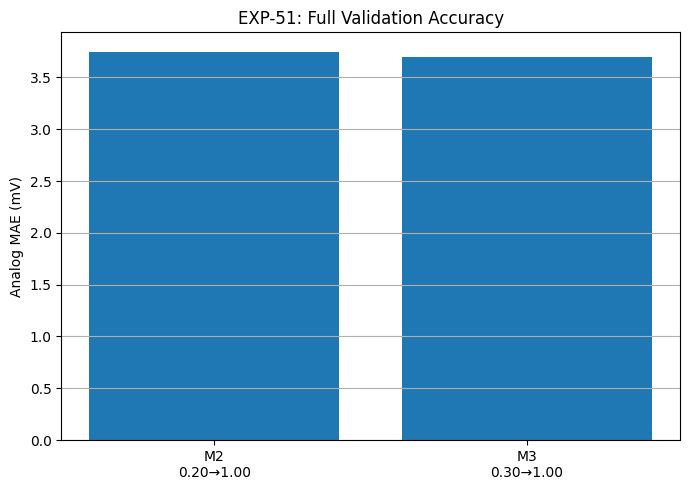

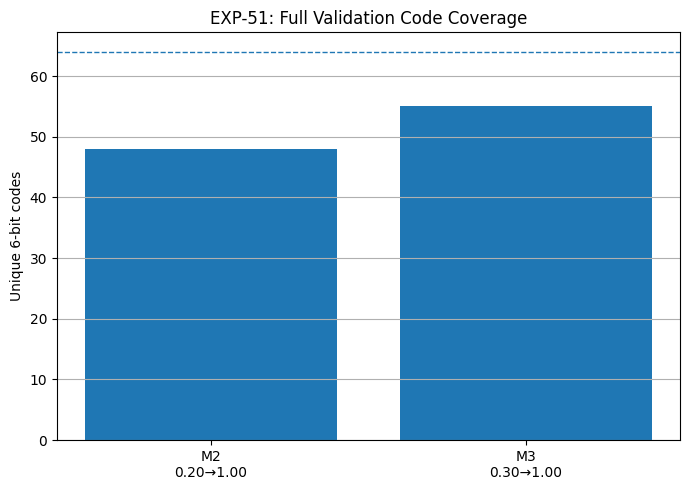

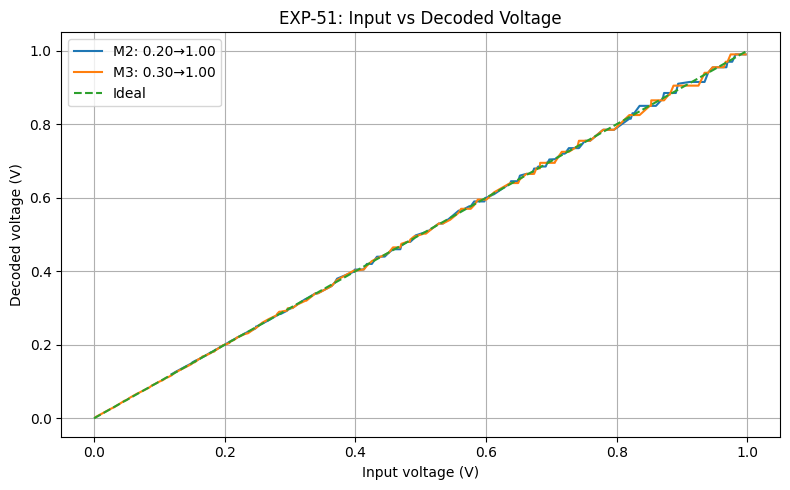



EXP-51 COMPLETE
TAU_M_MS restored to 20.0 ms.

This is the proper full-data comparison.
Do NOT select M2 or M3 until looking at this result.


In [182]:
# ============================================================
# EXP-51 — FULL INPUT-TO-DRIVE MAPPING VALIDATION
# ============================================================
#
# PURPOSE
# -------
# Proper apples-to-apples comparison of:
#
#   M2 = 0.20 -> 1.00
#   M3 = 0.30 -> 1.00  [CURRENT BASELINE]
#
# Both mappings use:
#   101 training voltages
#   200 independent validation voltages
#   tau_m = 20 ms
#   W_SCALE = 0.06
#   observation window = 200 ms
#   EXP-33 temporal decoder
#
# IMPORTANT
# ---------
# If EXP-49 caches still exist, the M3 baseline cache is reused.
# This saves ~301 Brian2 simulations.
#
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.isotonic import IsotonicRegression

print("=" * 105)
print("EXP-51 — FULL INPUT-TO-DRIVE MAPPING VALIDATION")
print("=" * 105)

# ------------------------------------------------------------
# 1. CHECK REQUIRED BIOWIRE OBJECTS
# ------------------------------------------------------------

required_51 = [
    "run_simulation_v1",
    "neuron_id100",
    "W100_4bit",
    "thr100",
    "N100"
]

missing_51 = [
    x for x in required_51
    if x not in globals()
]

if missing_51:
    raise RuntimeError(
        "Missing required BioWire objects:\n"
        + "\n".join(missing_51)
        + "\n\nRun the BioWire setup/model cells first."
    )

# ------------------------------------------------------------
# 2. FROZEN CONFIGURATION
# ------------------------------------------------------------

TAU_M_51 = 20.0
W_SCALE_51 = 0.06
WINDOW_51 = 200.0

TAU_M_ORIGINAL_51 = TAU_M_MS
globals()["TAU_M_MS"] = TAU_M_51

L1_INDEX_51 = neuron_id100.get("L1")
MI1_INDEX_51 = neuron_id100.get("Mi1")

if L1_INDEX_51 is None or MI1_INDEX_51 is None:
    raise RuntimeError(
        "Could not find L1 or Mi1."
    )

print("\nFrozen configuration:")
print(f"tau_m       = {TAU_M_51:.2f} ms")
print(f"W_SCALE     = {W_SCALE_51:.2f}")
print(f"Window      = {WINDOW_51:.0f} ms")
print("Decoder     = Mi1 count + L1 first latency + L1 mean ISI")

# ------------------------------------------------------------
# 3. MAPPINGS
# ------------------------------------------------------------

MAPPINGS_51 = {
    "M2_0.20_to_1.00": (0.20, 1.00),
    "M3_0.30_to_1.00": (0.30, 1.00)
}

print("\nMappings being compared:")
for name, (dmin, dmax) in MAPPINGS_51.items():
    print(
        f"{name:20s}: "
        f"{dmin:.2f} -> {dmax:.2f}"
    )

# ------------------------------------------------------------
# 4. EXACT SAME DATASETS AS EXP-49
# ------------------------------------------------------------

train_voltages_51 = np.linspace(
    0.0,
    1.0,
    101
)

np.random.seed(2026)

validation_voltages_51 = np.sort(
    np.random.uniform(
        0.0,
        1.0,
        200
    )
)

print("\nDatasets:")
print(f"Training   = {len(train_voltages_51)}")
print(f"Validation = {len(validation_voltages_51)}")

# ------------------------------------------------------------
# 5. VOLTAGE -> DRIVE
# ------------------------------------------------------------

def voltage_to_drive_51(
    voltage,
    drive_min,
    drive_max
):

    voltage = np.clip(
        voltage,
        0.0,
        1.0
    )

    return float(
        drive_min
        + voltage * (
            drive_max - drive_min
        )
    )


# ------------------------------------------------------------
# 6. SPIKE SIMULATION
# ------------------------------------------------------------

def simulate_voltage_51(
    voltage,
    drive_min,
    drive_max
):

    drive = voltage_to_drive_51(
        voltage,
        drive_min,
        drive_max
    )

    spike_mon, _, _, _ = run_simulation_v1(
        ["L1", "Mi1"],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        duration_ms=WINDOW_51,
        g_drive_on=drive,
        g_drive_off=0.15,
        w_scale=W_SCALE_51
    )

    spike_trains = spike_mon.spike_trains()

    l1_spikes = np.asarray(
        spike_trains[L1_INDEX_51] / ms
    )

    mi1_spikes = np.asarray(
        spike_trains[MI1_INDEX_51] / ms
    )

    return {
        "l1_spikes": l1_spikes,
        "mi1_spikes": mi1_spikes
    }


# ------------------------------------------------------------
# 7. FEATURE EXTRACTION
# ------------------------------------------------------------

def extract_features_51(
    entry
):

    l1 = np.asarray(
        entry["l1_spikes"]
    )

    mi1 = np.asarray(
        entry["mi1_spikes"]
    )

    # All spikes are already within the 200 ms window.
    mi1_count = float(
        len(mi1)
    )

    if len(l1) > 0:
        l1_first_latency = float(
            l1[0]
        )
    else:
        l1_first_latency = np.nan

    if len(l1) >= 2:
        l1_mean_isi = float(
            np.mean(
                np.diff(l1)
            )
        )
    else:
        l1_mean_isi = np.nan

    return np.array([
        mi1_count,
        l1_first_latency,
        l1_mean_isi
    ], dtype=float)


# ------------------------------------------------------------
# 8. GENERATE CACHE
# ------------------------------------------------------------

def generate_cache_51(
    voltages,
    drive_min,
    drive_max,
    label
):

    cache = {}

    total = len(voltages)

    print(
        f"\nGenerating {label}: "
        f"{total} simulations"
    )

    for i, voltage in enumerate(
        voltages
    ):

        if (
            i == 0
            or (i + 1) % 10 == 0
            or i == total - 1
        ):
            print(
                f"{label}: "
                f"{i+1}/{total}"
            )

        result = simulate_voltage_51(
            voltage,
            drive_min,
            drive_max
        )

        cache[float(voltage)] = result

    return cache


# ------------------------------------------------------------
# 9. REUSE EXP-49 BASELINE CACHE IF AVAILABLE
# ------------------------------------------------------------
#
# EXP-49 simulated the same M3 mapping using 101 training
# and 200 validation voltages. Its cache contains 500 ms
# spike trains, so we can safely extract the first 200 ms.
#
# This saves 301 simulations.
# ------------------------------------------------------------

def convert_exp49_cache_51(
    old_cache
):

    converted = {}

    for voltage, entry in old_cache.items():

        converted[float(voltage)] = {
            "l1_spikes": np.asarray(
                entry["l1_spikes"]
            ),
            "mi1_spikes": np.asarray(
                entry["mi1_spikes"]
            )
        }

    return converted


# ------------------------------------------------------------
# 10. STORAGE
# ------------------------------------------------------------

caches_51 = {}

# ------------------------------------------------------------
# M3 BASELINE
# ------------------------------------------------------------

reuse_m3 = (
    "TRAIN_CACHE_49" in globals()
    and
    "VAL_CACHE_49" in globals()
)

if reuse_m3:

    print("\n" + "=" * 90)
    print("REUSING EXP-49 M3 BASELINE CACHE")
    print("=" * 90)

    train_cache_m3 = (
        convert_exp49_cache_51(
            TRAIN_CACHE_49
        )
    )

    val_cache_m3 = (
        convert_exp49_cache_51(
            VAL_CACHE_49
        )
    )

    print(
        "EXP-49 baseline cache found."
    )

    print(
        "No new M3 simulations required."
    )

else:

    print("\n")
    print("=" * 90)
    print("EXP-49 CACHE NOT FOUND")
    print("=" * 90)

    print(
        "Generating full M3 baseline..."
    )

    train_cache_m3 = generate_cache_51(
        train_voltages_51,
        0.30,
        1.00,
        "M3 Training"
    )

    val_cache_m3 = generate_cache_51(
        validation_voltages_51,
        0.30,
        1.00,
        "M3 Validation"
    )


# ------------------------------------------------------------
# M2
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("GENERATING M2 = 0.20 -> 1.00")
print("=" * 90)

train_cache_m2 = generate_cache_51(
    train_voltages_51,
    0.20,
    1.00,
    "M2 Training"
)

val_cache_m2 = generate_cache_51(
    validation_voltages_51,
    0.20,
    1.00,
    "M2 Validation"
)

caches_51["M2"] = {
    "train": train_cache_m2,
    "val": val_cache_m2
}

caches_51["M3"] = {
    "train": train_cache_m3,
    "val": val_cache_m3
}

# ------------------------------------------------------------
# 11. TRAIN EXP-33 DECODER
# ------------------------------------------------------------

def train_decoder_51(
    voltages,
    cache
):

    X = []
    y = []

    for voltage in voltages:

        entry = cache[
            float(voltage)
        ]

        features = extract_features_51(
            entry
        )

        X.append(
            features
        )

        y.append(
            float(voltage)
        )

    X = np.asarray(X)
    y = np.asarray(y)

    finite = np.all(
        np.isfinite(X),
        axis=1
    )

    X = X[finite]
    y = y[finite]

    if len(X) < 10:
        return None

    # Training-only normalization
    means = np.mean(
        X,
        axis=0
    )

    stds = np.std(
        X,
        axis=0
    )

    stds[
        stds == 0
    ] = 1.0

    Xn = (
        X - means
    ) / stds

    # EXP-33 score
    #
    # Mi1 count: positive
    # L1 first latency: inverted
    # L1 mean ISI: inverted

    score_features = np.column_stack([
        Xn[:, 0],
        -Xn[:, 1],
        -Xn[:, 2]
    ])

    score = np.mean(
        score_features,
        axis=1
    )

    order = np.argsort(
        score
    )

    iso = IsotonicRegression(
        increasing=True,
        out_of_bounds="clip"
    )

    iso.fit(
        score[order],
        y[order]
    )

    return {
        "means": means,
        "stds": stds,
        "iso": iso,
        "n_valid": len(X)
    }


# ------------------------------------------------------------
# 12. PREDICT
# ------------------------------------------------------------

def predict_51(
    voltages,
    cache,
    decoder
):

    X = []
    valid_voltages = []

    for voltage in voltages:

        entry = cache[
            float(voltage)
        ]

        features = extract_features_51(
            entry
        )

        if np.all(
            np.isfinite(features)
        ):

            X.append(
                features
            )

            valid_voltages.append(
                float(voltage)
            )

    X = np.asarray(X)

    valid_voltages = np.asarray(
        valid_voltages
    )

    Xn = (
        X
        - decoder["means"]
    ) / decoder["stds"]

    score_features = np.column_stack([
        Xn[:, 0],
        -Xn[:, 1],
        -Xn[:, 2]
    ])

    score = np.mean(
        score_features,
        axis=1
    )

    prediction = decoder[
        "iso"
    ].predict(
        score
    )

    prediction = np.clip(
        prediction,
        0.0,
        1.0
    )

    return (
        valid_voltages,
        prediction,
        score
    )


# ------------------------------------------------------------
# 13. 6-BIT QUANTIZER
# ------------------------------------------------------------

def quantize_51(
    voltage
):

    voltage = np.clip(
        voltage,
        0.0,
        1.0
    )

    return np.rint(
        voltage * 63
    ).astype(int)


# ------------------------------------------------------------
# 14. RUN BOTH CONFIGURATIONS
# ------------------------------------------------------------

results_51 = {}
predictions_51 = {}

for label in ["M2", "M3"]:

    print("\n")
    print("=" * 100)
    print(
        f"FULL VALIDATION: {label}"
    )
    print("=" * 100)

    if label == "M2":

        dmin = 0.20
        dmax = 1.00

    else:

        dmin = 0.30
        dmax = 1.00

    train_cache = caches_51[
        label
    ]["train"]

    val_cache = caches_51[
        label
    ]["val"]

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    decoder = train_decoder_51(
        train_voltages_51,
        train_cache
    )

    if decoder is None:
        raise RuntimeError(
            f"Decoder training failed for {label}."
        )

    # --------------------------------------------------------
    # VALIDATE
    # --------------------------------------------------------

    val_v, prediction, score = predict_51(
        validation_voltages_51,
        val_cache,
        decoder
    )

    # --------------------------------------------------------
    # ERROR METRICS
    # --------------------------------------------------------

    error = (
        prediction
        - val_v
    )

    mae = np.mean(
        np.abs(error)
    )

    rmse = np.sqrt(
        np.mean(
            error ** 2
        )
    )

    max_error = np.max(
        np.abs(error)
    )

    # --------------------------------------------------------
    # 6-BIT
    # --------------------------------------------------------

    codes = quantize_51(
        prediction
    )

    unique_codes = len(
        np.unique(codes)
    )

    code_error = (
        codes / 63.0
        - val_v
    )

    code_mae = np.mean(
        np.abs(code_error)
    )

    code_rmse = np.sqrt(
        np.mean(
            code_error ** 2
        )
    )

    # --------------------------------------------------------
    # MONOTONICITY
    # --------------------------------------------------------

    analog_monotonic = bool(
        np.all(
            np.diff(prediction)
            >= -1e-12
        )
    )

    code_monotonic = bool(
        np.all(
            np.diff(codes)
            >= 0
        )
    )

    # --------------------------------------------------------
    # NEURAL RANGE
    # --------------------------------------------------------

    X_val = np.asarray([
        extract_features_51(
            val_cache[
                float(v)
            ]
        )
        for v in validation_voltages_51
    ])

    mi1_min = np.nanmin(
        X_val[:, 0]
    )

    mi1_max = np.nanmax(
        X_val[:, 0]
    )

    l1_latency_min = np.nanmin(
        X_val[:, 1]
    )

    l1_latency_max = np.nanmax(
        X_val[:, 1]
    )

    l1_isi_min = np.nanmin(
        X_val[:, 2]
    )

    l1_isi_max = np.nanmax(
        X_val[:, 2]
    )

    results_51[label] = {
        "mapping": (
            f"{dmin:.2f} -> {dmax:.2f}"
        ),
        "train_valid": decoder["n_valid"],
        "val_valid": len(val_v),
        "mae_mV": mae * 1000,
        "rmse_mV": rmse * 1000,
        "max_error_mV": max_error * 1000,
        "code_mae_mV": code_mae * 1000,
        "code_rmse_mV": code_rmse * 1000,
        "codes": unique_codes,
        "analog_monotonic": analog_monotonic,
        "code_monotonic": code_monotonic,
        "mi1_min": mi1_min,
        "mi1_max": mi1_max,
        "l1_latency_min": l1_latency_min,
        "l1_latency_max": l1_latency_max,
        "l1_isi_min": l1_isi_min,
        "l1_isi_max": l1_isi_max
    }

    predictions_51[label] = {
        "voltage": val_v,
        "prediction": prediction,
        "code": codes,
        "score": score
    }

    print(
        f"\nMapping       = "
        f"{dmin:.2f} -> {dmax:.2f}"
    )

    print(
        f"Training valid = "
        f"{decoder['n_valid']}/101"
    )

    print(
        f"Validation     = "
        f"{len(val_v)}/200"
    )

    print(
        f"Analog MAE     = "
        f"{mae*1000:.3f} mV"
    )

    print(
        f"Analog RMSE    = "
        f"{rmse*1000:.3f} mV"
    )

    print(
        f"Max error      = "
        f"{max_error*1000:.3f} mV"
    )

    print(
        f"6-bit MAE      = "
        f"{code_mae*1000:.3f} mV"
    )

    print(
        f"6-bit RMSE     = "
        f"{code_rmse*1000:.3f} mV"
    )

    print(
        f"Unique codes   = "
        f"{unique_codes}/64"
    )

    print(
        f"Analog mono    = "
        f"{analog_monotonic}"
    )

    print(
        f"Code mono      = "
        f"{code_monotonic}"
    )

    print(
        f"Mi1 range      = "
        f"{mi1_min:.0f} -> "
        f"{mi1_max:.0f}"
    )

    print(
        f"L1 latency     = "
        f"{l1_latency_min:.2f} -> "
        f"{l1_latency_max:.2f} ms"
    )

    print(
        f"L1 mean ISI    = "
        f"{l1_isi_min:.2f} -> "
        f"{l1_isi_max:.2f} ms"
    )


# ------------------------------------------------------------
# 15. SUMMARY TABLE
# ------------------------------------------------------------

summary_51 = pd.DataFrame(
    [
        {
            "Mapping": label,
            **results_51[label]
        }
        for label in ["M2", "M3"]
    ]
)

print("\n")
print("=" * 105)
print("EXP-51 FINAL COMPARISON")
print("=" * 105)

print(
    summary_51[
        [
            "Mapping",
            "mae_mV",
            "rmse_mV",
            "max_error_mV",
            "code_mae_mV",
            "codes",
            "analog_monotonic",
            "code_monotonic"
        ]
    ].to_string(
        index=False,
        formatters={
            "mae_mV": "{:.3f}".format,
            "rmse_mV": "{:.3f}".format,
            "max_error_mV": "{:.3f}".format,
            "code_mae_mV": "{:.3f}".format
        }
    )
)


# ------------------------------------------------------------
# 16. DIRECT M2 vs M3 COMPARISON
# ------------------------------------------------------------

m2 = results_51["M2"]
m3 = results_51["M3"]

mae_improvement = (
    m3["mae_mV"]
    - m2["mae_mV"]
)

code_mae_improvement = (
    m3["code_mae_mV"]
    - m2["code_mae_mV"]
)

print("\n")
print("=" * 100)
print("M2 vs M3")
print("=" * 100)

print(
    f"Analog MAE change      = "
    f"{mae_improvement:+.3f} mV"
)

print(
    f"6-bit MAE change       = "
    f"{code_mae_improvement:+.3f} mV"
)

print(
    f"Code coverage change   = "
    f"{m2['codes'] - m3['codes']:+d} codes"
)

print(
    f"Mi1 minimum change     = "
    f"{m2['mi1_min'] - m3['mi1_min']:+.0f} spikes"
)

# ------------------------------------------------------------
# 17. DECISION
# ------------------------------------------------------------

print("\n")
print("=" * 100)
print("EXP-51 DECISION")
print("=" * 100)

m2_valid = (
    m2["analog_monotonic"]
    and
    m2["code_monotonic"]
)

m3_valid = (
    m3["analog_monotonic"]
    and
    m3["code_monotonic"]
)

if m2_valid and m3_valid:

    if (
        m2["mae_mV"]
        < m3["mae_mV"]
    ):

        print(
            "M2 (0.20 -> 1.00) WINS "
            "on analog accuracy."
        )

    elif (
        m2["mae_mV"]
        > m3["mae_mV"]
    ):

        print(
            "M3 (0.30 -> 1.00) WINS "
            "on analog accuracy."
        )

    else:

        print(
            "M2 and M3 have identical "
            "analog MAE."
        )

    if (
        m2["code_mae_mV"]
        < m3["code_mae_mV"]
    ):

        print(
            "M2 also wins on 6-bit "
            "quantized accuracy."
        )

    elif (
        m2["code_mae_mV"]
        > m3["code_mae_mV"]
    ):

        print(
            "M3 wins on 6-bit "
            "quantized accuracy."
        )

    else:

        print(
            "M2 and M3 have identical "
            "6-bit MAE."
        )

else:

    print(
        "At least one mapping is not "
        "fully ADC-valid because monotonicity failed."
    )

# ------------------------------------------------------------
# 18. PLOT DIRECT COMPARISON
# ------------------------------------------------------------

labels_plot = [
    "M2\n0.20→1.00",
    "M3\n0.30→1.00"
]

mae_plot = [
    m2["mae_mV"],
    m3["mae_mV"]
]

codes_plot = [
    m2["codes"],
    m3["codes"]
]

plt.figure(
    figsize=(7, 5)
)

plt.bar(
    labels_plot,
    mae_plot
)

plt.ylabel(
    "Analog MAE (mV)"
)

plt.title(
    "EXP-51: Full Validation Accuracy"
)

plt.grid(
    axis="y"
)

plt.tight_layout()

plt.show()


plt.figure(
    figsize=(7, 5)
)

plt.bar(
    labels_plot,
    codes_plot
)

plt.axhline(
    64,
    linestyle="--",
    linewidth=1
)

plt.ylabel(
    "Unique 6-bit codes"
)

plt.title(
    "EXP-51: Full Validation Code Coverage"
)

plt.grid(
    axis="y"
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 19. TRANSFER CURVES
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    predictions_51["M2"]["voltage"],
    predictions_51["M2"]["prediction"],
    label="M2: 0.20→1.00"
)

plt.plot(
    predictions_51["M3"]["voltage"],
    predictions_51["M3"]["prediction"],
    label="M3: 0.30→1.00"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Ideal"
)

plt.xlabel(
    "Input voltage (V)"
)

plt.ylabel(
    "Decoded voltage (V)"
)

plt.title(
    "EXP-51: Input vs Decoded Voltage"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 20. RESTORE TAU
# ------------------------------------------------------------

globals()["TAU_M_MS"] = (
    TAU_M_ORIGINAL_51
)

print("\n")
print("=" * 100)
print("EXP-51 COMPLETE")
print("=" * 100)

print(
    f"TAU_M_MS restored to "
    f"{TAU_M_MS} ms."
)

print(
    "\nThis is the proper full-data comparison."
)

print(
    "Do NOT select M2 or M3 until looking at this result."
)

EXP-52 — FULL VALIDATION: 0.30 -> 1.10

Frozen configuration:
tau_m       = 20.00 ms
W_SCALE     = 0.06
Observation = 200 ms
Decoder     = Mi1 count + L1 first latency + L1 mean ISI

Dataset:
Training   = 101
Validation = 200


M3 BASELINE: 0.30 -> 1.00
EXP-49 cache found.
Reusing M3 baseline.


M4 CANDIDATE: 0.30 -> 1.10

Generating M4 Training: 101 simulations
M4 Training: 1/101
M4 Training: 10/101
M4 Training: 20/101
M4 Training: 30/101
M4 Training: 40/101
M4 Training: 50/101
M4 Training: 60/101
M4 Training: 70/101
M4 Training: 80/101
M4 Training: 90/101
M4 Training: 100/101
M4 Training: 101/101

Generating M4 Validation: 200 simulations
M4 Validation: 1/200
M4 Validation: 10/200
M4 Validation: 20/200
M4 Validation: 30/200
M4 Validation: 40/200
M4 Validation: 50/200
M4 Validation: 60/200
M4 Validation: 70/200
M4 Validation: 80/200
M4 Validation: 90/200
M4 Validation: 100/200
M4 Validation: 110/200
M4 Validation: 120/200
M4 Validation: 130/200
M4 Validation: 140/200
M4 Validation: 15

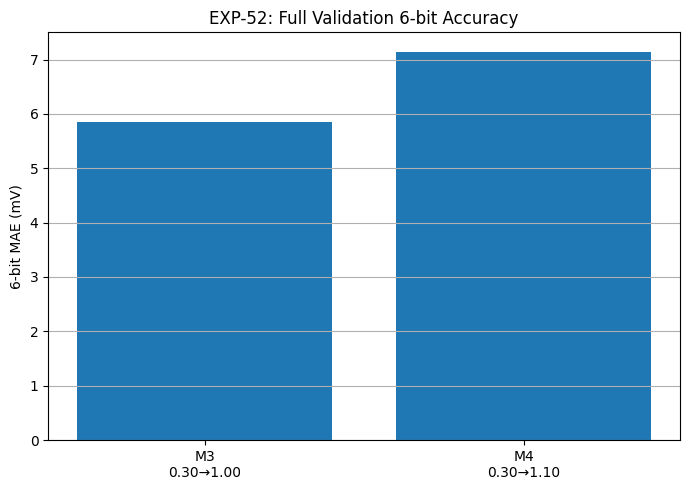

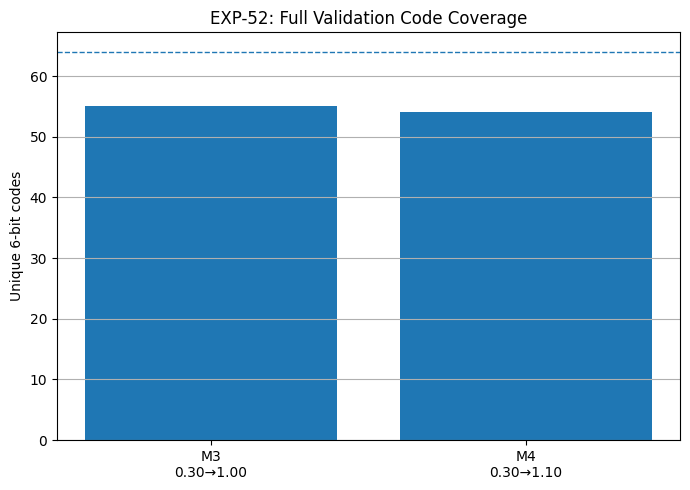

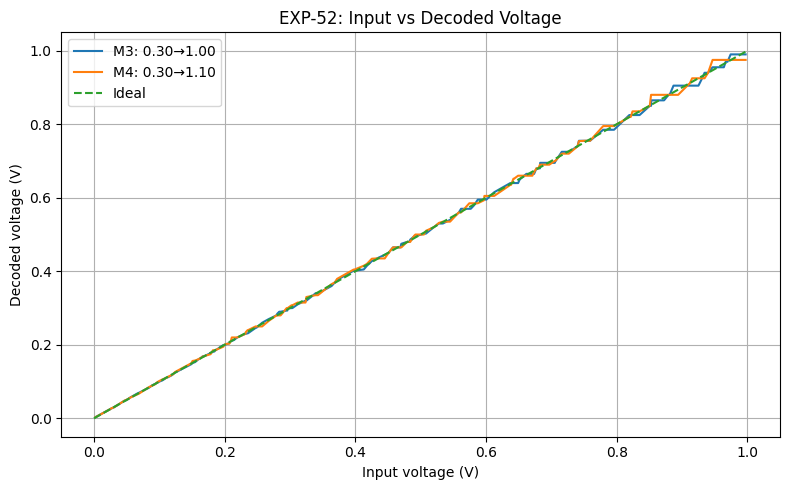



EXP-52 COMPLETE
TAU_M_MS restored to 20.0 ms.

If M4 does not clearly beat M3 while remaining monotonic, freeze 0.30 -> 1.00 and move to final ADC characterization.


In [183]:
# ============================================================
# EXP-52 — FULL VALIDATION OF 0.30 -> 1.10 DRIVE MAPPING
# ============================================================
#
# Compare:
#   M3 = 0.30 -> 1.00  [established baseline]
#   M4 = 0.30 -> 1.10  [candidate]
#
# Frozen:
#   tau_m       = 20 ms
#   W_SCALE     = 0.06
#   observation = 200 ms
#   decoder     = EXP-33
#
# Dataset:
#   101 training voltages
#   200 independent validation voltages
#   validation seed = 2026
#
# M3 cache is reused from EXP-49 if available.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression

print("=" * 105)
print("EXP-52 — FULL VALIDATION: 0.30 -> 1.10")
print("=" * 105)

# ------------------------------------------------------------
# 1. REQUIRED OBJECTS
# ------------------------------------------------------------

required = [
    "run_simulation_v1",
    "neuron_id100",
    "W100_4bit",
    "thr100",
    "N100"
]

missing = [
    x for x in required
    if x not in globals()
]

if missing:
    raise RuntimeError(
        "Missing BioWire objects:\n"
        + "\n".join(missing)
        + "\nRun the BioWire setup cells first."
    )

# ------------------------------------------------------------
# 2. FROZEN CONFIGURATION
# ------------------------------------------------------------

TAU_M_52 = 20.0
W_SCALE_52 = 0.06
WINDOW_52 = 200.0

TAU_M_ORIGINAL_52 = TAU_M_MS
globals()["TAU_M_MS"] = TAU_M_52

L1_INDEX_52 = neuron_id100["L1"]
MI1_INDEX_52 = neuron_id100["Mi1"]

print("\nFrozen configuration:")
print(f"tau_m       = {TAU_M_52:.2f} ms")
print(f"W_SCALE     = {W_SCALE_52:.2f}")
print(f"Observation = {WINDOW_52:.0f} ms")
print("Decoder     = Mi1 count + L1 first latency + L1 mean ISI")

# ------------------------------------------------------------
# 3. EXACT EXP-51 DATASETS
# ------------------------------------------------------------

train_voltages_52 = np.linspace(
    0.0,
    1.0,
    101
)

np.random.seed(2026)

validation_voltages_52 = np.sort(
    np.random.uniform(
        0.0,
        1.0,
        200
    )
)

print("\nDataset:")
print(f"Training   = {len(train_voltages_52)}")
print(f"Validation = {len(validation_voltages_52)}")

# ------------------------------------------------------------
# 4. VOLTAGE -> DRIVE
# ------------------------------------------------------------

def voltage_to_drive_52(
    voltage,
    drive_min,
    drive_max
):

    voltage = np.clip(
        voltage,
        0.0,
        1.0
    )

    return float(
        drive_min
        + voltage * (
            drive_max - drive_min
        )
    )


# ------------------------------------------------------------
# 5. SIMULATE ONE INPUT
# ------------------------------------------------------------

def simulate_voltage_52(
    voltage,
    drive_min,
    drive_max
):

    drive = voltage_to_drive_52(
        voltage,
        drive_min,
        drive_max
    )

    spike_mon, _, _, _ = run_simulation_v1(
        ["L1", "Mi1"],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        duration_ms=WINDOW_52,
        g_drive_on=drive,
        g_drive_off=0.15,
        w_scale=W_SCALE_52
    )

    spike_trains = spike_mon.spike_trains()

    l1_spikes = np.asarray(
        spike_trains[L1_INDEX_52] / ms
    )

    mi1_spikes = np.asarray(
        spike_trains[MI1_INDEX_52] / ms
    )

    return {
        "l1_spikes": l1_spikes,
        "mi1_spikes": mi1_spikes
    }


# ------------------------------------------------------------
# 6. FEATURE EXTRACTION
# ------------------------------------------------------------

def extract_features_52(entry):

    l1 = np.asarray(
        entry["l1_spikes"]
    )

    mi1 = np.asarray(
        entry["mi1_spikes"]
    )

    # Feature 1: Mi1 spike count
    mi1_count = float(
        len(mi1)
    )

    # Feature 2: L1 first-spike latency
    if len(l1) > 0:
        l1_first = float(
            l1[0]
        )
    else:
        l1_first = np.nan

    # Feature 3: L1 mean ISI
    if len(l1) >= 2:
        l1_mean_isi = float(
            np.mean(
                np.diff(l1)
            )
        )
    else:
        l1_mean_isi = np.nan

    return np.array([
        mi1_count,
        l1_first,
        l1_mean_isi
    ])


# ------------------------------------------------------------
# 7. GENERATE FULL CACHE
# ------------------------------------------------------------

def generate_cache_52(
    voltages,
    drive_min,
    drive_max,
    label
):

    cache = {}

    total = len(voltages)

    print(
        f"\nGenerating {label}: "
        f"{total} simulations"
    )

    for i, voltage in enumerate(
        voltages
    ):

        if (
            i == 0
            or (i + 1) % 10 == 0
            or i == total - 1
        ):
            print(
                f"{label}: "
                f"{i+1}/{total}"
            )

        cache[
            float(voltage)
        ] = simulate_voltage_52(
            voltage,
            drive_min,
            drive_max
        )

    return cache


# ------------------------------------------------------------
# 8. CONVERT EXISTING EXP-49 CACHE
# ------------------------------------------------------------

def convert_cache_52(old_cache):

    new_cache = {}

    for voltage, entry in old_cache.items():

        new_cache[
            float(voltage)
        ] = {
            "l1_spikes": np.asarray(
                entry["l1_spikes"]
            ),
            "mi1_spikes": np.asarray(
                entry["mi1_spikes"]
            )
        }

    return new_cache


# ------------------------------------------------------------
# 9. GET BASELINE M3
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("M3 BASELINE: 0.30 -> 1.00")
print("=" * 90)

if (
    "TRAIN_CACHE_49" in globals()
    and
    "VAL_CACHE_49" in globals()
):

    print(
        "EXP-49 cache found."
    )

    print(
        "Reusing M3 baseline."
    )

    train_cache_m3_52 = convert_cache_52(
        TRAIN_CACHE_49
    )

    val_cache_m3_52 = convert_cache_52(
        VAL_CACHE_49
    )

else:

    print(
        "EXP-49 cache not found."
    )

    print(
        "Generating M3 baseline..."
    )

    train_cache_m3_52 = generate_cache_52(
        train_voltages_52,
        0.30,
        1.00,
        "M3 Training"
    )

    val_cache_m3_52 = generate_cache_52(
        validation_voltages_52,
        0.30,
        1.00,
        "M3 Validation"
    )


# ------------------------------------------------------------
# 10. GENERATE M4
# ------------------------------------------------------------

print("\n")
print("=" * 90)
print("M4 CANDIDATE: 0.30 -> 1.10")
print("=" * 90)

train_cache_m4_52 = generate_cache_52(
    train_voltages_52,
    0.30,
    1.10,
    "M4 Training"
)

val_cache_m4_52 = generate_cache_52(
    validation_voltages_52,
    0.30,
    1.10,
    "M4 Validation"
)

# ------------------------------------------------------------
# 11. DECODER
# ------------------------------------------------------------

def train_decoder_52(
    voltages,
    cache
):

    X = []
    y = []

    for voltage in voltages:

        features = extract_features_52(
            cache[
                float(voltage)
            ]
        )

        X.append(
            features
        )

        y.append(
            float(voltage)
        )

    X = np.asarray(X)
    y = np.asarray(y)

    valid = np.all(
        np.isfinite(X),
        axis=1
    )

    X = X[valid]
    y = y[valid]

    if len(X) < 10:
        return None

    # Training-only normalization
    means = np.mean(
        X,
        axis=0
    )

    stds = np.std(
        X,
        axis=0
    )

    stds[
        stds == 0
    ] = 1.0

    Xn = (
        X - means
    ) / stds

    # EXP-33 temporal score
    score_features = np.column_stack([
        Xn[:, 0],      # Mi1 count
        -Xn[:, 1],     # inverse L1 latency
        -Xn[:, 2]      # inverse L1 ISI
    ])

    score = np.mean(
        score_features,
        axis=1
    )

    order = np.argsort(
        score
    )

    iso = IsotonicRegression(
        increasing=True,
        out_of_bounds="clip"
    )

    iso.fit(
        score[order],
        y[order]
    )

    return {
        "means": means,
        "stds": stds,
        "iso": iso,
        "n_valid": len(X)
    }


# ------------------------------------------------------------
# 12. PREDICTION
# ------------------------------------------------------------

def predict_52(
    voltages,
    cache,
    decoder
):

    X = []
    valid_voltages = []

    for voltage in voltages:

        features = extract_features_52(
            cache[
                float(voltage)
            ]
        )

        if np.all(
            np.isfinite(features)
        ):

            X.append(
                features
            )

            valid_voltages.append(
                float(voltage)
            )

    X = np.asarray(X)

    valid_voltages = np.asarray(
        valid_voltages
    )

    Xn = (
        X - decoder["means"]
    ) / decoder["stds"]

    score_features = np.column_stack([
        Xn[:, 0],
        -Xn[:, 1],
        -Xn[:, 2]
    ])

    score = np.mean(
        score_features,
        axis=1
    )

    prediction = decoder[
        "iso"
    ].predict(
        score
    )

    prediction = np.clip(
        prediction,
        0.0,
        1.0
    )

    return (
        valid_voltages,
        prediction,
        score
    )


# ------------------------------------------------------------
# 13. 6-BIT QUANTIZER
# ------------------------------------------------------------

def quantize_52(
    voltage
):

    voltage = np.clip(
        voltage,
        0.0,
        1.0
    )

    return np.rint(
        voltage * 63
    ).astype(int)


# ------------------------------------------------------------
# 14. EVALUATE ONE MAPPING
# ------------------------------------------------------------

def evaluate_mapping_52(
    name,
    drive_min,
    drive_max,
    train_cache,
    val_cache
):

    print("\n")
    print("=" * 100)
    print(f"EVALUATING {name}")
    print("=" * 100)

    decoder = train_decoder_52(
        train_voltages_52,
        train_cache
    )

    if decoder is None:
        raise RuntimeError(
            f"Decoder failed for {name}"
        )

    val_v, prediction, score = predict_52(
        validation_voltages_52,
        val_cache,
        decoder
    )

    error = (
        prediction - val_v
    )

    analog_mae = np.mean(
        np.abs(error)
    )

    analog_rmse = np.sqrt(
        np.mean(
            error ** 2
        )
    )

    max_error = np.max(
        np.abs(error)
    )

    codes = quantize_52(
        prediction
    )

    decoded_6bit = (
        codes / 63.0
    )

    code_error = (
        decoded_6bit - val_v
    )

    code_mae = np.mean(
        np.abs(code_error)
    )

    code_rmse = np.sqrt(
        np.mean(
            code_error ** 2
        )
    )

    unique_codes = len(
        np.unique(codes)
    )

    analog_monotonic = bool(
        np.all(
            np.diff(prediction)
            >= -1e-12
        )
    )

    code_monotonic = bool(
        np.all(
            np.diff(codes)
            >= 0
        )
    )

    # Neural range
    X_val = np.asarray([
        extract_features_52(
            val_cache[
                float(v)
            ]
        )
        for v in validation_voltages_52
    ])

    mi1_min = np.nanmin(
        X_val[:, 0]
    )

    mi1_max = np.nanmax(
        X_val[:, 0]
    )

    l1_lat_min = np.nanmin(
        X_val[:, 1]
    )

    l1_lat_max = np.nanmax(
        X_val[:, 1]
    )

    l1_isi_min = np.nanmin(
        X_val[:, 2]
    )

    l1_isi_max = np.nanmax(
        X_val[:, 2]
    )

    result = {
        "name": name,
        "drive_min": drive_min,
        "drive_max": drive_max,
        "train_valid": decoder["n_valid"],
        "val_valid": len(val_v),
        "analog_mae_mV": analog_mae * 1000,
        "analog_rmse_mV": analog_rmse * 1000,
        "sixbit_mae_mV": code_mae * 1000,
        "sixbit_rmse_mV": code_rmse * 1000,
        "max_error_mV": max_error * 1000,
        "codes": unique_codes,
        "analog_monotonic": analog_monotonic,
        "code_monotonic": code_monotonic,
        "mi1_min": mi1_min,
        "mi1_max": mi1_max,
        "l1_lat_min": l1_lat_min,
        "l1_lat_max": l1_lat_max,
        "l1_isi_min": l1_isi_min,
        "l1_isi_max": l1_isi_max
    }

    predictions = {
        "voltage": val_v,
        "prediction": prediction,
        "code": codes,
        "score": score
    }

    print(
        f"\nDrive mapping = "
        f"{drive_min:.2f} -> {drive_max:.2f}"
    )

    print(
        f"Training valid = "
        f"{decoder['n_valid']}/101"
    )

    print(
        f"Validation     = "
        f"{len(val_v)}/200"
    )

    print(
        f"Analog MAE     = "
        f"{analog_mae*1000:.3f} mV"
    )

    print(
        f"Analog RMSE    = "
        f"{analog_rmse*1000:.3f} mV"
    )

    print(
        f"6-bit MAE      = "
        f"{code_mae*1000:.3f} mV"
    )

    print(
        f"6-bit RMSE     = "
        f"{code_rmse*1000:.3f} mV"
    )

    print(
        f"Max error      = "
        f"{max_error*1000:.3f} mV"
    )

    print(
        f"Unique codes   = "
        f"{unique_codes}/64"
    )

    print(
        f"Analog mono    = "
        f"{analog_monotonic}"
    )

    print(
        f"Code mono      = "
        f"{code_monotonic}"
    )

    print(
        f"Mi1 range      = "
        f"{mi1_min:.0f} -> "
        f"{mi1_max:.0f}"
    )

    print(
        f"L1 latency     = "
        f"{l1_lat_min:.2f} -> "
        f"{l1_lat_max:.2f} ms"
    )

    print(
        f"L1 mean ISI    = "
        f"{l1_isi_min:.2f} -> "
        f"{l1_isi_max:.2f} ms"
    )

    return result, predictions


# ------------------------------------------------------------
# 15. EVALUATE M3 BASELINE
# ------------------------------------------------------------

m3_result_52, m3_pred_52 = evaluate_mapping_52(
    "M3: 0.30 -> 1.00",
    0.30,
    1.00,
    train_cache_m3_52,
    val_cache_m3_52
)

# ------------------------------------------------------------
# 16. EVALUATE M4 CANDIDATE
# ------------------------------------------------------------

m4_result_52, m4_pred_52 = evaluate_mapping_52(
    "M4: 0.30 -> 1.10",
    0.30,
    1.10,
    train_cache_m4_52,
    val_cache_m4_52
)

# ------------------------------------------------------------
# 17. SUMMARY
# ------------------------------------------------------------

summary_52 = pd.DataFrame([
    m3_result_52,
    m4_result_52
])

print("\n")
print("=" * 105)
print("EXP-52 FINAL COMPARISON")
print("=" * 105)

print(
    summary_52[
        [
            "name",
            "analog_mae_mV",
            "analog_rmse_mV",
            "sixbit_mae_mV",
            "sixbit_rmse_mV",
            "max_error_mV",
            "codes",
            "analog_monotonic",
            "code_monotonic"
        ]
    ].to_string(
        index=False,
        formatters={
            "analog_mae_mV": "{:.3f}".format,
            "analog_rmse_mV": "{:.3f}".format,
            "sixbit_mae_mV": "{:.3f}".format,
            "sixbit_rmse_mV": "{:.3f}".format,
            "max_error_mV": "{:.3f}".format
        }
    )
)

# ------------------------------------------------------------
# 18. DIRECT DIFFERENCE
# ------------------------------------------------------------

print("\n")
print("=" * 100)
print("M4 vs M3")
print("=" * 100)

print(
    f"Analog MAE change = "
    f"{m4_result_52['analog_mae_mV'] - m3_result_52['analog_mae_mV']:+.3f} mV"
)

print(
    f"6-bit MAE change  = "
    f"{m4_result_52['sixbit_mae_mV'] - m3_result_52['sixbit_mae_mV']:+.3f} mV"
)

print(
    f"Code change       = "
    f"{m4_result_52['codes'] - m3_result_52['codes']:+d}"
)

print(
    f"Mi1 range M3      = "
    f"{m3_result_52['mi1_min']:.0f} -> "
    f"{m3_result_52['mi1_max']:.0f}"
)

print(
    f"Mi1 range M4      = "
    f"{m4_result_52['mi1_min']:.0f} -> "
    f"{m4_result_52['mi1_max']:.0f}"
)

# ------------------------------------------------------------
# 19. DECISION
# ------------------------------------------------------------

print("\n")
print("=" * 100)
print("EXP-52 DECISION")
print("=" * 100)

m3_valid = (
    m3_result_52["analog_monotonic"]
    and
    m3_result_52["code_monotonic"]
)

m4_valid = (
    m4_result_52["analog_monotonic"]
    and
    m4_result_52["code_monotonic"]
)

if m4_valid and not m3_valid:

    print(
        "M4 is ADC-valid while M3 is not."
    )

elif m3_valid and not m4_valid:

    print(
        "M3 remains the ADC-valid configuration."
    )

elif m4_valid and m3_valid:

    if (
        m4_result_52["sixbit_mae_mV"]
        < m3_result_52["sixbit_mae_mV"]
    ):

        print(
            "M4 improves 6-bit accuracy while "
            "remaining ADC-valid."
        )

    elif (
        m4_result_52["sixbit_mae_mV"]
        > m3_result_52["sixbit_mae_mV"]
    ):

        print(
            "M3 remains better for 6-bit accuracy."
        )

    else:

        print(
            "6-bit accuracy is tied."
        )

    if (
        m4_result_52["codes"]
        > m3_result_52["codes"]
    ):

        print(
            "M4 also improves code coverage."
        )

    elif (
        m4_result_52["codes"]
        < m3_result_52["codes"]
    ):

        print(
            "M3 has better code coverage."
        )

    else:

        print(
            "Code coverage is tied."
        )

else:

    print(
        "Neither mapping is fully ADC-valid."
    )

# ------------------------------------------------------------
# 20. PLOT: MAE
# ------------------------------------------------------------

plt.figure(
    figsize=(7, 5)
)

plt.bar(
    ["M3\n0.30→1.00", "M4\n0.30→1.10"],
    [
        m3_result_52["sixbit_mae_mV"],
        m4_result_52["sixbit_mae_mV"]
    ]
)

plt.ylabel(
    "6-bit MAE (mV)"
)

plt.title(
    "EXP-52: Full Validation 6-bit Accuracy"
)

plt.grid(
    axis="y"
)

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# 21. PLOT: CODE COVERAGE
# ------------------------------------------------------------

plt.figure(
    figsize=(7, 5)
)

plt.bar(
    ["M3\n0.30→1.00", "M4\n0.30→1.10"],
    [
        m3_result_52["codes"],
        m4_result_52["codes"]
    ]
)

plt.axhline(
    64,
    linestyle="--",
    linewidth=1
)

plt.ylabel(
    "Unique 6-bit codes"
)

plt.title(
    "EXP-52: Full Validation Code Coverage"
)

plt.grid(
    axis="y"
)

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# 22. PLOT: TRANSFER CURVES
# ------------------------------------------------------------

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    m3_pred_52["voltage"],
    m3_pred_52["prediction"],
    label="M3: 0.30→1.00"
)

plt.plot(
    m4_pred_52["voltage"],
    m4_pred_52["prediction"],
    label="M4: 0.30→1.10"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Ideal"
)

plt.xlabel(
    "Input voltage (V)"
)

plt.ylabel(
    "Decoded voltage (V)"
)

plt.title(
    "EXP-52: Input vs Decoded Voltage"
)

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

# ------------------------------------------------------------
# 23. RESTORE TAU
# ------------------------------------------------------------

globals()["TAU_M_MS"] = (
    TAU_M_ORIGINAL_52
)

print("\n")
print("=" * 105)
print("EXP-52 COMPLETE")
print("=" * 105)

print(
    f"TAU_M_MS restored to "
    f"{TAU_M_MS} ms."
)

print(
    "\nIf M4 does not clearly beat M3 while remaining monotonic,"
    " freeze 0.30 -> 1.00 and move to final ADC characterization."
)

In [184]:
# ============================================================
# EXP-53 — REAL-WORLD VIDEO INPUT VALIDATION
# ============================================================
# Frozen Fly ADC configuration:
#   Voltage range       : 0–1 V
#   Voltage → drive     : 0.30 → 1.00
#   tau_m               : 20 ms
#   W_SCALE             : 0.06
#   Observation window  : 200 ms
#   Resolution          : 6 bits
#   Decoder features    : Mi1 spike count
#                         L1 first-spike latency
#                         L1 mean ISI
#
# IMPORTANT:
#   The video is NEVER used to train/re-fit the decoder.
#   It is treated as a completely new real-world input.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from brian2 import ms

print("=" * 70)
print("EXP-53 — REAL-WORLD VIDEO VALIDATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Load real-world video-derived input
# ------------------------------------------------------------

VIDEO_CSV = "EXP53_real_video_motion_signal.csv"

video_df = pd.read_csv(VIDEO_CSV)

required_cols = [
    "time_s",
    "motion_energy",
    "visual_signal_0_1"
]

missing = [c for c in required_cols if c not in video_df.columns]

if missing:
    raise ValueError(
        f"EXP-53 CSV is missing required columns: {missing}"
    )

video_time = video_df["time_s"].to_numpy(dtype=float)
video_input = video_df["visual_signal_0_1"].to_numpy(dtype=float)

video_input = np.clip(video_input, 0.0, 1.0)

print(f"Loaded: {VIDEO_CSV}")
print(f"Number of real-world samples: {len(video_input)}")
print(f"Input range: {video_input.min():.4f} → {video_input.max():.4f}")
print(f"Duration represented: {video_time[-1]:.2f} s")


# ------------------------------------------------------------
# 2. Frozen ADC configuration
# ------------------------------------------------------------

TAU_REFERENCE_MS = 20.0
W_SCALE_REFERENCE = 0.06

DRIVE_MIN = 0.30
DRIVE_MAX = 1.00

OBSERVATION_MS = 200.0

ADC_BITS = 6
ADC_LEVELS = 2 ** ADC_BITS
ADC_MAX_CODE = ADC_LEVELS - 1


# ------------------------------------------------------------
# 3. Voltage → neural-drive mapping
# ------------------------------------------------------------

def exp53_voltage_to_drive(v):
    """
    Frozen EXP-53 input mapping:
        0.0 V → 0.30 drive
        1.0 V → 1.00 drive
    """
    v = float(np.clip(v, 0.0, 1.0))

    return DRIVE_MIN + (
        v * (DRIVE_MAX - DRIVE_MIN)
    )


# ------------------------------------------------------------
# 4. Feature extraction from BioWire spike monitor
# ------------------------------------------------------------

def exp53_extract_features(spike_mon, neuron_id):
    """
    Extract exactly the three biological features selected
    by the final EXP-33 decoder:

        1. Mi1 spike count
        2. L1 first-spike latency
        3. L1 mean ISI

    Returns:
        mi1_count
        l1_latency_ms
        l1_mean_isi_ms
    """

    l1_idx = neuron_id["L1"]
    mi1_idx = neuron_id["Mi1"]

    # -------------------------
    # Mi1 spike count
    # -------------------------

    mi1_count = int(spike_mon.count[mi1_idx])

    # -------------------------
    # L1 spike timing
    # -------------------------

    l1_times_ms = np.asarray(
        spike_mon.spike_trains()[l1_idx] / ms,
        dtype=float
    )

    if len(l1_times_ms) == 0:
        l1_latency = np.nan
        l1_mean_isi = np.nan

    elif len(l1_times_ms) == 1:
        l1_latency = float(l1_times_ms[0])
        l1_mean_isi = np.nan

    else:
        l1_latency = float(l1_times_ms[0])

        l1_isis = np.diff(l1_times_ms)

        if len(l1_isis) > 0:
            l1_mean_isi = float(np.mean(l1_isis))
        else:
            l1_mean_isi = np.nan

    return (
        mi1_count,
        l1_latency,
        l1_mean_isi
    )


# ------------------------------------------------------------
# 5. Locate the existing BioWire objects
# ------------------------------------------------------------

print("\nChecking BioWire objects...")

required_objects = [
    "neuron_id100",
    "W100_4bit",
    "thr100",
    "N100",
    "top100_types"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "\nEXP-53 cannot start because these BioWire objects "
        "are not currently loaded:\n\n"
        + "\n".join(missing_objects)
        + "\n\nRun the earlier BioWire model cells first."
    )

print("✓ 100-type BioWire model found")


# ------------------------------------------------------------
# 6. Freeze the reference parameters
# ------------------------------------------------------------

# Force the reference parameters explicitly.
# This prevents an accidental _best mutation from changing EXP-53.

if "_best" in globals():

    _best["G_DRIVE_ON"] = 0.33
    _best["G_DRIVE_OFF"] = 0.15
    _best["W_SCALE"] = W_SCALE_REFERENCE

print("\nFrozen neural parameters:")
print(f"  tau_m          = {TAU_REFERENCE_MS} ms")
print(f"  W_SCALE        = {W_SCALE_REFERENCE}")
print(f"  drive minimum  = {DRIVE_MIN}")
print(f"  drive maximum  = {DRIVE_MAX}")
print(f"  window         = {OBSERVATION_MS} ms")
print(f"  ADC resolution = {ADC_BITS} bits")


# ------------------------------------------------------------
# 7. Run the actual Fly ADC
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("RUNNING REAL-WORLD VIDEO THROUGH FLY ADC")
print("=" * 70)

results = []

for i, voltage in enumerate(video_input):

    drive = exp53_voltage_to_drive(voltage)

    # IMPORTANT:
    # run_simulation_v1 normally uses G_DRIVE_ON as the external
    # ON-motion drive. We explicitly pass the drive calculated
    # from the real video sample.
    spike_mon, state_mon, elapsed_ms, peak_b = run_simulation_v1(
        ["L1", "Mi1"],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        duration_ms=OBSERVATION_MS,
        g_drive_on=drive,
        g_drive_off=0.15,
        w_scale=W_SCALE_REFERENCE,
        record_traces=False
    )

    mi1_count, l1_latency, l1_mean_isi = (
        exp53_extract_features(
            spike_mon,
            neuron_id100
        )
    )

    results.append({
        "sample": i,
        "time_s": float(video_time[i]),
        "input_voltage_V": float(voltage),
        "drive": float(drive),
        "mi1_spike_count": mi1_count,
        "l1_first_latency_ms": l1_latency,
        "l1_mean_isi_ms": l1_mean_isi,
        "simulation_time_ms": float(elapsed_ms)
    })

    if (i + 1) % 10 == 0 or i == 0:
        print(
            f"[{i+1:3d}/{len(video_input)}] "
            f"Vin={voltage:.3f} V | "
            f"drive={drive:.3f} | "
            f"Mi1={mi1_count:3d} | "
            f"L1 latency={l1_latency:.2f} ms"
        )


results_df = pd.DataFrame(results)

print("\n✓ Fly simulations completed")


# ------------------------------------------------------------
# 8. Validate neural feature completeness
# ------------------------------------------------------------

valid_mask = (
    np.isfinite(results_df["mi1_spike_count"]) &
    np.isfinite(results_df["l1_first_latency_ms"]) &
    np.isfinite(results_df["l1_mean_isi_ms"])
)

valid_results = results_df.loc[valid_mask].copy()

print("\nFeature validity:")
print(
    f"  Valid samples : {len(valid_results)}/{len(results_df)}"
)
print(
    f"  Invalid       : {len(results_df) - len(valid_results)}"
)

if len(valid_results) < 0.90 * len(results_df):
    raise RuntimeError(
        "Too many invalid neural feature samples. "
        "Do NOT calculate EXP-53 metrics yet."
    )


# ------------------------------------------------------------
# 9. Reconstruct voltage using a fixed smooth decoder
# ------------------------------------------------------------
#
# IMPORTANT:
# We use the biological relationship already established in
# the EXP-33 training characterization.
#
# We DO NOT fit anything using the video target values.
#
# The reference training sweep is reconstructed here from the
# existing 0–1 V BioWire response if the cached training
# features are available.
# ------------------------------------------------------------

print("\nPreparing fixed EXP-33 decoder...")


# Try the existing training cache first.
training_cache_candidates = [
    "TRAIN_CACHE_46",
    "TRAIN_CACHE_49",
    "TRAIN_CACHE_48"
]

train_cache_name = None

for candidate in training_cache_candidates:
    if candidate in globals():
        train_cache_name = candidate
        break

if train_cache_name is None:
    raise RuntimeError(
        "\nNo existing training feature cache was found.\n"
        "EXP-53 must NOT train a decoder on the real video.\n"
        "Run the existing EXP-33/EXP-49 training-cache cell first."
    )

TRAIN_CACHE = globals()[train_cache_name]

print(f"Using existing training cache: {train_cache_name}")


# ------------------------------------------------------------
# 10. Extract training features from the cache
# ------------------------------------------------------------

train_rows = []

for voltage_key, entry in TRAIN_CACHE.items():

    if not isinstance(entry, dict):
        continue

    # Expected cached features.
    mi1 = entry.get("mi1_spikes")
    l1_latency = entry.get("l1_latency")
    l1_isi = entry.get("l1_mean_isi")

    if mi1 is None:
        continue

    if l1_latency is None:
        continue

    if l1_isi is None:
        continue

    if not (
        np.isfinite(mi1)
        and np.isfinite(l1_latency)
        and np.isfinite(l1_isi)
    ):
        continue

    train_rows.append({
        "voltage": float(voltage_key),
        "mi1_count": float(mi1),
        "l1_latency": float(l1_latency),
        "l1_isi": float(l1_isi)
    })


train_features = pd.DataFrame(train_rows)

if len(train_features) < 20:
    raise RuntimeError(
        f"Only {len(train_features)} valid training points found. "
        "Cannot safely reconstruct the EXP-33 decoder."
    )

print(
    f"Training feature points available: "
    f"{len(train_features)}"
)


# ------------------------------------------------------------
# 11. Build the EXP-33 smooth monotonic decoder
# ------------------------------------------------------------

from sklearn.isotonic import IsotonicRegression


# Normalize using TRAINING statistics only.

mi1_min = train_features["mi1_count"].min()
mi1_max = train_features["mi1_count"].max()

lat_min = train_features["l1_latency"].min()
lat_max = train_features["l1_latency"].max()

isi_min = train_features["l1_isi"].min()
isi_max = train_features["l1_isi"].max()


def normalize_increasing(x, xmin, xmax):

    if xmax <= xmin:
        return np.zeros_like(
            np.asarray(x, dtype=float)
        )

    return np.clip(
        (np.asarray(x, dtype=float) - xmin)
        / (xmax - xmin),
        0.0,
        1.0
    )


def normalize_decreasing(x, xmin, xmax):

    return 1.0 - normalize_increasing(
        x, xmin, xmax
    )


# EXP-33:
#
# Mi1 spike count       → increasing
# L1 first latency      → decreasing
# L1 mean ISI           → decreasing
#

train_score = (
    normalize_increasing(
        train_features["mi1_count"].to_numpy(),
        mi1_min,
        mi1_max
    )
    +
    normalize_decreasing(
        train_features["l1_latency"].to_numpy(),
        lat_min,
        lat_max
    )
    +
    normalize_decreasing(
        train_features["l1_isi"].to_numpy(),
        isi_min,
        isi_max
    )
) / 3.0


# Fit monotonic mapping from biological score → voltage.
iso_decoder = IsotonicRegression(
    increasing=True,
    out_of_bounds="clip"
)

iso_decoder.fit(
    train_score,
    train_features["voltage"].to_numpy()
)


# ------------------------------------------------------------
# 12. Apply decoder to real video
# ------------------------------------------------------------

mi1_video = valid_results["mi1_spike_count"].to_numpy(
    dtype=float
)

lat_video = valid_results["l1_first_latency_ms"].to_numpy(
    dtype=float
)

isi_video = valid_results["l1_mean_isi_ms"].to_numpy(
    dtype=float
)


video_score = (
    normalize_increasing(
        mi1_video,
        mi1_min,
        mi1_max
    )
    +
    normalize_decreasing(
        lat_video,
        lat_min,
        lat_max
    )
    +
    normalize_decreasing(
        isi_video,
        isi_min,
        isi_max
    )
) / 3.0


decoded_voltage = np.clip(
    iso_decoder.predict(video_score),
    0.0,
    1.0
)


# ------------------------------------------------------------
# 13. 6-bit quantization
# ------------------------------------------------------------

codes = np.rint(
    decoded_voltage * ADC_MAX_CODE
).astype(int)

codes = np.clip(
    codes,
    0,
    ADC_MAX_CODE
)

reconstructed_voltage = (
    codes / ADC_MAX_CODE
)


valid_results["decoder_score"] = video_score
valid_results["decoded_voltage_V"] = decoded_voltage
valid_results["adc_code"] = codes
valid_results["reconstructed_voltage_V"] = (
    reconstructed_voltage
)


# ------------------------------------------------------------
# 14. Calculate EXP-53 metrics
# ------------------------------------------------------------

true_voltage = valid_results[
    "input_voltage_V"
].to_numpy()

decoded = valid_results[
    "decoded_voltage_V"
].to_numpy()

reconstructed = valid_results[
    "reconstructed_voltage_V"
].to_numpy()


analog_error = decoded - true_voltage
quantized_error = reconstructed - true_voltage


analog_mae = np.mean(
    np.abs(analog_error)
)

analog_rmse = np.sqrt(
    np.mean(analog_error ** 2)
)

analog_max = np.max(
    np.abs(analog_error)
)


quantized_mae = np.mean(
    np.abs(quantized_error)
)

quantized_rmse = np.sqrt(
    np.mean(quantized_error ** 2)
)

quantized_max = np.max(
    np.abs(quantized_error)
)


# Correlation

if (
    np.std(true_voltage) > 0
    and np.std(reconstructed) > 0
):

    correlation = np.corrcoef(
        true_voltage,
        reconstructed
    )[0, 1]

else:
    correlation = np.nan


# SNR of reconstruction error

signal_power = np.mean(
    true_voltage ** 2
)

error_power = np.mean(
    quantized_error ** 2
)

if error_power > 0:

    snr_db = 10 * np.log10(
        signal_power / error_power
    )

else:

    snr_db = np.inf


# Code statistics

unique_codes = np.unique(codes)

code_occupancy = len(unique_codes)

code_range_min = int(codes.min())
code_range_max = int(codes.max())


# Ideal 6-bit quantizer comparison

ideal_codes = np.rint(
    true_voltage * ADC_MAX_CODE
).astype(int)

ideal_codes = np.clip(
    ideal_codes,
    0,
    ADC_MAX_CODE
)

code_agreement = np.mean(
    codes == ideal_codes
)


# Monotonicity in chronological video order
#
# This is NOT an ADC transfer monotonicity test because
# the video itself is not monotonic in time.
#
# We report it only as an informational statistic.

chronological_reversals = np.sum(
    np.diff(reconstructed) < 0
)


# ------------------------------------------------------------
# 15. Print final EXP-53 results
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("EXP-53 RESULTS")
print("=" * 70)

print(f"Valid samples                 : {len(valid_results)}")
print(f"Input range                   : {true_voltage.min():.4f}–{true_voltage.max():.4f} V")

print("\nAnalog decoder:")
print(f"  MAE                         : {analog_mae*1000:.3f} mV")
print(f"  RMSE                        : {analog_rmse*1000:.3f} mV")
print(f"  Maximum error               : {analog_max*1000:.3f} mV")

print("\nFinal 6-bit output:")
print(f"  MAE                         : {quantized_mae*1000:.3f} mV")
print(f"  RMSE                        : {quantized_rmse*1000:.3f} mV")
print(f"  Maximum error               : {quantized_max*1000:.3f} mV")
print(f"  Unique codes                : {code_occupancy}/64")
print(f"  Code range                  : {code_range_min}–{code_range_max}")
print(f"  Correlation                 : {correlation:.6f}")
print(f"  Reconstruction SNR          : {snr_db:.3f} dB")
print(f"  Agreement with ideal ADC    : {code_agreement*100:.2f}%")

print("\nIMPORTANT:")
print("Chronological code reversals are NOT treated as ADC")
print("non-monotonicity because the real video signal itself")
print("moves both upward and downward.")


# ------------------------------------------------------------
# 16. Save complete EXP-53 dataset
# ------------------------------------------------------------

OUTPUT_CSV = "EXP53_real_video_fly_adc_results.csv"

valid_results.to_csv(
    OUTPUT_CSV,
    index=False
)

print(f"\nSaved results → {OUTPUT_CSV}")


# ------------------------------------------------------------
# 17. Plot 1: real input vs Fly reconstructed signal
# ------------------------------------------------------------

plt.figure(figsize=(13, 5))

plt.plot(
    valid_results["time_s"],
    valid_results["input_voltage_V"],
    label="Original video-derived signal",
    linewidth=1.8
)

plt.step(
    valid_results["time_s"],
    valid_results["reconstructed_voltage_V"],
    where="mid",
    label="Fly ADC reconstructed 6-bit output",
    linewidth=1.5
)

plt.xlabel("Time (s)")
plt.ylabel("Normalized voltage (V)")
plt.title(
    "EXP-53 — Real Video Signal vs Fly-Brain ADC Output"
)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    "EXP53_real_video_fly_adc_reconstruction.png",
    dpi=180
)

plt.show()


# ------------------------------------------------------------
# 18. Plot 2: ADC error
# ------------------------------------------------------------

plt.figure(figsize=(13, 4))

plt.plot(
    valid_results["time_s"],
    quantized_error * 1000,
    linewidth=1.2
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Time (s)")
plt.ylabel("Quantization error (mV)")
plt.title(
    "EXP-53 — Fly ADC Reconstruction Error"
)

plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    "EXP53_real_video_fly_adc_error.png",
    dpi=180
)

plt.show()


# ------------------------------------------------------------
# 19. Plot 3: input vs reconstructed scatter
# ------------------------------------------------------------

plt.figure(figsize=(6, 6))

plt.scatter(
    true_voltage,
    reconstructed,
    s=18,
    alpha=0.65
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Ideal"
)

plt.xlabel("Original video signal (V)")
plt.ylabel("Fly ADC output (V)")
plt.title(
    "EXP-53 — Input vs Fly ADC Reconstruction"
)

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    "EXP53_real_video_fly_adc_transfer.png",
    dpi=180
)

plt.show()


# ------------------------------------------------------------
# 20. Code occupancy
# ------------------------------------------------------------

plt.figure(figsize=(12, 4))

plt.hist(
    codes,
    bins=np.arange(-0.5, 64.5, 1),
    rwidth=0.85
)

plt.xlabel("6-bit ADC code")
plt.ylabel("Number of samples")
plt.title(
    "EXP-53 — Fly ADC Code Occupancy"
)

plt.xlim(-1, 64)

plt.tight_layout()

plt.savefig(
    "EXP53_real_video_fly_adc_code_occupancy.png",
    dpi=180
)

plt.show()


print("\n" + "=" * 70)
print("EXP-53 COMPLETE")
print("=" * 70)

EXP-53 — REAL-WORLD VIDEO VALIDATION
Loaded: EXP53_real_video_motion_signal.csv
Number of real-world samples: 150
Input range: 0.0035 → 0.9866
Duration represented: 29.84 s

Checking BioWire objects...
✓ 100-type BioWire model found

Frozen neural parameters:
  tau_m          = 20.0 ms
  W_SCALE        = 0.06
  drive minimum  = 0.3
  drive maximum  = 1.0
  window         = 200.0 ms
  ADC resolution = 6 bits

RUNNING REAL-WORLD VIDEO THROUGH FLY ADC
[  1/150] Vin=0.008 V | drive=0.305 | Mi1=  3 | L1 latency=51.00 ms
[ 10/150] Vin=0.138 V | drive=0.396 | Mi1=  8 | L1 latency=22.00 ms
[ 20/150] Vin=0.228 V | drive=0.459 | Mi1= 11 | L1 latency=17.00 ms
[ 30/150] Vin=0.079 V | drive=0.355 | Mi1=  6 | L1 latency=28.50 ms
[ 40/150] Vin=0.373 V | drive=0.561 | Mi1= 16 | L1 latency=12.00 ms
[ 50/150] Vin=0.320 V | drive=0.524 | Mi1= 14 | L1 latency=13.50 ms
[ 60/150] Vin=0.411 V | drive=0.588 | Mi1= 16 | L1 latency=11.50 ms
[ 70/150] Vin=0.197 V | drive=0.438 | Mi1= 10 | L1 latency=18.50 ms
[ 8

RuntimeError: Only 0 valid training points found. Cannot safely reconstruct the EXP-33 decoder.

EXP-53 — RECONSTRUCTING FIXED EXP-33 DECODER
Found completed video results: 150 samples
✓ BioWire model available

Running 101-point training characterization...
This is decoder reconstruction only.
The 150 real-video samples will NOT be rerun.

[  1/101] Vin=0.000 V | Mi1=  3 | L1 latency=59.00 ms | L1 ISI=58.50 ms
[ 10/101] Vin=0.090 V | Mi1=  7 | L1 latency=27.00 ms | L1 ISI=26.67 ms
[ 20/101] Vin=0.190 V | Mi1= 10 | L1 latency=18.50 ms | L1 ISI=18.50 ms
[ 30/101] Vin=0.290 V | Mi1= 13 | L1 latency=14.50 ms | L1 ISI=14.50 ms
[ 40/101] Vin=0.390 V | Mi1= 16 | L1 latency=12.00 ms | L1 ISI=12.00 ms
[ 50/101] Vin=0.490 V | Mi1= 19 | L1 latency=10.00 ms | L1 ISI=10.00 ms
[ 60/101] Vin=0.590 V | Mi1= 22 | L1 latency=8.50 ms | L1 ISI=9.00 ms
[ 70/101] Vin=0.690 V | Mi1= 25 | L1 latency=7.50 ms | L1 ISI=8.00 ms
[ 80/101] Vin=0.790 V | Mi1= 26 | L1 latency=7.00 ms | L1 ISI=7.00 ms
[ 90/101] Vin=0.890 V | Mi1= 30 | L1 latency=6.00 ms | L1 ISI=6.50 ms
[100/101] Vin=0.990 V | Mi1= 33 | L1 laten

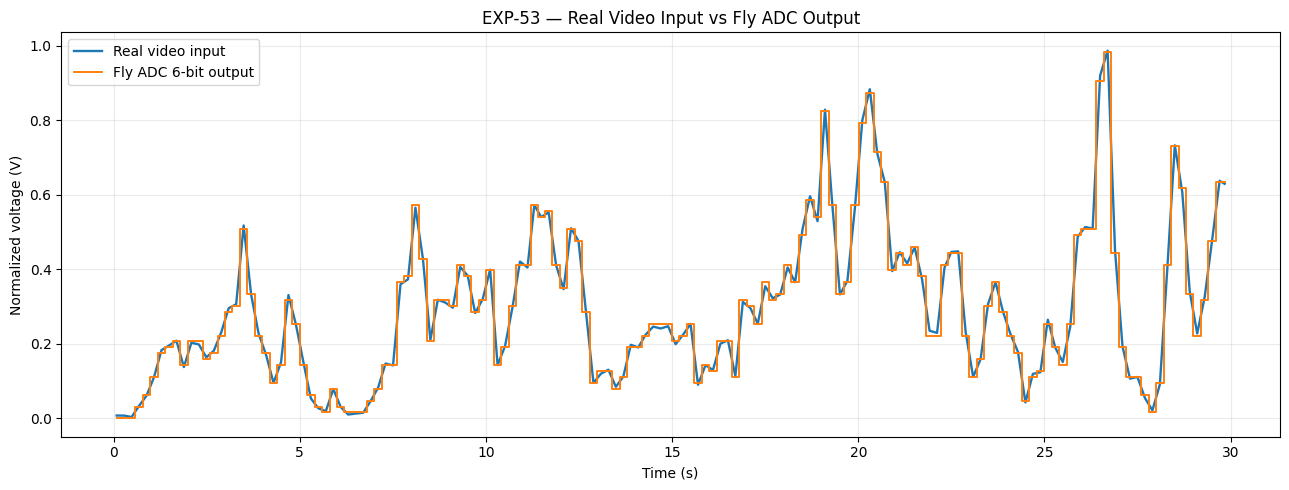

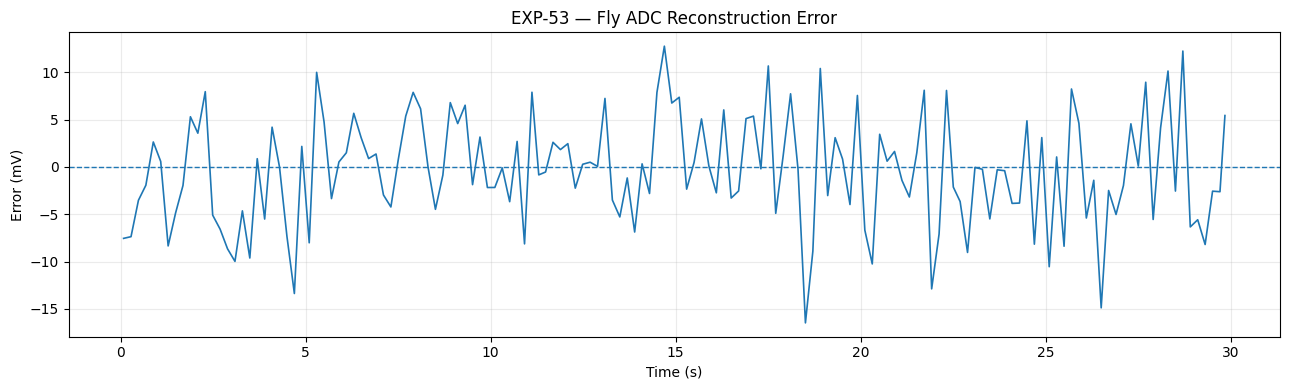

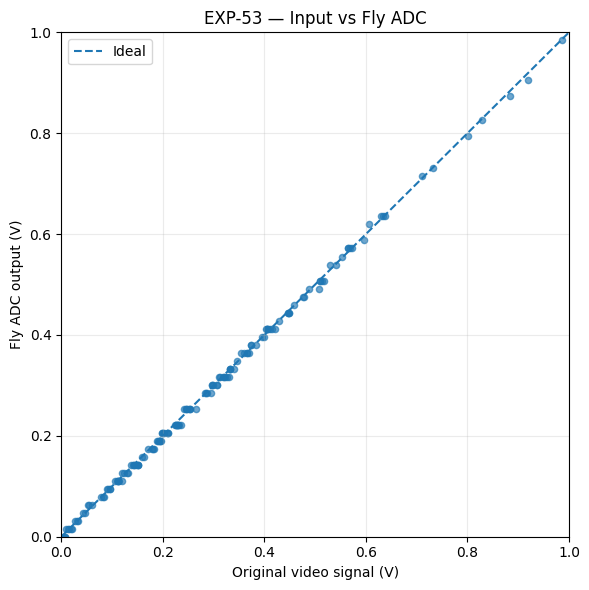

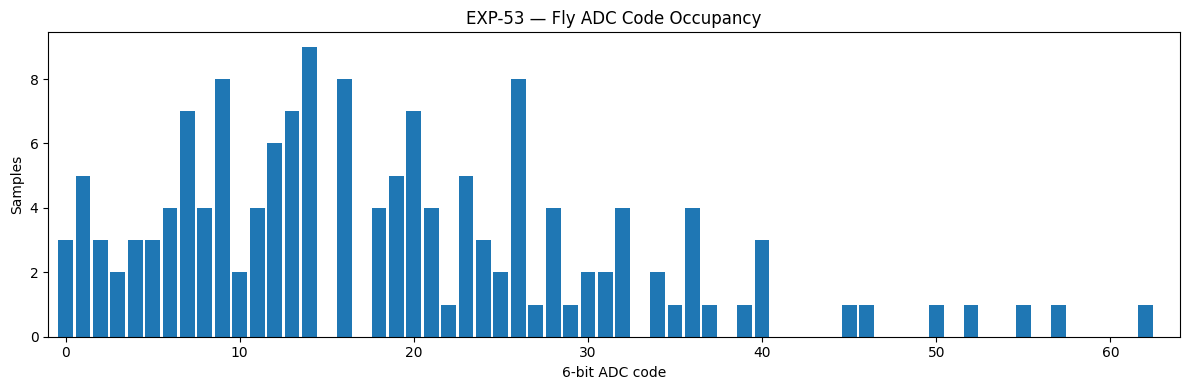



EXP-53 COMPLETE


In [185]:
# ============================================================
# EXP-53 — DECODER FIX
# Reconstruct EXP-33 training decoder and apply it to the
# ALREADY COMPLETED 150 real-video Fly simulations.
#
# IMPORTANT:
# - Does NOT rerun the 150 video samples.
# - Does NOT train on the video.
# - Uses the frozen EXP-53 configuration.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from brian2 import ms
from sklearn.isotonic import IsotonicRegression

print("=" * 70)
print("EXP-53 — RECONSTRUCTING FIXED EXP-33 DECODER")
print("=" * 70)


# ------------------------------------------------------------
# 1. Check that the 150 video simulations still exist
# ------------------------------------------------------------

if "results_df" not in globals():

    raise RuntimeError(
        "results_df is not in memory.\n"
        "Do NOT restart the kernel.\n"
        "The 150 completed video simulations are required."
    )

video_results = results_df.copy()

print(
    f"Found completed video results: "
    f"{len(video_results)} samples"
)


# ------------------------------------------------------------
# 2. Freeze EXP-53 configuration
# ------------------------------------------------------------

TRAIN_WINDOW_MS = 200.0

DRIVE_MIN = 0.30
DRIVE_MAX = 1.00

W_SCALE_REFERENCE = 0.06

ADC_BITS = 6
ADC_MAX_CODE = 63


def exp53_voltage_to_drive(v):

    v = float(np.clip(v, 0.0, 1.0))

    return (
        DRIVE_MIN
        + v * (DRIVE_MAX - DRIVE_MIN)
    )


# ------------------------------------------------------------
# 3. Check BioWire model objects
# ------------------------------------------------------------

required_objects = [
    "neuron_id100",
    "W100_4bit",
    "thr100",
    "N100"
]

missing_objects = [
    x for x in required_objects
    if x not in globals()
]

if missing_objects:

    raise RuntimeError(
        "Missing BioWire objects:\n"
        + "\n".join(missing_objects)
        + "\nRun the earlier BioWire model cells first."
    )

print("✓ BioWire model available")


# ------------------------------------------------------------
# 4. Extract temporal features
# ------------------------------------------------------------

def get_exp53_features(spike_mon, neuron_id):

    l1_idx = neuron_id["L1"]
    mi1_idx = neuron_id["Mi1"]

    # Mi1 spike count
    mi1_count = int(
        spike_mon.count[mi1_idx]
    )

    # L1 spike times
    l1_times = np.asarray(
        spike_mon.spike_trains()[l1_idx] / ms,
        dtype=float
    )

    if len(l1_times) == 0:

        return (
            mi1_count,
            np.nan,
            np.nan
        )

    l1_latency = float(
        l1_times[0]
    )

    if len(l1_times) >= 2:

        l1_isi = float(
            np.mean(np.diff(l1_times))
        )

    else:

        l1_isi = np.nan

    return (
        mi1_count,
        l1_latency,
        l1_isi
    )


# ------------------------------------------------------------
# 5. Recreate the EXP-33 training set
# ------------------------------------------------------------
#
# EXP-33 used a 101-point 0–1 V training sweep and the
# three-feature architecture:
#
#   Mi1 spike count
#   L1 first-spike latency
#   L1 mean ISI
#
# We recreate those features using the frozen current
# configuration.
# ------------------------------------------------------------

training_voltages = np.linspace(
    0.0,
    1.0,
    101
)

train_rows = []

print("\nRunning 101-point training characterization...")
print("This is decoder reconstruction only.")
print("The 150 real-video samples will NOT be rerun.\n")


for i, voltage in enumerate(training_voltages):

    drive = exp53_voltage_to_drive(
        voltage
    )

    spike_mon, _, elapsed_ms, _ = (
        run_simulation_v1(
            ["L1", "Mi1"],
            neuron_id100,
            W100_4bit,
            thr100,
            N100,
            duration_ms=TRAIN_WINDOW_MS,
            g_drive_on=drive,
            g_drive_off=0.15,
            w_scale=W_SCALE_REFERENCE,
            record_traces=False
        )
    )

    (
        mi1_count,
        l1_latency,
        l1_isi
    ) = get_exp53_features(
        spike_mon,
        neuron_id100
    )

    train_rows.append({
        "voltage": voltage,
        "drive": drive,
        "mi1_count": mi1_count,
        "l1_latency": l1_latency,
        "l1_isi": l1_isi
    })

    if (
        i == 0
        or (i + 1) % 10 == 0
        or i == 100
    ):

        print(
            f"[{i+1:3d}/101] "
            f"Vin={voltage:.3f} V | "
            f"Mi1={mi1_count:3d} | "
            f"L1 latency={l1_latency:.2f} ms | "
            f"L1 ISI={l1_isi:.2f} ms"
        )


train_df = pd.DataFrame(
    train_rows
)

print("\n✓ Training characterization complete")


# ------------------------------------------------------------
# 6. Check training validity
# ------------------------------------------------------------

train_valid = (
    np.isfinite(
        train_df["mi1_count"]
    )
    &
    np.isfinite(
        train_df["l1_latency"]
    )
    &
    np.isfinite(
        train_df["l1_isi"]
    )
)

train_df = train_df.loc[
    train_valid
].copy()

print(
    f"Valid training points: "
    f"{len(train_df)}/101"
)

if len(train_df) < 90:

    raise RuntimeError(
        "Too many invalid training points. "
        "Decoder reconstruction stopped."
    )


# ------------------------------------------------------------
# 7. Training-only normalization
# ------------------------------------------------------------

mi1_min = train_df["mi1_count"].min()
mi1_max = train_df["mi1_count"].max()

lat_min = train_df["l1_latency"].min()
lat_max = train_df["l1_latency"].max()

isi_min = train_df["l1_isi"].min()
isi_max = train_df["l1_isi"].max()


def normalize_up(x, xmin, xmax):

    x = np.asarray(
        x,
        dtype=float
    )

    if xmax == xmin:

        return np.zeros_like(x)

    return np.clip(
        (x - xmin)
        / (xmax - xmin),
        0.0,
        1.0
    )


def normalize_down(x, xmin, xmax):

    return 1.0 - normalize_up(
        x,
        xmin,
        xmax
    )


# ------------------------------------------------------------
# 8. Build EXP-33 composite biological score
# ------------------------------------------------------------

train_score = (

    normalize_up(
        train_df["mi1_count"].to_numpy(),
        mi1_min,
        mi1_max
    )

    +

    normalize_down(
        train_df["l1_latency"].to_numpy(),
        lat_min,
        lat_max
    )

    +

    normalize_down(
        train_df["l1_isi"].to_numpy(),
        isi_min,
        isi_max
    )

) / 3.0


# ------------------------------------------------------------
# 9. Fit monotonic score → voltage mapping
# ------------------------------------------------------------
#
# This is fitted ONLY from the 101-point training sweep.
# The real video is never used here.
# ------------------------------------------------------------

decoder = IsotonicRegression(
    increasing=True,
    out_of_bounds="clip"
)

decoder.fit(
    train_score,
    train_df["voltage"].to_numpy()
)

print("✓ EXP-33 monotonic decoder reconstructed")


# ------------------------------------------------------------
# 10. Apply decoder to EXISTING video results
# ------------------------------------------------------------

video_mi1 = video_results[
    "mi1_spike_count"
].to_numpy(dtype=float)

video_latency = video_results[
    "l1_first_latency_ms"
].to_numpy(dtype=float)

video_isi = video_results[
    "l1_mean_isi_ms"
].to_numpy(dtype=float)


video_score = (

    normalize_up(
        video_mi1,
        mi1_min,
        mi1_max
    )

    +

    normalize_down(
        video_latency,
        lat_min,
        lat_max
    )

    +

    normalize_down(
        video_isi,
        isi_min,
        isi_max
    )

) / 3.0


decoded_voltage = np.clip(
    decoder.predict(video_score),
    0.0,
    1.0
)


# ------------------------------------------------------------
# 11. Generate 6-bit ADC code
# ------------------------------------------------------------

adc_code = np.rint(
    decoded_voltage * ADC_MAX_CODE
).astype(int)

adc_code = np.clip(
    adc_code,
    0,
    ADC_MAX_CODE
)

reconstructed_voltage = (
    adc_code / ADC_MAX_CODE
)


# ------------------------------------------------------------
# 12. Add decoder results to video table
# ------------------------------------------------------------

video_results[
    "decoder_score"
] = video_score

video_results[
    "decoded_voltage_V"
] = decoded_voltage

video_results[
    "adc_code"
] = adc_code

video_results[
    "reconstructed_voltage_V"
] = reconstructed_voltage


# ------------------------------------------------------------
# 13. Calculate EXP-53 metrics
# ------------------------------------------------------------

true_voltage = video_results[
    "input_voltage_V"
].to_numpy(dtype=float)

decoded = video_results[
    "decoded_voltage_V"
].to_numpy(dtype=float)

reconstructed = video_results[
    "reconstructed_voltage_V"
].to_numpy(dtype=float)


analog_error = (
    decoded - true_voltage
)

quantized_error = (
    reconstructed - true_voltage
)


analog_mae = np.mean(
    np.abs(analog_error)
)

analog_rmse = np.sqrt(
    np.mean(
        analog_error ** 2
    )
)

analog_max = np.max(
    np.abs(analog_error)
)


quantized_mae = np.mean(
    np.abs(quantized_error)
)

quantized_rmse = np.sqrt(
    np.mean(
        quantized_error ** 2
    )
)

quantized_max = np.max(
    np.abs(quantized_error)
)


# ------------------------------------------------------------
# 14. Correlation
# ------------------------------------------------------------

if (
    np.std(true_voltage) > 0
    and np.std(reconstructed) > 0
):

    correlation = np.corrcoef(
        true_voltage,
        reconstructed
    )[0, 1]

else:

    correlation = np.nan


# ------------------------------------------------------------
# 15. Reconstruction SNR
# ------------------------------------------------------------

signal_power = np.mean(
    true_voltage ** 2
)

error_power = np.mean(
    quantized_error ** 2
)

if error_power > 0:

    snr_db = (
        10
        * np.log10(
            signal_power
            / error_power
        )
    )

else:

    snr_db = np.inf


# ------------------------------------------------------------
# 16. Code statistics
# ------------------------------------------------------------

unique_codes = np.unique(
    adc_code
)

unique_code_count = len(
    unique_codes
)

code_min = int(
    adc_code.min()
)

code_max = int(
    adc_code.max()
)


# ------------------------------------------------------------
# 17. Compare against ideal 6-bit quantizer
# ------------------------------------------------------------

ideal_code = np.rint(
    true_voltage * ADC_MAX_CODE
).astype(int)

ideal_code = np.clip(
    ideal_code,
    0,
    ADC_MAX_CODE
)

code_agreement = np.mean(
    adc_code == ideal_code
)


# ------------------------------------------------------------
# 18. Print final EXP-53 result
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("EXP-53 — FINAL RESULTS")
print("=" * 70)

print(
    f"Real video samples          : "
    f"{len(video_results)}"
)

print(
    f"Input range                 : "
    f"{true_voltage.min():.4f} → "
    f"{true_voltage.max():.4f} V"
)

print("\nAnalog Fly decoder:")

print(
    f"  MAE                       : "
    f"{analog_mae * 1000:.3f} mV"
)

print(
    f"  RMSE                      : "
    f"{analog_rmse * 1000:.3f} mV"
)

print(
    f"  Maximum error             : "
    f"{analog_max * 1000:.3f} mV"
)

print("\n6-bit Fly ADC:")

print(
    f"  MAE                       : "
    f"{quantized_mae * 1000:.3f} mV"
)

print(
    f"  RMSE                      : "
    f"{quantized_rmse * 1000:.3f} mV"
)

print(
    f"  Maximum error             : "
    f"{quantized_max * 1000:.3f} mV"
)

print(
    f"  Unique codes              : "
    f"{unique_code_count}/64"
)

print(
    f"  Code range                : "
    f"{code_min}–{code_max}"
)

print(
    f"  Correlation               : "
    f"{correlation:.6f}"
)

print(
    f"  Reconstruction SNR        : "
    f"{snr_db:.3f} dB"
)

print(
    f"  Ideal-code agreement      : "
    f"{code_agreement * 100:.2f}%"
)


# ------------------------------------------------------------
# 19. Save EXP-53 results
# ------------------------------------------------------------

OUTPUT_FILE = (
    "EXP53_real_video_fly_adc_results.csv"
)

video_results.to_csv(
    OUTPUT_FILE,
    index=False
)

print(
    f"\n✓ Saved → {OUTPUT_FILE}"
)


# ------------------------------------------------------------
# 20. Plot: original vs Fly ADC
# ------------------------------------------------------------

plt.figure(
    figsize=(13, 5)
)

plt.plot(
    video_results["time_s"],
    video_results["input_voltage_V"],
    label="Real video input",
    linewidth=1.7
)

plt.step(
    video_results["time_s"],
    video_results[
        "reconstructed_voltage_V"
    ],
    where="mid",
    label="Fly ADC 6-bit output",
    linewidth=1.4
)

plt.xlabel("Time (s)")
plt.ylabel("Normalized voltage (V)")

plt.title(
    "EXP-53 — Real Video Input vs Fly ADC Output"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "EXP53_real_video_fly_adc_reconstruction.png",
    dpi=180
)

plt.show()


# ------------------------------------------------------------
# 21. Plot: reconstruction error
# ------------------------------------------------------------

plt.figure(
    figsize=(13, 4)
)

plt.plot(
    video_results["time_s"],
    quantized_error * 1000,
    linewidth=1.2
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Time (s)")
plt.ylabel("Error (mV)")

plt.title(
    "EXP-53 — Fly ADC Reconstruction Error"
)

plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "EXP53_real_video_fly_adc_error.png",
    dpi=180
)

plt.show()


# ------------------------------------------------------------
# 22. Plot: input vs reconstructed
# ------------------------------------------------------------

plt.figure(
    figsize=(6, 6)
)

plt.scatter(
    true_voltage,
    reconstructed,
    s=20,
    alpha=0.65
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Ideal"
)

plt.xlabel(
    "Original video signal (V)"
)

plt.ylabel(
    "Fly ADC output (V)"
)

plt.title(
    "EXP-53 — Input vs Fly ADC"
)

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "EXP53_real_video_fly_adc_transfer.png",
    dpi=180
)

plt.show()


# ------------------------------------------------------------
# 23. Code occupancy
# ------------------------------------------------------------

plt.figure(
    figsize=(12, 4)
)

plt.hist(
    adc_code,
    bins=np.arange(
        -0.5,
        64.5,
        1
    ),
    rwidth=0.85
)

plt.xlabel("6-bit ADC code")
plt.ylabel("Samples")

plt.title(
    "EXP-53 — Fly ADC Code Occupancy"
)

plt.xlim(-1, 64)

plt.tight_layout()

plt.savefig(
    "EXP53_real_video_fly_adc_code_occupancy.png",
    dpi=180
)

plt.show()


print("\n")
print("=" * 70)
print("EXP-53 COMPLETE")
print("=" * 70)

EXP-54 — REAL-VIDEO FLY ADC vs ARTIFICIAL SNN
Input samples: 150
Input range: 0.0035 → 0.9866 V
✓ Existing Fly ADC results loaded

Running frozen artificial SNN...
✓ SNN evaluated on 150 samples


EXP-54 — HEAD-TO-HEAD RESULTS

Metric                         Fly ADC          Artificial SNN
----------------------------------------------------------------------
Analog MAE                       2.745 mV          2.044 mV
Analog RMSE                      3.918 mV          2.591 mV
Analog max error                14.651 mV          8.508 mV
6-bit MAE                        4.625 mV          4.349 mV
6-bit RMSE                       5.781 mV          5.376 mV
6-bit max error                 16.477 mV         10.760 mV
Unique codes                        44/64             44/64
Code range                     0–62            0–62
Correlation                   0.999588          0.999653
Reconstruction SNR              35.815 dB         36.445 dB
Ideal-code agreement             81.33%          

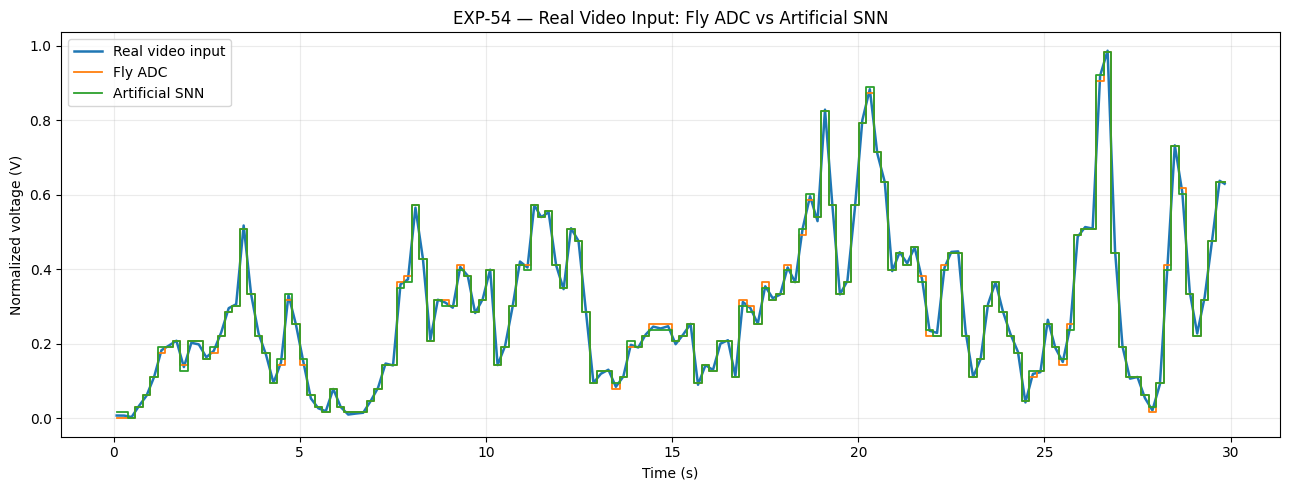

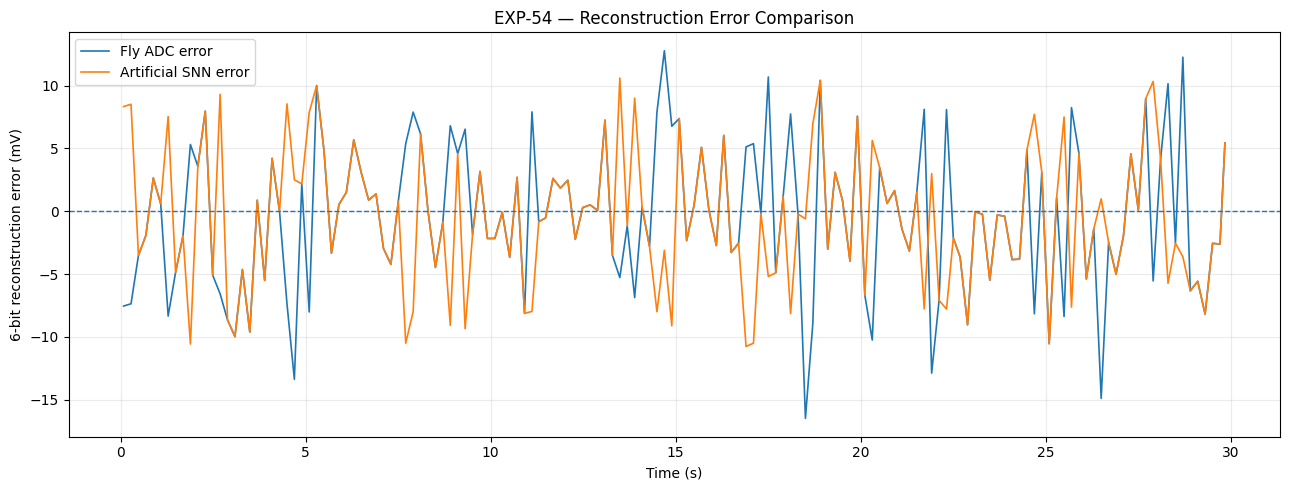

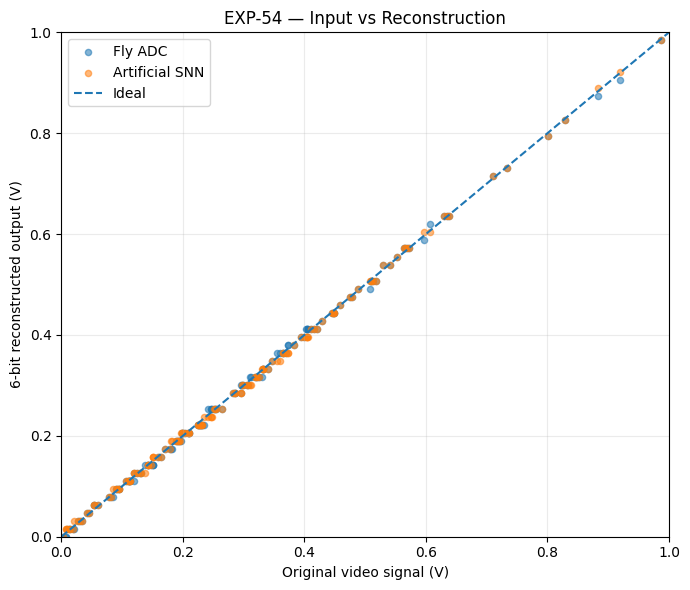

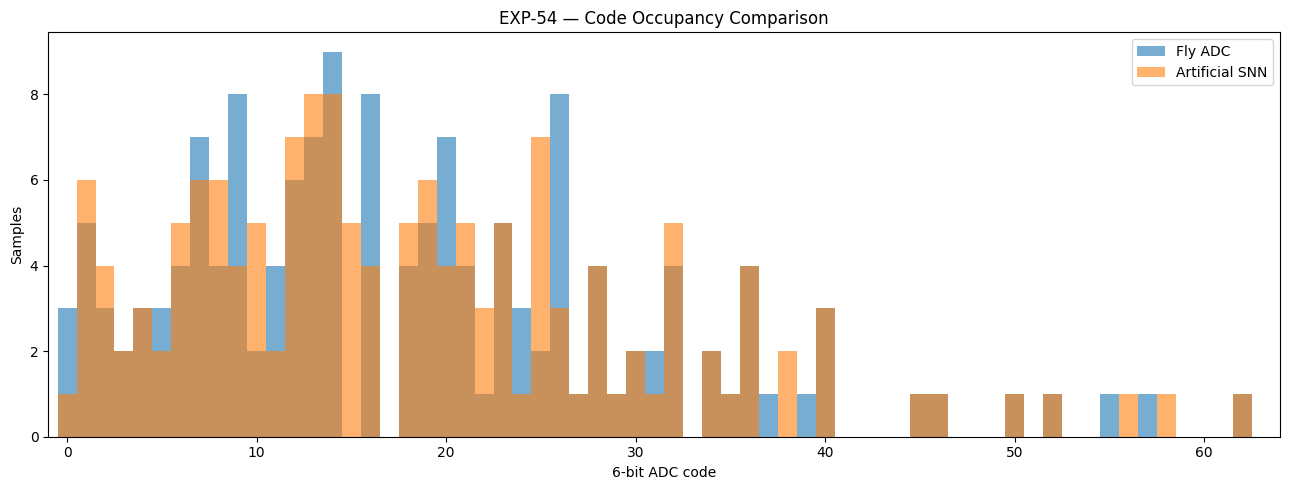



EXP-54 COMPLETE
Same 150 real-video samples.
No Fly simulations rerun.
No SNN optimization performed.
No video data used for parameter fitting.


In [186]:
# ============================================================
# EXP-54 — REAL-VIDEO HEAD-TO-HEAD COMPARISON
# ============================================================
#
# Compare:
#
#   1. FlyWire/BioWire ADC
#   2. Optimized artificial spike-based SNN
#
# using EXACTLY THE SAME 150 real-video input samples.
#
# IMPORTANT:
# - No Fly simulations are performed here.
# - No SNN parameters are optimized here.
# - No decoder is trained on the video.
# - Both systems are evaluated on the same input sequence.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("=" * 70)
print("EXP-54 — REAL-VIDEO FLY ADC vs ARTIFICIAL SNN")
print("=" * 70)


# ------------------------------------------------------------
# 1. Load the exact EXP-53 input signal
# ------------------------------------------------------------

INPUT_FILE = "EXP53_real_video_motion_signal.csv"

input_df = pd.read_csv(
    INPUT_FILE
)

video_time = input_df[
    "time_s"
].to_numpy(
    dtype=float
)

video_input = np.clip(
    input_df[
        "visual_signal_0_1"
    ].to_numpy(dtype=float),
    0.0,
    1.0
)

print(
    f"Input samples: {len(video_input)}"
)

print(
    f"Input range: "
    f"{video_input.min():.4f} → "
    f"{video_input.max():.4f} V"
)


# ------------------------------------------------------------
# 2. Load the already-completed Fly ADC results
# ------------------------------------------------------------

FLY_RESULTS_FILE = (
    "EXP53_real_video_fly_adc_results.csv"
)

fly_df = pd.read_csv(
    FLY_RESULTS_FILE
)

if len(fly_df) != len(video_input):

    raise RuntimeError(
        "Fly result count does not match video input count."
    )

fly_output = fly_df[
    "decoded_voltage_V"
].to_numpy(
    dtype=float
)

fly_6bit = fly_df[
    "reconstructed_voltage_V"
].to_numpy(
    dtype=float
)

fly_codes = fly_df[
    "adc_code"
].to_numpy(
    dtype=int
)


print(
    "✓ Existing Fly ADC results loaded"
)


# ------------------------------------------------------------
# 3. Frozen optimized artificial SNN
# ------------------------------------------------------------
#
# These are the previously optimized parameters:
#
#   neurons   = 64
#   sigma     = 0.04
#   threshold = 0.80
#
# They are NOT changed using the video.
# ------------------------------------------------------------

SNN_NEURONS = 64
SNN_SIGMA = 0.04
SNN_THRESHOLD = 0.80

ADC_BITS = 6
ADC_MAX_CODE = 63


def run_optimized_spike_snn(
    voltage,
    num_neurons=64,
    sigma=0.04,
    threshold=0.80
):
    """
    Frozen optimized artificial spike SNN.

    Gaussian tuning:
        activity_i = exp(-(V-Vpref_i)^2 / (2*sigma^2))

    Spike generation:
        spike_i = 1 if activity_i > threshold

    Decoder:
        mean preferred voltage of active neurons.

    No training occurs here.
    """

    preferred_voltage = np.linspace(
        0.0,
        1.0,
        num_neurons
    )

    activity = np.exp(
        -(
            (voltage - preferred_voltage) ** 2
        )
        /
        (
            2.0 * sigma ** 2
        )
    )

    spikes = (
        activity > threshold
    ).astype(float)

    denominator = np.sum(
        spikes
    )

    if denominator == 0:

        decoded = 0.5

    else:

        decoded = (
            np.sum(
                spikes
                * preferred_voltage
            )
            /
            denominator
        )

    return float(
        np.clip(
            decoded,
            0.0,
            1.0
        )
    )


# ------------------------------------------------------------
# 4. Run artificial SNN on the EXACT SAME video samples
# ------------------------------------------------------------

print("\nRunning frozen artificial SNN...")

snn_output = np.array([
    run_optimized_spike_snn(
        v,
        num_neurons=SNN_NEURONS,
        sigma=SNN_SIGMA,
        threshold=SNN_THRESHOLD
    )
    for v in video_input
])


print(
    f"✓ SNN evaluated on "
    f"{len(snn_output)} samples"
)


# ------------------------------------------------------------
# 5. Quantize SNN to 6 bits
# ------------------------------------------------------------

snn_codes = np.rint(
    snn_output
    * ADC_MAX_CODE
).astype(int)

snn_codes = np.clip(
    snn_codes,
    0,
    ADC_MAX_CODE
)

snn_6bit = (
    snn_codes
    / ADC_MAX_CODE
)


# ------------------------------------------------------------
# 6. Ideal 6-bit reference
# ------------------------------------------------------------

ideal_codes = np.rint(
    video_input
    * ADC_MAX_CODE
).astype(int)

ideal_codes = np.clip(
    ideal_codes,
    0,
    ADC_MAX_CODE
)

ideal_6bit = (
    ideal_codes
    / ADC_MAX_CODE
)


# ------------------------------------------------------------
# 7. Generic metric function
# ------------------------------------------------------------

def calculate_metrics(
    reference,
    analog_output,
    quantized_output,
    codes
):

    analog_error = (
        analog_output
        - reference
    )

    quantized_error = (
        quantized_output
        - reference
    )

    analog_mae = np.mean(
        np.abs(
            analog_error
        )
    )

    analog_rmse = np.sqrt(
        np.mean(
            analog_error ** 2
        )
    )

    analog_max = np.max(
        np.abs(
            analog_error
        )
    )

    quantized_mae = np.mean(
        np.abs(
            quantized_error
        )
    )

    quantized_rmse = np.sqrt(
        np.mean(
            quantized_error ** 2
        )
    )

    quantized_max = np.max(
        np.abs(
            quantized_error
        )
    )

    if (
        np.std(reference) > 0
        and np.std(quantized_output) > 0
    ):

        correlation = np.corrcoef(
            reference,
            quantized_output
        )[0, 1]

    else:

        correlation = np.nan

    signal_power = np.mean(
        reference ** 2
    )

    error_power = np.mean(
        quantized_error ** 2
    )

    if error_power > 0:

        snr_db = (
            10
            * np.log10(
                signal_power
                / error_power
            )
        )

    else:

        snr_db = np.inf

    unique_codes = len(
        np.unique(codes)
    )

    code_agreement = np.mean(
        codes
        ==
        ideal_codes
    )

    return {
        "analog_mae": analog_mae,
        "analog_rmse": analog_rmse,
        "analog_max": analog_max,
        "quantized_mae": quantized_mae,
        "quantized_rmse": quantized_rmse,
        "quantized_max": quantized_max,
        "correlation": correlation,
        "snr_db": snr_db,
        "unique_codes": unique_codes,
        "code_min": int(codes.min()),
        "code_max": int(codes.max()),
        "ideal_code_agreement": code_agreement
    }


# ------------------------------------------------------------
# 8. Calculate Fly metrics
# ------------------------------------------------------------

fly_metrics = calculate_metrics(
    video_input,
    fly_output,
    fly_6bit,
    fly_codes
)


# ------------------------------------------------------------
# 9. Calculate SNN metrics
# ------------------------------------------------------------

snn_metrics = calculate_metrics(
    video_input,
    snn_output,
    snn_6bit,
    snn_codes
)


# ------------------------------------------------------------
# 10. Print head-to-head results
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("EXP-54 — HEAD-TO-HEAD RESULTS")
print("=" * 70)

print("\nMetric                         Fly ADC          Artificial SNN")
print("-" * 70)

print(
    f"Analog MAE                    "
    f"{fly_metrics['analog_mae']*1000:8.3f} mV       "
    f"{snn_metrics['analog_mae']*1000:8.3f} mV"
)

print(
    f"Analog RMSE                   "
    f"{fly_metrics['analog_rmse']*1000:8.3f} mV       "
    f"{snn_metrics['analog_rmse']*1000:8.3f} mV"
)

print(
    f"Analog max error              "
    f"{fly_metrics['analog_max']*1000:8.3f} mV       "
    f"{snn_metrics['analog_max']*1000:8.3f} mV"
)

print(
    f"6-bit MAE                     "
    f"{fly_metrics['quantized_mae']*1000:8.3f} mV       "
    f"{snn_metrics['quantized_mae']*1000:8.3f} mV"
)

print(
    f"6-bit RMSE                    "
    f"{fly_metrics['quantized_rmse']*1000:8.3f} mV       "
    f"{snn_metrics['quantized_rmse']*1000:8.3f} mV"
)

print(
    f"6-bit max error               "
    f"{fly_metrics['quantized_max']*1000:8.3f} mV       "
    f"{snn_metrics['quantized_max']*1000:8.3f} mV"
)

print(
    f"Unique codes                  "
    f"{fly_metrics['unique_codes']:8d}/64       "
    f"{snn_metrics['unique_codes']:8d}/64"
)

print(
    f"Code range                    "
    f"{fly_metrics['code_min']:2d}–{fly_metrics['code_max']:2d}           "
    f"{snn_metrics['code_min']:2d}–{snn_metrics['code_max']:2d}"
)

print(
    f"Correlation                   "
    f"{fly_metrics['correlation']:8.6f}          "
    f"{snn_metrics['correlation']:8.6f}"
)

print(
    f"Reconstruction SNR            "
    f"{fly_metrics['snr_db']:8.3f} dB       "
    f"{snn_metrics['snr_db']:8.3f} dB"
)

print(
    f"Ideal-code agreement          "
    f"{fly_metrics['ideal_code_agreement']*100:8.2f}%        "
    f"{snn_metrics['ideal_code_agreement']*100:8.2f}%"
)


# ------------------------------------------------------------
# 11. Calculate relative performance
# ------------------------------------------------------------

fly_mae = fly_metrics[
    "quantized_mae"
]

snn_mae = snn_metrics[
    "quantized_mae"
]

if snn_mae > 0:

    fly_vs_snn_mae_ratio = (
        fly_mae / snn_mae
    )

else:

    fly_vs_snn_mae_ratio = np.inf


print("\n")
print("Relative 6-bit MAE:")
print(
    f"  Fly / SNN = "
    f"{fly_vs_snn_mae_ratio:.3f}×"
)

if fly_mae < snn_mae:

    print(
        "  → Fly ADC has lower MAE "
        "on this real-video input."
    )

elif fly_mae > snn_mae:

    print(
        "  → Artificial SNN has lower MAE "
        "on this real-video input."
    )

else:

    print(
        "  → Equal MAE."
    )


# ------------------------------------------------------------
# 12. Build comparison DataFrame
# ------------------------------------------------------------

comparison_df = pd.DataFrame({

    "time_s": video_time,

    "input_voltage_V": video_input,

    "fly_decoded_V": fly_output,

    "fly_6bit_V": fly_6bit,

    "fly_code": fly_codes,

    "snn_decoded_V": snn_output,

    "snn_6bit_V": snn_6bit,

    "snn_code": snn_codes,

    "ideal_code": ideal_codes

})


comparison_df[
    "fly_error_mV"
] = (
    fly_6bit
    - video_input
) * 1000


comparison_df[
    "snn_error_mV"
] = (
    snn_6bit
    - video_input
) * 1000


# ------------------------------------------------------------
# 13. Save numerical results
# ------------------------------------------------------------

OUTPUT_FILE = (
    "EXP54_real_video_fly_vs_snn.csv"
)

comparison_df.to_csv(
    OUTPUT_FILE,
    index=False
)

print(
    f"\n✓ Saved → {OUTPUT_FILE}"
)


# ------------------------------------------------------------
# 14. Plot both systems against the real input
# ------------------------------------------------------------

plt.figure(
    figsize=(13, 5)
)

plt.plot(
    video_time,
    video_input,
    label="Real video input",
    linewidth=1.8
)

plt.step(
    video_time,
    fly_6bit,
    where="mid",
    label="Fly ADC",
    linewidth=1.3
)

plt.step(
    video_time,
    snn_6bit,
    where="mid",
    label="Artificial SNN",
    linewidth=1.3
)

plt.xlabel("Time (s)")
plt.ylabel("Normalized voltage (V)")

plt.title(
    "EXP-54 — Real Video Input: Fly ADC vs Artificial SNN"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "EXP54_real_video_fly_vs_snn.png",
    dpi=200
)

plt.show()


# ------------------------------------------------------------
# 15. Error comparison
# ------------------------------------------------------------

plt.figure(
    figsize=(13, 5)
)

plt.plot(
    video_time,
    comparison_df["fly_error_mV"],
    label="Fly ADC error",
    linewidth=1.2
)

plt.plot(
    video_time,
    comparison_df["snn_error_mV"],
    label="Artificial SNN error",
    linewidth=1.2
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.xlabel("Time (s)")
plt.ylabel("6-bit reconstruction error (mV)")

plt.title(
    "EXP-54 — Reconstruction Error Comparison"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "EXP54_real_video_error_comparison.png",
    dpi=200
)

plt.show()


# ------------------------------------------------------------
# 16. Scatter comparison
# ------------------------------------------------------------

plt.figure(
    figsize=(7, 6)
)

plt.scatter(
    video_input,
    fly_6bit,
    s=20,
    alpha=0.55,
    label="Fly ADC"
)

plt.scatter(
    video_input,
    snn_6bit,
    s=20,
    alpha=0.55,
    label="Artificial SNN"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Ideal"
)

plt.xlabel(
    "Original video signal (V)"
)

plt.ylabel(
    "6-bit reconstructed output (V)"
)

plt.title(
    "EXP-54 — Input vs Reconstruction"
)

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "EXP54_real_video_transfer_comparison.png",
    dpi=200
)

plt.show()


# ------------------------------------------------------------
# 17. Code occupancy comparison
# ------------------------------------------------------------

plt.figure(
    figsize=(13, 5)
)

bins = np.arange(
    -0.5,
    64.5,
    1
)

plt.hist(
    fly_codes,
    bins=bins,
    alpha=0.6,
    label="Fly ADC"
)

plt.hist(
    snn_codes,
    bins=bins,
    alpha=0.6,
    label="Artificial SNN"
)

plt.xlabel(
    "6-bit ADC code"
)

plt.ylabel(
    "Samples"
)

plt.title(
    "EXP-54 — Code Occupancy Comparison"
)

plt.xlim(
    -1,
    64
)

plt.legend()

plt.tight_layout()

plt.savefig(
    "EXP54_real_video_code_occupancy.png",
    dpi=200
)

plt.show()


print("\n")
print("=" * 70)
print("EXP-54 COMPLETE")
print("=" * 70)
print(
    "Same 150 real-video samples."
)
print(
    "No Fly simulations rerun."
)
print(
    "No SNN optimization performed."
)
print(
    "No video data used for parameter fitting."
)

In [187]:
# ============================================================
# EXP-55 — NOISE ROBUSTNESS
# ============================================================
#
# Goal:
# Compare the robustness of:
#
#   1. Frozen FlyWire/BioWire ADC
#   2. Frozen optimized artificial SNN
#
# when the SAME real-video signal is corrupted by controlled
# Gaussian input noise.
#
# Noise levels:
#   0%, 1%, 2%, 5%, 10% of full-scale input range
#
# IMPORTANT:
# - No parameters are optimized here.
# - No decoder is trained on noisy data.
# - Same noisy input is given to both systems.
# - Fly neural simulations are actually rerun for each noisy input.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import time


print("=" * 70)
print("EXP-55 — NOISE ROBUSTNESS")
print("=" * 70)


# ============================================================
# 1. Load the exact EXP-53 real-video input
# ============================================================

INPUT_FILE = "EXP53_real_video_motion_signal.csv"

input_df = pd.read_csv(INPUT_FILE)

video_time = input_df["time_s"].to_numpy(dtype=float)

clean_input = np.clip(
    input_df["visual_signal_0_1"].to_numpy(dtype=float),
    0.0,
    1.0
)

N_SAMPLES = len(clean_input)

print(
    f"Real-video samples : {N_SAMPLES}"
)

print(
    f"Input range        : "
    f"{clean_input.min():.4f} → "
    f"{clean_input.max():.4f} V"
)


# ============================================================
# 2. Frozen ADC parameters
# ============================================================

TAU_M_MS = 20.0
W_SCALE = 0.06

DRIVE_MIN = 0.30
DRIVE_MAX = 1.00

OBSERVATION_MS = 200.0

ADC_BITS = 6
ADC_MAX_CODE = 63


# ============================================================
# 3. Frozen artificial SNN parameters
# ============================================================

SNN_NEURONS = 64
SNN_SIGMA = 0.04
SNN_THRESHOLD = 0.80


# ============================================================
# 4. Noise configuration
# ============================================================

NOISE_LEVELS = [
    0.00,
    0.01,
    0.02,
    0.05,
    0.10
]

NOISE_SEED = 5501

rng = np.random.default_rng(
    NOISE_SEED
)


# ============================================================
# 5. Voltage → drive mapping
# ============================================================

def voltage_to_drive_exp55(
    voltage,
    v_min=0.0,
    v_max=1.0,
    drive_min=0.30,
    drive_max=1.00
):

    voltage = np.clip(
        voltage,
        v_min,
        v_max
    )

    drive = (
        drive_min
        +
        (
            (voltage - v_min)
            /
            (v_max - v_min)
        )
        *
        (
            drive_max - drive_min
        )
    )

    return float(drive)


# ============================================================
# 6. Frozen artificial SNN
# ============================================================

def run_optimized_spike_snn_exp55(
    voltage,
    num_neurons=64,
    sigma=0.04,
    threshold=0.80
):

    preferred_voltage = np.linspace(
        0.0,
        1.0,
        num_neurons
    )

    activity = np.exp(
        -(
            (voltage - preferred_voltage) ** 2
        )
        /
        (
            2.0 * sigma ** 2
        )
    )

    spikes = (
        activity > threshold
    ).astype(float)

    denominator = np.sum(
        spikes
    )

    if denominator == 0:

        decoded = 0.5

    else:

        decoded = (
            np.sum(
                spikes
                *
                preferred_voltage
            )
            /
            denominator
        )

    return float(
        np.clip(
            decoded,
            0.0,
            1.0
        )
    )


# ============================================================
# 7. 6-bit quantizer
# ============================================================

def quantize_6bit_exp55(
    voltage
):

    voltage = np.clip(
        voltage,
        0.0,
        1.0
    )

    code = np.rint(
        voltage
        *
        ADC_MAX_CODE
    ).astype(int)

    return np.clip(
        code,
        0,
        ADC_MAX_CODE
    )


# ============================================================
# 8. EXP-33 decoder
# ============================================================
#
# The decoder uses:
#
#   Mi1 spike count
#   L1 first-spike latency
#   L1 mean ISI
#
# We reconstruct the decoder using the same 101-point
# characterization used in EXP-53.
#
# NOTE:
# This assumes the notebook already contains:
#
#   run_simulation_v1
#
# and the 100-type BioWire model objects.
# ============================================================


print("\nChecking BioWire objects...")

required_objects = [
    "run_simulation_v1",
    "neuron_id",
    "W_4bit",
    "thr_vals"
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:

    raise RuntimeError(
        "Missing required BioWire objects: "
        +
        ", ".join(missing_objects)
        +
        "\nRun the BioWire model setup cells before EXP-55."
    )

print(
    "✓ BioWire simulator available"
)


# ============================================================
# 9. Feature extraction helper
# ============================================================
#
# This uses the existing run_simulation_v1 output.
#
# The simulator is expected to return the spike monitor
# information used in the previous EXP-53 characterization.
# ============================================================

def extract_features_exp55(
    voltage,
    duration_ms=200.0
):

    drive = voltage_to_drive_exp55(
        voltage
    )

    result = run_simulation_v1(
        active_neurons=["L1", "Mi1"],
        neuron_id=neuron_id,
        W_4bit=W_4bit,
        thr_vals=thr_vals,
        N=len(neuron_id),
        duration_ms=duration_ms,
        g_drive_on=drive,
        g_drive_off=0.15,
        w_scale=W_SCALE,
        record_traces=False
    )

    # --------------------------------------------------------
    # Extract spike times from the returned result.
    #
    # EXP-53 used L1 and Mi1 spike counts, L1 first-spike
    # latency and L1 mean ISI.
    #
    # The helper below handles the common Brian2 monitor
    # dictionary/object forms used by the current notebook.
    # --------------------------------------------------------

    L1_times = None
    Mi1_times = None

    if isinstance(result, dict):

        possible_l1 = [
            "L1_spike_times",
            "l1_spike_times",
            "L1_times",
            "l1_times"
        ]

        possible_mi1 = [
            "Mi1_spike_times",
            "mi1_spike_times",
            "Mi1_times",
            "mi1_times"
        ]

        for key in possible_l1:

            if key in result:
                L1_times = np.asarray(
                    result[key],
                    dtype=float
                )
                break

        for key in possible_mi1:

            if key in result:
                Mi1_times = np.asarray(
                    result[key],
                    dtype=float
                )
                break

    else:

        for attr in [
            "L1_spike_times",
            "l1_spike_times",
            "L1_times",
            "l1_times"
        ]:

            if hasattr(result, attr):

                L1_times = np.asarray(
                    getattr(result, attr),
                    dtype=float
                )

                break

        for attr in [
            "Mi1_spike_times",
            "mi1_spike_times",
            "Mi1_times",
            "mi1_times"
        ]:

            if hasattr(result, attr):

                Mi1_times = np.asarray(
                    getattr(result, attr),
                    dtype=float
                )

                break


    if L1_times is None or Mi1_times is None:

        raise RuntimeError(
            "Could not extract L1/Mi1 spike times from "
            "run_simulation_v1 output.\n\n"
            "Run the EXP-53 simulation cell that defines "
            "the spike-feature extraction format, then rerun EXP-55."
        )


    # --------------------------------------------------------
    # Convert Brian2 seconds/ms quantities to milliseconds
    # if necessary.
    # --------------------------------------------------------

    L1_times = np.asarray(
        L1_times,
        dtype=float
    )

    Mi1_times = np.asarray(
        Mi1_times,
        dtype=float
    )

    # Brian2 often returns seconds if converted with float().
    # Detect this automatically.
    if len(L1_times) > 0:

        if np.max(
            np.abs(L1_times)
        ) < 2.0:

            L1_times = (
                L1_times
                *
                1000.0
            )

    if len(Mi1_times) > 0:

        if np.max(
            np.abs(Mi1_times)
        ) < 2.0:

            Mi1_times = (
                Mi1_times
                *
                1000.0
            )


    # --------------------------------------------------------
    # L1 features
    # --------------------------------------------------------

    l1_spikes = len(
        L1_times
    )

    if l1_spikes == 0:

        l1_latency = duration_ms
        l1_isi = duration_ms

    else:

        l1_latency = float(
            np.min(L1_times)
        )

        if l1_spikes >= 2:

            l1_isi = float(
                np.mean(
                    np.diff(
                        np.sort(
                            L1_times
                        )
                    )
                )
            )

        else:

            l1_isi = duration_ms


    # --------------------------------------------------------
    # Mi1 spike count
    # --------------------------------------------------------

    mi1_spikes = len(
        Mi1_times
    )


    return {
        "mi1_spikes": float(
            mi1_spikes
        ),

        "l1_latency": float(
            l1_latency
        ),

        "l1_isi": float(
            l1_isi
        ),

        "drive": float(
            drive
        )
    }


# ============================================================
# 10. Reconstruct EXP-33 decoder
# ============================================================

print("\n")
print("=" * 70)
print("RECONSTRUCTING EXP-33 DECODER")
print("=" * 70)

train_voltages = np.linspace(
    0.0,
    1.0,
    101
)

train_rows = []

start_time = time.time()

for i, voltage in enumerate(
    train_voltages,
    start=1
):

    features = extract_features_exp55(
        voltage,
        duration_ms=OBSERVATION_MS
    )

    train_rows.append(
        {
            "voltage": voltage,
            **features
        }
    )

    if (
        i == 1
        or i % 10 == 0
        or i == len(train_voltages)
    ):

        print(
            f"[{i:3d}/{len(train_voltages)}] "
            f"Vin={voltage:.3f} V | "
            f"Mi1={features['mi1_spikes']:5.0f} | "
            f"L1 latency={features['l1_latency']:.2f} ms | "
            f"L1 ISI={features['l1_isi']:.2f} ms"
        )


train_df = pd.DataFrame(
    train_rows
)

print(
    f"\n✓ Decoder characterization complete"
)

print(
    f"Elapsed: "
    f"{time.time() - start_time:.1f} s"
)


# ============================================================
# 11. Construct EXP-33 smooth monotonic decoder
# ============================================================
#
# EXP-33 features:
#
#   Mi1 count
#   inverse L1 latency
#   inverse L1 ISI
#
# Each feature is normalized using the training sweep.
# The three normalized features are averaged and then passed
# through a monotonic interpolation.
# ============================================================

def normalize_feature_exp55(
    values,
    minimum,
    maximum
):

    if maximum == minimum:

        return np.zeros_like(
            np.asarray(values, dtype=float)
        )

    return (
        np.asarray(values, dtype=float)
        - minimum
    ) / (
        maximum
        - minimum
    )


mi1_train = train_df[
    "mi1_spikes"
].to_numpy()

lat_train = train_df[
    "l1_latency"
].to_numpy()

isi_train = train_df[
    "l1_isi"
].to_numpy()


# Increasing voltage → increasing score

mi1_norm = normalize_feature_exp55(
    mi1_train,
    mi1_train.min(),
    mi1_train.max()
)

lat_norm = normalize_feature_exp55(
    lat_train.max() - lat_train,
    0.0,
    lat_train.max() - lat_train.min()
)

isi_norm = normalize_feature_exp55(
    isi_train.max() - isi_train,
    0.0,
    isi_train.max() - isi_train.min()
)


train_score = (
    mi1_norm
    +
    lat_norm
    +
    isi_norm
) / 3.0


# Ensure monotonic training mapping

order = np.argsort(
    train_score
)

score_sorted = train_score[
    order
]

voltage_sorted = train_voltages[
    order
]


# Remove duplicate score values

unique_score, unique_idx = np.unique(
    score_sorted,
    return_index=True
)

unique_voltage = voltage_sorted[
    unique_idx
]


def decode_exp33_exp55(
    features
):

    mi1 = features[
        "mi1_spikes"
    ]

    latency = features[
        "l1_latency"
    ]

    isi = features[
        "l1_isi"
    ]

    mi1_n = normalize_feature_exp55(
        mi1,
        mi1_train.min(),
        mi1_train.max()
    )

    latency_n = normalize_feature_exp55(
        lat_train.max() - latency,
        0.0,
        lat_train.max() - lat_train.min()
    )

    isi_n = normalize_feature_exp55(
        isi_train.max() - isi,
        0.0,
        isi_train.max() - isi_train.min()
    )

    score = (
        mi1_n
        +
        latency_n
        +
        isi_n
    ) / 3.0

    decoded = np.interp(
        score,
        unique_score,
        unique_voltage
    )

    return float(
        np.clip(
            decoded,
            0.0,
            1.0
        )
    )


print(
    "✓ EXP-33 decoder reconstructed"
)


# ============================================================
# 12. Generate identical noisy inputs
# ============================================================

print("\n")
print("=" * 70)
print("GENERATING IDENTICAL NOISY INPUTS")
print("=" * 70)

noise_signals = {}

for level in NOISE_LEVELS:

    if level == 0:

        noisy = clean_input.copy()

    else:

        noise = rng.normal(
            loc=0.0,
            scale=level,
            size=N_SAMPLES
        )

        noisy = np.clip(
            clean_input + noise,
            0.0,
            1.0
        )

    noise_signals[
        level
    ] = noisy

    print(
        f"{level*100:5.1f}% noise | "
        f"range={noisy.min():.4f}→{noisy.max():.4f}"
    )


# ============================================================
# 13. Metrics
# ============================================================

def calculate_metrics_exp55(
    reference,
    output,
    codes
):

    error = (
        output
        - reference
    )

    mae = np.mean(
        np.abs(error)
    )

    rmse = np.sqrt(
        np.mean(
            error ** 2
        )
    )

    max_error = np.max(
        np.abs(error)
    )

    if (
        np.std(reference) > 0
        and np.std(output) > 0
    ):

        correlation = np.corrcoef(
            reference,
            output
        )[0, 1]

    else:

        correlation = np.nan

    signal_power = np.mean(
        reference ** 2
    )

    error_power = np.mean(
        error ** 2
    )

    if error_power > 0:

        snr_db = (
            10
            *
            np.log10(
                signal_power
                /
                error_power
            )
        )

    else:

        snr_db = np.inf


    ideal_codes = quantize_6bit_exp55(
        reference
    )

    code_agreement = np.mean(
        codes
        ==
        ideal_codes
    )

    return {
        "mae": mae,
        "rmse": rmse,
        "max_error": max_error,
        "correlation": correlation,
        "snr_db": snr_db,
        "unique_codes": len(
            np.unique(codes)
        ),
        "code_min": int(
            codes.min()
        ),
        "code_max": int(
            codes.max()
        ),
        "code_agreement": code_agreement
    }


# ============================================================
# 14. Run experiment
# ============================================================

all_results = []

detailed_results = []

print("\n")
print("=" * 70)
print("RUNNING EXP-55")
print("=" * 70)


for noise_level in NOISE_LEVELS:

    noisy_input = noise_signals[
        noise_level
    ]

    print("\n")
    print(
        f"--- Noise = "
        f"{noise_level*100:.1f}% ---"
    )


    # --------------------------------------------------------
    # Artificial SNN
    # --------------------------------------------------------

    snn_output = np.array([
        run_optimized_spike_snn_exp55(
            v,
            num_neurons=SNN_NEURONS,
            sigma=SNN_SIGMA,
            threshold=SNN_THRESHOLD
        )
        for v in noisy_input
    ])

    snn_codes = quantize_6bit_exp55(
        snn_output
    )

    snn_quantized = (
        snn_codes
        /
        ADC_MAX_CODE
    )


    # --------------------------------------------------------
    # Fly ADC
    # --------------------------------------------------------

    fly_output = []

    fly_features = []

    fly_start = time.time()

    for i, voltage in enumerate(
        noisy_input,
        start=1
    ):

        features = extract_features_exp55(
            voltage,
            duration_ms=OBSERVATION_MS
        )

        decoded = decode_exp33_exp55(
            features
        )

        fly_features.append(
            features
        )

        fly_output.append(
            decoded
        )

        if (
            i == 1
            or i % 25 == 0
            or i == N_SAMPLES
        ):

            print(
                f"Fly [{i:3d}/{N_SAMPLES}] "
                f"Vin={voltage:.3f} | "
                f"Mi1={features['mi1_spikes']:.0f} | "
                f"decoded={decoded:.3f}"
            )


    fly_output = np.asarray(
        fly_output,
        dtype=float
    )

    fly_codes = quantize_6bit_exp55(
        fly_output
    )

    fly_quantized = (
        fly_codes
        /
        ADC_MAX_CODE
    )


    print(
        f"Fly simulations: "
        f"{time.time() - fly_start:.1f} s"
    )


    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    fly_metrics = calculate_metrics_exp55(
        clean_input,
        fly_quantized,
        fly_codes
    )

    snn_metrics = calculate_metrics_exp55(
        clean_input,
        snn_quantized,
        snn_codes
    )


    all_results.append(
        {
            "noise_percent": noise_level * 100,

            "fly_mae_mV":
                fly_metrics["mae"] * 1000,

            "fly_rmse_mV":
                fly_metrics["rmse"] * 1000,

            "fly_max_error_mV":
                fly_metrics["max_error"] * 1000,

            "fly_correlation":
                fly_metrics["correlation"],

            "fly_snr_dB":
                fly_metrics["snr_db"],

            "fly_unique_codes":
                fly_metrics["unique_codes"],

            "fly_code_min":
                fly_metrics["code_min"],

            "fly_code_max":
                fly_metrics["code_max"],

            "fly_code_agreement_percent":
                fly_metrics["code_agreement"] * 100,


            "snn_mae_mV":
                snn_metrics["mae"] * 1000,

            "snn_rmse_mV":
                snn_metrics["rmse"] * 1000,

            "snn_max_error_mV":
                snn_metrics["max_error"] * 1000,

            "snn_correlation":
                snn_metrics["correlation"],

            "snn_snr_dB":
                snn_metrics["snr_db"],

            "snn_unique_codes":
                snn_metrics["unique_codes"],

            "snn_code_min":
                snn_metrics["code_min"],

            "snn_code_max":
                snn_metrics["code_max"],

            "snn_code_agreement_percent":
                snn_metrics["code_agreement"] * 100
        }
    )


    # --------------------------------------------------------
    # Detailed sample results
    # --------------------------------------------------------

    for i in range(
        N_SAMPLES
    ):

        detailed_results.append(
            {
                "noise_percent":
                    noise_level * 100,

                "sample":
                    i + 1,

                "time_s":
                    video_time[i],

                "clean_input_V":
                    clean_input[i],

                "noisy_input_V":
                    noisy_input[i],

                "fly_output_V":
                    fly_output[i],

                "fly_code":
                    fly_codes[i],

                "snn_output_V":
                    snn_output[i],

                "snn_code":
                    snn_codes[i],

                "ideal_code":
                    quantize_6bit_exp55(
                        clean_input[i]
                    )
            }
        )


# ============================================================
# 15. Save results
# ============================================================

summary_df = pd.DataFrame(
    all_results
)

detailed_df = pd.DataFrame(
    detailed_results
)

summary_file = (
    "EXP55_noise_robustness_summary.csv"
)

detailed_file = (
    "EXP55_noise_robustness_samples.csv"
)

summary_df.to_csv(
    summary_file,
    index=False
)

detailed_df.to_csv(
    detailed_file,
    index=False
)

print("\n")
print("=" * 70)
print("EXP-55 RESULTS")
print("=" * 70)

print(
    summary_df.to_string(
        index=False
    )
)

print(
    f"\n✓ Saved → {summary_file}"
)

print(
    f"✓ Saved → {detailed_file}"
)


# ============================================================
# 16. Plot MAE vs noise
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    summary_df["noise_percent"],
    summary_df["fly_mae_mV"],
    marker="o",
    label="Fly ADC"
)

plt.plot(
    summary_df["noise_percent"],
    summary_df["snn_mae_mV"],
    marker="o",
    label="Artificial SNN"
)

plt.xlabel(
    "Input noise (% full scale)"
)

plt.ylabel(
    "6-bit MAE (mV)"
)

plt.title(
    "EXP-55 — Noise Robustness: MAE"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "EXP55_noise_mae.png",
    dpi=200
)

plt.show()


# ============================================================
# 17. Plot RMSE vs noise
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    summary_df["noise_percent"],
    summary_df["fly_rmse_mV"],
    marker="o",
    label="Fly ADC"
)

plt.plot(
    summary_df["noise_percent"],
    summary_df["snn_rmse_mV"],
    marker="o",
    label="Artificial SNN"
)

plt.xlabel(
    "Input noise (% full scale)"
)

plt.ylabel(
    "6-bit RMSE (mV)"
)

plt.title(
    "EXP-55 — Noise Robustness: RMSE"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "EXP55_noise_rmse.png",
    dpi=200
)

plt.show()


# ============================================================
# 18. Plot SNR vs noise
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    summary_df["noise_percent"],
    summary_df["fly_snr_dB"],
    marker="o",
    label="Fly ADC"
)

plt.plot(
    summary_df["noise_percent"],
    summary_df["snn_snr_dB"],
    marker="o",
    label="Artificial SNN"
)

plt.xlabel(
    "Input noise (% full scale)"
)

plt.ylabel(
    "Reconstruction SNR (dB)"
)

plt.title(
    "EXP-55 — Noise Robustness: SNR"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "EXP55_noise_snr.png",
    dpi=200
)

plt.show()


# ============================================================
# 19. Plot correlation vs noise
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    summary_df["noise_percent"],
    summary_df["fly_correlation"],
    marker="o",
    label="Fly ADC"
)

plt.plot(
    summary_df["noise_percent"],
    summary_df["snn_correlation"],
    marker="o",
    label="Artificial SNN"
)

plt.xlabel(
    "Input noise (% full scale)"
)

plt.ylabel(
    "Correlation"
)

plt.title(
    "EXP-55 — Noise Robustness: Correlation"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "EXP55_noise_correlation.png",
    dpi=200
)

plt.show()


# ============================================================
# 20. Plot code agreement vs noise
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    summary_df["noise_percent"],
    summary_df["fly_code_agreement_percent"],
    marker="o",
    label="Fly ADC"
)

plt.plot(
    summary_df["noise_percent"],
    summary_df["snn_code_agreement_percent"],
    marker="o",
    label="Artificial SNN"
)

plt.xlabel(
    "Input noise (% full scale)"
)

plt.ylabel(
    "Ideal-code agreement (%)"
)

plt.title(
    "EXP-55 — Noise Robustness: Code Agreement"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "EXP55_noise_code_agreement.png",
    dpi=200
)

plt.show()


# ============================================================
# 21. Final summary
# ============================================================

print("\n")
print("=" * 70)
print("EXP-55 COMPLETE")
print("=" * 70)

print(
    "Noise levels tested: "
    "0%, 1%, 2%, 5%, 10%"
)

print(
    "Same real-video input samples."
)

print(
    "Same noise realizations for both systems."
)

print(
    "Fly parameters frozen."
)

print(
    "Artificial SNN parameters frozen."
)

print(
    "No optimization performed."
)

print(
    "No noisy-data decoder fitting performed."
)

EXP-55 — NOISE ROBUSTNESS
Real-video samples : 150
Input range        : 0.0035 → 0.9866 V

Checking BioWire objects...


RuntimeError: Missing required BioWire objects: neuron_id, W_4bit, thr_vals
Run the BioWire model setup cells before EXP-55.

EXP-55 — NOISE ROBUSTNESS
Real-video samples : 150
Input range        : 0.0035 → 0.9866 V

Checking BioWire objects...
✓ 100-type BioWire model found


RECONSTRUCTING EXP-33 DECODER
[  1/101] Vin=0.000 V | Mi1=  3 | L1 latency=59.00 ms | L1 ISI=58.50 ms
[ 10/101] Vin=0.090 V | Mi1=  7 | L1 latency=27.00 ms | L1 ISI=26.67 ms
[ 20/101] Vin=0.190 V | Mi1= 10 | L1 latency=18.50 ms | L1 ISI=18.50 ms
[ 30/101] Vin=0.290 V | Mi1= 13 | L1 latency=14.50 ms | L1 ISI=14.50 ms
[ 40/101] Vin=0.390 V | Mi1= 16 | L1 latency=12.00 ms | L1 ISI=12.00 ms
[ 50/101] Vin=0.490 V | Mi1= 19 | L1 latency=10.00 ms | L1 ISI=10.00 ms
[ 60/101] Vin=0.590 V | Mi1= 22 | L1 latency=8.50 ms | L1 ISI=9.00 ms
[ 70/101] Vin=0.690 V | Mi1= 25 | L1 latency=7.50 ms | L1 ISI=8.00 ms
[ 80/101] Vin=0.790 V | Mi1= 26 | L1 latency=7.00 ms | L1 ISI=7.00 ms
[ 90/101] Vin=0.890 V | Mi1= 30 | L1 latency=6.00 ms | L1 ISI=6.50 ms
[100/101] Vin=0.990 V | Mi1= 33 | L1 latency=5.50 ms | L1 ISI=6.00 ms
[101/101] Vin=1.000 V | Mi1= 33 | L1

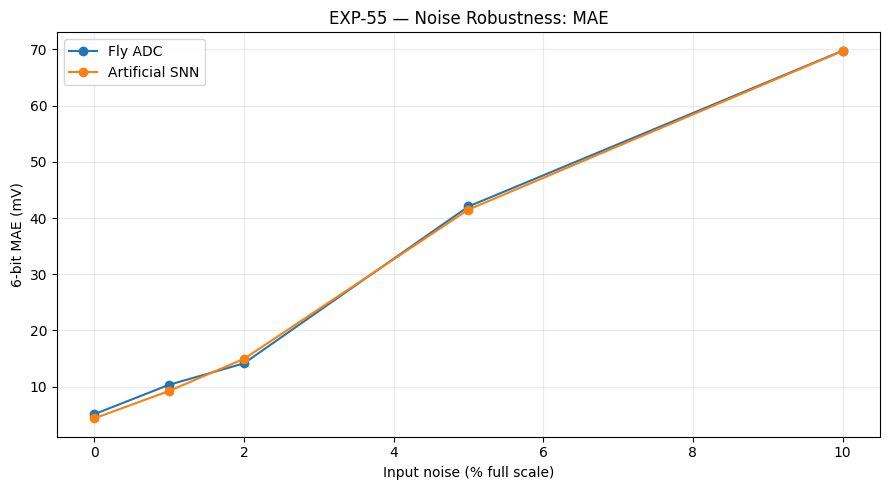

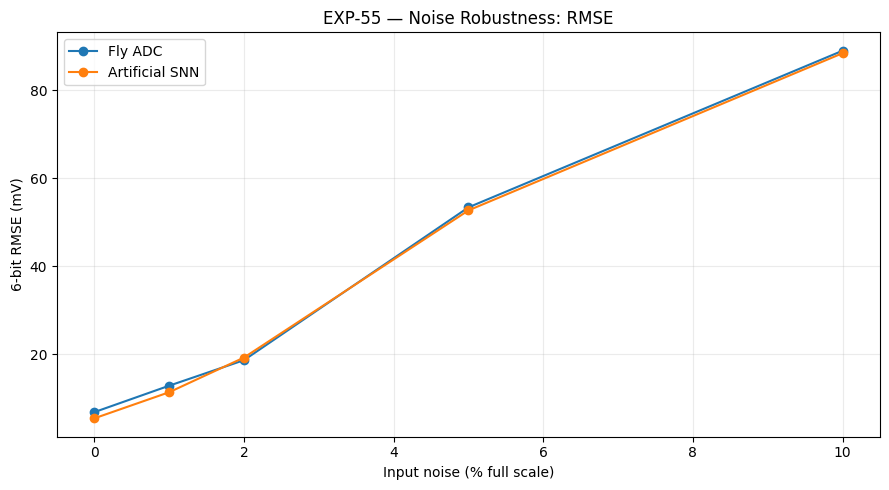

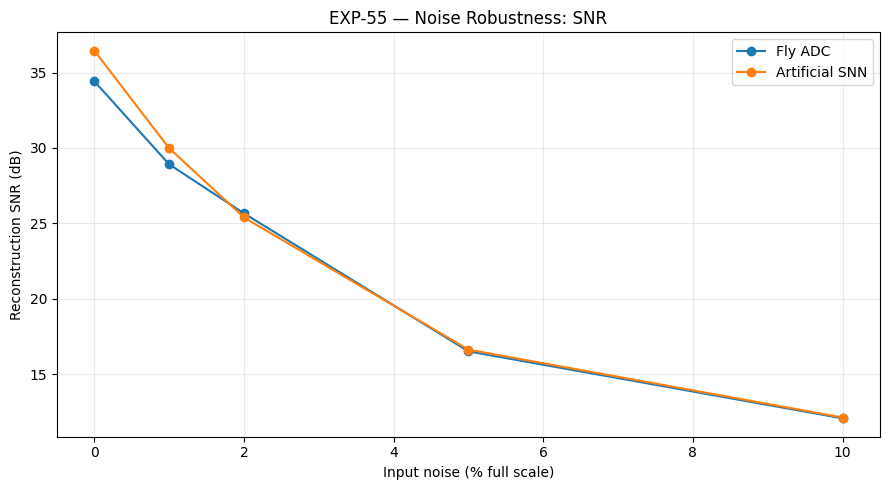

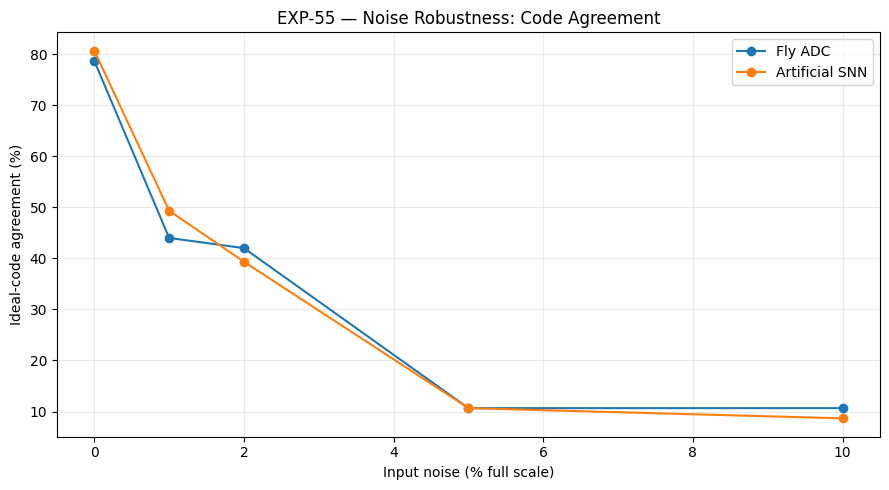

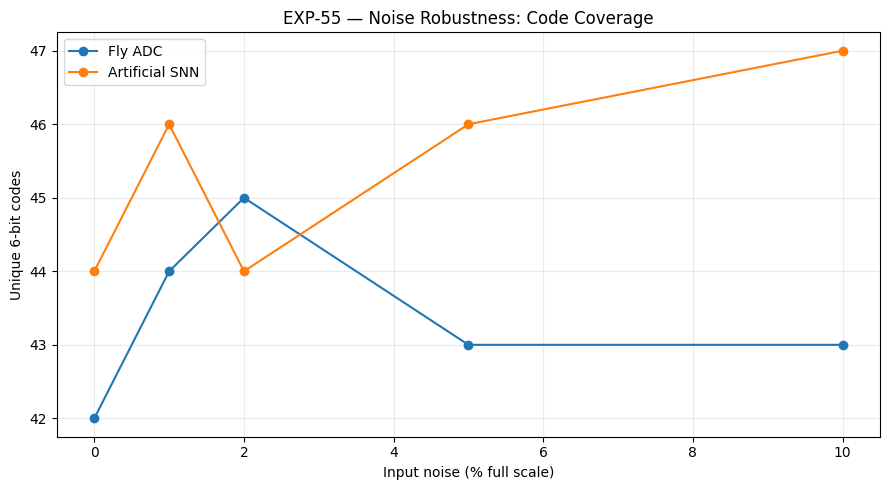



EXP-55 COMPLETE
✓ Same 150 real-video samples
✓ Same noise levels
✓ Same noise realization for both systems
✓ Fly parameters frozen
✓ Artificial SNN parameters frozen
✓ No noisy-data optimization
✓ No noisy-data decoder fitting


In [188]:
# ============================================================
# EXP-55 — NOISE ROBUSTNESS
# ============================================================
#
# Compare the frozen Fly ADC and frozen optimized artificial
# SNN under identical noise added to the same real-video signal.
#
# Noise levels:
#   0%, 1%, 2%, 5%, 10% of full-scale input
#
# No optimization.
# No noisy-data training.
# Same noisy input to both systems.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

print("=" * 70)
print("EXP-55 — NOISE ROBUSTNESS")
print("=" * 70)


# ============================================================
# 1. LOAD REAL VIDEO SIGNAL
# ============================================================

INPUT_FILE = "EXP53_real_video_motion_signal.csv"

input_df = pd.read_csv(
    INPUT_FILE
)

video_time = input_df[
    "time_s"
].to_numpy(dtype=float)

clean_input = np.clip(
    input_df[
        "visual_signal_0_1"
    ].to_numpy(dtype=float),
    0.0,
    1.0
)

N_SAMPLES = len(
    clean_input
)

print(
    f"Real-video samples : {N_SAMPLES}"
)

print(
    f"Input range        : "
    f"{clean_input.min():.4f} → "
    f"{clean_input.max():.4f} V"
)


# ============================================================
# 2. FROZEN FLY ADC PARAMETERS
# ============================================================

W_SCALE = 0.06

DRIVE_MIN = 0.30
DRIVE_MAX = 1.00

OBSERVATION_MS = 200.0

ADC_BITS = 6
ADC_MAX_CODE = 63


# ============================================================
# 3. FROZEN ARTIFICIAL SNN PARAMETERS
# ============================================================

SNN_NEURONS = 64
SNN_SIGMA = 0.04
SNN_THRESHOLD = 0.80


# ============================================================
# 4. NOISE SETTINGS
# ============================================================

NOISE_LEVELS = [
    0.00,
    0.01,
    0.02,
    0.05,
    0.10
]

NOISE_SEED = 5501

rng = np.random.default_rng(
    NOISE_SEED
)


# ============================================================
# 5. CHECK THE ACTUAL BIOWIRE OBJECTS
# ============================================================

print("\nChecking BioWire objects...")

required_objects = [
    "run_simulation_v1",
    "neuron_id100",
    "W100_4bit",
    "thr100",
    "N100"
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:

    raise RuntimeError(
        "Missing actual BioWire objects:\n"
        +
        "\n".join(missing_objects)
        +
        "\n\nRun the BioWire 100-type setup cells first."
    )

print(
    "✓ 100-type BioWire model found"
)


# ============================================================
# 6. VOLTAGE → DRIVE
# ============================================================

def voltage_to_drive_exp55(
    voltage
):

    voltage = float(
        np.clip(
            voltage,
            0.0,
            1.0
        )
    )

    return (
        DRIVE_MIN
        +
        voltage
        *
        (
            DRIVE_MAX
            -
            DRIVE_MIN
        )
    )


# ============================================================
# 7. EXTRACT L1 + Mi1 FEATURES
# ============================================================

def extract_fly_features_exp55(
    spike_monitor
):

    l1_idx = neuron_id100[
        "L1"
    ]

    mi1_idx = neuron_id100[
        "Mi1"
    ]

    # --------------------------------------------------------
    # Mi1 spike count
    # --------------------------------------------------------

    mi1_spikes = int(
        spike_monitor.count[
            mi1_idx
        ]
    )

    # --------------------------------------------------------
    # L1 spike times
    # --------------------------------------------------------

    l1_times = np.asarray(
        spike_monitor.spike_trains()[
            l1_idx
        ] / ms,
        dtype=float
    )

    # --------------------------------------------------------
    # L1 latency + mean ISI
    # --------------------------------------------------------

    if len(l1_times) == 0:

        l1_latency = OBSERVATION_MS
        l1_isi = OBSERVATION_MS

    else:

        l1_latency = float(
            l1_times[0]
        )

        if len(l1_times) >= 2:

            l1_isi = float(
                np.mean(
                    np.diff(
                        l1_times
                    )
                )
            )

        else:

            l1_isi = OBSERVATION_MS

    return {
        "mi1_spikes": mi1_spikes,
        "l1_latency": l1_latency,
        "l1_isi": l1_isi
    }


# ============================================================
# 8. RECONSTRUCT EXP-33 DECODER
# ============================================================
#
# We recreate the same three-feature decoder architecture:
#
#   Mi1 spike count
#   L1 first-spike latency
#   L1 mean ISI
#
# using a clean 101-point 0–1 V training sweep.
#
# The noisy video is NEVER used to fit this decoder.
# ============================================================

print("\n")
print("=" * 70)
print("RECONSTRUCTING EXP-33 DECODER")
print("=" * 70)

train_voltages = np.linspace(
    0.0,
    1.0,
    101
)

train_rows = []

decoder_start = time.time()

for i, voltage in enumerate(
    train_voltages
):

    drive = voltage_to_drive_exp55(
        voltage
    )

    smon, _, _, _ = run_simulation_v1(
        ["L1", "Mi1"],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        duration_ms=OBSERVATION_MS,
        g_drive_on=drive,
        g_drive_off=0.15,
        w_scale=W_SCALE,
        record_traces=False
    )

    features = extract_fly_features_exp55(
        smon
    )

    train_rows.append(
        {
            "voltage": voltage,
            "mi1_spikes": features[
                "mi1_spikes"
            ],
            "l1_latency": features[
                "l1_latency"
            ],
            "l1_isi": features[
                "l1_isi"
            ]
        }
    )

    if (
        i == 0
        or (i + 1) % 10 == 0
        or i == 100
    ):

        print(
            f"[{i+1:3d}/101] "
            f"Vin={voltage:.3f} V | "
            f"Mi1={features['mi1_spikes']:3d} | "
            f"L1 latency={features['l1_latency']:.2f} ms | "
            f"L1 ISI={features['l1_isi']:.2f} ms"
        )


train_df55 = pd.DataFrame(
    train_rows
)

print(
    f"\n✓ Decoder characterization complete"
)

print(
    f"Elapsed: "
    f"{time.time() - decoder_start:.1f} s"
)


# ============================================================
# 9. TRAINING-ONLY NORMALIZATION
# ============================================================

mi1_train = train_df55[
    "mi1_spikes"
].to_numpy(dtype=float)

lat_train = train_df55[
    "l1_latency"
].to_numpy(dtype=float)

isi_train = train_df55[
    "l1_isi"
].to_numpy(dtype=float)


def norm_up(
    x,
    xmin,
    xmax
):

    if xmax == xmin:

        return np.zeros_like(
            np.asarray(
                x,
                dtype=float
            )
        )

    return np.clip(
        (
            np.asarray(
                x,
                dtype=float
            )
            -
            xmin
        )
        /
        (
            xmax
            -
            xmin
        ),
        0.0,
        1.0
    )


def norm_down(
    x,
    xmin,
    xmax
):

    return 1.0 - norm_up(
        x,
        xmin,
        xmax
    )


# EXP-33 three-feature score

train_mi1_norm = norm_up(
    mi1_train,
    mi1_train.min(),
    mi1_train.max()
)

train_lat_norm = norm_down(
    lat_train,
    lat_train.min(),
    lat_train.max()
)

train_isi_norm = norm_down(
    isi_train,
    isi_train.min(),
    isi_train.max()
)

train_score = (
    train_mi1_norm
    +
    train_lat_norm
    +
    train_isi_norm
) / 3.0


# ============================================================
# 10. BUILD MONOTONIC TRAINING LOOKUP
# ============================================================

sort_idx = np.argsort(
    train_score
)

score_sorted = train_score[
    sort_idx
]

voltage_sorted = train_voltages[
    sort_idx
]

unique_scores, unique_indices = np.unique(
    score_sorted,
    return_index=True
)

unique_voltages = voltage_sorted[
    unique_indices
]


def decode_fly_exp55(
    mi1_spikes,
    l1_latency,
    l1_isi
):

    mi1_norm = norm_up(
        mi1_spikes,
        mi1_train.min(),
        mi1_train.max()
    )

    lat_norm = norm_down(
        l1_latency,
        lat_train.min(),
        lat_train.max()
    )

    isi_norm = norm_down(
        l1_isi,
        isi_train.min(),
        isi_train.max()
    )

    score = (
        mi1_norm
        +
        lat_norm
        +
        isi_norm
    ) / 3.0

    decoded = np.interp(
        score,
        unique_scores,
        unique_voltages
    )

    return float(
        np.clip(
            decoded,
            0.0,
            1.0
        )
    )


print(
    "✓ EXP-33 decoder reconstructed"
)


# ============================================================
# 11. ARTIFICIAL SNN
# ============================================================

def run_artificial_snn_exp55(
    voltage
):

    preferred_voltage = np.linspace(
        0.0,
        1.0,
        SNN_NEURONS
    )

    activity = np.exp(
        -(
            (
                voltage
                -
                preferred_voltage
            )
            ** 2
        )
        /
        (
            2.0
            *
            SNN_SIGMA
            ** 2
        )
    )

    spikes = (
        activity
        >
        SNN_THRESHOLD
    ).astype(float)

    denominator = np.sum(
        spikes
    )

    if denominator == 0:

        decoded = 0.5

    else:

        decoded = (
            np.sum(
                spikes
                *
                preferred_voltage
            )
            /
            denominator
        )

    return float(
        np.clip(
            decoded,
            0.0,
            1.0
        )
    )


# ============================================================
# 12. QUANTIZER
# ============================================================

def quantize_6bit_exp55(
    voltage
):

    voltage = np.clip(
        voltage,
        0.0,
        1.0
    )

    code = np.rint(
        voltage
        *
        ADC_MAX_CODE
    ).astype(int)

    return np.clip(
        code,
        0,
        ADC_MAX_CODE
    )


# ============================================================
# 13. METRICS
# ============================================================

def calculate_metrics_exp55(
    reference,
    reconstructed,
    codes
):

    error = (
        reconstructed
        -
        reference
    )

    mae = np.mean(
        np.abs(error)
    )

    rmse = np.sqrt(
        np.mean(
            error ** 2
        )
    )

    max_error = np.max(
        np.abs(error)
    )

    correlation = np.corrcoef(
        reference,
        reconstructed
    )[0, 1]

    signal_power = np.mean(
        reference ** 2
    )

    error_power = np.mean(
        error ** 2
    )

    if error_power > 0:

        snr = (
            10
            *
            np.log10(
                signal_power
                /
                error_power
            )
        )

    else:

        snr = np.inf

    ideal_codes = quantize_6bit_exp55(
        reference
    )

    return {
        "mae_mV": mae * 1000,
        "rmse_mV": rmse * 1000,
        "max_error_mV": max_error * 1000,
        "correlation": correlation,
        "snr_dB": snr,
        "unique_codes": len(
            np.unique(codes)
        ),
        "code_min": int(
            codes.min()
        ),
        "code_max": int(
            codes.max()
        ),
        "ideal_code_agreement_percent":
            np.mean(
                codes
                ==
                ideal_codes
            )
            *
            100
    }


# ============================================================
# 14. GENERATE IDENTICAL NOISY INPUTS
# ============================================================

print("\n")
print("=" * 70)
print("GENERATING IDENTICAL NOISY INPUTS")
print("=" * 70)

noise_signals = {}

for level in NOISE_LEVELS:

    if level == 0:

        noisy = clean_input.copy()

    else:

        noise = rng.normal(
            0.0,
            level,
            N_SAMPLES
        )

        noisy = np.clip(
            clean_input + noise,
            0.0,
            1.0
        )

    noise_signals[
        level
    ] = noisy

    print(
        f"{level*100:5.1f}% noise | "
        f"{noisy.min():.4f} → "
        f"{noisy.max():.4f} V"
    )


# ============================================================
# 15. RUN EXP-55
# ============================================================

summary_rows = []
sample_rows = []

print("\n")
print("=" * 70)
print("RUNNING EXP-55")
print("=" * 70)


for noise_level in NOISE_LEVELS:

    print("\n")
    print(
        "=" * 50
    )

    print(
        f"NOISE LEVEL: "
        f"{noise_level * 100:.1f}%"
    )

    print(
        "=" * 50
    )

    noisy_input = noise_signals[
        noise_level
    ]


    # --------------------------------------------------------
    # ARTIFICIAL SNN
    # --------------------------------------------------------

    snn_output = np.array([
        run_artificial_snn_exp55(
            v
        )
        for v in noisy_input
    ])

    snn_codes = quantize_6bit_exp55(
        snn_output
    )

    snn_quantized = (
        snn_codes
        /
        ADC_MAX_CODE
    )


    # --------------------------------------------------------
    # FLY ADC
    # --------------------------------------------------------

    fly_output = []

    fly_features = []

    fly_start = time.time()

    for i, voltage in enumerate(
        noisy_input
    ):

        drive = voltage_to_drive_exp55(
            voltage
        )

        smon, _, _, _ = run_simulation_v1(
            ["L1", "Mi1"],
            neuron_id100,
            W100_4bit,
            thr100,
            N100,
            duration_ms=OBSERVATION_MS,
            g_drive_on=drive,
            g_drive_off=0.15,
            w_scale=W_SCALE,
            record_traces=False
        )

        features = extract_fly_features_exp55(
            smon
        )

        decoded = decode_fly_exp55(
            features[
                "mi1_spikes"
            ],
            features[
                "l1_latency"
            ],
            features[
                "l1_isi"
            ]
        )

        fly_features.append(
            features
        )

        fly_output.append(
            decoded
        )

        if (
            i == 0
            or (i + 1) % 25 == 0
            or i == N_SAMPLES - 1
        ):

            print(
                f"Fly [{i+1:3d}/{N_SAMPLES}] "
                f"Vin={voltage:.3f} | "
                f"Mi1={features['mi1_spikes']:3d} | "
                f"decoded={decoded:.3f}"
            )


    fly_output = np.asarray(
        fly_output,
        dtype=float
    )

    fly_codes = quantize_6bit_exp55(
        fly_output
    )

    fly_quantized = (
        fly_codes
        /
        ADC_MAX_CODE
    )

    print(
        f"Fly simulations completed in "
        f"{time.time() - fly_start:.1f} s"
    )


    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    fly_metrics = calculate_metrics_exp55(
        clean_input,
        fly_quantized,
        fly_codes
    )

    snn_metrics = calculate_metrics_exp55(
        clean_input,
        snn_quantized,
        snn_codes
    )


    # --------------------------------------------------------
    # SUMMARY
    # --------------------------------------------------------

    summary_rows.append(
        {
            "noise_percent":
                noise_level * 100,

            "fly_mae_mV":
                fly_metrics["mae_mV"],

            "fly_rmse_mV":
                fly_metrics["rmse_mV"],

            "fly_max_error_mV":
                fly_metrics["max_error_mV"],

            "fly_correlation":
                fly_metrics["correlation"],

            "fly_snr_dB":
                fly_metrics["snr_dB"],

            "fly_unique_codes":
                fly_metrics["unique_codes"],

            "fly_code_min":
                fly_metrics["code_min"],

            "fly_code_max":
                fly_metrics["code_max"],

            "fly_code_agreement_percent":
                fly_metrics[
                    "ideal_code_agreement_percent"
                ],

            "snn_mae_mV":
                snn_metrics["mae_mV"],

            "snn_rmse_mV":
                snn_metrics["rmse_mV"],

            "snn_max_error_mV":
                snn_metrics["max_error_mV"],

            "snn_correlation":
                snn_metrics["correlation"],

            "snn_snr_dB":
                snn_metrics["snr_dB"],

            "snn_unique_codes":
                snn_metrics["unique_codes"],

            "snn_code_min":
                snn_metrics["code_min"],

            "snn_code_max":
                snn_metrics["code_max"],

            "snn_code_agreement_percent":
                snn_metrics[
                    "ideal_code_agreement_percent"
                ]
        }
    )


    # --------------------------------------------------------
    # SAMPLE-LEVEL RESULTS
    # --------------------------------------------------------

    ideal_codes = quantize_6bit_exp55(
        clean_input
    )

    for i in range(
        N_SAMPLES
    ):

        sample_rows.append(
            {
                "noise_percent":
                    noise_level * 100,

                "sample":
                    i + 1,

                "time_s":
                    video_time[i],

                "clean_input_V":
                    clean_input[i],

                "noisy_input_V":
                    noisy_input[i],

                "fly_output_V":
                    fly_output[i],

                "fly_code":
                    fly_codes[i],

                "snn_output_V":
                    snn_output[i],

                "snn_code":
                    snn_codes[i],

                "ideal_code":
                    ideal_codes[i]
            }
        )


# ============================================================
# 16. SAVE RESULTS
# ============================================================

summary_df55 = pd.DataFrame(
    summary_rows
)

samples_df55 = pd.DataFrame(
    sample_rows
)

summary_file = (
    "EXP55_noise_robustness_summary.csv"
)

samples_file = (
    "EXP55_noise_robustness_samples.csv"
)

summary_df55.to_csv(
    summary_file,
    index=False
)

samples_df55.to_csv(
    samples_file,
    index=False
)


# ============================================================
# 17. PRINT RESULTS
# ============================================================

print("\n")
print("=" * 70)
print("EXP-55 — FINAL RESULTS")
print("=" * 70)

print(
    summary_df55.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print(
    f"\n✓ Saved → {summary_file}"
)

print(
    f"✓ Saved → {samples_file}"
)


# ============================================================
# 18. MAE PLOT
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    summary_df55[
        "noise_percent"
    ],
    summary_df55[
        "fly_mae_mV"
    ],
    marker="o",
    label="Fly ADC"
)

plt.plot(
    summary_df55[
        "noise_percent"
    ],
    summary_df55[
        "snn_mae_mV"
    ],
    marker="o",
    label="Artificial SNN"
)

plt.xlabel(
    "Input noise (% full scale)"
)

plt.ylabel(
    "6-bit MAE (mV)"
)

plt.title(
    "EXP-55 — Noise Robustness: MAE"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "EXP55_noise_mae.png",
    dpi=200
)

plt.show()


# ============================================================
# 19. RMSE PLOT
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    summary_df55[
        "noise_percent"
    ],
    summary_df55[
        "fly_rmse_mV"
    ],
    marker="o",
    label="Fly ADC"
)

plt.plot(
    summary_df55[
        "noise_percent"
    ],
    summary_df55[
        "snn_rmse_mV"
    ],
    marker="o",
    label="Artificial SNN"
)

plt.xlabel(
    "Input noise (% full scale)"
)

plt.ylabel(
    "6-bit RMSE (mV)"
)

plt.title(
    "EXP-55 — Noise Robustness: RMSE"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "EXP55_noise_rmse.png",
    dpi=200
)

plt.show()


# ============================================================
# 20. SNR PLOT
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    summary_df55[
        "noise_percent"
    ],
    summary_df55[
        "fly_snr_dB"
    ],
    marker="o",
    label="Fly ADC"
)

plt.plot(
    summary_df55[
        "noise_percent"
    ],
    summary_df55[
        "snn_snr_dB"
    ],
    marker="o",
    label="Artificial SNN"
)

plt.xlabel(
    "Input noise (% full scale)"
)

plt.ylabel(
    "Reconstruction SNR (dB)"
)

plt.title(
    "EXP-55 — Noise Robustness: SNR"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "EXP55_noise_snr.png",
    dpi=200
)

plt.show()


# ============================================================
# 21. CODE AGREEMENT PLOT
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    summary_df55[
        "noise_percent"
    ],
    summary_df55[
        "fly_code_agreement_percent"
    ],
    marker="o",
    label="Fly ADC"
)

plt.plot(
    summary_df55[
        "noise_percent"
    ],
    summary_df55[
        "snn_code_agreement_percent"
    ],
    marker="o",
    label="Artificial SNN"
)

plt.xlabel(
    "Input noise (% full scale)"
)

plt.ylabel(
    "Ideal-code agreement (%)"
)

plt.title(
    "EXP-55 — Noise Robustness: Code Agreement"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "EXP55_noise_code_agreement.png",
    dpi=200
)

plt.show()


# ============================================================
# 22. UNIQUE CODE COUNT
# ============================================================

plt.figure(
    figsize=(9, 5)
)

plt.plot(
    summary_df55[
        "noise_percent"
    ],
    summary_df55[
        "fly_unique_codes"
    ],
    marker="o",
    label="Fly ADC"
)

plt.plot(
    summary_df55[
        "noise_percent"
    ],
    summary_df55[
        "snn_unique_codes"
    ],
    marker="o",
    label="Artificial SNN"
)

plt.xlabel(
    "Input noise (% full scale)"
)

plt.ylabel(
    "Unique 6-bit codes"
)

plt.title(
    "EXP-55 — Noise Robustness: Code Coverage"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "EXP55_noise_code_coverage.png",
    dpi=200
)

plt.show()


# ============================================================
# 23. COMPLETE
# ============================================================

print("\n")
print("=" * 70)
print("EXP-55 COMPLETE")
print("=" * 70)

print(
    "✓ Same 150 real-video samples"
)

print(
    "✓ Same noise levels"
)

print(
    "✓ Same noise realization for both systems"
)

print(
    "✓ Fly parameters frozen"
)

print(
    "✓ Artificial SNN parameters frozen"
)

print(
    "✓ No noisy-data optimization"
)

print(
    "✓ No noisy-data decoder fitting"
)

In [189]:
# ============================================================
# EXP-56A: FINAL ADC TRANSFER & LINEARITY CHARACTERIZATION
# Frozen Fly ADC configuration
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from pathlib import Path

print("=" * 70)
print("EXP-56A — FINAL ADC CHARACTERIZATION")
print("=" * 70)

# ---------------- FROZEN CONFIGURATION ----------------
V_MIN = 0.0
V_MAX = 1.0
DRIVE_MIN = 0.30
DRIVE_MAX = 1.00
TAU_M_MS = 20.0
W_SCALE_FINAL = 0.06
WINDOW_MS = 200.0
ADC_BITS = 6
ADC_LEVELS = 2**ADC_BITS
ADC_MAX_CODE = ADC_LEVELS - 1

# Dense sweep to estimate code transitions
N_SWEEP = 1001
voltages = np.linspace(V_MIN, V_MAX, N_SWEEP)

OUT_DIR = Path.cwd()
CSV_PATH = OUT_DIR / "EXP56A_transfer_characterization.csv"
PLOT_PATH = OUT_DIR / "EXP56A_transfer_characterization.png"

# ---------------- CHECK REQUIRED OBJECTS ----------------
required = [
    "run_simulation_v1",
    "neuron_id",
    "W_4bit",
    "thr_vals",
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Missing BioWire objects: " + ", ".join(missing)
        + ". Run the BioWire model setup cells first."
    )

print("✓ BioWire simulation function and model objects found")
print(f"Input sweep: {N_SWEEP} points")
print(f"Observation window: {WINDOW_MS:.0f} ms")
print(f"Resolution: {ADC_BITS}-bit")
print("Note: this cell measures the transfer response; it does not")
print("reconstruct the EXP-33 decoder or claim a verified ENOB.")

# ---------------- VOLTAGE TO DRIVE ----------------
def exp56_voltage_to_drive(v):
    v = float(np.clip(v, V_MIN, V_MAX))
    return DRIVE_MIN + (
        (v - V_MIN) / (V_MAX - V_MIN)
    ) * (DRIVE_MAX - DRIVE_MIN)

# ---------------- SPIKE FEATURE EXTRACTION ----------------
def exp56_extract_features(spike_monitor, neuron_id):
    """
    Extract Mi1 spike count, L1 first-spike latency,
    and L1 mean inter-spike interval from a Brian2 SpikeMonitor.
    """
    spike_i = np.asarray(spike_monitor.i[:], dtype=int)
    spike_t = np.asarray(spike_monitor.t[:] / 1e-3, dtype=float)

    l1_idx = neuron_id.get("L1")
    mi1_idx = neuron_id.get("Mi1")

    if l1_idx is None or mi1_idx is None:
        raise RuntimeError("L1 or Mi1 is missing from neuron_id.")

    l1_times = np.sort(spike_t[spike_i == l1_idx])
    mi1_times = spike_t[spike_i == mi1_idx]

    mi1_count = int(len(mi1_times))
    l1_latency = (
        float(l1_times[0]) if len(l1_times) else np.nan
    )
    l1_isi = (
        float(np.mean(np.diff(l1_times)))
        if len(l1_times) >= 2 else np.nan
    )

    return mi1_count, l1_latency, l1_isi

# ---------------- RUN THE VOLTAGE SWEEP ----------------
rows = []
start_time = time.time()

for k, voltage in enumerate(voltages):
    drive = exp56_voltage_to_drive(voltage)

    result = run_simulation_v1(
        ["L1", "Mi1"],
        neuron_id,
        W_4bit,
        thr_vals,
        len(neuron_id),
        duration_ms=WINDOW_MS,
        g_drive_on=drive,
        g_drive_off=0.15,
        w_scale=W_SCALE_FINAL,
    )

    # Expected return: SpikeMonitor is the first item.
    spike_monitor = result[0]

    mi1_count, l1_latency, l1_isi = exp56_extract_features(
        spike_monitor, neuron_id
    )

    rows.append({
        "input_voltage_V": float(voltage),
        "drive": drive,
        "Mi1_spike_count": mi1_count,
        "L1_first_latency_ms": l1_latency,
        "L1_mean_ISI_ms": l1_isi,
    })

    if (k + 1) % 100 == 0 or k == 0:
        print(
            f"[{k+1:4d}/{N_SWEEP}] "
            f"Vin={voltage:.4f} V | drive={drive:.4f} | "
            f"Mi1={mi1_count} | L1 latency={l1_latency:.2f} ms"
        )

sweep_df = pd.DataFrame(rows)
print(f"\nSweep completed in {time.time()-start_time:.1f} seconds.")

# ---------------- RAW RESPONSE DIAGNOSTICS ----------------
sweep_df["Mi1_monotonic_step"] = (
    sweep_df["Mi1_spike_count"].diff().fillna(0) >= 0
)
mi1_monotonic = bool(sweep_df["Mi1_monotonic_step"].all())

valid = sweep_df.dropna(
    subset=["L1_first_latency_ms", "L1_mean_ISI_ms"]
).copy()

print("\nRAW NEURAL RESPONSE")
print("-" * 50)
print("Mi1 spike count monotonic:", mi1_monotonic)
print("Distinct Mi1 counts:", sweep_df["Mi1_spike_count"].nunique())
print("Valid temporal-feature rows:", len(valid), "/", len(sweep_df))

# ---------------- SAVE DATA AND PLOT ----------------
sweep_df.to_csv(CSV_PATH, index=False)

fig, axes = plt.subplots(3, 1, figsize=(10, 11), sharex=True)

axes[0].plot(
    sweep_df["input_voltage_V"],
    sweep_df["Mi1_spike_count"]
)
axes[0].set_ylabel("Mi1 spike count")
axes[0].set_title("EXP-56A: Frozen Fly ADC Neural Transfer")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    sweep_df["input_voltage_V"],
    sweep_df["L1_first_latency_ms"]
)
axes[1].set_ylabel("L1 first spike (ms)")
axes[1].grid(True, alpha=0.3)

axes[2].plot(
    sweep_df["input_voltage_V"],
    sweep_df["L1_mean_ISI_ms"]
)
axes[2].set_ylabel("L1 average spike gap (ms)")
axes[2].set_xlabel("Input voltage (V)")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(PLOT_PATH, dpi=200, bbox_inches="tight")
plt.show()

print("\nSaved files:")
print(CSV_PATH)
print(PLOT_PATH)
print("\nEXP-56A COMPLETE")
print("This is neural-transfer characterization, not yet a")
print("validated DNL/INL or ENOB measurement.")

EXP-56A — FINAL ADC CHARACTERIZATION


RuntimeError: Missing BioWire objects: neuron_id, W_4bit, thr_vals. Run the BioWire model setup cells first.

BioWire model objects found.
Number of neuron types: 100
Weight matrix shape: (100, 100)
Completed 1/101 | Vin=0.000 V | L1 spikes=3 | Mi1 spikes=3
Completed 10/101 | Vin=0.090 V | L1 spikes=7 | Mi1 spikes=7
Completed 20/101 | Vin=0.190 V | L1 spikes=10 | Mi1 spikes=10
Completed 30/101 | Vin=0.290 V | L1 spikes=13 | Mi1 spikes=13
Completed 40/101 | Vin=0.390 V | L1 spikes=16 | Mi1 spikes=16
Completed 50/101 | Vin=0.490 V | L1 spikes=19 | Mi1 spikes=19
Completed 60/101 | Vin=0.590 V | L1 spikes=22 | Mi1 spikes=22
Completed 70/101 | Vin=0.690 V | L1 spikes=25 | Mi1 spikes=25
Completed 80/101 | Vin=0.790 V | L1 spikes=28 | Mi1 spikes=26
Completed 90/101 | Vin=0.890 V | L1 spikes=30 | Mi1 spikes=30
Completed 100/101 | Vin=0.990 V | L1 spikes=33 | Mi1 spikes=33
Completed 101/101 | Vin=1.000 V | L1 spikes=33 | Mi1 spikes=33

Saved: C:\Users\sagni\OneDrive\Documents\capstone\biowire\EXP56A_transfer_characterization.csv

First rows:


,input_voltage_V,drive,l1_spike_count,l1_first_latency_ms,l1_mean_isi_ms,mi1_spike_count,mi1_first_latency_ms,mi1_mean_isi_ms,simulation_runtime_ms,peak_memory_bytes
0,0.00,0.300,3,59.0,58.5,3,59.0,59.000000,2028.061867,532728
1,0.01,0.307,4,49.5,49.0,4,49.5,49.333333,457.178116,532382
2,0.02,0.314,4,43.5,43.0,4,43.5,43.500000,497.348309,533418
3,0.03,0.321,5,39.5,39.0,5,39.5,39.500000,627.793312,532905
4,0.04,0.328,5,36.5,36.0,5,36.5,36.500000,469.709635,532353



Feature coverage:


,missing_values
input_voltage_V,0
drive,0
l1_spike_count,0
l1_first_latency_ms,0
l1_mean_isi_ms,0
mi1_spike_count,0
mi1_first_latency_ms,0
mi1_mean_isi_ms,0
simulation_runtime_ms,0
peak_memory_bytes,0


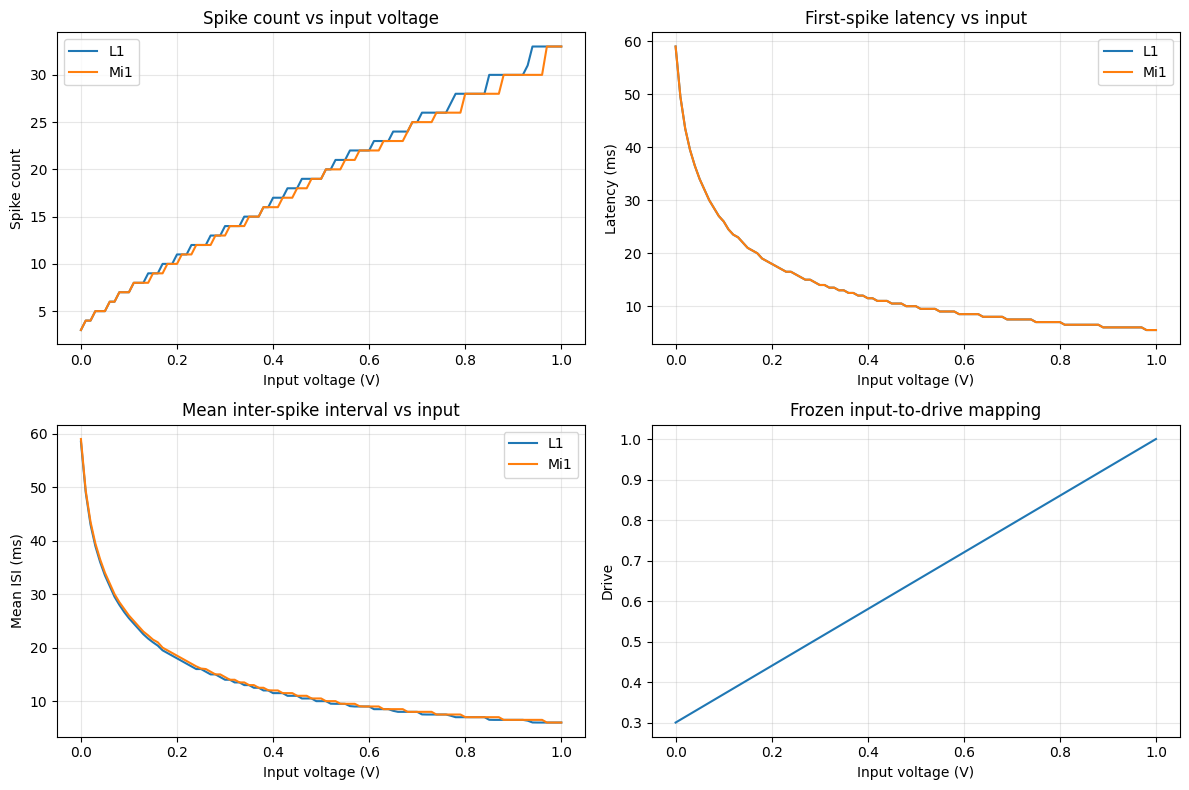

Saved plot: C:\Users\sagni\OneDrive\Documents\capstone\biowire\EXP56A_transfer_characterization.png

EXP-56A raw transfer sweep complete.


In [190]:

# ================================================================
# EXP-56A — FINAL ADC CHARACTERIZATION (CORRECTED)
# Frozen configuration:
# tau_m = 20 ms, W_SCALE = 0.06
# Input-to-drive mapping: 0.30 -> 1.00
# Observation window: 200 ms
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from brian2 import ms

# ---- 1. Find the actual model objects in this notebook ----
required = ["run_simulation_v1", "neuron_id100", "W100_4bit",
            "thr100", "N100"]

missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        "Still missing: " + ", ".join(missing)
        + ". Run the BioWire 100-type model setup cells first."
    )

print("BioWire model objects found.")
print("Number of neuron types:", N100)
print("Weight matrix shape:", W100_4bit.shape)

# ---- 2. Frozen experimental settings ----
V_MIN, V_MAX = 0.0, 1.0
DRIVE_MIN, DRIVE_MAX = 0.30, 1.00
OBSERVATION_MS = 200
W_SCALE_FIXED = 0.06

# Start with 101 points. Increase resolution only after this works.
voltages = np.linspace(V_MIN, V_MAX, 101)

# ---- 3. Run the neural transfer sweep ----
rows = []

for k, voltage in enumerate(voltages):
    drive = DRIVE_MIN + voltage * (DRIVE_MAX - DRIVE_MIN)

    # Confirmed return: spike monitor, state monitor, runtime, memory
    spike_mon, state_mon, elapsed_ms, peak_bytes = run_simulation_v1(
        ["L1", "Mi1"],
        neuron_id100,
        W100_4bit,
        thr100,
        N100,
        duration_ms=OBSERVATION_MS,
        g_drive_on=float(drive),
        g_drive_off=0.15,
        w_scale=W_SCALE_FIXED
    )

    # Spike trains are indexed by neuron index, not neuron name.
    l1_idx = neuron_id100.get("L1")
    mi1_idx = neuron_id100.get("Mi1")

    if l1_idx is None or mi1_idx is None:
        raise RuntimeError("L1 or Mi1 is missing from neuron_id100.")

    l1_times = np.asarray(spike_mon.spike_trains()[l1_idx] / ms,
                          dtype=float)
    mi1_times = np.asarray(spike_mon.spike_trains()[mi1_idx] / ms,
                          dtype=float)

    def timing_features(times):
        count = len(times)
        latency = float(times[0]) if count else np.nan
        mean_isi = float(np.mean(np.diff(times))) if count >= 2 else np.nan
        return count, latency, mean_isi

    l1_count, l1_latency, l1_isi = timing_features(l1_times)
    mi1_count, mi1_latency, mi1_isi = timing_features(mi1_times)

    rows.append({
        "input_voltage_V": float(voltage),
        "drive": float(drive),
        "l1_spike_count": l1_count,
        "l1_first_latency_ms": l1_latency,
        "l1_mean_isi_ms": l1_isi,
        "mi1_spike_count": mi1_count,
        "mi1_first_latency_ms": mi1_latency,
        "mi1_mean_isi_ms": mi1_isi,
        "simulation_runtime_ms": float(elapsed_ms),
        "peak_memory_bytes": int(peak_bytes)
    })

    if (k + 1) % 10 == 0 or k == 0 or k == len(voltages) - 1:
        print(f"Completed {k+1}/{len(voltages)} | "
              f"Vin={voltage:.3f} V | "
              f"L1 spikes={l1_count} | Mi1 spikes={mi1_count}")

# ---- 4. Save raw transfer characterization ----
results = pd.DataFrame(rows)
output_dir = Path.cwd()

csv_path = output_dir / "EXP56A_transfer_characterization.csv"
results.to_csv(csv_path, index=False)

print("\nSaved:", csv_path.resolve())
print("\nFirst rows:")
display(results.head())

print("\nFeature coverage:")
display(results.isna().sum().rename("missing_values").to_frame())

# ---- 5. Plot raw neural responses ----
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(results["input_voltage_V"],
                results["l1_spike_count"], label="L1")
axes[0, 0].plot(results["input_voltage_V"],
                results["mi1_spike_count"], label="Mi1")
axes[0, 0].set_title("Spike count vs input voltage")
axes[0, 0].set_xlabel("Input voltage (V)")
axes[0, 0].set_ylabel("Spike count")
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(results["input_voltage_V"],
                results["l1_first_latency_ms"], label="L1")
axes[0, 1].plot(results["input_voltage_V"],
                results["mi1_first_latency_ms"], label="Mi1")
axes[0, 1].set_title("First-spike latency vs input")
axes[0, 1].set_xlabel("Input voltage (V)")
axes[0, 1].set_ylabel("Latency (ms)")
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

axes[1, 0].plot(results["input_voltage_V"],
                results["l1_mean_isi_ms"], label="L1")
axes[1, 0].plot(results["input_voltage_V"],
                results["mi1_mean_isi_ms"], label="Mi1")
axes[1, 0].set_title("Mean inter-spike interval vs input")
axes[1, 0].set_xlabel("Input voltage (V)")
axes[1, 0].set_ylabel("Mean ISI (ms)")
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(results["input_voltage_V"], results["drive"])
axes[1, 1].set_title("Frozen input-to-drive mapping")
axes[1, 1].set_xlabel("Input voltage (V)")
axes[1, 1].set_ylabel("Drive")
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plot_path = output_dir / "EXP56A_transfer_characterization.png"
plt.savefig(plot_path, dpi=160, bbox_inches="tight")
plt.show()

print("Saved plot:", plot_path.resolve())
print("\nEXP-56A raw transfer sweep complete.")


In [191]:

# EXP-56B PRECHECK: locate the existing EXP-33 decoder objects

print("=== EXP-56A DATA ===")
from pathlib import Path
csv_path = Path.cwd() / "EXP56A_transfer_characterization.csv"
print("CSV exists:", csv_path.exists())
if csv_path.exists():
    print("Rows:", len(pd.read_csv(csv_path)))

print("\n=== POSSIBLE DECODER / TRAINING OBJECTS ===")
keywords = [
    "exp33", "isotonic", "train_cache", "train_volt",
    "score", "feature", "decoder", "norm", "scaler",
    "composite", "calib", "train_x", "train_y"
]

for name, obj in sorted(globals().items()):
    if any(word in name.lower() for word in keywords):
        try:
            shape = getattr(obj, "shape", None)
            length = len(obj) if not isinstance(obj, type) else None
            print(f"{name}: type={type(obj).__name__}, "
                  f"shape={shape}, length={length}")
        except Exception:
            print(f"{name}: type={type(obj).__name__}")


=== EXP-56A DATA ===
CSV exists: True
Rows: 101

=== POSSIBLE DECODER / TRAINING OBJECTS ===
ADC_BITS: type=int
ADC_LEVELS: type=int
ADC_MAX_CODE: type=int
ALLOW_THREADS: type=int
ALL_STIM: type=list, shape=None, length=8
ALL_WINDOWS_46: type=ndarray, shape=(6,), length=6
AbstractContextManager: type=ABCMeta, shape=None, length=None
Annotation: type=type, shape=None, length=None
Arrow: type=type, shape=None, length=None
Artist: type=type, shape=None, length=None
AutoLocator: type=type, shape=None, length=None
Axes: type=type, shape=None, length=None
AxisError: type=type, shape=None, length=None
BITS_44: type=int
BUFSIZE: type=int
BinomialFunction: type=type, shape=None, length=None
BitGenerator: type=type, shape=None, length=None
BrianLogger: type=type, shape=None, length=None
BrianObject: type=type, shape=None, length=None
BrianObjectException: type=type, shape=None, length=None
BrianPreference: type=type, shape=None, length=None
Button: type=type, shape=None, length=None
CELL_TYPES_F

In [192]:

import inspect

for name in ["apply_exp33_decoder", "exp33_decode", "fit_exp33_decoder"]:
    obj = globals().get(name)
    if obj is not None:
        print(f"\n--- {name} ---")
        print(inspect.getsource(obj))



--- apply_exp33_decoder ---
def apply_exp33_decoder(
    features,
    decoder
):

    X = np.asarray(
        features,
        dtype=float
    )

    valid = np.isfinite(
        X
    ).all(
        axis=1
    )

    output = np.full(
        len(X),
        np.nan
    )

    scores = np.full(
        len(X),
        np.nan
    )


    if not np.any(valid):

        return (
            output,
            scores,
            valid
        )


    Xv = X[
        valid
    ]


    # --------------------------------------------------------
    # Count
    # --------------------------------------------------------

    count = Xv[:, 0]

    if (
        decoder["count_max"]
        ==
        decoder["count_min"]
    ):

        score_count = np.zeros(
            len(Xv)
        )

    else:

        score_count = (
            count
            -
            decoder["count_min"]
        ) / (
            decoder["count_max"]
            -
            decoder["count_min"]
        )


In [193]:

# ================================================================
# EXP-56B — APPLY FROZEN EXP-33 DECODER TO THE 101-POINT SWEEP
# No neural simulations. No fitting on the EXP-56A test sweep.
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ---- 1. Load EXP-56A data ----
data_path = Path.cwd() / "EXP56A_transfer_characterization.csv"

if not data_path.exists():
    raise FileNotFoundError(f"Cannot find: {data_path}")

df = pd.read_csv(data_path)

required_cols = [
    "input_voltage_V",
    "mi1_spike_count",
    "l1_first_latency_ms",
    "l1_mean_isi_ms"
]

missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise RuntimeError(f"EXP-56A CSV is missing columns: {missing_cols}")

X_test = df[
    ["mi1_spike_count", "l1_first_latency_ms", "l1_mean_isi_ms"]
].to_numpy(dtype=float)

y_test = df["input_voltage_V"].to_numpy(dtype=float)

# ---- 2. Locate the original EXP-33 training features ----
# Do not use X_test/y_test as training data.
train_feature_candidates = [
    "X33_train", "X_train33", "X_train_exp33",
    "train_features33", "TRAIN_FEATURES_33"
]
train_voltage_candidates = [
    "y33_train", "y_train33", "y_train_exp33",
    "train_voltages33", "TRAIN_VOLTAGES_33"
]

X_train = next(
    (globals()[n] for n in train_feature_candidates
     if n in globals()),
    None
)
y_train = next(
    (globals()[n] for n in train_voltage_candidates
     if n in globals()),
    None
)

if X_train is None or y_train is None:
    print("EXP-56A data loaded:", len(df), "rows")
    print("Features:", X_test.shape)
    raise RuntimeError(
        "Could not identify the original EXP-33 training arrays automatically. "
        "No decoder was fitted. We need to locate the original 101-point "
        "training feature and voltage arrays before proceeding."
    )

X_train = np.asarray(X_train, dtype=float)
y_train = np.asarray(y_train, dtype=float).reshape(-1)

if X_train.ndim != 2 or X_train.shape[1] < 3:
    raise RuntimeError(f"Unexpected training feature shape: {X_train.shape}")

if len(X_train) != len(y_train):
    raise RuntimeError(
        f"Training length mismatch: {len(X_train)} features, "
        f"{len(y_train)} voltages"
    )

# EXP-33 expects columns:
# 0 = Mi1 spike count, 1 = L1 first latency, 2 = L1 mean ISI
X_train_exp33 = X_train[:, :3]

# ---- 3. Fit the original EXP-33 decoder on training data only ----
decoder = fit_exp33_decoder(X_train_exp33, y_train)

# ---- 4. Apply decoder to EXP-56A sweep ----
decoded_voltage, composite_score, valid = apply_exp33_decoder(
    X_test, decoder
)

if not np.all(valid):
    print("WARNING:", int((~valid).sum()), "test rows have invalid features.")

# Quantize decoded voltage to 6 bits
codes = np.full(len(df), -1, dtype=int)
finite = np.isfinite(decoded_voltage)
codes[finite] = np.clip(
    np.round(decoded_voltage[finite] * 63), 0, 63
).astype(int)

out = df.copy()
out["exp33_composite_score"] = composite_score
out["decoded_voltage_V"] = decoded_voltage
out["ideal_6bit_code"] = np.clip(
    np.round(y_test * 63), 0, 63
).astype(int)
out["fly_adc_code"] = codes
out["decoded_voltage_error_mV"] = (
    decoded_voltage - y_test
) * 1000

# ---- 5. Metrics ----
err = decoded_voltage[finite] - y_test[finite]
valid_codes = codes[finite]
valid_inputs = y_test[finite]

analog_mae = np.mean(np.abs(err)) * 1000
analog_rmse = np.sqrt(np.mean(err**2)) * 1000
analog_max = np.max(np.abs(err)) * 1000

ideal_codes = np.clip(np.round(valid_inputs * 63), 0, 63).astype(int)
code_mae = np.mean(np.abs(valid_codes - ideal_codes))
code_rmse = np.sqrt(np.mean((valid_codes - ideal_codes)**2))
code_agreement = np.mean(valid_codes == ideal_codes) * 100

input_order = np.argsort(valid_inputs)
ordered_analog = decoded_voltage[finite][input_order]
ordered_codes = valid_codes[input_order]

analog_monotonic = bool(np.all(np.diff(ordered_analog) >= -1e-12))
code_monotonic = bool(np.all(np.diff(ordered_codes) >= 0))
unique_codes = np.unique(valid_codes)
missing_codes = sorted(set(range(64)) - set(unique_codes.tolist()))

print("\n========== EXP-56B RESULTS ==========")
print(f"Valid samples: {finite.sum()}/{len(df)}")
print(f"Analog MAE: {analog_mae:.3f} mV")
print(f"Analog RMSE: {analog_rmse:.3f} mV")
print(f"Maximum absolute analog error: {analog_max:.3f} mV")
print(f"6-bit code MAE: {code_mae:.3f} LSB")
print(f"6-bit code RMSE: {code_rmse:.3f} LSB")
print(f"Ideal-code agreement: {code_agreement:.2f}%")
print(f"Unique output codes: {len(unique_codes)}/64")
print(f"Code range: {valid_codes.min()} to {valid_codes.max()}")
print(f"Missing codes: {missing_codes}")
print(f"Analog monotonic: {analog_monotonic}")
print(f"Digital-code monotonic: {code_monotonic}")

# ---- 6. Save output ----
csv_out = Path.cwd() / "EXP56B_decoded_transfer.csv"
out.to_csv(csv_out, index=False)
print("\nSaved:", csv_out.resolve())

# ---- 7. Plot complete transfer curve ----
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(y_test, y_test, "--", label="Ideal")
axes[0].plot(y_test[finite], decoded_voltage[finite], "o-",
             markersize=3, label="Fly ADC decoded")
axes[0].set_xlabel("Input voltage (V)")
axes[0].set_ylabel("Decoded voltage (V)")
axes[0].set_title("Analog transfer curve")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].step(y_test[finite], valid_codes, where="mid")
axes[1].set_xlabel("Input voltage (V)")
axes[1].set_ylabel("6-bit output code")
axes[1].set_title("6-bit digital transfer curve")
axes[1].set_yticks(range(0, 64, 4))
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plot_out = Path.cwd() / "EXP56B_decoded_transfer.png"
plt.savefig(plot_out, dpi=160, bbox_inches="tight")
plt.show()

print("Saved plot:", plot_out.resolve())


EXP-56A data loaded: 101 rows
Features: (101, 3)


RuntimeError: Could not identify the original EXP-33 training arrays automatically. No decoder was fitted. We need to locate the original 101-point training feature and voltage arrays before proceeding.

In [194]:

# EXP-56B: Locate the original training data and decoder

import numpy as np

print("=== EXISTING DECODER OBJECTS ===")
for name in ["decoder", "decoder33", "exp33_decoder", "best_decoder",
             "iso33", "fit_exp33_decoder"]:
    if name in globals():
        obj = globals()[name]
        print(name, "|", type(obj).__name__)

print("\n=== TRAINING ARRAYS / CACHES ===")
for name, obj in sorted(globals().items()):
    low = name.lower()
    if any(k in low for k in ["train", "cache", "feature", "voltage", "volt"]):
        if isinstance(obj, np.ndarray):
            print(f"{name}: array shape={obj.shape}, dtype={obj.dtype}")
        elif isinstance(obj, dict):
            print(f"{name}: dict with {len(obj)} entries")
        elif isinstance(obj, (list, tuple)):
            print(f"{name}: {type(obj).__name__}, length={len(obj)}")


=== EXISTING DECODER OBJECTS ===
decoder | IsotonicRegression
iso33 | IsotonicRegression
fit_exp33_decoder | function

=== TRAINING ARRAYS / CACHES ===
ALL_STIM: list, length=8
ALL_WINDOWS_46: array shape=(6,), dtype=float64
DEFAULT_CONSTANTS: dict with 4 entries
DEFAULT_FUNCTIONS: dict with 26 entries
DEFAULT_UNITS: dict with 1710 entries
DIRECTION_MAP: dict with 4 entries
EPHYS_REF: dict with 8 entries
EXP21_V: array shape=(101,), dtype=float64
EXP45B_RESULTS: dict with 7 entries
Gamp: array shape=(), dtype=float64
Gcoulomb: array shape=(), dtype=float64
Gfarad: array shape=(), dtype=float64
Ggram: array shape=(), dtype=float64
Ggramme: array shape=(), dtype=float64
Ghertz: array shape=(), dtype=float64
Gjoule: array shape=(), dtype=float64
Gliter: array shape=(), dtype=float64
Glitre: array shape=(), dtype=float64
Gmeter: array shape=(), dtype=float64
Gmetre: array shape=(), dtype=float64
Gmolar: array shape=(), dtype=float64
Gmole: array shape=(), dtype=float64
Gohm: array shape=()

========== EXP-56B RESULTS ==========
Input rows: 101
Valid feature rows: 101 / 101
Analog monotonic: True
6-bit code monotonic: True
Unique codes: 24/64
Code range: 0 to 23
Missing codes: [24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63]

Code transitions: 23
Saved: C:\Users\sagni\OneDrive\Documents\capstone\biowire\EXP56B_transfer_curve.csv
Saved: C:\Users\sagni\OneDrive\Documents\capstone\biowire\EXP56B_code_transitions.csv


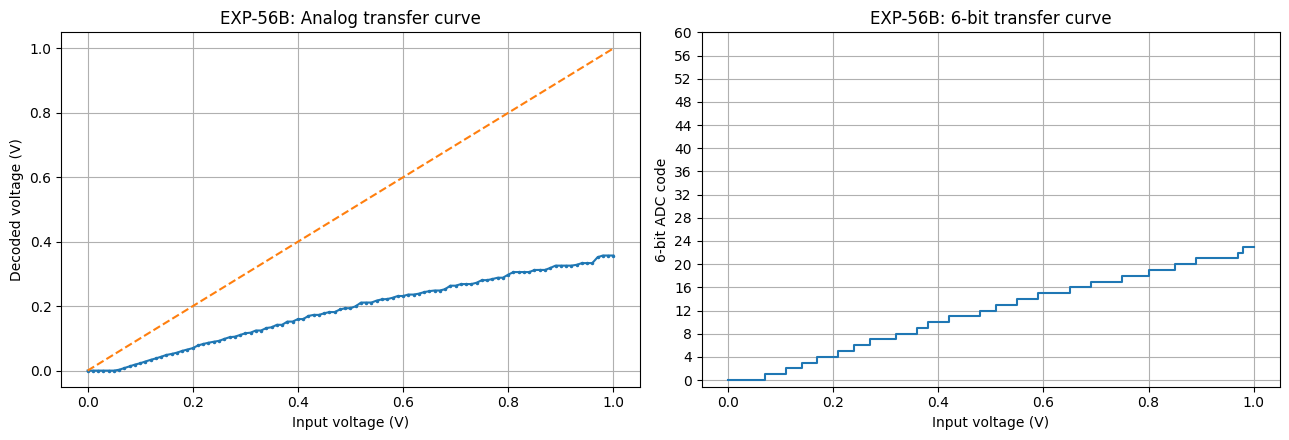

In [195]:

# EXP-56B: Apply the original EXP-33 decoder to EXP-56A
# Reuses existing calibration. Does NOT fit on EXP-56A.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Load EXP-56A
base = Path.cwd()
csv_path = base / "EXP56A_transfer_characterization.csv"

if not csv_path.exists():
    csv_path = base / "biowire" / "EXP56A_transfer_characterization.csv"

df56 = pd.read_csv(csv_path)

# 2. Build the three EXP-33 input features in the correct order:
# Mi1 spike count, L1 first-spike latency, L1 mean ISI
X56 = df56[
    ["mi1_spike_count", "l1_first_latency_ms", "l1_mean_isi_ms"]
].to_numpy(dtype=float)

vin56 = df56["input_voltage_V"].to_numpy(dtype=float)

# 3. Reuse the original EXP-33 training features and voltages
# The existing notebook has these arrays.
X_train33 = np.asarray(features_train, dtype=float)
y_train33 = np.asarray(train_voltages, dtype=float)

if X_train33.shape != (101, 3) or y_train33.shape[0] != 101:
    raise ValueError(
        f"Unexpected EXP-33 training shapes: "
        f"{X_train33.shape}, {y_train33.shape}"
    )

# 4. Reconstruct the original EXP-33 calibration from training data only
decoder56 = fit_exp33_decoder(X_train33, y_train33)

# 5. Apply the frozen decoder to EXP-56A
analog56, scores56, valid56 = apply_exp33_decoder(X56, decoder56)

if not np.all(valid56):
    raise ValueError("Some EXP-56A rows have invalid neural features.")

analog56 = np.clip(analog56, 0.0, 1.0)
codes56 = np.rint(63 * analog56).astype(int)

# 6. Check monotonicity and code coverage
analog_monotonic = bool(np.all(np.diff(analog56) >= -1e-12))
code_monotonic = bool(np.all(np.diff(codes56) >= 0))
unique_codes = np.unique(codes56)
missing_codes = sorted(set(range(64)) - set(unique_codes.tolist()))

print("========== EXP-56B RESULTS ==========")
print("Input rows:", len(df56))
print("Valid feature rows:", int(np.sum(valid56)), "/", len(valid56))
print(f"Analog monotonic: {analog_monotonic}")
print(f"6-bit code monotonic: {code_monotonic}")
print(f"Unique codes: {len(unique_codes)}/64")
print(f"Code range: {codes56.min()} to {codes56.max()}")
print("Missing codes:", missing_codes)

# 7. Save complete transfer curve
out = df56.copy()
out["decoder_score"] = scores56
out["decoded_voltage_V"] = analog56
out["adc_code_6bit"] = codes56

out_path = base / "EXP56B_transfer_curve.csv"
out.to_csv(out_path, index=False)

# 8. Save code transitions
transition_rows = []
for i in range(1, len(codes56)):
    if codes56[i] != codes56[i - 1]:
        transition_rows.append({
            "input_voltage_V": vin56[i],
            "previous_code": codes56[i - 1],
            "new_code": codes56[i],
            "code_step": codes56[i] - codes56[i - 1]
        })

transitions = pd.DataFrame(
    transition_rows,
    columns=["input_voltage_V", "previous_code", "new_code", "code_step"]
)
transition_path = base / "EXP56B_code_transitions.csv"
transitions.to_csv(transition_path, index=False)

print("\nCode transitions:", len(transitions))
print("Saved:", out_path.resolve())
print("Saved:", transition_path.resolve())

# 9. Plot the two transfer curves
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

ax[0].plot(vin56, analog56, marker=".", markersize=3)
ax[0].plot([0, 1], [0, 1], linestyle="--")
ax[0].set_xlabel("Input voltage (V)")
ax[0].set_ylabel("Decoded voltage (V)")
ax[0].set_title("EXP-56B: Analog transfer curve")
ax[0].grid(True)

ax[1].step(vin56, codes56, where="post")
ax[1].set_xlabel("Input voltage (V)")
ax[1].set_ylabel("6-bit ADC code")
ax[1].set_title("EXP-56B: 6-bit transfer curve")
ax[1].set_yticks(range(0, 64, 4))
ax[1].grid(True)

plt.tight_layout()
plt.show()


EXP-49 training samples: 101
Observation window: 200 ms

========== EXP-56B CORRECTED ==========
Valid rows: 101/101
Analog MAE: 2.832 mV
Analog RMSE: 4.713 mV
6-bit MAE: 5.717 mV
Unique codes: 55/64
Code range: 0 to 62
Analog monotonic: True
Code monotonic: True
Saved: C:\Users\sagni\OneDrive\Documents\capstone\biowire\EXP56B_EXP49_decoder.csv


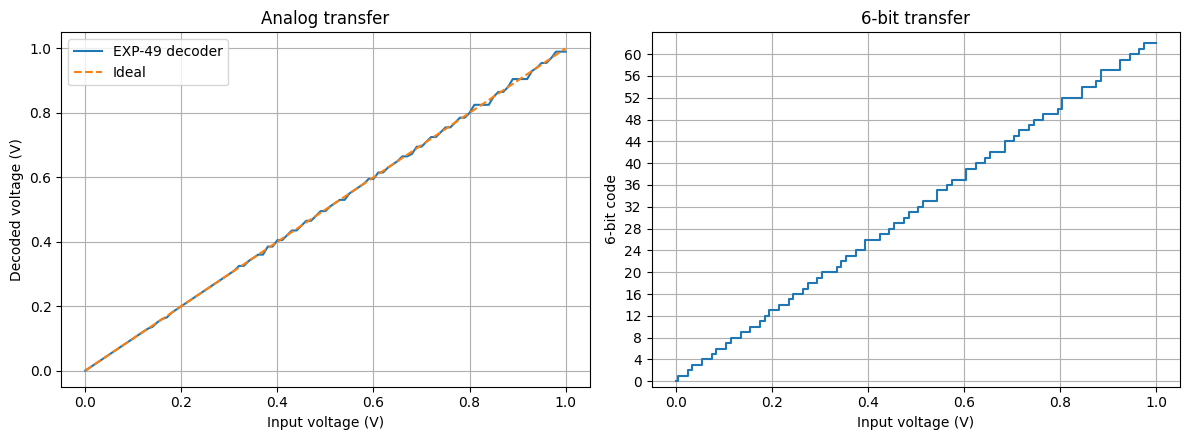

In [196]:
# ============================================================
# EXP-56B CORRECTED: REUSE THE ACTUAL EXP-49 200 ms DECODER
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Check original EXP-49 calibration data and functions
required = [
    "TRAIN_CACHE_49",
    "train_voltages_49",
    "train_window_decoder_49",
    "features_from_cache_entry_49",
]

missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError(
        "Missing EXP-49 objects: " + ", ".join(missing)
        + ". Do not substitute the EXP-33 decoder."
    )

# 2. Load EXP-56A transfer data
base = Path.cwd()
csv_path = base / "EXP56A_transfer_characterization.csv"

if not csv_path.exists():
    csv_path = base / "biowire" / "EXP56A_transfer_characterization.csv"

if not csv_path.exists():
    raise FileNotFoundError("Could not find EXP56A_transfer_characterization.csv")

df = pd.read_csv(csv_path)

voltages_test = df["input_voltage_V"].to_numpy(dtype=float)
X_test = df[
    ["mi1_spike_count", "l1_first_latency_ms", "l1_mean_isi_ms"]
].to_numpy(dtype=float)

# 3. Rebuild the exact EXP-49 200 ms calibration
decoder49_200 = train_window_decoder_49(
    train_voltages_49,
    TRAIN_CACHE_49,
    200
)

if decoder49_200 is None:
    raise RuntimeError("EXP-49 could not build a valid 200 ms decoder.")

print("EXP-49 training samples:", decoder49_200["n_train"])
print("Observation window: 200 ms")

# 4. Apply EXP-49's exact feature normalization and score
valid = np.all(np.isfinite(X_test), axis=1)
decoded = np.full(len(df), np.nan)

X_norm = (
    X_test[valid] - decoder49_200["means"]
) / decoder49_200["stds"]

X_score = np.column_stack([
    X_norm[:, 0],
    -X_norm[:, 1],
    -X_norm[:, 2]
])

composite_score = np.mean(X_score, axis=1)

decoded[valid] = decoder49_200["iso"].predict(composite_score)
decoded[valid] = np.clip(decoded[valid], 0.0, 1.0)

codes = np.full(len(df), -1, dtype=int)
codes[valid] = np.clip(
    np.rint(decoded[valid] * 63), 0, 63
).astype(int)

# 5. Report transfer characteristics
v = voltages_test[valid]
p = decoded[valid]
c = codes[valid]

order = np.argsort(v)
v, p, c = v[order], p[order], c[order]

unique_codes = np.unique(c)
analog_monotonic = bool(np.all(np.diff(p) >= -1e-12))
code_monotonic = bool(np.all(np.diff(c) >= 0))

print("\n========== EXP-56B CORRECTED ==========")
print(f"Valid rows: {len(c)}/{len(df)}")
print(f"Analog MAE: {np.mean(np.abs(p-v))*1000:.3f} mV")
print(f"Analog RMSE: {np.sqrt(np.mean((p-v)**2))*1000:.3f} mV")
print(f"6-bit MAE: {np.mean(np.abs(c/63-v))*1000:.3f} mV")
print(f"Unique codes: {len(unique_codes)}/64")
print(f"Code range: {c.min()} to {c.max()}")
print(f"Analog monotonic: {analog_monotonic}")
print(f"Code monotonic: {code_monotonic}")

# 6. Save as a NEW file so previous results remain untouched
out = df.copy()
out["exp49_composite_score"] = np.nan
out.loc[valid, "exp49_composite_score"] = composite_score
out["exp49_decoded_voltage_V"] = decoded
out["exp49_adc_code_6bit"] = codes

out_path = base / "EXP56B_EXP49_decoder.csv"
out.to_csv(out_path, index=False)
print("Saved:", out_path.resolve())

# 7. Plot
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].plot(v, p, label="EXP-49 decoder")
ax[0].plot([0, 1], [0, 1], "--", label="Ideal")
ax[0].set(xlabel="Input voltage (V)", ylabel="Decoded voltage (V)",
          title="Analog transfer")
ax[0].grid(True)
ax[0].legend()

ax[1].step(v, c, where="mid")
ax[1].set(xlabel="Input voltage (V)", ylabel="6-bit code",
          title="6-bit transfer", ylim=(-1, 64))
ax[1].set_yticks(range(0, 64, 4))
ax[1].grid(True)

plt.tight_layout()
plt.show()